In [1]:
#Import packages
#---------------------------------------
import sys
import os
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import glob
import admin_functions as adfn
import trace_analyse as tfn
from tqdm import tqdm
import re
import icg_functions as fn

# Set pars

In [102]:
start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 11.7,
    "i_w": 22.4,
    "theta": 8.44,
    "p_ext": 0.02,
    "phi": 4.2,
    "smoothe": 0.05,
}
start_dic

{'n_neurons': 2000,
 'T': 10,
 'dt': 0.01,
 'refractory_steps': 2,
 'ei_ratio': 0.2,
 'e_w': 11.7,
 'i_w': 22.4,
 'theta': 8.44,
 'p_ext': 0.02,
 'phi': 4.2,
 'smoothe': 0.05}

# Sanity check

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed
PHI_VALUES: [ 1.25  1.5   2.    2.25  3.    5.   10.   20.   50.  ]
N_SEEDS: 5
N: 2000


Building networks:   0%|          | 0/45 [00:00<?, ?it/s]

Saved:
/home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/wiring_global_metrics.csv
/home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/wiring_level_metrics.csv
/home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/wiring_degree_by_neuron.csv

Global summary:
  phi  n  n_edges_mean  n_edges_sem  density_mean  density_sem  mean_out_degree_mean  mean_out_degree_sem  std_out_degree_mean  std_out_degree_sem  max_out_degree_mean  frac_out_zero_mean  mean_in_degree_mean  mean_in_degree_sem  std_in_degree_mean  std_in_degree_sem  max_in_degree_mean  frac_in_zero_mean  n_unassigned_edges_mean
 1.25  5      269088.6     217.8111        0.0673       0.0001              134.5443               0.1089              54.3603              0.0922                220.2                 0.0             134.5443              0.1089             54.3134             0.0887               221.6                0.0                      0.0

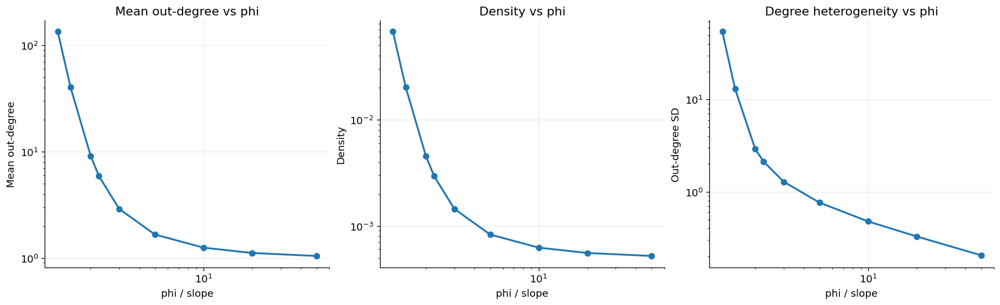

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/plots/observed_edge_probability_by_level.png


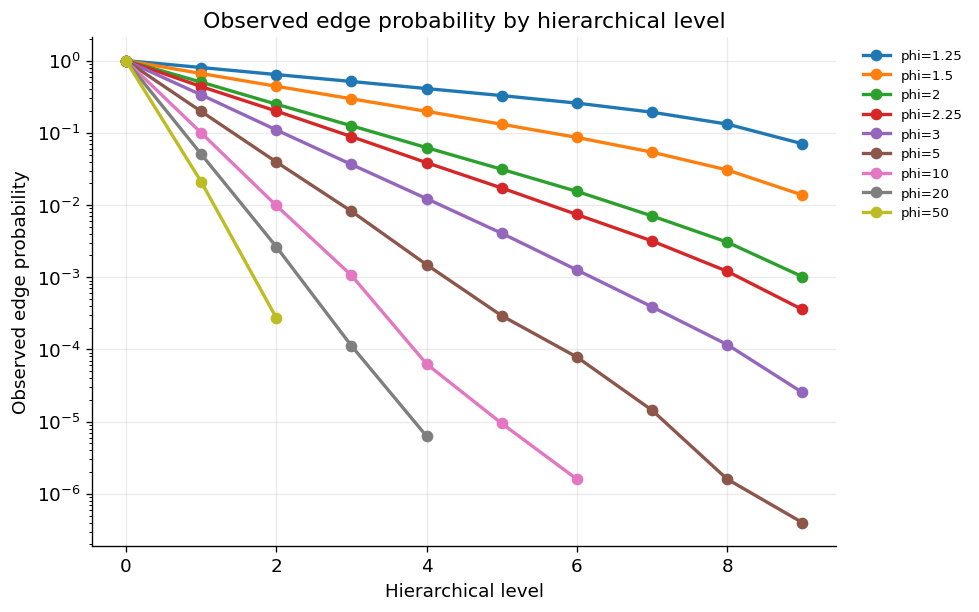

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/plots/observed_vs_expected_probability_by_level.png


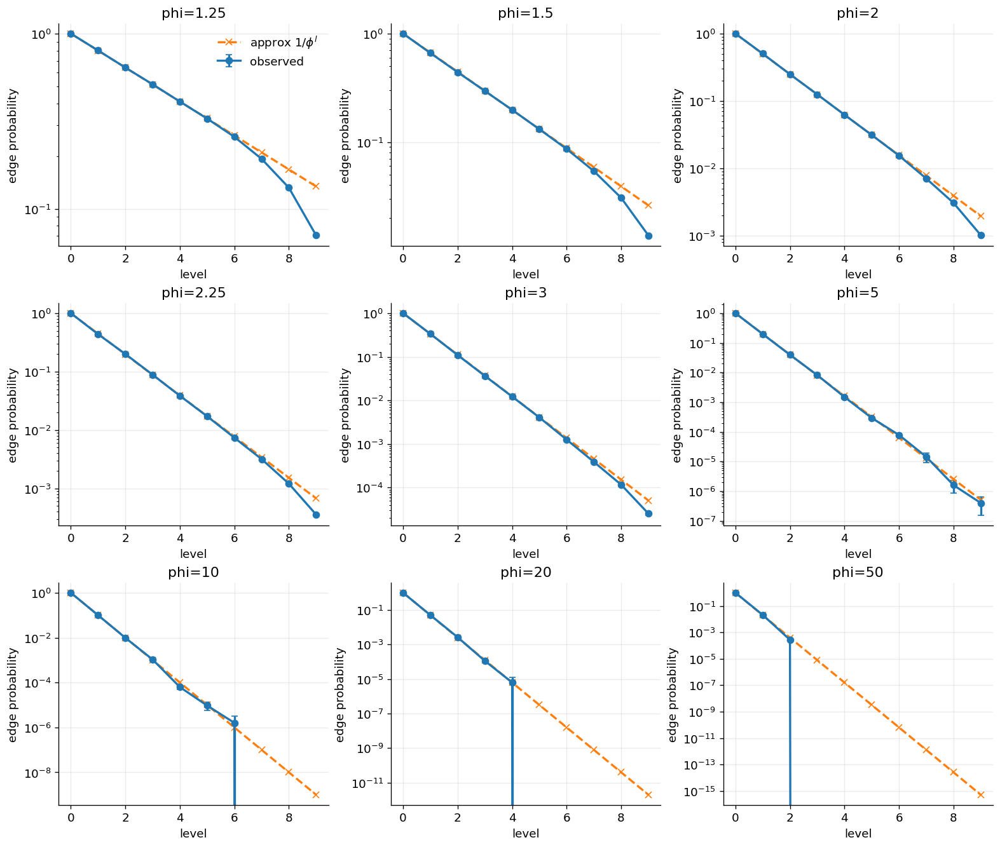

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/plots/observed_over_expected_by_level.png


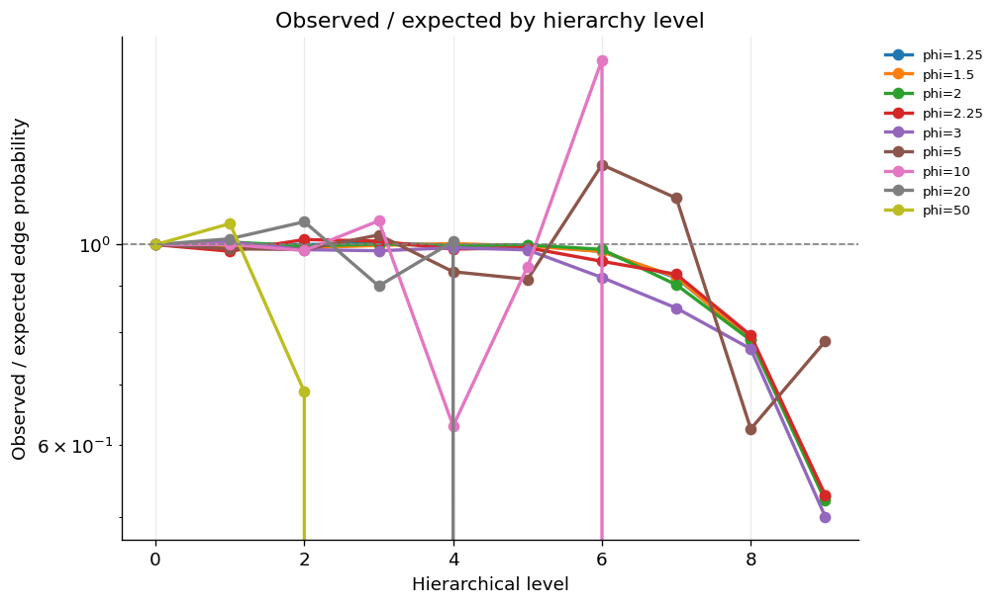

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/plots/degree_distributions_selected_phi.png


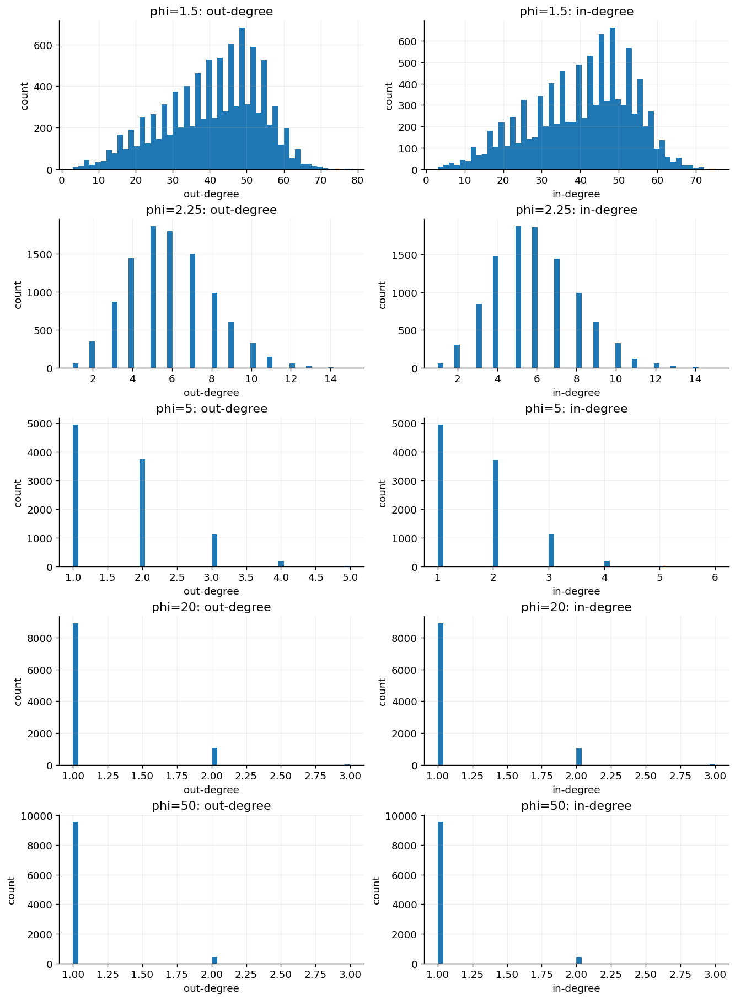

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed/plots/possible_and_observed_edges_by_level.png


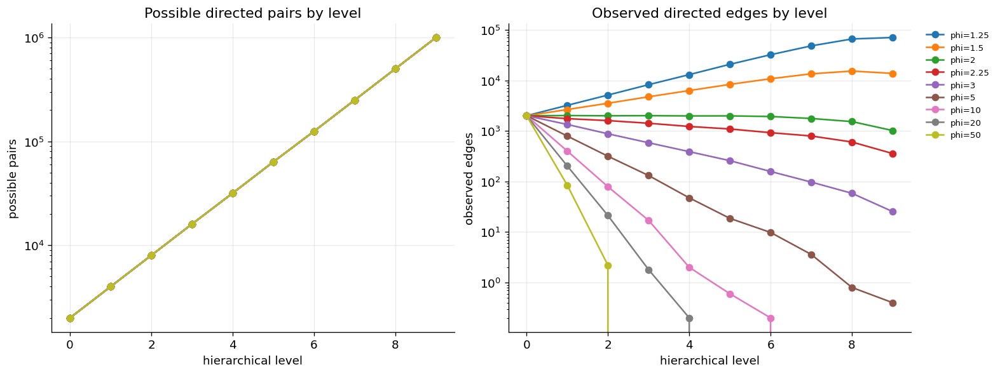


Key global wiring table:
  phi  n_edges_mean  density_mean  mean_out_degree_mean  std_out_degree_mean  max_out_degree_mean  frac_out_zero_mean  n_unassigned_edges_mean  n
 1.25      269088.6       0.06727              134.5443             54.36033                220.2                 0.0                      0.0  5
 1.50       80805.0       0.02020               40.4025             13.03270                 72.8                 0.0                      0.0  5
 2.00       18208.8       0.00455                9.1044              2.89980                 20.4                 0.0                      0.0  5
 2.25       11760.6       0.00294                5.8803              2.12832                 14.0                 0.0                      0.0  5
 3.00        5789.0       0.00145                2.8945              1.28405                  8.8                 0.0                      0.0  5
 5.00        3319.4       0.00083                1.6597              0.76263                  5.0 

In [28]:
# ============================================================
# Hierarchical wiring sanity checks using start_dic
#
# Checks:
#   1) total edges / density / mean degree vs phi
#   2) observed edge probability by hierarchy level
#   3) observed vs approximate expected P_l = 1 / phi**level
#   4) degree distributions for selected phi values
#
# No dynamics. Just wiring.
# ============================================================

import os
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


# ============================================================
# Settings
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/hierarchical_wiring_sanity_startdic_fixed")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.array([1.25, 1.5, 2.0, 2.25, 3.0, 5.0, 10.0, 20.0, 50.0])
N_SEEDS = 5
BASE_SEED = 440000

print("OUTDIR:", OUTDIR)
print("PHI_VALUES:", PHI_VALUES)
print("N_SEEDS:", N_SEEDS)
print("N:", start_dic["n_neurons"])


# ============================================================
# Model class
# ============================================================

try:
    import icg_functions as fn
    MODEL_CLS = fn.automata_EI_hiermod
except Exception:
    MODEL_CLS = automata_EI_hiermod


# ============================================================
# Helpers
# ============================================================

def make_pars(phi, seed):
    pars = dict(start_dic)

    # Remove runtime-only keys
    pars.pop("T", None)
    pars.pop("smoothe", None)

    sig = inspect.signature(MODEL_CLS.__init__)
    valid_args = set(sig.parameters.keys())

    # Handle slope/phi naming
    if "slope" in valid_args:
        pars.pop("phi", None)
        pars["slope"] = float(phi)
    elif "phi" in valid_args:
        pars.pop("slope", None)
        pars["phi"] = float(phi)
    else:
        raise ValueError("MODEL_CLS expects neither 'slope' nor 'phi'.")

    pars["seed"] = int(seed)

    # Remove accidental invalid keys
    pars = {k: v for k, v in pars.items() if k in valid_args}

    return pars


def get_hier_labels(N, seed=None, model=None):
    """
    Returns labels with shape:
        labels[level, neuron]

    Compatible with your current:
        label_neuron_bylevel(n_neurons, rng)
    which returns:
        labs, groupings
    """

    # First try labels stored directly on model
    for attr in [
        "labs",
        "labels",
        "labels_by_level",
        "hier_labels",
        "labels_by_gen",
        "lab",
    ]:
        if model is not None and hasattr(model, attr):
            labs = np.asarray(getattr(model, attr))
            if labs.ndim == 2 and labs.shape[-1] == N:
                return labs

    # Try groupings/labels from model if stored differently
    for attr in ["groupings", "groups", "hier_groups"]:
        if model is not None and hasattr(model, attr):
            groupings = getattr(model, attr)
            labs = groupings_to_labels(groupings, N)
            if labs is not None:
                return labs

    # Try module function: fn.label_neuron_bylevel(N, rng)
    try:
        rng = np.random.default_rng(seed)
        labs, groupings = fn.label_neuron_bylevel(N, rng)
        labs = np.asarray(labs)
        if labs.ndim == 2 and labs.shape[-1] == N:
            return labs
    except Exception as e:
        print("Could not use fn.label_neuron_bylevel:", repr(e))

    # Try local function: label_neuron_bylevel(N, rng)
    try:
        rng = np.random.default_rng(seed)
        labs, groupings = label_neuron_bylevel(N, rng)
        labs = np.asarray(labs)
        if labs.ndim == 2 and labs.shape[-1] == N:
            return labs
    except Exception as e:
        print("Could not use local label_neuron_bylevel:", repr(e))

    # Fallback deterministic consecutive hierarchy
    print("WARNING: using fallback deterministic hierarchy labels.")
    max_level = int(np.ceil(np.log2(N)))
    labels = np.zeros((max_level + 1, N), dtype=int)

    for level in range(max_level + 1):
        labels[level] = np.arange(N) // (2 ** (level + 1))

    return labels


def groupings_to_labels(groupings, N):
    """
    Converts nested groupings into labels[level, neuron] if groupings
    is a list where each element is a list/array of neuron groups.
    """
    try:
        labels_by_level = []

        for level_groups in groupings:
            lab = np.full(N, -1, dtype=int)

            for g_idx, group in enumerate(level_groups):
                group = np.asarray(group, dtype=int)
                group = group[(group >= 0) & (group < N)]
                lab[group] = g_idx

            if np.any(lab < 0):
                # assign unlabelled neurons unique labels
                missing = np.where(lab < 0)[0]
                start = lab.max() + 1
                lab[missing] = np.arange(start, start + len(missing))

            labels_by_level.append(lab)

        labs = np.vstack(labels_by_level)
        return labs

    except Exception:
        return None


def possible_directed_pairs_by_level(labels):
    """
    Count possible directed non-self pairs whose smallest common
    hierarchical level is exactly `level`.
    """
    max_level = labels.shape[0] - 1
    N = labels.shape[1]

    possible = {}
    prev_same = np.eye(N, dtype=bool)

    for level in range(max_level + 1):
        lab = labels[level]
        same = lab[:, None] == lab[None, :]

        exact = same & (~prev_same)
        np.fill_diagonal(exact, False)

        possible[level] = int(exact.sum())
        prev_same = same

    return possible


def edge_levels_from_A(A, labels):
    """
    Assign each directed edge to the smallest hierarchical level
    at which source and target share a module.
    """
    src, dst = np.where(A > 0)
    max_level = labels.shape[0] - 1

    edge_level = np.full(len(src), -1, dtype=int)

    for level in range(max_level + 1):
        unresolved = edge_level < 0

        if not np.any(unresolved):
            break

        s = src[unresolved]
        d = dst[unresolved]

        same = labels[level, s] == labels[level, d]
        idx = np.where(unresolved)[0][same]
        edge_level[idx] = level

    return edge_level


def expected_p_for_level(phi, level):
    """
    Approximate expected HM wiring probability.
    Base pair level is capped at 1.
    """
    return min(1.0, 1.0 / (float(phi) ** int(level)))


def run_wiring_check(phi, seed):
    pars = make_pars(phi, seed)
    model = MODEL_CLS(**pars)

    A = np.asarray(model.A)
    N = A.shape[0]

    out_deg = A.sum(axis=1)
    in_deg = A.sum(axis=0)

    labels = get_hier_labels(N, seed=seed, model=model)
    labels = np.asarray(labels)

    # Ensure shape is level x neuron
    if labels.shape[0] == N and labels.shape[1] != N:
        labels = labels.T

    max_level = labels.shape[0] - 1

    possible = possible_directed_pairs_by_level(labels)
    edge_level = edge_levels_from_A(A, labels)

    n_unassigned = int(np.sum(edge_level < 0))

    global_row = {
        "phi": float(phi),
        "seed": int(seed),
        "N": int(N),
        "n_edges": int(A.sum()),
        "density": float(A.mean()),

        "mean_out_degree": float(out_deg.mean()),
        "std_out_degree": float(out_deg.std()),
        "min_out_degree": int(out_deg.min()),
        "max_out_degree": int(out_deg.max()),
        "frac_out_zero": float(np.mean(out_deg == 0)),

        "mean_in_degree": float(in_deg.mean()),
        "std_in_degree": float(in_deg.std()),
        "min_in_degree": int(in_deg.min()),
        "max_in_degree": int(in_deg.max()),
        "frac_in_zero": float(np.mean(in_deg == 0)),

        "n_unassigned_edges": n_unassigned,
    }

    level_rows = []

    for level in range(max_level + 1):
        n_possible = possible[level]
        n_edges_level = int(np.sum(edge_level == level))

        obs_p = n_edges_level / n_possible if n_possible > 0 else np.nan
        exp_p = expected_p_for_level(phi, level)

        level_rows.append({
            "phi": float(phi),
            "seed": int(seed),
            "level": int(level),
            "n_possible": int(n_possible),
            "n_edges": int(n_edges_level),
            "observed_p": float(obs_p),
            "expected_p_approx": float(exp_p),
            "observed_over_expected": float(obs_p / exp_p) if exp_p > 0 else np.nan,
        })

    degree_df = pd.DataFrame({
        "phi": float(phi),
        "seed": int(seed),
        "neuron": np.arange(N),
        "out_degree": out_deg.astype(int),
        "in_degree": in_deg.astype(int),
        "total_degree": (out_deg + in_deg).astype(int),
    })

    return global_row, pd.DataFrame(level_rows), degree_df


def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()

    if len(x) <= 1:
        return np.nan

    return float(x.std(ddof=1) / np.sqrt(len(x)))


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# Run checks
# ============================================================

global_rows = []
level_rows = []
degree_rows = []

jobs = []
job_i = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + job_i
        jobs.append((float(phi), int(seed)))
        job_i += 1

for phi, seed in tqdm(jobs, desc="Building networks"):
    g, lev, deg = run_wiring_check(phi, seed)

    global_rows.append(g)
    level_rows.append(lev)
    degree_rows.append(deg)

global_df = (
    pd.DataFrame(global_rows)
    .sort_values(["phi", "seed"])
    .reset_index(drop=True)
)

level_df = (
    pd.concat(level_rows, ignore_index=True)
    .sort_values(["phi", "seed", "level"])
    .reset_index(drop=True)
)

degree_df = (
    pd.concat(degree_rows, ignore_index=True)
    .sort_values(["phi", "seed", "neuron"])
    .reset_index(drop=True)
)

global_df.to_csv(OUTDIR / "wiring_global_metrics.csv", index=False)
level_df.to_csv(OUTDIR / "wiring_level_metrics.csv", index=False)
degree_df.to_csv(OUTDIR / "wiring_degree_by_neuron.csv", index=False)

print("Saved:")
print(OUTDIR / "wiring_global_metrics.csv")
print(OUTDIR / "wiring_level_metrics.csv")
print(OUTDIR / "wiring_degree_by_neuron.csv")


# ============================================================
# Summaries
# ============================================================

global_summary = (
    global_df
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        n_edges_mean=("n_edges", "mean"),
        n_edges_sem=("n_edges", sem),

        density_mean=("density", "mean"),
        density_sem=("density", sem),

        mean_out_degree_mean=("mean_out_degree", "mean"),
        mean_out_degree_sem=("mean_out_degree", sem),

        std_out_degree_mean=("std_out_degree", "mean"),
        std_out_degree_sem=("std_out_degree", sem),

        max_out_degree_mean=("max_out_degree", "mean"),
        frac_out_zero_mean=("frac_out_zero", "mean"),

        mean_in_degree_mean=("mean_in_degree", "mean"),
        mean_in_degree_sem=("mean_in_degree", sem),

        std_in_degree_mean=("std_in_degree", "mean"),
        std_in_degree_sem=("std_in_degree", sem),

        max_in_degree_mean=("max_in_degree", "mean"),
        frac_in_zero_mean=("frac_in_zero", "mean"),

        n_unassigned_edges_mean=("n_unassigned_edges", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

level_summary = (
    level_df
    .groupby(["phi", "level"], as_index=False)
    .agg(
        n=("seed", "count"),
        n_possible=("n_possible", "first"),

        n_edges_mean=("n_edges", "mean"),
        n_edges_sem=("n_edges", sem),

        observed_p_mean=("observed_p", "mean"),
        observed_p_sem=("observed_p", sem),

        expected_p_approx=("expected_p_approx", "first"),

        observed_over_expected_mean=("observed_over_expected", "mean"),
        observed_over_expected_sem=("observed_over_expected", sem),
    )
    .sort_values(["phi", "level"])
    .reset_index(drop=True)
)

global_summary.to_csv(OUTDIR / "wiring_global_summary.csv", index=False)
level_summary.to_csv(OUTDIR / "wiring_level_summary.csv", index=False)

print("\nGlobal summary:")
print(global_summary.round(4).to_string(index=False))

print("\nLevel summary head:")
print(level_summary.head(30).round(5).to_string(index=False))


# ============================================================
# Plotting setup
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


# ============================================================
# Plot 1: global degree / density vs phi
# ============================================================

g = global_summary.sort_values("phi")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].errorbar(
    g["phi"],
    g["mean_out_degree_mean"],
    yerr=g["mean_out_degree_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].set_ylabel("Mean out-degree")
axes[0].set_title("Mean out-degree vs phi")

axes[1].errorbar(
    g["phi"],
    g["density_mean"],
    yerr=g["density_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].set_ylabel("Density")
axes[1].set_title("Density vs phi")

axes[2].errorbar(
    g["phi"],
    g["std_out_degree_mean"],
    yerr=g["std_out_degree_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[2].set_ylabel("Out-degree SD")
axes[2].set_title("Degree heterogeneity vs phi")

for ax in axes:
    ax.set_xlabel("phi / slope")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

savefig(fig, "global_degree_density_vs_phi.png")
plt.show()


# ============================================================
# Plot 2: observed edge probability by hierarchy level
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5.5))

for phi in PHI_VALUES:
    gg = level_summary[level_summary["phi"] == phi].sort_values("level")
    gg = gg[(gg["n_possible"] > 0) & (gg["observed_p_mean"] > 0)]

    ax.plot(
        gg["level"],
        gg["observed_p_mean"],
        marker="o",
        linewidth=2,
        label=f"phi={phi:g}",
    )

ax.set_xlabel("Hierarchical level")
ax.set_ylabel("Observed edge probability")
ax.set_title("Observed edge probability by hierarchical level")
ax.set_yscale("log")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")

savefig(fig, "observed_edge_probability_by_level.png")
plt.show()


# ============================================================
# Plot 3: observed vs expected P_l
# ============================================================

fig, axes = plt.subplots(3, 3, figsize=(13, 11), constrained_layout=True)
axes = axes.ravel()

for ax, phi in zip(axes, PHI_VALUES):
    gg = level_summary[level_summary["phi"] == phi].sort_values("level")
    gg = gg[gg["n_possible"] > 0]

    ax.errorbar(
        gg["level"],
        gg["observed_p_mean"],
        yerr=gg["observed_p_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        label="observed",
    )

    ax.plot(
        gg["level"],
        gg["expected_p_approx"],
        marker="x",
        linewidth=2,
        linestyle="--",
        label=r"approx $1/\phi^l$",
    )

    ax.set_title(f"phi={phi:g}")
    ax.set_xlabel("level")
    ax.set_ylabel("edge probability")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

    if ax is axes[0]:
        ax.legend(frameon=False)

for ax in axes[len(PHI_VALUES):]:
    ax.axis("off")

savefig(fig, "observed_vs_expected_probability_by_level.png")
plt.show()


# ============================================================
# Plot 4: observed / expected probability ratio
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5.5))

for phi in PHI_VALUES:
    gg = level_summary[level_summary["phi"] == phi].sort_values("level")
    gg = gg[(gg["n_possible"] > 0) & np.isfinite(gg["observed_over_expected_mean"])]

    ax.plot(
        gg["level"],
        gg["observed_over_expected_mean"],
        marker="o",
        linewidth=2,
        label=f"phi={phi:g}",
    )

ax.axhline(1.0, linestyle="--", linewidth=1, color="grey")
ax.set_xlabel("Hierarchical level")
ax.set_ylabel("Observed / expected edge probability")
ax.set_title("Observed / expected by hierarchy level")
ax.set_yscale("log")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")

savefig(fig, "observed_over_expected_by_level.png")
plt.show()


# ============================================================
# Plot 5: degree distributions for selected phi values
# ============================================================

selected_phis = [1.5, 2.25, 5.0, 20.0, 50.0]
selected_phis = [p for p in selected_phis if p in set(PHI_VALUES)]

fig, axes = plt.subplots(
    len(selected_phis),
    2,
    figsize=(11, 3.0 * len(selected_phis)),
    constrained_layout=True,
)

if len(selected_phis) == 1:
    axes = axes[None, :]

for i, phi in enumerate(selected_phis):
    dd = degree_df[np.isclose(degree_df["phi"], phi)]

    axes[i, 0].hist(dd["out_degree"], bins=50)
    axes[i, 0].set_title(f"phi={phi:g}: out-degree")
    axes[i, 0].set_xlabel("out-degree")
    axes[i, 0].set_ylabel("count")

    axes[i, 1].hist(dd["in_degree"], bins=50)
    axes[i, 1].set_title(f"phi={phi:g}: in-degree")
    axes[i, 1].set_xlabel("in-degree")
    axes[i, 1].set_ylabel("count")

    for ax in axes[i]:
        ax.grid(alpha=0.2)

savefig(fig, "degree_distributions_selected_phi.png")
plt.show()


# ============================================================
# Plot 6: possible pairs and realised edge counts by level
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

for phi in PHI_VALUES:
    gg = level_summary[level_summary["phi"] == phi].sort_values("level")
    gg = gg[gg["n_possible"] > 0]

    axes[0].plot(
        gg["level"],
        gg["n_possible"],
        marker="o",
        linewidth=1.5,
        label=f"phi={phi:g}",
    )

    axes[1].plot(
        gg["level"],
        gg["n_edges_mean"],
        marker="o",
        linewidth=1.5,
        label=f"phi={phi:g}",
    )

axes[0].set_title("Possible directed pairs by level")
axes[0].set_ylabel("possible pairs")

axes[1].set_title("Observed directed edges by level")
axes[1].set_ylabel("observed edges")

for ax in axes:
    ax.set_xlabel("hierarchical level")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

axes[1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")

savefig(fig, "possible_and_observed_edges_by_level.png")
plt.show()


# ============================================================
# Key numeric table
# ============================================================

key_cols = [
    "phi",
    "n_edges_mean",
    "density_mean",
    "mean_out_degree_mean",
    "std_out_degree_mean",
    "max_out_degree_mean",
    "frac_out_zero_mean",
    "n_unassigned_edges_mean",
    "n",
]

print("\nKey global wiring table:")
print(global_summary[key_cols].round(5).to_string(index=False))

global_summary[key_cols].to_csv(OUTDIR / "key_global_wiring_table.csv", index=False)

print("\nDone.")
print("Outputs:", OUTDIR)
print("Plots:", PLOTDIR)

In [27]:
rng

NameError: name 'rng' is not defined

Phi values: [ 1.5   2.    2.25  3.    5.   10.   20.   50.  ]
Fixed N: 2000
Seeds: 3
Total simulations: 24
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep


Running quick phi-only sweep:   0%|          | 0/24 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/phi_only_seed_metrics.csv
   phi    seed  n_neurons  n_edges   density  mean_out_degree  std_out_degree  \
0  1.5  123001       2000    80951  0.020238          40.4755       13.175750   
1  1.5  123002       2000    80860  0.020215          40.4300       12.937585   
2  1.5  123003       2000    80868  0.020217          40.4340       13.033021   
3  2.0  123004       2000    18052  0.004513           9.0260        2.930584   
4  2.0  123005       2000    18269  0.004567           9.1345        2.890918   

   min_out_degree  max_out_degree  frac_out_zero  ...  frac_silent_frames  \
0               2              70            0.0  ...                 0.0   
1               3              70            0.0  ...                 0.0   
2               4              74            0.0  ...                 0.0   
3               1              20            0.0  ...                 0.0   
4               2              20     

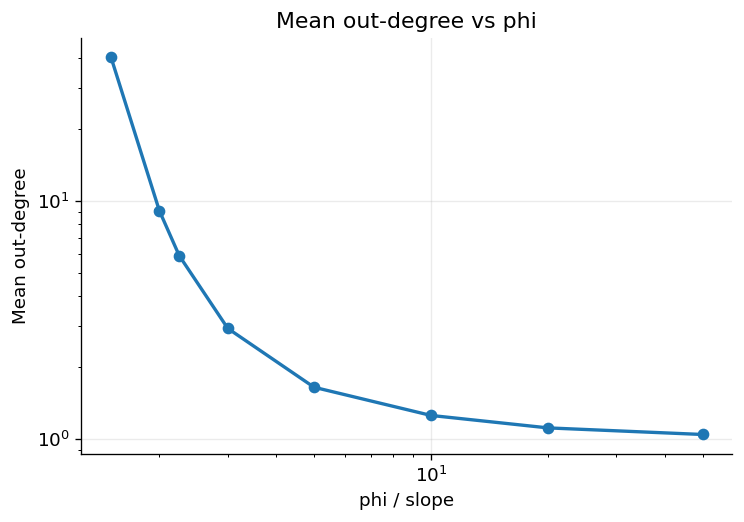

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/density_mean_vs_phi.png


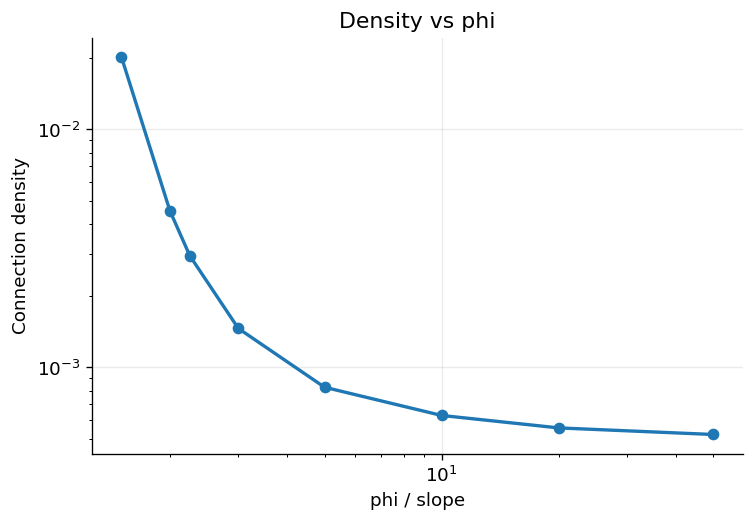

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/mean_rate_hz_mean_vs_phi.png


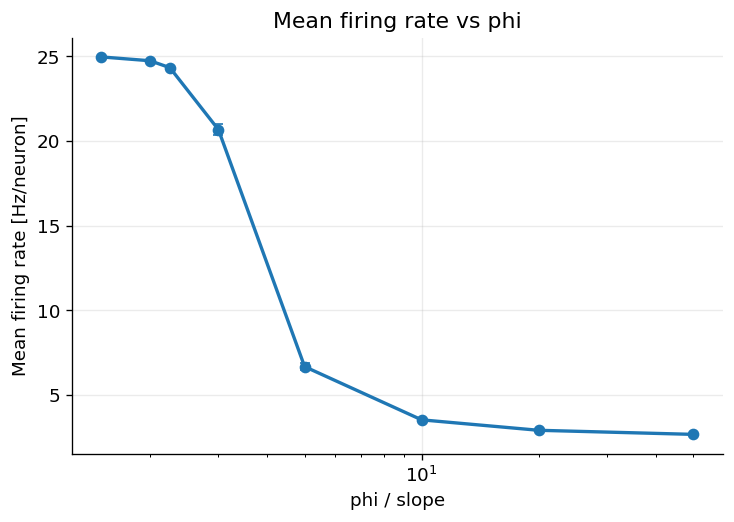

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/pop_rate_std_hz_mean_vs_phi.png


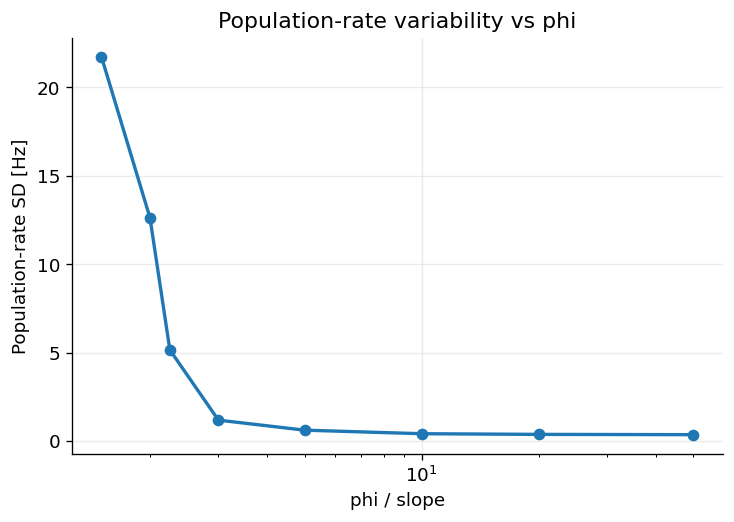

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/pop_rate_cv_mean_vs_phi.png


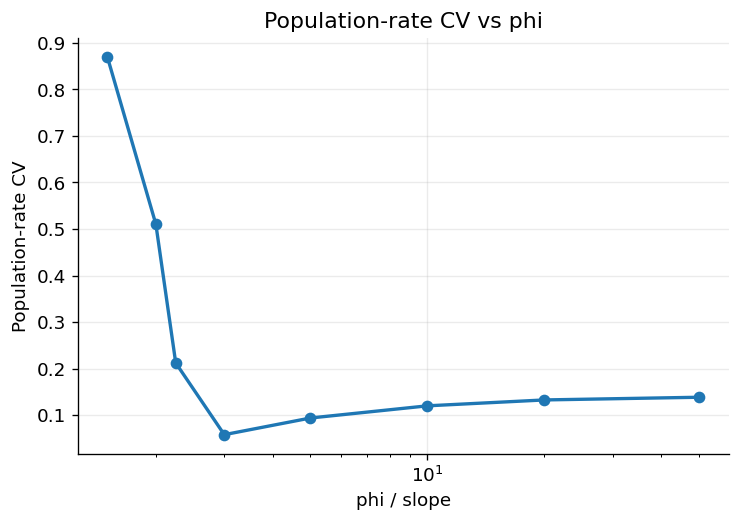

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/frac_silent_frames_mean_vs_phi.png


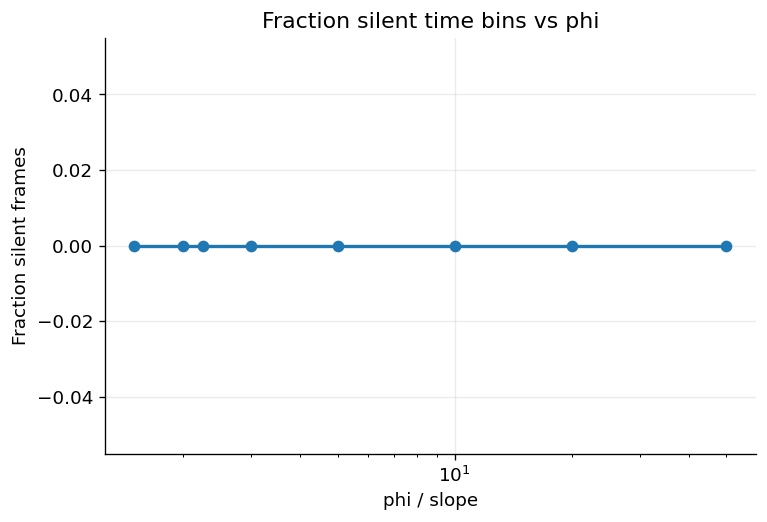

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/frac_active_neurons_mean_vs_phi.png


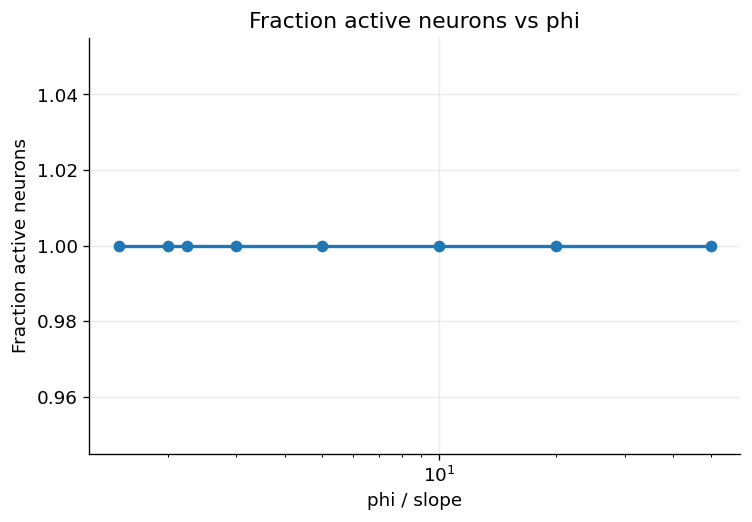

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep/plots/combined_phi_only_structure_activity_metrics.png


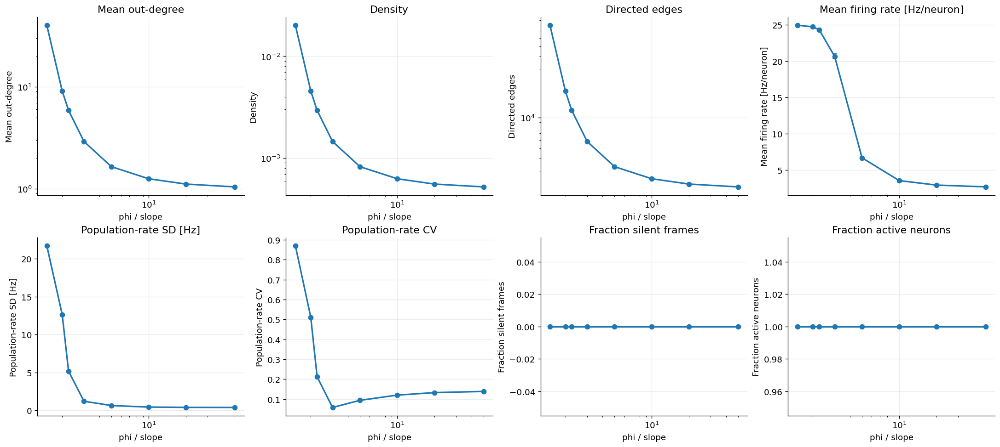


Key summary table:
  phi  mean_out_degree_mean  density_mean  mean_rate_hz_mean  pop_rate_std_hz_mean  pop_rate_cv_mean  frac_silent_frames_mean  frac_active_neurons_mean  n
 1.50               40.4465        0.0202            24.9676               21.7362            0.8706                      0.0                       1.0  3
 2.00                9.1098        0.0046            24.7416               12.6287            0.5103                      0.0                       1.0  3
 2.25                5.8968        0.0029            24.3347                5.1601            0.2120                      0.0                       1.0  3
 3.00                2.9177        0.0015            20.6742                1.1912            0.0577                      0.0                       1.0  3
 5.00                1.6515        0.0008             6.6746                0.6243            0.0936                      0.0                       1.0  3
10.00                1.2572        0.0006         

In [3]:
# ============================================================
# Quick sweep: start_dic only, vary phi/slope only
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


# ============================================================
# Settings
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/quick_phi_only_sweep")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

# quick phi-only sweep
PHI_VALUES = np.array([1.5, 2.0, 2.25, 3.0, 5.0, 10.0, 20.0, 50.0])

N_SEEDS = 3
BASE_SEED = 123000
N_WORKERS = 8

T_RUN = float(start_dic.get("T", 10.0))

print("Phi values:", PHI_VALUES)
print("Fixed N:", int(start_dic["n_neurons"]))
print("Seeds:", N_SEEDS)
print("Total simulations:", len(PHI_VALUES) * N_SEEDS)
print("OUTDIR:", OUTDIR)


# ============================================================
# Worker
# ============================================================

def run_one_phi_job(job):
    phi, seed = job

    pars = dict(start_dic)
    pars.pop("T", None)

    # ONLY thing varied
    pars["slope"] = float(phi)

    # keep start_dic N
    pars["n_neurons"] = int(start_dic["n_neurons"])

    # seed only controls stochastic repeat
    pars["seed"] = int(seed)

    model = automata_EI_hiermod(**pars)

    A = model.A
    out_deg = A.sum(axis=1)
    in_deg = A.sum(axis=0)

    spikes, pop_rate = run_model(model, T=T_RUN)

    mean_rate_hz = spikes.mean() / float(pars["dt"])
    neuron_rates_hz = spikes.mean(axis=1) / float(pars["dt"])

    pop_mean = float(np.mean(pop_rate))
    pop_std = float(np.std(pop_rate))
    pop_cv = float(pop_std / (pop_mean + 1e-12))

    active_frac_t = spikes.mean(axis=0)

    return {
        "phi": float(phi),
        "seed": int(seed),

        # structure
        "n_neurons": int(pars["n_neurons"]),
        "n_edges": int(A.sum()),
        "density": float(A.mean()),
        "mean_out_degree": float(out_deg.mean()),
        "std_out_degree": float(out_deg.std()),
        "min_out_degree": int(out_deg.min()),
        "max_out_degree": int(out_deg.max()),
        "frac_out_zero": float(np.mean(out_deg == 0)),
        "mean_in_degree": float(in_deg.mean()),
        "std_in_degree": float(in_deg.std()),
        "min_in_degree": int(in_deg.min()),
        "max_in_degree": int(in_deg.max()),
        "frac_in_zero": float(np.mean(in_deg == 0)),

        # activity
        "mean_rate_hz": float(mean_rate_hz),
        "neuron_rate_mean_hz": float(neuron_rates_hz.mean()),
        "neuron_rate_std_hz": float(neuron_rates_hz.std()),
        "neuron_rate_cv": float(neuron_rates_hz.std() / (neuron_rates_hz.mean() + 1e-12)),
        "pop_rate_mean_hz": pop_mean,
        "pop_rate_std_hz": pop_std,
        "pop_rate_cv": pop_cv,
        "active_frac_mean": float(np.mean(active_frac_t)),
        "active_frac_std": float(np.std(active_frac_t)),
        "frac_silent_frames": float(np.mean(spikes.sum(axis=0) == 0)),
        "frac_active_neurons": float(np.mean(spikes.sum(axis=1) > 0)),

        # fixed params copied from start_dic
        "theta": float(pars["theta"]),
        "ei_ratio": float(pars["ei_ratio"]),
        "e_w": float(pars["e_w"]),
        "i_w": float(pars["i_w"]),
        "p_ext": float(pars["p_ext"]),
        "dt": float(pars["dt"]),
        "T": float(T_RUN),
        "refractory_steps": int(pars["refractory_steps"]),
    }


# ============================================================
# Build + run jobs
# ============================================================

jobs = []
job_i = 0

for phi in PHI_VALUES:
    for s in range(N_SEEDS):
        job_i += 1
        jobs.append((float(phi), int(BASE_SEED + job_i)))

ctx = mp.get_context("fork")

rows = []

with ctx.Pool(processes=N_WORKERS) as pool:
    for out in tqdm(
        pool.imap_unordered(run_one_phi_job, jobs),
        total=len(jobs),
        desc="Running quick phi-only sweep",
    ):
        rows.append(out)

df = pd.DataFrame(rows)
df = df.sort_values(["phi", "seed"]).reset_index(drop=True)

df.to_csv(OUTDIR / "phi_only_seed_metrics.csv", index=False)

print("Saved:", OUTDIR / "phi_only_seed_metrics.csv")
print(df.head())


# ============================================================
# Summarise
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))

summary = (
    df
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        n_edges_mean=("n_edges", "mean"),
        n_edges_sem=("n_edges", sem),

        density_mean=("density", "mean"),
        density_sem=("density", sem),

        mean_out_degree_mean=("mean_out_degree", "mean"),
        mean_out_degree_sem=("mean_out_degree", sem),

        std_out_degree_mean=("std_out_degree", "mean"),
        frac_out_zero_mean=("frac_out_zero", "mean"),

        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),

        neuron_rate_std_hz_mean=("neuron_rate_std_hz", "mean"),
        neuron_rate_cv_mean=("neuron_rate_cv", "mean"),

        pop_rate_mean_hz_mean=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz_mean=("pop_rate_std_hz", "mean"),
        pop_rate_cv_mean=("pop_rate_cv", "mean"),

        active_frac_mean=("active_frac_mean", "mean"),
        active_frac_std_mean=("active_frac_std", "mean"),

        frac_silent_frames_mean=("frac_silent_frames", "mean"),
        frac_active_neurons_mean=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

summary.to_csv(OUTDIR / "phi_only_summary_metrics.csv", index=False)

print("\nSummary:")
print(summary.round(4).to_string(index=False))
print("\nSaved:", OUTDIR / "phi_only_summary_metrics.csv")


# ============================================================
# Plotting
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


def plot_metric_vs_phi(metric_mean, metric_sem=None, ylabel=None, title=None, yscale=None):
    fig, ax = plt.subplots(figsize=(7, 4.5))

    g = summary.sort_values("phi")
    yerr = g[metric_sem] if metric_sem is not None and metric_sem in g.columns else None

    ax.errorbar(
        g["phi"],
        g[metric_mean],
        yerr=yerr,
        marker="o",
        linewidth=2,
        capsize=3,
    )

    ax.set_xlabel("phi / slope")
    ax.set_ylabel(ylabel if ylabel is not None else metric_mean)
    ax.set_title(title if title is not None else metric_mean)
    ax.set_xscale("log")

    if yscale is not None:
        ax.set_yscale(yscale)

    ax.grid(alpha=0.25)

    savefig(fig, f"{metric_mean}_vs_phi.png")
    plt.show()


# individual plots

plot_metric_vs_phi(
    "mean_out_degree_mean",
    "mean_out_degree_sem",
    ylabel="Mean out-degree",
    title="Mean out-degree vs phi",
    yscale="log",
)

plot_metric_vs_phi(
    "density_mean",
    "density_sem",
    ylabel="Connection density",
    title="Density vs phi",
    yscale="log",
)

plot_metric_vs_phi(
    "mean_rate_hz_mean",
    "mean_rate_hz_sem",
    ylabel="Mean firing rate [Hz/neuron]",
    title="Mean firing rate vs phi",
)

plot_metric_vs_phi(
    "pop_rate_std_hz_mean",
    None,
    ylabel="Population-rate SD [Hz]",
    title="Population-rate variability vs phi",
)

plot_metric_vs_phi(
    "pop_rate_cv_mean",
    None,
    ylabel="Population-rate CV",
    title="Population-rate CV vs phi",
)

plot_metric_vs_phi(
    "frac_silent_frames_mean",
    None,
    ylabel="Fraction silent frames",
    title="Fraction silent time bins vs phi",
)

plot_metric_vs_phi(
    "frac_active_neurons_mean",
    None,
    ylabel="Fraction active neurons",
    title="Fraction active neurons vs phi",
)


# combined plot

fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)

metrics = [
    ("mean_out_degree_mean", "mean_out_degree_sem", "Mean out-degree", "log"),
    ("density_mean", "density_sem", "Density", "log"),
    ("n_edges_mean", "n_edges_sem", "Directed edges", "log"),
    ("mean_rate_hz_mean", "mean_rate_hz_sem", "Mean firing rate [Hz/neuron]", None),
    ("pop_rate_std_hz_mean", None, "Population-rate SD [Hz]", None),
    ("pop_rate_cv_mean", None, "Population-rate CV", None),
    ("frac_silent_frames_mean", None, "Fraction silent frames", None),
    ("frac_active_neurons_mean", None, "Fraction active neurons", None),
]

g = summary.sort_values("phi")

for ax, (metric, sem_col, ylabel, yscale) in zip(axes.ravel(), metrics):
    yerr = g[sem_col] if sem_col is not None and sem_col in g.columns else None

    ax.errorbar(
        g["phi"],
        g[metric],
        yerr=yerr,
        marker="o",
        linewidth=2,
        capsize=3,
    )

    ax.set_xlabel("phi / slope")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_xscale("log")

    if yscale is not None:
        ax.set_yscale(yscale)

    ax.grid(alpha=0.25)

savefig(fig, "combined_phi_only_structure_activity_metrics.png")
plt.show()


# useful numeric table

num_cols = [
    "phi",
    "mean_out_degree_mean",
    "density_mean",
    "mean_rate_hz_mean",
    "pop_rate_std_hz_mean",
    "pop_rate_cv_mean",
    "frac_silent_frames_mean",
    "frac_active_neurons_mean",
    "n",
]

print("\nKey summary table:")
print(summary[num_cols].round(4).to_string(index=False))

summary[num_cols].to_csv(OUTDIR / "key_phi_only_summary_table.csv", index=False)

print("\nSaved:", OUTDIR / "key_phi_only_summary_table.csv")
print("Done. Plots saved to:", PLOTDIR)

Saved seed-level refits:
/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/phi_theta_seed_exponents_norm_drop_last2.csv

Top 10 closest using normalised fits, dropping last 2 ICG levels:
     phi     theta  p_self_zero_input  target_score  mv_alpha_mean  mv_r2_mean  ts_beta_mean  ts_r2_mean  n
4.333333 10.222222           0.000036      0.117253       1.390785    0.994867      0.204019    0.557611  5
5.277778  5.777778           0.003086      0.122883       1.495443    0.991801      0.259163    0.881911  5
4.333333  9.333333           0.000088      0.133686       1.483999    0.997394      0.258843    0.872928  5
6.222222  5.777778           0.003086      0.144391       1.459016    0.989438      0.251704    0.864469  5
4.333333  8.444444           0.000215      0.148912       1.553828    0.997694      0.247542    0.961129  5
4.333333  6.666667           0.001271      0.165027       1.661953    0.995506      0.198463    0.870829  5
4.333333  7.555556     

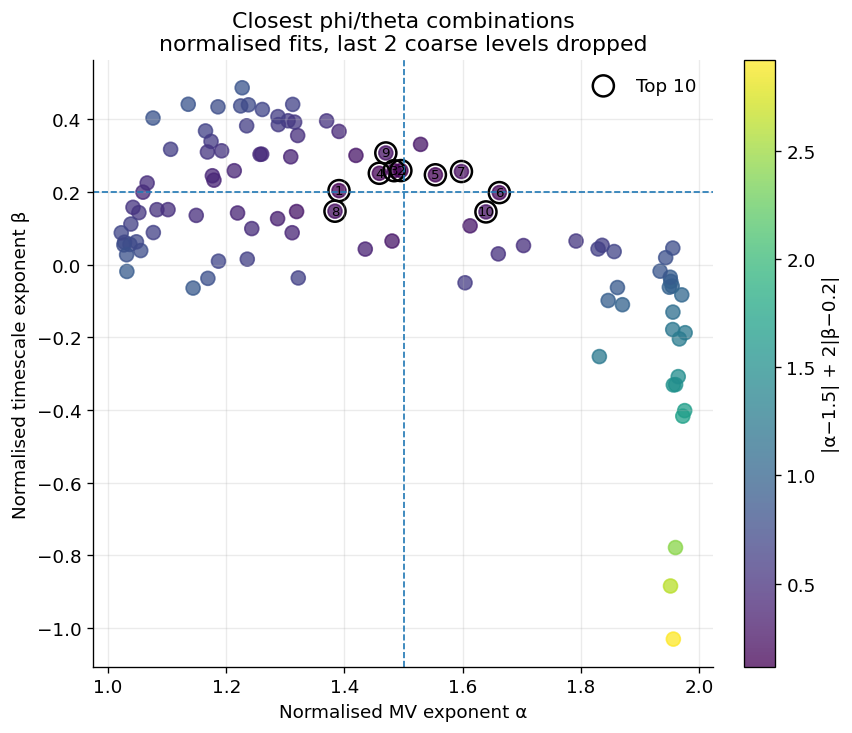

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/top10_icg_curves_norm_drop_last2.png


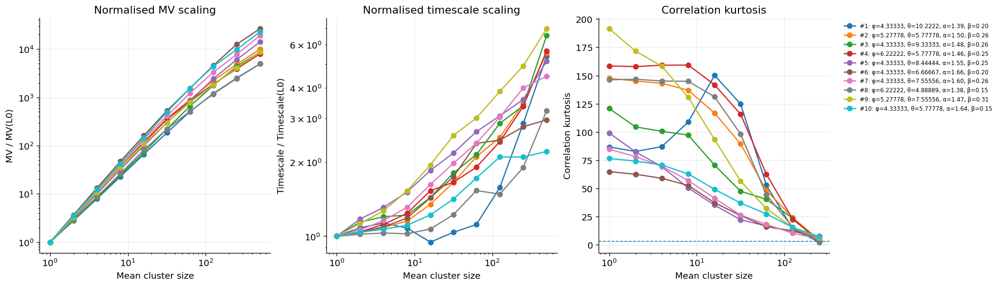

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/top10_target_score_heatmap_norm_drop_last2.png


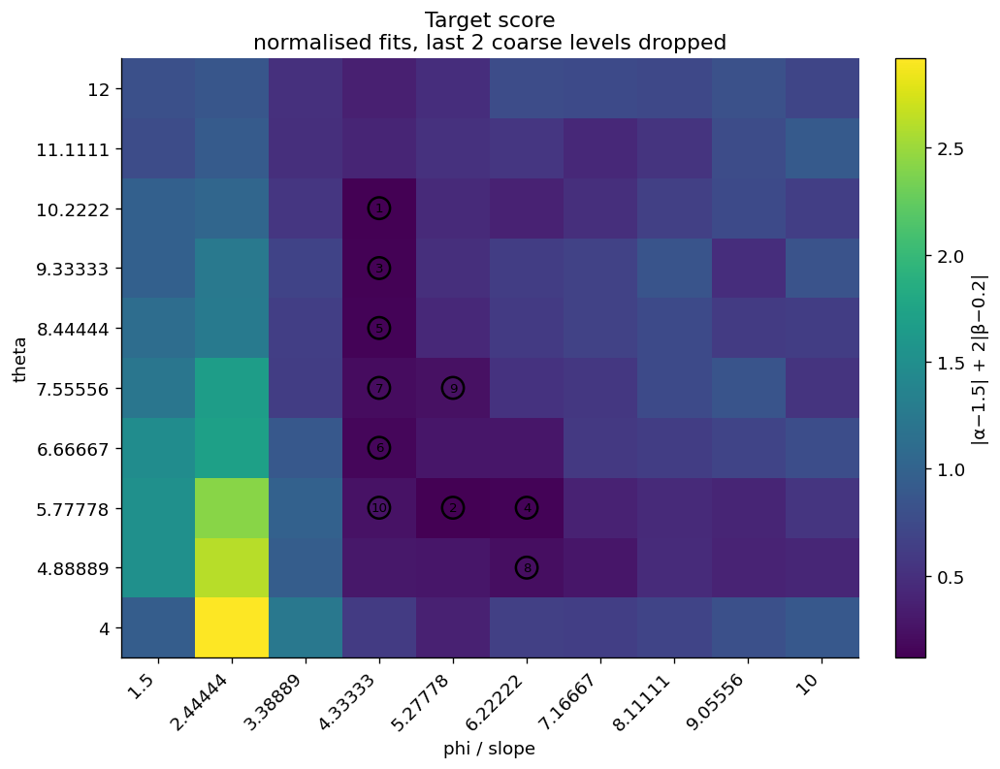

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/top10_alpha_beta_bars_norm_drop_last2.png


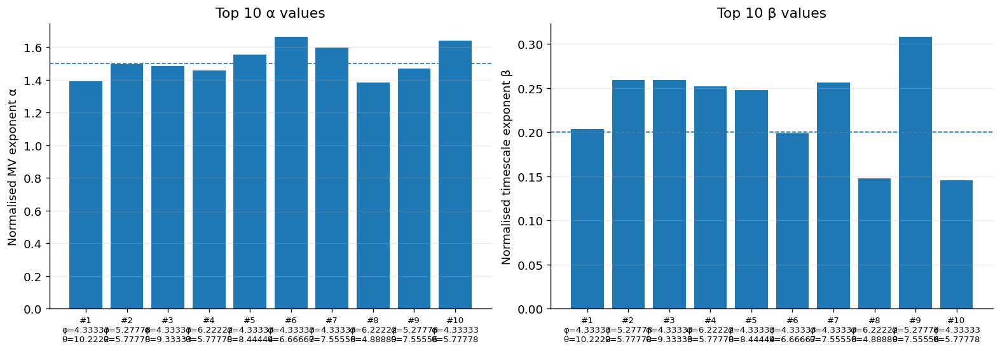

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/top10_vs_intrinsic_leak_norm_drop_last2.png


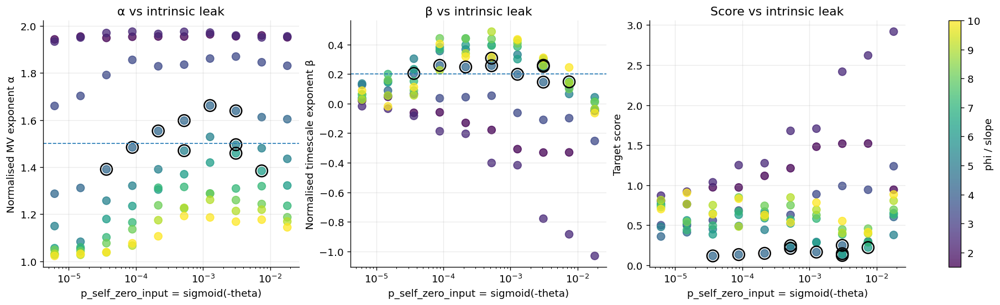

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/top10_exponents_vs_phi_all_combos_norm_drop_last2.png


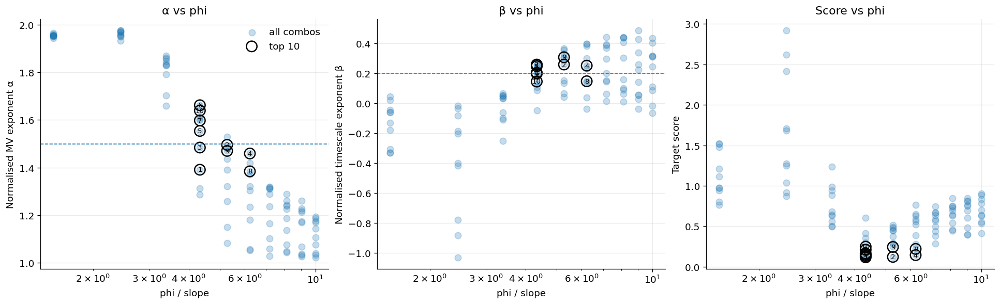

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/top10_only_exponents_vs_phi_norm_drop_last2.png


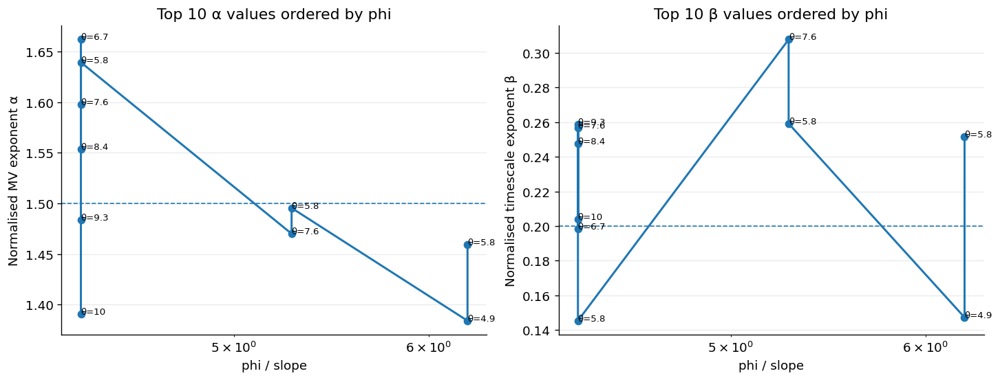

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/heatmap_mv_alpha_norm_drop_last2.png


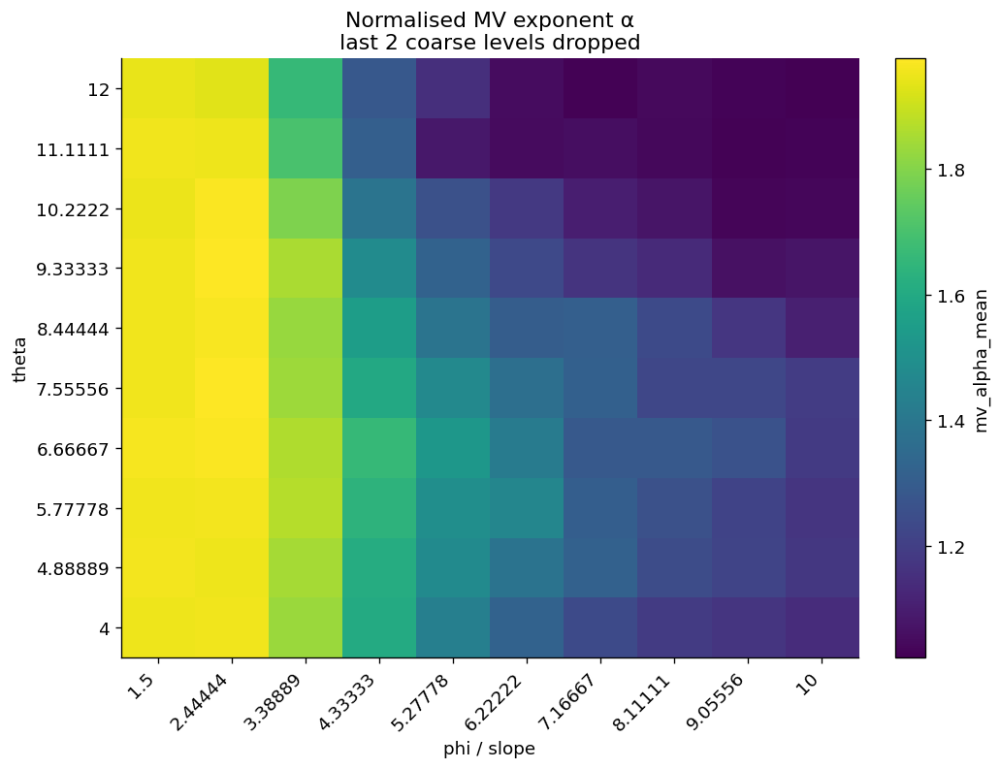

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/heatmap_ts_beta_norm_drop_last2.png


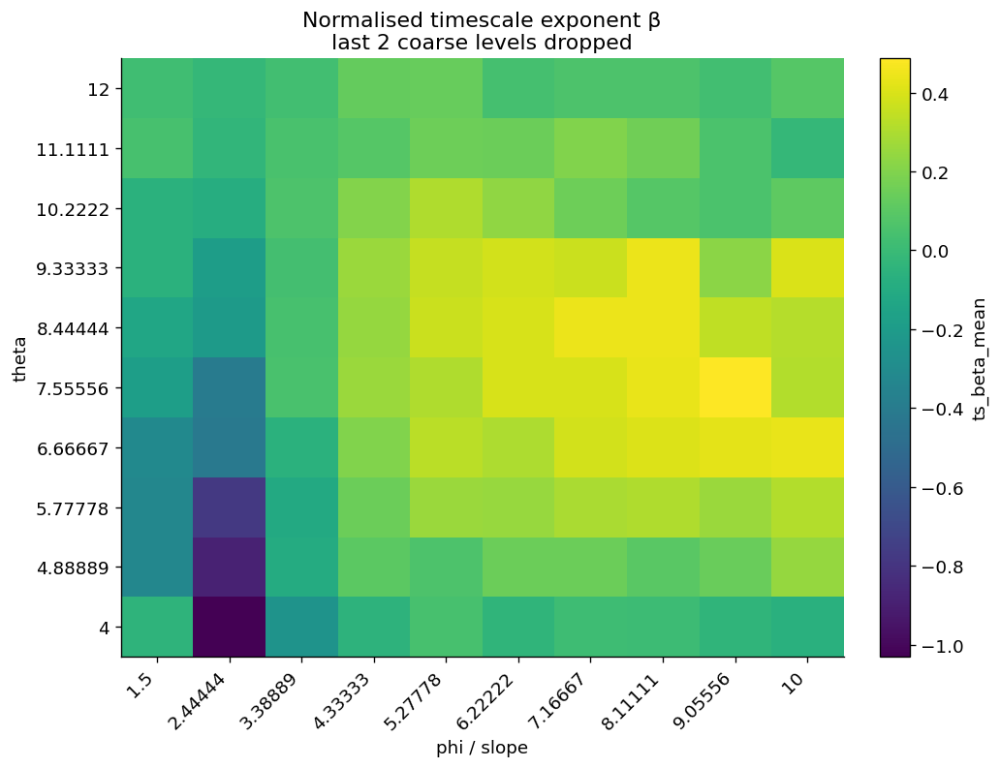

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/heatmap_mv_r2_norm_drop_last2.png


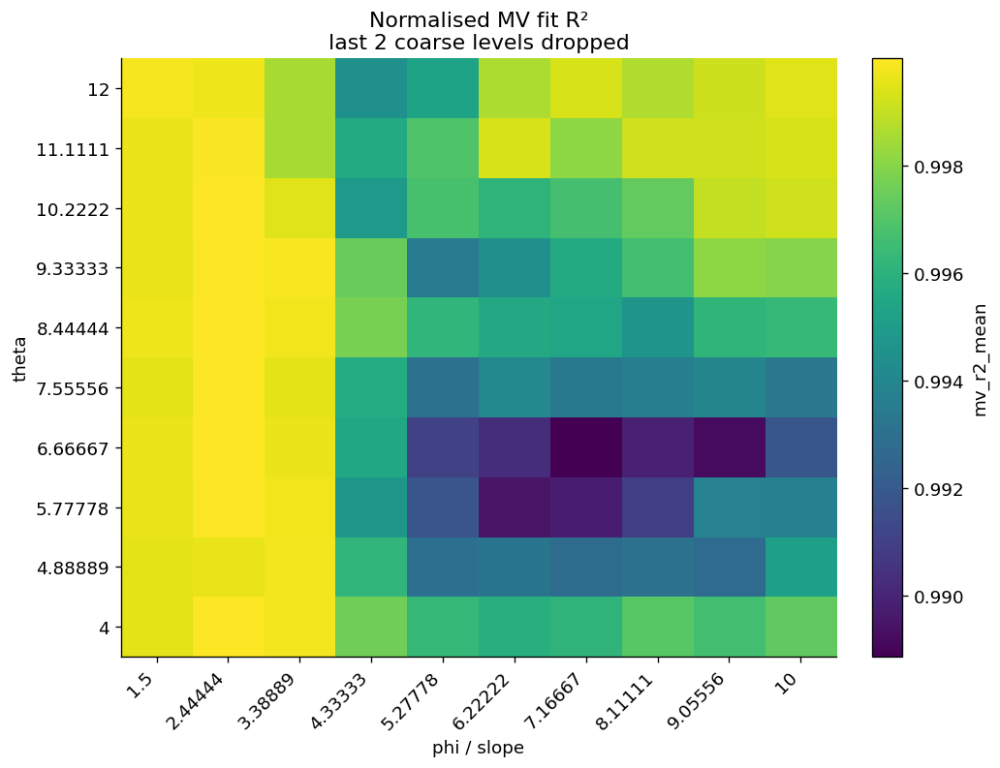

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/heatmap_ts_r2_norm_drop_last2.png


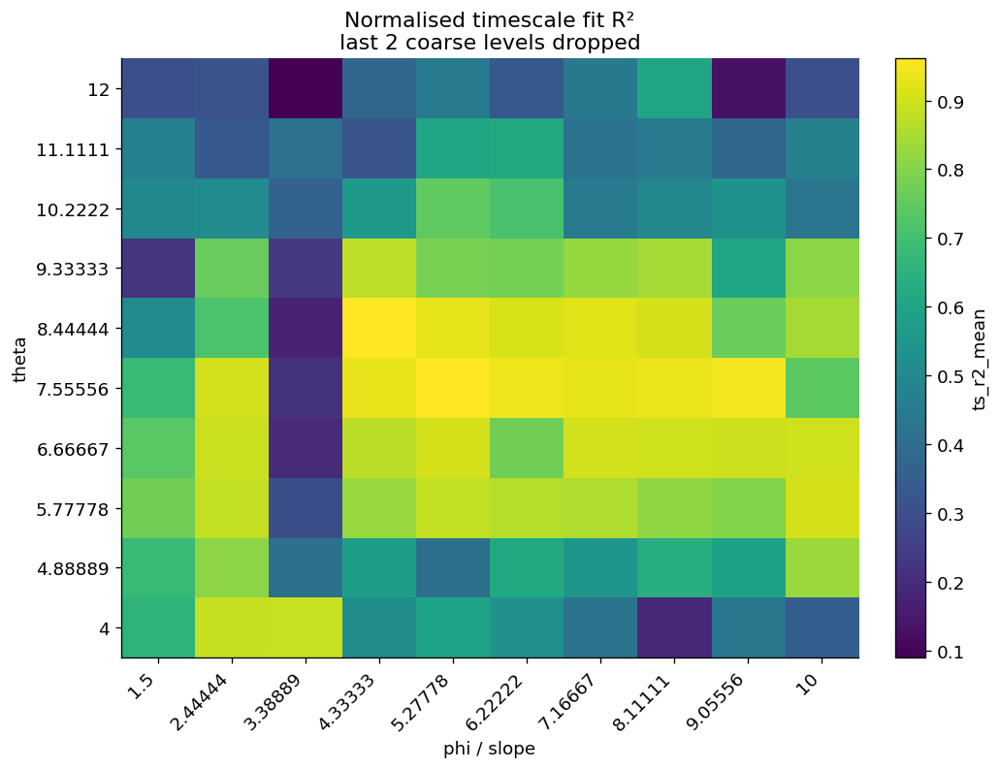

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/heatmap_target_score_norm_drop_last2.png


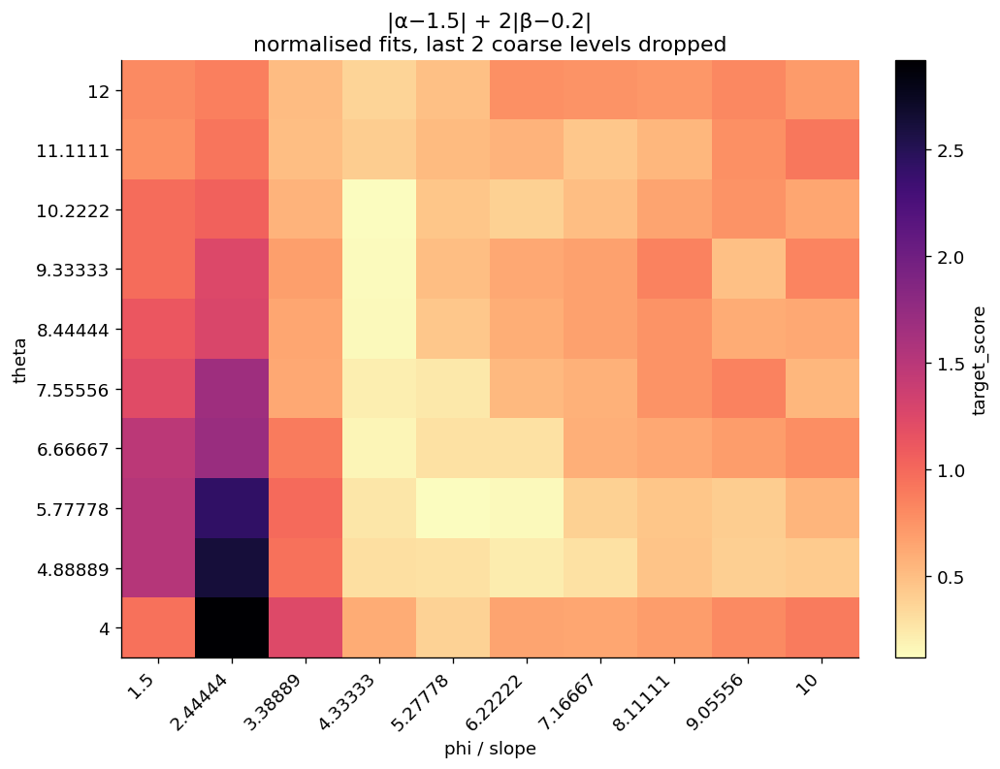

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old/heatmap_p_self_zero_input.png


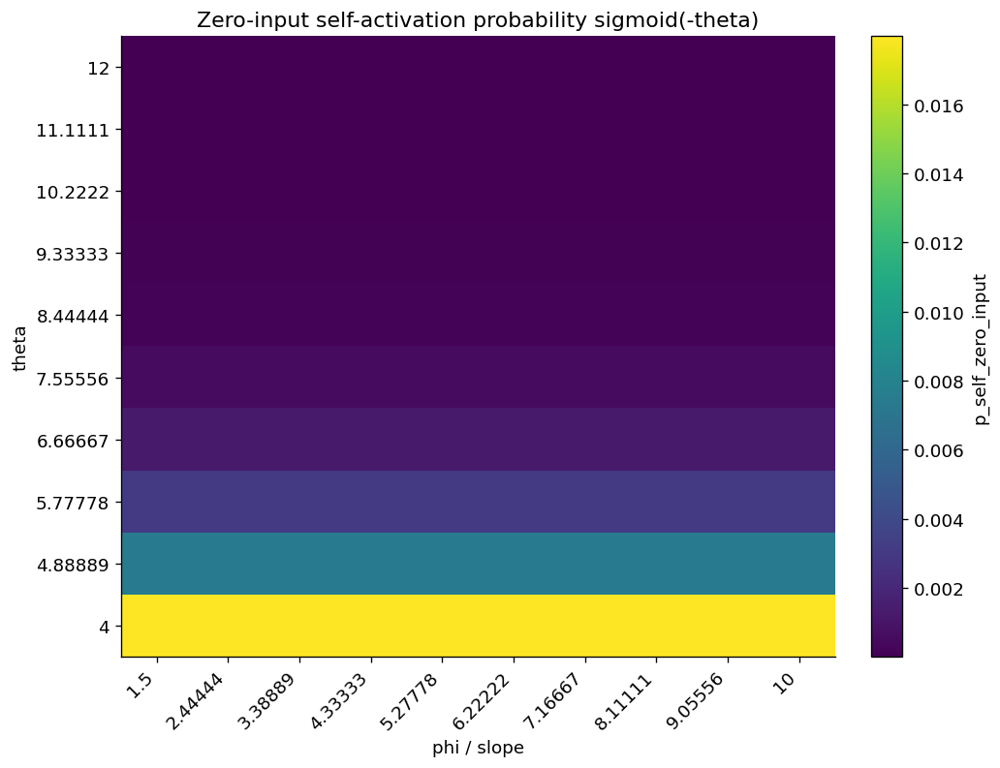


Done.
Recomputed summary:
/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/phi_theta_summary_norm_drop_last2.csv

Top 10:
/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/top10_closest_norm_drop_last2_alpha1p5_beta0p2.csv

Plots:
/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr/plots_top10_target_norm_drop_last2_all_old


In [21]:
# ============================================================
# TOP 10 PHI/THETA TARGET SEARCH + ALL PLOTS
#
# Uses:
#   - generation-level output
#   - NORMALISED MV and timescale
#   - drops last 2 coarsest ICG levels
#   - recomputes exponents from trimmed normalised curves
#
# Makes old plots + new plots:
#   1. alpha-beta scatter
#   2. normalised ICG curves for top 10
#   3. target-score heatmap
#   4. alpha/beta bars
#   5. intrinsic leak plots
#   6. phi vs exponents for all combos, top 10 highlighted
#   7. phi vs exponents for top 10 only
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ----------------------------
# Paths
# ----------------------------
OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_selfactivation_rawspikes_fullautocorr")
PLOTDIR = OUTDIR / "plots_top10_target_norm_drop_last2_all_old"
PLOTDIR.mkdir(parents=True, exist_ok=True)

GEN_PATH = OUTDIR / "phi_theta_generation_metrics.csv"

gen_all = pd.read_csv(GEN_PATH)
gen_all = gen_all.replace([np.inf, -np.inf], np.nan)

# ----------------------------
# Settings
# ----------------------------
TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

DROP_LAST_N_GENS = 2

XCOL = "mean_cluster_size"
MV_COL = "mean_variance_norm"
TS_COL = "timescale_norm"

PARAM_COLS = ["phi", "theta", "seed"]

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


# ============================================================
# Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def safe_loglog_slope(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x = x[ok]
    y = y[ok]

    if len(x) < 3:
        return np.nan, np.nan, np.nan

    fit = linregress(np.log10(x), np.log10(y))
    return float(fit.slope), float(fit.rvalue ** 2), float(fit.pvalue)


def drop_last_coarse_gens(df, n_drop=2):
    df = df.sort_values("gen").copy()
    gens = np.sort(df["gen"].dropna().unique())

    if len(gens) > n_drop + 2:
        keep_gens = gens[:-n_drop]
        df = df[df["gen"].isin(keep_gens)]

    return df


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# 1. Refit per-seed exponents after dropping last 2 levels
# ============================================================

rows = []

for (phi, theta, seed), gg in gen_all.groupby(PARAM_COLS):
    gg_fit = drop_last_coarse_gens(gg, DROP_LAST_N_GENS)

    alpha, mv_r2, mv_p = safe_loglog_slope(
        gg_fit[XCOL],
        gg_fit[MV_COL],
    )

    beta, ts_r2, ts_p = safe_loglog_slope(
        gg_fit[XCOL],
        gg_fit[TS_COL],
    )

    p_self = (
        float(gg["p_self_zero_input"].iloc[0])
        if "p_self_zero_input" in gg.columns
        else np.nan
    )

    rows.append({
        "phi": float(phi),
        "theta": float(theta),
        "seed": int(seed),
        "p_self_zero_input": p_self,

        "mv_alpha_mean": alpha,
        "mv_r2_mean": mv_r2,
        "mv_p": mv_p,

        "ts_beta_mean": beta,
        "ts_r2_mean": ts_r2,
        "ts_p": ts_p,

        "n_gens_used": int(len(gg_fit)),
    })

seed_exponents = pd.DataFrame(rows)

seed_exponents.to_csv(
    OUTDIR / "phi_theta_seed_exponents_norm_drop_last2.csv",
    index=False,
)

print("Saved seed-level refits:")
print(OUTDIR / "phi_theta_seed_exponents_norm_drop_last2.csv")


# ============================================================
# 2. Summarise across seeds
# ============================================================

summary = (
    seed_exponents
    .groupby(["phi", "theta"], as_index=False)
    .agg(
        n=("seed", "count"),
        p_self_zero_input=("p_self_zero_input", "mean"),

        mv_alpha_mean=("mv_alpha_mean", "mean"),
        mv_alpha_sem=("mv_alpha_mean", sem),
        mv_r2_mean=("mv_r2_mean", "mean"),
        mv_r2_sem=("mv_r2_mean", sem),

        ts_beta_mean=("ts_beta_mean", "mean"),
        ts_beta_sem=("ts_beta_mean", sem),
        ts_r2_mean=("ts_r2_mean", "mean"),
        ts_r2_sem=("ts_r2_mean", sem),

        n_gens_used_mean=("n_gens_used", "mean"),
    )
    .replace([np.inf, -np.inf], np.nan)
    .sort_values(["phi", "theta"])
    .reset_index(drop=True)
)

summary["target_score"] = (
    np.abs(summary["mv_alpha_mean"] - TARGET_ALPHA)
    + 2.0 * np.abs(summary["ts_beta_mean"] - TARGET_BETA)
)

summary["target_score_r2pen"] = (
    summary["target_score"]
    + 0.5 * np.maximum(0, 0.8 - summary["mv_r2_mean"])
    + 0.5 * np.maximum(0, 0.8 - summary["ts_r2_mean"])
)

summary.to_csv(
    OUTDIR / "phi_theta_summary_norm_drop_last2.csv",
    index=False,
)

top10 = (
    summary
    .dropna(subset=["mv_alpha_mean", "ts_beta_mean", "target_score"])
    .sort_values("target_score")
    .head(10)
    .reset_index(drop=True)
)

top10.to_csv(
    OUTDIR / "top10_closest_norm_drop_last2_alpha1p5_beta0p2.csv",
    index=False,
)

print("\nTop 10 closest using normalised fits, dropping last 2 ICG levels:")
print(
    top10[
        [
            "phi", "theta", "p_self_zero_input",
            "target_score",
            "mv_alpha_mean", "mv_r2_mean",
            "ts_beta_mean", "ts_r2_mean",
            "n",
        ]
    ].round(6).to_string(index=False)
)

print("\nSaved:")
print(OUTDIR / "phi_theta_summary_norm_drop_last2.csv")
print(OUTDIR / "top10_closest_norm_drop_last2_alpha1p5_beta0p2.csv")


# ============================================================
# 3. Trim generation-level rows and make generation summary
# ============================================================

trimmed = []

for (phi, theta, seed), gg in gen_all.groupby(PARAM_COLS):
    trimmed.append(drop_last_coarse_gens(gg, DROP_LAST_N_GENS))

gen_trimmed = pd.concat(trimmed, ignore_index=True)

gen_summary = (
    gen_trimmed
    .groupby(["phi", "theta", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),
        p_self_zero_input=("p_self_zero_input", "mean"),

        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", sem),
    )
    .sort_values(["phi", "theta", "gen"])
    .reset_index(drop=True)
)

gen_summary.to_csv(
    OUTDIR / "phi_theta_generation_summary_norm_drop_last2.csv",
    index=False,
)

print("Saved generation summary:")
print(OUTDIR / "phi_theta_generation_summary_norm_drop_last2.csv")


# ============================================================
# Plot 1: alpha-beta scatter, highlight top 10
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)

sc = ax.scatter(
    summary["mv_alpha_mean"],
    summary["ts_beta_mean"],
    c=summary["target_score"],
    s=70,
    alpha=0.75,
)

ax.scatter(
    top10["mv_alpha_mean"],
    top10["ts_beta_mean"],
    s=160,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Top 10",
)

for i, r in top10.iterrows():
    ax.text(
        r["mv_alpha_mean"],
        r["ts_beta_mean"],
        f"{i+1}",
        ha="center",
        va="center",
        fontsize=8,
    )

ax.axvline(TARGET_ALPHA, linestyle="--", linewidth=1)
ax.axhline(TARGET_BETA, linestyle="--", linewidth=1)

ax.set_xlabel("Normalised MV exponent α")
ax.set_ylabel("Normalised timescale exponent β")
ax.set_title("Closest phi/theta combinations\nnormalised fits, last 2 coarse levels dropped")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("|α−1.5| + 2|β−0.2|")

savefig(fig, "top10_alpha_beta_scatter_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 2: top 10 normalised ICG curves
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for i, r in top10.iterrows():
    phi = r["phi"]
    theta = r["theta"]

    gg = gen_summary[
        np.isclose(gen_summary["phi"], phi)
        & np.isclose(gen_summary["theta"], theta)
    ].sort_values("gen")

    label = (
        f"#{i+1}: φ={phi:g}, θ={theta:g}, "
        f"α={r['mv_alpha_mean']:.2f}, β={r['ts_beta_mean']:.2f}"
    )

    axes[0].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=1.5,
        label=label,
    )

    axes[1].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=1.5,
        label=label,
    )

    axes[2].plot(
        gg["mean_cluster_size_mean"],
        gg["corr_kurtosis_mean"],
        marker="o",
        linewidth=1.5,
        label=label,
    )

axes[0].set_title("Normalised MV scaling")
axes[1].set_title("Normalised timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

axes[2].legend(
    frameon=False,
    fontsize=7,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "top10_icg_curves_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 3: heatmap of recomputed score, top 10 marked
# ============================================================

piv = summary.pivot(index="theta", columns="phi", values="target_score")
piv = piv.sort_index(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 6.5), constrained_layout=True)

im = ax.imshow(
    piv.values,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
)

ax.set_xticks(np.arange(len(piv.columns)))
ax.set_xticklabels([f"{x:g}" for x in piv.columns], rotation=45, ha="right")

ax.set_yticks(np.arange(len(piv.index)))
ax.set_yticklabels([f"{x:g}" for x in piv.index])

ax.set_xlabel("phi / slope")
ax.set_ylabel("theta")
ax.set_title("Target score\nnormalised fits, last 2 coarse levels dropped")

for i, r in top10.iterrows():
    x = list(piv.columns).index(r["phi"])
    y = list(piv.index).index(r["theta"])

    ax.scatter(
        x,
        y,
        s=180,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
    )

    ax.text(
        x,
        y,
        str(i + 1),
        ha="center",
        va="center",
        fontsize=8,
    )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("|α−1.5| + 2|β−0.2|")

savefig(fig, "top10_target_score_heatmap_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 4: compact bars for top 10 alpha/beta
# ============================================================

labels = [
    f"#{i+1}\nφ={r.phi:g}\nθ={r.theta:g}"
    for i, r in top10.iterrows()
]

x = np.arange(len(top10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axes[0].bar(x, top10["mv_alpha_mean"])
axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[0].set_ylabel("Normalised MV exponent α")
axes[0].set_title("Top 10 α values")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=0, fontsize=8)

axes[1].bar(x, top10["ts_beta_mean"])
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[1].set_ylabel("Normalised timescale exponent β")
axes[1].set_title("Top 10 β values")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=0, fontsize=8)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

savefig(fig, "top10_alpha_beta_bars_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 5: intrinsic leak plots
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(
    summary["p_self_zero_input"],
    summary["mv_alpha_mean"],
    c=summary["phi"],
    s=70,
    alpha=0.75,
)
axes[0].scatter(
    top10["p_self_zero_input"],
    top10["mv_alpha_mean"],
    s=160,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
)
axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[0].set_ylabel("Normalised MV exponent α")
axes[0].set_title("α vs intrinsic leak")

axes[1].scatter(
    summary["p_self_zero_input"],
    summary["ts_beta_mean"],
    c=summary["phi"],
    s=70,
    alpha=0.75,
)
axes[1].scatter(
    top10["p_self_zero_input"],
    top10["ts_beta_mean"],
    s=160,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
)
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[1].set_ylabel("Normalised timescale exponent β")
axes[1].set_title("β vs intrinsic leak")

sc = axes[2].scatter(
    summary["p_self_zero_input"],
    summary["target_score"],
    c=summary["phi"],
    s=70,
    alpha=0.75,
)
axes[2].scatter(
    top10["p_self_zero_input"],
    top10["target_score"],
    s=160,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
)
axes[2].set_ylabel("Target score")
axes[2].set_title("Score vs intrinsic leak")

for ax in axes:
    ax.set_xlabel("p_self_zero_input = sigmoid(-theta)")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

cbar = fig.colorbar(sc, ax=axes)
cbar.set_label("phi / slope")

savefig(fig, "top10_vs_intrinsic_leak_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 6: phi on x-axis, exponents on y, top 10 highlighted
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

axes[0].scatter(
    summary["phi"],
    summary["mv_alpha_mean"],
    s=55,
    alpha=0.25,
    label="all combos",
)

axes[1].scatter(
    summary["phi"],
    summary["ts_beta_mean"],
    s=55,
    alpha=0.25,
    label="all combos",
)

axes[2].scatter(
    summary["phi"],
    summary["target_score"],
    s=55,
    alpha=0.25,
    label="all combos",
)

axes[0].scatter(
    top10["phi"],
    top10["mv_alpha_mean"],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="top 10",
)

axes[1].scatter(
    top10["phi"],
    top10["ts_beta_mean"],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="top 10",
)

axes[2].scatter(
    top10["phi"],
    top10["target_score"],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="top 10",
)

for i, r in top10.iterrows():
    axes[0].text(r["phi"], r["mv_alpha_mean"], str(i + 1), ha="center", va="center", fontsize=8)
    axes[1].text(r["phi"], r["ts_beta_mean"], str(i + 1), ha="center", va="center", fontsize=8)
    axes[2].text(r["phi"], r["target_score"], str(i + 1), ha="center", va="center", fontsize=8)

axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1)

axes[0].set_ylabel("Normalised MV exponent α")
axes[1].set_ylabel("Normalised timescale exponent β")
axes[2].set_ylabel("Target score")

axes[0].set_title("α vs phi")
axes[1].set_title("β vs phi")
axes[2].set_title("Score vs phi")

for ax in axes:
    ax.set_xlabel("phi / slope")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].legend(frameon=False)

savefig(fig, "top10_exponents_vs_phi_all_combos_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 7: top 10 only, ordered by phi
# ============================================================

top10_phi = top10.sort_values("phi").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].plot(
    top10_phi["phi"],
    top10_phi["mv_alpha_mean"],
    marker="o",
    linewidth=1.8,
)

axes[1].plot(
    top10_phi["phi"],
    top10_phi["ts_beta_mean"],
    marker="o",
    linewidth=1.8,
)

for i, r in top10_phi.iterrows():
    label = f"θ={r['theta']:.2g}"
    axes[0].text(r["phi"], r["mv_alpha_mean"], label, fontsize=8)
    axes[1].text(r["phi"], r["ts_beta_mean"], label, fontsize=8)

axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1)

axes[0].set_ylabel("Normalised MV exponent α")
axes[1].set_ylabel("Normalised timescale exponent β")

axes[0].set_title("Top 10 α values ordered by phi")
axes[1].set_title("Top 10 β values ordered by phi")

for ax in axes:
    ax.set_xlabel("phi / slope")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

savefig(fig, "top10_only_exponents_vs_phi_norm_drop_last2.png")
plt.show()


# ============================================================
# Plot 8: heatmaps for alpha, beta, R2, and score
# ============================================================

def heatmap_metric(summary, metric, title, fname, cmap="viridis"):
    piv = summary.pivot(index="theta", columns="phi", values=metric)
    piv = piv.sort_index(ascending=True)

    fig, ax = plt.subplots(figsize=(8.5, 6.5), constrained_layout=True)

    im = ax.imshow(
        piv.values,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
    )

    ax.set_xticks(np.arange(len(piv.columns)))
    ax.set_xticklabels([f"{x:g}" for x in piv.columns], rotation=45, ha="right")

    ax.set_yticks(np.arange(len(piv.index)))
    ax.set_yticklabels([f"{x:g}" for x in piv.index])

    ax.set_xlabel("phi / slope")
    ax.set_ylabel("theta")
    ax.set_title(title)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(metric)

    savefig(fig, fname)
    plt.show()


heatmap_metric(
    summary,
    "mv_alpha_mean",
    "Normalised MV exponent α\nlast 2 coarse levels dropped",
    "heatmap_mv_alpha_norm_drop_last2.png",
)

heatmap_metric(
    summary,
    "ts_beta_mean",
    "Normalised timescale exponent β\nlast 2 coarse levels dropped",
    "heatmap_ts_beta_norm_drop_last2.png",
)

heatmap_metric(
    summary,
    "mv_r2_mean",
    "Normalised MV fit R²\nlast 2 coarse levels dropped",
    "heatmap_mv_r2_norm_drop_last2.png",
)

heatmap_metric(
    summary,
    "ts_r2_mean",
    "Normalised timescale fit R²\nlast 2 coarse levels dropped",
    "heatmap_ts_r2_norm_drop_last2.png",
)

heatmap_metric(
    summary,
    "target_score",
    "|α−1.5| + 2|β−0.2|\nnormalised fits, last 2 coarse levels dropped",
    "heatmap_target_score_norm_drop_last2.png",
    cmap="magma_r",
)

heatmap_metric(
    summary,
    "p_self_zero_input",
    "Zero-input self-activation probability sigmoid(-theta)",
    "heatmap_p_self_zero_input.png",
)


print("\nDone.")
print("Recomputed summary:")
print(OUTDIR / "phi_theta_summary_norm_drop_last2.csv")
print("\nTop 10:")
print(OUTDIR / "top10_closest_norm_drop_last2_alpha1p5_beta0p2.csv")
print("\nPlots:")
print(PLOTDIR)


Best 20 by smooth_tau:
 smooth_tau  rank_within_tau      phi     theta  p_ext  p_self_zero_input  target_score_norm  mv_alpha_norm_mean  mv_r2_norm_mean  ts_beta_norm_mean  ts_r2_norm_mean  mean_rate_hz_mean  frac_silent_frames_mean  frac_active_neurons_mean  n
     0.0000                1 5.277778 11.111111  0.015           0.000015           0.242031            1.488183         0.997203           0.084893         0.554858            6.07824                      0.0                       1.0  5
     0.0000                2 5.277778  8.444444  0.015           0.000215           0.302696            1.464397         0.995591           0.066453         0.488048            6.05764                      0.0                       1.0  5
     0.0000                3 6.222222  8.444444  0.015           0.000215           0.308199            1.343284         0.995993           0.124259         0.571314            4.92823                      0.0                       1.0  5
     0.0000         

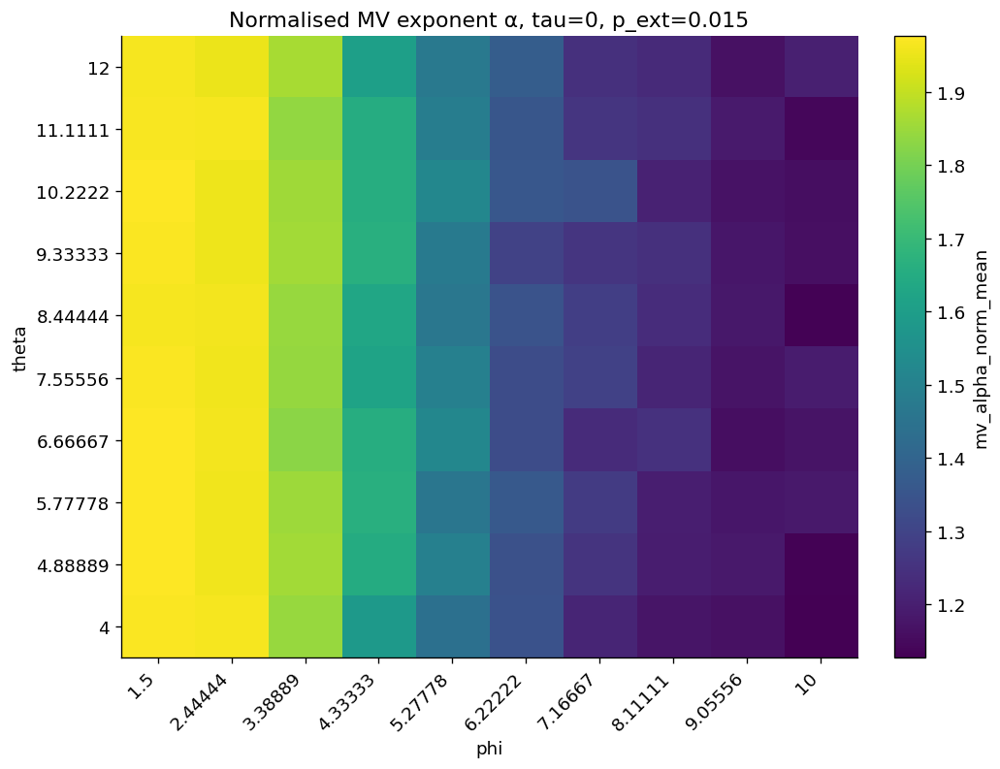

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_beta_norm_tau_0p0.png


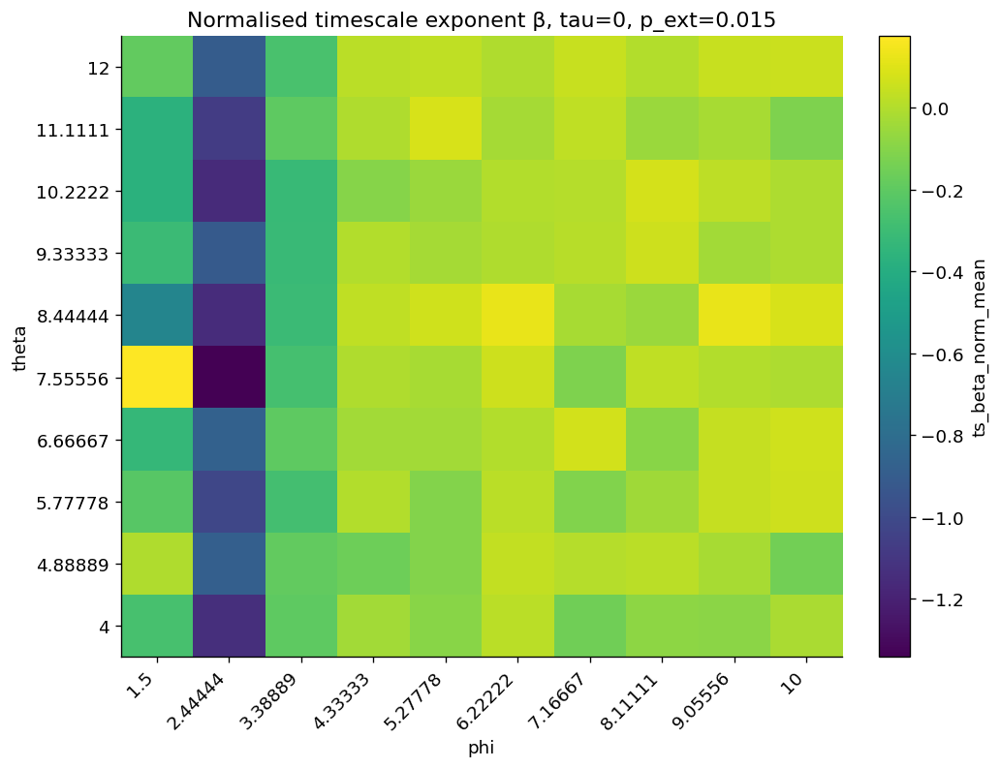

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_r2_norm_tau_0p0.png


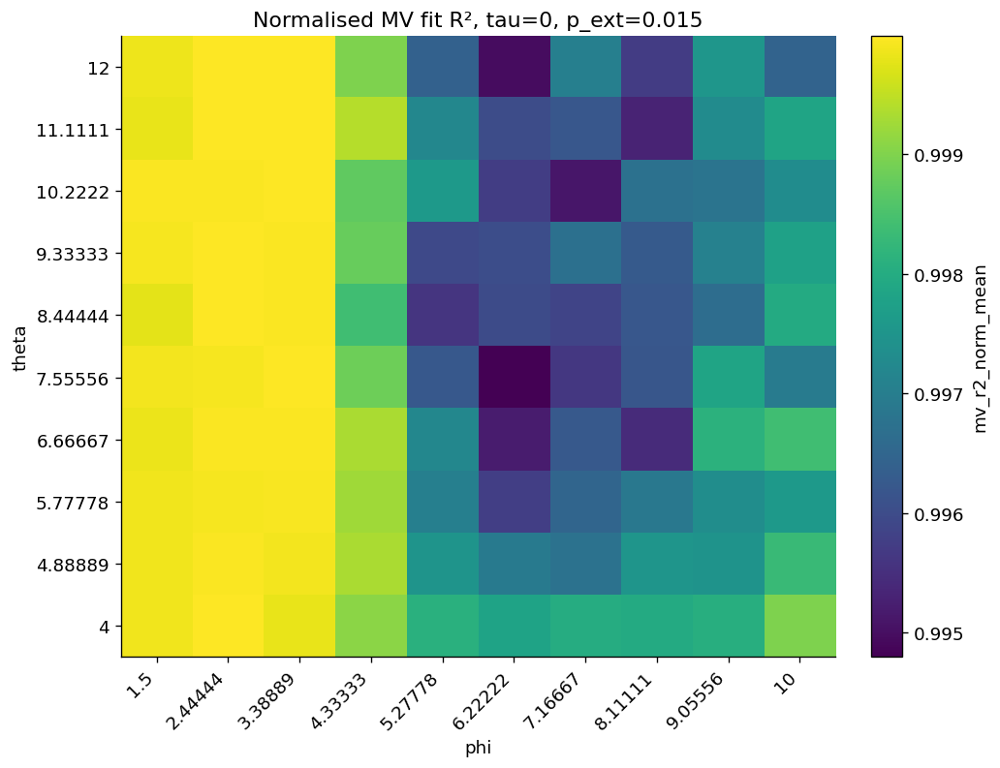

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_r2_norm_tau_0p0.png


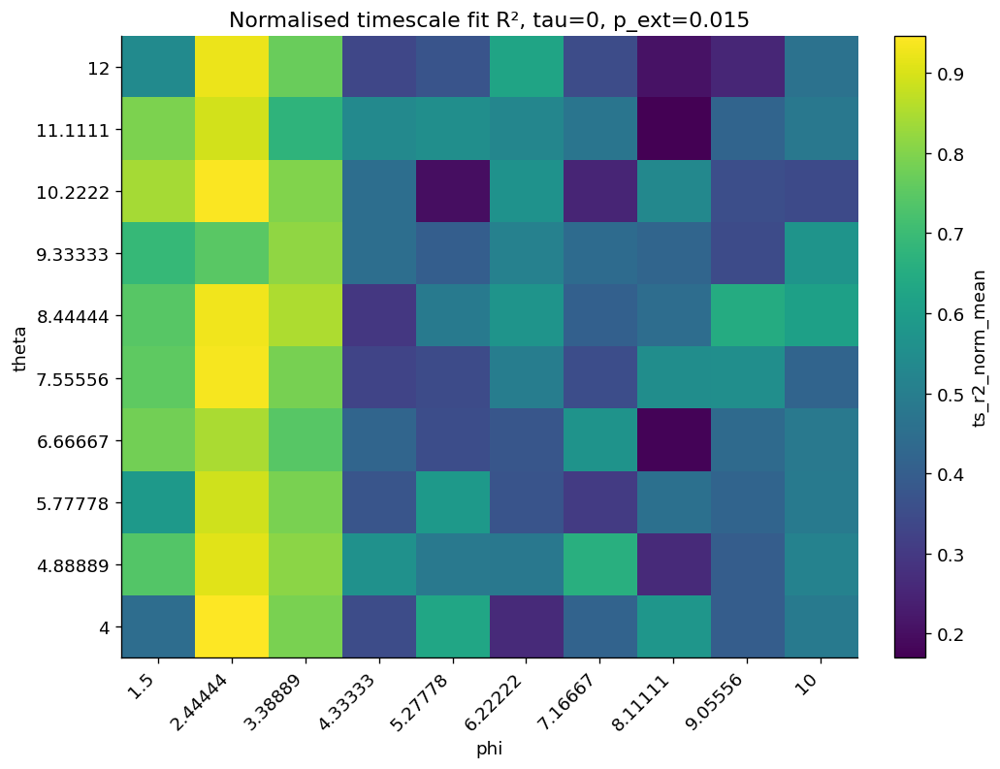

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_tau_0p0.png


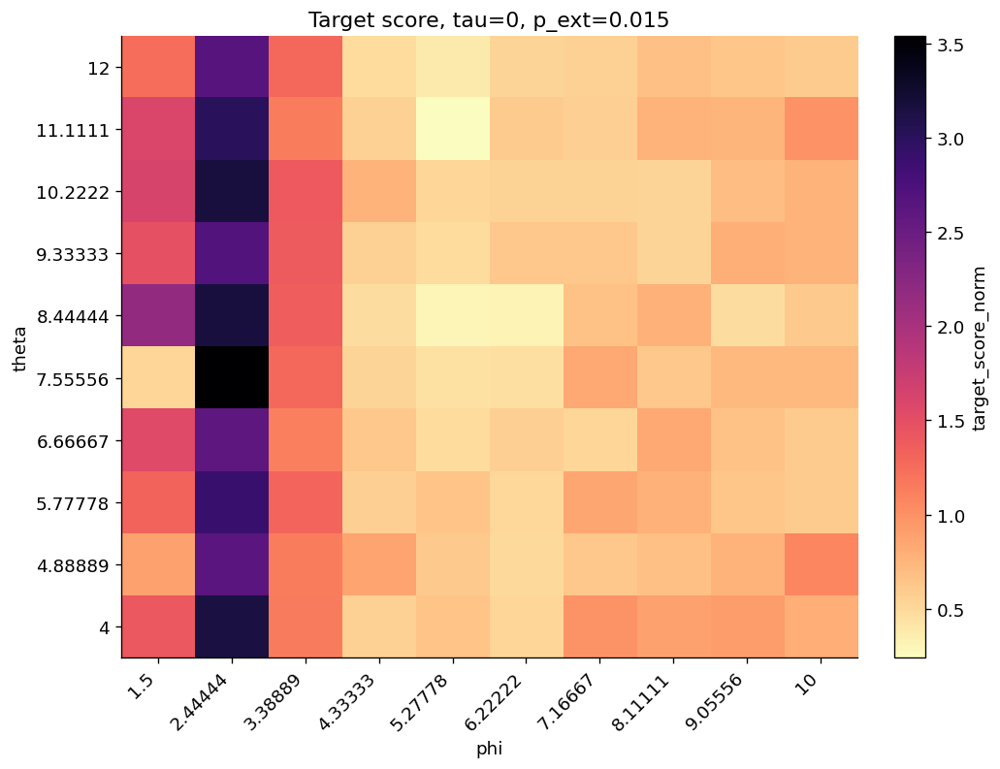

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_r2pen_tau_0p0.png


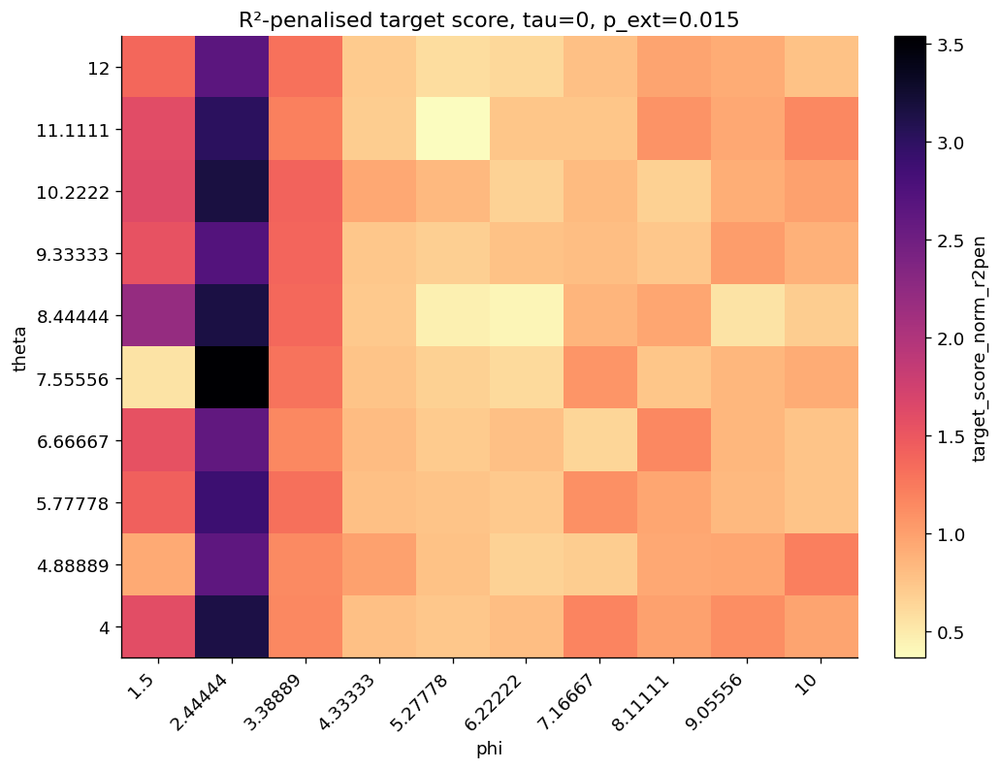

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mean_rate_tau_0p0.png


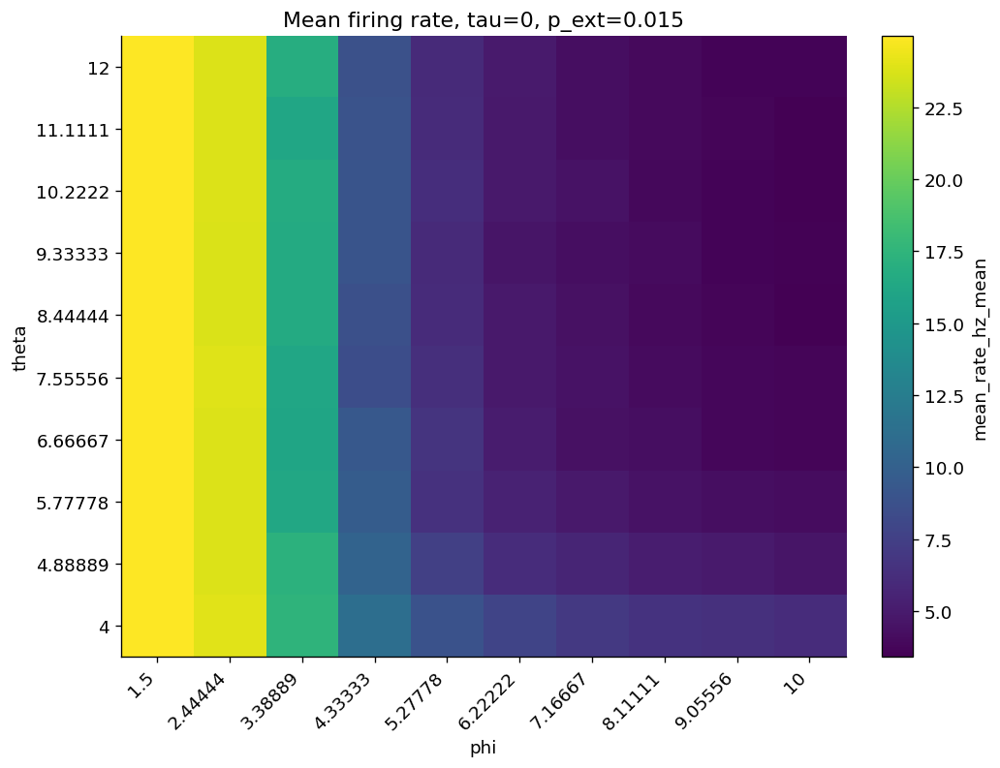

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_silent_frames_tau_0p0.png


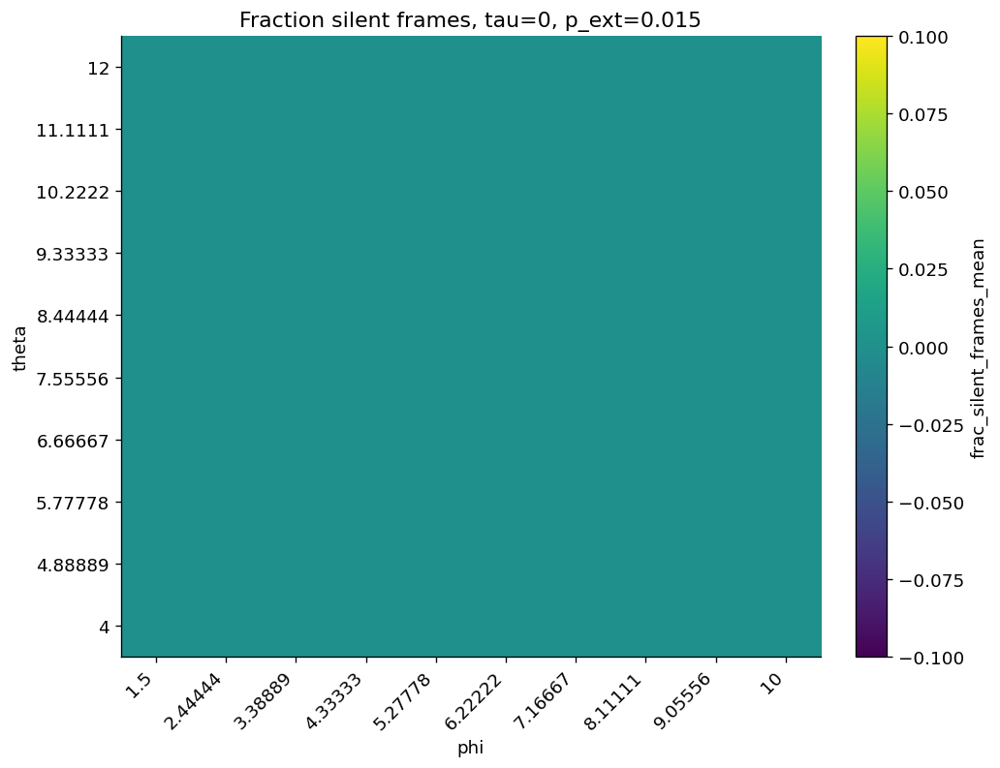

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_active_neurons_tau_0p0.png


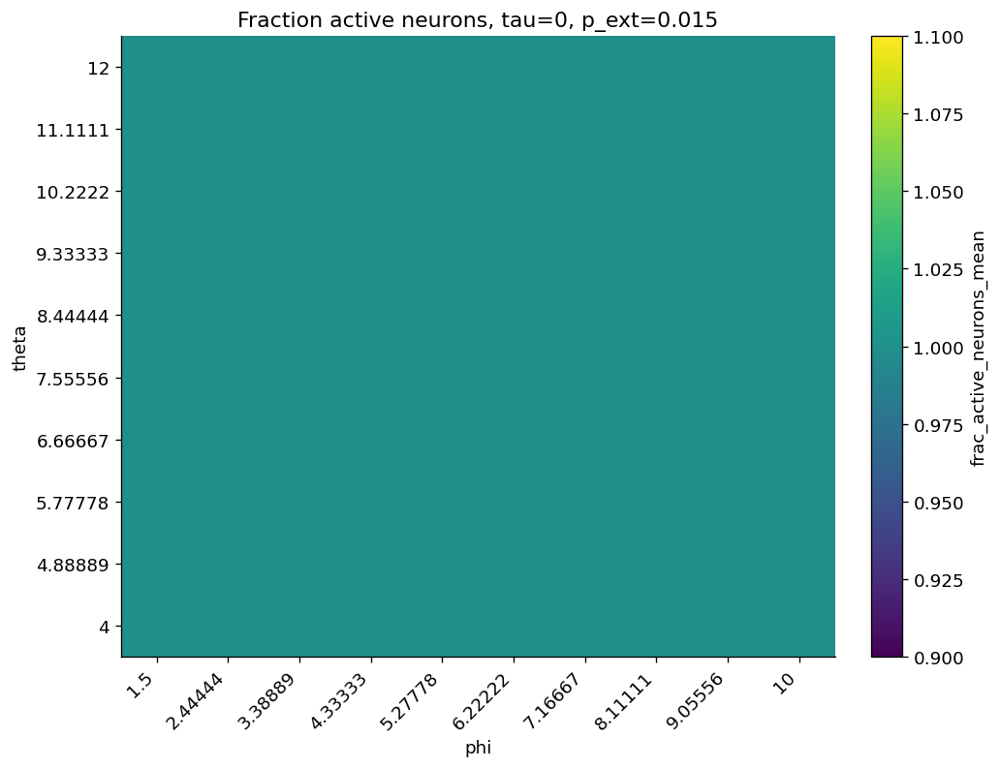

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_alpha_norm_tau_0p0125.png


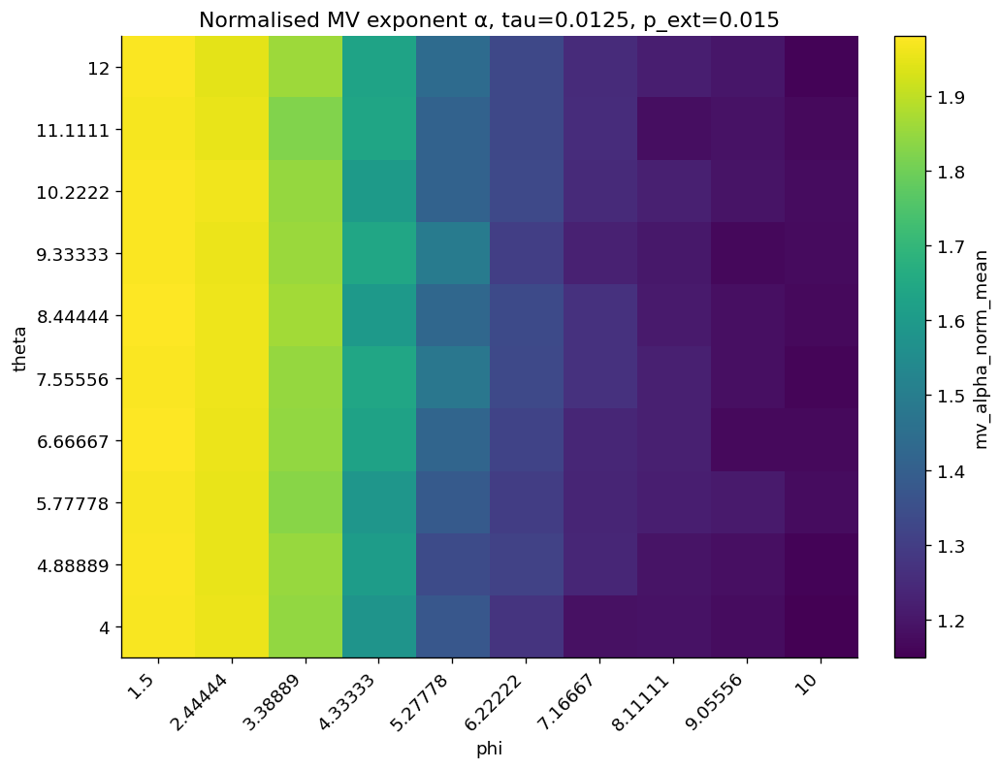

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_beta_norm_tau_0p0125.png


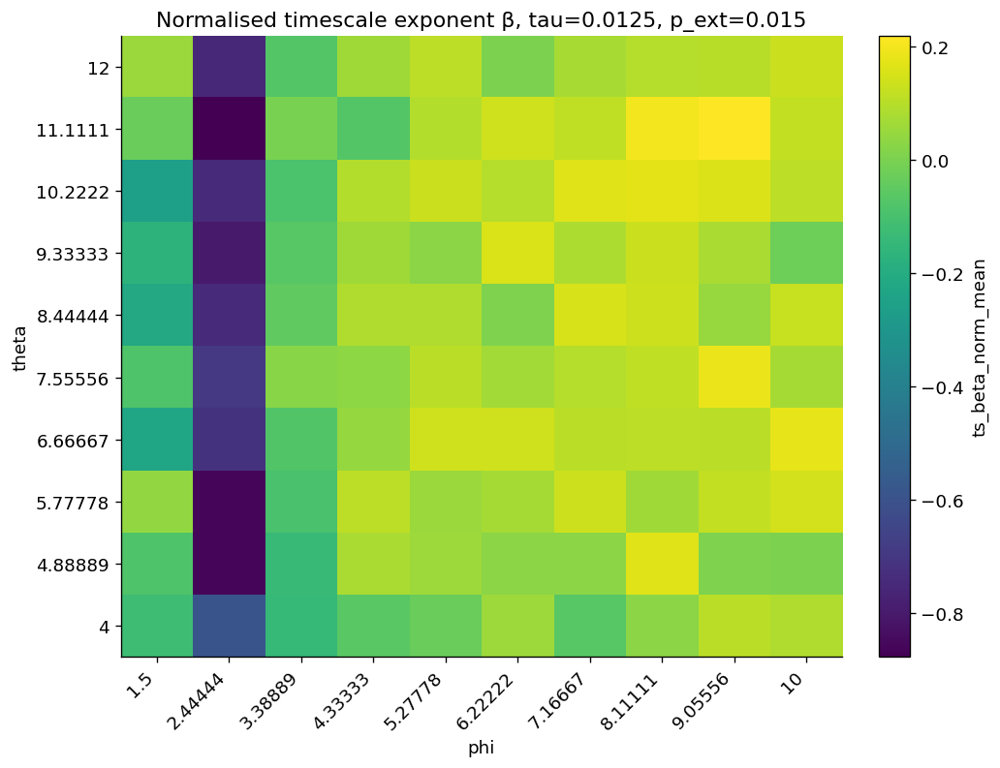

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_r2_norm_tau_0p0125.png


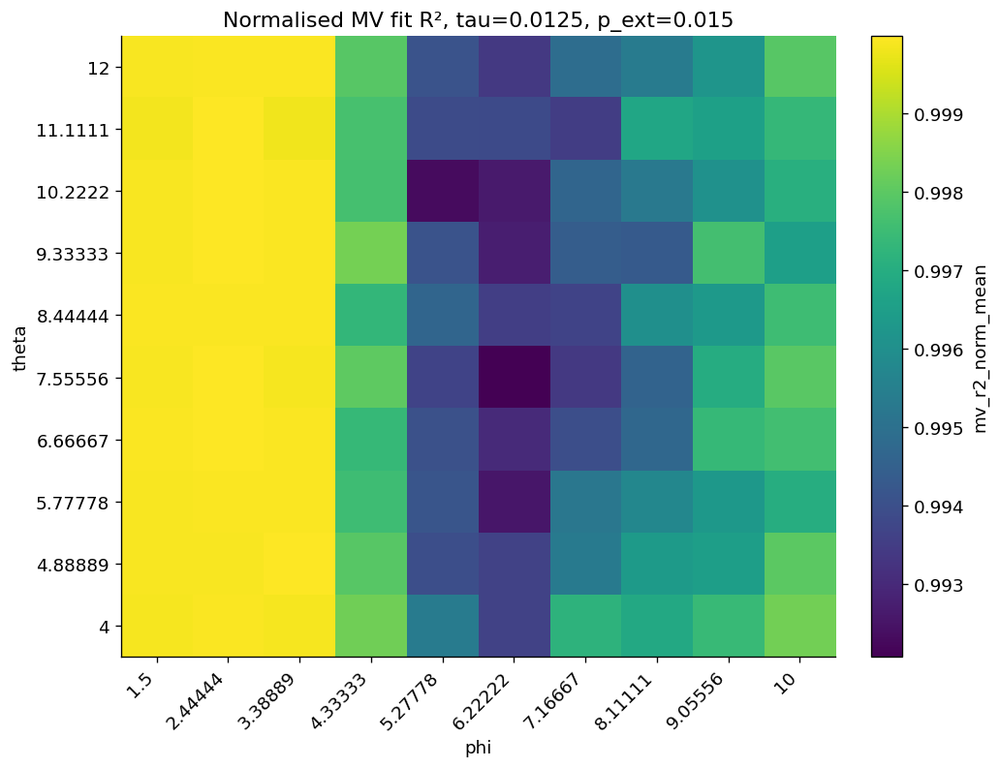

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_r2_norm_tau_0p0125.png


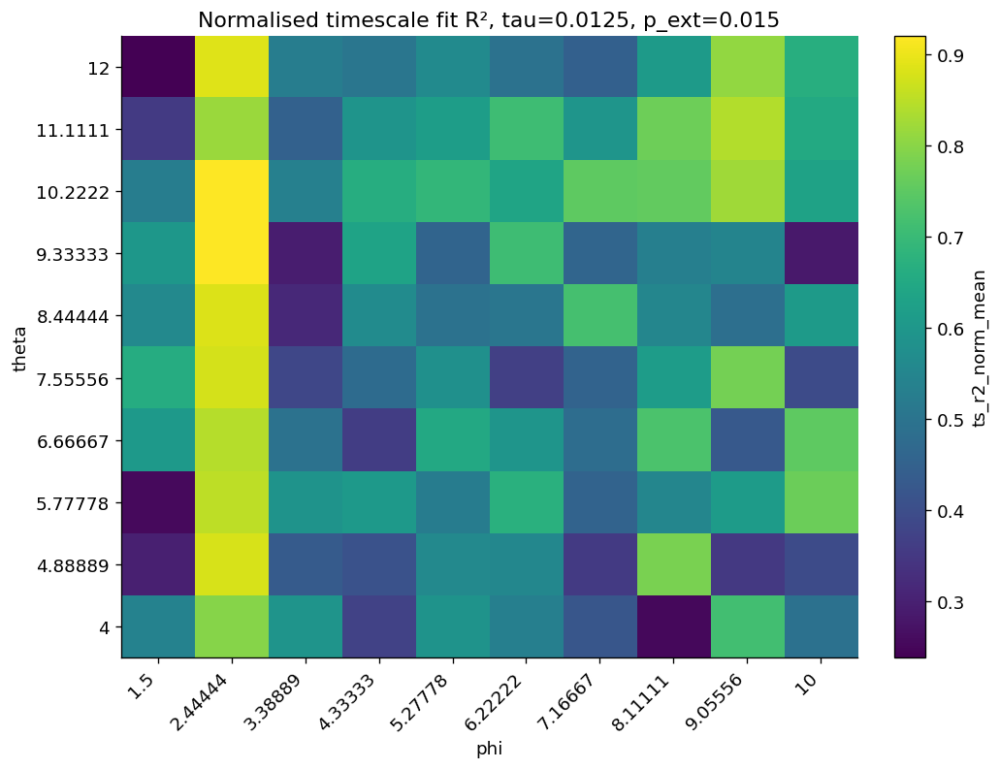

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_tau_0p0125.png


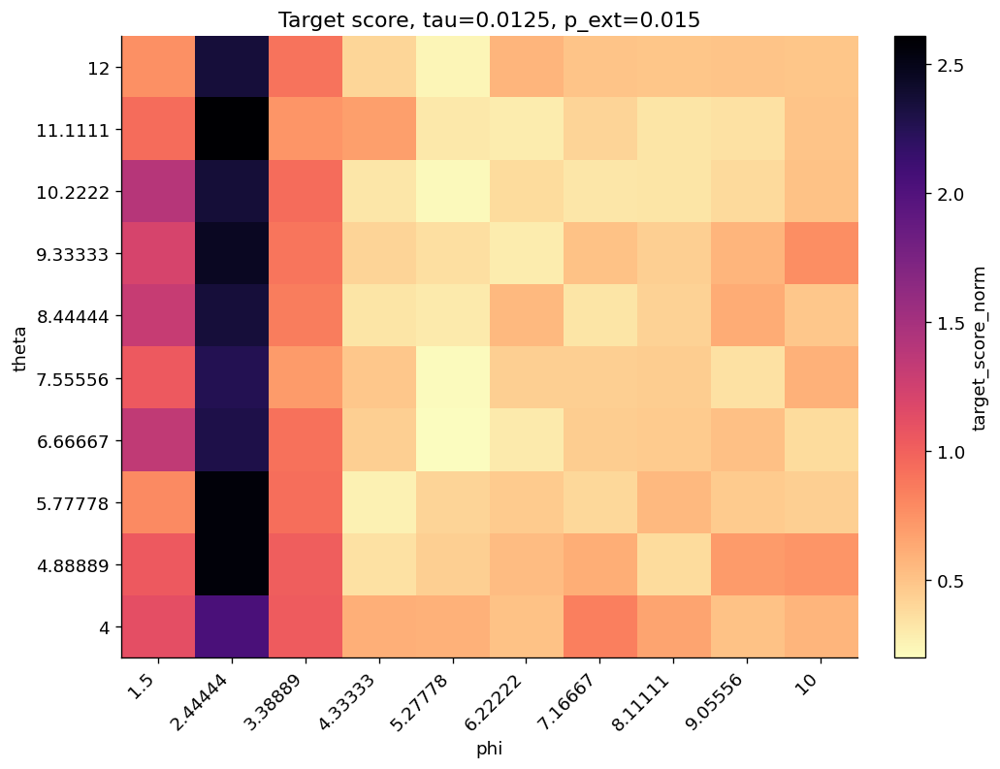

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_r2pen_tau_0p0125.png


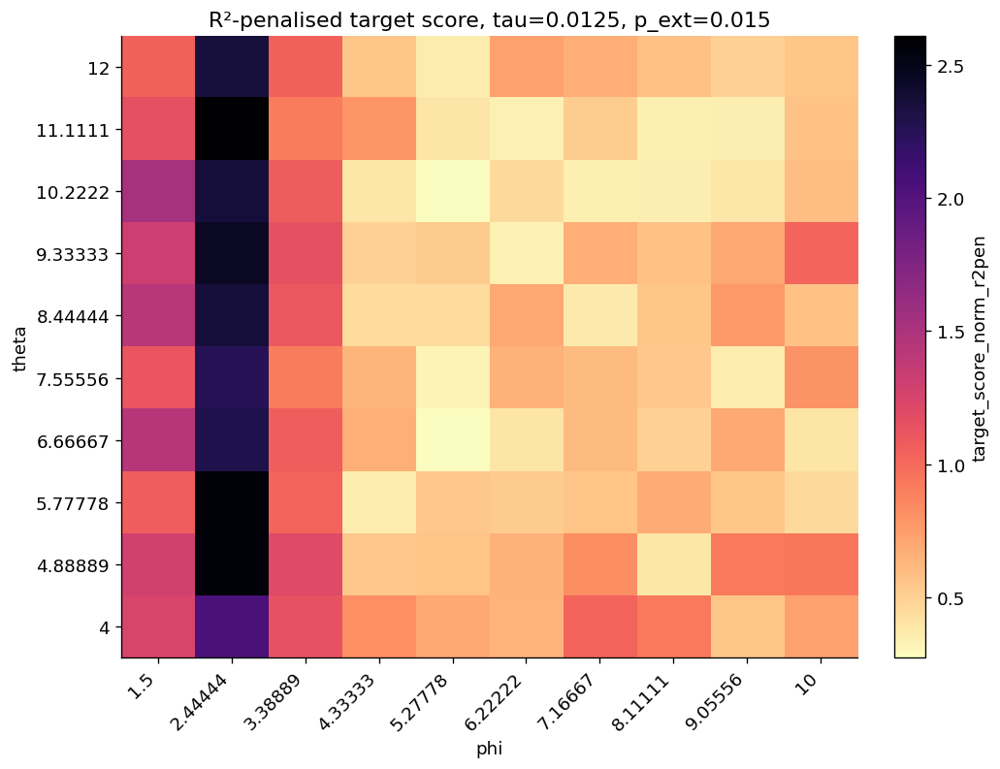

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mean_rate_tau_0p0125.png


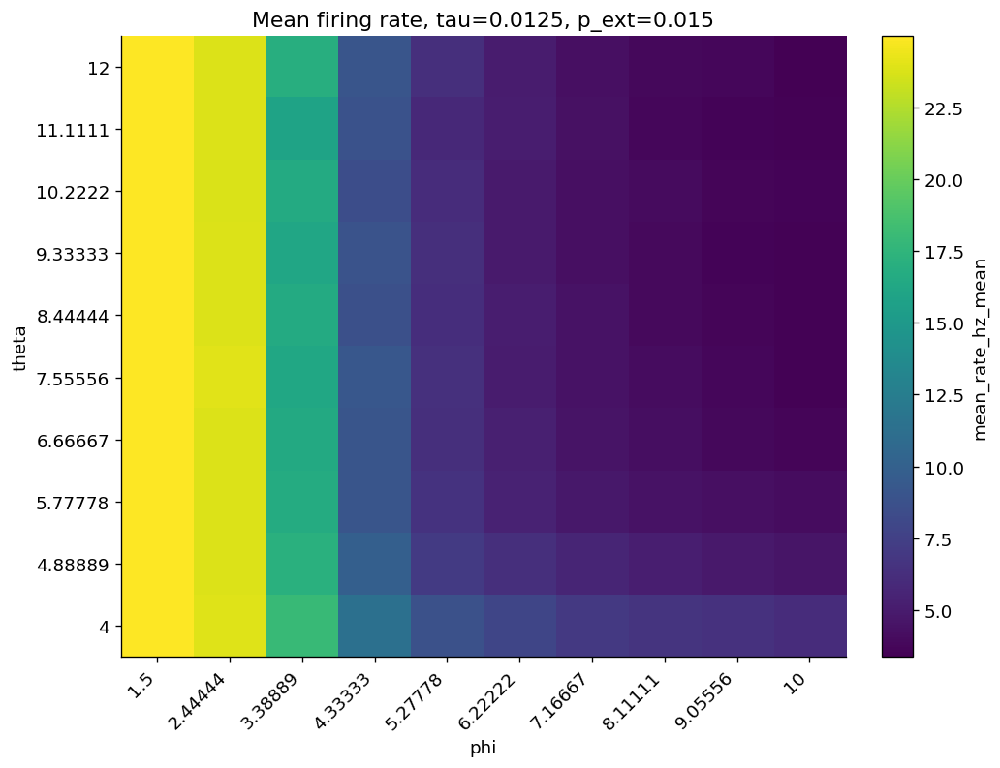

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_silent_frames_tau_0p0125.png


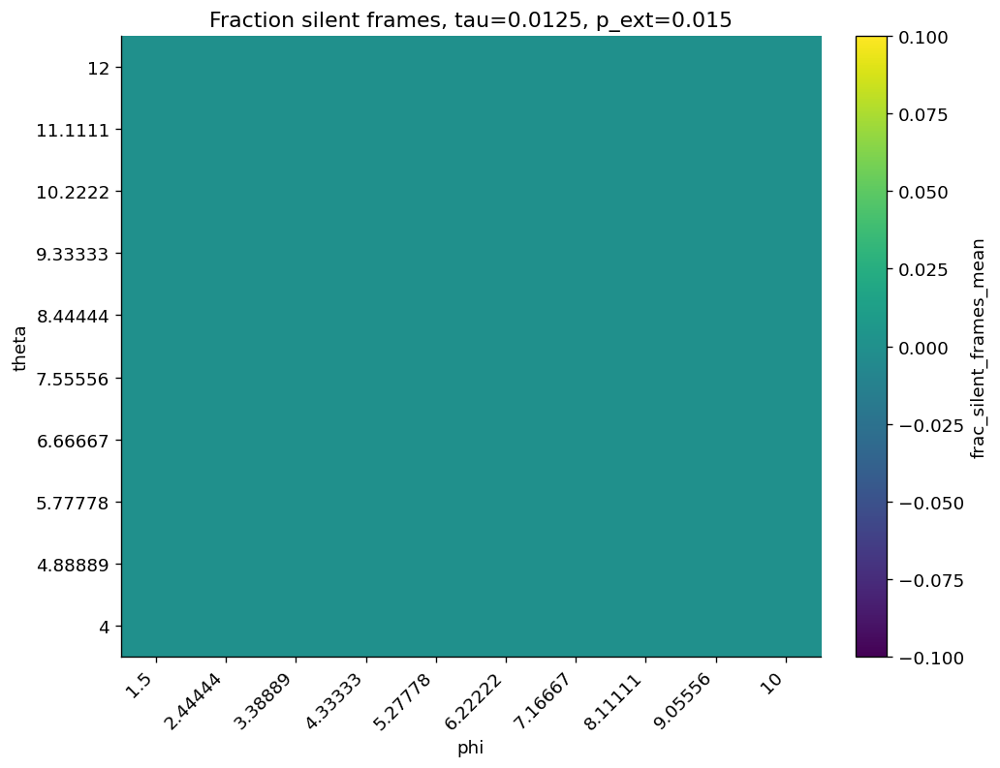

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_active_neurons_tau_0p0125.png


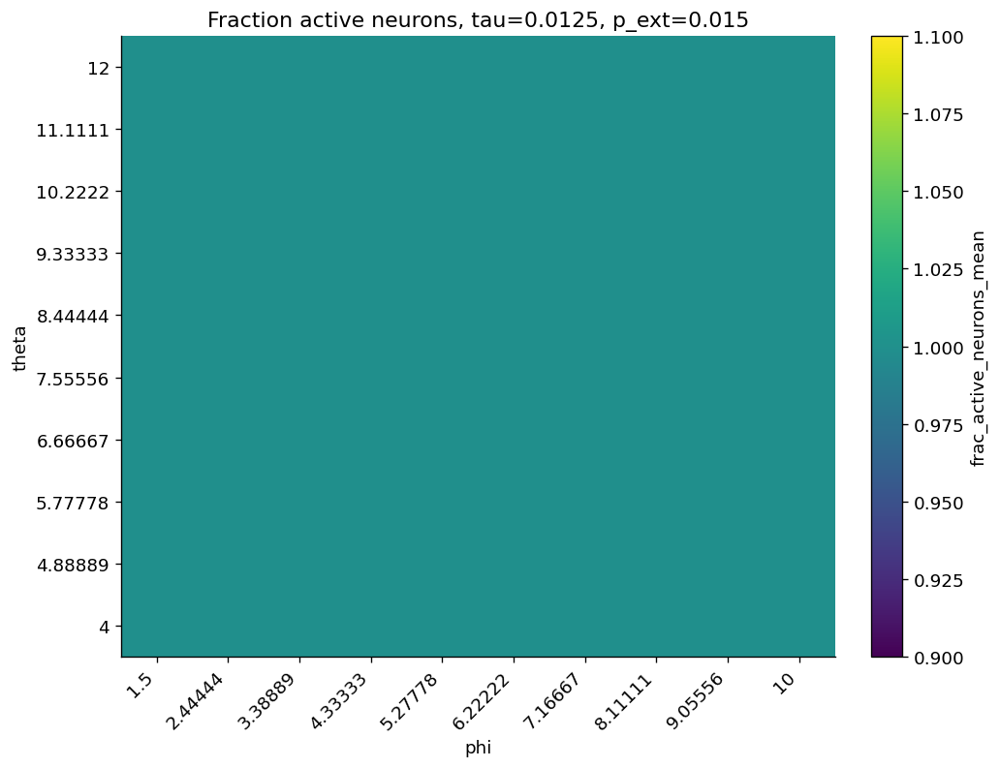

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_alpha_norm_tau_0p025.png


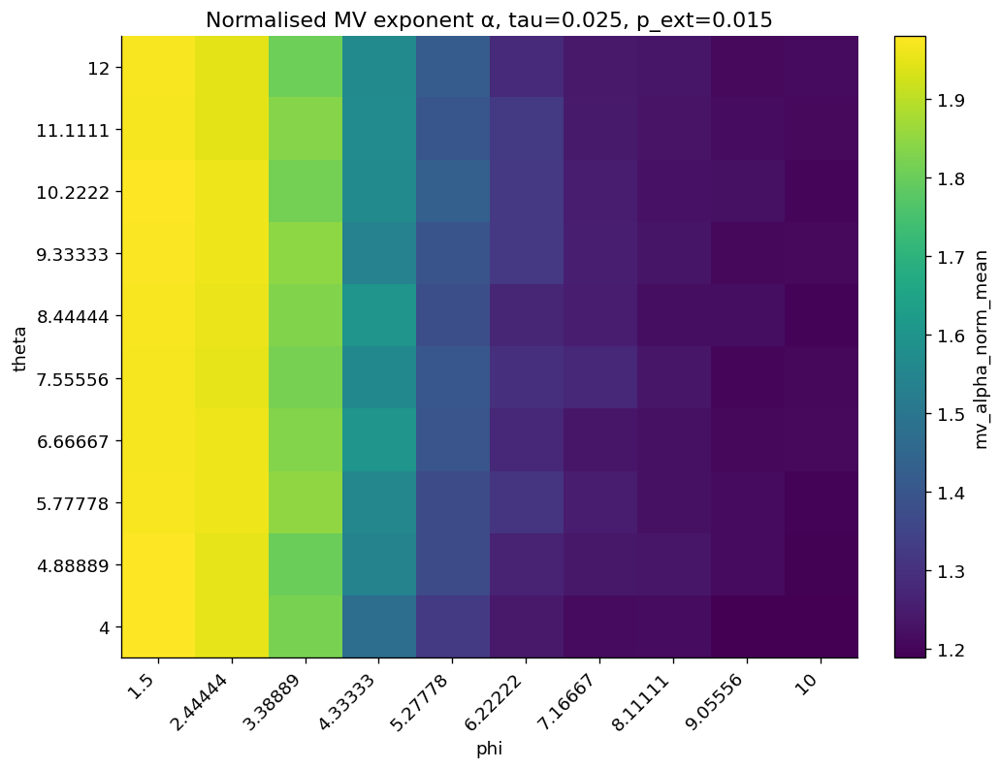

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_beta_norm_tau_0p025.png


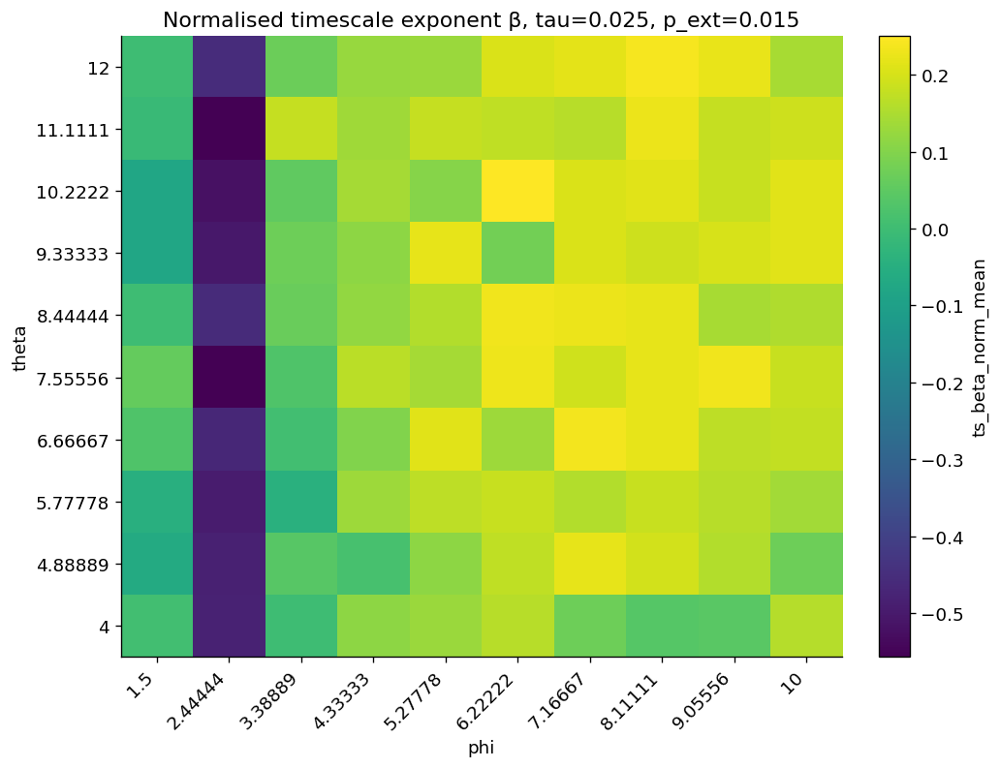

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_r2_norm_tau_0p025.png


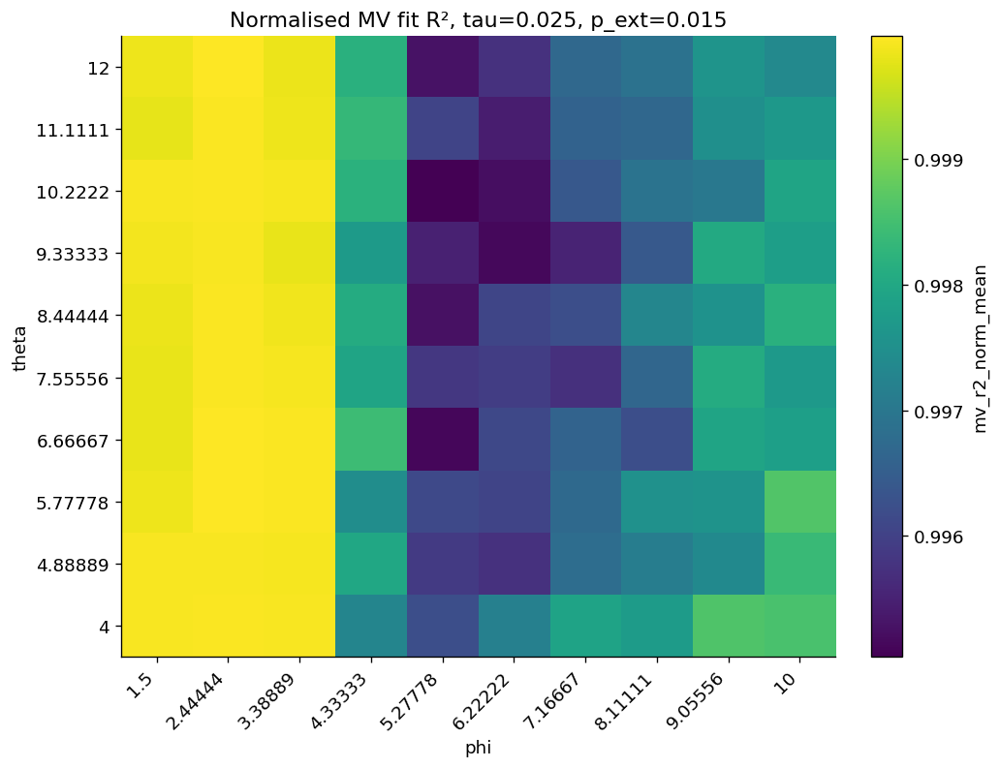

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_r2_norm_tau_0p025.png


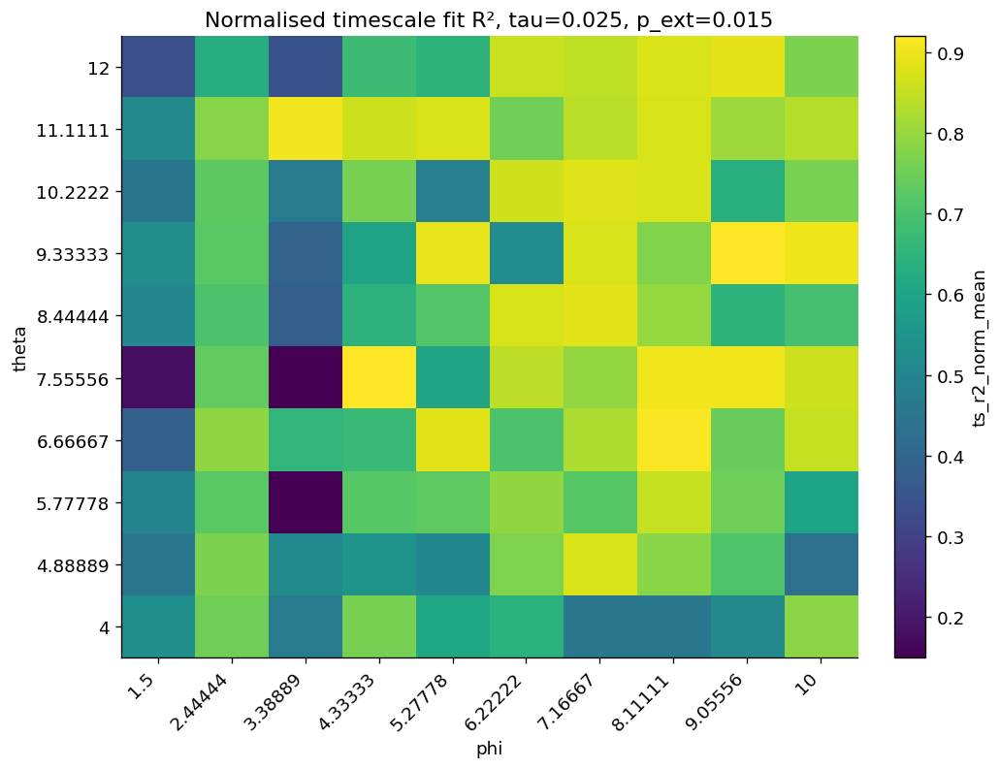

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_tau_0p025.png


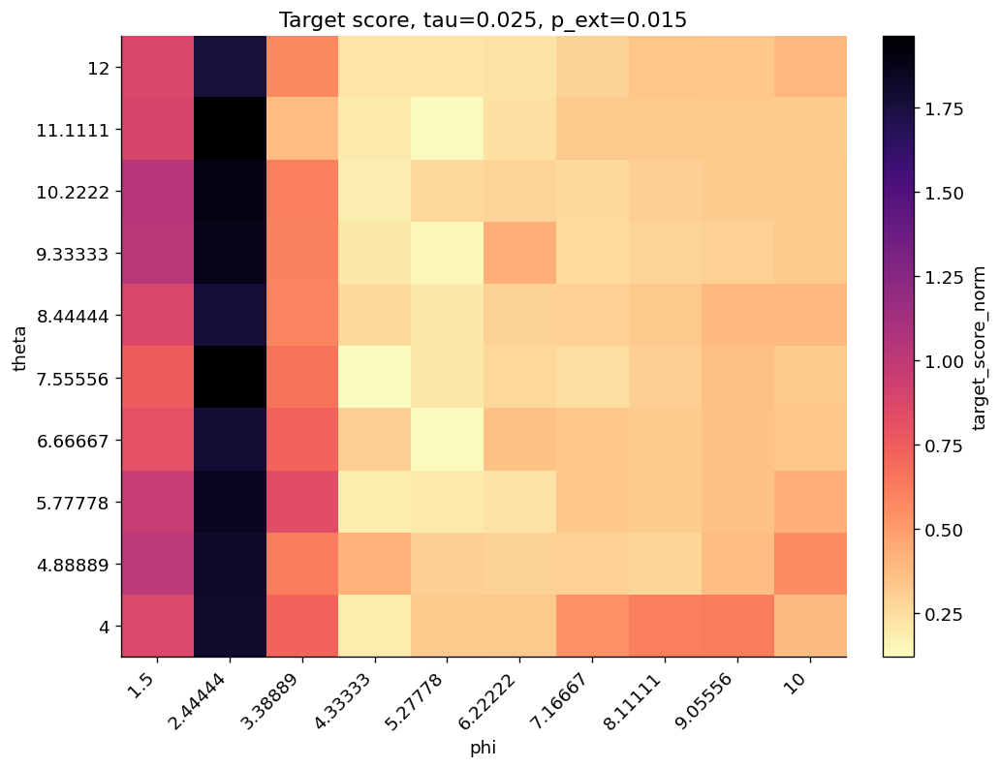

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_r2pen_tau_0p025.png


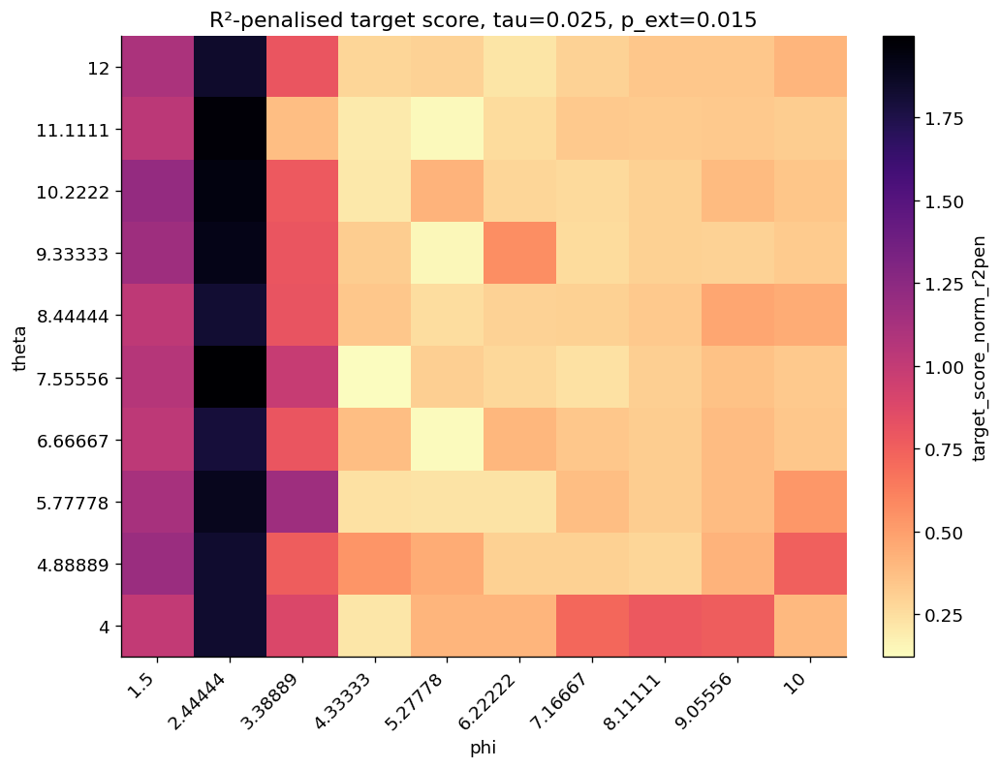

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mean_rate_tau_0p025.png


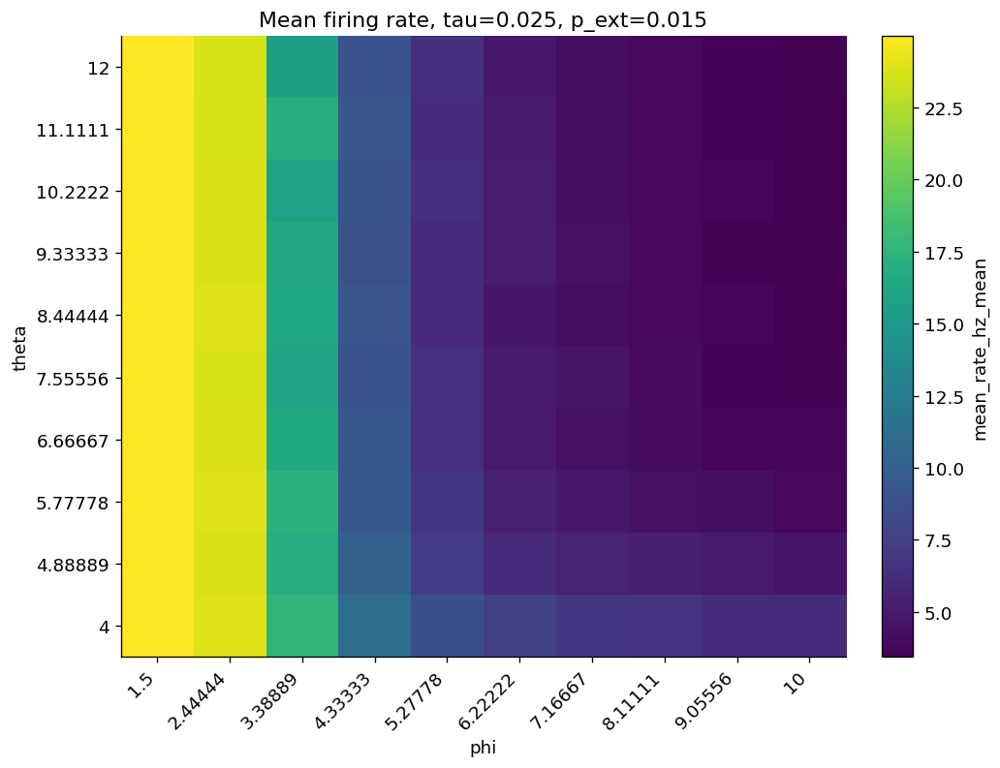

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_silent_frames_tau_0p025.png


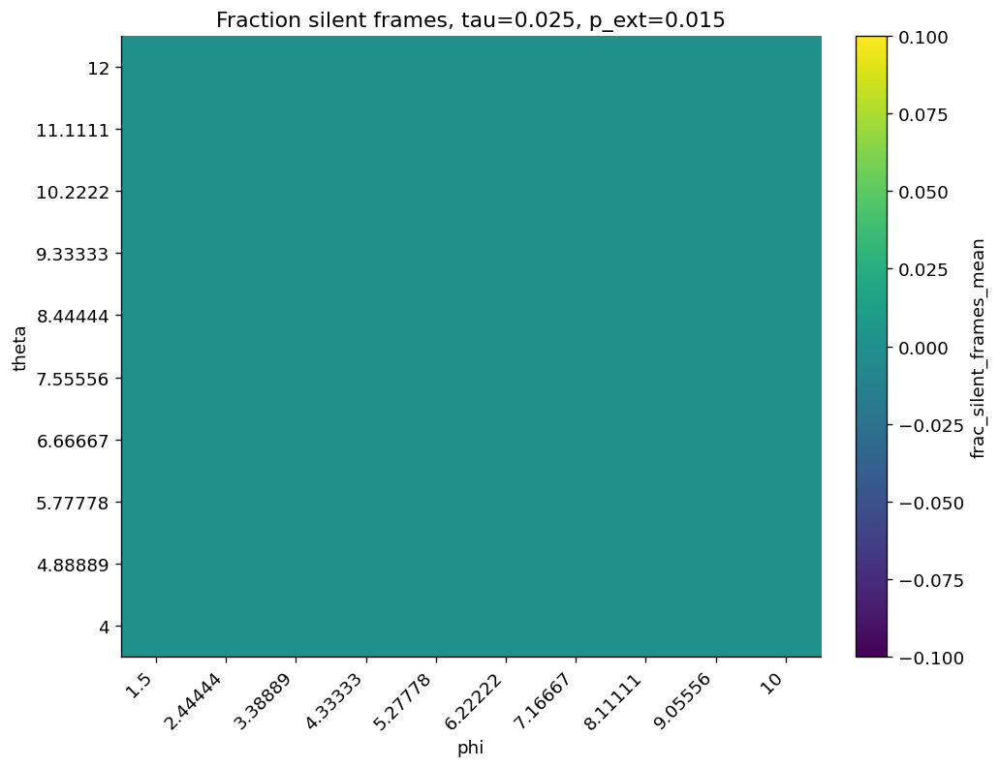

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_active_neurons_tau_0p025.png


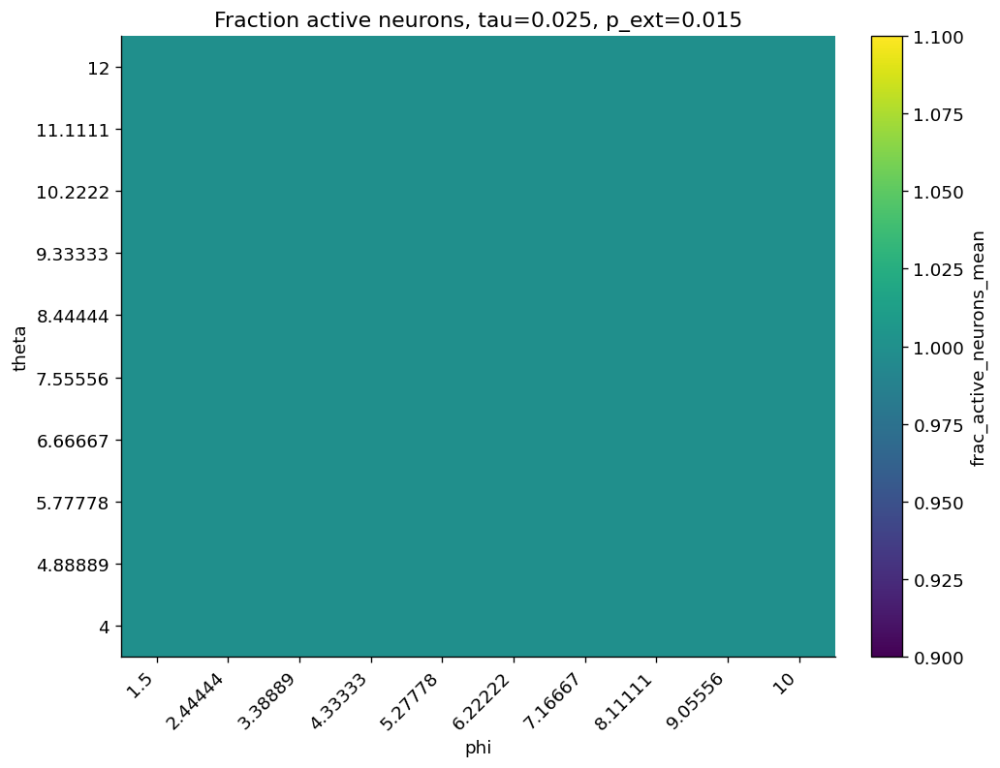

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_alpha_norm_tau_0p0375.png


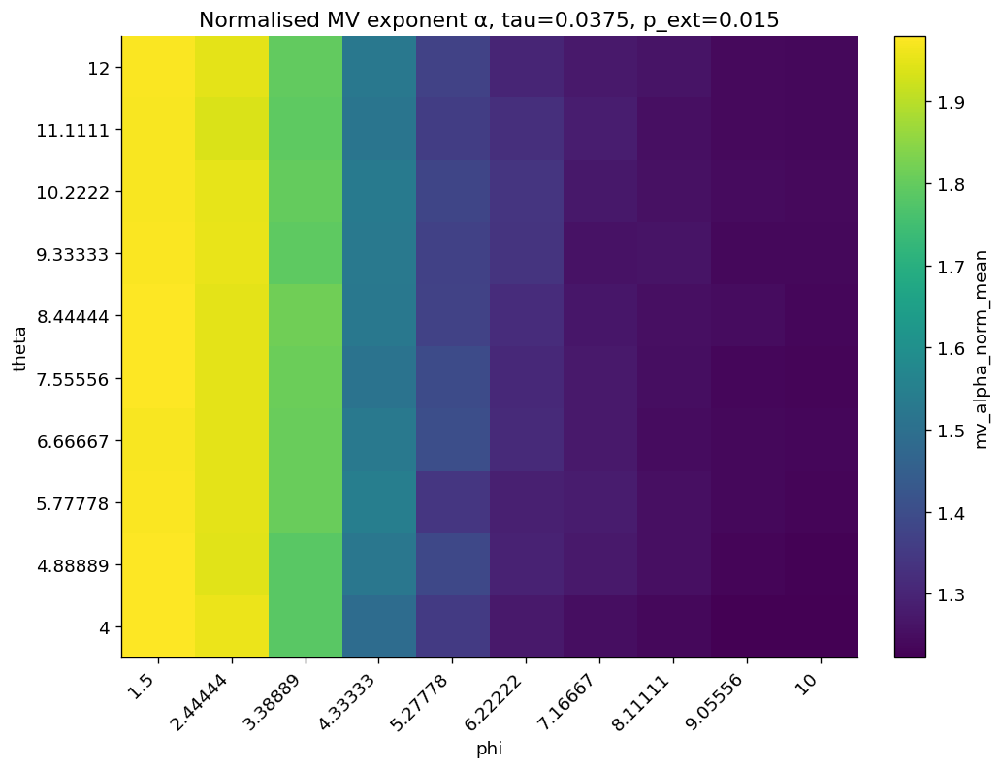

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_beta_norm_tau_0p0375.png


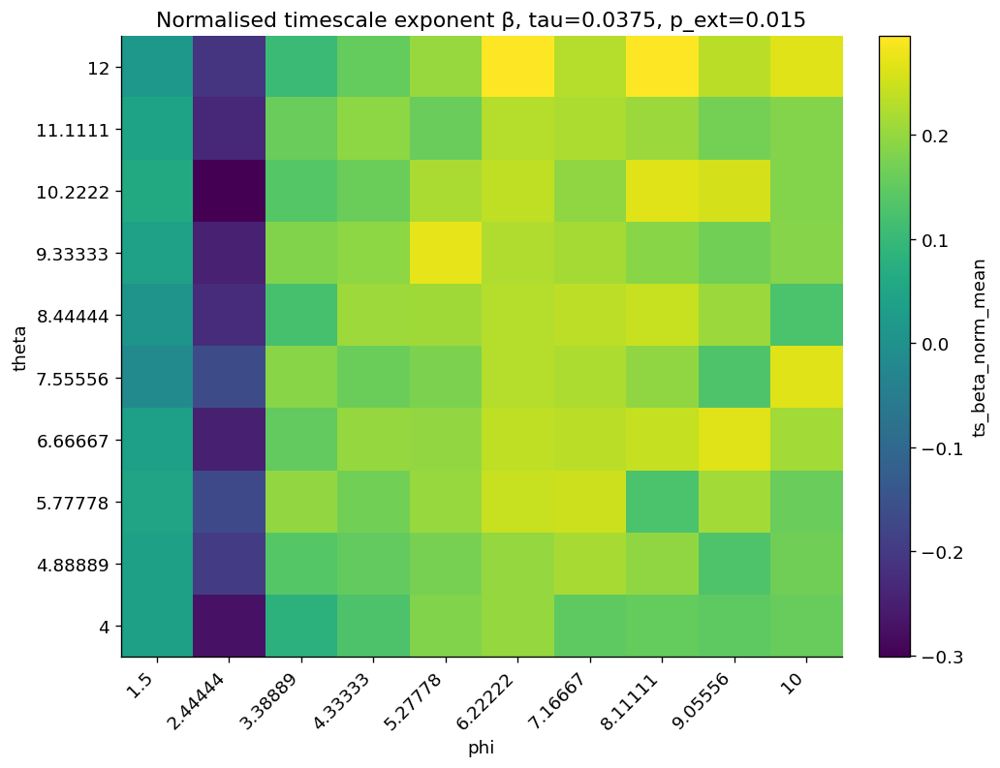

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_r2_norm_tau_0p0375.png


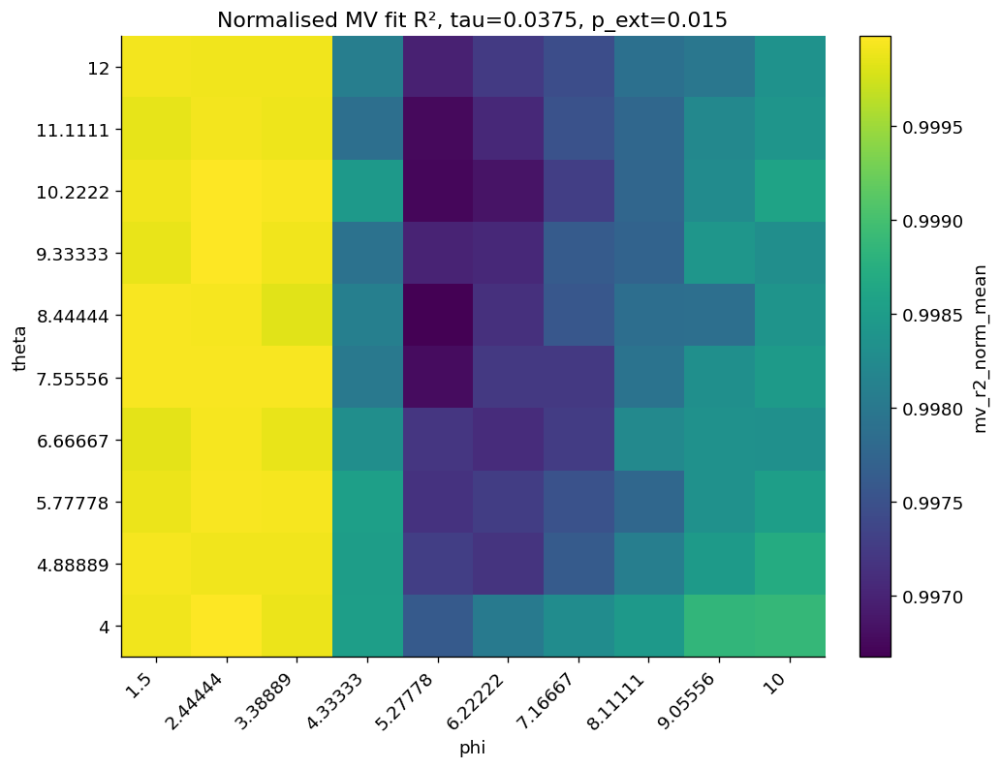

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_r2_norm_tau_0p0375.png


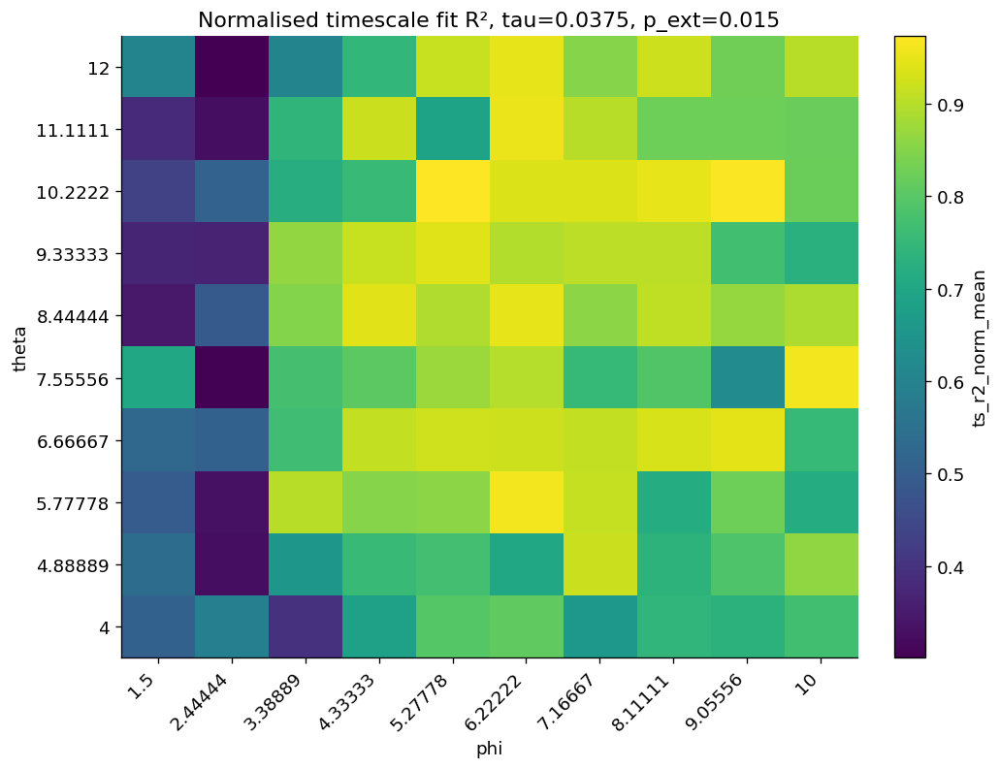

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_tau_0p0375.png


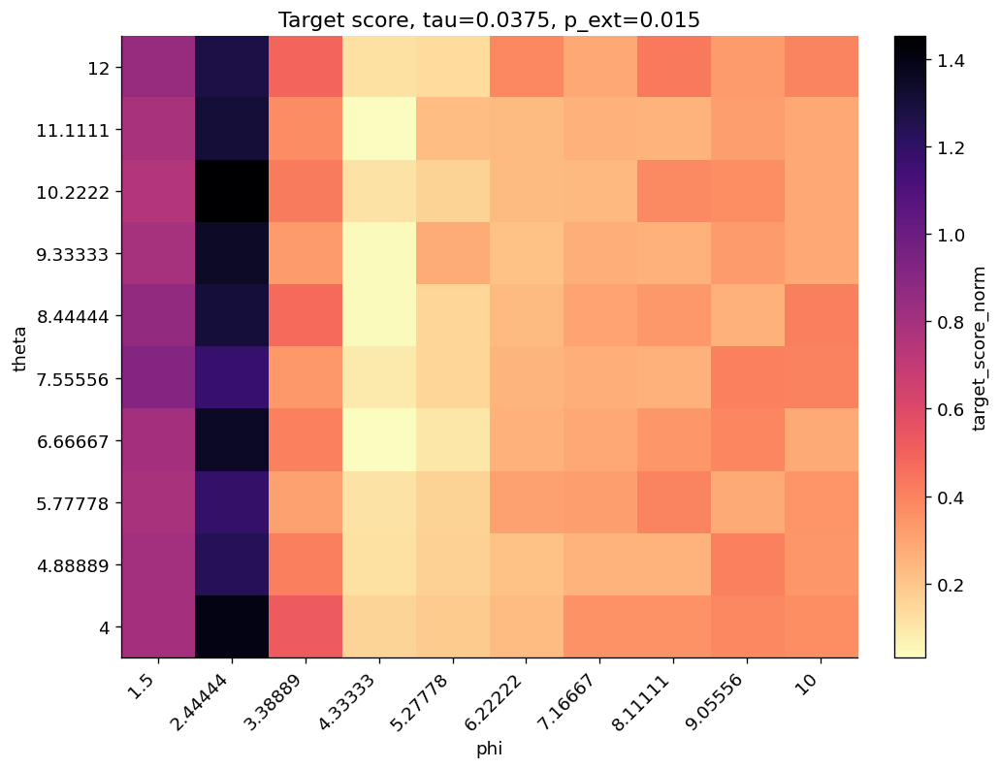

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_r2pen_tau_0p0375.png


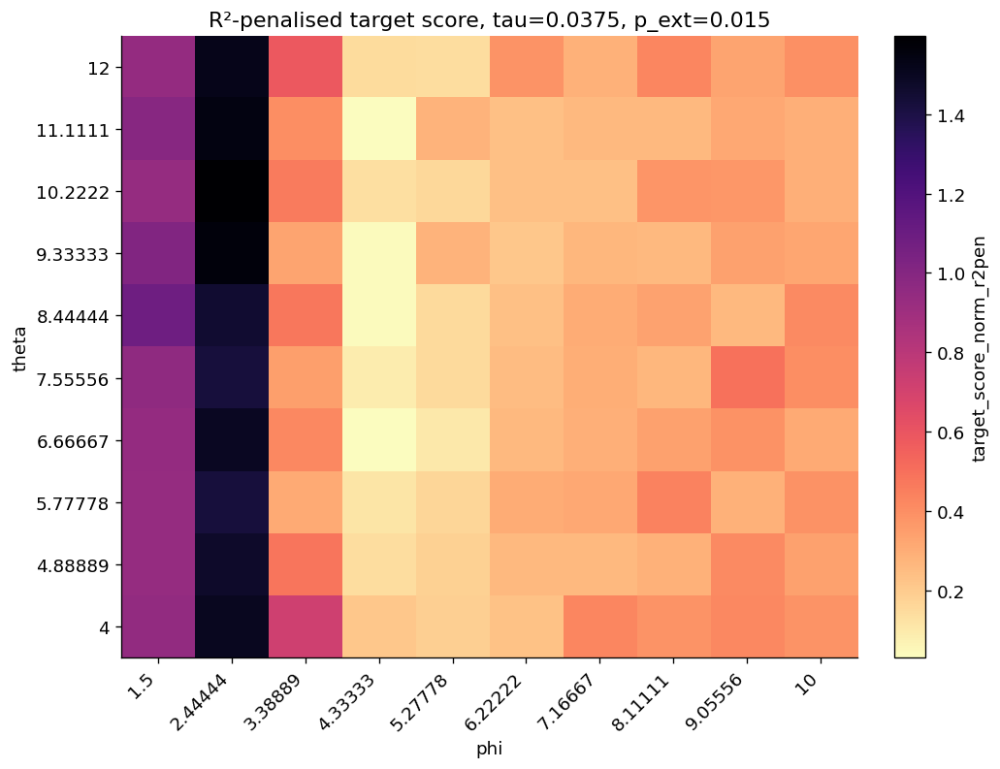

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mean_rate_tau_0p0375.png


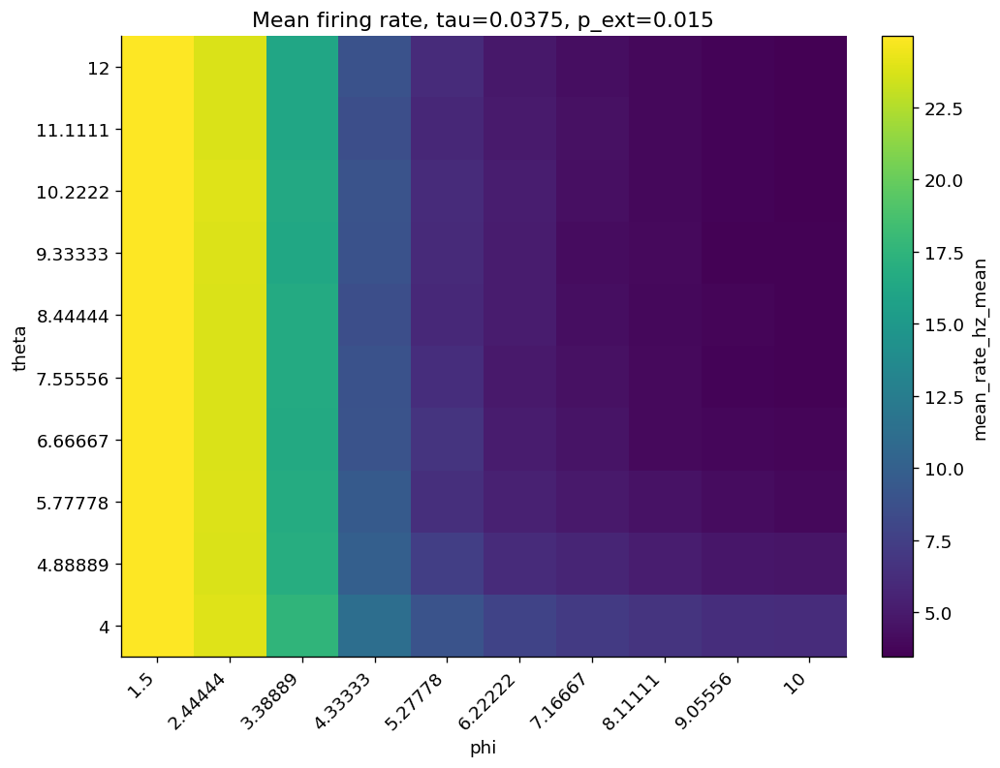

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_silent_frames_tau_0p0375.png


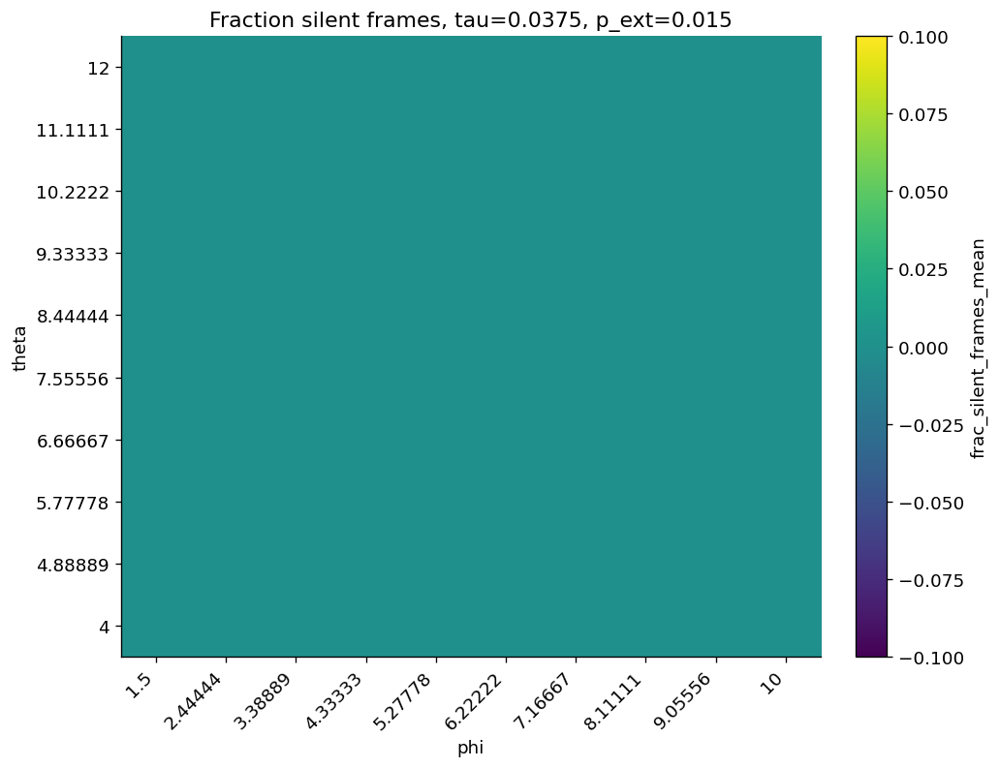

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_active_neurons_tau_0p0375.png


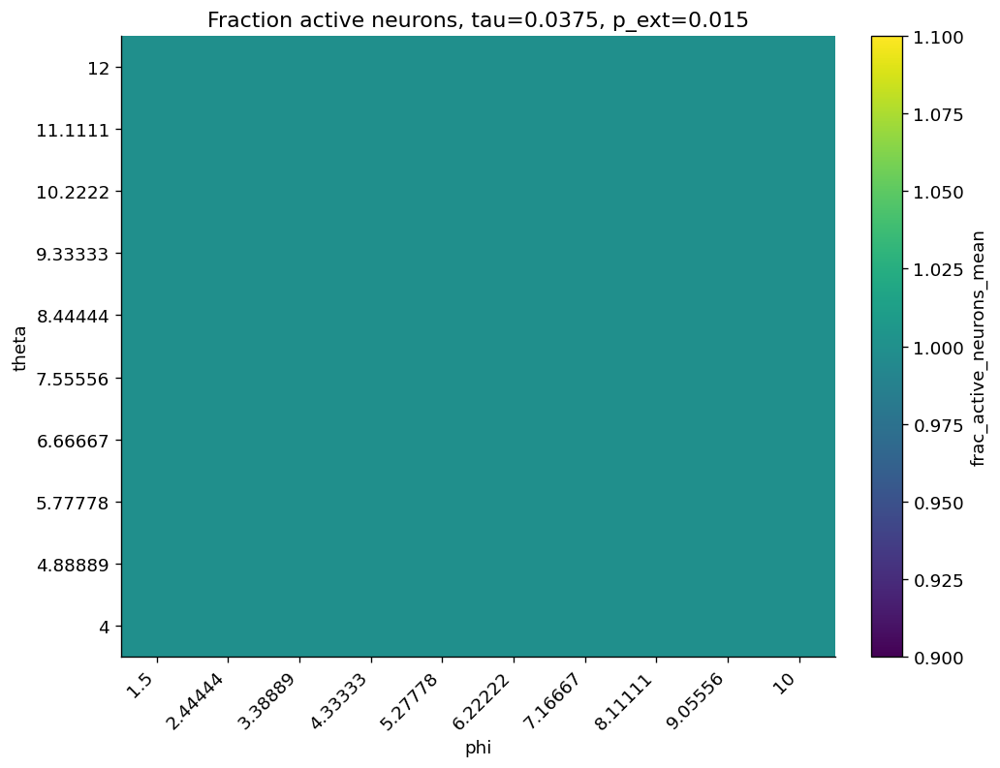

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_alpha_norm_tau_0p05.png


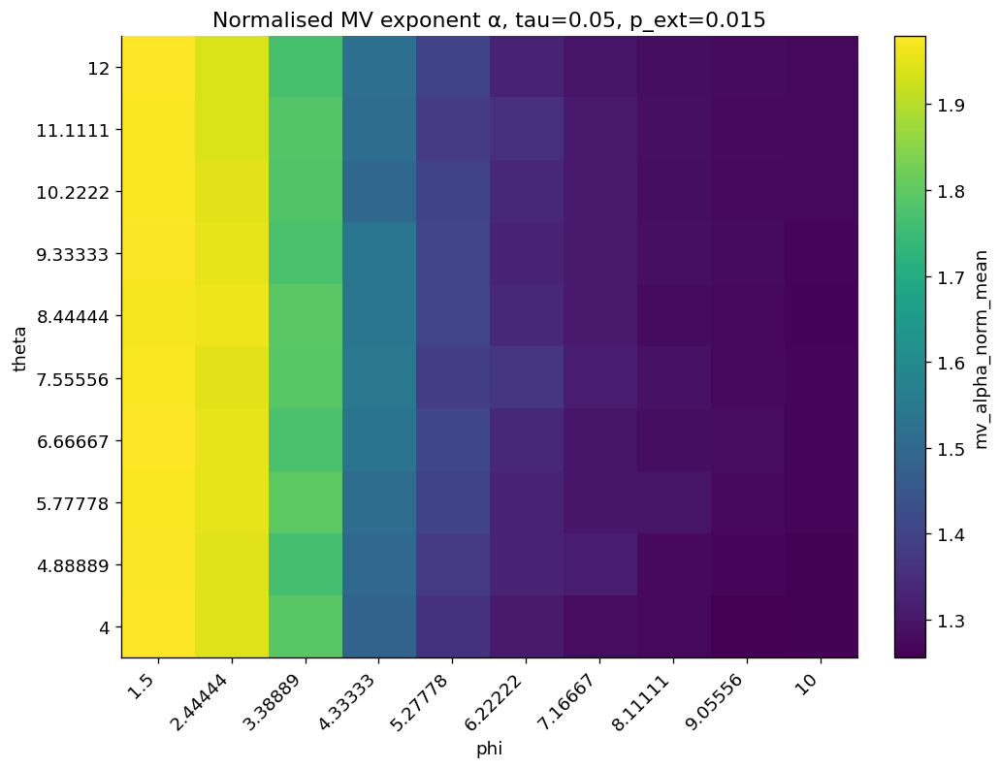

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_beta_norm_tau_0p05.png


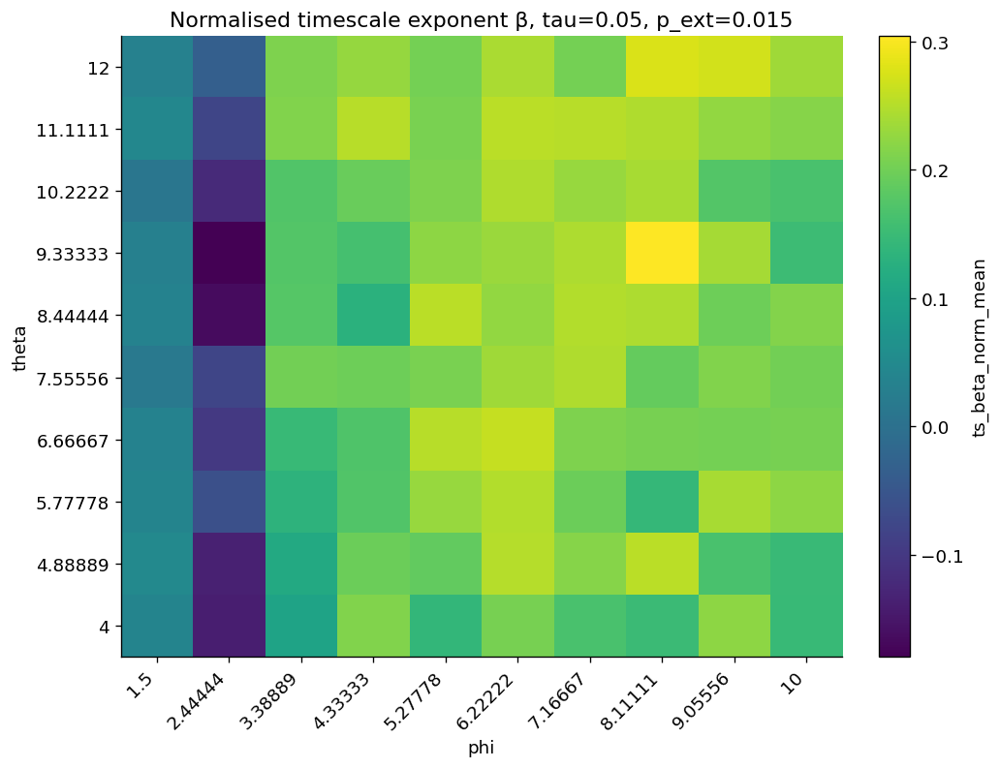

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mv_r2_norm_tau_0p05.png


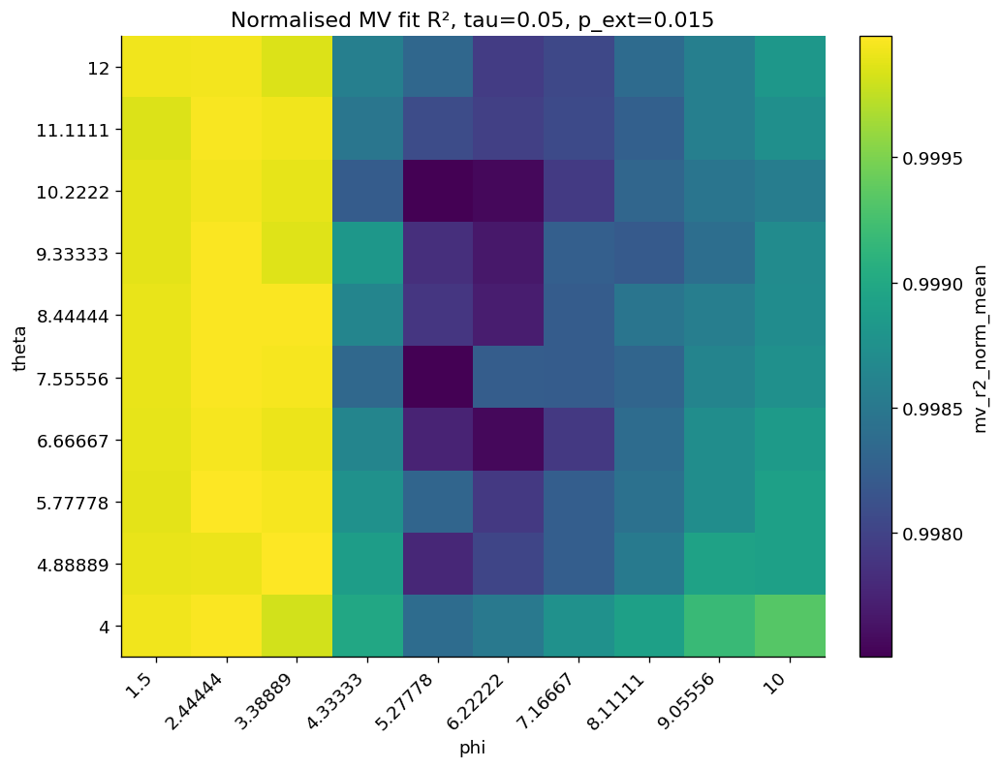

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_ts_r2_norm_tau_0p05.png


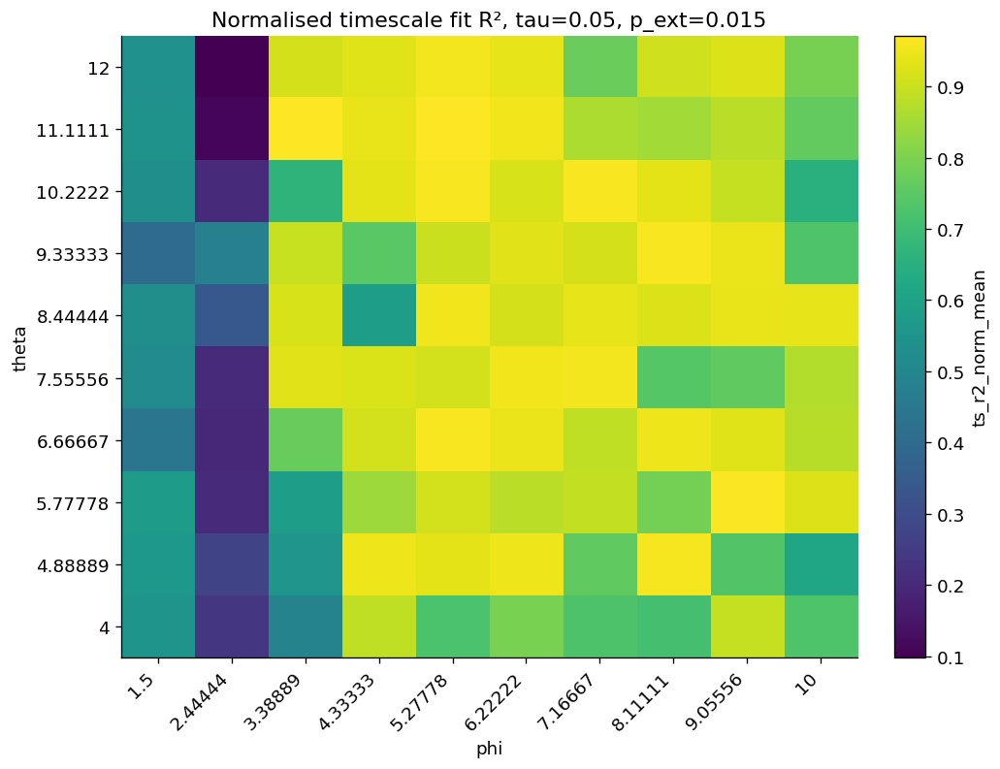

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_tau_0p05.png


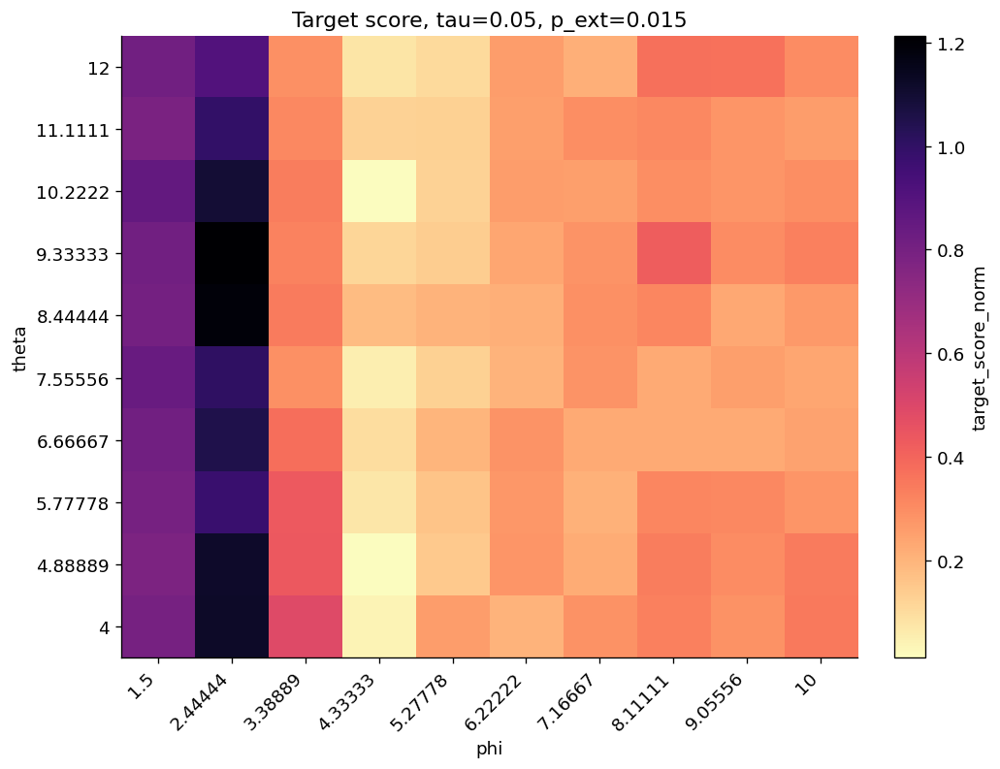

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_target_score_norm_r2pen_tau_0p05.png


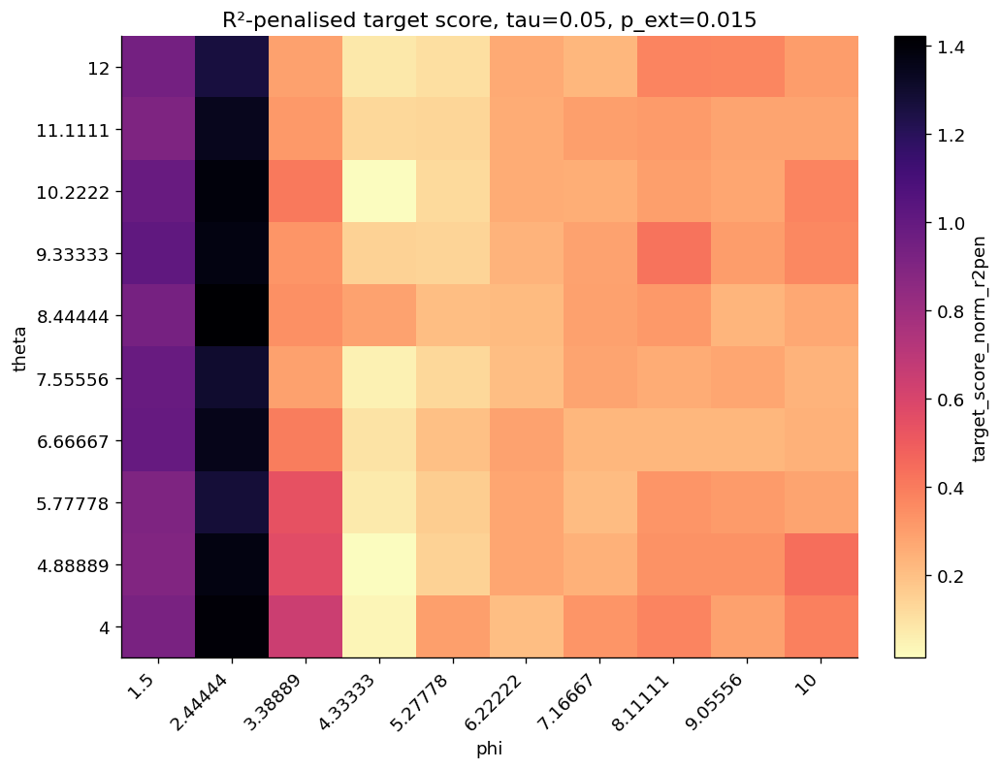

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_mean_rate_tau_0p05.png


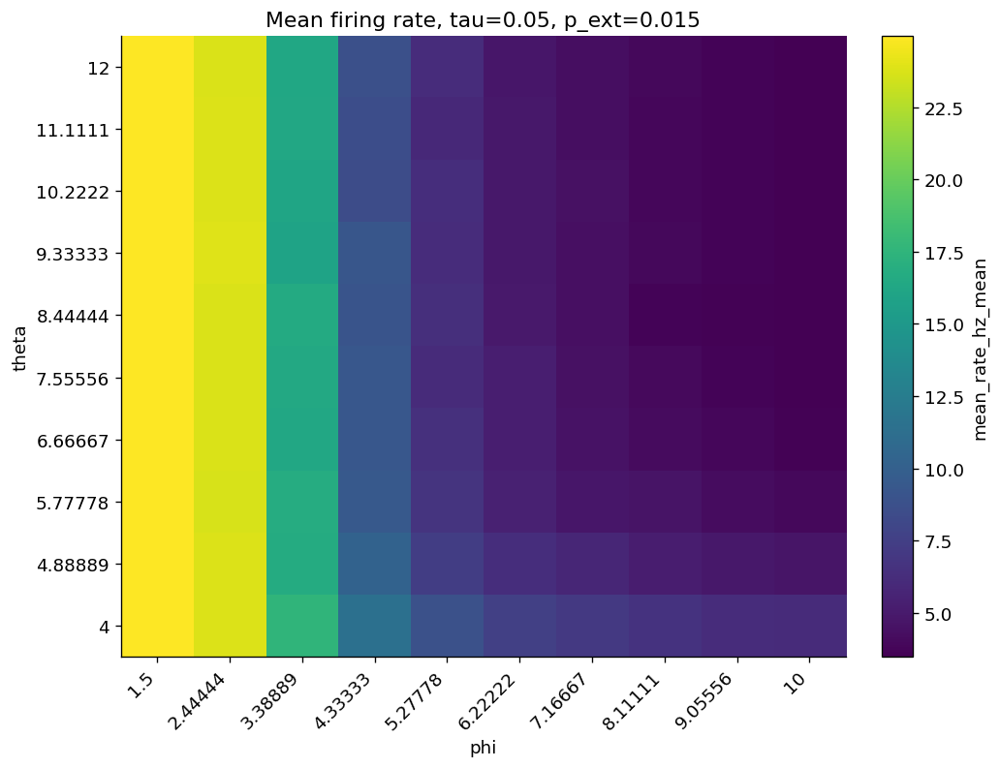

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_silent_frames_tau_0p05.png


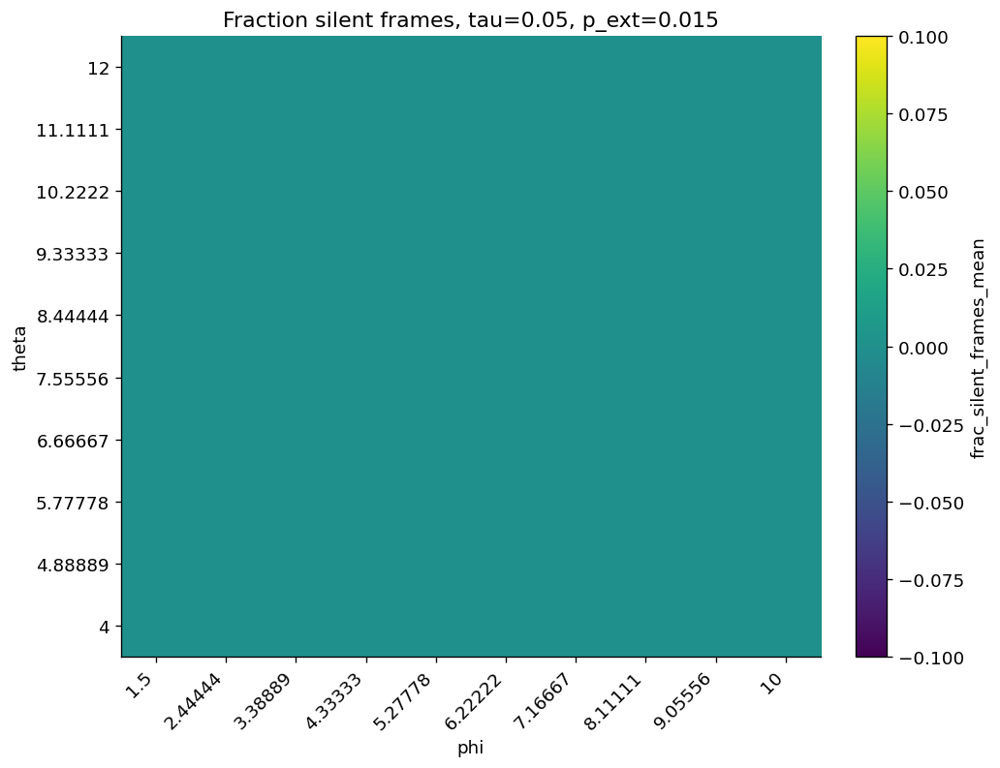

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/heatmap_frac_active_neurons_tau_0p05.png


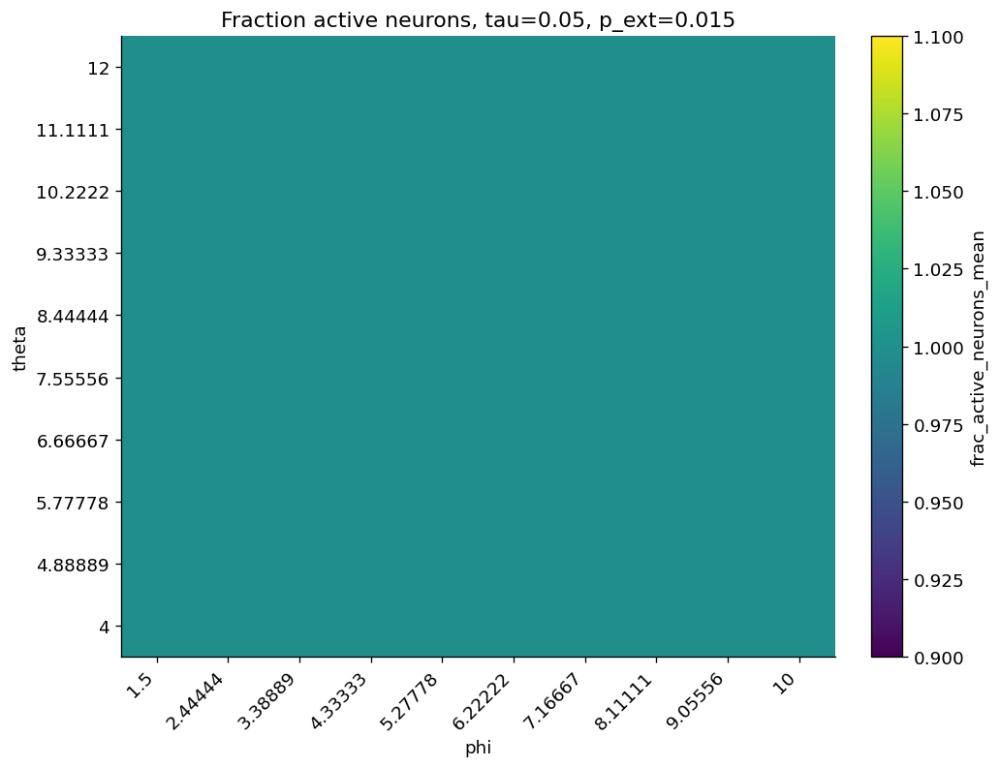

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best_score_alpha_beta_vs_smooth_tau.png


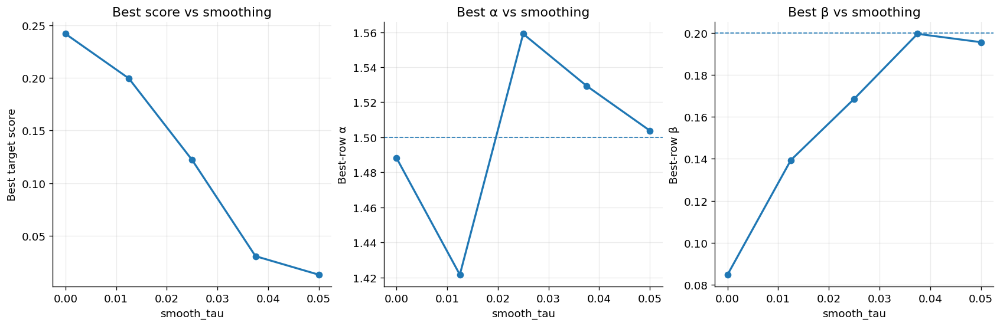

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/alpha_beta_scatter_all_smooth_taus.png


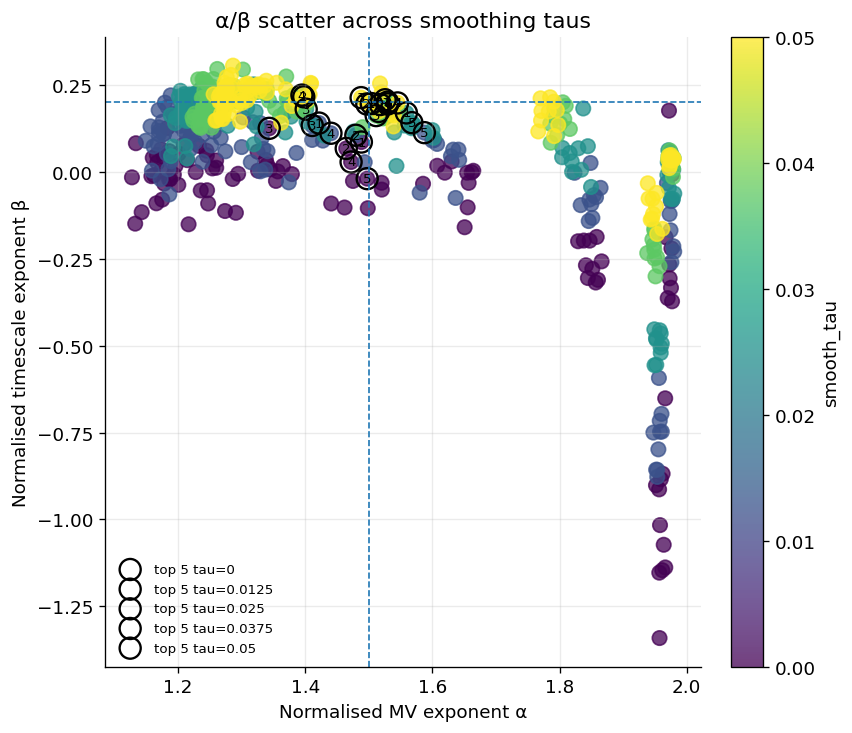

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/exponents_vs_phi_tau_0p0.png


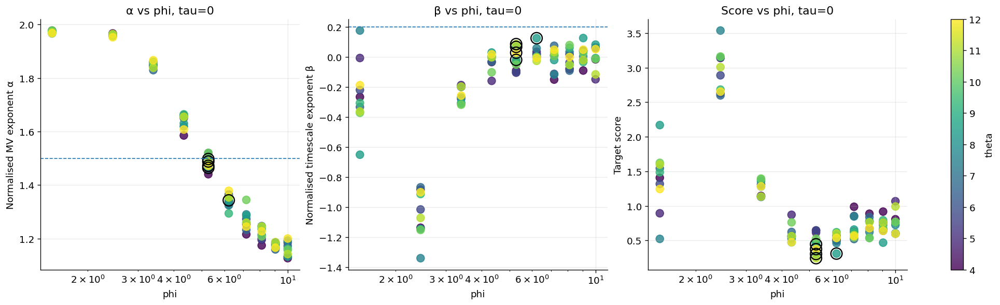

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/exponents_vs_phi_tau_0p0125.png


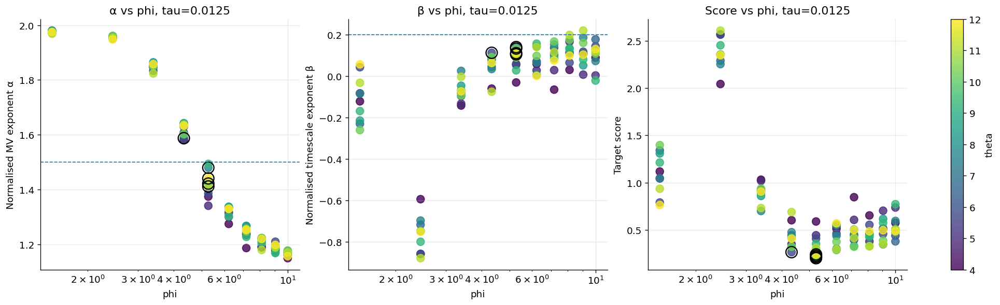

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/exponents_vs_phi_tau_0p025.png


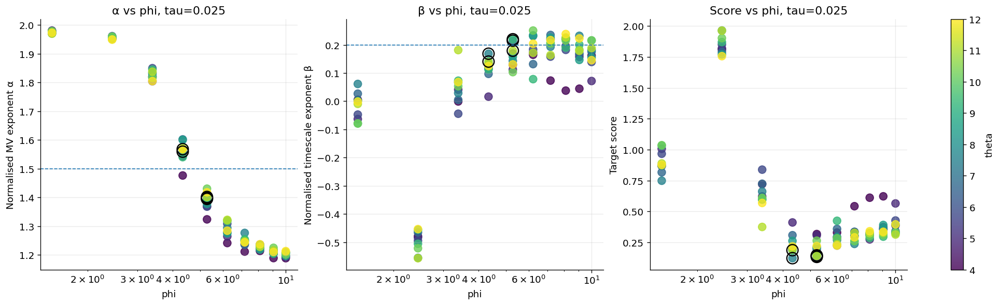

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/exponents_vs_phi_tau_0p0375.png


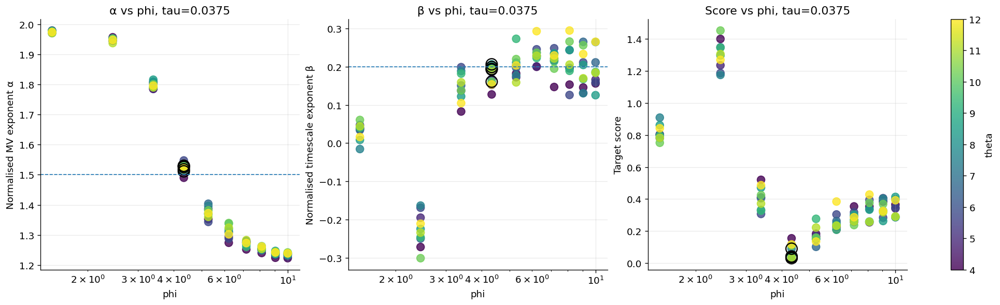

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/exponents_vs_phi_tau_0p05.png


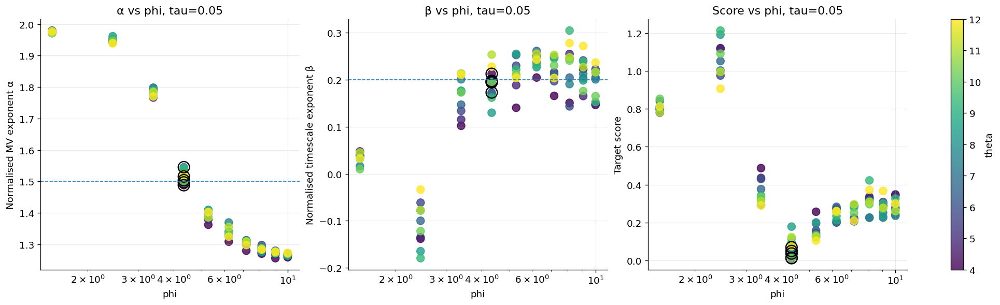

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best10_icg_curves_tau_0p0.png


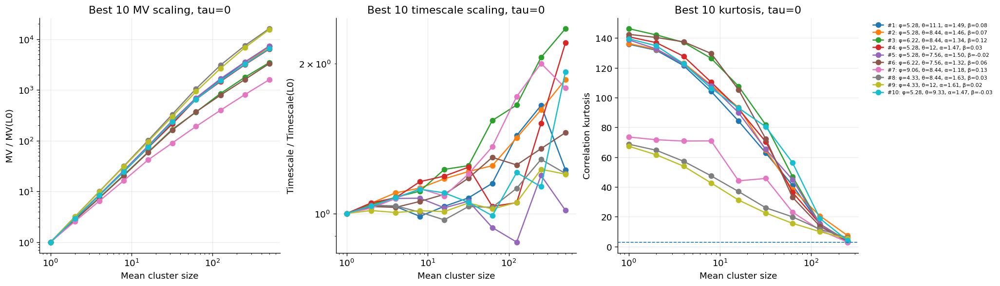

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best10_icg_curves_tau_0p0125.png


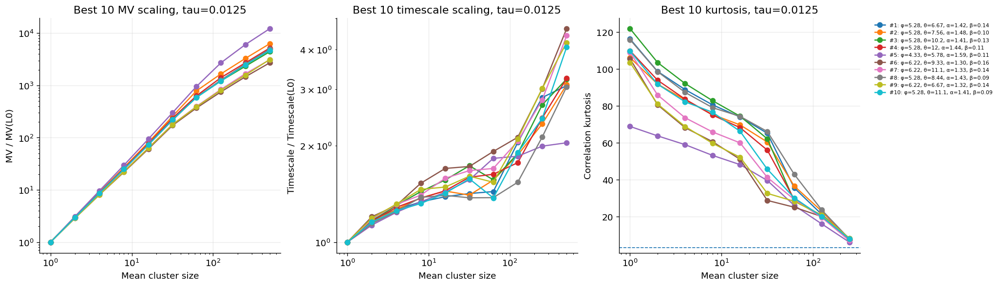

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best10_icg_curves_tau_0p025.png


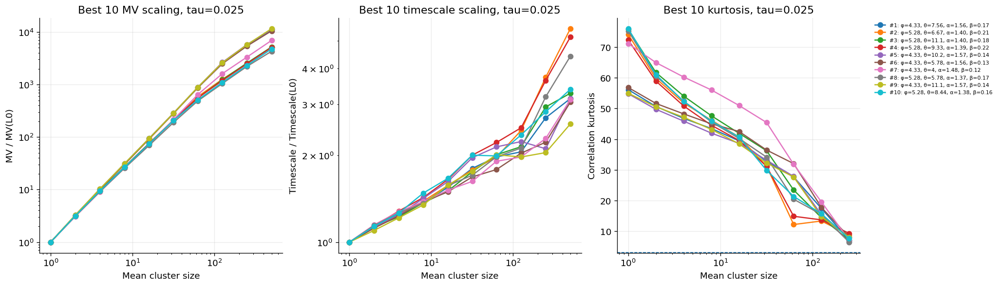

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best10_icg_curves_tau_0p0375.png


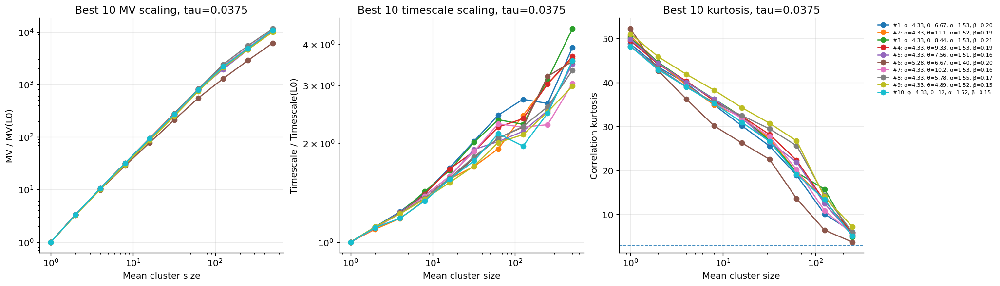

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best10_icg_curves_tau_0p05.png


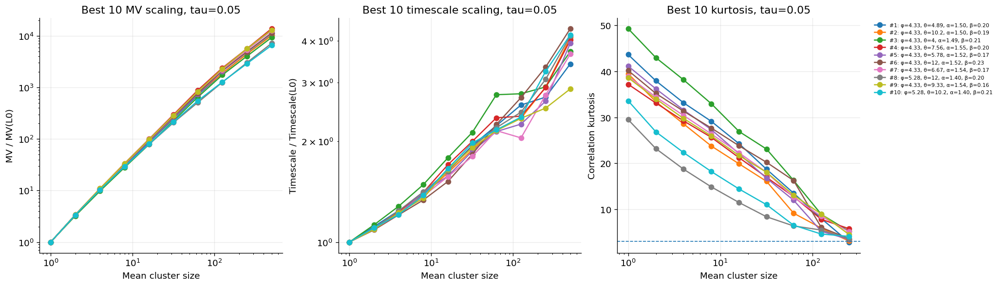

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best1_raw_vs_norm_curves_tau_0p0.png


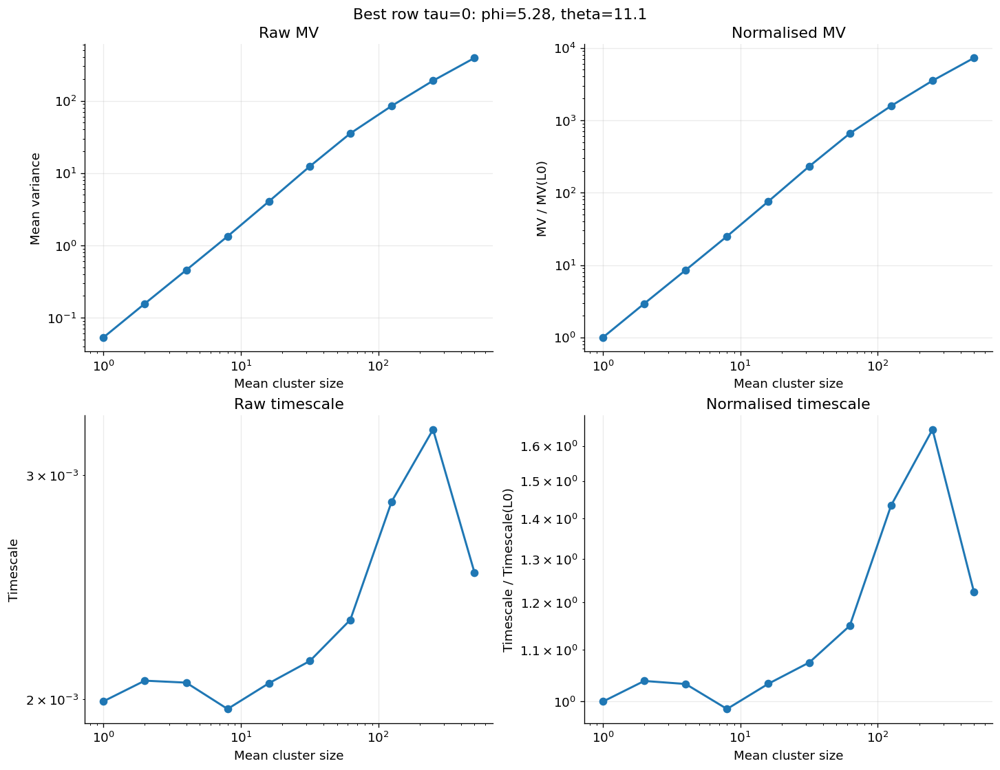

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best1_raw_vs_norm_curves_tau_0p0125.png


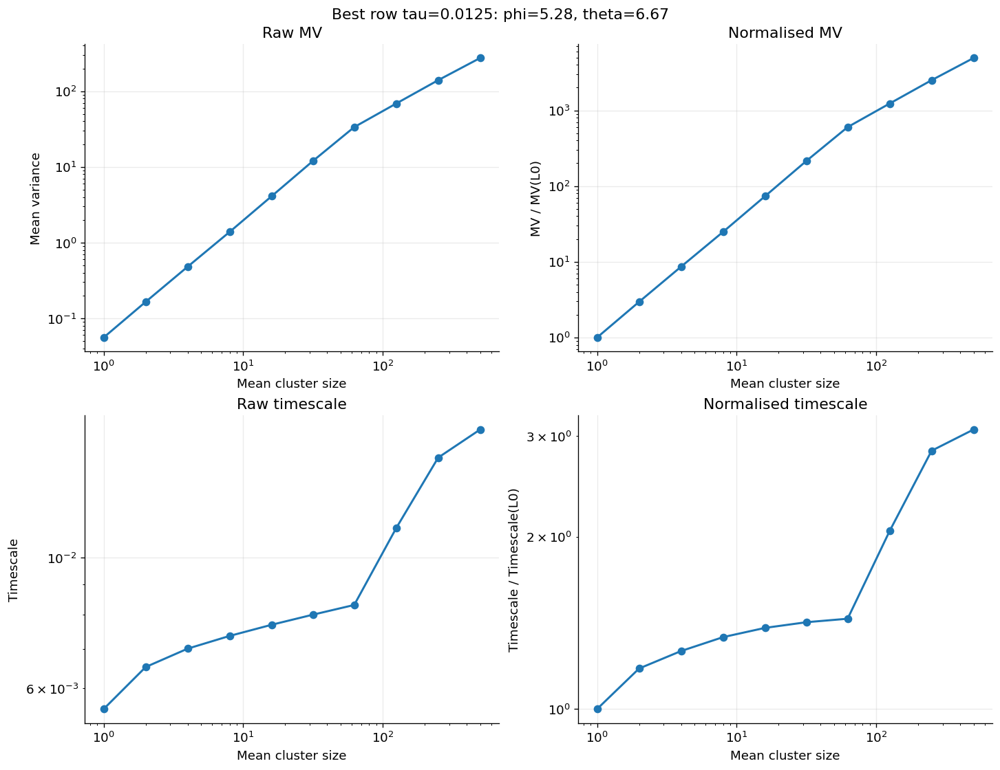

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best1_raw_vs_norm_curves_tau_0p025.png


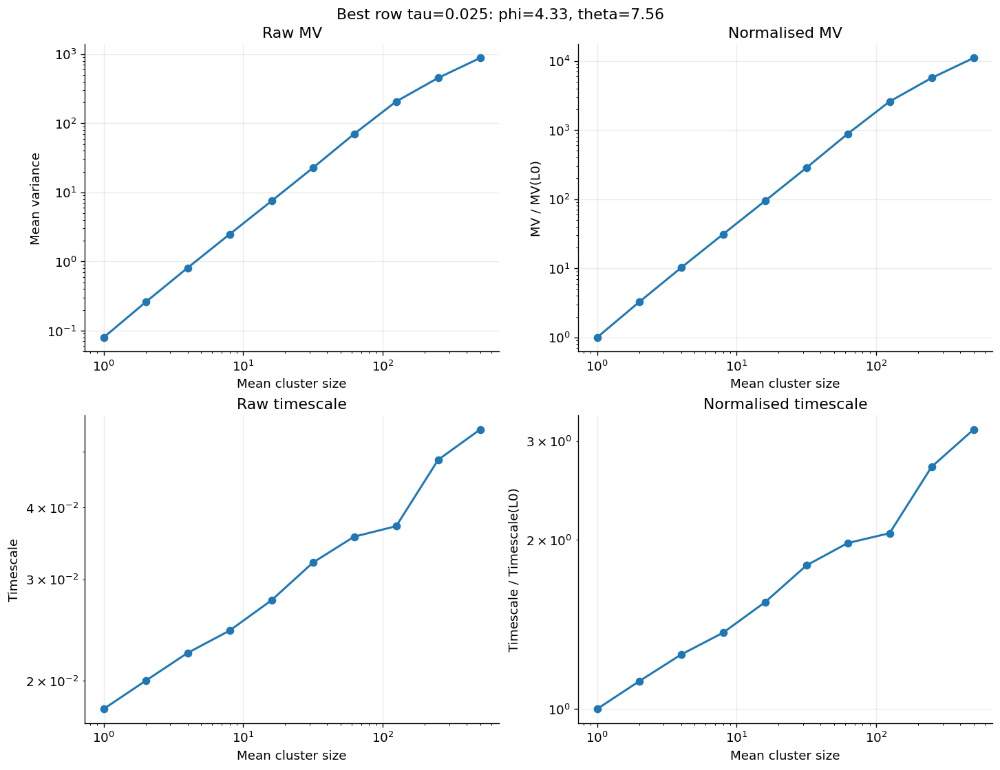

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best1_raw_vs_norm_curves_tau_0p0375.png


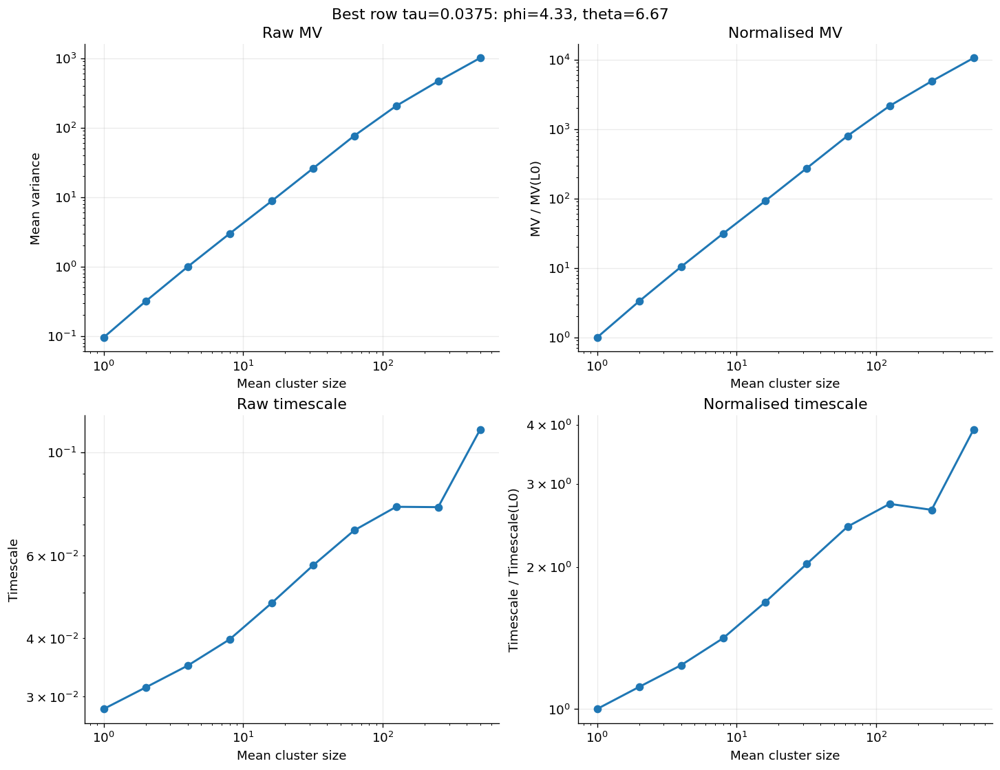

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/best1_raw_vs_norm_curves_tau_0p05.png


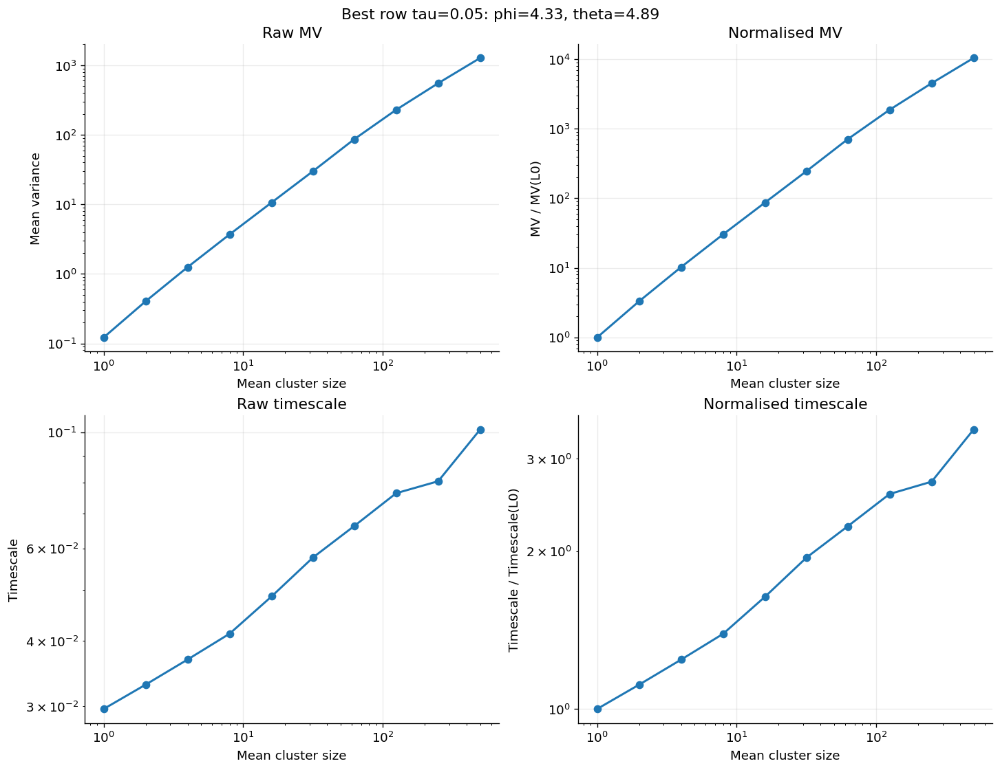

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/all_normalised_scaling_curves_tau_0p0.png


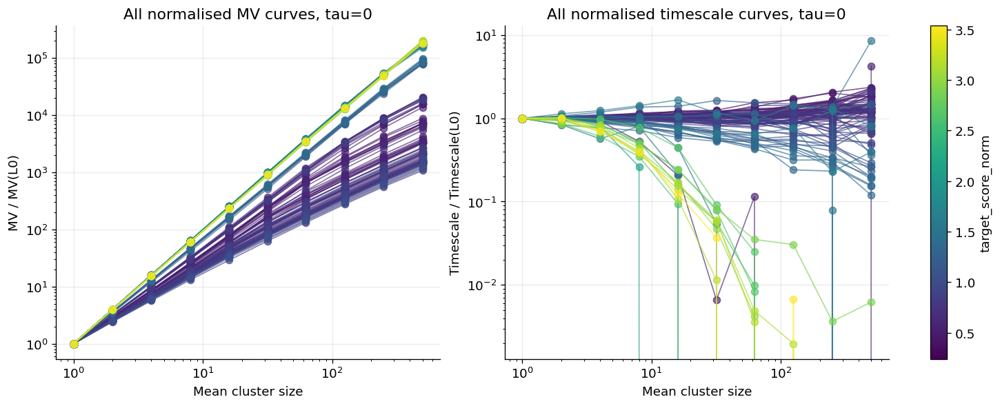

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/all_normalised_scaling_curves_tau_0p0125.png


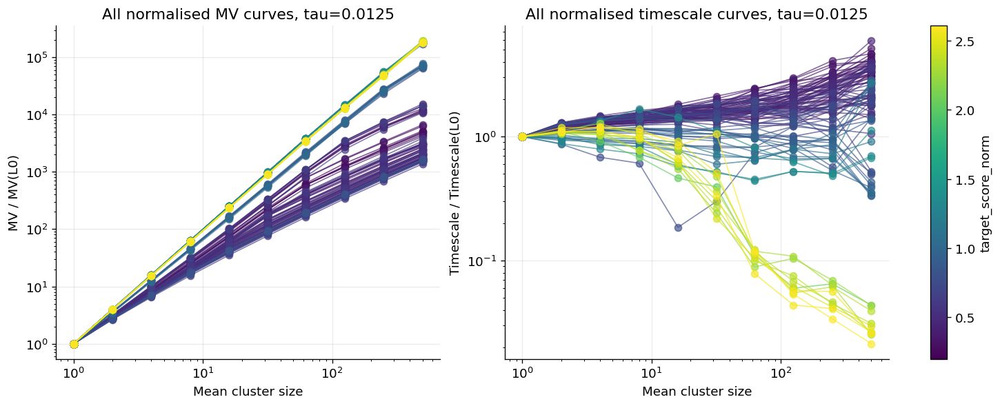

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/all_normalised_scaling_curves_tau_0p025.png


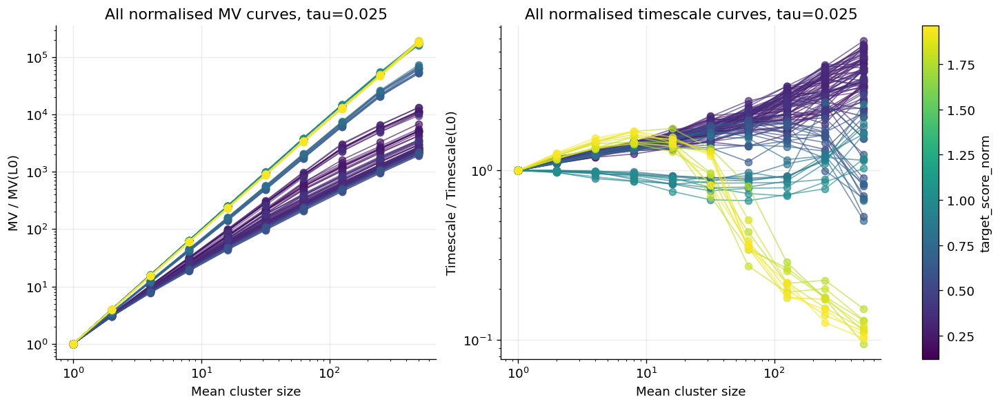

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/all_normalised_scaling_curves_tau_0p0375.png


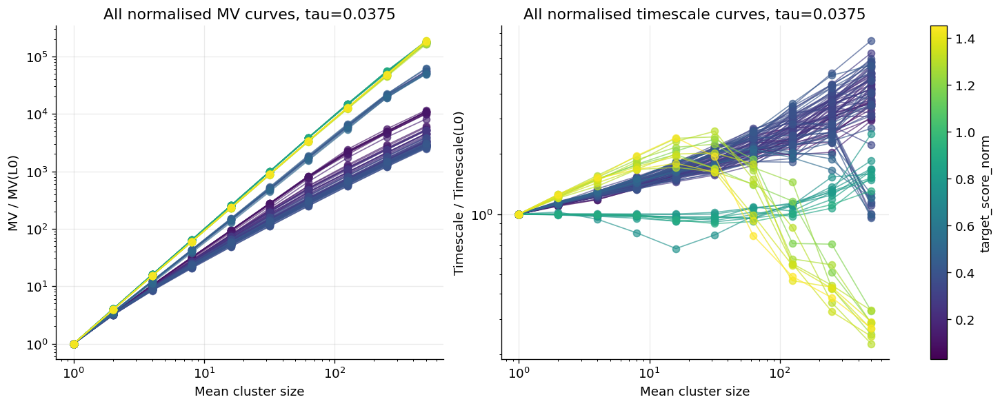

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/all_normalised_scaling_curves_tau_0p05.png


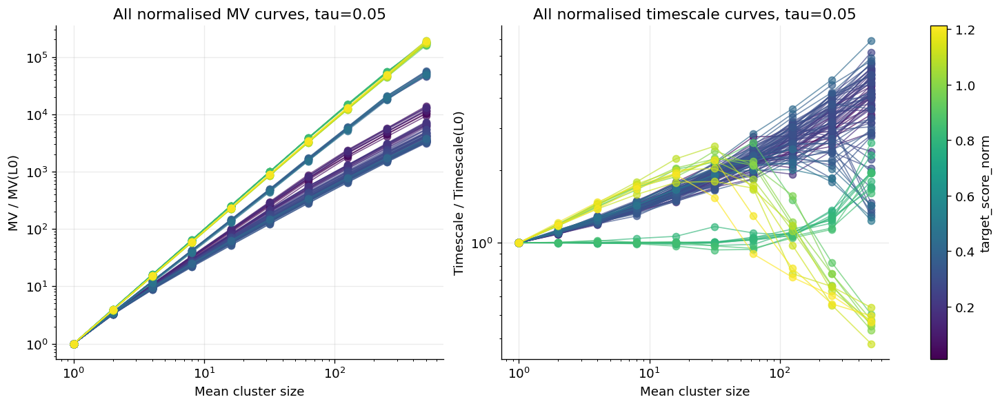

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_mv_scaling_tau_0p0.png


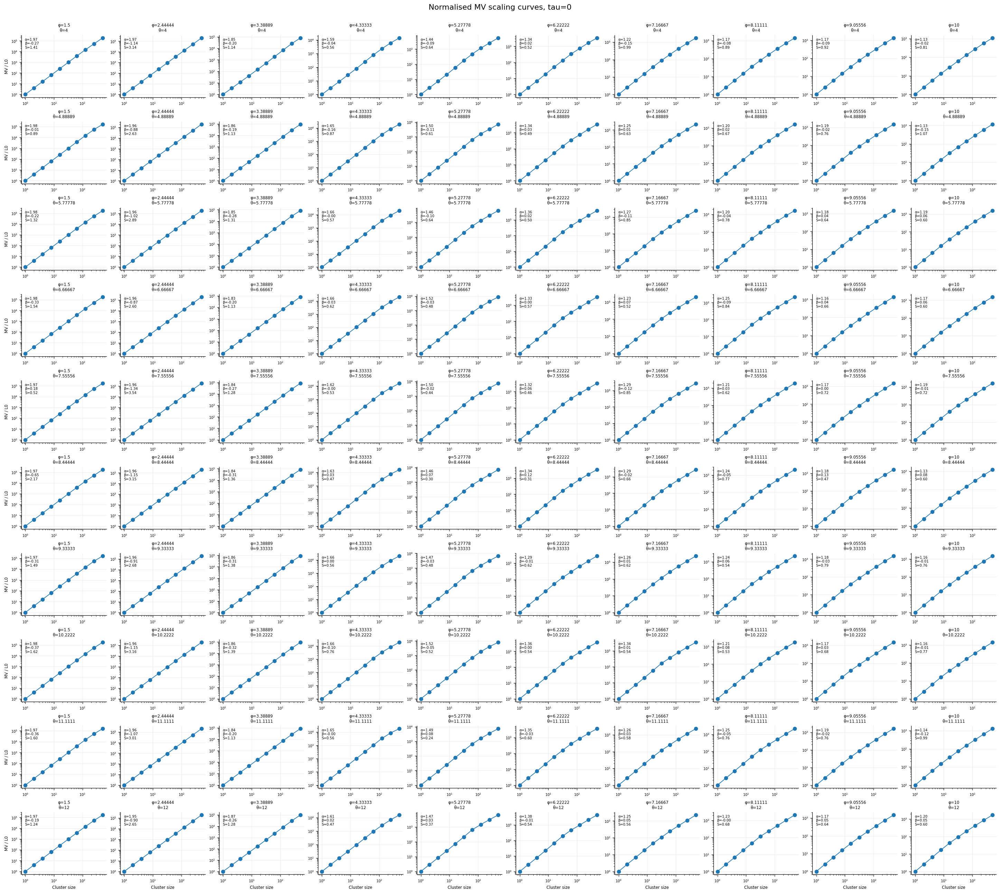

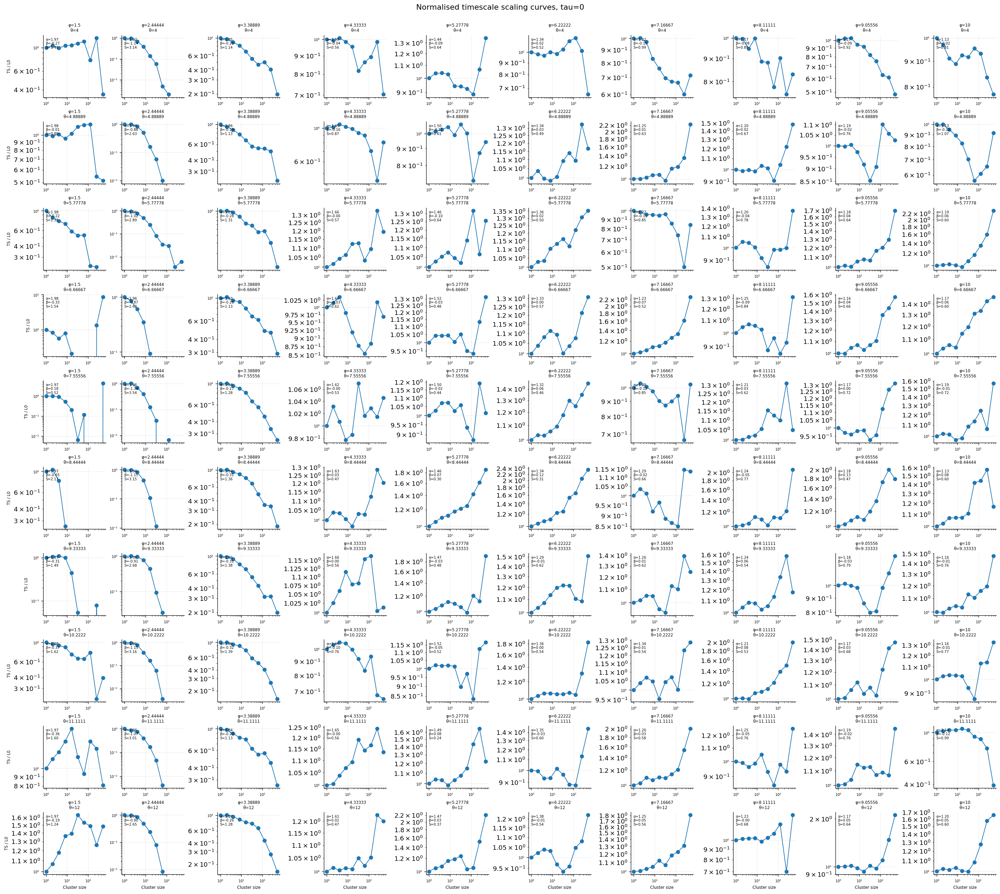

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_ts_scaling_tau_0p0.png
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_mv_scaling_tau_0p0125.png


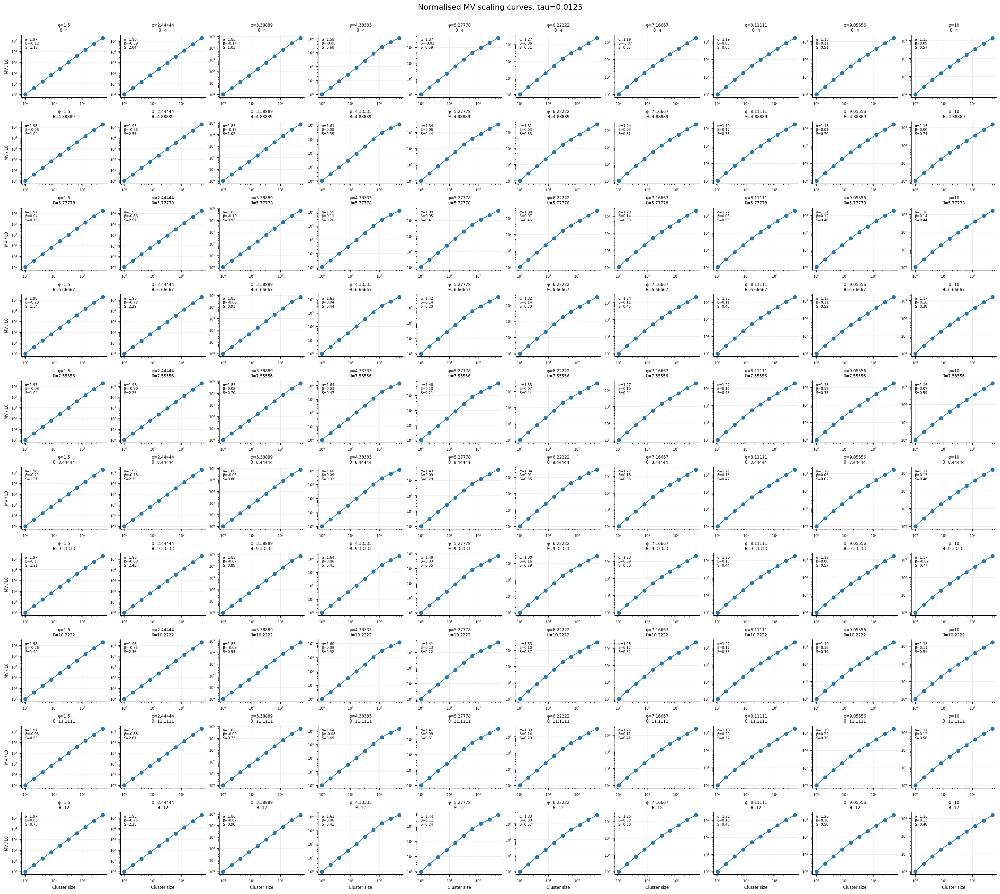

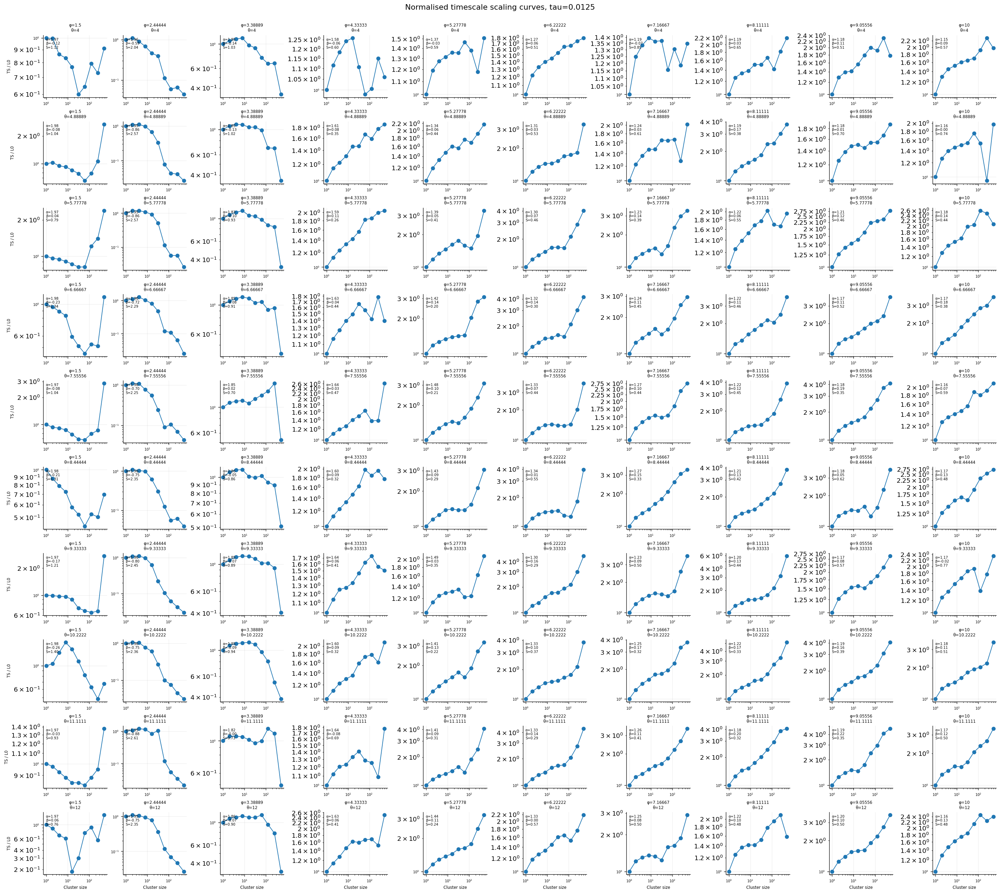

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_ts_scaling_tau_0p0125.png
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_mv_scaling_tau_0p025.png


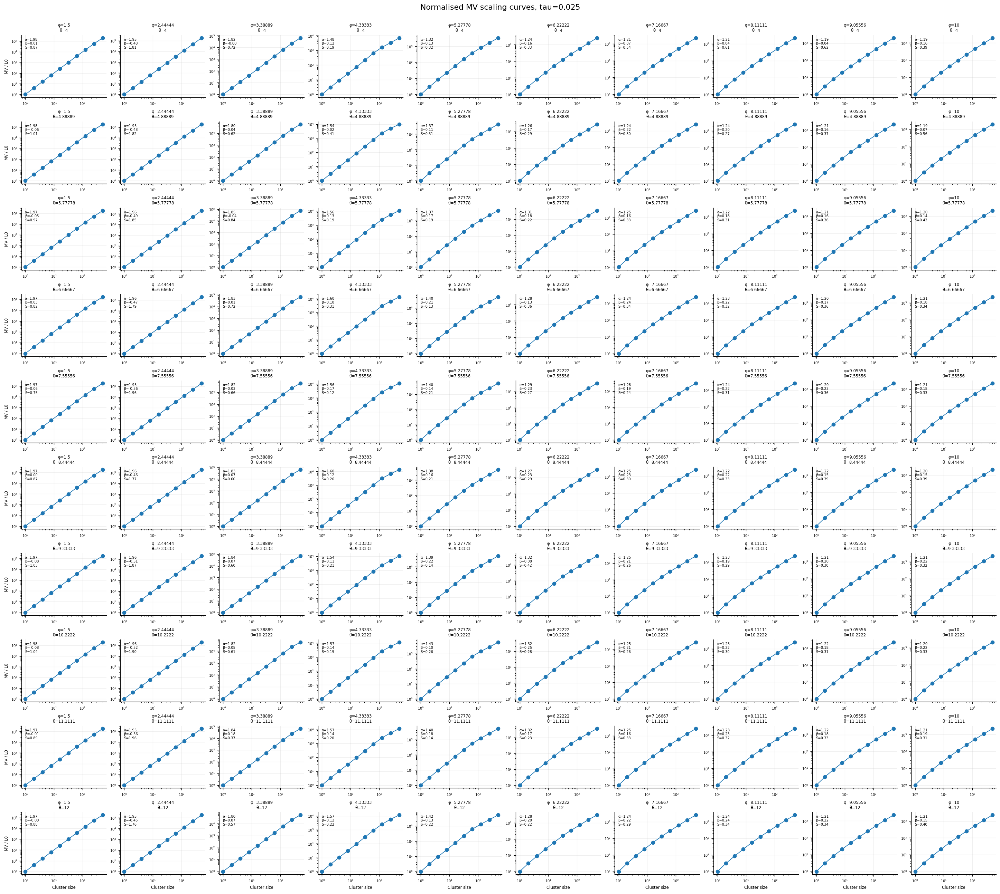

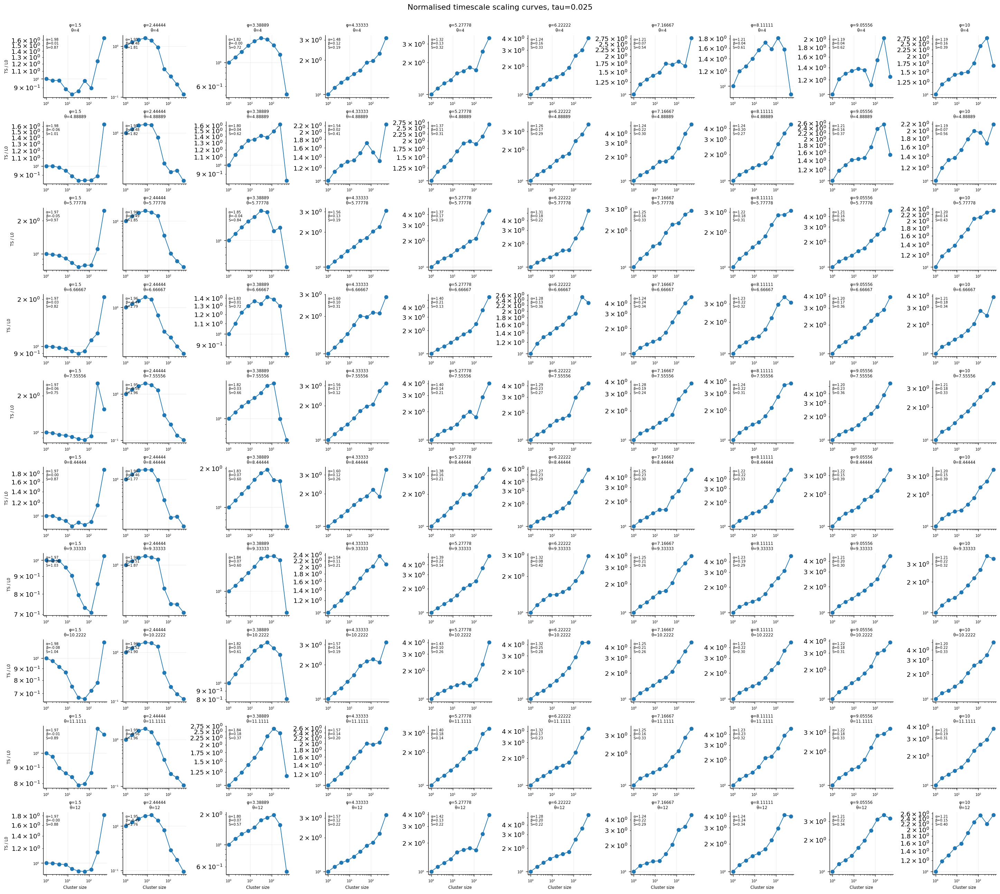

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_ts_scaling_tau_0p025.png
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_mv_scaling_tau_0p0375.png


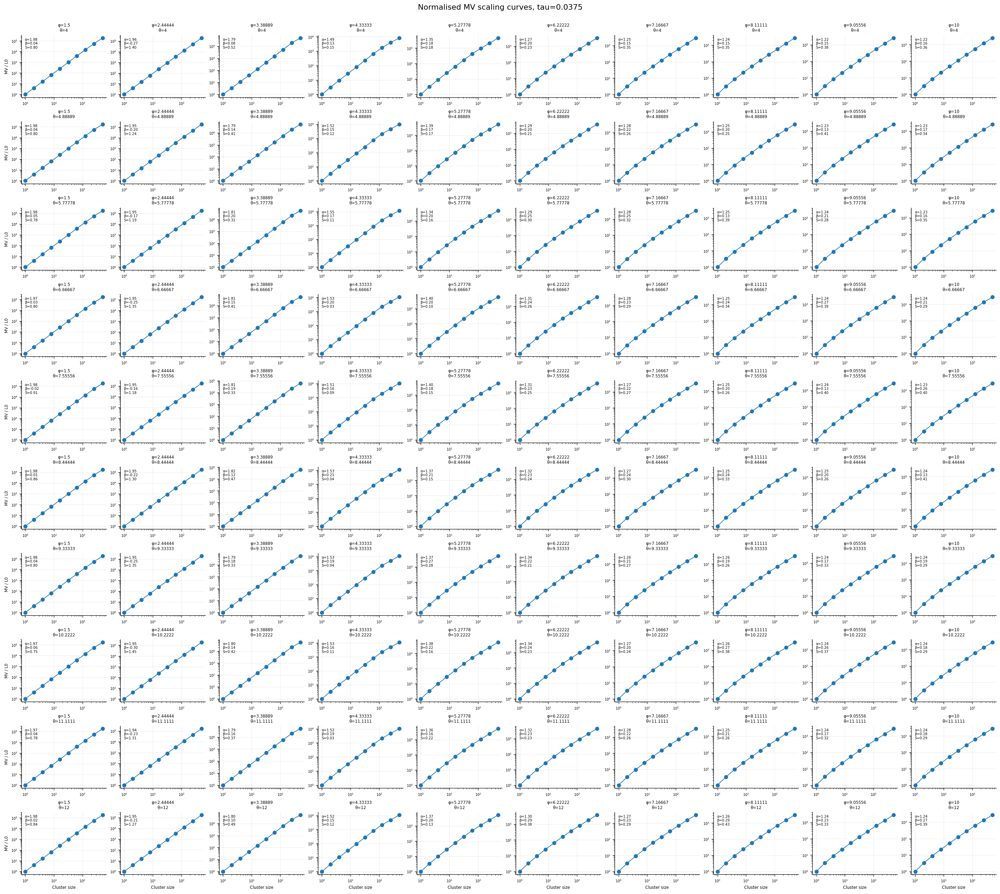

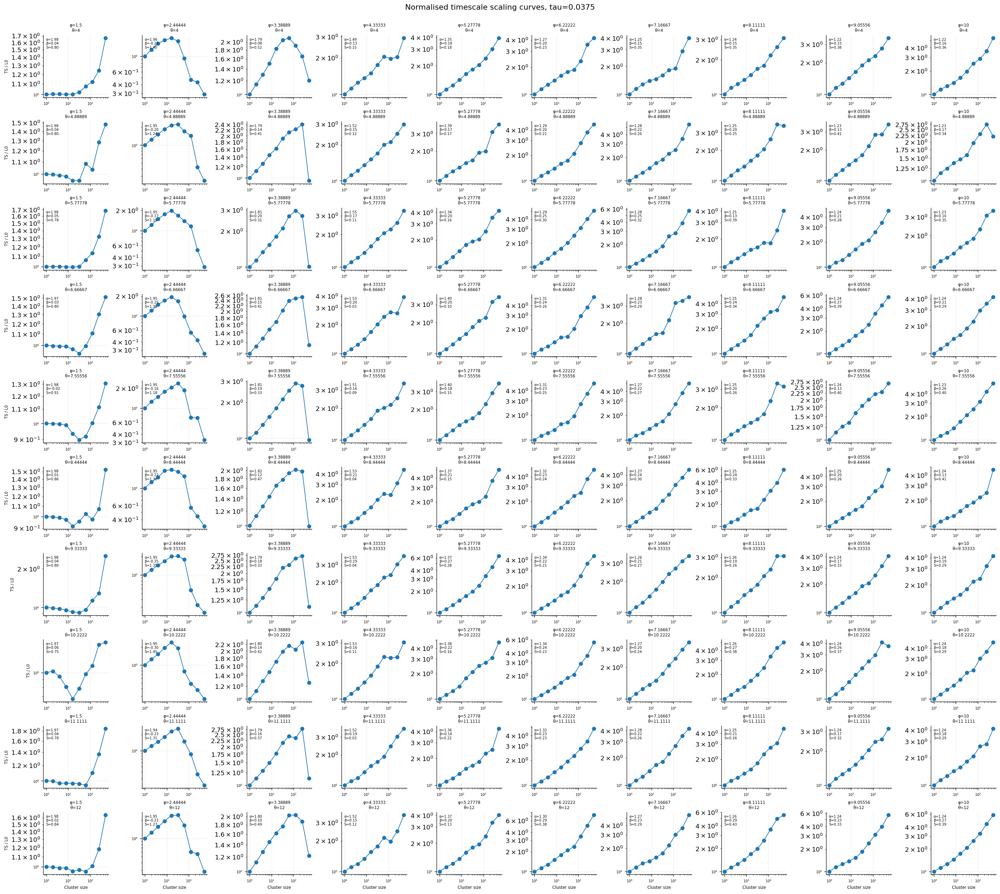

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_ts_scaling_tau_0p0375.png
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_mv_scaling_tau_0p05.png


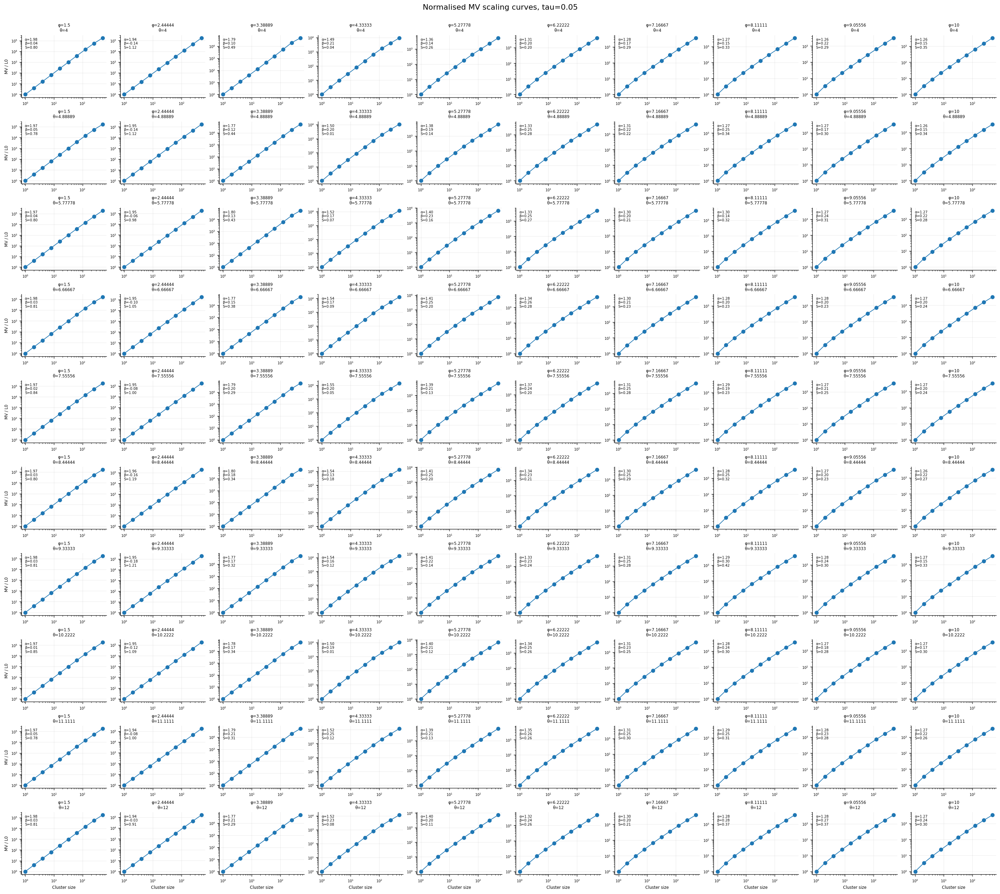

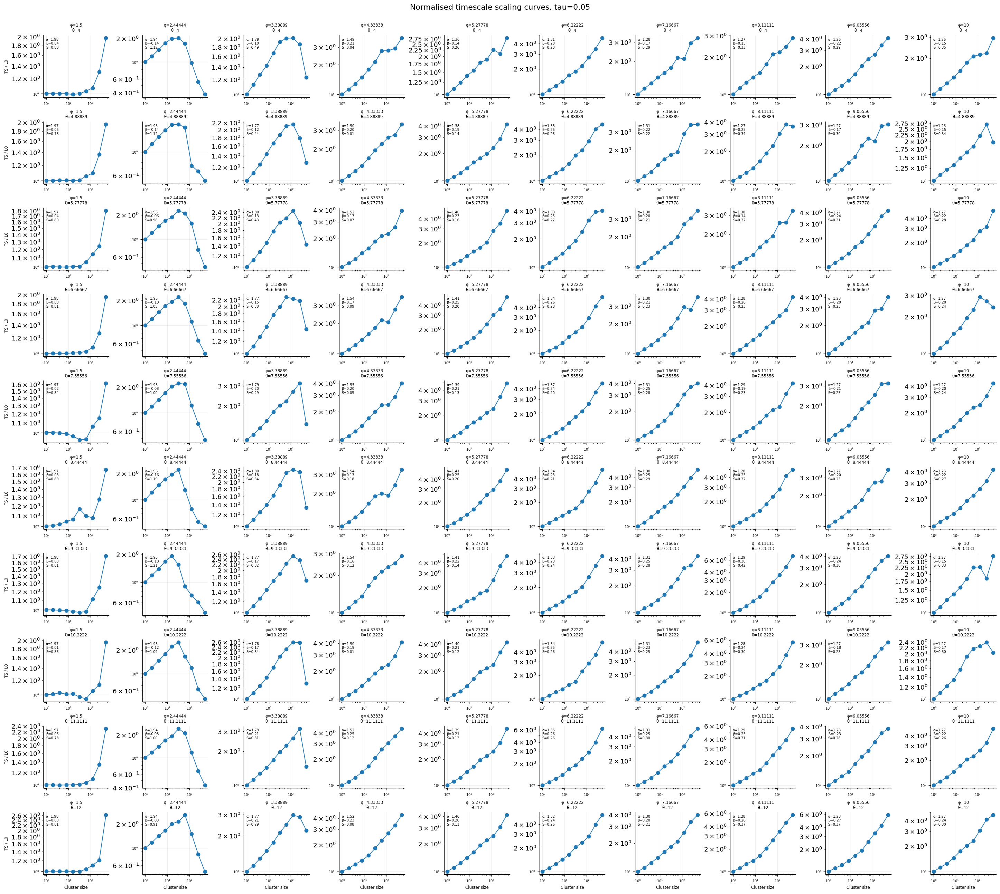

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/grid_normalised_ts_scaling_tau_0p05.png
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved/activity_sanity_vs_score_by_tau.png


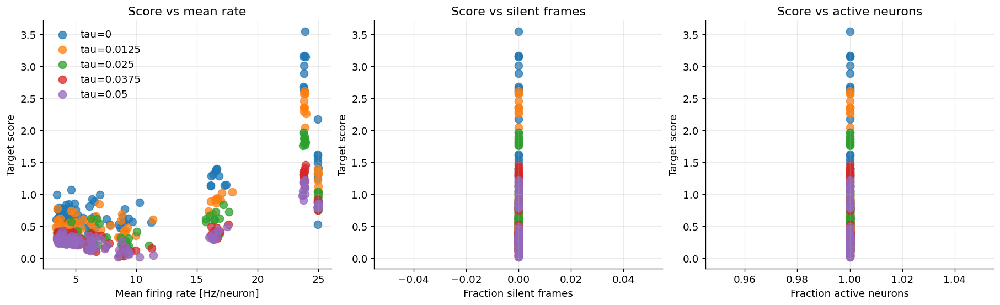


Done.
Loaded from: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full
Plots: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/plots_from_saved
Best by tau: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/best20_by_smooth_tau_norm_target_from_saved.csv
Best 1 by tau: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/best1_by_smooth_tau_norm_target_from_saved.csv
Top 100 overall: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full/top100_overall_norm_target_from_saved.csv


In [13]:
# ============================================================
# ANALYSE / PLOT FULL PHI x THETA x SMOOTH_TAU RUN
#
# Loads:
#   phi_theta_smooth_tau_seed_metrics.csv
#   phi_theta_smooth_tau_generation_metrics.csv
#   phi_theta_smooth_tau_summary_metrics.csv
#   phi_theta_smooth_tau_generation_summary.csv
#
# From:
#   phi_theta_startpext_smooth_tau_10x10x5_full
#
# Makes:
#   - best rows by tau
#   - heatmaps per tau
#   - alpha/beta scatter
#   - exponents vs phi
#   - best scaling curves
#   - all scaling curves
#   - phi x theta grid scaling curves
#   - activity sanity plots
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Paths
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_startpext_smooth_tau_10x10x5_full")
PLOTDIR = OUTDIR / "plots_from_saved"
PLOTDIR.mkdir(parents=True, exist_ok=True)

seed_path = OUTDIR / "phi_theta_smooth_tau_seed_metrics.csv"
gen_path = OUTDIR / "phi_theta_smooth_tau_generation_metrics.csv"
summary_path = OUTDIR / "phi_theta_smooth_tau_summary_metrics.csv"
gen_summary_path = OUTDIR / "phi_theta_smooth_tau_generation_summary.csv"

df = pd.read_csv(seed_path)
gen_all = pd.read_csv(gen_path)
summary = pd.read_csv(summary_path)
gen_summary = pd.read_csv(gen_summary_path)

df = df.replace([np.inf, -np.inf], np.nan)
gen_all = gen_all.replace([np.inf, -np.inf], np.nan)
summary = summary.replace([np.inf, -np.inf], np.nan)
gen_summary = gen_summary.replace([np.inf, -np.inf], np.nan)

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# Recompute scores if needed
# ============================================================

if "target_score_norm" not in summary.columns:
    summary["target_score_norm"] = (
        np.abs(summary["mv_alpha_norm_mean"] - TARGET_ALPHA)
        + 2.0 * np.abs(summary["ts_beta_norm_mean"] - TARGET_BETA)
    )

if "target_score_raw" not in summary.columns:
    summary["target_score_raw"] = (
        np.abs(summary["mv_alpha_mean"] - TARGET_ALPHA)
        + 2.0 * np.abs(summary["ts_beta_mean"] - TARGET_BETA)
    )

summary["target_score_norm_r2pen"] = (
    summary["target_score_norm"]
    + 0.5 * np.maximum(0, 0.8 - summary["mv_r2_norm_mean"])
    + 0.5 * np.maximum(0, 0.8 - summary["ts_r2_norm_mean"])
)


# ============================================================
# Best rows by smoothing tau
# ============================================================

best_by_tau = []

for tau, ss in summary.groupby("smooth_tau"):
    bb = (
        ss
        .dropna(subset=["mv_alpha_norm_mean", "ts_beta_norm_mean", "target_score_norm"])
        .sort_values("target_score_norm")
        .head(20)
        .copy()
    )
    bb["rank_within_tau"] = np.arange(1, len(bb) + 1)
    best_by_tau.append(bb)

best_by_tau = pd.concat(best_by_tau, ignore_index=True)

best_path = OUTDIR / "best20_by_smooth_tau_norm_target_from_saved.csv"
best_by_tau.to_csv(best_path, index=False)

print("\nBest 20 by smooth_tau:")
cols = [
    "smooth_tau", "rank_within_tau",
    "phi", "theta", "p_ext", "p_self_zero_input",
    "target_score_norm",
    "mv_alpha_norm_mean", "mv_r2_norm_mean",
    "ts_beta_norm_mean", "ts_r2_norm_mean",
    "mean_rate_hz_mean",
    "frac_silent_frames_mean",
    "frac_active_neurons_mean",
    "n",
]
print(best_by_tau[cols].round(6).to_string(index=False))
print("\nSaved:", best_path)


# ============================================================
# Helper heatmap
# ============================================================

def heatmap_metric(ss, metric, title, fname, cmap="viridis"):
    piv = ss.pivot(index="theta", columns="phi", values=metric)
    piv = piv.sort_index(ascending=True)

    fig, ax = plt.subplots(figsize=(8.5, 6.5), constrained_layout=True)

    im = ax.imshow(
        piv.values,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
    )

    ax.set_xticks(np.arange(len(piv.columns)))
    ax.set_xticklabels([f"{x:g}" for x in piv.columns], rotation=45, ha="right")

    ax.set_yticks(np.arange(len(piv.index)))
    ax.set_yticklabels([f"{x:g}" for x in piv.index])

    ax.set_xlabel("phi")
    ax.set_ylabel("theta")
    ax.set_title(title)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(metric)

    savefig(fig, fname)
    plt.show()


# ============================================================
# 1. Heatmaps per smoothing tau
# ============================================================

for tau, ss in summary.groupby("smooth_tau"):
    tag = str(tau).replace(".", "p")
    pext = ss["p_ext"].iloc[0] if "p_ext" in ss.columns else np.nan

    heatmap_metric(
        ss,
        "mv_alpha_norm_mean",
        f"Normalised MV exponent α, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_mv_alpha_norm_tau_{tag}.png",
    )

    heatmap_metric(
        ss,
        "ts_beta_norm_mean",
        f"Normalised timescale exponent β, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_ts_beta_norm_tau_{tag}.png",
    )

    heatmap_metric(
        ss,
        "mv_r2_norm_mean",
        f"Normalised MV fit R², tau={tau:g}, p_ext={pext:g}",
        f"heatmap_mv_r2_norm_tau_{tag}.png",
    )

    heatmap_metric(
        ss,
        "ts_r2_norm_mean",
        f"Normalised timescale fit R², tau={tau:g}, p_ext={pext:g}",
        f"heatmap_ts_r2_norm_tau_{tag}.png",
    )

    heatmap_metric(
        ss,
        "target_score_norm",
        f"Target score, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_target_score_norm_tau_{tag}.png",
        cmap="magma_r",
    )

    heatmap_metric(
        ss,
        "target_score_norm_r2pen",
        f"R²-penalised target score, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_target_score_norm_r2pen_tau_{tag}.png",
        cmap="magma_r",
    )

    heatmap_metric(
        ss,
        "mean_rate_hz_mean",
        f"Mean firing rate, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_mean_rate_tau_{tag}.png",
    )

    heatmap_metric(
        ss,
        "frac_silent_frames_mean",
        f"Fraction silent frames, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_frac_silent_frames_tau_{tag}.png",
    )

    heatmap_metric(
        ss,
        "frac_active_neurons_mean",
        f"Fraction active neurons, tau={tau:g}, p_ext={pext:g}",
        f"heatmap_frac_active_neurons_tau_{tag}.png",
    )


# ============================================================
# 2. Best score / alpha / beta vs smoothing
# ============================================================

best1 = (
    best_by_tau
    .query("rank_within_tau == 1")
    .sort_values("smooth_tau")
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)

axes[0].plot(best1["smooth_tau"], best1["target_score_norm"], marker="o", linewidth=2)
axes[0].set_ylabel("Best target score")
axes[0].set_title("Best score vs smoothing")

axes[1].plot(best1["smooth_tau"], best1["mv_alpha_norm_mean"], marker="o", linewidth=2)
axes[1].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[1].set_ylabel("Best-row α")
axes[1].set_title("Best α vs smoothing")

axes[2].plot(best1["smooth_tau"], best1["ts_beta_norm_mean"], marker="o", linewidth=2)
axes[2].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[2].set_ylabel("Best-row β")
axes[2].set_title("Best β vs smoothing")

for ax in axes:
    ax.set_xlabel("smooth_tau")
    ax.grid(alpha=0.25)

savefig(fig, "best_score_alpha_beta_vs_smooth_tau.png")
plt.show()


# ============================================================
# 3. Alpha-beta scatter across smoothing taus
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)

sc = ax.scatter(
    summary["mv_alpha_norm_mean"],
    summary["ts_beta_norm_mean"],
    c=summary["smooth_tau"],
    s=75,
    alpha=0.75,
)

for tau, bb in best_by_tau.groupby("smooth_tau"):
    top = bb.head(5)
    ax.scatter(
        top["mv_alpha_norm_mean"],
        top["ts_beta_norm_mean"],
        s=160,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
        label=f"top 5 tau={tau:g}",
    )

    for _, r in top.iterrows():
        ax.text(
            r["mv_alpha_norm_mean"],
            r["ts_beta_norm_mean"],
            str(int(r["rank_within_tau"])),
            ha="center",
            va="center",
            fontsize=8,
        )

ax.axvline(TARGET_ALPHA, linestyle="--", linewidth=1)
ax.axhline(TARGET_BETA, linestyle="--", linewidth=1)

ax.set_xlabel("Normalised MV exponent α")
ax.set_ylabel("Normalised timescale exponent β")
ax.set_title("α/β scatter across smoothing taus")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("smooth_tau")

savefig(fig, "alpha_beta_scatter_all_smooth_taus.png")
plt.show()


# ============================================================
# 4. Exponents vs phi, separate panels by tau
# ============================================================

for tau, ss in summary.groupby("smooth_tau"):
    tag = str(tau).replace(".", "p")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

    sc0 = axes[0].scatter(
        ss["phi"],
        ss["mv_alpha_norm_mean"],
        c=ss["theta"],
        s=80,
        alpha=0.8,
    )

    axes[1].scatter(
        ss["phi"],
        ss["ts_beta_norm_mean"],
        c=ss["theta"],
        s=80,
        alpha=0.8,
    )

    axes[2].scatter(
        ss["phi"],
        ss["target_score_norm"],
        c=ss["theta"],
        s=80,
        alpha=0.8,
    )

    top = best_by_tau[np.isclose(best_by_tau["smooth_tau"], tau)].head(5)

    axes[0].scatter(
        top["phi"],
        top["mv_alpha_norm_mean"],
        s=170,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
    )
    axes[1].scatter(
        top["phi"],
        top["ts_beta_norm_mean"],
        s=170,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
    )
    axes[2].scatter(
        top["phi"],
        top["target_score_norm"],
        s=170,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
    )

    axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
    axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1)

    axes[0].set_ylabel("Normalised MV exponent α")
    axes[1].set_ylabel("Normalised timescale exponent β")
    axes[2].set_ylabel("Target score")

    axes[0].set_title(f"α vs phi, tau={tau:g}")
    axes[1].set_title(f"β vs phi, tau={tau:g}")
    axes[2].set_title(f"Score vs phi, tau={tau:g}")

    for axx in axes:
        axx.set_xlabel("phi")
        axx.set_xscale("log")
        axx.grid(alpha=0.25)

    cbar = fig.colorbar(sc0, ax=axes)
    cbar.set_label("theta")

    savefig(fig, f"exponents_vs_phi_tau_{tag}.png")
    plt.show()


# ============================================================
# 5. Best 10 normalised ICG curves per tau
# ============================================================

for tau, bb in best_by_tau.groupby("smooth_tau"):
    tag = str(tau).replace(".", "p")
    top = bb.head(10)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

    for _, r in top.iterrows():
        gg = gen_summary[
            np.isclose(gen_summary["smooth_tau"], tau)
            & np.isclose(gen_summary["phi"], r["phi"])
            & np.isclose(gen_summary["theta"], r["theta"])
        ].sort_values("gen")

        label = (
            f"#{int(r['rank_within_tau'])}: "
            f"φ={r['phi']:.3g}, θ={r['theta']:.3g}, "
            f"α={r['mv_alpha_norm_mean']:.2f}, "
            f"β={r['ts_beta_norm_mean']:.2f}"
        )

        axes[0].plot(
            gg["mean_cluster_size_mean"],
            gg["mean_variance_norm_mean"],
            marker="o",
            linewidth=1.5,
            label=label,
        )

        axes[1].plot(
            gg["mean_cluster_size_mean"],
            gg["timescale_norm_mean"],
            marker="o",
            linewidth=1.5,
            label=label,
        )

        axes[2].plot(
            gg["mean_cluster_size_mean"],
            gg["corr_kurtosis_mean"],
            marker="o",
            linewidth=1.5,
            label=label,
        )

    axes[0].set_ylabel("MV / MV(L0)")
    axes[1].set_ylabel("Timescale / Timescale(L0)")
    axes[2].set_ylabel("Correlation kurtosis")

    axes[0].set_title(f"Best 10 MV scaling, tau={tau:g}")
    axes[1].set_title(f"Best 10 timescale scaling, tau={tau:g}")
    axes[2].set_title(f"Best 10 kurtosis, tau={tau:g}")

    for ax in axes:
        ax.set_xlabel("Mean cluster size")
        ax.set_xscale("log")
        ax.grid(alpha=0.25)

    axes[0].set_yscale("log")
    axes[1].set_yscale("log")
    axes[2].axhline(3.0, linestyle="--", linewidth=1)

    axes[2].legend(
        frameon=False,
        fontsize=6.5,
        bbox_to_anchor=(1.04, 1),
        loc="upper left",
    )

    savefig(fig, f"best10_icg_curves_tau_{tag}.png")
    plt.show()


# ============================================================
# 6. Raw vs normalised curves for best row of each tau
# ============================================================

for _, r in best1.iterrows():
    tau = r["smooth_tau"]
    tag = str(tau).replace(".", "p")

    gg = gen_summary[
        np.isclose(gen_summary["smooth_tau"], tau)
        & np.isclose(gen_summary["phi"], r["phi"])
        & np.isclose(gen_summary["theta"], r["theta"])
    ].sort_values("gen")

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)

    axes[0, 0].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_mean"],
        marker="o",
        linewidth=1.8,
    )
    axes[0, 0].set_title("Raw MV")
    axes[0, 0].set_ylabel("Mean variance")

    axes[0, 1].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=1.8,
    )
    axes[0, 1].set_title("Normalised MV")
    axes[0, 1].set_ylabel("MV / MV(L0)")

    axes[1, 0].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_mean"],
        marker="o",
        linewidth=1.8,
    )
    axes[1, 0].set_title("Raw timescale")
    axes[1, 0].set_ylabel("Timescale")

    axes[1, 1].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=1.8,
    )
    axes[1, 1].set_title("Normalised timescale")
    axes[1, 1].set_ylabel("Timescale / Timescale(L0)")

    for ax in axes.ravel():
        ax.set_xlabel("Mean cluster size")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(alpha=0.25)

    fig.suptitle(
        f"Best row tau={tau:g}: phi={r['phi']:.3g}, theta={r['theta']:.3g}",
        y=1.02,
    )

    savefig(fig, f"best1_raw_vs_norm_curves_tau_{tag}.png")
    plt.show()


# ============================================================
# 7. All normalised scaling curves per tau, coloured by score
# ============================================================

for tau, ss in summary.groupby("smooth_tau"):
    tag = str(tau).replace(".", "p")
    ss = ss.sort_values("target_score_norm")

    vals = ss["target_score_norm"].to_numpy()
    vmin = np.nanmin(vals)
    vmax = np.nanmax(vals)

    cmap = plt.cm.viridis

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

    for _, r in ss.iterrows():
        gg = gen_summary[
            np.isclose(gen_summary["smooth_tau"], tau)
            & np.isclose(gen_summary["phi"], r["phi"])
            & np.isclose(gen_summary["theta"], r["theta"])
        ].sort_values("gen")

        c = cmap((r["target_score_norm"] - vmin) / (vmax - vmin + 1e-12))

        axes[0].plot(
            gg["mean_cluster_size_mean"],
            gg["mean_variance_norm_mean"],
            marker="o",
            linewidth=1.0,
            alpha=0.65,
            color=c,
        )

        axes[1].plot(
            gg["mean_cluster_size_mean"],
            gg["timescale_norm_mean"],
            marker="o",
            linewidth=1.0,
            alpha=0.65,
            color=c,
        )

    axes[0].set_title(f"All normalised MV curves, tau={tau:g}")
    axes[1].set_title(f"All normalised timescale curves, tau={tau:g}")

    axes[0].set_ylabel("MV / MV(L0)")
    axes[1].set_ylabel("Timescale / Timescale(L0)")

    for ax in axes:
        ax.set_xlabel("Mean cluster size")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(alpha=0.25)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes)
    cbar.set_label("target_score_norm")

    savefig(fig, f"all_normalised_scaling_curves_tau_{tag}.png")
    plt.show()


# ============================================================
# 8. Grid normalised scaling curves across phi x theta per tau
# ============================================================

for tau, ss in summary.groupby("smooth_tau"):
    tag = str(tau).replace(".", "p")

    phi_vals = np.sort(ss["phi"].unique())
    theta_vals = np.sort(ss["theta"].unique())

    fig_mv, axes_mv = plt.subplots(
        len(theta_vals),
        len(phi_vals),
        figsize=(2.4 * len(phi_vals), 2.1 * len(theta_vals)),
        constrained_layout=True,
        squeeze=False,
    )

    fig_ts, axes_ts = plt.subplots(
        len(theta_vals),
        len(phi_vals),
        figsize=(2.4 * len(phi_vals), 2.1 * len(theta_vals)),
        constrained_layout=True,
        squeeze=False,
    )

    for i, theta in enumerate(theta_vals):
        for j, phi in enumerate(phi_vals):
            ax_mv = axes_mv[i, j]
            ax_ts = axes_ts[i, j]

            gg = gen_summary[
                np.isclose(gen_summary["smooth_tau"], tau)
                & np.isclose(gen_summary["phi"], phi)
                & np.isclose(gen_summary["theta"], theta)
            ].sort_values("gen")

            row = ss[
                np.isclose(ss["phi"], phi)
                & np.isclose(ss["theta"], theta)
            ]

            if len(row) > 0:
                row = row.iloc[0]
                label_txt = (
                    f"α={row['mv_alpha_norm_mean']:.2f}\n"
                    f"β={row['ts_beta_norm_mean']:.2f}\n"
                    f"S={row['target_score_norm']:.2f}"
                )
            else:
                label_txt = ""

            ax_mv.plot(
                gg["mean_cluster_size_mean"],
                gg["mean_variance_norm_mean"],
                marker="o",
                linewidth=1.1,
            )

            ax_ts.plot(
                gg["mean_cluster_size_mean"],
                gg["timescale_norm_mean"],
                marker="o",
                linewidth=1.1,
            )

            ax_mv.set_xscale("log")
            ax_mv.set_yscale("log")
            ax_ts.set_xscale("log")
            ax_ts.set_yscale("log")

            ax_mv.grid(alpha=0.2)
            ax_ts.grid(alpha=0.2)

            ax_mv.set_title(f"φ={phi:g}\nθ={theta:g}", fontsize=7)
            ax_ts.set_title(f"φ={phi:g}\nθ={theta:g}", fontsize=7)

            if label_txt:
                ax_mv.text(
                    0.04, 0.96, label_txt,
                    transform=ax_mv.transAxes,
                    va="top",
                    ha="left",
                    fontsize=6,
                )
                ax_ts.text(
                    0.04, 0.96, label_txt,
                    transform=ax_ts.transAxes,
                    va="top",
                    ha="left",
                    fontsize=6,
                )

            if i == len(theta_vals) - 1:
                ax_mv.set_xlabel("Cluster size", fontsize=7)
                ax_ts.set_xlabel("Cluster size", fontsize=7)

            if j == 0:
                ax_mv.set_ylabel("MV / L0", fontsize=7)
                ax_ts.set_ylabel("TS / L0", fontsize=7)

            ax_mv.tick_params(labelsize=6)
            ax_ts.tick_params(labelsize=6)

    fig_mv.suptitle(f"Normalised MV scaling curves, tau={tau:g}", y=1.02)
    fig_ts.suptitle(f"Normalised timescale scaling curves, tau={tau:g}", y=1.02)

    savefig(fig_mv, f"grid_normalised_mv_scaling_tau_{tag}.png")
    plt.show()

    savefig(fig_ts, f"grid_normalised_ts_scaling_tau_{tag}.png")
    plt.show()


# ============================================================
# 9. Activity sanity by tau
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

for tau, ss in summary.groupby("smooth_tau"):
    axes[0].scatter(
        ss["mean_rate_hz_mean"],
        ss["target_score_norm"],
        s=70,
        alpha=0.75,
        label=f"tau={tau:g}",
    )

    axes[1].scatter(
        ss["frac_silent_frames_mean"],
        ss["target_score_norm"],
        s=70,
        alpha=0.75,
        label=f"tau={tau:g}",
    )

    axes[2].scatter(
        ss["frac_active_neurons_mean"],
        ss["target_score_norm"],
        s=70,
        alpha=0.75,
        label=f"tau={tau:g}",
    )

axes[0].set_xlabel("Mean firing rate [Hz/neuron]")
axes[1].set_xlabel("Fraction silent frames")
axes[2].set_xlabel("Fraction active neurons")

for ax in axes:
    ax.set_ylabel("Target score")
    ax.grid(alpha=0.25)

axes[0].set_title("Score vs mean rate")
axes[1].set_title("Score vs silent frames")
axes[2].set_title("Score vs active neurons")
axes[0].legend(frameon=False)

savefig(fig, "activity_sanity_vs_score_by_tau.png")
plt.show()


# ============================================================
# 10. Save compact tables
# ============================================================

best1.to_csv(OUTDIR / "best1_by_smooth_tau_norm_target_from_saved.csv", index=False)

top_all = (
    summary
    .dropna(subset=["mv_alpha_norm_mean", "ts_beta_norm_mean", "target_score_norm"])
    .sort_values("target_score_norm")
    .head(100)
    .reset_index(drop=True)
)
top_all.to_csv(OUTDIR / "top100_overall_norm_target_from_saved.csv", index=False)

print("\nDone.")
print("Loaded from:", OUTDIR)
print("Plots:", PLOTDIR)
print("Best by tau:", best_path)
print("Best 1 by tau:", OUTDIR / "best1_by_smooth_tau_norm_target_from_saved.csv")
print("Top 100 overall:", OUTDIR / "top100_overall_norm_target_from_saved.csv")

T_VIS: 10.0
dt: 0.01
tau: 0.05
window: 0.0 to 3.0 s
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/smoothing_visualisation
spikes shape: (2000, 1000)
smoothed shape: (2000, 1000)
mean raw firing rate [Hz/neuron]: 24.37645


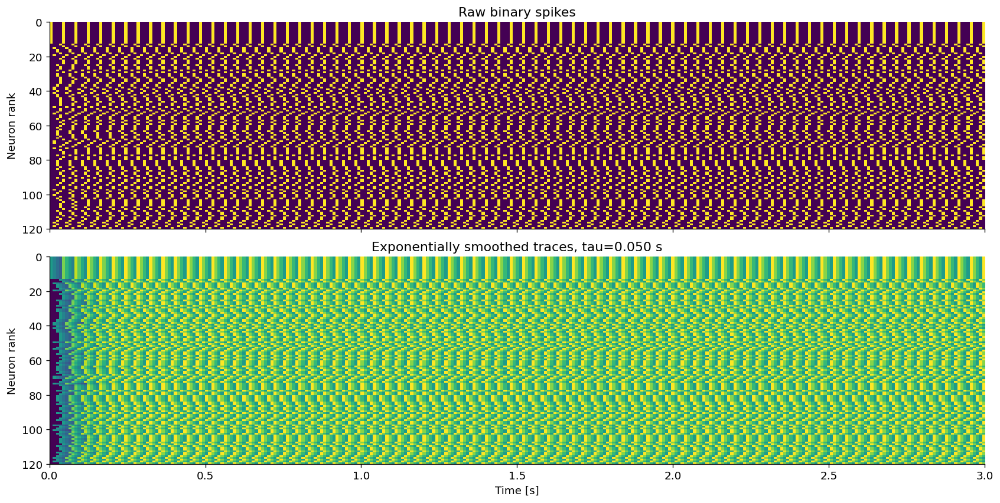

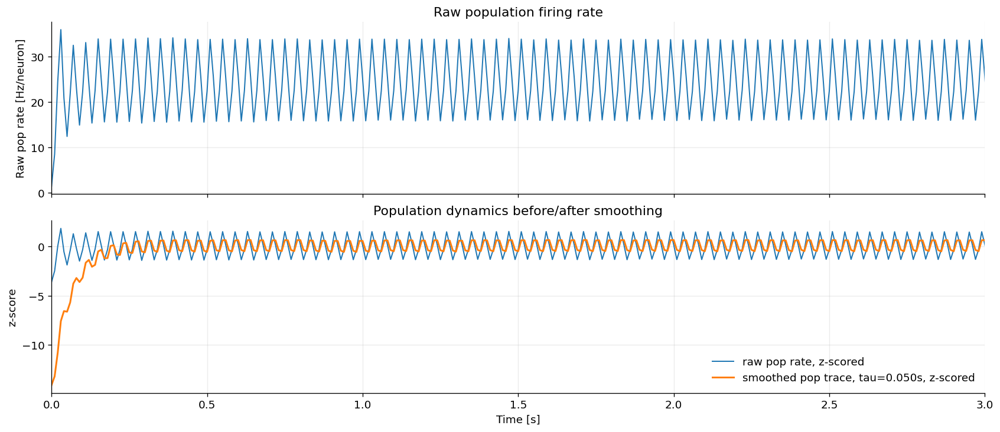

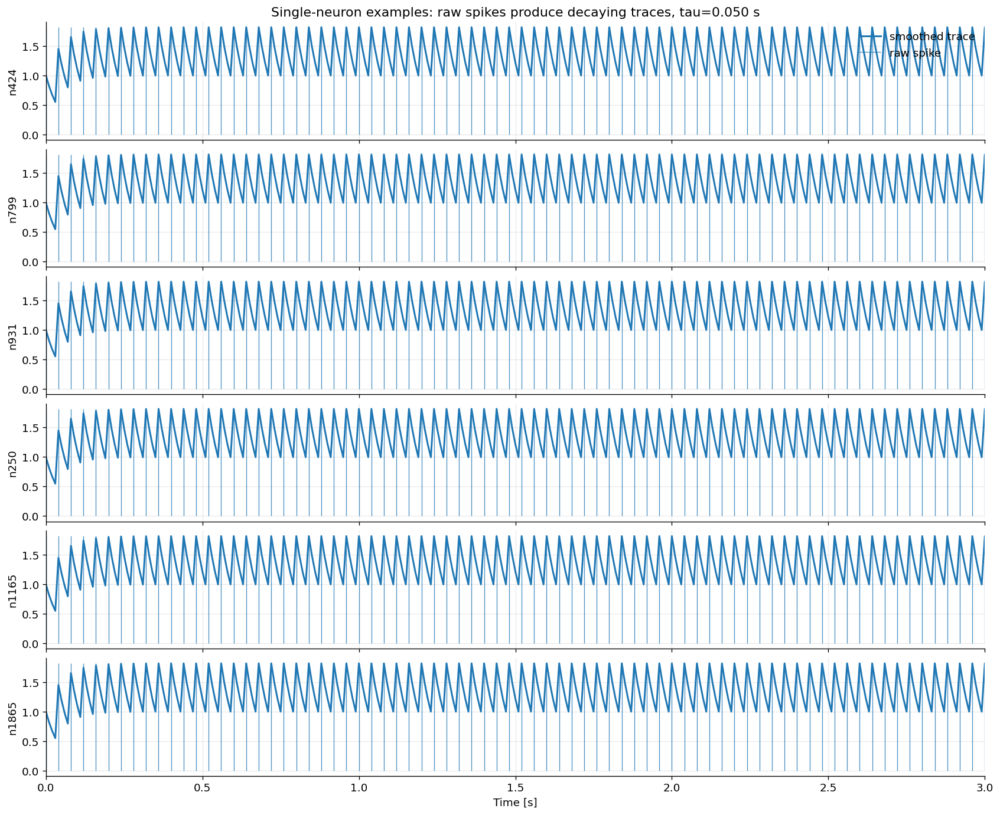

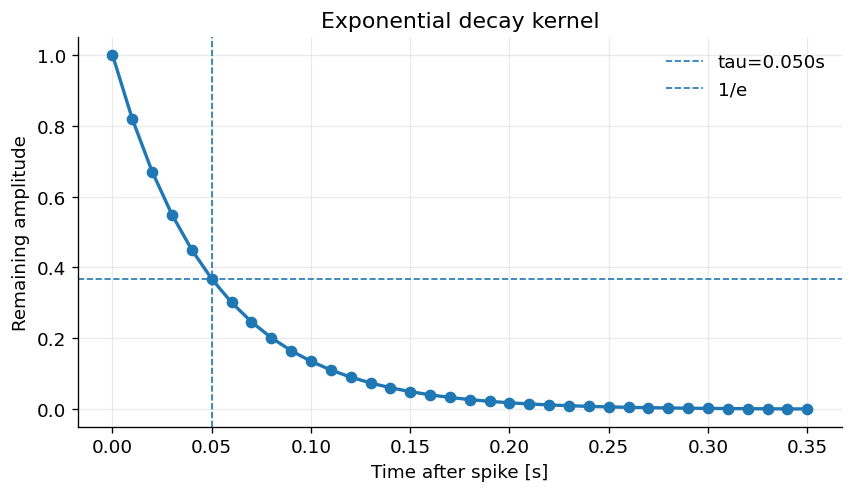

In [14]:
# Confirm smoothing regime
# ============================================================
# VISUALISE EFFECT OF EXPONENTIAL SMOOTHING ON SPIKES
#
# Shows:
#   1. raw spike raster
#   2. smoothed activity heatmap, tau=0.05 s
#   3. raw population rate vs smoothed population trace
#   4. example single-neuron raw spikes + smoothed trace
#   5. exponential kernel shape
#
# Uses actual time in seconds on x-axis.
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/smoothing_visualisation")
OUTDIR.mkdir(parents=True, exist_ok=True)

SEED = 123456
T_VIS = float(start_dic.get("T", 10.0))
TAU = 0.05  # seconds

# plot window
T0 = 0.0
T1 = min(3.0, T_VIS)   # seconds; set to T_VIS for full trace

N_SHOW = 120           # number of neurons in raster/heatmap
N_EXAMPLE = 6          # example single-neuron traces

print("T_VIS:", T_VIS)
print("dt:", start_dic["dt"])
print("tau:", TAU)
print("window:", T0, "to", T1, "s")
print("OUTDIR:", OUTDIR)


# ============================================================
# Build model pars from start_dic
# ============================================================

pars = dict(start_dic)

# module expects phi, not slope
if "slope" in pars and "phi" not in pars:
    pars["phi"] = float(pars.pop("slope"))
else:
    pars.pop("slope", None)

T_RUN = float(pars.pop("T", T_VIS))
pars["seed"] = int(SEED)

model = fn.automata_EI_hiermod(**pars)
spikes, pop_rate = fn.run_model(model, T=T_RUN)

dt = float(pars["dt"])
time = np.arange(spikes.shape[1]) * dt

X_smooth = fn.exp_smooth_spikes(
    spikes,
    dt=dt,
    tau=TAU,
)

print("spikes shape:", spikes.shape)
print("smoothed shape:", X_smooth.shape)
print("mean raw firing rate [Hz/neuron]:", spikes.mean() / dt)


# ============================================================
# Select time window and active neurons
# ============================================================

tmask = (time >= T0) & (time <= T1)
time_w = time[tmask]

spikes_w = spikes[:, tmask]
smooth_w = X_smooth[:, tmask]

# choose neurons with most spikes in window, so raster is informative
spike_counts = spikes_w.sum(axis=1)
active_order = np.argsort(spike_counts)[::-1]
active_order = active_order[spike_counts[active_order] > 0]

if len(active_order) < N_SHOW:
    rest = np.setdiff1d(np.arange(spikes.shape[0]), active_order)
    active_order = np.concatenate([active_order, rest])

show_neurons = active_order[:N_SHOW]

spikes_show = spikes_w[show_neurons]
smooth_show = smooth_w[show_neurons]

# normalise each smoothed row only for heatmap visibility
smooth_show_norm = smooth_show.copy().astype(float)
row_max = np.nanmax(smooth_show_norm, axis=1, keepdims=True)
smooth_show_norm = smooth_show_norm / np.maximum(row_max, 1e-12)


# ============================================================
# 1. Raw raster and smoothed heatmap
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)

axes[0].imshow(
    spikes_show,
    aspect="auto",
    interpolation="nearest",
    extent=[time_w[0], time_w[-1], N_SHOW, 0],
)
axes[0].set_ylabel("Neuron rank")
axes[0].set_title("Raw binary spikes")

axes[1].imshow(
    smooth_show_norm,
    aspect="auto",
    interpolation="nearest",
    extent=[time_w[0], time_w[-1], N_SHOW, 0],
)
axes[1].set_ylabel("Neuron rank")
axes[1].set_xlabel("Time [s]")
axes[1].set_title(f"Exponentially smoothed traces, tau={TAU:.3f} s")

for ax in axes:
    ax.grid(False)

fig.savefig(OUTDIR / "raw_raster_vs_smoothed_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 2. Population activity: raw rate vs smoothed population trace
# ============================================================

raw_pop_rate_hz = spikes.mean(axis=0) / dt
smooth_pop_trace = X_smooth.mean(axis=0)

# for visual comparison only
raw_pop_rate_z = (raw_pop_rate_hz - raw_pop_rate_hz.mean()) / (raw_pop_rate_hz.std() + 1e-12)
smooth_pop_z = (smooth_pop_trace - smooth_pop_trace.mean()) / (smooth_pop_trace.std() + 1e-12)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, constrained_layout=True)

axes[0].plot(time, raw_pop_rate_hz, linewidth=1.2)
axes[0].set_ylabel("Raw pop rate [Hz/neuron]")
axes[0].set_title("Raw population firing rate")

axes[1].plot(time, raw_pop_rate_z, linewidth=1.2, label="raw pop rate, z-scored")
axes[1].plot(time, smooth_pop_z, linewidth=1.8, label=f"smoothed pop trace, tau={TAU:.3f}s, z-scored")
axes[1].set_ylabel("z-score")
axes[1].set_xlabel("Time [s]")
axes[1].set_title("Population dynamics before/after smoothing")
axes[1].legend(frameon=False)

for ax in axes:
    ax.set_xlim(T0, T1)
    ax.grid(alpha=0.25)

fig.savefig(OUTDIR / "population_raw_vs_smoothed.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 3. Example single-neuron traces
# ============================================================

example_neurons = show_neurons[:N_EXAMPLE]

fig, axes = plt.subplots(N_EXAMPLE, 1, figsize=(14, 1.9 * N_EXAMPLE), sharex=True, constrained_layout=True)

if N_EXAMPLE == 1:
    axes = [axes]

for ax, neuron in zip(axes, example_neurons):
    raw = spikes[neuron, :]
    sm = X_smooth[neuron, :]

    # scale raw spikes to smoothed trace height for overlay
    sm_max = max(np.nanmax(sm[tmask]), 1e-12)
    raw_scaled = raw * sm_max

    ax.plot(time, sm, linewidth=1.8, label="smoothed trace")
    ax.vlines(time[raw > 0], 0, sm_max, linewidth=0.8, alpha=0.8, label="raw spike" if neuron == example_neurons[0] else None)

    ax.set_xlim(T0, T1)
    ax.set_ylabel(f"n{neuron}")
    ax.grid(alpha=0.25)

axes[0].set_title(f"Single-neuron examples: raw spikes produce decaying traces, tau={TAU:.3f} s")
axes[-1].set_xlabel("Time [s]")
axes[0].legend(frameon=False, loc="upper right")

fig.savefig(OUTDIR / "example_neuron_raw_spikes_vs_smoothed_traces.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 4. The smoothing kernel itself
# ============================================================

kernel_t = np.arange(0, 0.35 + dt, dt)
kernel = np.exp(-kernel_t / TAU)

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)

ax.plot(kernel_t, kernel, marker="o", linewidth=2)
ax.axvline(TAU, linestyle="--", linewidth=1, label=f"tau={TAU:.3f}s")
ax.axhline(1 / np.e, linestyle="--", linewidth=1, label="1/e")

ax.set_xlabel("Time after spike [s]")
ax.set_ylabel("Remaining amplitude")
ax.set_title("Exponential decay kernel")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

fig.savefig(OUTDIR / "exp_smoothing_kernel_tau005.png", dpi=300, bbox_inches="tight")
plt.show()


In [16]:
start_dic = {'n_neurons': 2000,
 'T': 10,
 'dt': 0.01,
 'refractory_steps': 2,
 'ei_ratio': 0.2,
 'e_w': 21.4115,
 'i_w': 21.675,
 'theta': 7.5,
 'p_ext': 0.015,
 'slope': 2.25,
 'smoothe': 0.05}
start_dic

{'n_neurons': 2000,
 'T': 10,
 'dt': 0.01,
 'refractory_steps': 2,
 'ei_ratio': 0.2,
 'e_w': 21.4115,
 'i_w': 21.675,
 'theta': 7.5,
 'p_ext': 0.015,
 'slope': 2.25,
 'smoothe': 0.05}


Best 50:
 rank      phi     theta  p_ext  smoothe  p_self_zero_input  target_score_norm  target_score_norm_r2pen  mv_alpha_norm_mean  mv_r2_norm_mean  ts_beta_norm_mean  ts_r2_norm_mean  mean_rate_hz_mean  frac_silent_frames_mean  frac_active_neurons_mean  n
    1 4.333333 11.111111   0.07     0.05           0.000015           0.011515                 0.011515            1.492147         0.999371           0.198169         0.979301           14.31970                      0.0                       1.0  1
    2 4.333333  5.777778   0.09     0.05           0.003086           0.012105                 0.012105            1.500753         0.999730           0.194324         0.977106           15.90040                      0.0                       1.0  1
    3 4.333333  6.666667   0.09     0.05           0.001271           0.015248                 0.015248            1.501727         0.999575           0.206760         0.983876           15.60835                      0.0                    

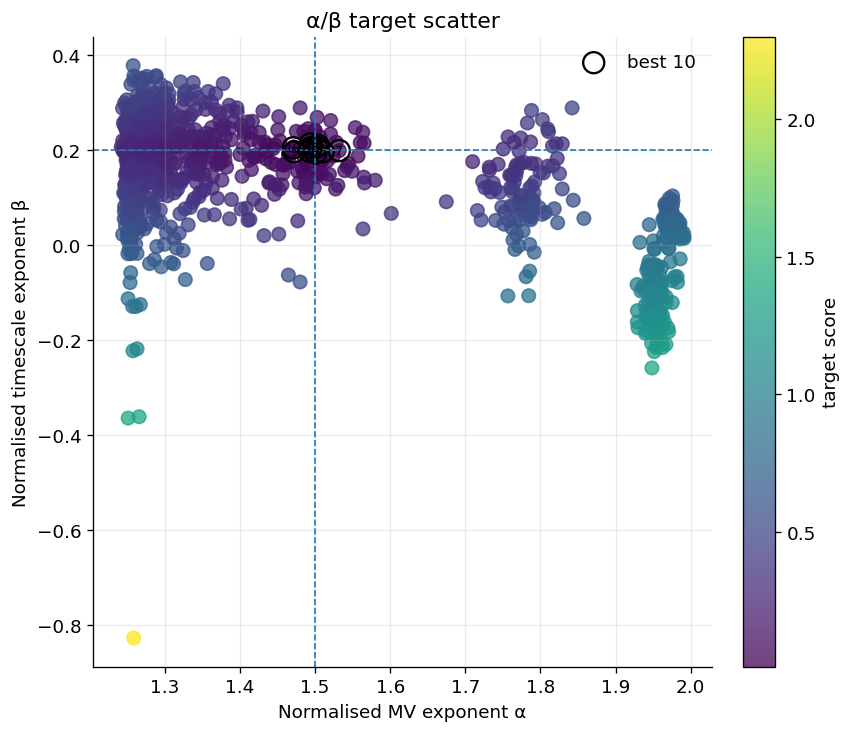

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/mv_alpha_vs_params.png


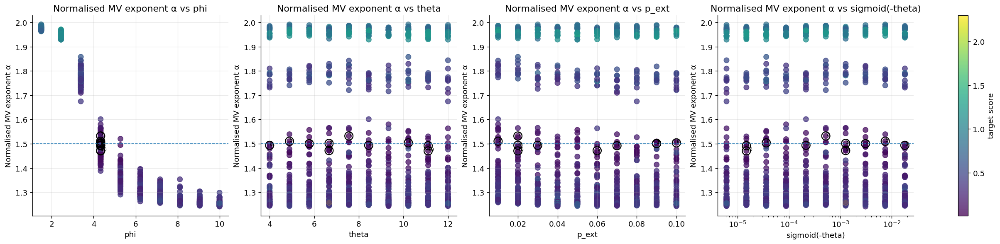

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/ts_beta_vs_params.png


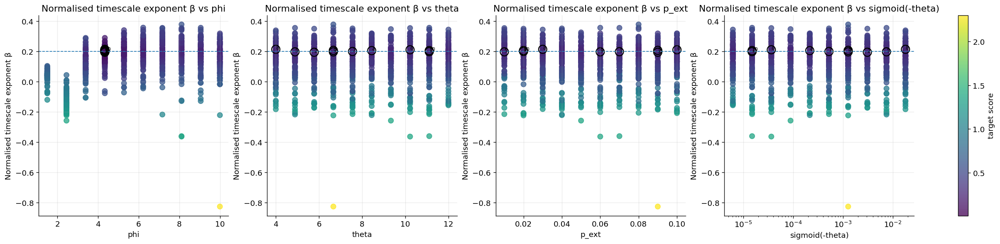

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/target_score_vs_params.png


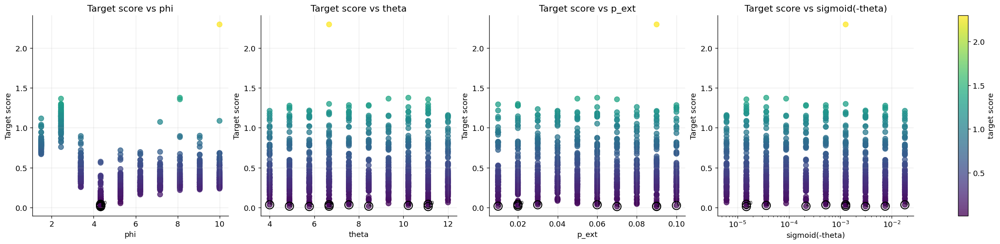

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/target_score_r2pen_vs_params.png


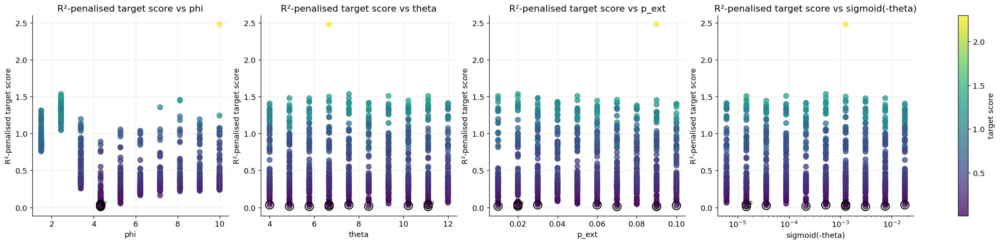

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/parameter_pairwise_target_score.png


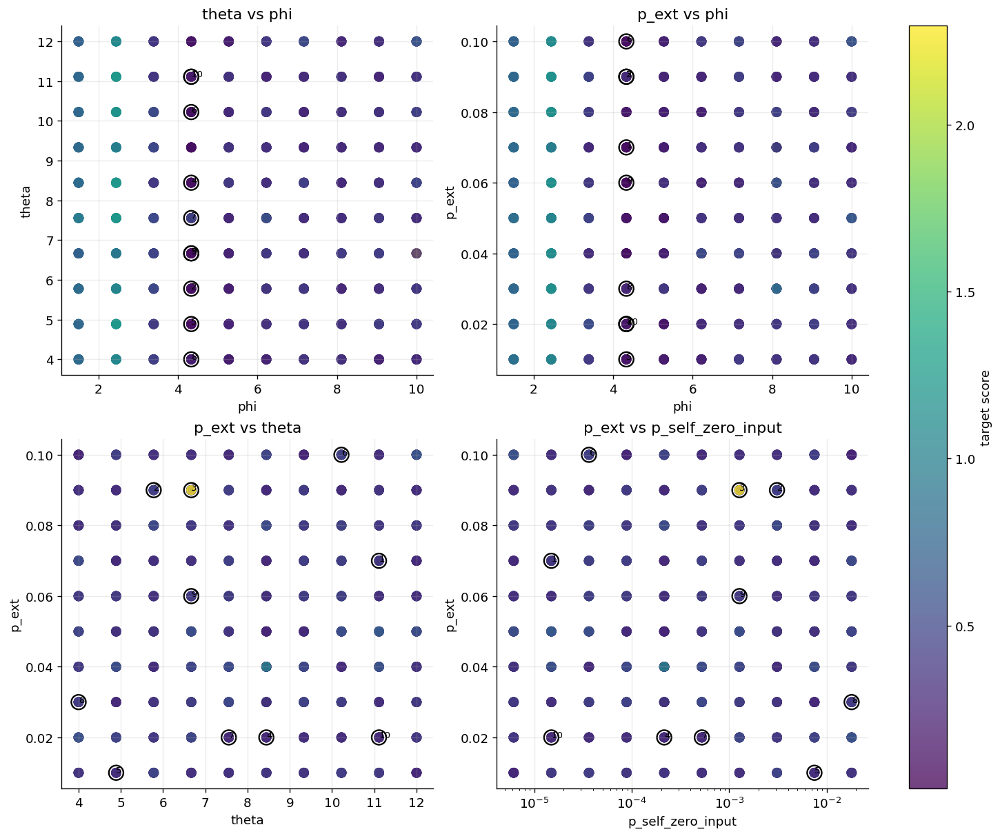

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/best10_normalised_icg_curves.png


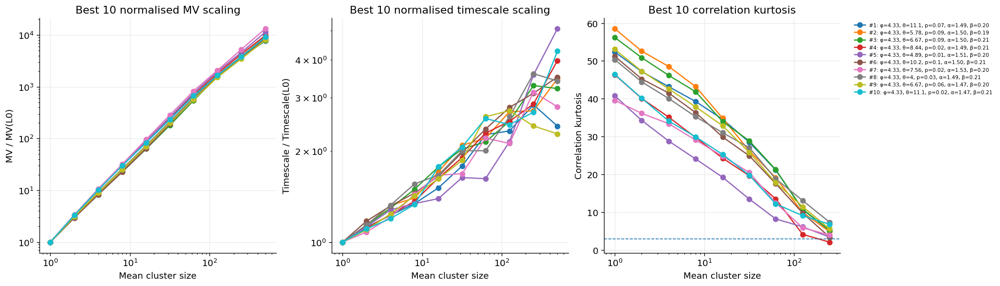

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/best10_raw_vs_normalised_scaling_curves.png


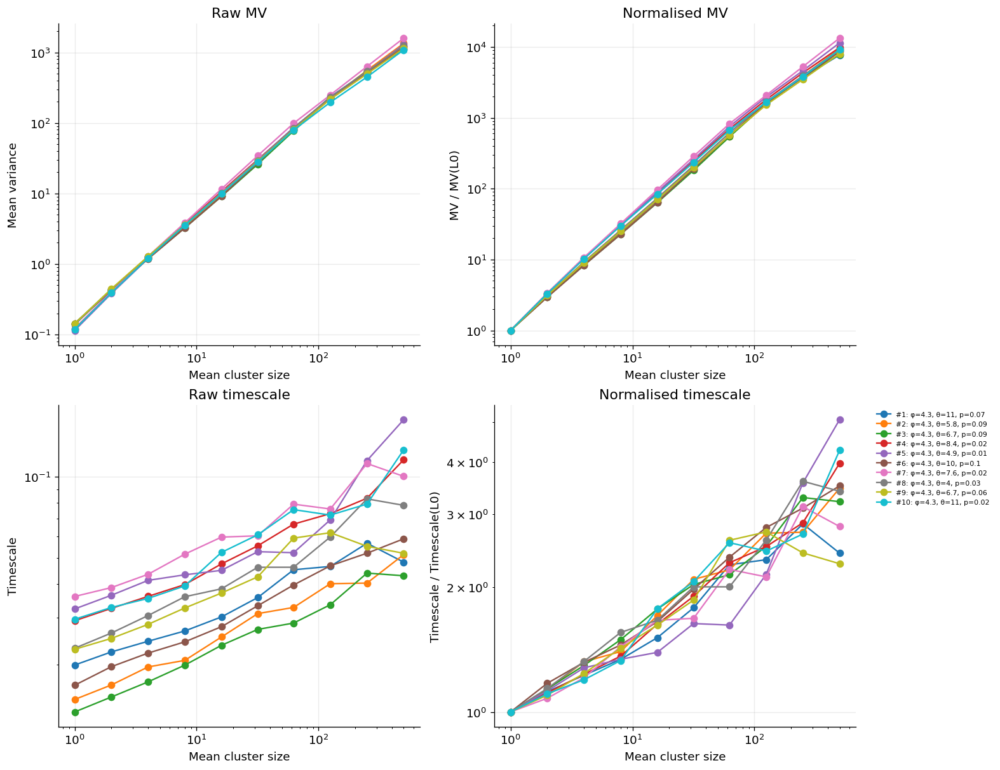

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/all_normalised_scaling_curves_coloured_by_score.png


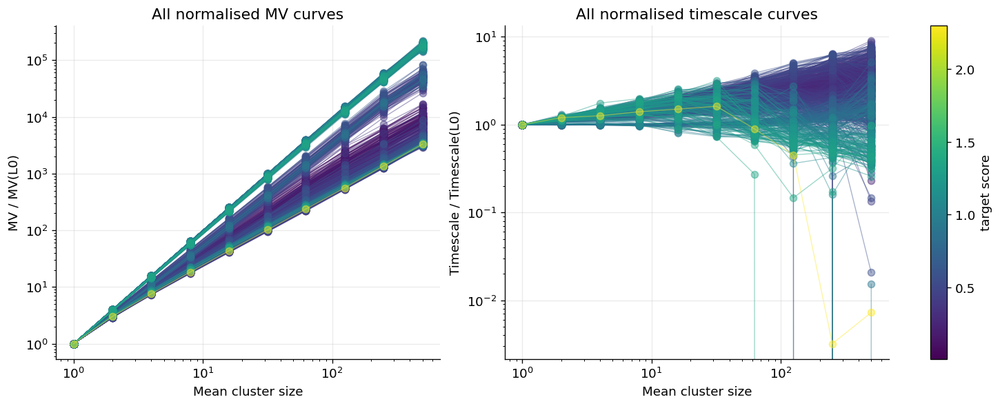

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/activity_sanity_vs_target_score.png


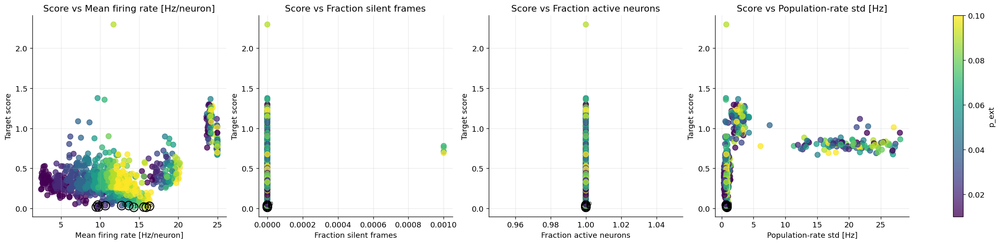

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/best_score_alpha_beta_by_pext.png


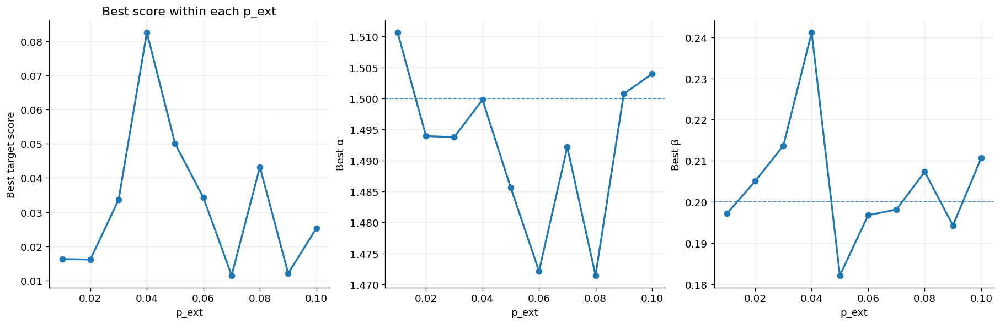

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps/seed_level_sanity_scatter.png


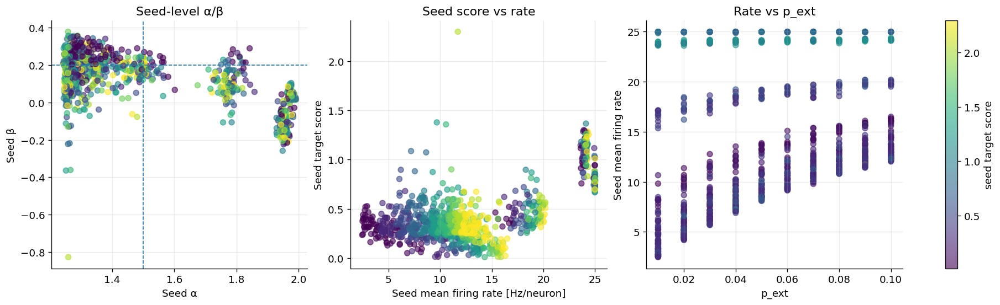


Done.
Loaded from: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10
Plots: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/plots_from_saved_no_heatmaps
Best 50: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/best50_phi_theta_pext_smooth005_norm_target_from_saved.csv
Best by p_ext: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/best5_within_each_pext_norm_target_from_saved.csv
Top 100: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10/top100_phi_theta_pext_smooth005_norm_target_from_saved.csv


In [18]:
# Exponent search

# ============================================================
# ANALYSE / VISUALISE PHI x THETA x P_EXT SWEEP
# NO HEATMAPS
#
# Loads:
#   phi_theta_pext_smooth005_seed_metrics.csv
#   phi_theta_pext_smooth005_generation_metrics.csv
#   phi_theta_pext_smooth005_summary_metrics.csv
#   phi_theta_pext_smooth005_generation_summary.csv
#
# Makes:
#   - alpha/beta target scatter
#   - best score vs p_ext
#   - exponents vs phi/theta/p_ext
#   - activity sanity plots
#   - best 10 scaling curves
#   - all normalised scaling curves coloured by score
#   - top tables
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_theta_pext_smooth005_10x10x10")
PLOTDIR = OUTDIR / "plots_from_saved_no_heatmaps"
PLOTDIR.mkdir(parents=True, exist_ok=True)

seed_path = OUTDIR / "phi_theta_pext_smooth005_seed_metrics.csv"
gen_path = OUTDIR / "phi_theta_pext_smooth005_generation_metrics.csv"
summary_path = OUTDIR / "phi_theta_pext_smooth005_summary_metrics.csv"
gen_summary_path = OUTDIR / "phi_theta_pext_smooth005_generation_summary.csv"

df = pd.read_csv(seed_path)
gen_all = pd.read_csv(gen_path)
summary = pd.read_csv(summary_path)
gen_summary = pd.read_csv(gen_summary_path)

df = df.replace([np.inf, -np.inf], np.nan)
gen_all = gen_all.replace([np.inf, -np.inf], np.nan)
summary = summary.replace([np.inf, -np.inf], np.nan)
gen_summary = gen_summary.replace([np.inf, -np.inf], np.nan)

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# Scores / best rows
# ============================================================

if "target_score_norm" not in summary.columns:
    summary["target_score_norm"] = (
        np.abs(summary["mv_alpha_norm_mean"] - TARGET_ALPHA)
        + 2.0 * np.abs(summary["ts_beta_norm_mean"] - TARGET_BETA)
    )

if "target_score_raw" not in summary.columns:
    summary["target_score_raw"] = (
        np.abs(summary["mv_alpha_mean"] - TARGET_ALPHA)
        + 2.0 * np.abs(summary["ts_beta_mean"] - TARGET_BETA)
    )

summary["target_score_norm_r2pen"] = (
    summary["target_score_norm"]
    + 0.5 * np.maximum(0, 0.8 - summary["mv_r2_norm_mean"])
    + 0.5 * np.maximum(0, 0.8 - summary["ts_r2_norm_mean"])
)

best50 = (
    summary
    .dropna(subset=["mv_alpha_norm_mean", "ts_beta_norm_mean", "target_score_norm"])
    .sort_values("target_score_norm")
    .head(50)
    .reset_index(drop=True)
)

best50["rank"] = np.arange(1, len(best50) + 1)

best50_path = OUTDIR / "best50_phi_theta_pext_smooth005_norm_target_from_saved.csv"
best50.to_csv(best50_path, index=False)

best10 = best50.head(10).copy()

print("\nBest 50:")
cols = [
    "rank",
    "phi", "theta", "p_ext", "smoothe", "p_self_zero_input",
    "target_score_norm", "target_score_norm_r2pen",
    "mv_alpha_norm_mean", "mv_r2_norm_mean",
    "ts_beta_norm_mean", "ts_r2_norm_mean",
    "mean_rate_hz_mean",
    "frac_silent_frames_mean",
    "frac_active_neurons_mean",
    "n",
]
print(best50[cols].round(6).to_string(index=False))
print("\nSaved:", best50_path)


# ============================================================
# 1. Alpha-beta target scatter
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)

sc = ax.scatter(
    summary["mv_alpha_norm_mean"],
    summary["ts_beta_norm_mean"],
    c=summary["target_score_norm"],
    s=65,
    alpha=0.75,
)

ax.scatter(
    best10["mv_alpha_norm_mean"],
    best10["ts_beta_norm_mean"],
    s=160,
    facecolors="none",
    edgecolors="black",
    linewidths=1.4,
    label="best 10",
)

for _, r in best10.iterrows():
    ax.text(
        r["mv_alpha_norm_mean"],
        r["ts_beta_norm_mean"],
        str(int(r["rank"])),
        ha="center",
        va="center",
        fontsize=8,
    )

ax.axvline(TARGET_ALPHA, linestyle="--", linewidth=1)
ax.axhline(TARGET_BETA, linestyle="--", linewidth=1)

ax.set_xlabel("Normalised MV exponent α")
ax.set_ylabel("Normalised timescale exponent β")
ax.set_title("α/β target scatter")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("target score")

savefig(fig, "alpha_beta_target_scatter_best10.png")
plt.show()


# ============================================================
# 2. Exponents / score vs parameters
# ============================================================

param_specs = [
    ("phi", "phi", False),
    ("theta", "theta", False),
    ("p_ext", "p_ext", False),
    ("p_self_zero_input", "sigmoid(-theta)", True),
]

plot_specs = [
    ("mv_alpha_norm_mean", "Normalised MV exponent α", TARGET_ALPHA, "mv_alpha"),
    ("ts_beta_norm_mean", "Normalised timescale exponent β", TARGET_BETA, "ts_beta"),
    ("target_score_norm", "Target score", None, "target_score"),
    ("target_score_norm_r2pen", "R²-penalised target score", None, "target_score_r2pen"),
]

for y_col, y_label, target, prefix in plot_specs:
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), constrained_layout=True)

    for ax, (x_col, x_label, logx) in zip(axes, param_specs):
        sc = ax.scatter(
            summary[x_col],
            summary[y_col],
            c=summary["target_score_norm"],
            s=55,
            alpha=0.75,
        )

        ax.scatter(
            best10[x_col],
            best10[y_col],
            s=140,
            facecolors="none",
            edgecolors="black",
            linewidths=1.4,
        )

        for _, r in best10.iterrows():
            ax.text(r[x_col], r[y_col], str(int(r["rank"])), fontsize=7)

        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1)

        if logx:
            ax.set_xscale("log")

        ax.set_xlabel(x_label)
        ax.set_ylabel(y_label)
        ax.set_title(f"{y_label} vs {x_label}")
        ax.grid(alpha=0.25)

    cbar = fig.colorbar(sc, ax=axes)
    cbar.set_label("target score")

    savefig(fig, f"{prefix}_vs_params.png")
    plt.show()


# ============================================================
# 3. Pairwise parameter overview
# ============================================================

pairs = [
    ("phi", "theta"),
    ("phi", "p_ext"),
    ("theta", "p_ext"),
    ("p_self_zero_input", "p_ext"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for ax, (x_col, y_col) in zip(axes.ravel(), pairs):
    sc = ax.scatter(
        summary[x_col],
        summary[y_col],
        c=summary["target_score_norm"],
        s=60,
        alpha=0.75,
    )

    ax.scatter(
        best10[x_col],
        best10[y_col],
        s=160,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
    )

    for _, r in best10.iterrows():
        ax.text(r[x_col], r[y_col], str(int(r["rank"])), fontsize=8)

    if x_col == "p_self_zero_input":
        ax.set_xscale("log")
    if y_col == "p_self_zero_input":
        ax.set_yscale("log")

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f"{y_col} vs {x_col}")
    ax.grid(alpha=0.25)

cbar = fig.colorbar(sc, ax=axes)
cbar.set_label("target score")

savefig(fig, "parameter_pairwise_target_score.png")
plt.show()


# ============================================================
# 4. Best 10 normalised ICG scaling curves
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for _, r in best10.iterrows():
    gg = gen_summary[
        np.isclose(gen_summary["phi"], r["phi"])
        & np.isclose(gen_summary["theta"], r["theta"])
        & np.isclose(gen_summary["p_ext"], r["p_ext"])
    ].sort_values("gen")

    label = (
        f"#{int(r['rank'])}: φ={r['phi']:.3g}, θ={r['theta']:.3g}, "
        f"p={r['p_ext']:.3g}, α={r['mv_alpha_norm_mean']:.2f}, "
        f"β={r['ts_beta_norm_mean']:.2f}"
    )

    axes[0].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=1.5,
        label=label,
    )

    axes[1].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=1.5,
        label=label,
    )

    axes[2].plot(
        gg["mean_cluster_size_mean"],
        gg["corr_kurtosis_mean"],
        marker="o",
        linewidth=1.5,
        label=label,
    )

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

axes[0].set_title("Best 10 normalised MV scaling")
axes[1].set_title("Best 10 normalised timescale scaling")
axes[2].set_title("Best 10 correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

axes[2].legend(
    frameon=False,
    fontsize=6.4,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "best10_normalised_icg_curves.png")
plt.show()


# ============================================================
# 5. Best 10 raw vs normalised curves
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)

for _, r in best10.iterrows():
    gg = gen_summary[
        np.isclose(gen_summary["phi"], r["phi"])
        & np.isclose(gen_summary["theta"], r["theta"])
        & np.isclose(gen_summary["p_ext"], r["p_ext"])
    ].sort_values("gen")

    label = f"#{int(r['rank'])}: φ={r['phi']:.2g}, θ={r['theta']:.2g}, p={r['p_ext']:.2g}"

    axes[0, 0].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_mean"],
        marker="o",
        linewidth=1.4,
        label=label,
    )

    axes[0, 1].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=1.4,
        label=label,
    )

    axes[1, 0].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_mean"],
        marker="o",
        linewidth=1.4,
        label=label,
    )

    axes[1, 1].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=1.4,
        label=label,
    )

axes[0, 0].set_title("Raw MV")
axes[0, 1].set_title("Normalised MV")
axes[1, 0].set_title("Raw timescale")
axes[1, 1].set_title("Normalised timescale")

axes[0, 0].set_ylabel("Mean variance")
axes[0, 1].set_ylabel("MV / MV(L0)")
axes[1, 0].set_ylabel("Timescale")
axes[1, 1].set_ylabel("Timescale / Timescale(L0)")

for ax in axes.ravel():
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

axes[1, 1].legend(
    frameon=False,
    fontsize=6.5,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "best10_raw_vs_normalised_scaling_curves.png")
plt.show()


# ============================================================
# 6. All normalised scaling curves, coloured by target score
# ============================================================

ss = summary.sort_values("target_score_norm").copy()
vals = ss["target_score_norm"].to_numpy()
vmin = np.nanmin(vals)
vmax = np.nanmax(vals)
cmap = plt.cm.viridis

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

for _, r in ss.iterrows():
    gg = gen_summary[
        np.isclose(gen_summary["phi"], r["phi"])
        & np.isclose(gen_summary["theta"], r["theta"])
        & np.isclose(gen_summary["p_ext"], r["p_ext"])
    ].sort_values("gen")

    c = cmap((r["target_score_norm"] - vmin) / (vmax - vmin + 1e-12))

    axes[0].plot(
        gg["mean_cluster_size_mean"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=0.8,
        alpha=0.45,
        color=c,
    )

    axes[1].plot(
        gg["mean_cluster_size_mean"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=0.8,
        alpha=0.45,
        color=c,
    )

axes[0].set_title("All normalised MV curves")
axes[1].set_title("All normalised timescale curves")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes)
cbar.set_label("target score")

savefig(fig, "all_normalised_scaling_curves_coloured_by_score.png")
plt.show()


# ============================================================
# 7. Activity sanity plots
# ============================================================

activity_specs = [
    ("mean_rate_hz_mean", "Mean firing rate [Hz/neuron]"),
    ("frac_silent_frames_mean", "Fraction silent frames"),
    ("frac_active_neurons_mean", "Fraction active neurons"),
    ("pop_rate_std_hz_mean", "Population-rate std [Hz]"),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), constrained_layout=True)

for ax, (x_col, x_label) in zip(axes, activity_specs):
    sc = ax.scatter(
        summary[x_col],
        summary["target_score_norm"],
        c=summary["p_ext"],
        s=60,
        alpha=0.75,
    )

    ax.scatter(
        best10[x_col],
        best10["target_score_norm"],
        s=150,
        facecolors="none",
        edgecolors="black",
        linewidths=1.4,
    )

    for _, r in best10.iterrows():
        ax.text(r[x_col], r["target_score_norm"], str(int(r["rank"])), fontsize=7)

    ax.set_xlabel(x_label)
    ax.set_ylabel("Target score")
    ax.set_title(f"Score vs {x_label}")
    ax.grid(alpha=0.25)

cbar = fig.colorbar(sc, ax=axes)
cbar.set_label("p_ext")

savefig(fig, "activity_sanity_vs_target_score.png")
plt.show()


# ============================================================
# 8. Best rows over p_ext
# ============================================================

best_by_pext = []

for p_ext, ss_pext in summary.groupby("p_ext"):
    bb = (
        ss_pext
        .dropna(subset=["mv_alpha_norm_mean", "ts_beta_norm_mean", "target_score_norm"])
        .sort_values("target_score_norm")
        .head(5)
        .copy()
    )
    bb["rank_within_pext"] = np.arange(1, len(bb) + 1)
    best_by_pext.append(bb)

best_by_pext = pd.concat(best_by_pext, ignore_index=True)
best_by_pext_path = OUTDIR / "best5_within_each_pext_norm_target_from_saved.csv"
best_by_pext.to_csv(best_by_pext_path, index=False)

best1_by_pext = (
    best_by_pext
    .query("rank_within_pext == 1")
    .sort_values("p_ext")
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)

axes[0].plot(best1_by_pext["p_ext"], best1_by_pext["target_score_norm"], marker="o", linewidth=2)
axes[0].set_ylabel("Best target score")
axes[0].set_title("Best score within each p_ext")

axes[1].plot(best1_by_pext["p_ext"], best1_by_pext["mv_alpha_norm_mean"], marker="o", linewidth=2)
axes[1].axhline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[1].set_ylabel("Best α")

axes[2].plot(best1_by_pext["p_ext"], best1_by_pext["ts_beta_norm_mean"], marker="o", linewidth=2)
axes[2].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[2].set_ylabel("Best β")

for ax in axes:
    ax.set_xlabel("p_ext")
    ax.grid(alpha=0.25)

savefig(fig, "best_score_alpha_beta_by_pext.png")
plt.show()


# ============================================================
# 9. Seed-level sanity scatter
# ============================================================

if "target_score_seed" not in df.columns:
    df["target_score_seed"] = (
        np.abs(df["mv_alpha_norm"] - TARGET_ALPHA)
        + 2.0 * np.abs(df["ts_beta_norm"] - TARGET_BETA)
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(
    df["mv_alpha_norm"],
    df["ts_beta_norm"],
    c=df["p_ext"],
    s=35,
    alpha=0.6,
)
axes[0].axvline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[0].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[0].set_xlabel("Seed α")
axes[0].set_ylabel("Seed β")
axes[0].set_title("Seed-level α/β")

axes[1].scatter(
    df["mean_rate_hz"],
    df["target_score_seed"],
    c=df["p_ext"],
    s=35,
    alpha=0.6,
)
axes[1].set_xlabel("Seed mean firing rate [Hz/neuron]")
axes[1].set_ylabel("Seed target score")
axes[1].set_title("Seed score vs rate")

sc = axes[2].scatter(
    df["p_ext"],
    df["mean_rate_hz"],
    c=df["target_score_seed"],
    s=35,
    alpha=0.6,
)
axes[2].set_xlabel("p_ext")
axes[2].set_ylabel("Seed mean firing rate")
axes[2].set_title("Rate vs p_ext")

for ax in axes:
    ax.grid(alpha=0.25)

cbar = fig.colorbar(sc, ax=axes)
cbar.set_label("seed target score")

savefig(fig, "seed_level_sanity_scatter.png")
plt.show()


# ============================================================
# 10. Save compact tables
# ============================================================

top100 = (
    summary
    .dropna(subset=["mv_alpha_norm_mean", "ts_beta_norm_mean", "target_score_norm"])
    .sort_values("target_score_norm")
    .head(100)
    .reset_index(drop=True)
)

top100["rank"] = np.arange(1, len(top100) + 1)

top100_path = OUTDIR / "top100_phi_theta_pext_smooth005_norm_target_from_saved.csv"
top100.to_csv(top100_path, index=False)

print("\nDone.")
print("Loaded from:", OUTDIR)
print("Plots:", PLOTDIR)
print("Best 50:", best50_path)
print("Best by p_ext:", best_by_pext_path)
print("Top 100:", top100_path)


In [9]:
#Pick starting regime
reg = (4.333333, 8.444444, 0.02)

In [10]:
# ============================================================
# SINGLE REGIME: 40 SEEDS + SCALING + FIRING-RATE DYNAMICS
# + CORRELATION DISTRIBUTIONS ACROSS ICG SCALE
#
# Regime:
#   phi   = 4.333333
#   theta = 8.444444
#   p_ext = 0.02
#
# Uses fn functions:
#   fn.automata_EI_hiermod
#   fn.run_model
#   fn.exp_smooth_spikes
#   fn.compute_icg_metrics
#   fn.icg_greedy_fast
#   fn.kurtosis_corr
#   fn.timescale
#   fn.sem
#
# Multiprocessing:
#   20 workers
#
# Outputs:
#   seed metrics
#   generation metrics
#   sampled correlation distributions
#   population-rate time series
#   summary CSVs
#   scaling plots
#   firing-rate dynamics plots
#   correlation-distribution ridgeline plots
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

# Pick starting regime
REGIME = {
    "regime": "reg_phi4p33_theta8p44_pext0p02",
    "phi": 4.333333,
    "theta": 8.444444,
    "p_ext": 0.02,
}

SMOOTHE = 0.05
N_SEEDS = 40
N_WORKERS = 20
BASE_SEED = 906000

T_RUN = float(start_dic.get("T", 10.0))
DT = float(start_dic["dt"])

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

MAX_CORR_SAMPLES_PER_LEVEL_PER_SEED = 25000

print("REGIME:", REGIME)
print("SMOOTHE:", SMOOTHE)
print("N_SEEDS:", N_SEEDS)
print("N_WORKERS:", N_WORKERS)
print("T_RUN:", T_RUN)
print("dt:", DT)
print("OUTDIR:", OUTDIR)


# ============================================================
# Helpers
# ============================================================

def make_pars_from_start(updates):
    pars = dict(start_dic)

    if "slope" in pars and "phi" not in pars:
        pars["phi"] = float(pars.pop("slope"))
    else:
        pars.pop("slope", None)

    pars["T"] = float(pars.get("T", T_RUN))

    for k, v in updates.items():
        pars[k] = v

    return pars


def offdiag_corr_values(X, max_samples=25000, seed=0):
    X = np.asarray(X, dtype=float)

    if X.shape[0] < 3:
        return np.array([], dtype=float)

    C = np.corrcoef(X)
    vals = C[np.triu_indices_from(C, k=1)]
    vals = vals[np.isfinite(vals)]

    if vals.size > max_samples:
        rng = np.random.default_rng(seed)
        vals = rng.choice(vals, size=max_samples, replace=False)

    return vals


def model_outs_with_traces_and_corr(pars, seed):
    """
    Local fn-based wrapper.

    Avoids passing smoothe into fn.automata_EI_hiermod.
    Computes:
      - normal fn-style ICG metrics
      - population rate time series
      - sampled correlation distributions by ICG level
    """
    pars = dict(pars)

    T = float(pars.pop("T"))
    smoothe = float(pars.pop("smoothe", 0.05))
    pars["seed"] = int(seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T)

    spikes_icg = fn.exp_smooth_spikes(
        spikes,
        dt=float(pars["dt"]),
        tau=float(smoothe),
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=spikes_icg,
        dt=float(pars["dt"]),
    )

    # Full ICG traces again, for correlation distributions
    generations, labels_by_gen, sum_traces_by_gen, sizes_by_gen = fn.icg_greedy_fast(spikes_icg)

    corr_rows = []
    for gen, Xg, sizes in zip(generations[:-2], sum_traces_by_gen[:-2], sizes_by_gen[:-2]):
        vals = offdiag_corr_values(
            Xg,
            max_samples=MAX_CORR_SAMPLES_PER_LEVEL_PER_SEED,
            seed=int(seed + gen),
        )

        if vals.size == 0:
            continue

        corr_rows.append(pd.DataFrame({
            "seed": int(seed),
            "gen": int(gen),
            "mean_cluster_size": float(np.mean(sizes)),
            "n_clusters": int(Xg.shape[0]),
            "corr": vals,
        }))

    if len(corr_rows) > 0:
        corr_df = pd.concat(corr_rows, ignore_index=True)
    else:
        corr_df = pd.DataFrame(
            columns=["seed", "gen", "mean_cluster_size", "n_clusters", "corr"]
        )

    mean_rate_hz = float(spikes.mean() / float(pars["dt"]))
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    out = {
        "phi": float(pars["phi"]),
        "theta": float(pars["theta"]),
        "p_ext": float(pars["p_ext"]),
        "smoothe": float(smoothe),
        "seed": int(seed),

        "n_neurons": int(pars["n_neurons"]),
        "dt": float(pars["dt"]),
        "T": float(T),

        "ei_ratio": float(pars["ei_ratio"]),
        "e_w": float(pars["e_w"]),
        "i_w": float(pars["i_w"]),
        "refractory_steps": int(pars["refractory_steps"]),

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,
    }

    out.update(metric_row)

    gen_df["phi"] = float(pars["phi"])
    gen_df["theta"] = float(pars["theta"])
    gen_df["p_ext"] = float(pars["p_ext"])
    gen_df["smoothe"] = float(smoothe)
    gen_df["seed"] = int(seed)
    gen_df["n_neurons"] = int(pars["n_neurons"])

    time = np.arange(pop_rate.size) * float(pars["dt"])
    pop_df = pd.DataFrame({
        "seed": int(seed),
        "time_s": time,
        "pop_rate_hz": pop_rate,
    })

    return out, gen_df, corr_df, pop_df


def run_one(seed):
    pars = make_pars_from_start({
        "phi": float(REGIME["phi"]),
        "theta": float(REGIME["theta"]),
        "p_ext": float(REGIME["p_ext"]),
        "smoothe": float(SMOOTHE),
        "seed": int(seed),
        "n_neurons": int(start_dic["n_neurons"]),
        "T": float(T_RUN),
    })

    out, gen_df, corr_df, pop_df = model_outs_with_traces_and_corr(
        pars,
        seed=int(seed),
    )

    p_self_zero_input = float(1 / (1 + np.exp(float(REGIME["theta"]))))

    out["regime"] = REGIME["regime"]
    out["p_self_zero_input"] = p_self_zero_input

    for d in [gen_df, corr_df, pop_df]:
        d["regime"] = REGIME["regime"]
        d["phi"] = float(REGIME["phi"])
        d["theta"] = float(REGIME["theta"])
        d["p_ext"] = float(REGIME["p_ext"])
        d["smoothe"] = float(SMOOTHE)
        d["p_self_zero_input"] = p_self_zero_input

    return out, gen_df, corr_df, pop_df


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# Build design
# ============================================================

seeds = np.arange(BASE_SEED, BASE_SEED + N_SEEDS)

design = pd.DataFrame({
    "seed": seeds,
    "regime": REGIME["regime"],
    "phi": float(REGIME["phi"]),
    "theta": float(REGIME["theta"]),
    "p_ext": float(REGIME["p_ext"]),
    "smoothe": float(SMOOTHE),
    "T": float(T_RUN),
    "p_self_zero_input": float(1 / (1 + np.exp(float(REGIME["theta"])))),
})

design_path = OUTDIR / "single_regime_40seed_design.csv"
design.to_csv(design_path, index=False)
print("Saved:", design_path)


# ============================================================
# Run simulations
# ============================================================

ctx = mp.get_context("fork")

rows = []
gen_rows = []
corr_rows = []
pop_rows = []

with ctx.Pool(processes=min(N_WORKERS, len(seeds))) as pool:
    for out, gen_df, corr_df, pop_df in tqdm(
        pool.imap_unordered(run_one, seeds, chunksize=1),
        total=len(seeds),
        desc="Running 40 seeds for selected regime",
    ):
        rows.append(out)
        gen_rows.append(gen_df)
        corr_rows.append(corr_df)
        pop_rows.append(pop_df)

df = pd.DataFrame(rows).sort_values("seed").reset_index(drop=True)

gen_all = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["seed", "gen"])
    .reset_index(drop=True)
)

corr_all = (
    pd.concat(corr_rows, ignore_index=True)
    .sort_values(["seed", "gen"])
    .reset_index(drop=True)
)

pop_all = (
    pd.concat(pop_rows, ignore_index=True)
    .sort_values(["seed", "time_s"])
    .reset_index(drop=True)
)


# ============================================================
# Save raw outputs
# ============================================================

seed_path = OUTDIR / "single_regime_40seed_seed_metrics.csv"
gen_path = OUTDIR / "single_regime_40seed_generation_metrics.csv"
corr_path = OUTDIR / "single_regime_40seed_corr_distributions.csv"
pop_path = OUTDIR / "single_regime_40seed_population_rates.csv"

df.to_csv(seed_path, index=False)
gen_all.to_csv(gen_path, index=False)
corr_all.to_csv(corr_path, index=False)
pop_all.to_csv(pop_path, index=False)

print("Saved:", seed_path)
print("Saved:", gen_path)
print("Saved:", corr_path)
print("Saved:", pop_path)


# ============================================================
# Summaries
# ============================================================

summary = (
    df
    .agg(
        n=("seed", "count"),
        mv_alpha_norm_mean=("mv_alpha_norm", "mean"),
        mv_alpha_norm_sem=("mv_alpha_norm", fn.sem),
        mv_r2_norm_mean=("mv_r2_norm", "mean"),
        mv_r2_norm_sem=("mv_r2_norm", fn.sem),
        ts_beta_norm_mean=("ts_beta_norm", "mean"),
        ts_beta_norm_sem=("ts_beta_norm", fn.sem),
        ts_r2_norm_mean=("ts_r2_norm", "mean"),
        ts_r2_norm_sem=("ts_r2_norm", fn.sem),
        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", fn.sem),
        pop_rate_mean_hz_mean=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz_mean=("pop_rate_std_hz", "mean"),
        frac_silent_frames_mean=("frac_silent_frames", "mean"),
        frac_active_neurons_mean=("frac_active_neurons", "mean"),
    )
    .to_frame()
    .T
)

summary["regime"] = REGIME["regime"]
summary["phi"] = float(REGIME["phi"])
summary["theta"] = float(REGIME["theta"])
summary["p_ext"] = float(REGIME["p_ext"])
summary["smoothe"] = float(SMOOTHE)
summary["p_self_zero_input"] = float(1 / (1 + np.exp(float(REGIME["theta"]))))

summary["target_score_norm"] = (
    np.abs(summary["mv_alpha_norm_mean"] - TARGET_ALPHA)
    + 2.0 * np.abs(summary["ts_beta_norm_mean"] - TARGET_BETA)
)

summary_path = OUTDIR / "single_regime_40seed_summary.csv"
summary.to_csv(summary_path, index=False)

gen_summary = (
    gen_all
    .groupby("gen", as_index=False)
    .agg(
        n=("seed", "count"),
        n_clusters_mean=("n_clusters", "mean"),
        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", fn.sem),
        mean_activity_mean=("mean_activity", "mean"),
        mean_activity_sem=("mean_activity", fn.sem),
        mean_variance_mean=("mean_variance", "mean"),
        mean_variance_sem=("mean_variance", fn.sem),
        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", fn.sem),
        timescale_mean=("timescale", "mean"),
        timescale_sem=("timescale", fn.sem),
        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", fn.sem),
        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", fn.sem),
    )
    .sort_values("gen")
    .reset_index(drop=True)
)

gen_summary_path = OUTDIR / "single_regime_40seed_generation_summary.csv"
gen_summary.to_csv(gen_summary_path, index=False)

pop_summary = (
    pop_all
    .groupby("time_s", as_index=False)
    .agg(
        pop_rate_mean=("pop_rate_hz", "mean"),
        pop_rate_sem=("pop_rate_hz", fn.sem),
        pop_rate_std=("pop_rate_hz", "std"),
    )
)

pop_summary_path = OUTDIR / "single_regime_40seed_population_rate_summary.csv"
pop_summary.to_csv(pop_summary_path, index=False)

print("\nSummary:")
print(summary.round(6).to_string(index=False))
print("Saved:", summary_path)
print("Saved:", gen_summary_path)
print("Saved:", pop_summary_path)


# ============================================================
# Plotting setup
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


# ============================================================
# 1. Scaling curves: individual seeds + mean SEM
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for seed, g in gen_all.groupby("seed"):
    g = g.sort_values("gen")

    axes[0].plot(
        g["mean_cluster_size"],
        g["mean_variance_norm"],
        marker="o",
        markersize=3,
        linewidth=0.9,
        alpha=0.22,
        color="0.45",
    )

    axes[1].plot(
        g["mean_cluster_size"],
        g["timescale_norm"],
        marker="o",
        markersize=3,
        linewidth=0.9,
        alpha=0.22,
        color="0.45",
    )

    axes[2].plot(
        g["mean_cluster_size"],
        g["corr_kurtosis"],
        marker="o",
        markersize=3,
        linewidth=0.9,
        alpha=0.22,
        color="0.45",
    )

xg = gen_summary["mean_cluster_size_mean"].to_numpy()

axes[0].errorbar(
    xg,
    gen_summary["mean_variance_norm_mean"],
    yerr=gen_summary["mean_variance_norm_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

axes[1].errorbar(
    xg,
    gen_summary["timescale_norm_mean"],
    yerr=gen_summary["timescale_norm_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

axes[2].errorbar(
    xg,
    gen_summary["corr_kurtosis_mean"],
    yerr=gen_summary["corr_kurtosis_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

axes[0].set_title(
    f"MV scaling\nα={summary['mv_alpha_norm_mean'].iloc[0]:.2f} ± {summary['mv_alpha_norm_sem'].iloc[0]:.2f}"
)
axes[1].set_title(
    f"Timescale scaling\nβ={summary['ts_beta_norm_mean'].iloc[0]:.2f} ± {summary['ts_beta_norm_sem'].iloc[0]:.2f}"
)
axes[2].set_title("Correlation kurtosis across ICG scale")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

savefig(fig, "single_regime_scaling_curves_40seeds.png")
plt.show()


# ============================================================
# 2. Exponent and activity seed-level scatter
# ============================================================

df["target_score_seed"] = (
    np.abs(df["mv_alpha_norm"] - TARGET_ALPHA)
    + 2.0 * np.abs(df["ts_beta_norm"] - TARGET_BETA)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(
    df["mv_alpha_norm"],
    df["ts_beta_norm"],
    s=55,
    alpha=0.75,
)
axes[0].axvline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[0].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[0].set_xlabel("Seed α")
axes[0].set_ylabel("Seed β")
axes[0].set_title("Seed-level α/β")

axes[1].scatter(
    df["mean_rate_hz"],
    df["target_score_seed"],
    s=55,
    alpha=0.75,
)
axes[1].set_xlabel("Mean firing rate [Hz/neuron]")
axes[1].set_ylabel("Seed target score")
axes[1].set_title("Score vs firing rate")

axes[2].scatter(
    df["pop_rate_std_hz"],
    df["target_score_seed"],
    s=55,
    alpha=0.75,
)
axes[2].set_xlabel("Population-rate std [Hz]")
axes[2].set_ylabel("Seed target score")
axes[2].set_title("Score vs population variability")

for ax in axes:
    ax.grid(alpha=0.25)

savefig(fig, "single_regime_seed_level_exponents_activity.png")
plt.show()


# ============================================================
# 3. Firing-rate dynamics: phase-transition-like plot
# ============================================================

# seed x time heatmap of population firing rate
pop_piv = pop_all.pivot(index="seed", columns="time_s", values="pop_rate_hz")
pop_piv = pop_piv.sort_index()

time_vals = pop_piv.columns.to_numpy(dtype=float)
seed_vals = pop_piv.index.to_numpy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)

im = axes[0].imshow(
    pop_piv.values,
    aspect="auto",
    interpolation="nearest",
    extent=[time_vals.min(), time_vals.max(), len(seed_vals), 0],
)
axes[0].set_ylabel("Seed rank")
axes[0].set_title("Population firing rate across seeds")
cbar = fig.colorbar(im, ax=axes[0])
cbar.set_label("Population rate [Hz/neuron]")

# individual + mean population rate traces
for seed, g in pop_all.groupby("seed"):
    axes[1].plot(
        g["time_s"],
        g["pop_rate_hz"],
        linewidth=0.7,
        alpha=0.18,
        color="0.45",
    )

axes[1].plot(
    pop_summary["time_s"],
    pop_summary["pop_rate_mean"],
    linewidth=2.4,
    color="black",
    label="mean",
)
axes[1].fill_between(
    pop_summary["time_s"],
    pop_summary["pop_rate_mean"] - pop_summary["pop_rate_sem"],
    pop_summary["pop_rate_mean"] + pop_summary["pop_rate_sem"],
    alpha=0.22,
    color="black",
    label="SEM",
)
axes[1].set_ylabel("Population rate [Hz/neuron]")
axes[1].set_title("Population firing-rate traces")
axes[1].legend(frameon=False)

# firing-rate distribution across time and seeds
axes[2].hist(
    pop_all["pop_rate_hz"].replace([np.inf, -np.inf], np.nan).dropna(),
    bins=80,
    density=True,
    alpha=0.75,
)
axes[2].axvline(pop_all["pop_rate_hz"].mean(), linestyle="--", linewidth=1.5)
axes[2].set_xlabel("Population rate [Hz/neuron]")
axes[2].set_ylabel("Density")
axes[2].set_title("Distribution of instantaneous population firing rates")

for ax in axes:
    ax.grid(alpha=0.2)

axes[1].set_xlabel("Time [s]")
axes[0].set_xlabel("Time [s]")

savefig(fig, "single_regime_firing_rate_phase_like_dynamics.png")
plt.show()


# ============================================================
# 4. Correlation distributions across ICG scale
# ============================================================

bins = np.linspace(-1, 1, 121)
levels = sorted(corr_all["gen"].dropna().unique())

fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)

offset_step = 0.65

for i, level in enumerate(levels):
    vals = corr_all.loc[corr_all["gen"] == level, "corr"].to_numpy()
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        continue

    hist, edges = np.histogram(vals, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])

    if hist.max() > 0:
        hist = hist / hist.max()

    y0 = i * offset_step
    y = hist + y0

    ax.fill_between(
        centers,
        y0,
        y,
        alpha=0.55,
        linewidth=0,
    )

    ax.plot(
        centers,
        y,
        linewidth=1.2,
        color="black",
        alpha=0.85,
    )

    # kurtosis annotation from gen_summary
    kg = gen_summary.loc[gen_summary["gen"] == level, "corr_kurtosis_mean"]
    if len(kg) > 0:
        ktxt = f"L{int(level)}  κ={float(kg.iloc[0]):.2f}"
    else:
        ktxt = f"L{int(level)}"

    ax.text(
        1.04,
        y0,
        ktxt,
        va="bottom",
        ha="left",
        fontsize=8,
    )

ax.axvline(0, linestyle="--", linewidth=1.0, color="0.35")
ax.set_xlim(-1, 1)
ax.set_yticks([])
ax.set_xlabel("Pairwise correlation")
ax.set_ylabel("ICG scale")
ax.set_title("Pairwise correlation distributions across ICG scale")
ax.grid(axis="x", alpha=0.15)

savefig(fig, "single_regime_corr_distribution_ridgeline_by_icg_level.png")
plt.show()


# ============================================================
# 5. Correlation kurtosis alone
# ============================================================

fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)

ax.errorbar(
    gen_summary["mean_cluster_size_mean"],
    gen_summary["corr_kurtosis_mean"],
    yerr=gen_summary["corr_kurtosis_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

ax.axhline(3.0, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Mean cluster size")
ax.set_ylabel("Correlation kurtosis")
ax.set_title("Correlation kurtosis across ICG scale")
ax.grid(alpha=0.25)

savefig(fig, "single_regime_corr_kurtosis_scaling.png")
plt.show()


# ============================================================
# Done
# ============================================================

print("\nDone.")
print("Outputs saved to:", OUTDIR)
print("Plots saved to:", PLOTDIR)
print("\nKey files:")
print("  design:             ", design_path)
print("  seed metrics:       ", seed_path)
print("  generation metrics: ", gen_path)
print("  corr distributions: ", corr_path)
print("  pop rates:          ", pop_path)
print("  summary:            ", summary_path)
print("  gen summary:        ", gen_summary_path)
print("  pop summary:        ", pop_summary_path)

REGIME: {'regime': 'reg_phi4p33_theta8p44_pext0p02', 'phi': 4.333333, 'theta': 8.444444, 'p_ext': 0.02}
SMOOTHE: 0.05
N_SEEDS: 40
N_WORKERS: 20
T_RUN: 10.0
dt: 0.01
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_design.csv


Running 40 seeds for selected regime:   0%|          | 0/40 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_seed_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_generation_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_corr_distributions.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_population_rates.csv


/tmp/ipykernel_868934/1542334133.py:364: FutureWarning: using <function sem at 0x7e5ac23c3ce0> in Series.agg cannot aggregate and has been deprecated. Use Series.transform to keep behavior unchanged.
  .agg(


ValueError: cannot combine transform and aggregation operations

Loading saved outputs...
Seed rows: 40 unique seeds: 40
Generation rows: 400
Population rows: 40000
Correlation rows: 4414120

Summary:
 n  mv_alpha_norm_mean  mv_alpha_norm_sem  mv_r2_norm_mean  mv_r2_norm_sem  ts_beta_norm_mean  ts_beta_norm_sem  ts_r2_norm_mean  ts_r2_norm_sem  mv_alpha_mean  mv_alpha_sem  ts_beta_mean  ts_beta_sem  mean_rate_hz_mean  mean_rate_hz_sem  pop_rate_mean_hz_mean  pop_rate_std_hz_mean  frac_silent_frames_mean  frac_active_neurons_mean                         regime      phi    theta  p_ext  smoothe  p_self_zero_input  target_score_norm
40            1.513553           0.006179         0.998678        0.000072           0.199011          0.010072         0.888411        0.031942       1.513553      0.006179      0.199011     0.010072           9.790018          0.069297               9.790018              0.776756                      0.0                       1.0 reg_phi4p33_theta8p44_pext0p02 4.333333 8.444444   0.02     0.05           0.000215          

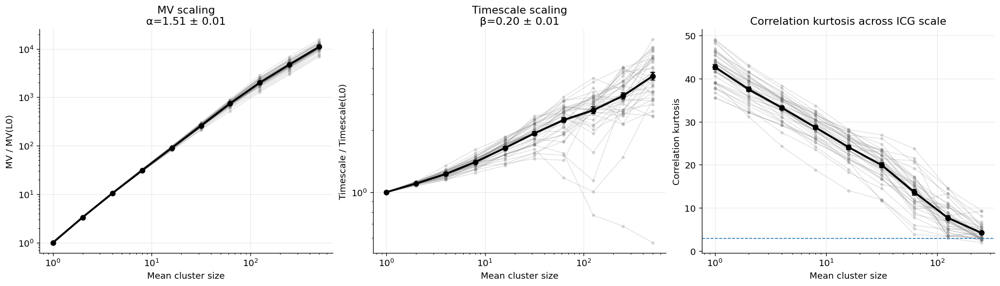

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/plots/single_regime_seed_level_exponents_activity.png


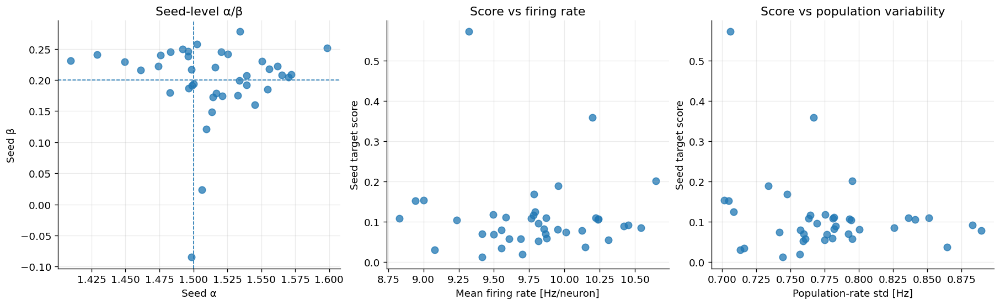

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/plots/single_regime_firing_rate_phase_like_dynamics.png


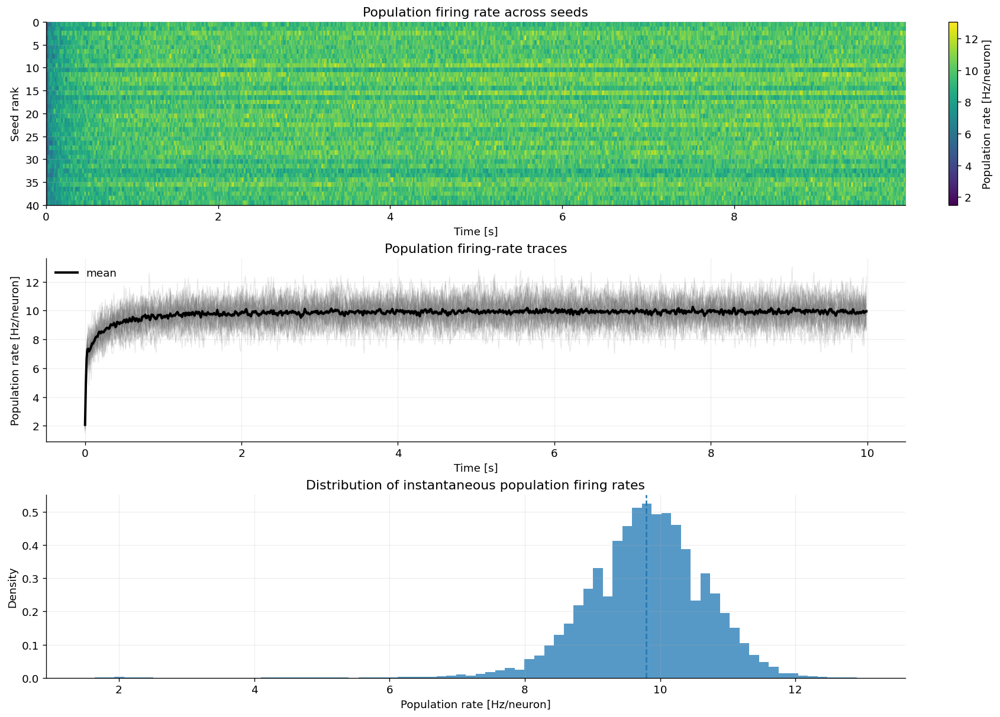

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/plots/single_regime_corr_distribution_ridgeline_by_icg_level.png


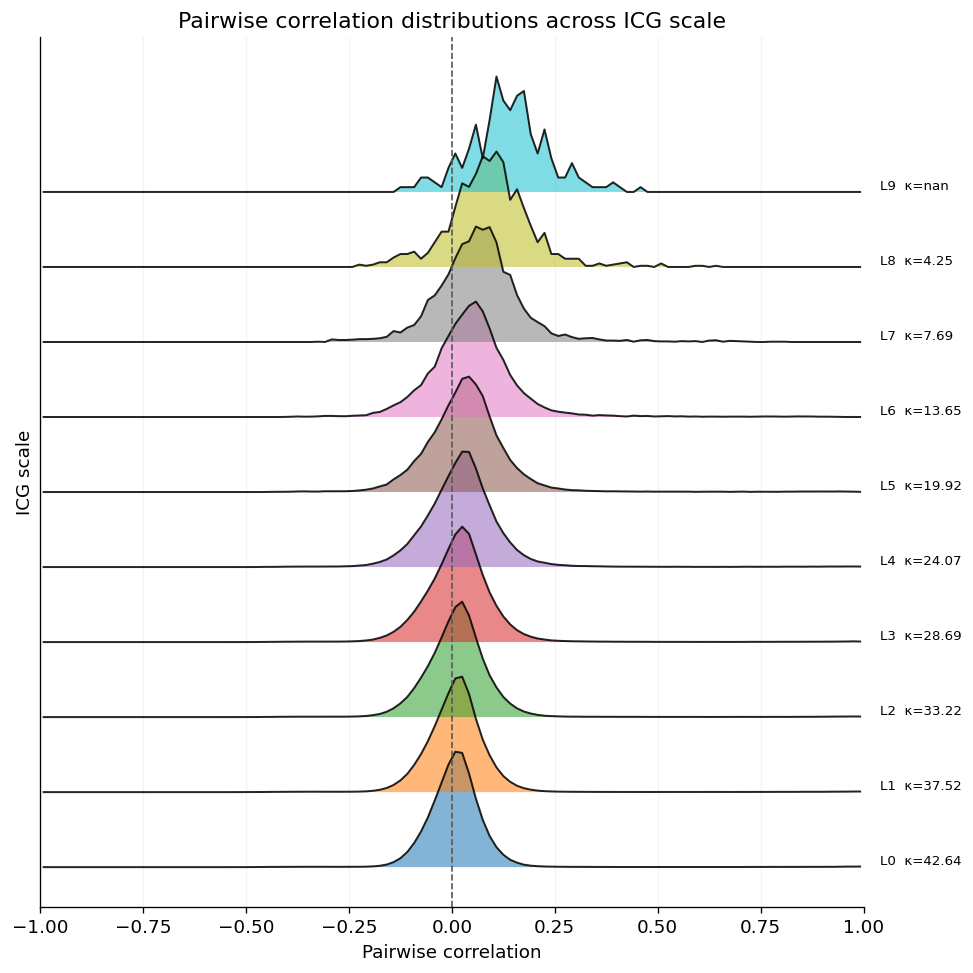

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/plots/single_regime_corr_kurtosis_scaling.png


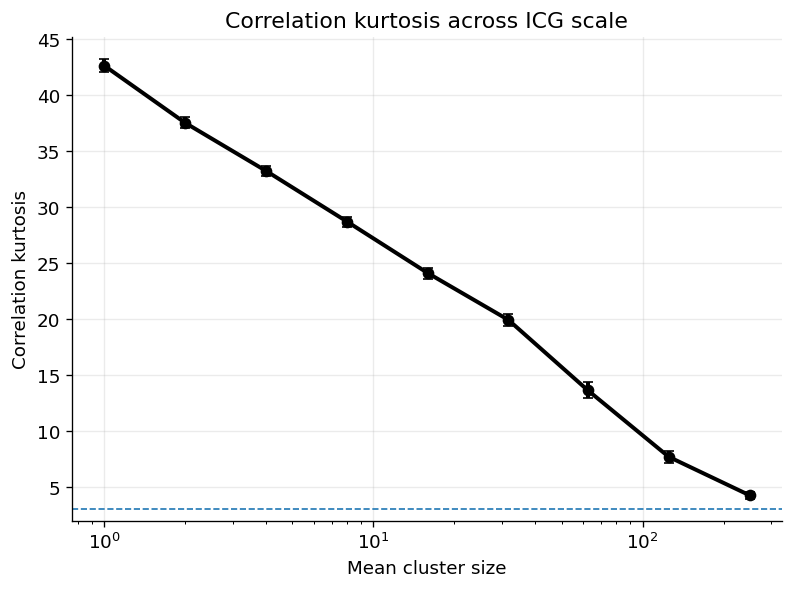


Done.
Summaries created:
  /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_summary.csv
  /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_generation_summary.csv
  /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/single_regime_40seed_population_rate_summary.csv
Plots: /home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005/plots


In [15]:
# ============================================================
# RESUME SINGLE-REGIME 40-SEED ANALYSIS FROM SAVED RAW OUTPUTS
#
# Does NOT rerun simulations.
#
# Loads:
#   seed metrics
#   generation metrics
#   corr distributions
#   population rates
#
# Recreates:
#   summary CSV
#   generation summary CSV
#   population summary CSV
#   scaling plots
#   firing-rate plots
#   correlation-distribution plots
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import icg_functions as fn


# ============================================================
# Paths/settings
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/single_regime_40seeds_phi4p33_theta8p44_pext0p02_smooth005")
PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

seed_path = OUTDIR / "single_regime_40seed_seed_metrics.csv"
gen_path = OUTDIR / "single_regime_40seed_generation_metrics.csv"
corr_path = OUTDIR / "single_regime_40seed_corr_distributions.csv"
pop_path = OUTDIR / "single_regime_40seed_population_rates.csv"

summary_path = OUTDIR / "single_regime_40seed_summary.csv"
gen_summary_path = OUTDIR / "single_regime_40seed_generation_summary.csv"
pop_summary_path = OUTDIR / "single_regime_40seed_population_rate_summary.csv"

print("Loading saved outputs...")
df = pd.read_csv(seed_path)
gen_all = pd.read_csv(gen_path)
pop_all = pd.read_csv(pop_path)

# 531 MB file; still okay, but this is the heaviest load
corr_all = pd.read_csv(corr_path)

df = df.replace([np.inf, -np.inf], np.nan)
gen_all = gen_all.replace([np.inf, -np.inf], np.nan)
pop_all = pop_all.replace([np.inf, -np.inf], np.nan)
corr_all = corr_all.replace([np.inf, -np.inf], np.nan)

print("Seed rows:", len(df), "unique seeds:", df["seed"].nunique())
print("Generation rows:", len(gen_all))
print("Population rows:", len(pop_all))
print("Correlation rows:", len(corr_all))


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


# ============================================================
# Summaries
# ============================================================

summary = pd.DataFrame([{
    "n": int(df["seed"].nunique()),

    "mv_alpha_norm_mean": float(df["mv_alpha_norm"].mean()),
    "mv_alpha_norm_sem": float(fn.sem(df["mv_alpha_norm"])),
    "mv_r2_norm_mean": float(df["mv_r2_norm"].mean()),
    "mv_r2_norm_sem": float(fn.sem(df["mv_r2_norm"])),

    "ts_beta_norm_mean": float(df["ts_beta_norm"].mean()),
    "ts_beta_norm_sem": float(fn.sem(df["ts_beta_norm"])),
    "ts_r2_norm_mean": float(df["ts_r2_norm"].mean()),
    "ts_r2_norm_sem": float(fn.sem(df["ts_r2_norm"])),

    "mv_alpha_mean": float(df["mv_alpha"].mean()),
    "mv_alpha_sem": float(fn.sem(df["mv_alpha"])),

    "ts_beta_mean": float(df["ts_beta"].mean()),
    "ts_beta_sem": float(fn.sem(df["ts_beta"])),

    "mean_rate_hz_mean": float(df["mean_rate_hz"].mean()),
    "mean_rate_hz_sem": float(fn.sem(df["mean_rate_hz"])),

    "pop_rate_mean_hz_mean": float(df["pop_rate_mean_hz"].mean()),
    "pop_rate_std_hz_mean": float(df["pop_rate_std_hz"].mean()),

    "frac_silent_frames_mean": float(df["frac_silent_frames"].mean()),
    "frac_active_neurons_mean": float(df["frac_active_neurons"].mean()),
}])

# add regime metadata from df if present
for col in ["regime", "phi", "theta", "p_ext", "smoothe", "p_self_zero_input"]:
    if col in df.columns:
        summary[col] = df[col].iloc[0]

summary["target_score_norm"] = (
    np.abs(summary["mv_alpha_norm_mean"] - TARGET_ALPHA)
    + 2.0 * np.abs(summary["ts_beta_norm_mean"] - TARGET_BETA)
)

summary.to_csv(summary_path, index=False)
gen_summary = (
    gen_all
    .groupby("gen", as_index=False)
    .agg(
        n=("seed", "count"),
        n_clusters_mean=("n_clusters", "mean"),
        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", fn.sem),

        mean_activity_mean=("mean_activity", "mean"),
        mean_activity_sem=("mean_activity", fn.sem),

        mean_variance_mean=("mean_variance", "mean"),
        mean_variance_sem=("mean_variance", fn.sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", fn.sem),

        timescale_mean=("timescale", "mean"),
        timescale_sem=("timescale", fn.sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", fn.sem),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", fn.sem),
    )
    .sort_values("gen")
    .reset_index(drop=True)
)

gen_summary.to_csv(gen_summary_path, index=False)

pop_summary = (
    pop_all
    .groupby("time_s", as_index=False)
    .agg(
        pop_rate_mean=("pop_rate_hz", "mean"),
        pop_rate_sem=("pop_rate_hz", fn.sem),
        pop_rate_std=("pop_rate_hz", "std"),
    )
)

pop_summary.to_csv(pop_summary_path, index=False)

print("\nSummary:")
print(summary.round(6).to_string(index=False))
print("\nSaved:", summary_path)
print("Saved:", gen_summary_path)
print("Saved:", pop_summary_path)


# ============================================================
# 1. Scaling curves: individual seeds + mean SEM
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for seed, g in gen_all.groupby("seed"):
    g = g.sort_values("gen")

    axes[0].plot(
        g["mean_cluster_size"],
        g["mean_variance_norm"],
        marker="o",
        markersize=3,
        linewidth=0.9,
        alpha=0.22,
        color="0.45",
    )

    axes[1].plot(
        g["mean_cluster_size"],
        g["timescale_norm"],
        marker="o",
        markersize=3,
        linewidth=0.9,
        alpha=0.22,
        color="0.45",
    )

    axes[2].plot(
        g["mean_cluster_size"],
        g["corr_kurtosis"],
        marker="o",
        markersize=3,
        linewidth=0.9,
        alpha=0.22,
        color="0.45",
    )

xg = gen_summary["mean_cluster_size_mean"].to_numpy()

axes[0].errorbar(
    xg,
    gen_summary["mean_variance_norm_mean"],
    yerr=gen_summary["mean_variance_norm_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

axes[1].errorbar(
    xg,
    gen_summary["timescale_norm_mean"],
    yerr=gen_summary["timescale_norm_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

axes[2].errorbar(
    xg,
    gen_summary["corr_kurtosis_mean"],
    yerr=gen_summary["corr_kurtosis_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

axes[0].set_title(
    f"MV scaling\nα={summary['mv_alpha_norm_mean'].iloc[0]:.2f} ± {summary['mv_alpha_norm_sem'].iloc[0]:.2f}"
)
axes[1].set_title(
    f"Timescale scaling\nβ={summary['ts_beta_norm_mean'].iloc[0]:.2f} ± {summary['ts_beta_norm_sem'].iloc[0]:.2f}"
)
axes[2].set_title("Correlation kurtosis across ICG scale")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

savefig(fig, "single_regime_scaling_curves_40seeds.png")
plt.show()


# ============================================================
# 2. Seed-level exponent/activity scatter
# ============================================================

df["target_score_seed"] = (
    np.abs(df["mv_alpha_norm"] - TARGET_ALPHA)
    + 2.0 * np.abs(df["ts_beta_norm"] - TARGET_BETA)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(
    df["mv_alpha_norm"],
    df["ts_beta_norm"],
    s=55,
    alpha=0.75,
)
axes[0].axvline(TARGET_ALPHA, linestyle="--", linewidth=1)
axes[0].axhline(TARGET_BETA, linestyle="--", linewidth=1)
axes[0].set_xlabel("Seed α")
axes[0].set_ylabel("Seed β")
axes[0].set_title("Seed-level α/β")

axes[1].scatter(
    df["mean_rate_hz"],
    df["target_score_seed"],
    s=55,
    alpha=0.75,
)
axes[1].set_xlabel("Mean firing rate [Hz/neuron]")
axes[1].set_ylabel("Seed target score")
axes[1].set_title("Score vs firing rate")

axes[2].scatter(
    df["pop_rate_std_hz"],
    df["target_score_seed"],
    s=55,
    alpha=0.75,
)
axes[2].set_xlabel("Population-rate std [Hz]")
axes[2].set_ylabel("Seed target score")
axes[2].set_title("Score vs population variability")

for ax in axes:
    ax.grid(alpha=0.25)

savefig(fig, "single_regime_seed_level_exponents_activity.png")
plt.show()


# ============================================================
# 3. Firing-rate dynamics / phase-like visualisation
# ============================================================

pop_piv = pop_all.pivot(index="seed", columns="time_s", values="pop_rate_hz")
pop_piv = pop_piv.sort_index()

time_vals = pop_piv.columns.to_numpy(dtype=float)
seed_vals = pop_piv.index.to_numpy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)

im = axes[0].imshow(
    pop_piv.values,
    aspect="auto",
    interpolation="nearest",
    extent=[time_vals.min(), time_vals.max(), len(seed_vals), 0],
)
axes[0].set_ylabel("Seed rank")
axes[0].set_xlabel("Time [s]")
axes[0].set_title("Population firing rate across seeds")
cbar = fig.colorbar(im, ax=axes[0])
cbar.set_label("Population rate [Hz/neuron]")

for seed, g in pop_all.groupby("seed"):
    axes[1].plot(
        g["time_s"],
        g["pop_rate_hz"],
        linewidth=0.7,
        alpha=0.18,
        color="0.45",
    )

axes[1].plot(
    pop_summary["time_s"],
    pop_summary["pop_rate_mean"],
    linewidth=2.4,
    color="black",
    label="mean",
)
axes[1].fill_between(
    pop_summary["time_s"],
    pop_summary["pop_rate_mean"] - pop_summary["pop_rate_sem"],
    pop_summary["pop_rate_mean"] + pop_summary["pop_rate_sem"],
    alpha=0.22,
    color="black",
)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Population rate [Hz/neuron]")
axes[1].set_title("Population firing-rate traces")
axes[1].legend(frameon=False)

axes[2].hist(
    pop_all["pop_rate_hz"].replace([np.inf, -np.inf], np.nan).dropna(),
    bins=80,
    density=True,
    alpha=0.75,
)
axes[2].axvline(pop_all["pop_rate_hz"].mean(), linestyle="--", linewidth=1.5)
axes[2].set_xlabel("Population rate [Hz/neuron]")
axes[2].set_ylabel("Density")
axes[2].set_title("Distribution of instantaneous population firing rates")

for ax in axes:
    ax.grid(alpha=0.2)

savefig(fig, "single_regime_firing_rate_phase_like_dynamics.png")
plt.show()


# ============================================================
# 4. Correlation distributions across ICG scale
# ============================================================

bins = np.linspace(-1, 1, 121)
levels = sorted(corr_all["gen"].dropna().unique())

fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)

offset_step = 0.65

for i, level in enumerate(levels):
    vals = corr_all.loc[corr_all["gen"] == level, "corr"].to_numpy()
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        continue

    hist, edges = np.histogram(vals, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])

    if hist.max() > 0:
        hist = hist / hist.max()

    y0 = i * offset_step
    y = hist + y0

    ax.fill_between(
        centers,
        y0,
        y,
        alpha=0.55,
        linewidth=0,
    )

    ax.plot(
        centers,
        y,
        linewidth=1.2,
        color="black",
        alpha=0.85,
    )

    kg = gen_summary.loc[gen_summary["gen"] == level, "corr_kurtosis_mean"]
    if len(kg) > 0:
        ktxt = f"L{int(level)}  κ={float(kg.iloc[0]):.2f}"
    else:
        ktxt = f"L{int(level)}"

    ax.text(
        1.04,
        y0,
        ktxt,
        va="bottom",
        ha="left",
        fontsize=8,
    )

ax.axvline(0, linestyle="--", linewidth=1.0, color="0.35")
ax.set_xlim(-1, 1)
ax.set_yticks([])
ax.set_xlabel("Pairwise correlation")
ax.set_ylabel("ICG scale")
ax.set_title("Pairwise correlation distributions across ICG scale")
ax.grid(axis="x", alpha=0.15)

savefig(fig, "single_regime_corr_distribution_ridgeline_by_icg_level.png")
plt.show()


# ============================================================
# 5. Correlation kurtosis alone
# ============================================================

fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)

ax.errorbar(
    gen_summary["mean_cluster_size_mean"],
    gen_summary["corr_kurtosis_mean"],
    yerr=gen_summary["corr_kurtosis_sem"],
    marker="o",
    linewidth=2.4,
    capsize=3,
    color="black",
)

ax.axhline(3.0, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Mean cluster size")
ax.set_ylabel("Correlation kurtosis")
ax.set_title("Correlation kurtosis across ICG scale")
ax.grid(alpha=0.25)

savefig(fig, "single_regime_corr_kurtosis_scaling.png")
plt.show()


print("\nDone.")
print("Summaries created:")
print(" ", summary_path)
print(" ", gen_summary_path)
print(" ", pop_summary_path)
print("Plots:", PLOTDIR)

PHI_VALUES: [2.         2.77777778 3.55555556 4.33333333 5.11111111 5.88888889
 6.66666667 7.44444444 8.22222222 9.        ]
N_SEEDS: 5
N_WORKERS: 10
smoothe: 0.05
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters


Running phi sweep:   0%|          | 0/50 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters/plots/phi_sweep_scaling_curves.png


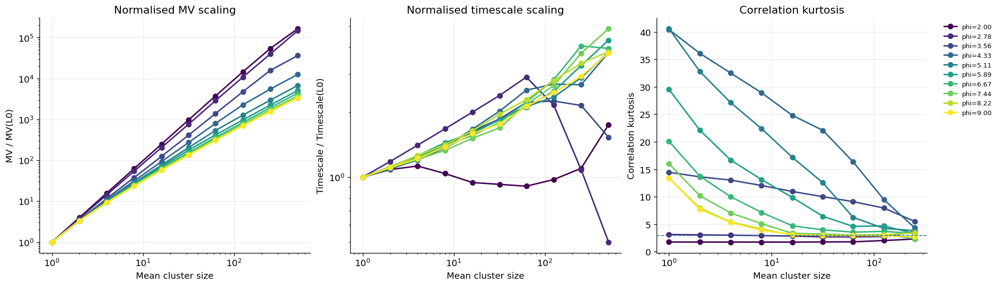

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters/plots/phi_sweep_firing_rate_vs_phi.png


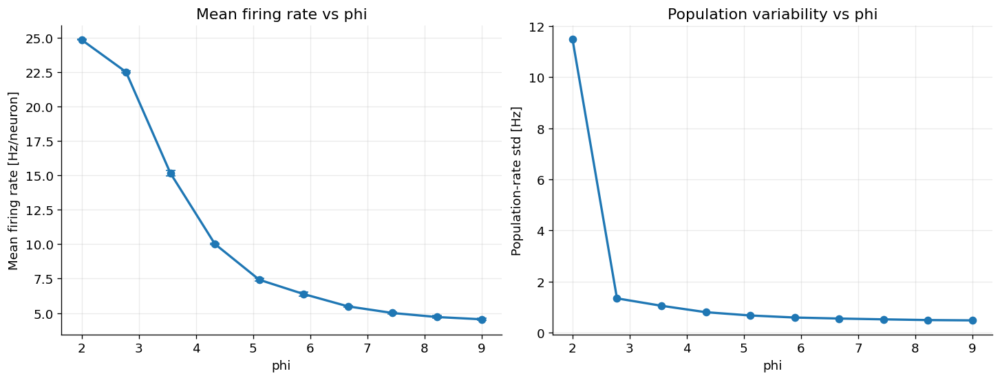

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters/plots/phi_sweep_rasters.png


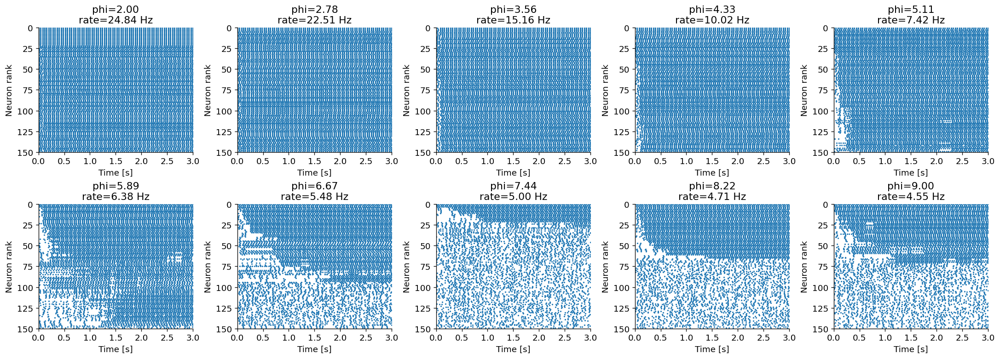


Done.
Saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters
Plots: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters/plots


In [17]:
#compare rasters and phase transition

# ============================================================
# PHI SWEEP FROM start_dic DEFAULTS
#   - vary phi from 2 -> 9 (10 values)
#   - 5 seeds per phi
#   - uses start_dic defaults for everything else
#   - uses exp smoothing from start_dic["smoothe"]
#   - plots:
#       1) normalised scaling curves
#       2) mean firing rate vs phi
#       3) one raw spike raster per phi
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_5seeds_rasters")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.linspace(2.0, 9.0, 10)
N_SEEDS = 5
N_WORKERS = 10
BASE_SEED = 910000

T_RUN = float(start_dic["T"])
SMOOTHE = float(start_dic.get("smoothe", 0.05))

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

# raster display settings
RASTER_SEED_INDEX = 0          # plot the first seed for each phi
RASTER_TMAX = min(3.0, T_RUN)  # seconds
RASTER_N_NEURONS = 150         # show top active neurons

print("PHI_VALUES:", PHI_VALUES)
print("N_SEEDS:", N_SEEDS)
print("N_WORKERS:", N_WORKERS)
print("smoothe:", SMOOTHE)
print("OUTDIR:", OUTDIR)


# ============================================================
# Helpers
# ============================================================

def make_pars_from_start(phi, seed):
    pars = dict(start_dic)

    if "slope" in pars and "phi" not in pars:
        pars["phi"] = float(pars.pop("slope"))
    else:
        pars.pop("slope", None)

    pars["phi"] = float(phi)
    pars["seed"] = int(seed)
    return pars


def model_outs_local(pars, seed):
    """
    Minimal local wrapper using fn functions.
    Pops T and smoothe before model construction.
    """
    pars = dict(pars)

    T = float(pars.pop("T"))
    smoothe = float(pars.pop("smoothe", 0.05))
    pars["seed"] = int(seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T)

    mean_rate_hz = float(spikes.mean() / float(pars["dt"]))
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    spikes_icg = fn.exp_smooth_spikes(
        spikes,
        dt=float(pars["dt"]),
        tau=smoothe,
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=spikes_icg,
        dt=float(pars["dt"]),
    )

    out = {
        "phi": float(pars["phi"]),
        "seed": int(seed),

        "n_neurons": int(pars["n_neurons"]),
        "dt": float(pars["dt"]),
        "T": T,

        "theta": float(pars["theta"]),
        "p_ext": float(pars["p_ext"]),
        "ei_ratio": float(pars["ei_ratio"]),
        "e_w": float(pars["e_w"]),
        "i_w": float(pars["i_w"]),
        "refractory_steps": int(pars["refractory_steps"]),
        "smoothe": float(smoothe),

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,
    }
    out.update(metric_row)

    gen_df["phi"] = float(pars["phi"])
    gen_df["seed"] = int(seed)
    gen_df["smoothe"] = float(smoothe)

    return out, gen_df, spikes, pop_rate


def run_one(job):
    phi, seed, seed_idx = job
    pars = make_pars_from_start(phi=phi, seed=seed)

    out, gen_df, spikes, pop_rate = model_outs_local(pars, seed=seed)

    raster_df = None
    if seed_idx == RASTER_SEED_INDEX:
        dt = float(pars["dt"])
        t = np.arange(spikes.shape[1]) * dt
        keep_t = t <= RASTER_TMAX
        spikes_w = spikes[:, keep_t]

        counts = spikes_w.sum(axis=1)
        order = np.argsort(counts)[::-1]
        show_idx = order[:RASTER_N_NEURONS]
        spikes_show = spikes_w[show_idx]

        raster_df = pd.DataFrame({
            "phi": float(phi),
            "seed": int(seed),
            "neuron_rank": np.repeat(np.arange(spikes_show.shape[0]), spikes_show.shape[1]),
            "time_s": np.tile(t[keep_t], spikes_show.shape[0]),
            "spike": spikes_show.reshape(-1),
        })

    return out, gen_df, raster_df


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# Build jobs
# ============================================================

jobs = []
job_i = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + job_i
        jobs.append((float(phi), int(seed), int(seed_idx)))
        job_i += 1

design = pd.DataFrame(jobs, columns=["phi", "seed", "seed_idx"])
design.to_csv(OUTDIR / "phi_sweep_design.csv", index=False)


# ============================================================
# Run
# ============================================================

ctx = mp.get_context("fork")

rows = []
gen_rows = []
raster_rows = []

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for out, gen_df, raster_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Running phi sweep",
    ):
        rows.append(out)
        gen_rows.append(gen_df)
        if raster_df is not None:
            raster_rows.append(raster_df)

df = (
    pd.DataFrame(rows)
    .sort_values(["phi", "seed"])
    .reset_index(drop=True)
)

gen_all = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["phi", "seed", "gen"])
    .reset_index(drop=True)
)

if len(raster_rows) > 0:
    raster_all = pd.concat(raster_rows, ignore_index=True)
else:
    raster_all = pd.DataFrame(columns=["phi", "seed", "neuron_rank", "time_s", "spike"])

df.to_csv(OUTDIR / "phi_sweep_seed_metrics.csv", index=False)
gen_all.to_csv(OUTDIR / "phi_sweep_generation_metrics.csv", index=False)
raster_all.to_csv(OUTDIR / "phi_sweep_raster_data.csv", index=False)


# ============================================================
# Summaries
# ============================================================

summary = (
    df
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        mv_alpha_norm_mean=("mv_alpha_norm", "mean"),
        mv_alpha_norm_sem=("mv_alpha_norm", fn.sem),
        ts_beta_norm_mean=("ts_beta_norm", "mean"),
        ts_beta_norm_sem=("ts_beta_norm", fn.sem),

        mv_r2_norm_mean=("mv_r2_norm", "mean"),
        ts_r2_norm_mean=("ts_r2_norm", "mean"),

        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", fn.sem),

        pop_rate_mean_hz_mean=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz_mean=("pop_rate_std_hz", "mean"),

        frac_silent_frames_mean=("frac_silent_frames", "mean"),
        frac_active_neurons_mean=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

summary["target_score_norm"] = (
    np.abs(summary["mv_alpha_norm_mean"] - TARGET_ALPHA)
    + 2.0 * np.abs(summary["ts_beta_norm_mean"] - TARGET_BETA)
)

gen_summary = (
    gen_all
    .groupby(["phi", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),
        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", fn.sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", fn.sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", fn.sem),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", fn.sem),
    )
    .sort_values(["phi", "gen"])
    .reset_index(drop=True)
)

summary.to_csv(OUTDIR / "phi_sweep_summary.csv", index=False)
gen_summary.to_csv(OUTDIR / "phi_sweep_generation_summary.csv", index=False)


# ============================================================
# Plotting
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


# ------------------------------------------------------------
# 1. Scaling curves
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

phis = np.sort(summary["phi"].unique())
cmap = plt.cm.viridis
norm = plt.Normalize(vmin=phis.min(), vmax=phis.max())

for phi in phis:
    gg = gen_summary[gen_summary["phi"] == phi].sort_values("gen")
    c = cmap(norm(phi))
    label = f"phi={phi:.2f}"

    x = gg["mean_cluster_size_mean"].to_numpy()

    axes[0].plot(x, gg["mean_variance_norm_mean"], marker="o", linewidth=1.8, color=c, label=label)
    axes[1].plot(x, gg["timescale_norm_mean"], marker="o", linewidth=1.8, color=c, label=label)
    axes[2].plot(x, gg["corr_kurtosis_mean"], marker="o", linewidth=1.8, color=c, label=label)

axes[0].set_title("Normalised MV scaling")
axes[1].set_title("Normalised timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

axes[2].legend(frameon=False, fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")

savefig(fig, "phi_sweep_scaling_curves.png")
plt.show()


# ------------------------------------------------------------
# 2. Mean firing rate vs phi
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].errorbar(
    summary["phi"],
    summary["mean_rate_hz_mean"],
    yerr=summary["mean_rate_hz_sem"],
    marker="o",
    linewidth=2,
    capsize=4,
)
axes[0].set_xlabel("phi")
axes[0].set_ylabel("Mean firing rate [Hz/neuron]")
axes[0].set_title("Mean firing rate vs phi")
axes[0].grid(alpha=0.25)

axes[1].plot(summary["phi"], summary["pop_rate_std_hz_mean"], marker="o", linewidth=2)
axes[1].set_xlabel("phi")
axes[1].set_ylabel("Population-rate std [Hz]")
axes[1].set_title("Population variability vs phi")
axes[1].grid(alpha=0.25)

savefig(fig, "phi_sweep_firing_rate_vs_phi.png")
plt.show()


# ------------------------------------------------------------
# 3. Raster plots (one seed per phi)
# ------------------------------------------------------------

ncols = 5
nrows = int(np.ceil(len(phis) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.2 * nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, phi in zip(axes, phis):
    rr = raster_all[raster_all["phi"] == phi]
    rr = rr[rr["spike"] > 0]

    ax.scatter(
        rr["time_s"],
        rr["neuron_rank"],
        s=1,
        alpha=0.9,
    )

    fr = summary.loc[np.isclose(summary["phi"], phi), "mean_rate_hz_mean"].iloc[0]

    ax.set_title(f"phi={phi:.2f}\nrate={fr:.2f} Hz")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Neuron rank")
    ax.set_xlim(0, RASTER_TMAX)
    ax.set_ylim(RASTER_N_NEURONS, 0)

for ax in axes[len(phis):]:
    ax.axis("off")

savefig(fig, "phi_sweep_rasters.png")
plt.show()


print("\nDone.")
print("Saved to:", OUTDIR)
print("Plots:", PLOTDIR)

PHI_VALUES: [2.         2.77777778 3.55555556 4.33333333 5.11111111 5.88888889
 6.66666667 7.44444444 8.22222222 9.        ]
N_SEEDS: 3
T_RUN: 10.0
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_3seeds_full_rasters


Running phi rasters:   0%|          | 0/30 [00:00<?, ?it/s]

Saved metrics: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_3seeds_full_rasters/phi_sweep_seed_metrics.csv
Saved rasters: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_3seeds_full_rasters/phi_sweep_raster_events.csv


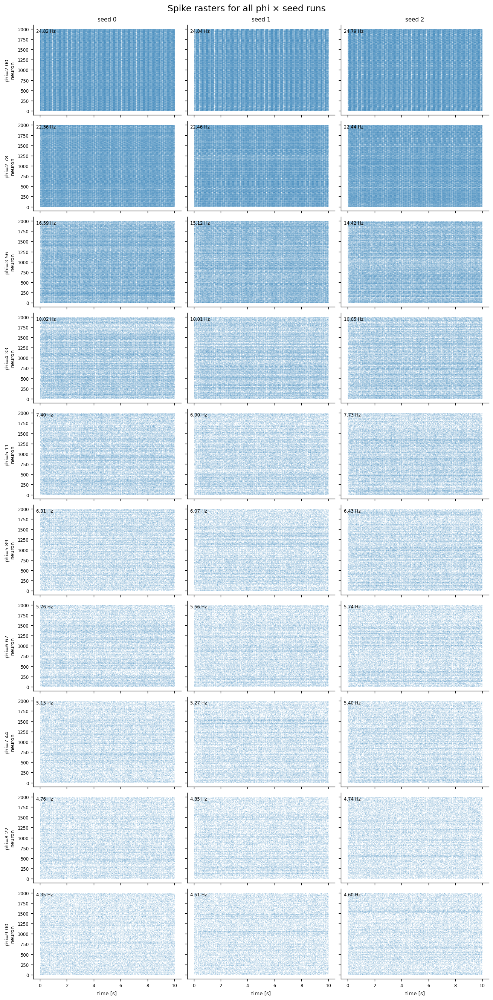

Saved plot: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_3seeds_full_rasters/plots/phi_sweep_all_rasters_3seeds_per_phi.png


In [19]:
# ============================================================
# PHI SWEEP: 3 seeds per phi + plot every raster
#   - assumes start_dic exists
#   - assumes icg_functions.py is importable as fn
#   - runs model only; no ICG metrics here
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import icg_functions as fn


# ----------------------------
# Settings
# ----------------------------
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_sweep_2to9_10vals_3seeds_full_rasters")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.linspace(2.0, 9.0, 10)
N_SEEDS = 3
N_WORKERS = 10
BASE_SEED = 920000

T_RUN = float(start_dic["T"])

print("PHI_VALUES:", PHI_VALUES)
print("N_SEEDS:", N_SEEDS)
print("T_RUN:", T_RUN)
print("OUTDIR:", OUTDIR)


# ----------------------------
# Helpers
# ----------------------------
def make_pars_from_start(phi, seed):
    pars = dict(start_dic)

    # allow either old "slope" name or newer "phi" name
    if "slope" in pars:
        pars.pop("slope")

    pars["phi"] = float(phi)
    pars["seed"] = int(seed)

    return pars


def run_one(job):
    phi, seed, seed_idx = job

    pars = make_pars_from_start(phi, seed)

    T = float(pars.pop("T"))
    pars.pop("smoothe", None)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T)

    dt = float(pars["dt"])
    mean_rate_hz = float(spikes.mean() / dt)

    neuron_idx, time_idx = np.where(spikes > 0)

    raster_df = pd.DataFrame({
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),
        "neuron": neuron_idx.astype(int),
        "time_s": time_idx.astype(float) * dt,
    })

    metric = {
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),
        "mean_rate_hz": mean_rate_hz,
        "n_spikes": int(len(neuron_idx)),
        "n_neurons": int(spikes.shape[0]),
        "n_timebins": int(spikes.shape[1]),
        "dt": dt,
        "T": T,
    }

    return metric, raster_df


# ----------------------------
# Build jobs
# ----------------------------
jobs = []
job_i = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + job_i
        jobs.append((float(phi), int(seed), int(seed_idx)))
        job_i += 1

design = pd.DataFrame(jobs, columns=["phi", "seed", "seed_idx"])
design.to_csv(OUTDIR / "phi_sweep_design.csv", index=False)


# ----------------------------
# Run
# ----------------------------
rows = []
raster_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for metric, raster_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Running phi rasters",
    ):
        rows.append(metric)
        raster_rows.append(raster_df)

metrics = (
    pd.DataFrame(rows)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

raster_all = (
    pd.concat(raster_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "time_s", "neuron"])
    .reset_index(drop=True)
)

metrics.to_csv(OUTDIR / "phi_sweep_seed_metrics.csv", index=False)
raster_all.to_csv(OUTDIR / "phi_sweep_raster_events.csv", index=False)

print("Saved metrics:", OUTDIR / "phi_sweep_seed_metrics.csv")
print("Saved rasters:", OUTDIR / "phi_sweep_raster_events.csv")


# ============================================================
# Plot every raster
#   rows = phi
#   columns = seed_idx
# ============================================================

phis = np.sort(metrics["phi"].unique())
seed_idxs = np.sort(metrics["seed_idx"].unique())

n_phi = len(phis)
n_seed = len(seed_idxs)

fig, axes = plt.subplots(
    n_phi,
    n_seed,
    figsize=(3.6 * n_seed, 2.2 * n_phi),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

if n_phi == 1:
    axes = axes[None, :]
if n_seed == 1:
    axes = axes[:, None]

for i, phi in enumerate(phis):
    for j, seed_idx in enumerate(seed_idxs):
        ax = axes[i, j]

        rr = raster_all[
            (np.isclose(raster_all["phi"], phi)) &
            (raster_all["seed_idx"] == seed_idx)
        ]

        ax.scatter(
            rr["time_s"],
            rr["neuron"],
            s=0.15,
            marker=".",
            linewidths=0,
        )

        fr = metrics[
            (np.isclose(metrics["phi"], phi)) &
            (metrics["seed_idx"] == seed_idx)
        ]["mean_rate_hz"].iloc[0]

        if i == 0:
            ax.set_title(f"seed {seed_idx}", fontsize=9)

        if j == 0:
            ax.set_ylabel(f"phi={phi:.2f}\nneuron", fontsize=8)

        if i == n_phi - 1:
            ax.set_xlabel("time [s]", fontsize=8)

        ax.text(
            0.02,
            0.96,
            f"{fr:.2f} Hz",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7,
        )

        ax.tick_params(labelsize=7)

fig.suptitle("Spike rasters for all phi × seed runs", fontsize=14)

outpath = PLOTDIR / "phi_sweep_all_rasters_3seeds_per_phi.png"
fig.savefig(outpath, dpi=300, bbox_inches="tight")
plt.show()

print("Saved plot:", outpath)

N_REAL: 20
N_NULL_TOTAL: 200
T_RUN: 10.0
SMOOTHE: 0.05
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling


Running real + null shuffle tests:   0%|          | 0/20 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling/real_vs_shuffle_seed_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling/real_vs_shuffle_generation_metrics.csv


,condition,n,mv_alpha_norm_mean,mv_alpha_norm_sem,ts_beta_norm_mean,ts_beta_norm_sem,mv_r2_norm_mean,ts_r2_norm_mean,mean_rate_hz_mean,mean_rate_hz_sem
0,null_shuffle,200,1.259496,0.000269,0.166676,0.007046,0.999878,0.762587,9.718068,0.042318
1,real,20,1.512474,0.010901,0.178037,0.019573,0.998672,0.835640,9.718068,0.136954


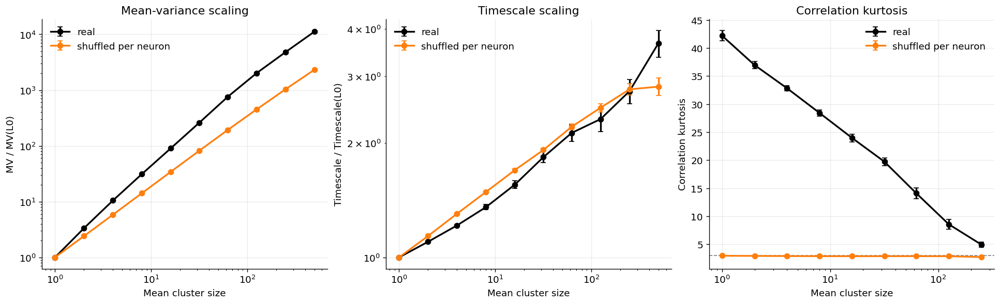

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling/plots/real_vs_shuffle_scaling_forms.png


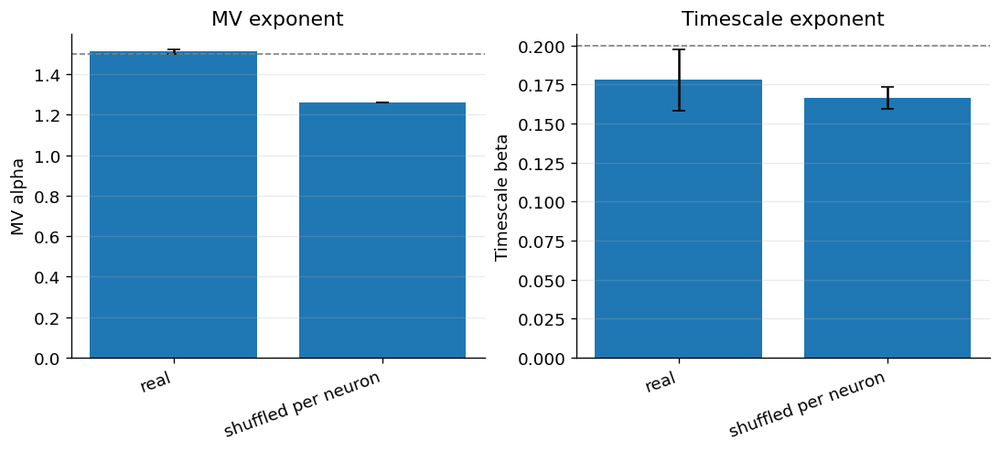

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling/plots/real_vs_shuffle_exponents.png
Done: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling


In [24]:
#null models     

# ============================================================
# QUICK NULL TEST:
#   10 real simulations from start_dic
#   50 nulls = 5 shuffled-neuron nulls per real sim
#
# Null model:
#   independently shuffle each neuron's activity over time
#   preserves each neuron's spike count / firing rate
#   destroys precise temporal coordination
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import icg_functions as fn


# ----------------------------
# Settings
# ----------------------------
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_null_shuffle_scaling")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

N_REAL = 20
N_NULL_PER_REAL = 10
N_WORKERS = 10
BASE_SEED = 930000

SMOOTHE = float(start_dic.get("smoothe", 0.05))
T_RUN = float(start_dic["T"])

print("N_REAL:", N_REAL)
print("N_NULL_TOTAL:", N_REAL * N_NULL_PER_REAL)
print("T_RUN:", T_RUN)
print("SMOOTHE:", SMOOTHE)
print("OUTDIR:", OUTDIR)


# ----------------------------
# Helpers
# ----------------------------
def make_model_pars(seed):
    pars = dict(start_dic)

    # handle old/new naming
    if "slope" in pars and "phi" not in pars:
        pars["phi"] = float(pars.pop("slope"))
    else:
        pars.pop("slope", None)

    T = float(pars.pop("T"))
    smoothe = float(pars.pop("smoothe", SMOOTHE))

    pars["seed"] = int(seed)

    return pars, T, smoothe


def shuffle_each_neuron(spikes, rng):
    """
    Shuffle each neuron's time series independently.
    Preserves per-neuron spike count, destroys timing relationships.
    """
    X = np.asarray(spikes).copy()

    for i in range(X.shape[0]):
        rng.shuffle(X[i])

    return X


def compute_metrics_for_spikes(spikes, dt, smoothe):
    X = fn.exp_smooth_spikes(
        spikes,
        dt=float(dt),
        tau=float(smoothe),
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=X,
        dt=float(dt),
    )

    return metric_row, gen_df


def run_one_real(job):
    real_idx, seed = job

    pars, T, smoothe = make_model_pars(seed)
    model = fn.automata_EI_hiermod(**pars)

    spikes, pop_rate = fn.run_model(model, T=T)

    dt = float(pars["dt"])
    mean_rate_hz = float(spikes.mean() / dt)

    metric_row, gen_df = compute_metrics_for_spikes(
        spikes=spikes,
        dt=dt,
        smoothe=smoothe,
    )

    out = {
        "condition": "real",
        "real_idx": int(real_idx),
        "null_idx": -1,
        "seed": int(seed),
        "shuffle_seed": -1,
        "mean_rate_hz": mean_rate_hz,
        "dt": dt,
        "T": T,
        "smoothe": smoothe,
    }
    out.update(metric_row)

    gen_df = gen_df.copy()
    gen_df["condition"] = "real"
    gen_df["real_idx"] = int(real_idx)
    gen_df["null_idx"] = -1
    gen_df["seed"] = int(seed)
    gen_df["shuffle_seed"] = -1
    gen_df["mean_rate_hz"] = mean_rate_hz

    null_rows = []
    null_gen_rows = []

    for null_idx in range(N_NULL_PER_REAL):
        shuffle_seed = seed + 100000 + null_idx
        rng = np.random.default_rng(shuffle_seed)

        spikes_null = shuffle_each_neuron(spikes, rng)

        null_metric_row, null_gen_df = compute_metrics_for_spikes(
            spikes=spikes_null,
            dt=dt,
            smoothe=smoothe,
        )

        null_out = {
            "condition": "null_shuffle",
            "real_idx": int(real_idx),
            "null_idx": int(null_idx),
            "seed": int(seed),
            "shuffle_seed": int(shuffle_seed),
            "mean_rate_hz": float(spikes_null.mean() / dt),
            "dt": dt,
            "T": T,
            "smoothe": smoothe,
        }
        null_out.update(null_metric_row)

        null_gen_df = null_gen_df.copy()
        null_gen_df["condition"] = "null_shuffle"
        null_gen_df["real_idx"] = int(real_idx)
        null_gen_df["null_idx"] = int(null_idx)
        null_gen_df["seed"] = int(seed)
        null_gen_df["shuffle_seed"] = int(shuffle_seed)
        null_gen_df["mean_rate_hz"] = float(spikes_null.mean() / dt)

        null_rows.append(null_out)
        null_gen_rows.append(null_gen_df)

    rows = [out] + null_rows
    gen_rows = [gen_df] + null_gen_rows

    return rows, gen_rows


def sem(x):
    x = pd.Series(x).dropna().to_numpy()
    if len(x) <= 1:
        return np.nan
    return float(np.std(x, ddof=1) / np.sqrt(len(x)))


# ----------------------------
# Run
# ----------------------------
jobs = [(i, BASE_SEED + i) for i in range(N_REAL)]

all_rows = []
all_gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for rows, gen_rows in tqdm(
        pool.imap_unordered(run_one_real, jobs, chunksize=1),
        total=len(jobs),
        desc="Running real + null shuffle tests",
    ):
        all_rows.extend(rows)
        all_gen_rows.extend(gen_rows)

df = (
    pd.DataFrame(all_rows)
    .sort_values(["condition", "real_idx", "null_idx"])
    .reset_index(drop=True)
)

gen_all = (
    pd.concat(all_gen_rows, ignore_index=True)
    .sort_values(["condition", "real_idx", "null_idx", "gen"])
    .reset_index(drop=True)
)

df.to_csv(OUTDIR / "real_vs_shuffle_seed_metrics.csv", index=False)
gen_all.to_csv(OUTDIR / "real_vs_shuffle_generation_metrics.csv", index=False)

print("Saved:", OUTDIR / "real_vs_shuffle_seed_metrics.csv")
print("Saved:", OUTDIR / "real_vs_shuffle_generation_metrics.csv")


# ----------------------------
# Summaries
# ----------------------------
summary = (
    df
    .groupby("condition", as_index=False)
    .agg(
        n=("seed", "count"),

        mv_alpha_norm_mean=("mv_alpha_norm", "mean"),
        mv_alpha_norm_sem=("mv_alpha_norm", sem),
        ts_beta_norm_mean=("ts_beta_norm", "mean"),
        ts_beta_norm_sem=("ts_beta_norm", sem),

        mv_r2_norm_mean=("mv_r2_norm", "mean"),
        ts_r2_norm_mean=("ts_r2_norm", "mean"),

        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),
    )
)

gen_summary = (
    gen_all
    .groupby(["condition", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),

        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", sem),
    )
)

summary.to_csv(OUTDIR / "real_vs_shuffle_summary.csv", index=False)
gen_summary.to_csv(OUTDIR / "real_vs_shuffle_generation_summary.csv", index=False)

display(summary)


# ============================================================
# Plot scaling forms
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

colors = {
    "real": "black",
    "null_shuffle": "tab:orange",
}

labels = {
    "real": "real",
    "null_shuffle": "shuffled per neuron",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for condition in ["real", "null_shuffle"]:
    gg = gen_summary[gen_summary["condition"] == condition].sort_values("gen")

    x = gg["mean_cluster_size_mean"].to_numpy()

    axes[0].errorbar(
        x,
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

    axes[1].errorbar(
        x,
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

    axes[2].errorbar(
        x,
        gg["corr_kurtosis_mean"],
        yerr=gg["corr_kurtosis_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

axes[0].set_title("Mean-variance scaling")
axes[1].set_title("Timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1, color="grey")

outpath = PLOTDIR / "real_vs_shuffle_scaling_forms.png"
fig.savefig(outpath, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", outpath)


# ============================================================
# Plot fitted exponents
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)

plot_df = summary.set_index("condition").loc[["real", "null_shuffle"]].reset_index()

x = np.arange(len(plot_df))

axes[0].bar(
    x,
    plot_df["mv_alpha_norm_mean"],
    yerr=plot_df["mv_alpha_norm_sem"],
    capsize=4,
)
axes[0].axhline(1.5, linestyle="--", linewidth=1, color="grey")
axes[0].set_xticks(x)
axes[0].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[0].set_ylabel("MV alpha")
axes[0].set_title("MV exponent")

axes[1].bar(
    x,
    plot_df["ts_beta_norm_mean"],
    yerr=plot_df["ts_beta_norm_sem"],
    capsize=4,
)
axes[1].axhline(0.2, linestyle="--", linewidth=1, color="grey")
axes[1].set_xticks(x)
axes[1].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[1].set_ylabel("Timescale beta")
axes[1].set_title("Timescale exponent")

for ax in axes:
    ax.grid(alpha=0.25, axis="y")

outpath = PLOTDIR / "real_vs_shuffle_exponents.png"
fig.savefig(outpath, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", outpath)
print("Done:", OUTDIR)

# Fig 1

In [ ]:
import json, multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import expit
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm

import icg_functions as fn



# ============================================================
# Settings: phi sweep, multiprocessing over network seeds
# ============================================================
N_WORKERS = 20
N_SEEDS_PER_PHI = 50
N_AVALANCHES_PER_NETWORK = 10000
MAX_STEPS = 1000
BASE_SEED = 93939

PHI_VALUES = np.linspace(2.5, 4.5, 20)

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "new_ew11p7_iw22p4_phi2p5to4p5_N2000_20phis_50seeds_10000avals_max1000"
)
OUTDIR.mkdir(parents=True, exist_ok=True)


start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 11.7,
    "i_w": 22.4,
    "theta": 8.44,
    "p_ext": 0.02,
    "phi": 4.2,
    "smoothe": 0.05,

}

AVALANCHE_P_EXT = 0.0
DT = float(start_dic["dt"])
MAX_TIME_S = MAX_STEPS * DT

design_df = pd.DataFrame([
    {
        "network_id": int(i),
        "phi": float(phi),
        "seed": int(seed),
    }
    for i, (phi, seed) in enumerate(
        (p, s) for p in PHI_VALUES for s in range(N_SEEDS_PER_PHI)
    )
])

design_df.to_csv(OUTDIR / "design.csv", index=False)


with open(OUTDIR / "config.json", "w") as f:
    json.dump(
        {
            "N_WORKERS": int(N_WORKERS),
            "N_SEEDS_PER_PHI": int(N_SEEDS_PER_PHI),
            "N_AVALANCHES_PER_NETWORK": int(N_AVALANCHES_PER_NETWORK),
            "MAX_STEPS": int(MAX_STEPS),
            "MAX_TIME_S": float(MAX_TIME_S),
            "BASE_SEED": int(BASE_SEED),
            "PHI_VALUES": PHI_VALUES.tolist(),
            "AVALANCHE_P_EXT": float(AVALANCHE_P_EXT),
            "start_dic": start_dic,
            "sweep_description": (
                "Avalanche extinction/persistence sweep over phi in "
                "hierarchical modular E/I automata network."
            ),
        },
        f,
        indent=2,
    )

# ============================================================
# Helpers
# ============================================================

def safe_values(x):
    return (
        pd.Series(x)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .to_numpy(float)
    )


def safe_mean(x):
    x = safe_values(x)
    return float(np.mean(x)) if x.size else np.nan


def safe_percentile(x, q):
    x = safe_values(x)
    return float(np.percentile(x, q)) if x.size else np.nan


def safe_cv(x):
    x = safe_values(x)
    if x.size < 2:
        return np.nan
    mu = float(np.mean(x))
    return float(np.std(x, ddof=1) / mu) if mu > 0 and np.isfinite(mu) else np.nan


def local_connectivity_metrics(A, n_e):
    A_e_all = A[:n_e, :]
    A_ee = A[:n_e, :n_e]
    return {
        "edge_count": int(A.sum()),
        "mean_out_degree": float(A.sum(axis=1).mean()),
        "mean_e_out_degree_all": float(A_e_all.sum(axis=1).mean()),
        "mean_e_out_degree_e": float(A_ee.sum(axis=1).mean()),
        "edge_density": float(A.sum() / max(A.shape[0] * (A.shape[0] - 1), 1)),
    }


# ============================================================
# Seeded avalanche runner
# ============================================================

def run_seeded_avalanche_sparse(
    A_e_T,
    A_i_T,
    n,
    n_e,
    e_w,
    i_w,
    theta,
    refractory_steps,
    dt,
    seed_node,
    rng,
    max_steps,
):
    state = np.zeros(n, dtype=np.int16)
    state[int(seed_node)] = 1

    size = 0
    peak_active = 1

    for step in range(int(max_steps)):
        active = state == 1
        n_active = int(active.sum())

        if n_active == 0:
            return {
                "size": int(size),
                "lifetime_steps": int(step),
                "lifetime_s": float(step * dt),
                "peak_active": int(peak_active),
                "extinct": True,
                "persistent_at_cutoff": False,
            }

        size += n_active
        peak_active = max(peak_active, n_active)

        active_e = active[:n_e].astype(np.float32)
        active_i = active[n_e:].astype(np.float32)

        inp_e = A_e_T @ active_e
        inp_i = A_i_T @ active_i

        net = (e_w * inp_e) - (i_w * inp_i)
        p_net = expit(net - theta)

        has_active_presynaptic_input = (inp_e > 0) | (inp_i > 0)
        p_net[~has_active_presynaptic_input] = 0.0

        quiescent = state == 0
        new_active = quiescent & (rng.random(n) < p_net)

        new_state = np.zeros_like(state)
        new_state[active] = 2

        refractory = state >= 2
        new_state[refractory] = state[refractory] + 1

        done_refrac = new_state > (refractory_steps + 1)
        new_state[done_refrac] = 0

        new_state[new_active] = 1
        state = new_state

        if not np.any(state == 1):
            return {
                "size": int(size),
                "lifetime_steps": int(step + 1),
                "lifetime_s": float((step + 1) * dt),
                "peak_active": int(peak_active),
                "extinct": True,
                "persistent_at_cutoff": False,
            }

    return {
        "size": int(size),
        "lifetime_steps": int(max_steps),
        "lifetime_s": float(max_steps * dt),
        "peak_active": int(peak_active),
        "extinct": False,
        "persistent_at_cutoff": True,
    }


# ============================================================
# One network seed job
# ============================================================

def run_one_network_job(job):
    network_id = int(job["network_id"])
    phi = float(job["phi"])
    seed = int(job["seed"])

    pars = dict(start_dic)
    pars["phi"] = phi
    pars["p_ext"] = AVALANCHE_P_EXT

    model_kwargs = {
        k: v for k, v in pars.items()
        if k not in {"T", "smoothe"}
    }

    network_seed = int(BASE_SEED + int(round(phi * 1000)) * 100000 + seed * 1000)
    model_kwargs["seed"] = network_seed

    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**model_kwargs)

    A = np.asarray(model.A, dtype=np.uint8)
    np.fill_diagonal(A, 0)

    n = int(model.n)
    n_e = int(model.e)

    A_e_T = sparse.csr_matrix(A[:n_e, :].T.astype(np.float32))
    A_i_T = sparse.csr_matrix(A[n_e:, :].T.astype(np.float32))

    conn = local_connectivity_metrics(A, n_e)
    rng = np.random.default_rng(network_seed + 123)

    rows = []

    for aval_i in range(N_AVALANCHES_PER_NETWORK):
        seed_node = int(rng.integers(0, n_e))

        out = run_seeded_avalanche_sparse(
            A_e_T=A_e_T,
            A_i_T=A_i_T,
            n=n,
            n_e=n_e,
            e_w=float(model.e_w),
            i_w=float(model.i_w),
            theta=float(model.theta),
            refractory_steps=int(model.refractory_steps),
            dt=float(model.dt),
            seed_node=seed_node,
            rng=rng,
            max_steps=MAX_STEPS,
        )

        row = {
            "network_id": network_id,
            "aval_i": int(aval_i),
            "network_seed": network_seed,
            "seed": seed,
            "seed_node": seed_node,

            "n_neurons": n,
            "n_e": n_e,
            "dt": float(model.dt),
            "max_steps": int(MAX_STEPS),
            "cutoff_s": float(MAX_TIME_S),

            "p_ext": float(AVALANCHE_P_EXT),
            "phi": phi,
            "theta": float(model.theta),
            "ei_ratio": float(start_dic["ei_ratio"]),
            "e_w": float(model.e_w),
            "i_w": float(model.i_w),
            "refractory_steps": int(model.refractory_steps),
        }

        row.update(conn)
        row.update(out)

        row["lifetime_mean_active_density"] = (
            row["size"] / (n * max(row["lifetime_steps"], 1))
        )

        rows.append(row)

    return rows


# ============================================================
# Run: multiprocessing over network seeds
# ============================================================

jobs = design_df.to_dict("records")
trial_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=N_WORKERS) as pool:
    for rows_local in tqdm(
        pool.imap_unordered(run_one_network_job, jobs),
        total=len(jobs),
        desc="Avalanche phi sweep over network seeds",
    ):
        trial_rows.extend(rows_local)

avalanche_trials = (
    pd.DataFrame(trial_rows)
    .sort_values(["phi", "seed", "aval_i"])
    .reset_index(drop=True)
)

TRIALS_PATH = OUTDIR / "avalanche_trials_phi_sweep.csv"
SUMMARY_PATH = OUTDIR / "network_summary_phi_sweep.csv"
PHI_SUMMARY_PATH = OUTDIR / "phi_summary_phi_sweep.csv"

avalanche_trials.to_csv(TRIALS_PATH, index=False)

print("Saved trials:", TRIALS_PATH)
display(avalanche_trials.head())


# ============================================================
# Network-level summary
# ============================================================

summary_rows = []

for network_id, g in avalanche_trials.groupby("network_id", sort=True):
    extinct_g = g[g["extinct"]]

    row = {
        "network_id": int(network_id),
        "phi": float(g["phi"].iloc[0]),
        "seed": int(g["seed"].iloc[0]),
        "n_avalanches": int(len(g)),

        "e_w": float(g["e_w"].iloc[0]),
        "i_w": float(g["i_w"].iloc[0]),
        "theta": float(g["theta"].iloc[0]),
        "ei_ratio": float(g["ei_ratio"].iloc[0]),
        "p_ext": float(g["p_ext"].iloc[0]),

        "mean_out_degree": float(g["mean_out_degree"].iloc[0]),
        "mean_e_out_degree_all": float(g["mean_e_out_degree_all"].iloc[0]),
        "mean_e_out_degree_e": float(g["mean_e_out_degree_e"].iloc[0]),

        "frac_extinct": float(g["extinct"].mean()),
        "frac_persistent_at_cutoff": float(g["persistent_at_cutoff"].mean()),

        "mean_size": safe_mean(g["size"]),
        "median_size": safe_percentile(g["size"], 50),
        "p90_size": safe_percentile(g["size"], 90),
        "p95_size": safe_percentile(g["size"], 95),
        "p99_size": safe_percentile(g["size"], 99),
        "cv_size": safe_cv(g["size"]),

        "mean_lifetime_s": safe_mean(g["lifetime_s"]),
        "median_lifetime_s": safe_percentile(g["lifetime_s"], 50),
        "p90_lifetime_s": safe_percentile(g["lifetime_s"], 90),
        "p95_lifetime_s": safe_percentile(g["lifetime_s"], 95),
        "p99_lifetime_s": safe_percentile(g["lifetime_s"], 99),
        "cv_lifetime": safe_cv(g["lifetime_s"]),

        "mean_peak_active": safe_mean(g["peak_active"]),
        "p95_peak_active": safe_percentile(g["peak_active"], 95),
        "p99_peak_active": safe_percentile(g["peak_active"], 99),

        "mean_lifetime_active_density": safe_mean(g["lifetime_mean_active_density"]),

        "p95_size_extinct_only": (
            safe_percentile(extinct_g["size"], 95) if len(extinct_g) else np.nan
        ),
        "p99_size_extinct_only": (
            safe_percentile(extinct_g["size"], 99) if len(extinct_g) else np.nan
        ),
        "p95_lifetime_s_extinct_only": (
            safe_percentile(extinct_g["lifetime_s"], 95) if len(extinct_g) else np.nan
        ),
        "p99_lifetime_s_extinct_only": (
            safe_percentile(extinct_g["lifetime_s"], 99) if len(extinct_g) else np.nan
        ),
    }

    summary_rows.append(row)

network_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["phi", "seed"])
    .reset_index(drop=True)
)

network_summary.to_csv(SUMMARY_PATH, index=False)

print("Saved network summary:", SUMMARY_PATH)
display(network_summary.head())


# ============================================================
# Phi-level summary
# ============================================================

phi_rows = []

for phi, g in network_summary.groupby("phi", sort=True):
    row = {
        "phi": float(phi),
        "n_networks": int(len(g)),
        "n_avalanches": int(g["n_avalanches"].sum()),
    }

    for col in [
        "frac_extinct",
        "frac_persistent_at_cutoff",
        "mean_size",
        "p95_size",
        "p99_size",
        "mean_lifetime_s",
        "p95_lifetime_s",
        "p99_lifetime_s",
        "mean_peak_active",
        "p95_peak_active",
        "mean_out_degree",
        "p95_size_extinct_only",
        "p99_size_extinct_only",
        "p95_lifetime_s_extinct_only",
        "p99_lifetime_s_extinct_only",
    ]:
        vals = g[col].replace([np.inf, -np.inf], np.nan)
        n_valid = vals.notna().sum()
        row[f"{col}_mean"] = float(vals.mean())
        row[f"{col}_sem"] = (
            float(vals.std(ddof=1) / np.sqrt(n_valid)) if n_valid > 1 else np.nan
        )

    phi_rows.append(row)

phi_summary = (
    pd.DataFrame(phi_rows)
    .sort_values("phi")
    .reset_index(drop=True)
)

phi_summary.to_csv(PHI_SUMMARY_PATH, index=False)

print("Saved phi summary:", PHI_SUMMARY_PATH)
display(phi_summary)

Loaded all trials: (5000000, 12)
Using extinct-only trials: (3924730, 12)
Loaded network_summary: (500, 34)
Loaded phi_summary: (10, 33)
DT: 0.01
MAX_TIME_S: 10.0


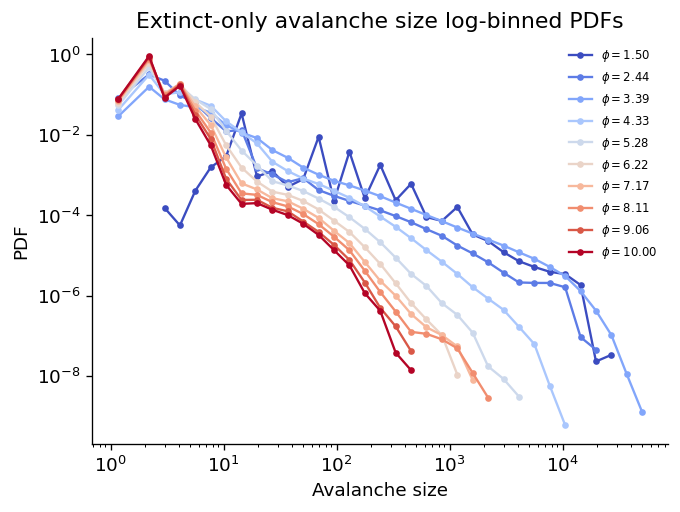

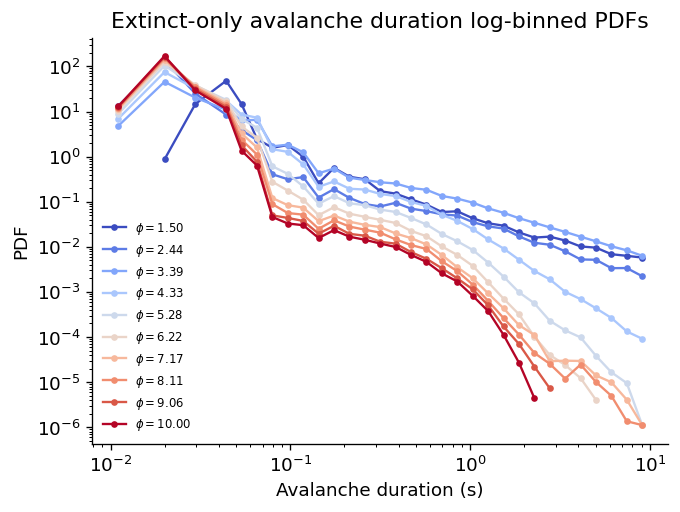

In [235]:
# ============================================================
# Avalanche log-binned PDF plots from phi sweep
# Extinct-only version
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "new_ew11p7_iw22p4_phi1p5to10_N2000_10phis_50seeds_10000avals_max1000"
)

TRIALS_PATH = OUTDIR / "avalanche_trials_phi_sweep.csv"
SUMMARY_PATH = OUTDIR / "network_summary_phi_sweep.csv"
PHI_SUMMARY_PATH = OUTDIR / "phi_summary_phi_sweep.csv"

FIGDIR = OUTDIR / "avalanche_logbinned_pdf_plots_extinct_only"
FIGDIR.mkdir(exist_ok=True)

trial_cols = [
    "phi",
    "seed",
    "network_id",
    "aval_i",
    "size",
    "lifetime_s",
    "lifetime_steps",
    "peak_active",
    "extinct",
    "persistent_at_cutoff",
    "cutoff_s",
    "dt",
]

trials = pd.read_csv(TRIALS_PATH, usecols=trial_cols)
network_summary = pd.read_csv(SUMMARY_PATH)
phi_summary = pd.read_csv(PHI_SUMMARY_PATH)

trials["phi"] = trials["phi"].astype(float)
network_summary["phi"] = network_summary["phi"].astype(float)
phi_summary["phi"] = phi_summary["phi"].astype(float)

DT = float(trials["dt"].iloc[0])
MAX_TIME_S = float(trials["cutoff_s"].iloc[0])

trials_all = trials.copy()
trials = trials[trials["extinct"]].copy()

print("Loaded all trials:", trials_all.shape)
print("Using extinct-only trials:", trials.shape)
print("Loaded network_summary:", network_summary.shape)
print("Loaded phi_summary:", phi_summary.shape)
print("DT:", DT)
print("MAX_TIME_S:", MAX_TIME_S)


# ============================================================
# Helper
# ============================================================

def log_binned_pdf(values, n_bins=35, vmin=None, vmax=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if len(values) == 0:
        return np.array([]), np.array([]), np.array([])

    if vmin is None:
        vmin = values.min()
    if vmax is None:
        vmax = values.max()

    vmin = max(float(vmin), 1e-12)
    vmax = float(vmax)

    if vmax <= vmin:
        return np.array([]), np.array([]), np.array([])

    edges = np.logspace(np.log10(vmin), np.log10(vmax), n_bins + 1)
    counts, edges = np.histogram(values, bins=edges)

    widths = np.diff(edges)
    centres = np.sqrt(edges[:-1] * edges[1:])

    pdf = counts / (counts.sum() * widths)

    keep = counts > 0
    return centres[keep], pdf[keep], counts[keep]


phis = np.sort(trials["phi"].unique())
cmap = plt.cm.coolwarm
colors = cmap(np.linspace(0, 1, len(phis)))
phi_to_color = dict(zip(phis, colors))


# ============================================================
# Avalanche size log-binned PDF
# ============================================================

fig, ax = plt.subplots(figsize=(5.8, 4.4))

for phi in phis:
    g = trials[trials["phi"] == phi]

    x, pdf, counts = log_binned_pdf(
        g["size"],
        n_bins=35,
        vmin=1,
        vmax=trials["size"].max(),
    )

    ax.plot(
        x,
        pdf,
        marker="o",
        markersize=3,
        linewidth=1.4,
        color=phi_to_color[phi],
        label=fr"$\phi={phi:.2f}$",
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Avalanche size")
ax.set_ylabel("PDF")
ax.set_title("Extinct-only avalanche size log-binned PDFs")
ax.legend(frameon=False, fontsize=7)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGDIR / "avalanche_size_logbinned_pdf_by_phi_extinct_only.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ============================================================
# Avalanche duration log-binned PDF
# ============================================================

fig, ax = plt.subplots(figsize=(5.8, 4.4))

for phi in phis:
    g = trials[trials["phi"] == phi]

    x, pdf, counts = log_binned_pdf(
        g["lifetime_s"],
        n_bins=35,
        vmin=DT,
        vmax=MAX_TIME_S,
    )

    ax.plot(
        x,
        pdf,
        marker="o",
        markersize=3,
        linewidth=1.4,
        color=phi_to_color[phi],
        label=fr"$\phi={phi:.2f}$",
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Avalanche duration (s)")
ax.set_ylabel("PDF")
ax.set_title("Extinct-only avalanche duration log-binned PDFs")
ax.legend(frameon=False, fontsize=7)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGDIR / "avalanche_duration_logbinned_pdf_by_phi_extinct_only.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

Loaded all trials: (10000000, 12)
Trials used for plotting: (5270331, 12)
Loaded network_summary: (1000, 34)
Loaded phi_summary: (20, 33)
DT: 0.01
MAX_TIME_S: 10.0
phis: [1.5        1.68421053 1.86842105 2.05263158 2.23684211 2.42105263
 2.60526316 2.78947368 2.97368421 3.15789474 3.34210526 3.52631579
 3.71052632 3.89473684 4.07894737 4.26315789 4.44736842 4.63157895
 4.81578947 5.        ]


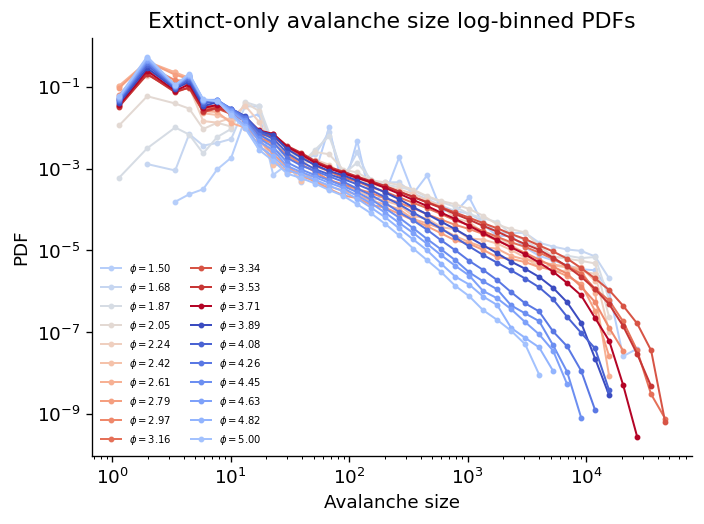

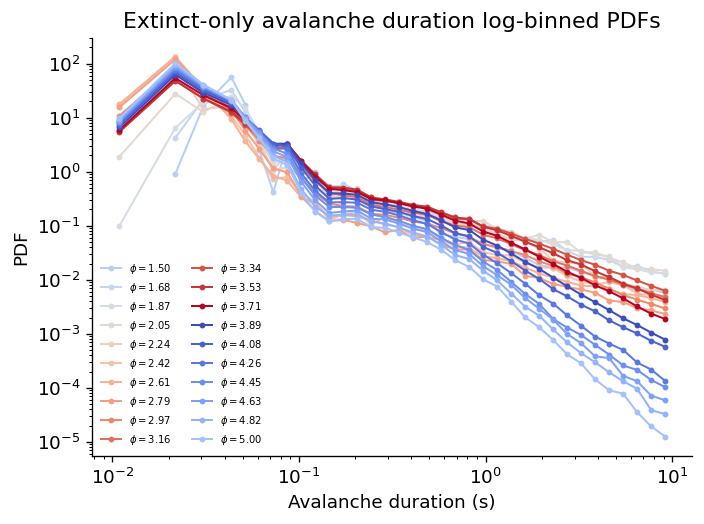

In [245]:
# avalanche + log-binned PDF/CCDF plots -> narrow view
# EXTINCT-ONLY BY DEFAULT
# RED CENTRED IN PHI COLOUR ORDER

# ============================================================
# Avalanche log-binned PDF + CCDF plots -> boundary phi sweep
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "new_ew11p7_iw22p4_phi2p5to4p5_N2000_20phis_50seeds_10000avals_max1000"
)

TRIALS_PATH = OUTDIR / "avalanche_trials_phi_sweep.csv"
SUMMARY_PATH = OUTDIR / "network_summary_phi_sweep.csv"
PHI_SUMMARY_PATH = OUTDIR / "phi_summary_phi_sweep.csv"

FIGDIR = OUTDIR / "avalanche_boundary_regime_logbinned_pdf_ccdf_extinct_only_red_middle"
FIGDIR.mkdir(exist_ok=True)

EXTINCT_ONLY = True
N_BINS = 40
CMAP = plt.cm.coolwarm

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

trial_cols = [
    "phi",
    "seed",
    "network_id",
    "aval_i",
    "size",
    "lifetime_s",
    "lifetime_steps",
    "peak_active",
    "extinct",
    "persistent_at_cutoff",
    "cutoff_s",
    "dt",
]

trials = pd.read_csv(TRIALS_PATH, usecols=trial_cols)
network_summary = pd.read_csv(SUMMARY_PATH)
phi_summary = pd.read_csv(PHI_SUMMARY_PATH)

trials["phi"] = trials["phi"].astype(float)
network_summary["phi"] = network_summary["phi"].astype(float)
phi_summary["phi"] = phi_summary["phi"].astype(float)

DT = float(trials["dt"].iloc[0])
MAX_TIME_S = float(trials["cutoff_s"].iloc[0])

if EXTINCT_ONLY:
    trials_plot = trials[trials["extinct"]].copy()
    suffix = "_extinct_only_red_middle"
    title_prefix = "Extinct-only "
else:
    trials_plot = trials.copy()
    suffix = "_red_middle"
    title_prefix = ""

phis = np.sort(trials_plot["phi"].unique())

# ------------------------------------------------------------
# Permuted colour scheme: reddest colour placed near middle phi
# ------------------------------------------------------------

colors_raw = CMAP(np.linspace(0, 1, len(phis)))

red_idx = np.argmax(colors_raw[:, 0] - colors_raw[:, 2])
mid_idx = len(phis) // 2

colors = np.roll(colors_raw, shift=mid_idx - red_idx, axis=0)
phi_to_color = dict(zip(phis, colors))

print("Loaded all trials:", trials.shape)
print("Trials used for plotting:", trials_plot.shape)
print("Loaded network_summary:", network_summary.shape)
print("Loaded phi_summary:", phi_summary.shape)
print("DT:", DT)
print("MAX_TIME_S:", MAX_TIME_S)
print("phis:", phis)


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def log_binned_pdf(values, n_bins=35, vmin=None, vmax=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if len(values) == 0:
        return np.array([]), np.array([]), np.array([])

    if vmin is None:
        vmin = values.min()
    if vmax is None:
        vmax = values.max()

    vmin = max(float(vmin), 1e-12)
    vmax = float(vmax)

    if vmax <= vmin:
        return np.array([]), np.array([]), np.array([])

    edges = np.logspace(np.log10(vmin), np.log10(vmax), n_bins + 1)
    counts, edges = np.histogram(values, bins=edges)

    widths = np.diff(edges)
    centres = np.sqrt(edges[:-1] * edges[1:])
    pdf = counts / (counts.sum() * widths)

    keep = counts > 0
    return centres[keep], pdf[keep], counts[keep]


def log_binned_ccdf(values, n_bins=35, vmin=None, vmax=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if len(values) == 0:
        return np.array([]), np.array([]), np.array([])

    if vmin is None:
        vmin = values.min()
    if vmax is None:
        vmax = values.max()

    vmin = max(float(vmin), 1e-12)
    vmax = float(vmax)

    if vmax <= vmin:
        return np.array([]), np.array([]), np.array([])

    edges = np.logspace(np.log10(vmin), np.log10(vmax), n_bins + 1)
    centres = np.sqrt(edges[:-1] * edges[1:])

    counts, _ = np.histogram(values, bins=edges)
    ccdf = np.array([(values >= edge).mean() for edge in edges[:-1]])

    keep = (counts > 0) & (ccdf > 0)
    return centres[keep], ccdf[keep], counts[keep]


def finish_plot(ax, xlabel, ylabel, title, savepath):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=6, ncol=2)
    ax.spines[["top", "right"]].set_visible(False)

    fig = ax.figure
    fig.tight_layout()
    fig.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------
# Shared limits
# ------------------------------------------------------------

vmax_size = trials_plot["size"].max()


# ------------------------------------------------------------
# 1. Avalanche size log-binned PDF
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.0, 4.5))

for phi in phis:
    g = trials_plot[np.isclose(trials_plot["phi"], phi)]

    x, pdf, counts = log_binned_pdf(
        g["size"],
        n_bins=N_BINS,
        vmin=1,
        vmax=vmax_size,
    )

    ax.plot(
        x,
        pdf,
        marker="o",
        markersize=2.5,
        linewidth=1.2,
        color=phi_to_color[phi],
        label=fr"$\phi={phi:.2f}$",
    )

finish_plot(
    ax,
    xlabel="Avalanche size",
    ylabel="PDF",
    title=f"{title_prefix}avalanche size log-binned PDFs",
    savepath=FIGDIR / f"avalanche_size_logbinned_pdf_by_phi{suffix}.png",
)


# ------------------------------------------------------------
# 2. Avalanche duration log-binned PDF
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.0, 4.5))

for phi in phis:
    g = trials_plot[np.isclose(trials_plot["phi"], phi)]

    x, pdf, counts = log_binned_pdf(
        g["lifetime_s"],
        n_bins=N_BINS,
        vmin=DT,
        vmax=MAX_TIME_S,
    )

    ax.plot(
        x,
        pdf,
        marker="o",
        markersize=2.5,
        linewidth=1.2,
        color=phi_to_color[phi],
        label=fr"$\phi={phi:.2f}$",
    )

finish_plot(
    ax,
    xlabel="Avalanche duration (s)",
    ylabel="PDF",
    title=f"{title_prefix}avalanche duration log-binned PDFs",
    savepath=FIGDIR / f"avalanche_duration_logbinned_pdf_by_phi{suffix}.png",
)

Loaded all trials: (10000000, 12)
Trials used for plotting: (5270331, 12)
Loaded network_summary: (1000, 34)
Loaded phi_summary: (20, 33)
DT: 0.01
MAX_TIME_S: 10.0
all phis: [1.5        1.68421053 1.86842105 2.05263158 2.23684211 2.42105263
 2.60526316 2.78947368 2.97368421 3.15789474 3.34210526 3.52631579
 3.71052632 3.89473684 4.07894737 4.26315789 4.44736842 4.63157895
 4.81578947 5.        ]
plotted phis: [1.5        1.86842105 2.23684211 2.60526316 2.97368421 3.34210526
 3.71052632 4.07894737 4.44736842 4.81578947]


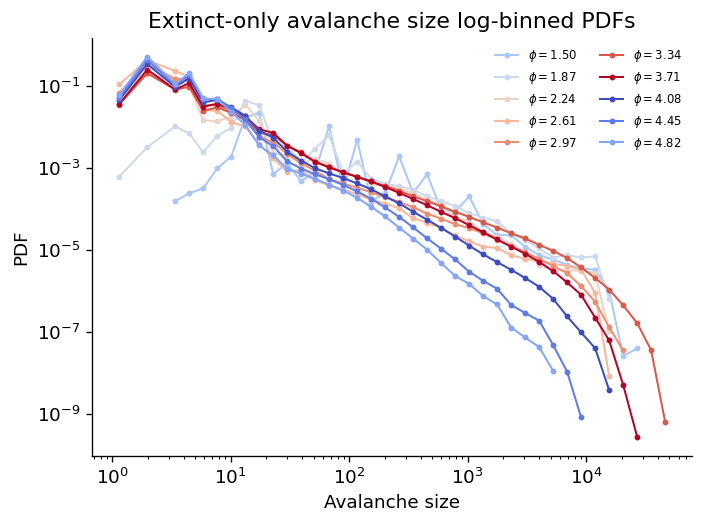

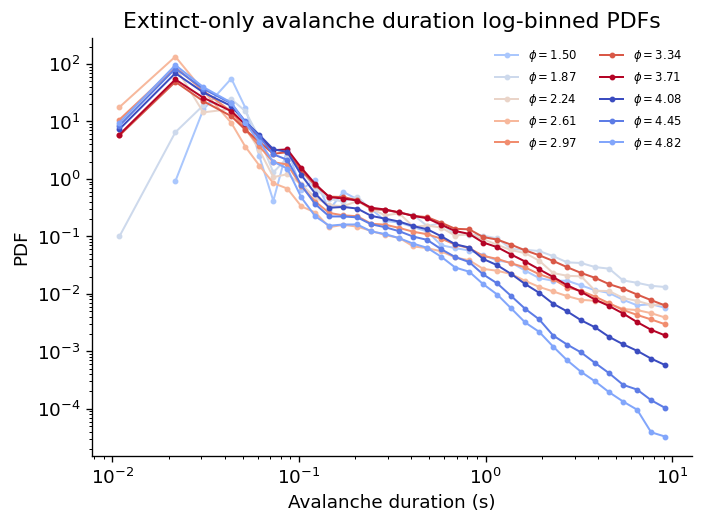

In [246]:
# avalanche + log-binned PDF/CCDF plots -> narrow view
# EXTINCT-ONLY BY DEFAULT
# SUBSAMPLED BY 2 IN PHI SPACE
# RED CENTRED IN PHI COLOUR ORDER

# ============================================================
# Avalanche log-binned PDF + CCDF plots -> boundary phi sweep
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "new_ew11p7_iw22p4_phi2p5to4p5_N2000_20phis_50seeds_10000avals_max1000"
)

TRIALS_PATH = OUTDIR / "avalanche_trials_phi_sweep.csv"
SUMMARY_PATH = OUTDIR / "network_summary_phi_sweep.csv"
PHI_SUMMARY_PATH = OUTDIR / "phi_summary_phi_sweep.csv"

FIGDIR = OUTDIR / "avalanche_boundary_regime_logbinned_pdf_ccdf_extinct_only_subsampled_phi2_red_middle"
FIGDIR.mkdir(exist_ok=True)

EXTINCT_ONLY = True
N_BINS = 40
PHI_SUBSAMPLE_STEP = 2
CMAP = plt.cm.coolwarm

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

trial_cols = [
    "phi",
    "seed",
    "network_id",
    "aval_i",
    "size",
    "lifetime_s",
    "lifetime_steps",
    "peak_active",
    "extinct",
    "persistent_at_cutoff",
    "cutoff_s",
    "dt",
]

trials = pd.read_csv(TRIALS_PATH, usecols=trial_cols)
network_summary = pd.read_csv(SUMMARY_PATH)
phi_summary = pd.read_csv(PHI_SUMMARY_PATH)

trials["phi"] = trials["phi"].astype(float)
network_summary["phi"] = network_summary["phi"].astype(float)
phi_summary["phi"] = phi_summary["phi"].astype(float)

DT = float(trials["dt"].iloc[0])
MAX_TIME_S = float(trials["cutoff_s"].iloc[0])

if EXTINCT_ONLY:
    trials_plot = trials[trials["extinct"]].copy()
    suffix = "_extinct_only_subsampled_phi2_red_middle"
    title_prefix = "Extinct-only "
else:
    trials_plot = trials.copy()
    suffix = "_subsampled_phi2_red_middle"
    title_prefix = ""

phis_all = np.sort(trials_plot["phi"].unique())
phis = phis_all[::PHI_SUBSAMPLE_STEP]

# ------------------------------------------------------------
# Permuted colour scheme: reddest colour placed near middle phi
# ------------------------------------------------------------

colors_raw = CMAP(np.linspace(0, 1, len(phis)))

red_idx = np.argmax(colors_raw[:, 0] - colors_raw[:, 2])
mid_idx = len(phis) // 2

colors = np.roll(colors_raw, shift=mid_idx - red_idx, axis=0)
phi_to_color = dict(zip(phis, colors))

print("Loaded all trials:", trials.shape)
print("Trials used for plotting:", trials_plot.shape)
print("Loaded network_summary:", network_summary.shape)
print("Loaded phi_summary:", phi_summary.shape)
print("DT:", DT)
print("MAX_TIME_S:", MAX_TIME_S)
print("all phis:", phis_all)
print("plotted phis:", phis)


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def log_binned_pdf(values, n_bins=35, vmin=None, vmax=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if len(values) == 0:
        return np.array([]), np.array([]), np.array([])

    if vmin is None:
        vmin = values.min()
    if vmax is None:
        vmax = values.max()

    vmin = max(float(vmin), 1e-12)
    vmax = float(vmax)

    if vmax <= vmin:
        return np.array([]), np.array([]), np.array([])

    edges = np.logspace(np.log10(vmin), np.log10(vmax), n_bins + 1)
    counts, edges = np.histogram(values, bins=edges)

    widths = np.diff(edges)
    centres = np.sqrt(edges[:-1] * edges[1:])
    pdf = counts / (counts.sum() * widths)

    keep = counts > 0
    return centres[keep], pdf[keep], counts[keep]


def log_binned_ccdf(values, n_bins=35, vmin=None, vmax=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if len(values) == 0:
        return np.array([]), np.array([]), np.array([])

    if vmin is None:
        vmin = values.min()
    if vmax is None:
        vmax = values.max()

    vmin = max(float(vmin), 1e-12)
    vmax = float(vmax)

    if vmax <= vmin:
        return np.array([]), np.array([]), np.array([])

    edges = np.logspace(np.log10(vmin), np.log10(vmax), n_bins + 1)
    centres = np.sqrt(edges[:-1] * edges[1:])

    counts, _ = np.histogram(values, bins=edges)
    ccdf = np.array([(values >= edge).mean() for edge in edges[:-1]])

    keep = (counts > 0) & (ccdf > 0)
    return centres[keep], ccdf[keep], counts[keep]


def finish_plot(ax, xlabel, ylabel, title, savepath):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=7, ncol=2)
    ax.spines[["top", "right"]].set_visible(False)

    fig = ax.figure
    fig.tight_layout()
    fig.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------
# Shared limits
# ------------------------------------------------------------

vmax_size = trials_plot["size"].max()


# ------------------------------------------------------------
# 1. Avalanche size log-binned PDF
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.0, 4.5))

for phi in phis:
    g = trials_plot[np.isclose(trials_plot["phi"], phi)]

    x, pdf, counts = log_binned_pdf(
        g["size"],
        n_bins=N_BINS,
        vmin=1,
        vmax=vmax_size,
    )

    ax.plot(
        x,
        pdf,
        marker="o",
        markersize=2.5,
        linewidth=1.2,
        color=phi_to_color[phi],
        label=fr"$\phi={phi:.2f}$",
    )

finish_plot(
    ax,
    xlabel="Avalanche size",
    ylabel="PDF",
    title=f"{title_prefix}avalanche size log-binned PDFs",
    savepath=FIGDIR / f"avalanche_size_logbinned_pdf_by_phi{suffix}.png",
)


# ------------------------------------------------------------
# 2. Avalanche duration log-binned PDF
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.0, 4.5))

for phi in phis:
    g = trials_plot[np.isclose(trials_plot["phi"], phi)]

    x, pdf, counts = log_binned_pdf(
        g["lifetime_s"],
        n_bins=N_BINS,
        vmin=DT,
        vmax=MAX_TIME_S,
    )

    ax.plot(
        x,
        pdf,
        marker="o",
        markersize=2.5,
        linewidth=1.2,
        color=phi_to_color[phi],
        label=fr"$\phi={phi:.2f}$",
    )

finish_plot(
    ax,
    xlabel="Avalanche duration (s)",
    ylabel="PDF",
    title=f"{title_prefix}avalanche duration log-binned PDFs",
    savepath=FIGDIR / f"avalanche_duration_logbinned_pdf_by_phi{suffix}.png",
)

,phi,metric,R_truncated_vs_lognormal,p_truncated_vs_lognormal,xmin,alpha_truncated,lambda_truncated,mu_lognormal,sigma_lognormal,n_tail
0,1.500000,size,-16.995613,8.849966e-65,10.0,1.033079,0.000229,4.668067,1.941998,13916
1,1.500000,duration,24.384866,2.475357e-131,0.1,1.081220,0.122843,-1.573189,2.102845,3583
2,1.684211,size,23.473481,7.612153e-122,10.0,1.233835,0.000048,0.808768,3.875385,6991
3,1.684211,duration,14.061254,6.571108e-45,0.1,1.000000,0.103909,-0.305355,1.688319,3097
4,1.868421,size,22.344796,1.356678e-110,10.0,1.297579,0.000047,-2.174196,4.510729,5109
5,1.868421,duration,10.072664,7.297390e-24,0.1,1.000000,0.106638,-0.271052,1.648566,2398
6,2.052632,size,25.524412,1.056454e-143,10.0,1.222787,0.000069,-0.003311,4.101882,4251
7,2.052632,duration,3.926547,8.617420e-05,0.1,1.000000,0.101219,-0.062344,1.529764,2411
8,2.236842,size,20.515982,1.550064e-93,10.0,1.331519,0.000056,-4.538643,4.903555,3854
9,2.236842,duration,5.994748,2.038012e-09,0.1,1.000000,0.148642,-0.516563,1.549413,2161


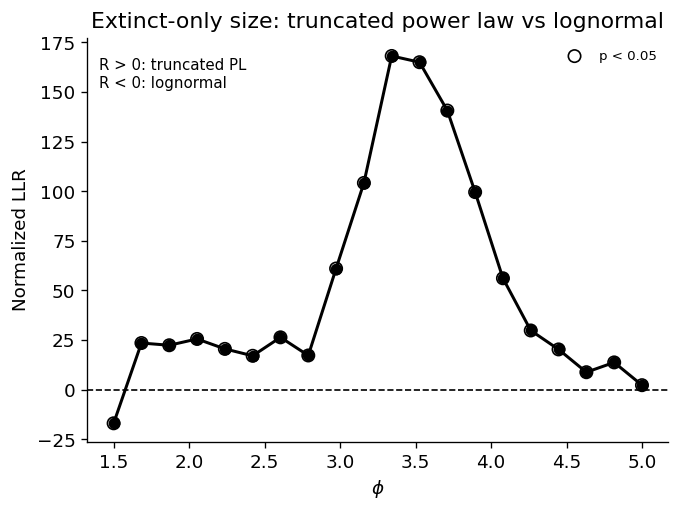

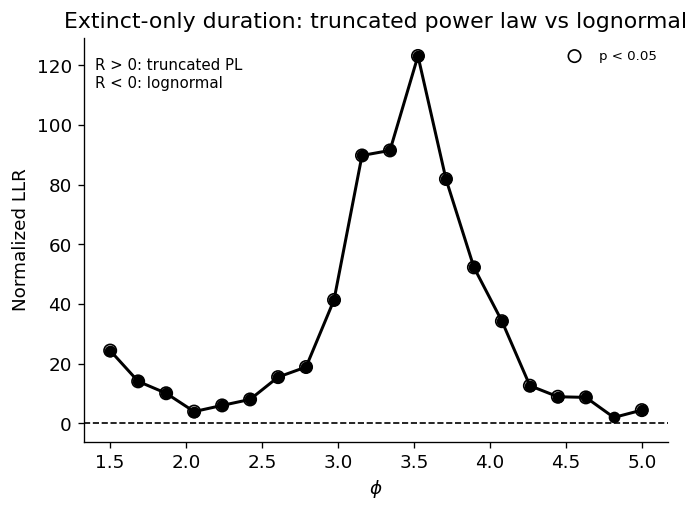

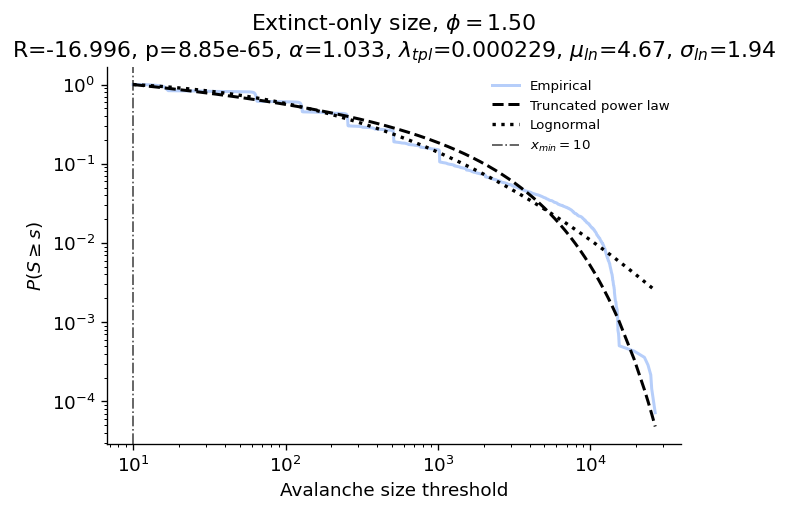

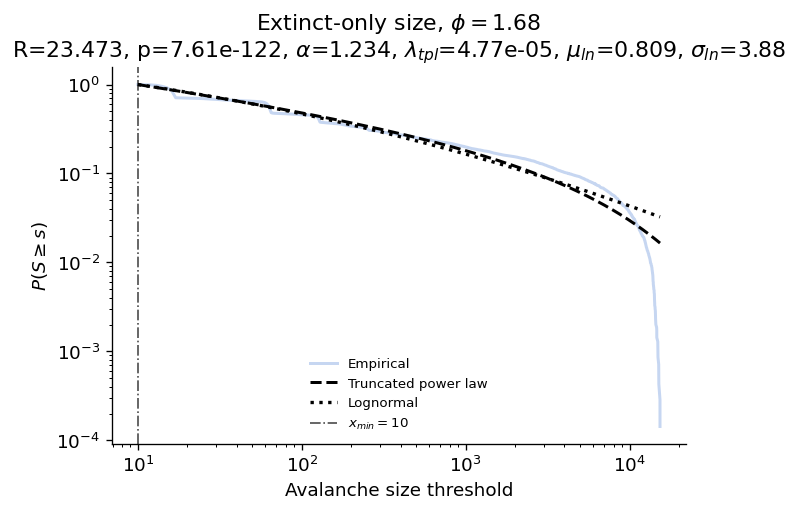

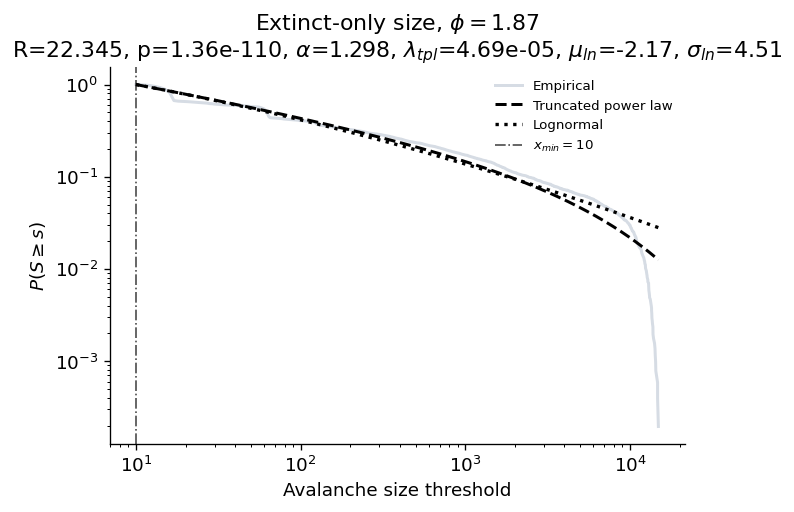

...

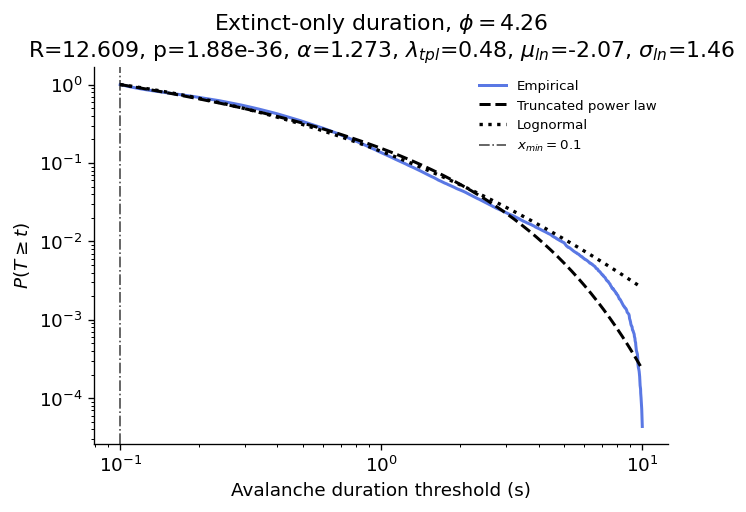

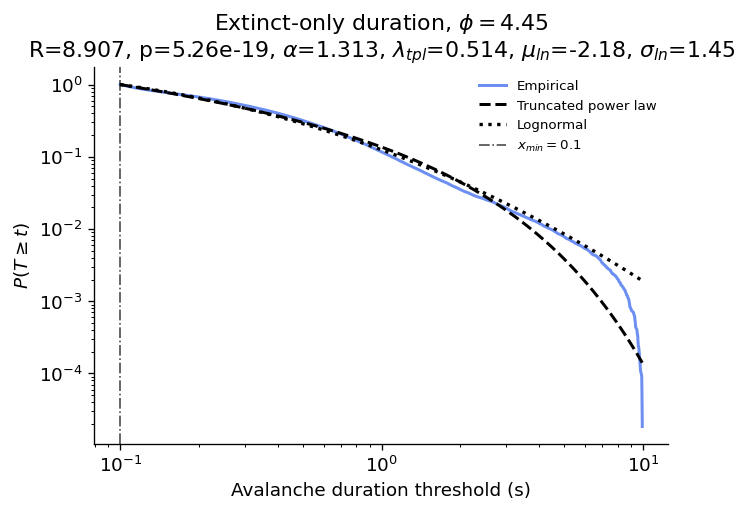

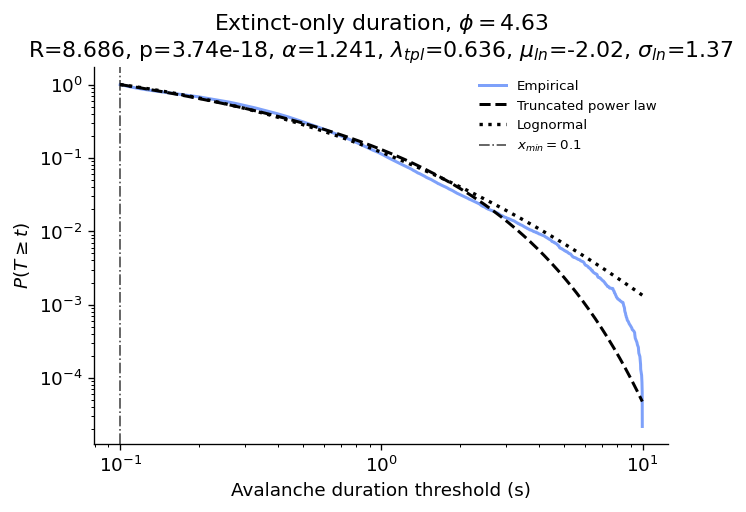

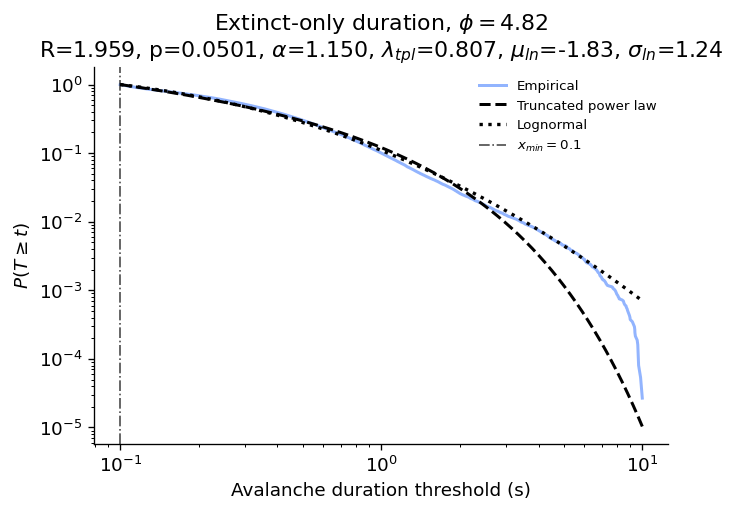

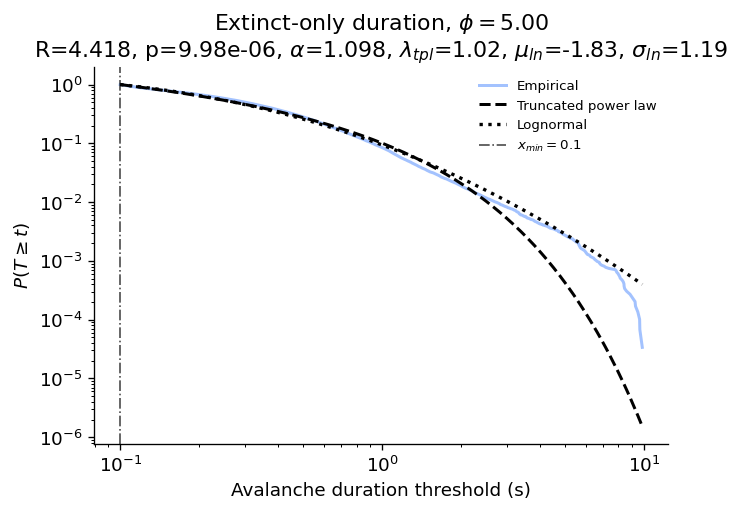

Saved figures to: /home/dburrows/DATA/BLNDEV-WILDTYPE/new_ew11p7_iw22p4_phi2p5to4p5_N2000_20phis_50seeds_10000avals_max1000/truncated_powerlaw_vs_lognormal_boundary_phi_extinct_only_red_middle


In [247]:
# ============================================================
# Truncated power law vs lognormal only
# Boundary phi sweep data, not subsampled
# Extinct-only by default
# LLR + per-phi CCDF fits
# Requires: pip install powerlaw
# ============================================================

import powerlaw

TPL_LN_FIGDIR = OUTDIR / "truncated_powerlaw_vs_lognormal_boundary_phi_extinct_only_red_middle"
TPL_LN_FIGDIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Define minimum cutoffs here
# ------------------------------------------------------------

SIZE_XMIN = 10
DURATION_XMIN = 0.1


# ------------------------------------------------------------
# Data for fitting
# ------------------------------------------------------------

fit_trials = trials_plot.copy()
phis = np.sort(fit_trials["phi"].unique())

# keep same red-centred colour order
colors_raw = CMAP(np.linspace(0, 1, len(phis)))
red_idx = np.argmax(colors_raw[:, 0] - colors_raw[:, 2])
mid_idx = len(phis) // 2
colors = np.roll(colors_raw, shift=mid_idx - red_idx, axis=0)
phi_to_color = dict(zip(phis, colors))


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def survival_curve(values):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    x = np.sort(np.unique(values))
    surv = np.array([(values >= xx).mean() for xx in x])

    keep = surv > 0
    return x[keep], surv[keep]


def fit_truncated_vs_lognormal(values, discrete=False, xmin=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if len(values) < 20:
        return None

    fit = powerlaw.Fit(
        values,
        discrete=discrete,
        xmin=xmin,
        estimate_discrete=discrete,
        verbose=False,
    )

    R, p = fit.distribution_compare(
        "truncated_power_law",
        "lognormal",
        normalized_ratio=True,
    )

    tail_values = values[values >= fit.xmin]

    return {
        "fit": fit,
        "R_tpl_vs_ln": R,
        "p_tpl_vs_ln": p,
        "xmin": fit.xmin,
        "alpha_tpl": fit.truncated_power_law.alpha,
        "lambda_tpl": fit.truncated_power_law.Lambda,
        "mu_lognormal": fit.lognormal.mu,
        "sigma_lognormal": fit.lognormal.sigma,
        "n_tail": len(tail_values),
    }


# ------------------------------------------------------------
# Run fits by phi
# ------------------------------------------------------------

rows = []

for phi in phis:
    g = fit_trials[np.isclose(fit_trials["phi"], phi)]

    for metric, col, discrete, xmin in [
        ("size", "size", True, SIZE_XMIN),
        ("duration", "lifetime_s", False, DURATION_XMIN),
    ]:
        res = fit_truncated_vs_lognormal(
            g[col],
            discrete=discrete,
            xmin=xmin,
        )

        if res is None:
            continue

        rows.append({
            "phi": phi,
            "metric": metric,
            "R_truncated_vs_lognormal": res["R_tpl_vs_ln"],
            "p_truncated_vs_lognormal": res["p_tpl_vs_ln"],
            "xmin": res["xmin"],
            "alpha_truncated": res["alpha_tpl"],
            "lambda_truncated": res["lambda_tpl"],
            "mu_lognormal": res["mu_lognormal"],
            "sigma_lognormal": res["sigma_lognormal"],
            "n_tail": res["n_tail"],
        })

tpl_ln_df = pd.DataFrame(rows)

tpl_ln_df.to_csv(
    TPL_LN_FIGDIR / "truncated_powerlaw_vs_lognormal_by_phi.csv",
    index=False,
)

display(tpl_ln_df)


# ------------------------------------------------------------
# LLR summary plots
# R > 0 favours truncated power law
# R < 0 favours lognormal
# ------------------------------------------------------------

def plot_tpl_vs_ln_llr(metric, filename):
    fig, ax = plt.subplots(figsize=(5.8, 4.4))

    d = tpl_ln_df[tpl_ln_df["metric"] == metric].sort_values("phi")

    ax.axhline(0, color="k", linestyle="--", linewidth=1)

    ax.plot(
        d["phi"],
        d["R_truncated_vs_lognormal"],
        marker="o",
        linewidth=1.8,
        color="k",
    )

    sig = d["p_truncated_vs_lognormal"] < 0.05

    ax.scatter(
        d.loc[sig, "phi"],
        d.loc[sig, "R_truncated_vs_lognormal"],
        s=55,
        facecolors="none",
        edgecolors="k",
        linewidths=1,
        label="p < 0.05",
    )

    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("Normalized LLR")
    ax.set_title(f"{title_prefix}{metric}: truncated power law vs lognormal")
    ax.text(
        0.02,
        0.95,
        "R > 0: truncated PL\nR < 0: lognormal",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )

    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    fig.savefig(TPL_LN_FIGDIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


plot_tpl_vs_ln_llr(
    metric="size",
    filename=f"llr_size_truncated_powerlaw_vs_lognormal{suffix}.png",
)

plot_tpl_vs_ln_llr(
    metric="duration",
    filename=f"llr_duration_truncated_powerlaw_vs_lognormal{suffix}.png",
)


# ------------------------------------------------------------
# Per-phi CCDF plots with fitted curves
# ------------------------------------------------------------

def plot_per_phi_ccdf_fits(metric, col, discrete, xmin, xlabel, ylabel):
    for phi in phis:
        g = fit_trials[np.isclose(fit_trials["phi"], phi)]

        values = np.asarray(g[col], float)
        values = values[np.isfinite(values)]
        values = values[values > 0]

        res = fit_truncated_vs_lognormal(
            values,
            discrete=discrete,
            xmin=xmin,
        )

        if res is None:
            continue

        fit = res["fit"]
        tail_values = values[values >= fit.xmin]
        x_emp, surv_emp = survival_curve(tail_values)

        fig, ax = plt.subplots(figsize=(5.8, 4.4))

        ax.plot(
            x_emp,
            surv_emp,
            color=phi_to_color[phi],
            linewidth=1.8,
            label="Empirical",
        )

        fit.truncated_power_law.plot_ccdf(
            ax=ax,
            color="k",
            linestyle="--",
            linewidth=1.8,
            label="Truncated power law",
        )

        fit.lognormal.plot_ccdf(
            ax=ax,
            color="k",
            linestyle=":",
            linewidth=2.0,
            label="Lognormal",
        )

        ax.axvline(
            fit.xmin,
            color="k",
            linestyle="-.",
            linewidth=1,
            alpha=0.7,
            label=fr"$x_{{min}}={fit.xmin:.3g}$",
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        ax.set_title(
            fr"{title_prefix}{metric}, $\phi={phi:.2f}$"
            "\n"
            fr"R={res['R_tpl_vs_ln']:.3f}, p={res['p_tpl_vs_ln']:.3g}, "
            fr"$\alpha$={res['alpha_tpl']:.3f}, "
            fr"$\lambda_{{tpl}}$={res['lambda_tpl']:.3g}, "
            fr"$\mu_{{ln}}$={res['mu_lognormal']:.3g}, "
            fr"$\sigma_{{ln}}$={res['sigma_lognormal']:.3g}"
        )

        ax.legend(frameon=False, fontsize=8)
        ax.spines[["top", "right"]].set_visible(False)

        fig.tight_layout()

        safe_phi = str(round(float(phi), 4)).replace(".", "p")

        fig.savefig(
            TPL_LN_FIGDIR / f"ccdf_{metric}_phi_{safe_phi}_tpl_vs_lognormal{suffix}.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


plot_per_phi_ccdf_fits(
    metric="size",
    col="size",
    discrete=True,
    xmin=SIZE_XMIN,
    xlabel="Avalanche size threshold",
    ylabel=r"$P(S \geq s)$",
)

plot_per_phi_ccdf_fits(
    metric="duration",
    col="lifetime_s",
    discrete=False,
    xmin=DURATION_XMIN,
    xlabel="Avalanche duration threshold (s)",
    ylabel=r"$P(T \geq t)$",
)
print("Saved figures to:", TPL_LN_FIGDIR)

Normalized LLR fits:   0%|          | 0/2000 [00:00<?, ?fit/s]

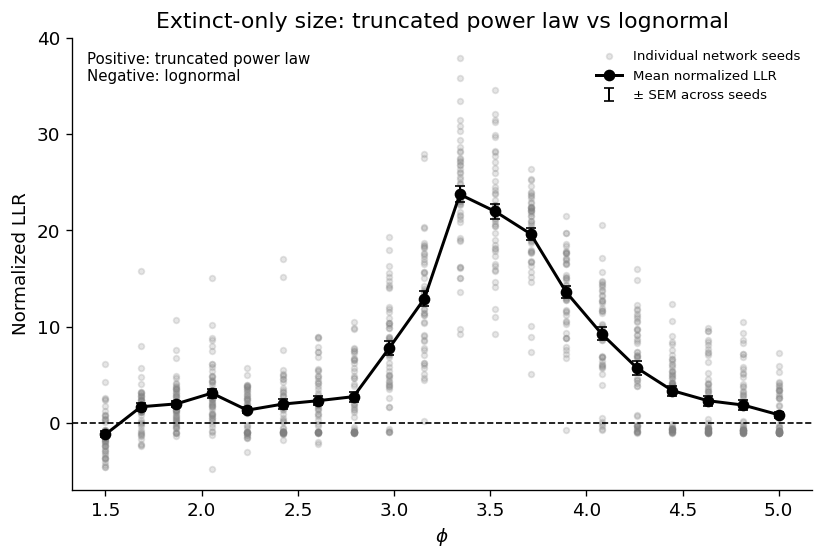

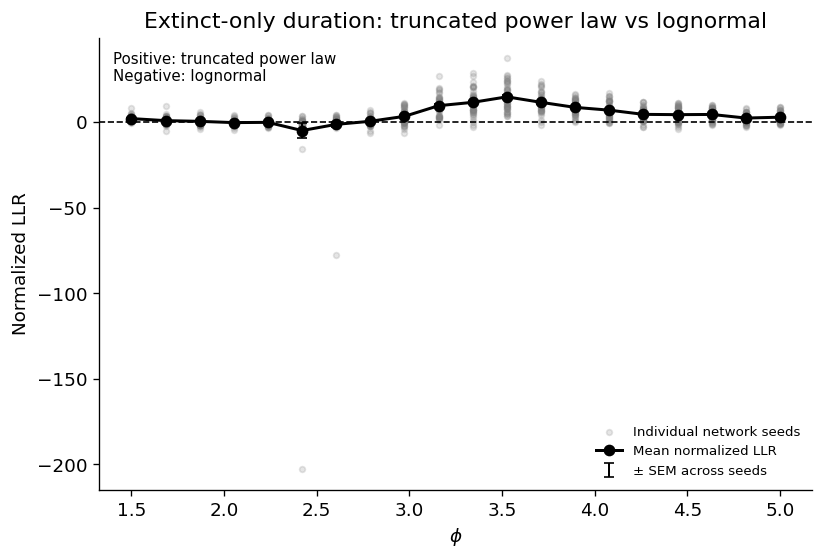

In [5]:
"""
Normalized avalanche LLR per network seed.

Same fitting settings as the OLD analysis:
    - Extinct-only avalanches
    - Size xmin = 10, discrete=True
    - Duration xmin = 0.1 s, discrete=False
    - Truncated power law versus lognormal
    - normalized_ratio=True
    - Require at least 20 finite, positive observations before fitting

Plots:
    Mean normalized LLR ± SEM across valid network seeds, per phi.

No simulations or CCDF plots.
Requires: numpy pandas matplotlib powerlaw tqdm
"""

from pathlib import Path
import contextlib
import importlib.metadata
import io
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import powerlaw
from tqdm.auto import tqdm


# ============================================================
# Settings
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "new_ew11p7_iw22p4_phi2p5to4p5_N2000_20phis_50seeds_10000avals_max1000"
)

# For the broad sweep, replace OUTDIR with:
# OUTDIR = Path(
#     "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
#     "new_ew11p7_iw22p4_phi1p5to10_N2000_10phis_50seeds_10000avals_max1000"
# )

SOURCE = OUTDIR / "avalanche_trials_phi_sweep.csv"

# New folder: avoids mixing these fits with the per-avalanche LLR results.
SAVEDIR = OUTDIR / "truncated_powerlaw_vs_lognormal_normalized_by_seed"

SIZE_XMIN = 10
DURATION_XMIN = 0.1

# Matches the OLD script's check on all finite, positive observations.
# This is NOT a requirement for 100 tail observations.
MIN_VALUES = 20

RESUME = True
SHOW_PLOTS = True
SHOW_SEED_SCATTER = True

METRICS = [
    ("size", "size", True, SIZE_XMIN),
    ("duration", "lifetime_s", False, DURATION_XMIN),
]

RESULTS_PATH = SAVEDIR / "normalized_seed_fits.csv"
SUMMARY_PATH = SAVEDIR / "normalized_llr_summary_by_phi.csv"
CONFIG_PATH = SAVEDIR / "fit_config.json"


# ============================================================
# Helpers
# ============================================================

def bool_column(series):
    if pd.api.types.is_bool_dtype(series):
        if series.isna().any():
            raise ValueError("Missing values in extinct column.")
        return series.astype(bool)

    mapped = (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
            "1.0": True,
            "0.0": False,
        })
    )

    if mapped.isna().any():
        raise ValueError("Unexpected or missing values in extinct column.")

    return mapped.astype(bool)


def atomic_csv(frame, path):
    temporary = path.with_suffix(".tmp.csv")

    # Undefined fits/SEMs remain NaN in the CSV.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        frame.to_csv(temporary, index=False)

    temporary.replace(path)


def result_key(phi, seed, metric):
    return float(phi), int(seed), str(metric)


def fit_one(values, discrete, xmin):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]

    out = {
        "status": "too_few_values",
        "n_values": int(len(values)),
        "n_tail": int(np.sum(values >= xmin)),
        "R_normalized": np.nan,
        "p_truncated_vs_lognormal": np.nan,
        "alpha_truncated": np.nan,
        "lambda_truncated": np.nan,
        "mu_lognormal": np.nan,
        "sigma_lognormal": np.nan,
        "warnings": "",
    }

    if len(values) < MIN_VALUES:
        return out

    # A normalized LLR cannot be estimated meaningfully from <2 tail values.
    if out["n_tail"] < 2:
        out["status"] = "insufficient_tail_for_normalized_llr"
        return out

    # Suppress package output; retain warnings in the saved results.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        with contextlib.redirect_stdout(io.StringIO()):
            with contextlib.redirect_stderr(io.StringIO()):

                # EXACT fitting call used in the OLD script.
                fit = powerlaw.Fit(
                    values,
                    discrete=discrete,
                    xmin=xmin,
                    estimate_discrete=discrete,
                    verbose=False,
                )

                R, p = fit.distribution_compare(
                    "truncated_power_law",
                    "lognormal",
                    normalized_ratio=True,
                )

                out.update({
                    "status": "ok" if np.isfinite(R) else "nonfinite_llr",
                    "n_tail": int(np.sum(values >= fit.xmin)),
                    "R_normalized": float(R),
                    "p_truncated_vs_lognormal": float(p),
                    "alpha_truncated": float(fit.truncated_power_law.alpha),
                    "lambda_truncated": float(fit.truncated_power_law.Lambda),
                    "mu_lognormal": float(fit.lognormal.mu),
                    "sigma_lognormal": float(fit.lognormal.sigma),
                })

        out["warnings"] = " | ".join(
            dict.fromkeys(str(w.message) for w in caught)
        )

    return out


# ============================================================
# Run fits and make LLR plots
# ============================================================

def main():
    SAVEDIR.mkdir(parents=True, exist_ok=True)

    stat = SOURCE.stat()

    config = {
        "source": str(SOURCE.resolve()),
        "source_bytes": stat.st_size,
        "source_mtime_ns": stat.st_mtime_ns,
        "size_xmin": SIZE_XMIN,
        "duration_xmin": DURATION_XMIN,
        "min_values_before_tail_filter": MIN_VALUES,
        "extinct_only": True,
        "normalized_ratio": True,
        "fit_grouping": "phi_and_network_seed",
        "error_bars": "SEM across valid network seeds",
        "powerlaw_version": importlib.metadata.version("powerlaw"),
    }

    rows = []

    if RESUME and RESULTS_PATH.exists():
        if (
            not CONFIG_PATH.exists()
            or json.loads(CONFIG_PATH.read_text()) != config
        ):
            raise ValueError(
                "Input or settings changed. Set RESUME=False "
                "or choose a new SAVEDIR."
            )

        rows = pd.read_csv(RESULTS_PATH).to_dict("records")

    CONFIG_PATH.write_text(json.dumps(config, indent=2))

    data = pd.read_csv(
        SOURCE,
        usecols=[
            "phi", "seed", "network_id",
            "size", "lifetime_s", "extinct",
        ],
    )

    for column in ["phi", "seed", "size", "lifetime_s"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    if data[["phi", "seed", "network_id"]].isna().any().any():
        raise ValueError("Missing phi, seed or network_id.")

    if not np.isfinite(data[["phi", "seed"]].to_numpy()).all():
        raise ValueError("Nonfinite phi or seed.")

    if not np.equal(data["seed"], np.floor(data["seed"])).all():
        raise ValueError("Seed identifiers must be integers.")

    data["seed"] = data["seed"].astype(int)
    data["extinct"] = bool_column(data["extinct"])

    if data.groupby(["phi", "seed"])["network_id"].nunique().gt(1).any():
        raise ValueError("A phi/seed pair identifies multiple networks.")

    if data.groupby(["phi", "network_id"])["seed"].nunique().gt(1).any():
        raise ValueError("Multiple seeds identify the same network at a phi.")

    grouped = data.groupby(["phi", "seed"], sort=True)

    done = {
        result_key(row["phi"], row["seed"], row["metric"])
        for row in rows
    }

    expected = {
        result_key(phi, seed, metric)
        for phi, seed in grouped.groups
        for metric, _, _, _ in METRICS
    }

    if not done.issubset(expected):
        raise ValueError("Saved fits contain unexpected phi/seed/metric groups.")

    if len(done) != len(rows):
        raise ValueError("Duplicate fits in the saved results.")

    with tqdm(
        total=len(expected),
        initial=len(done),
        desc="Normalized LLR fits",
        unit="fit",
    ) as progress:

        for (phi, seed), group in grouped:
            extinct_group = group.loc[group["extinct"]]

            for metric, column, discrete, xmin in METRICS:
                key = result_key(phi, seed, metric)

                if key in done:
                    continue

                try:
                    result = fit_one(
                        extinct_group[column],
                        discrete=discrete,
                        xmin=xmin,
                    )

                except Exception as exc:
                    result = {
                        "status": "error",
                        "n_values": np.nan,
                        "n_tail": np.nan,
                        "R_normalized": np.nan,
                        "p_truncated_vs_lognormal": np.nan,
                        "warnings": f"{type(exc).__name__}: {exc}",
                    }

                rows.append({
                    "phi": float(phi),
                    "seed": int(seed),
                    "metric": metric,
                    "xmin": xmin,
                    "n_trials": int(len(group)),
                    "n_extinct": int(len(extinct_group)),
                    **result,
                })

                done.add(key)

                # Checkpoint after every fit without printing a line.
                atomic_csv(pd.DataFrame(rows), RESULTS_PATH)
                progress.update(1)

    seed_df = (
        pd.DataFrame(rows)
        .sort_values(["phi", "seed", "metric"])
        .reset_index(drop=True)
    )
    atomic_csv(seed_df, RESULTS_PATH)

    # --------------------------------------------------------
    # Mean and SEM across independently fitted network seeds
    # --------------------------------------------------------

    summary_rows = []

    for (phi, metric), group in seed_df.groupby(
        ["phi", "metric"], sort=True
    ):
        valid = group.loc[
            (group["status"] == "ok")
            & np.isfinite(group["R_normalized"])
        ]

        scores = valid["R_normalized"].to_numpy(float)
        n = len(scores)

        summary_rows.append({
            "phi": float(phi),
            "metric": metric,
            "seeds_total": int(len(group)),
            "seeds_valid": int(n),
            "seeds_excluded": int(len(group) - n),
            "R_normalized_mean": float(scores.mean()) if n else np.nan,
            "R_normalized_sem": (
                float(scores.std(ddof=1) / np.sqrt(n))
                if n > 1 else np.nan
            ),
            "R_normalized_median": (
                float(np.median(scores)) if n else np.nan
            ),
            "fraction_favour_tpl": (
                float(np.mean(scores > 0)) if n else np.nan
            ),
            "mean_n_tail": (
                float(valid["n_tail"].mean()) if n else np.nan
            ),
        })

    summary_df = pd.DataFrame(summary_rows)
    atomic_csv(summary_df, SUMMARY_PATH)

    # --------------------------------------------------------
    # Only the size and duration LLR plots
    # --------------------------------------------------------

    plt.rcParams.update({
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 120,
    })

    for metric, _, _, _ in METRICS:
        summary = (
            summary_df.loc[summary_df["metric"] == metric]
            .sort_values("phi")
        )

        valid_seeds = seed_df.loc[
            (seed_df["metric"] == metric)
            & (seed_df["status"] == "ok")
            & np.isfinite(seed_df["R_normalized"])
        ]

        fig, ax = plt.subplots(figsize=(7, 4.8))

        if SHOW_SEED_SCATTER and not valid_seeds.empty:
            ax.scatter(
                valid_seeds["phi"],
                valid_seeds["R_normalized"],
                color="grey",
                alpha=0.20,
                s=12,
                label="Individual network seeds",
                zorder=1,
            )

        # Draw the mean curve with NaNs retained, leaving gaps where
        # no valid fits exist.
        ax.plot(
            summary["phi"],
            summary["R_normalized_mean"],
            "o-",
            color="black",
            linewidth=1.8,
            label="Mean normalized LLR",
            zorder=3,
        )

        defined_errors = summary.loc[
            np.isfinite(summary["R_normalized_mean"])
            & np.isfinite(summary["R_normalized_sem"])
        ]

        if not defined_errors.empty:
            ax.errorbar(
                defined_errors["phi"],
                defined_errors["R_normalized_mean"],
                yerr=defined_errors["R_normalized_sem"],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1.2,
                label="± SEM across seeds",
                zorder=4,
            )

        ax.axhline(0, color="black", linestyle="--", linewidth=1)

        ax.set_xlabel(r"$\phi$")
        ax.set_ylabel("Normalized LLR")
        ax.set_title(
            f"Extinct-only {metric}: truncated power law vs lognormal"
        )

        ax.text(
            0.02,
            0.97,
            "Positive: truncated power law\nNegative: lognormal",
            transform=ax.transAxes,
            va="top",
            fontsize=9,
        )

        if valid_seeds.empty:
            ax.text(
                0.5, 0.5,
                "No valid fits; inspect normalized_seed_fits.csv",
                transform=ax.transAxes,
                ha="center",
            )
        else:
            ax.legend(frameon=False, fontsize=8, loc="best")

        fig.tight_layout()

        fig.savefig(
            SAVEDIR / f"llr_{metric}_normalized_by_seed_mean_sem.png",
            dpi=300,
            bbox_inches="tight",
        )

        if SHOW_PLOTS:
            plt.show()

        plt.close(fig)

    return seed_df, summary_df


if __name__ == "__main__":
    seed_llr_df, seed_llr_summary_df = main()

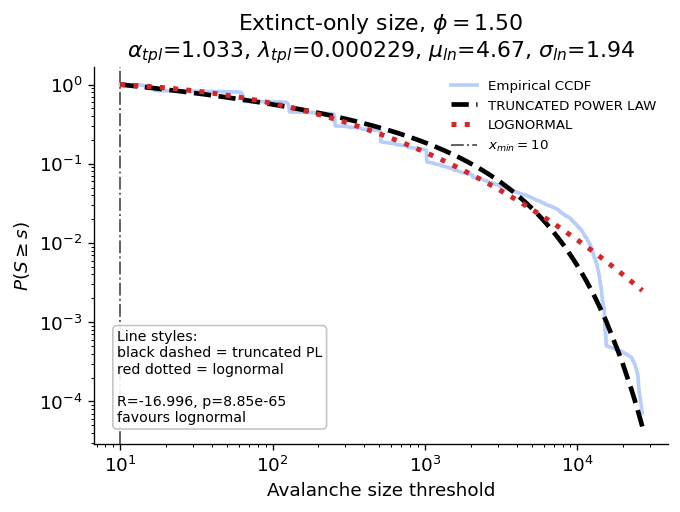

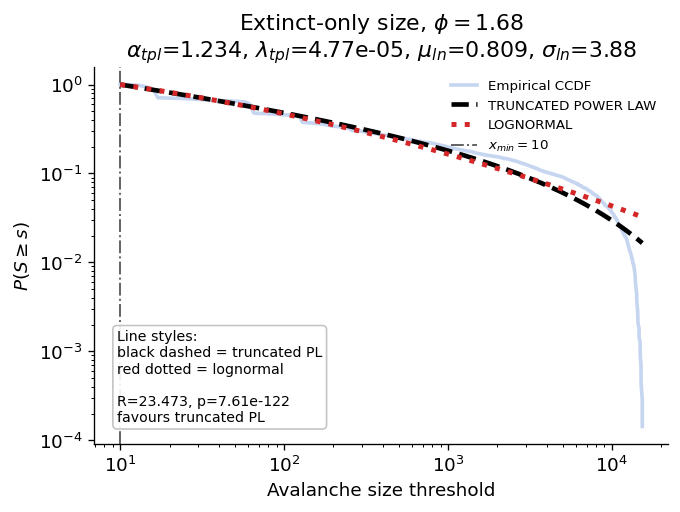

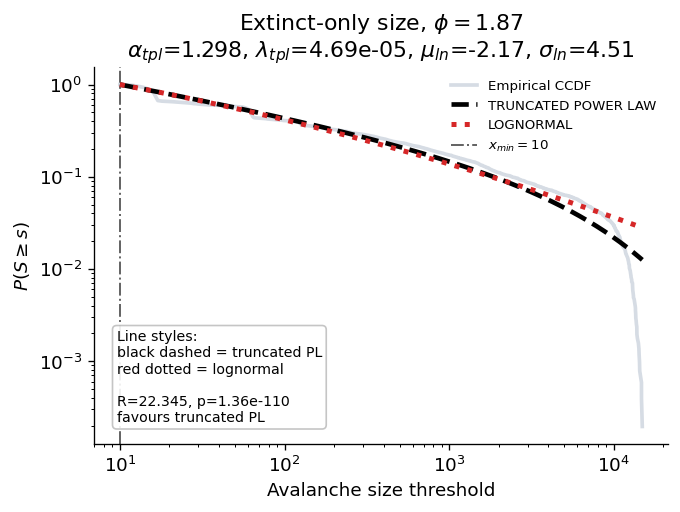

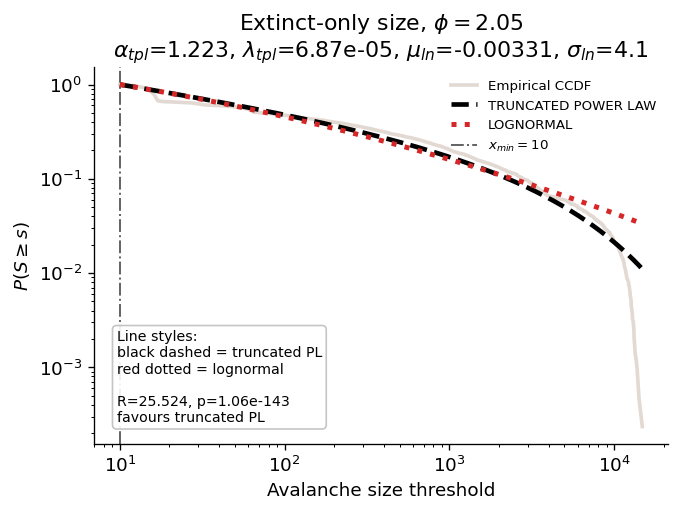

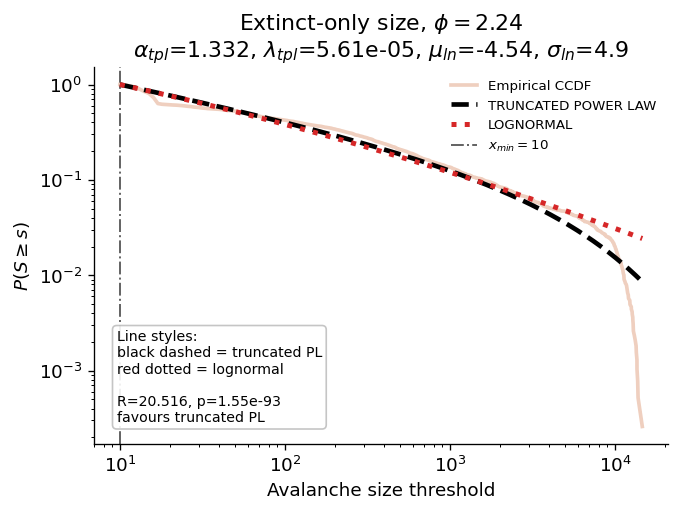

...

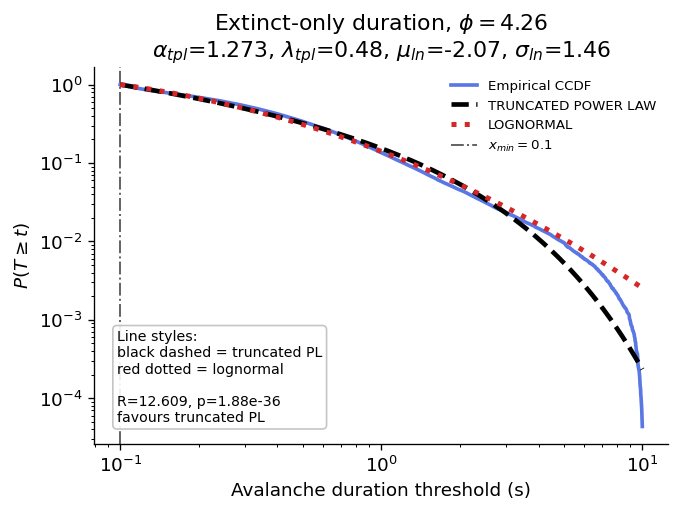

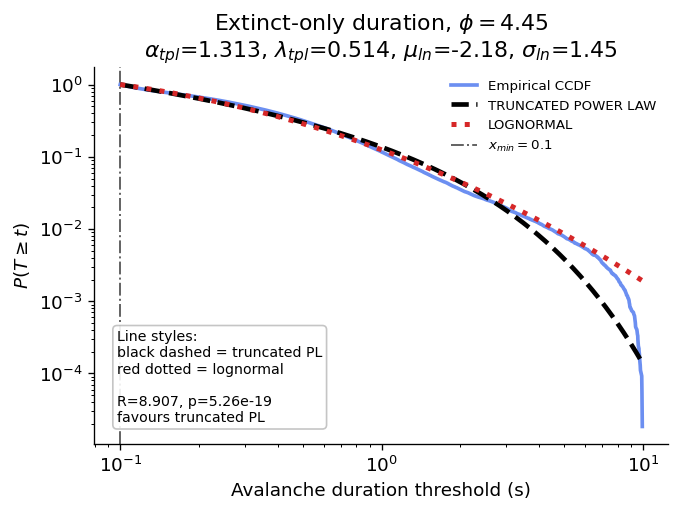

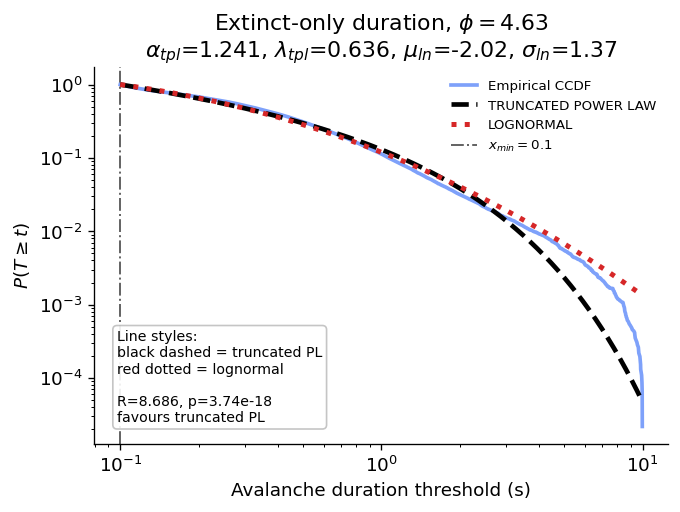

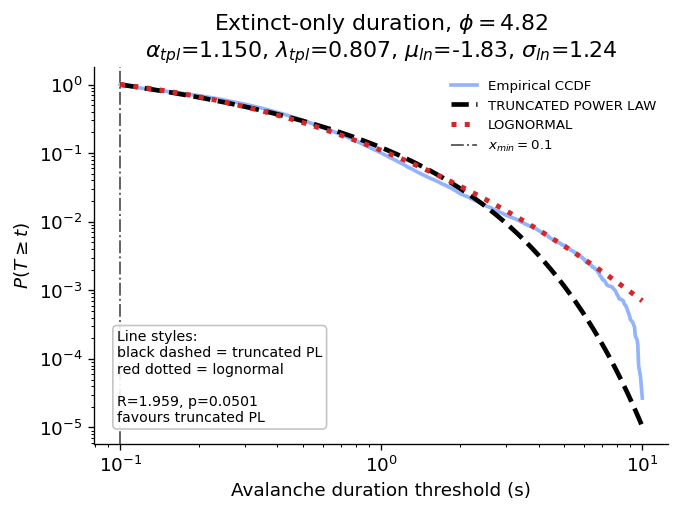

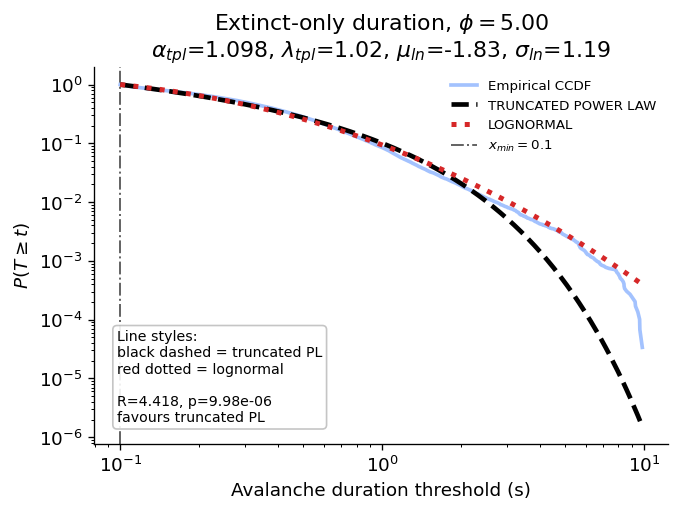

In [387]:
def get_phi_color(phi):
    nearest_phi = min(phi_to_color, key=lambda k: abs(k - phi))
    return phi_to_color[nearest_phi]
    
def plot_per_phi_ccdf_fits(metric, col, discrete, xmin, xlabel, ylabel):
    for phi in phis:
        g = fit_trials[np.isclose(fit_trials["phi"], phi)]

        values = np.asarray(g[col], float)
        values = values[np.isfinite(values)]
        values = values[values > 0]

        res = fit_truncated_vs_lognormal(
            values,
            discrete=discrete,
            xmin=xmin,
        )

        if res is None:
            continue

        fit = res["fit"]
        tail_values = values[values >= fit.xmin]
        x_emp, surv_emp = survival_curve(tail_values)

        fig, ax = plt.subplots(figsize=(5.8, 4.4))

        # -----------------------------
        # Empirical CCDF
        # -----------------------------
        ax.plot(
            x_emp,
            surv_emp,
            color=phi_to_color[phi],
            linewidth=2.2,
            linestyle="-",
            label="Empirical CCDF",
            zorder=3,
        )

        # -----------------------------
        # Truncated power law fit
        # -----------------------------
        fit.truncated_power_law.plot_ccdf(
            ax=ax,
            color="black",
            linestyle="--",
            linewidth=2.8,
            label="TRUNCATED POWER LAW",
            zorder=4,
        )

        # -----------------------------
        # Lognormal fit
        # -----------------------------
        fit.lognormal.plot_ccdf(
            ax=ax,
            color="tab:red",
            linestyle=":",
            linewidth=3.0,
            label="LOGNORMAL",
            zorder=5,
        )

        ax.axvline(
            fit.xmin,
            color="0.25",
            linestyle="-.",
            linewidth=1.2,
            alpha=0.8,
            label=fr"$x_{{min}}={fit.xmin:.3g}$",
        )

        # -----------------------------
        # Model-favouring label
        # -----------------------------
        if res["R_tpl_vs_ln"] > 0:
            favoured = "favours truncated PL"
        elif res["R_tpl_vs_ln"] < 0:
            favoured = "favours lognormal"
        else:
            favoured = "no preference"

        ax.text(
            0.04,
            0.05,
            (
                "Line styles:\n"
                "black dashed = truncated PL\n"
                "red dotted = lognormal\n\n"
                fr"R={res['R_tpl_vs_ln']:.3f}, "
                fr"p={res['p_tpl_vs_ln']:.3g}" "\n"
                f"{favoured}"
            ),
            transform=ax.transAxes,
            fontsize=8.5,
            va="bottom",
            ha="left",
            bbox=dict(
                boxstyle="round,pad=0.3",
                facecolor="white",
                edgecolor="0.75",
                alpha=0.9,
            ),
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        ax.set_title(
            fr"{title_prefix}{metric}, $\phi={phi:.2f}$"
            "\n"
            fr"$\alpha_{{tpl}}$={res['alpha_tpl']:.3f}, "
            fr"$\lambda_{{tpl}}$={res['lambda_tpl']:.3g}, "
            fr"$\mu_{{ln}}$={res['mu_lognormal']:.3g}, "
            fr"$\sigma_{{ln}}$={res['sigma_lognormal']:.3g}"
        )

        ax.legend(
            frameon=False,
            fontsize=8,
            loc="upper right",
        )

        ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout()

        safe_phi = str(round(float(phi), 4)).replace(".", "p")

        fig.savefig(
            TPL_LN_FIGDIR / f"ccdf_{metric}_phi_{safe_phi}_tpl_vs_lognormal{suffix}.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

color=phi_to_color[min(phi_to_color, key=lambda k: abs(k - phi))],
plot_per_phi_ccdf_fits(
    metric="size",
    col="size",
    discrete=True,
    xmin=SIZE_XMIN,
    xlabel="Avalanche size threshold",
    ylabel=r"$P(S \geq s)$",
)

plot_per_phi_ccdf_fits(
    metric="duration",
    col="lifetime_s",
    discrete=False,
    xmin=DURATION_XMIN,
    xlabel="Avalanche duration threshold (s)",
    ylabel=r"$P(T \geq t)$",
)

,phi,metric,R_truncated_vs_lognormal,p_truncated_vs_lognormal,xmin,alpha_truncated,lambda_truncated,mu_lognormal,sigma_lognormal,n_total,n_likelihood,tail_fraction
0,1.5000,size,-16.9956,0.0000,10.0,1.0331,0.0002,4.6681,1.9420,13981,13916,0.9954
1,1.5000,duration,24.3849,0.0000,0.1,1.0812,0.1228,-1.5732,2.1028,13981,3583,0.2563
2,1.6842,size,23.4735,0.0000,10.0,1.2338,0.0000,0.8088,3.8754,7205,6991,0.9703
3,1.6842,duration,14.0613,0.0000,0.1,1.0000,0.1039,-0.3054,1.6883,7205,3097,0.4298
4,1.8684,size,22.3448,0.0000,10.0,1.2976,0.0000,-2.1742,4.5107,5325,5109,0.9594
5,1.8684,duration,10.0727,0.0000,0.1,1.0000,0.1066,-0.2711,1.6486,5325,2398,0.4503
6,2.0526,size,25.5244,0.0000,10.0,1.2228,0.0001,-0.0033,4.1019,5050,4251,0.8418
7,2.0526,duration,3.9265,0.0001,0.1,1.0000,0.1012,-0.0623,1.5298,5050,2411,0.4774
8,2.2368,size,20.5160,0.0000,10.0,1.3315,0.0001,-4.5386,4.9036,6873,3854,0.5607
9,2.2368,duration,5.9947,0.0000,0.1,1.0000,0.1486,-0.5166,1.5494,6873,2161,0.3144


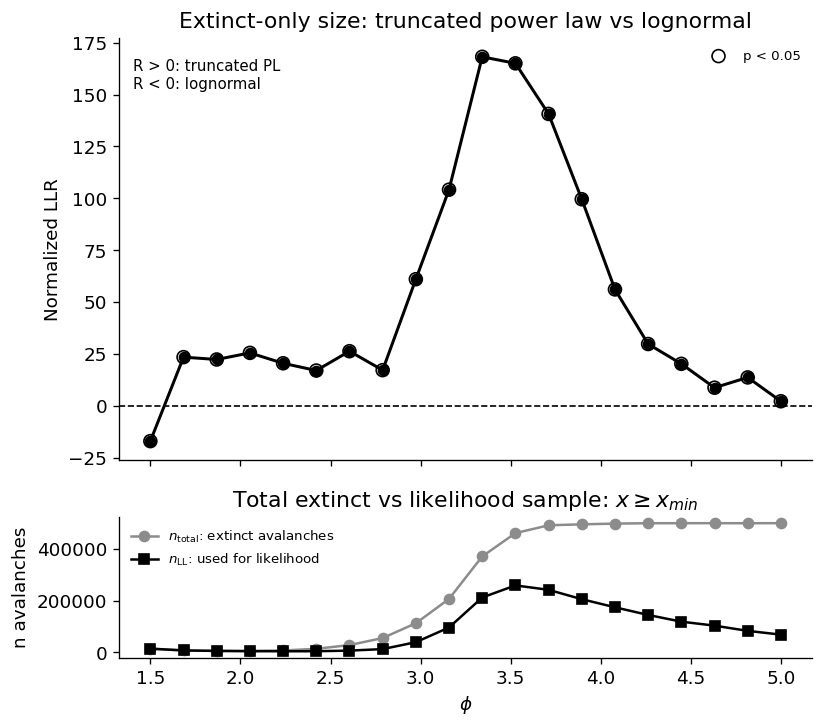

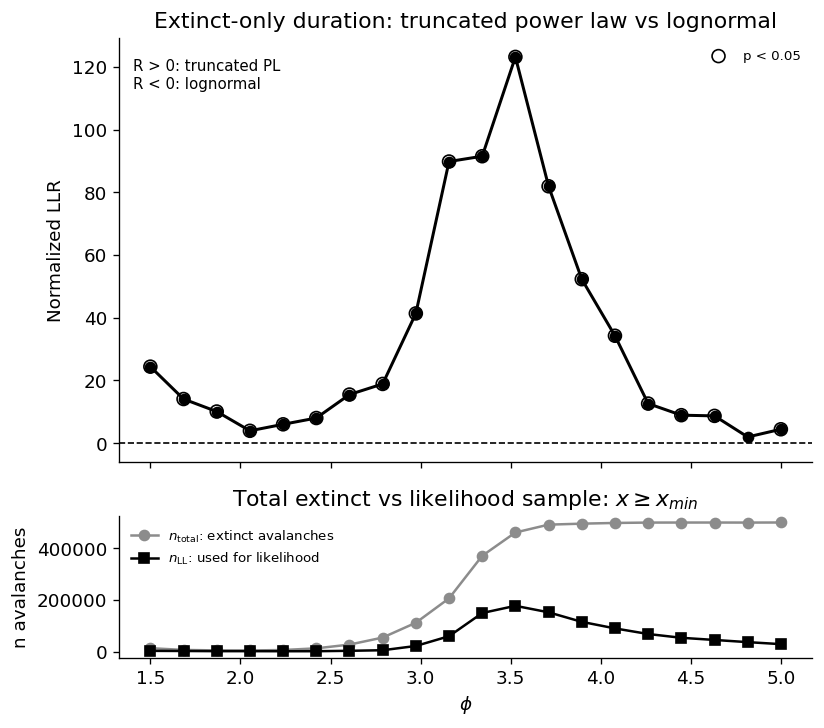

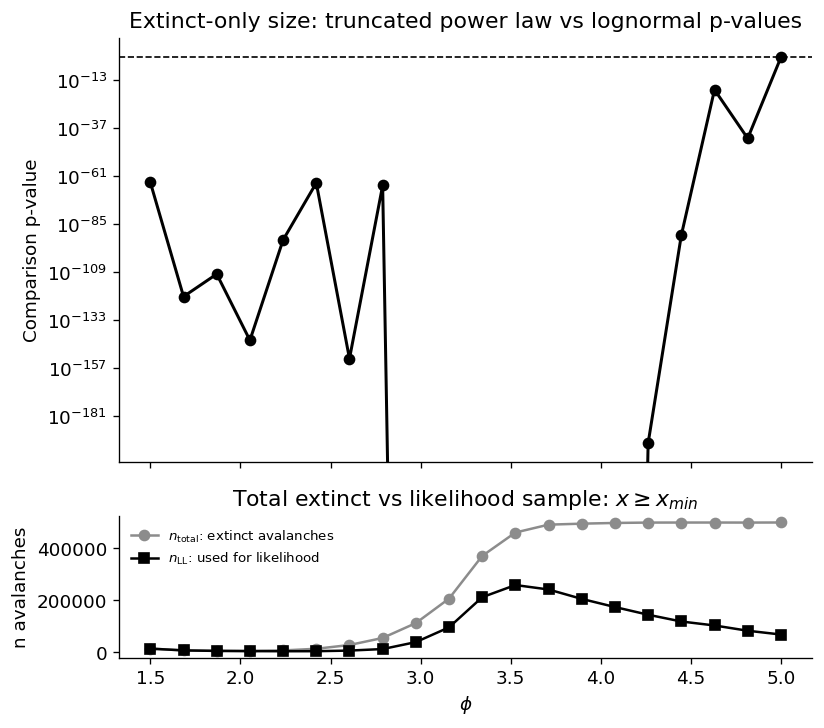

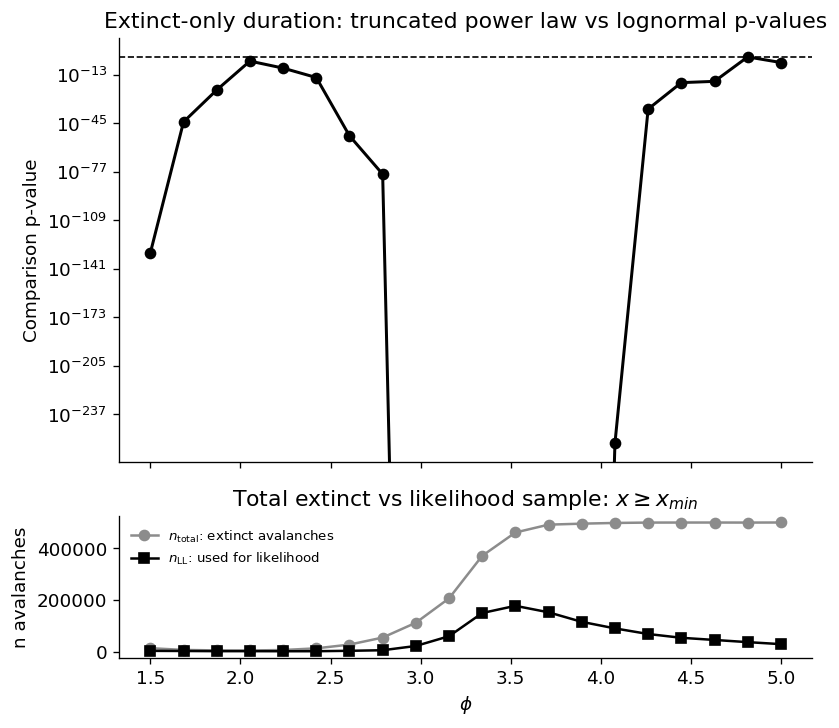

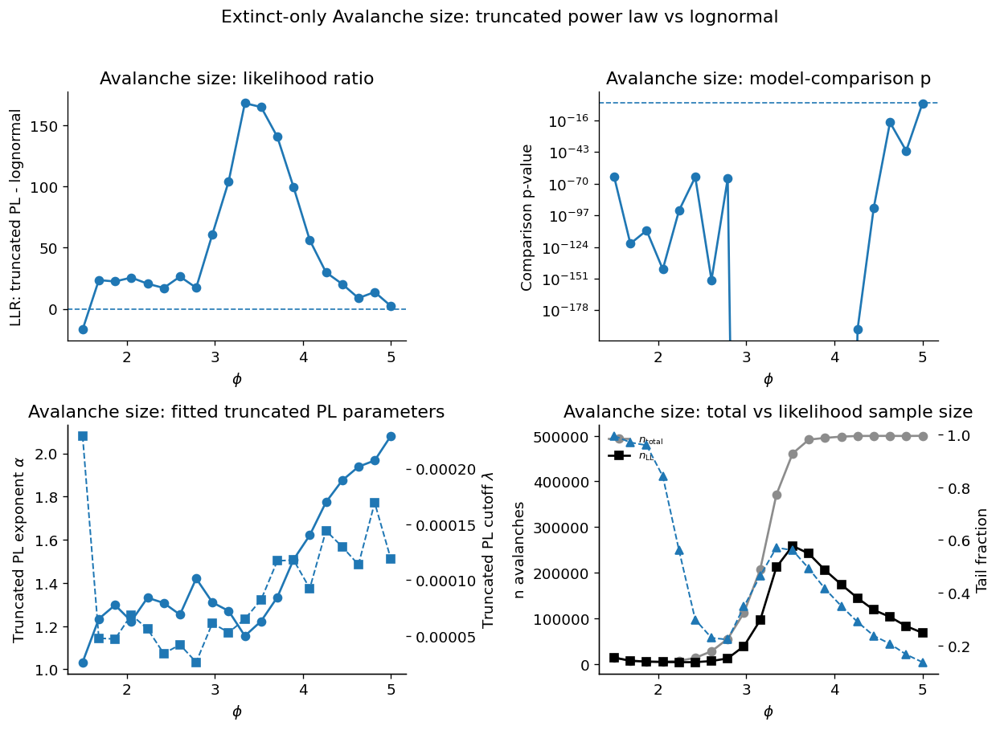

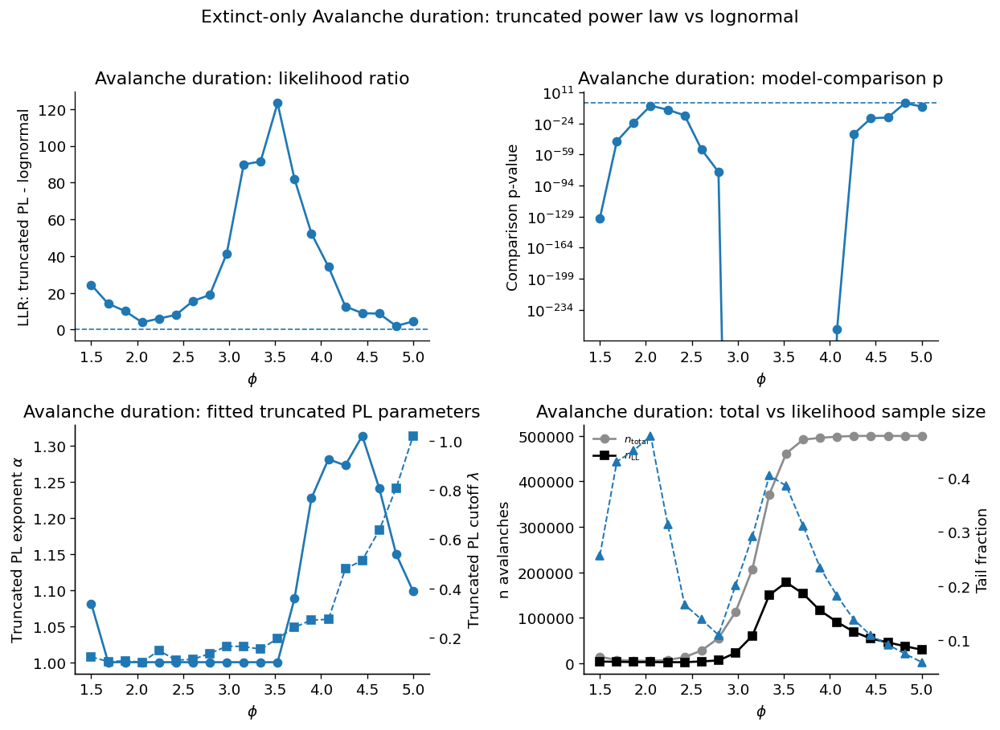

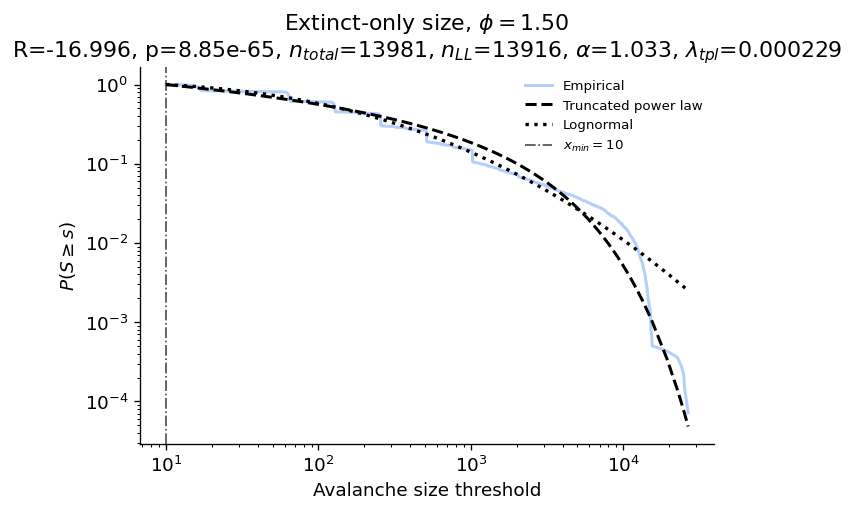


KeyboardInterrupt



In [386]:
def get_phi_color(phi):
    nearest_phi = min(phi_to_color, key=lambda k: abs(k - phi))
    return phi_to_color[nearest_phi]
# ============================================================
# Truncated power law vs lognormal only
# Boundary phi sweep data, not subsampled
# Extinct-only by default
#
# Adds:
#   n_total      = all extinct avalanches before fixed-xmin filtering
#   n_likelihood = extinct avalanches used for likelihood, x >= xmin
#
# Requires: pip install powerlaw
# ============================================================

import powerlaw

TPL_LN_FIGDIR = OUTDIR / "truncated_powerlaw_vs_lognormal_boundary_phi_extinct_only_red_middle_with_ntotal"
TPL_LN_FIGDIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Define minimum cutoffs here
# ------------------------------------------------------------

SIZE_XMIN = 10
DURATION_XMIN = 0.1


# ------------------------------------------------------------
# Data for fitting
# ------------------------------------------------------------

fit_trials = trials_plot.copy()
phis = np.sort(fit_trials["phi"].unique())

# keep same red-centred colour order
colors_raw = CMAP(np.linspace(0, 1, len(phis)))
red_idx = np.argmax(colors_raw[:, 0] - colors_raw[:, 2])
mid_idx = len(phis) // 2
colors = np.roll(colors_raw, shift=mid_idx - red_idx, axis=0)
phi_to_color = dict(zip(phis, colors))


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def survival_curve(values):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    x = np.sort(np.unique(values))
    surv = np.array([(values >= xx).mean() for xx in x])

    keep = surv > 0
    return x[keep], surv[keep]


def clean_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)


def fit_truncated_vs_lognormal(values, discrete=False, xmin=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    n_total = len(values)

    if n_total < 20:
        return None

    fit = powerlaw.Fit(
        values,
        discrete=discrete,
        xmin=xmin,
        estimate_discrete=discrete,
        verbose=False,
    )

    R, p = fit.distribution_compare(
        "truncated_power_law",
        "lognormal",
        normalized_ratio=True,
    )

    tail_values = values[values >= fit.xmin]

    return {
        "fit": fit,
        "R_tpl_vs_ln": R,
        "p_tpl_vs_ln": p,
        "xmin": fit.xmin,
        "alpha_tpl": fit.truncated_power_law.alpha,
        "lambda_tpl": fit.truncated_power_law.Lambda,
        "mu_lognormal": fit.lognormal.mu,
        "sigma_lognormal": fit.lognormal.sigma,
        "n_total": n_total,
        "n_likelihood": len(tail_values),
        "tail_fraction": len(tail_values) / n_total if n_total else np.nan,
    }


# ------------------------------------------------------------
# Run fits by phi
# ------------------------------------------------------------

rows = []

for phi in phis:
    g = fit_trials[np.isclose(fit_trials["phi"], phi)]

    for metric, col, discrete, xmin in [
        ("size", "size", True, SIZE_XMIN),
        ("duration", "lifetime_s", False, DURATION_XMIN),
    ]:
        res = fit_truncated_vs_lognormal(
            g[col],
            discrete=discrete,
            xmin=xmin,
        )

        if res is None:
            continue

        rows.append({
            "phi": phi,
            "metric": metric,
            "R_truncated_vs_lognormal": res["R_tpl_vs_ln"],
            "p_truncated_vs_lognormal": res["p_tpl_vs_ln"],
            "xmin": res["xmin"],
            "alpha_truncated": res["alpha_tpl"],
            "lambda_truncated": res["lambda_tpl"],
            "mu_lognormal": res["mu_lognormal"],
            "sigma_lognormal": res["sigma_lognormal"],
            "n_total": res["n_total"],
            "n_likelihood": res["n_likelihood"],
            "tail_fraction": res["tail_fraction"],
        })

tpl_ln_df = pd.DataFrame(rows)
tpl_ln_df.to_csv(
    TPL_LN_FIGDIR / "truncated_powerlaw_vs_lognormal_by_phi_with_ntotal.csv",
    index=False,
)

display(tpl_ln_df.round(4))


# ------------------------------------------------------------
# LLR summary plots
# R > 0 favours truncated power law
# R < 0 favours lognormal
#
# Bottom panel:
#   n_total      = extinct avalanches before fixed-xmin filtering
#   n_likelihood = avalanches used for likelihood, x >= xmin
# ------------------------------------------------------------

def plot_tpl_vs_ln_llr_with_ns(metric, filename):
    d = tpl_ln_df[tpl_ln_df["metric"] == metric].sort_values("phi")

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(7.0, 6.2),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )

    ax = axes[0]

    ax.axhline(0, color="k", linestyle="--", linewidth=1)

    ax.plot(
        d["phi"],
        d["R_truncated_vs_lognormal"],
        marker="o",
        linewidth=1.8,
        color="k",
    )

    sig = d["p_truncated_vs_lognormal"] < 0.05

    ax.scatter(
        d.loc[sig, "phi"],
        d.loc[sig, "R_truncated_vs_lognormal"],
        s=60,
        facecolors="none",
        edgecolors="k",
        linewidths=1,
        label="p < 0.05",
    )

    ax.set_ylabel("Normalized LLR")
    ax.set_title(f"{title_prefix}{metric}: truncated power law vs lognormal")

    ax.text(
        0.02,
        0.95,
        "R > 0: truncated PL\nR < 0: lognormal",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )

    ax.legend(frameon=False, fontsize=8)
    clean_ax(ax)

    ax = axes[1]

    ax.plot(
        d["phi"],
        d["n_total"],
        marker="o",
        linewidth=1.5,
        color="0.55",
        label=r"$n_{\mathrm{total}}$: extinct avalanches",
    )

    ax.plot(
        d["phi"],
        d["n_likelihood"],
        marker="s",
        linewidth=1.5,
        color="k",
        label=r"$n_{\mathrm{LL}}$: used for likelihood",
    )

    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("n avalanches")
    ax.set_title(fr"Total extinct vs likelihood sample: $x \geq x_{{min}}$")
    ax.legend(frameon=False, fontsize=8)
    clean_ax(ax)

    fig.tight_layout()

    fig.savefig(
        TPL_LN_FIGDIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_tpl_vs_ln_llr_with_ns(
    metric="size",
    filename=f"llr_size_truncated_powerlaw_vs_lognormal_with_ntotal_and_nll{suffix}.png",
)

plot_tpl_vs_ln_llr_with_ns(
    metric="duration",
    filename=f"llr_duration_truncated_powerlaw_vs_lognormal_with_ntotal_and_nll{suffix}.png",
)


# ------------------------------------------------------------
# P-value summary plots with n_total and n_likelihood underneath
# ------------------------------------------------------------

def plot_tpl_vs_ln_p_with_ns(metric, filename):
    d = tpl_ln_df[tpl_ln_df["metric"] == metric].sort_values("phi")

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(7.0, 6.2),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )

    ax = axes[0]

    ax.axhline(0.05, color="k", linestyle="--", linewidth=1)

    ax.plot(
        d["phi"],
        d["p_truncated_vs_lognormal"],
        marker="o",
        linewidth=1.8,
        color="k",
    )

    ax.set_yscale("log")
    ax.set_ylabel("Comparison p-value")
    ax.set_title(f"{title_prefix}{metric}: truncated power law vs lognormal p-values")
    clean_ax(ax)

    ax = axes[1]

    ax.plot(
        d["phi"],
        d["n_total"],
        marker="o",
        linewidth=1.5,
        color="0.55",
        label=r"$n_{\mathrm{total}}$: extinct avalanches",
    )

    ax.plot(
        d["phi"],
        d["n_likelihood"],
        marker="s",
        linewidth=1.5,
        color="k",
        label=r"$n_{\mathrm{LL}}$: used for likelihood",
    )

    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("n avalanches")
    ax.set_title(fr"Total extinct vs likelihood sample: $x \geq x_{{min}}$")
    ax.legend(frameon=False, fontsize=8)
    clean_ax(ax)

    fig.tight_layout()

    fig.savefig(
        TPL_LN_FIGDIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_tpl_vs_ln_p_with_ns(
    metric="size",
    filename=f"p_size_truncated_powerlaw_vs_lognormal_with_ntotal_and_nll{suffix}.png",
)

plot_tpl_vs_ln_p_with_ns(
    metric="duration",
    filename=f"p_duration_truncated_powerlaw_vs_lognormal_with_ntotal_and_nll{suffix}.png",
)


# ------------------------------------------------------------
# Parameter/sample-size summary plots
# ------------------------------------------------------------

for metric, label in [
    ("size", "Avalanche size"),
    ("duration", "Avalanche duration"),
]:
    d = tpl_ln_df[tpl_ln_df["metric"] == metric].sort_values("phi")

    fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.4))

    ax = axes[0, 0]
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.plot(
        d["phi"],
        d["R_truncated_vs_lognormal"],
        marker="o",
        linewidth=1.6,
    )
    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("LLR: truncated PL - lognormal")
    ax.set_title(f"{label}: likelihood ratio")
    clean_ax(ax)

    ax = axes[0, 1]
    ax.axhline(0.05, linestyle="--", linewidth=1)
    ax.plot(
        d["phi"],
        d["p_truncated_vs_lognormal"],
        marker="o",
        linewidth=1.6,
    )
    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("Comparison p-value")
    ax.set_title(f"{label}: model-comparison p")
    ax.set_yscale("log")
    clean_ax(ax)

    ax = axes[1, 0]
    ax.plot(
        d["phi"],
        d["alpha_truncated"],
        marker="o",
        linewidth=1.6,
        label=r"$\alpha$",
    )

    ax2 = ax.twinx()
    ax2.plot(
        d["phi"],
        d["lambda_truncated"],
        marker="s",
        linestyle="--",
        linewidth=1.2,
        label=r"$\lambda$",
    )

    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel(r"Truncated PL exponent $\alpha$")
    ax2.set_ylabel(r"Truncated PL cutoff $\lambda$")
    ax.set_title(f"{label}: fitted truncated PL parameters")
    clean_ax(ax)

    ax = axes[1, 1]
    ax.plot(
        d["phi"],
        d["n_total"],
        marker="o",
        linewidth=1.6,
        color="0.55",
        label=r"$n_{\mathrm{total}}$",
    )
    ax.plot(
        d["phi"],
        d["n_likelihood"],
        marker="s",
        linewidth=1.6,
        color="k",
        label=r"$n_{\mathrm{LL}}$",
    )

    ax2 = ax.twinx()
    ax2.plot(
        d["phi"],
        d["tail_fraction"],
        marker="^",
        linestyle="--",
        linewidth=1.2,
    )

    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("n avalanches")
    ax2.set_ylabel("Tail fraction")
    ax.set_title(f"{label}: total vs likelihood sample size")
    ax.legend(frameon=False, fontsize=8)
    clean_ax(ax)

    fig.suptitle(
        f"{title_prefix}{label}: truncated power law vs lognormal",
        y=1.02,
    )

    fig.tight_layout()

    fig.savefig(
        TPL_LN_FIGDIR / f"{metric}_truncated_powerlaw_vs_lognormal_summary_with_ntotal_and_nll{suffix}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


# ------------------------------------------------------------
# Per-phi CCDF plots with fitted curves
# ------------------------------------------------------------

def plot_per_phi_ccdf_fits(metric, col, discrete, xmin, xlabel, ylabel):
    for phi in phis:
        g = fit_trials[np.isclose(fit_trials["phi"], phi)]

        values = np.asarray(g[col], float)
        values = values[np.isfinite(values)]
        values = values[values > 0]

        res = fit_truncated_vs_lognormal(
            values,
            discrete=discrete,
            xmin=xmin,
        )

        if res is None:
            continue

        fit = res["fit"]
        tail_values = values[values >= fit.xmin]
        x_emp, surv_emp = survival_curve(tail_values)

        fig, ax = plt.subplots(figsize=(5.8, 4.4))

        ax.plot(
            x_emp,
            surv_emp,
            color=phi_to_color[phi],
            linewidth=1.8,
            label="Empirical",
        )

        fit.truncated_power_law.plot_ccdf(
            ax=ax,
            color="k",
            linestyle="--",
            linewidth=1.8,
            label="Truncated power law",
        )

        fit.lognormal.plot_ccdf(
            ax=ax,
            color="k",
            linestyle=":",
            linewidth=2.0,
            label="Lognormal",
        )

        ax.axvline(
            fit.xmin,
            color="k",
            linestyle="-.",
            linewidth=1,
            alpha=0.7,
            label=fr"$x_{{min}}={fit.xmin:.3g}$",
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        ax.set_title(
            fr"{title_prefix}{metric}, $\phi={phi:.2f}$"
            "\n"
            fr"R={res['R_tpl_vs_ln']:.3f}, p={res['p_tpl_vs_ln']:.3g}, "
            fr"$n_{{total}}$={res['n_total']}, "
            fr"$n_{{LL}}$={res['n_likelihood']}, "
            fr"$\alpha$={res['alpha_tpl']:.3f}, "
            fr"$\lambda_{{tpl}}$={res['lambda_tpl']:.3g}"
        )

        ax.legend(frameon=False, fontsize=8)
        clean_ax(ax)

        fig.tight_layout()

        safe_phi = str(round(float(phi), 4)).replace(".", "p")

        fig.savefig(
            TPL_LN_FIGDIR / f"ccdf_{metric}_phi_{safe_phi}_tpl_vs_lognormal{suffix}.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


plot_per_phi_ccdf_fits(
    metric="size",
    col="size",
    discrete=True,
    xmin=SIZE_XMIN,
    xlabel="Avalanche size threshold",
    ylabel=r"$P(S \geq s)$",
)

plot_per_phi_ccdf_fits(
    metric="duration",
    col="lifetime_s",
    discrete=False,
    xmin=DURATION_XMIN,
    xlabel="Avalanche duration threshold (s)",
    ylabel=r"$P(T \geq t)$",
)

print("Saved figures to:", TPL_LN_FIGDIR)

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd

# ============================================================
# Check completed / missing parameter jobs while grid is running
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_iw_sparse_avalanche_icg_20x20_20phis_5seeds_10000avals"
)

TRIALDIR = OUTDIR / "avalanche_trials_by_network"
ICGDIR = OUTDIR / "icg_rows_by_network"

design = pd.read_csv(OUTDIR / "grid_design.csv")

def expected_paths(row):
    aval_path = TRIALDIR / (
        f"combo_{int(row.combo_i):04d}_ewidx_{int(row.ew_idx):02d}_iwidx_{int(row.iw_idx):02d}_"
        f"phiidx_{int(row.phi_idx):02d}_seed_{int(row.seed_idx):02d}_avalanches.csv.gz"
    )

    icg_path = ICGDIR / (
        f"combo_{int(row.combo_i):04d}_ewidx_{int(row.ew_idx):02d}_iwidx_{int(row.iw_idx):02d}_"
        f"phiidx_{int(row.phi_idx):02d}_seed_{int(row.seed_idx):02d}_icg.csv.gz"
    )

    return aval_path, icg_path


rows = []

for row in design.itertuples(index=False):
    aval_path, icg_path = expected_paths(row)

    aval_done = aval_path.exists() and aval_path.stat().st_size > 0
    icg_done = icg_path.exists() and icg_path.stat().st_size > 0

    if aval_done and icg_done:
        status = "done"
    elif aval_done and not icg_done:
        status = "aval_only"
    elif icg_done and not aval_done:
        status = "icg_only"
    else:
        status = "missing"

    rows.append({
        "combo_i": int(row.combo_i),
        "ew_idx": int(row.ew_idx),
        "iw_idx": int(row.iw_idx),
        "phi_idx": int(row.phi_idx),
        "seed_idx": int(row.seed_idx),
        "e_w": float(row.e_w),
        "i_w": float(row.i_w),
        "phi": float(row.phi),
        "aval_done": aval_done,
        "icg_done": icg_done,
        "status": status,
    })

progress = pd.DataFrame(rows)

# ------------------------------------------------------------
# Overall status
# ------------------------------------------------------------

print("Total jobs:", len(progress))
print(progress["status"].value_counts(dropna=False))
print()
print("Fully done:", progress["status"].eq("done").sum(), "/", len(progress))
print("Percent done:", 100 * progress["status"].eq("done").mean())

# ------------------------------------------------------------
# Completion by phi
# ------------------------------------------------------------

by_phi = (
    progress
    .assign(done=progress["status"].eq("done"))
    .groupby("phi", as_index=False)
    .agg(
        n_jobs=("done", "size"),
        n_done=("done", "sum"),
    )
)

by_phi["frac_done"] = by_phi["n_done"] / by_phi["n_jobs"]

display(by_phi)

# ------------------------------------------------------------
# Completion by e_w / i_w combo
# ------------------------------------------------------------

by_combo = (
    progress
    .assign(done=progress["status"].eq("done"))
    .groupby(["combo_i", "ew_idx", "iw_idx", "e_w", "i_w"], as_index=False)
    .agg(
        n_jobs=("done", "size"),
        n_done=("done", "sum"),
    )
)

by_combo["frac_done"] = by_combo["n_done"] / by_combo["n_jobs"]

display(by_combo.sort_values("frac_done", ascending=False).head(20))
display(by_combo.sort_values("frac_done", ascending=True).head(20))

# ------------------------------------------------------------
# Missing jobs table
# ------------------------------------------------------------

missing = progress[progress["status"] != "done"].copy()

display(missing.head(50))

missing_path = OUTDIR / "currently_missing_or_incomplete_jobs.csv"
missing.to_csv(missing_path, index=False)

progress_path = OUTDIR / "current_job_progress_scan.csv"
progress.to_csv(progress_path, index=False)

print("Saved:", progress_path)
print("Saved:", missing_path)

Total jobs: 40000
status
done       24402
missing    15598
Name: count, dtype: int64

Fully done: 24402 / 40000
Percent done: 61.004999999999995


,phi,n_jobs,n_done,frac_done
0,1.500000,2000,1220,0.6100
1,1.736842,2000,1220,0.6100
2,1.973684,2000,1221,0.6105
3,2.210526,2000,1221,0.6105
4,2.447368,2000,1220,0.6100
5,2.684211,2000,1220,0.6100
6,2.921053,2000,1220,0.6100
7,3.157895,2000,1220,0.6100
8,3.394737,2000,1220,0.6100
9,3.631579,2000,1220,0.6100


,combo_i,ew_idx,iw_idx,e_w,i_w,n_jobs,n_done,frac_done
0,0,0,0,0.5,0.000000,100,100,1.0
1,1,0,1,0.5,7.894737,100,100,1.0
2,2,0,2,0.5,15.789474,100,100,1.0
3,3,0,3,0.5,23.684211,100,100,1.0
4,4,0,4,0.5,31.578947,100,100,1.0
5,5,0,5,0.5,39.473684,100,100,1.0
6,6,0,6,0.5,47.368421,100,100,1.0
7,7,0,7,0.5,55.263158,100,100,1.0
8,8,0,8,0.5,63.157895,100,100,1.0
9,9,0,9,0.5,71.052632,100,100,1.0


,combo_i,ew_idx,iw_idx,e_w,i_w,n_jobs,n_done,frac_done
399,399,19,19,20.000000,150.000000,100,0,0.0
398,398,19,18,20.000000,142.105263,100,0,0.0
397,397,19,17,20.000000,134.210526,100,0,0.0
396,396,19,16,20.000000,126.315789,100,0,0.0
395,395,19,15,20.000000,118.421053,100,0,0.0
394,394,19,14,20.000000,110.526316,100,0,0.0
393,393,19,13,20.000000,102.631579,100,0,0.0
392,392,19,12,20.000000,94.736842,100,0,0.0
328,328,16,8,16.921053,63.157895,100,0,0.0
329,329,16,9,16.921053,71.052632,100,0,0.0


,combo_i,ew_idx,iw_idx,phi_idx,seed_idx,e_w,i_w,phi,aval_done,icg_done,status
24400,244,12,4,0,0,12.815789,31.578947,1.500000,False,False,missing
24401,244,12,4,0,1,12.815789,31.578947,1.500000,False,False,missing
24402,244,12,4,0,2,12.815789,31.578947,1.500000,False,False,missing
24403,244,12,4,0,3,12.815789,31.578947,1.500000,False,False,missing
24404,244,12,4,0,4,12.815789,31.578947,1.500000,False,False,missing
24405,244,12,4,1,0,12.815789,31.578947,1.736842,False,False,missing
24406,244,12,4,1,1,12.815789,31.578947,1.736842,False,False,missing
24407,244,12,4,1,2,12.815789,31.578947,1.736842,False,False,missing
24408,244,12,4,1,3,12.815789,31.578947,1.736842,False,False,missing
24409,244,12,4,1,4,12.815789,31.578947,1.736842,False,False,missing


Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_iw_sparse_avalanche_icg_20x20_20phis_5seeds_10000avals/current_job_progress_scan.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_iw_sparse_avalanche_icg_20x20_20phis_5seeds_10000avals/currently_missing_or_incomplete_jobs.csv


Loaded: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_phi1p5to10_40steps_40seeds_smooth005
n phi values: 40
phi min/max: 1.5 10.0
n seed rows: 1600
MV range: 0.678333
TAU range: 0.976117

Best phi by range-normalised score:
   phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  score_sem  mean_rate_hz  mean_rate_hz_sem  frac_silent_frames  frac_active_neurons  MV_r2_mean  TAU_r2_mean  n
4.1154         1.5095        0.0044         0.3061        0.0091      0.1481     0.0076        0.5742            0.0289              0.0218               0.6283      0.9934       0.9106 40


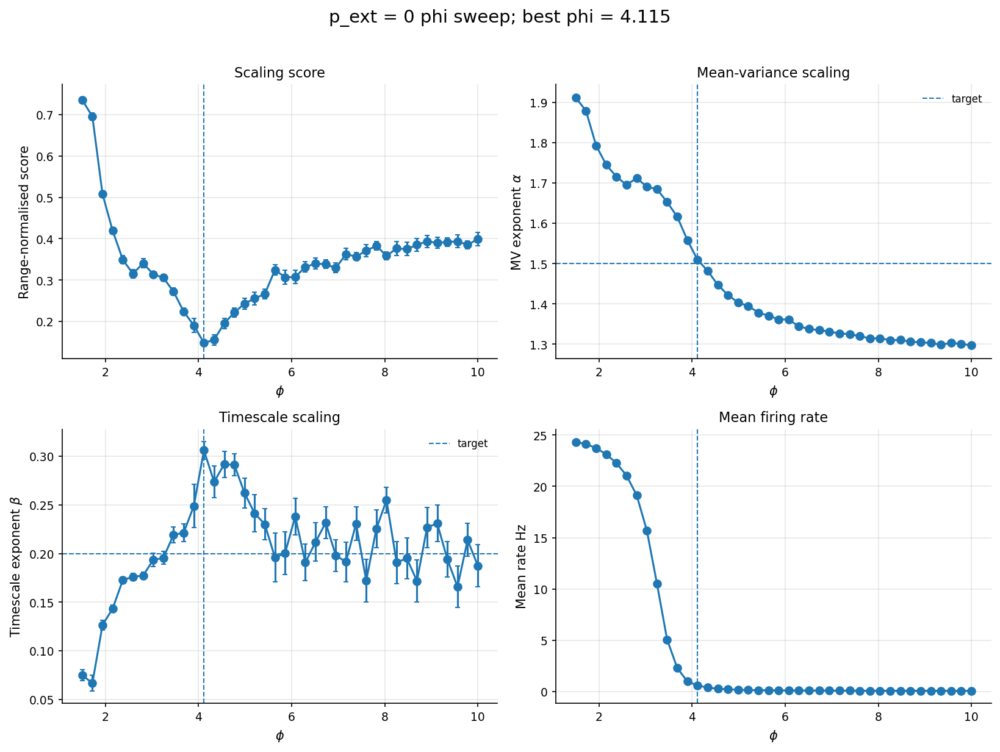

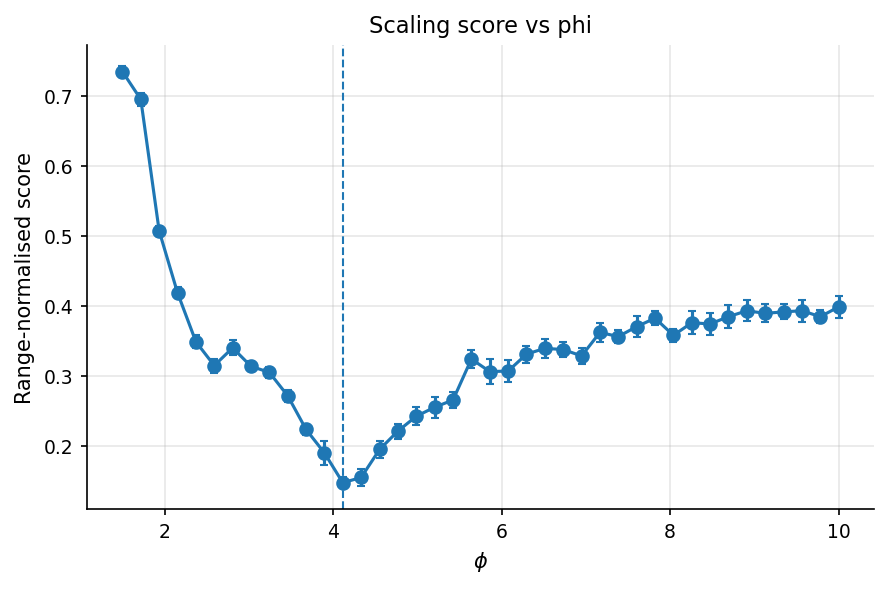

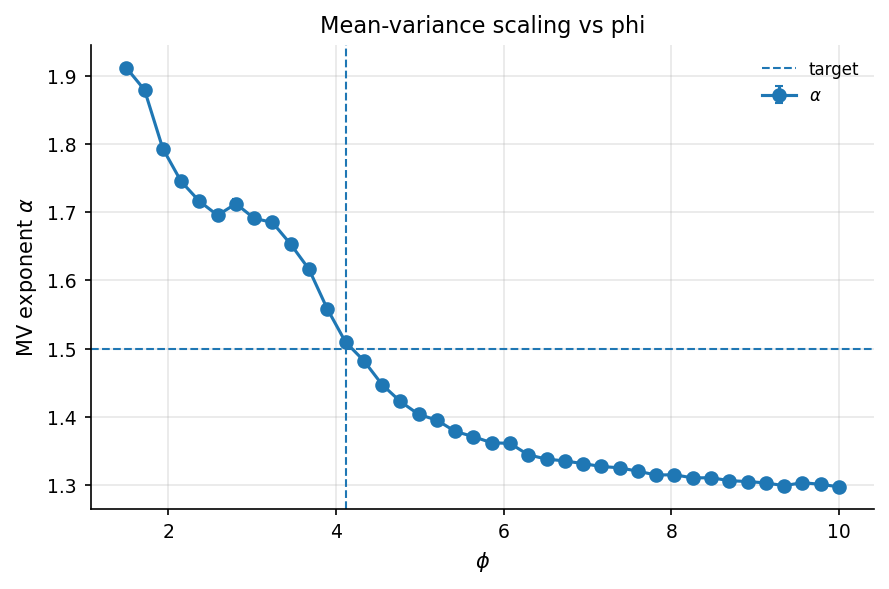

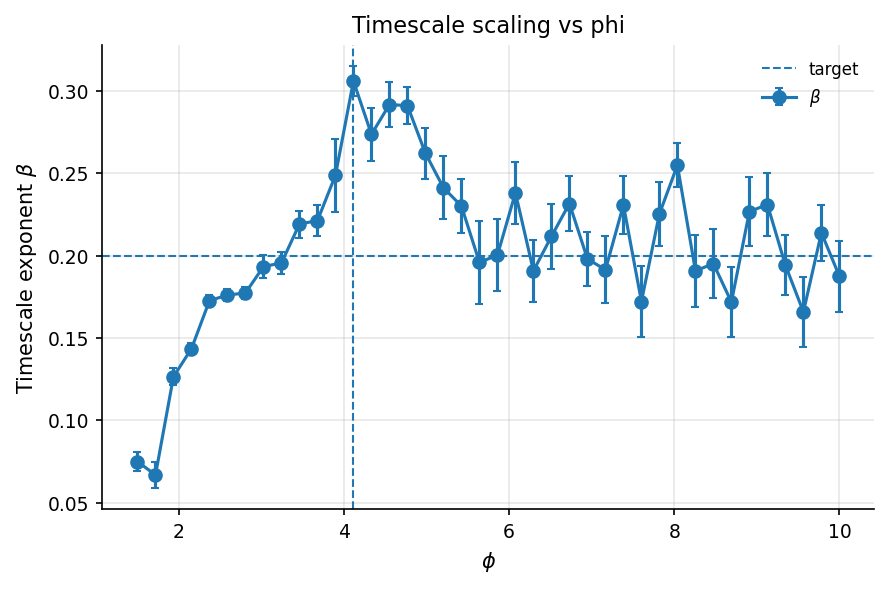

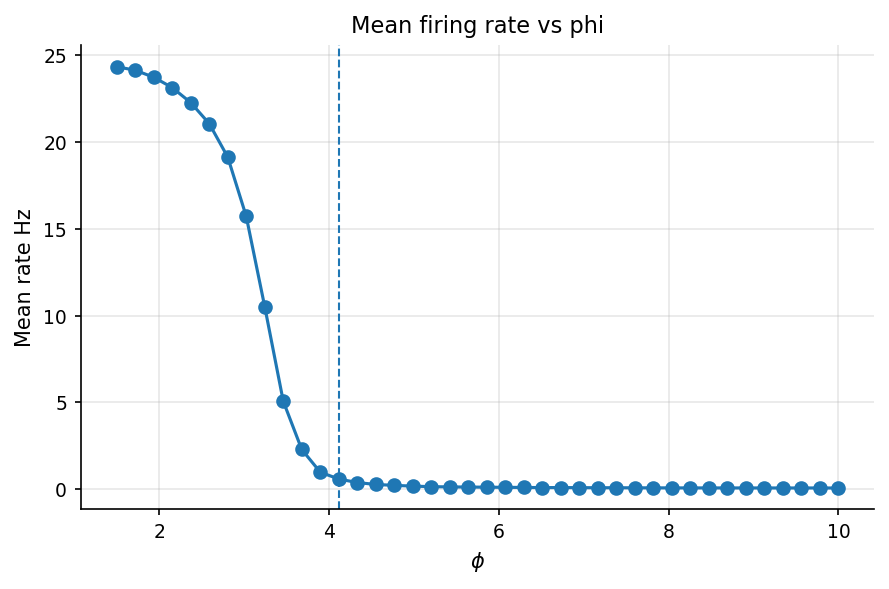

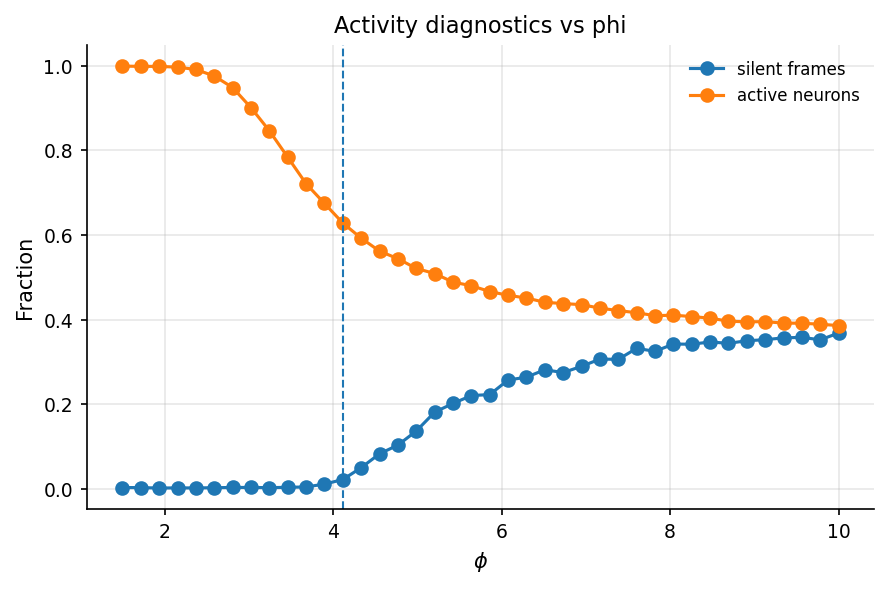

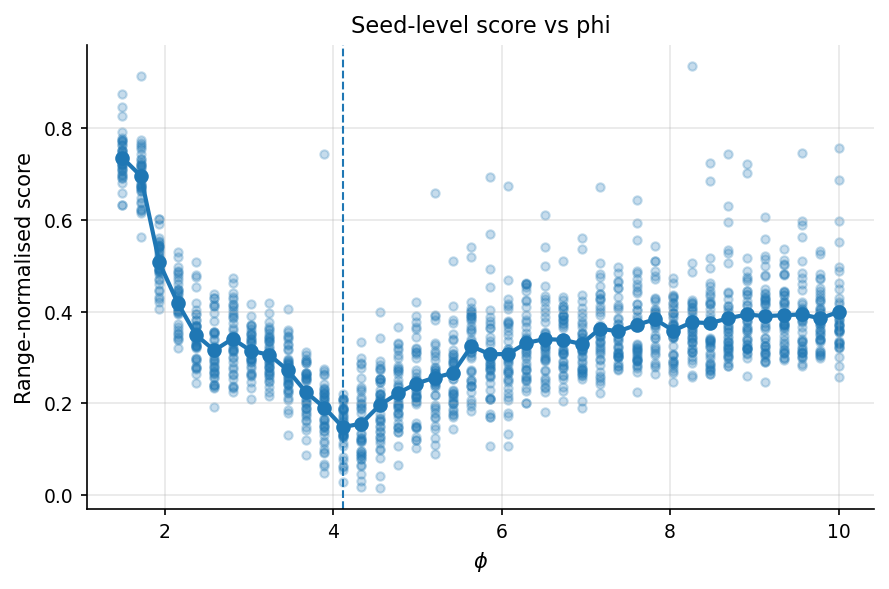

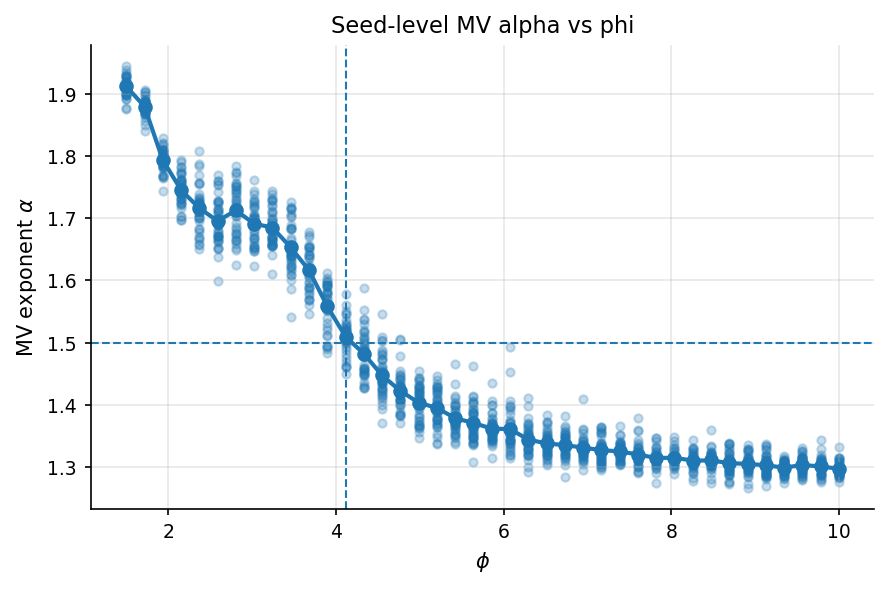

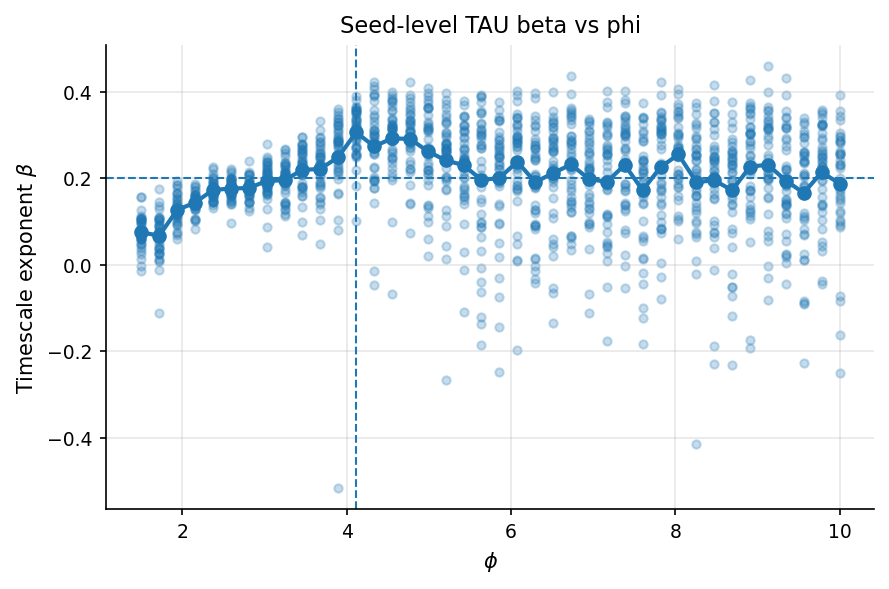


Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_phi1p5to10_40steps_40seeds_smooth005/phi_plots_range_normalised


In [70]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Load full p_ext=0 sweep: 40 phis × 40 seeds
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_"
    "phi1p5to10_40steps_40seeds_smooth005"
)

FIGDIR = OUTDIR / "phi_plots_range_normalised"
FIGDIR.mkdir(parents=True, exist_ok=True)

phi_summary = (
    pd.read_csv(OUTDIR / "phi_scaling_summary.csv")
    .replace([np.inf, -np.inf], np.nan)
    .sort_values("phi")
    .reset_index(drop=True)
)

df_exp = (
    pd.read_csv(OUTDIR / "phi_scaling_seed_exponents.csv")
    .replace([np.inf, -np.inf], np.nan)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

TARGET_MV = 1.50
TARGET_TAU = 0.20

# ============================================================
# NEW range-normalised score
# Ranges use all individual seeds across this full sweep.
# ============================================================

def observed_range(series, name):
    values = series.dropna().to_numpy(float)

    if values.size == 0:
        raise ValueError(f"No finite values for {name}.")

    lower = float(values.min())
    upper = float(values.max())
    span = upper - lower

    if not np.isfinite(span) or span <= 0:
        raise ValueError(f"No positive finite range for {name}.")

    return lower, upper, span


MV_MIN, MV_MAX, MV_RANGE = observed_range(
    df_exp["MV_alpha"], "MV_alpha"
)
TAU_MIN, TAU_MAX, TAU_RANGE = observed_range(
    df_exp["TAU_beta"], "TAU_beta"
)

df_exp["score"] = (
    (df_exp["MV_alpha"] - TARGET_MV).abs() / MV_RANGE
    + (df_exp["TAU_beta"] - TARGET_TAU).abs() / TAU_RANGE
)


def sem(series):
    values = series.dropna().to_numpy(float)
    return (
        float(values.std(ddof=1) / np.sqrt(len(values)))
        if len(values) > 1 else np.nan
    )


score_summary = (
    df_exp.groupby("phi", as_index=False)
    .agg(
        score_mean=("score", "mean"),
        score_sem=("score", sem),
        score_n_valid=("score", "count"),
    )
)

phi_summary = (
    phi_summary
    .drop(
        columns=["score_mean", "score_sem", "score_n_valid"],
        errors="ignore",
    )
    .merge(
        score_summary,
        on="phi",
        how="left",
        validate="one_to_one",
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

print("Loaded:", OUTDIR)
print("n phi values:", phi_summary["phi"].nunique())
print(
    "phi min/max:",
    phi_summary["phi"].min(),
    phi_summary["phi"].max(),
)
print("n seed rows:", len(df_exp))
print(f"MV range: {MV_RANGE:.6g}")
print(f"TAU range: {TAU_RANGE:.6g}")

valid_scores = phi_summary["score_mean"].dropna()

if valid_scores.empty:
    raise ValueError("No finite mean scores were found.")

best_idx = valid_scores.idxmin()
best_phi = float(phi_summary.loc[best_idx, "phi"])

print("\nBest phi by range-normalised score:")
print(
    phi_summary.loc[[best_idx], [
        "phi",
        "MV_alpha_mean",
        "MV_alpha_sem",
        "TAU_beta_mean",
        "TAU_beta_sem",
        "score_mean",
        "score_sem",
        "mean_rate_hz",
        "mean_rate_hz_sem",
        "frac_silent_frames",
        "frac_active_neurons",
        "MV_r2_mean",
        "TAU_r2_mean",
        "n",
    ]]
    .round(4)
    .to_string(index=False)
)

# Save recalculated results separately from the source CSVs.
phi_summary.to_csv(
    FIGDIR / "range_normalised_scaling_summary.csv",
    index=False,
)
df_exp.to_csv(
    FIGDIR / "range_normalised_seed_scores.csv",
    index=False,
)

pd.DataFrame([
    {
        "metric": "MV_alpha",
        "target": TARGET_MV,
        "observed_min": MV_MIN,
        "observed_max": MV_MAX,
        "observed_range": MV_RANGE,
    },
    {
        "metric": "TAU_beta",
        "target": TARGET_TAU,
        "observed_min": TAU_MIN,
        "observed_max": TAU_MAX,
        "observed_range": TAU_RANGE,
    },
]).to_csv(FIGDIR / "score_normalisation.csv", index=False)

# ============================================================
# Helper
# ============================================================

def finish(name):
    plt.tight_layout()
    plt.savefig(FIGDIR / name, dpi=250)
    plt.show()
    plt.close()

# ============================================================
# Main 2 × 2 phi summary plot
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.ravel()

# Score
ax = axes[0]
ax.errorbar(
    phi_summary["phi"],
    phi_summary["score_mean"],
    yerr=phi_summary["score_sem"],
    marker="o",
    linewidth=1.5,
    capsize=2,
)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Range-normalised score")
ax.set_title("Scaling score")
ax.grid(alpha=0.3)

# MV alpha
ax = axes[1]
ax.errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    yerr=phi_summary["MV_alpha_sem"],
    marker="o",
    linewidth=1.5,
    capsize=2,
)
ax.axhline(TARGET_MV, linestyle="--", linewidth=1, label="target")
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"MV exponent $\alpha$")
ax.set_title("Mean-variance scaling")
ax.legend(frameon=False)
ax.grid(alpha=0.3)

# TAU beta
ax = axes[2]
ax.errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    yerr=phi_summary["TAU_beta_sem"],
    marker="o",
    linewidth=1.5,
    capsize=2,
)
ax.axhline(TARGET_TAU, linestyle="--", linewidth=1, label="target")
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"Timescale exponent $\beta$")
ax.set_title("Timescale scaling")
ax.legend(frameon=False)
ax.grid(alpha=0.3)

# Mean rate
ax = axes[3]
ax.errorbar(
    phi_summary["phi"],
    phi_summary["mean_rate_hz"],
    yerr=phi_summary["mean_rate_hz_sem"],
    marker="o",
    linewidth=1.5,
    capsize=2,
)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Mean rate Hz")
ax.set_title("Mean firing rate")
ax.grid(alpha=0.3)

fig.suptitle(
    f"p_ext = 0 phi sweep; best phi = {best_phi:.3f}",
    y=1.02,
    fontsize=14,
)
finish("phi_summary_2x2.png")

# ============================================================
# Separate clean plots
# ============================================================

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(
    phi_summary["phi"],
    phi_summary["score_mean"],
    yerr=phi_summary["score_sem"],
    marker="o",
    capsize=2,
)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Range-normalised score")
ax.set_title("Scaling score vs phi")
ax.grid(alpha=0.3)
finish("score_vs_phi.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    yerr=phi_summary["MV_alpha_sem"],
    marker="o",
    capsize=2,
    label=r"$\alpha$",
)
ax.axhline(TARGET_MV, linestyle="--", linewidth=1, label="target")
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"MV exponent $\alpha$")
ax.set_title("Mean-variance scaling vs phi")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
finish("MV_alpha_vs_phi.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    yerr=phi_summary["TAU_beta_sem"],
    marker="o",
    capsize=2,
    label=r"$\beta$",
)
ax.axhline(TARGET_TAU, linestyle="--", linewidth=1, label="target")
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"Timescale exponent $\beta$")
ax.set_title("Timescale scaling vs phi")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
finish("TAU_beta_vs_phi.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(
    phi_summary["phi"],
    phi_summary["mean_rate_hz"],
    yerr=phi_summary["mean_rate_hz_sem"],
    marker="o",
    capsize=2,
)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Mean rate Hz")
ax.set_title("Mean firing rate vs phi")
ax.grid(alpha=0.3)
finish("mean_rate_vs_phi.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    phi_summary["phi"],
    phi_summary["frac_silent_frames"],
    marker="o",
    label="silent frames",
)
ax.plot(
    phi_summary["phi"],
    phi_summary["frac_active_neurons"],
    marker="o",
    label="active neurons",
)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Fraction")
ax.set_title("Activity diagnostics vs phi")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
finish("activity_diagnostics_vs_phi.png")

# ============================================================
# Seed scatter overlays
# ============================================================

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df_exp["phi"], df_exp["score"], alpha=0.25, s=16)
ax.plot(
    phi_summary["phi"],
    phi_summary["score_mean"],
    marker="o",
    linewidth=2,
)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Range-normalised score")
ax.set_title("Seed-level score vs phi")
ax.grid(alpha=0.3)
finish("seed_score_scatter_vs_phi.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df_exp["phi"], df_exp["MV_alpha"], alpha=0.25, s=16)
ax.plot(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    marker="o",
    linewidth=2,
)
ax.axhline(TARGET_MV, linestyle="--", linewidth=1)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"MV exponent $\alpha$")
ax.set_title("Seed-level MV alpha vs phi")
ax.grid(alpha=0.3)
finish("seed_MV_alpha_scatter_vs_phi.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df_exp["phi"], df_exp["TAU_beta"], alpha=0.25, s=16)
ax.plot(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    marker="o",
    linewidth=2,
)
ax.axhline(TARGET_TAU, linestyle="--", linewidth=1)
ax.axvline(best_phi, linestyle="--", linewidth=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"Timescale exponent $\beta$")
ax.set_title("Seed-level TAU beta vs phi")
ax.grid(alpha=0.3)
finish("seed_TAU_beta_scatter_vs_phi.png")

print("\nSaved plots to:", FIGDIR)

MV alpha range: 1.26612 to 1.94445
TAU beta range: -0.516843 to 0.459274

Best phi: 4.11538
Mean range-normalised score: 0.14814
Score SEM: 0.00755483


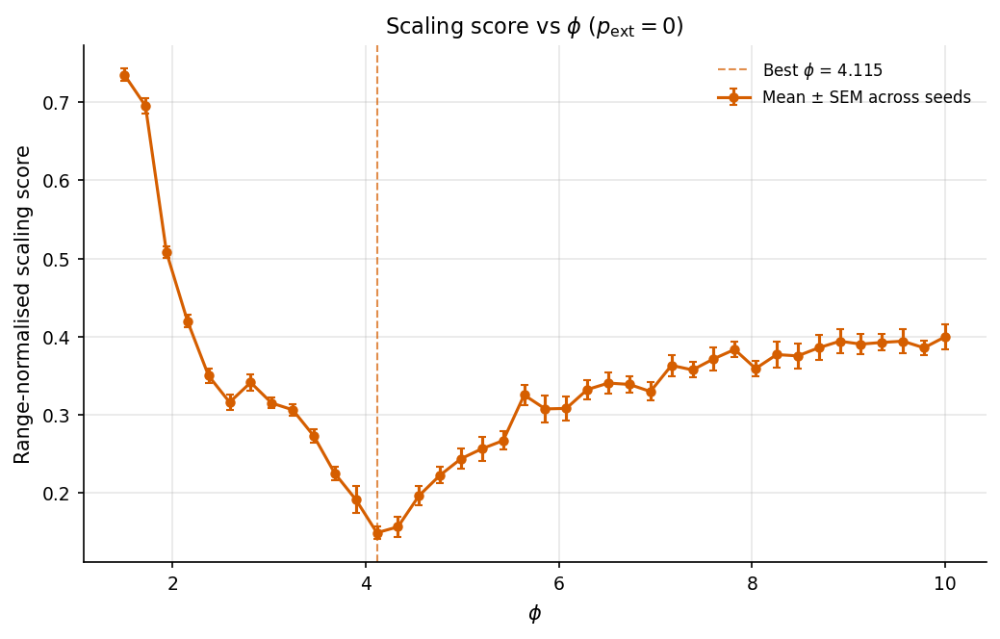


Saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_phi1p5to10_40steps_40seeds_smooth005/phi_plots_range_normalised


In [61]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Settings
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_"
    "phi1p5to10_40steps_40seeds_smooth005"
)

FIGDIR = OUTDIR / "phi_plots_range_normalised"
FIGDIR.mkdir(parents=True, exist_ok=True)

TARGET_MV = 1.50
TARGET_TAU = 0.20

# ============================================================
# Load seed-level exponents
# ============================================================

df_exp = (
    pd.read_csv(OUTDIR / "phi_scaling_seed_exponents.csv")
    .replace([np.inf, -np.inf], np.nan)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

# Global ranges across all individual seeds in this full sweep.
def observed_range(series, name):
    values = series.dropna().to_numpy(float)

    if values.size == 0:
        raise ValueError(f"No finite values for {name}.")

    lower = float(values.min())
    upper = float(values.max())
    span = upper - lower

    if not np.isfinite(span) or span <= 0:
        raise ValueError(f"No positive finite range for {name}.")

    return lower, upper, span


MV_MIN, MV_MAX, MV_RANGE = observed_range(
    df_exp["MV_alpha"], "MV_alpha"
)
TAU_MIN, TAU_MAX, TAU_RANGE = observed_range(
    df_exp["TAU_beta"], "TAU_beta"
)

print(f"MV alpha range: {MV_MIN:.6g} to {MV_MAX:.6g}")
print(f"TAU beta range: {TAU_MIN:.6g} to {TAU_MAX:.6g}")

# ============================================================
# Recalculate score per seed, then mean ± SEM
#
# score = |alpha - 1.50| / observed_alpha_range
#       + |beta  - 0.20| / observed_beta_range
# ============================================================

df_exp["score_range_normalised"] = (
    (df_exp["MV_alpha"] - TARGET_MV).abs() / MV_RANGE
    + (df_exp["TAU_beta"] - TARGET_TAU).abs() / TAU_RANGE
)


def sem(series):
    values = series.dropna().to_numpy(float)
    return (
        float(values.std(ddof=1) / np.sqrt(len(values)))
        if len(values) > 1 else np.nan
    )


score_summary = (
    df_exp.groupby("phi", as_index=False)
    .agg(
        score_mean=("score_range_normalised", "mean"),
        score_sem=("score_range_normalised", sem),
        n_valid=("score_range_normalised", "count"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

valid = score_summary.dropna(subset=["score_mean"])

if valid.empty:
    raise ValueError("No finite scores.")

best = valid.loc[valid["score_mean"].idxmin()]
best_phi = float(best["phi"])

print(f"\nBest phi: {best_phi:.6g}")
print(f"Mean range-normalised score: {best['score_mean']:.6g}")
print(f"Score SEM: {best['score_sem']:.6g}")

# ============================================================
# Score vs phi only
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.errorbar(
    score_summary["phi"],
    score_summary["score_mean"],
    yerr=score_summary["score_sem"],
    color="#D55E00",
    marker="o",
    markersize=4,
    linewidth=1.5,
    capsize=2,
    label="Mean ± SEM across seeds",
)

ax.axvline(
    best_phi,
    color="#D55E00",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    label=fr"Best $\phi$ = {best_phi:.3f}",
)

ax.set(
    xlabel=r"$\phi$",
    ylabel="Range-normalised scaling score",
    title=r"Scaling score vs $\phi$ ($p_\mathrm{ext}=0$)",
)

ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()

fig.savefig(
    FIGDIR / "range_normalised_score_vs_phi.png",
    dpi=250,
    bbox_inches="tight",
)

score_summary.to_csv(
    FIGDIR / "range_normalised_score_summary.csv",
    index=False,
)

pd.DataFrame([
    {
        "metric": "MV_alpha",
        "target": TARGET_MV,
        "observed_min": MV_MIN,
        "observed_max": MV_MAX,
        "observed_range": MV_RANGE,
    },
    {
        "metric": "TAU_beta",
        "target": TARGET_TAU,
        "observed_min": TAU_MIN,
        "observed_max": TAU_MAX,
        "observed_range": TAU_RANGE,
    },
]).to_csv(FIGDIR / "score_normalisation.csv", index=False)

plt.show()
plt.close(fig)

print("\nSaved to:", FIGDIR)

In [25]:
import os

# Set before importing NumPy/Pandas.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import json
import inspect
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm

import icg_functions as fn

# ============================================================
# Standard hiermod parameters — unchanged
# ============================================================

start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 11.7,
    "i_w": 22.4,
    "theta": 8.44,
    "p_ext": 0.00,
    "phi": 4.2,
    "smoothe": 0.05,
}

# ============================================================
# Wider sweep, approximately the same granularity
# ============================================================

PHI_VALUES = np.linspace(2.0, 5.0, 45)

N_SEEDS = 40
N_WORKERS = 20
BASE_SEED = 950000

SMOOTHE = float(start_dic["smoothe"])
T_RUN = float(start_dic["T"])

TARGET_MV = 1.50
TARGET_TAU = 0.20

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_"
    "phi2to5_45steps_40seeds_smooth005"
)
OUTDIR.mkdir(parents=True, exist_ok=True)

config = {
    "PHI_VALUES": PHI_VALUES.tolist(),
    "N_SEEDS": N_SEEDS,
    "N_WORKERS": N_WORKERS,
    "BASE_SEED": BASE_SEED,
    "SMOOTHE": SMOOTHE,
    "T_RUN": T_RUN,
    "TARGET_MV": TARGET_MV,
    "TARGET_TAU": TARGET_TAU,
    "start_dic": start_dic,
    "fit_exclude_first": True,
    "fit_exclude_last": False,
    "score_definition": (
        "abs(MV_alpha-TARGET_MV)/MV_RANGE "
        "+ abs(TAU_beta-TARGET_TAU)/TAU_RANGE"
    ),
    "score_ranges": "all finite seed exponents across this full sweep",
}

(OUTDIR / "config.json").write_text(json.dumps(config, indent=2))

print("OUTDIR:", OUTDIR)
print("TOTAL SIMS:", len(PHI_VALUES) * N_SEEDS)
print("WORKERS:", N_WORKERS)
print("PHI SPACING:", PHI_VALUES[1] - PHI_VALUES[0])

# ============================================================
# Helpers
# ============================================================

def sem(values):
    values = (
        pd.Series(values)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .to_numpy(float)
    )
    return (
        float(values.std(ddof=1) / np.sqrt(len(values)))
        if len(values) > 1 else np.nan
    )


def fit_power_slope(g, y_col):
    d = (
        g[["mean_cluster_size", y_col]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    d = d.loc[
        (d["mean_cluster_size"] > 0)
        & (d[y_col] > 0)
    ].sort_values("mean_cluster_size")

    # Same fitting convention: exclude first, retain last.
    d = d.iloc[1:]

    if len(d) < 3:
        return np.nan, np.nan, int(len(d))

    logx = np.log10(d["mean_cluster_size"].to_numpy(float))
    logy = np.log10(d[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    prediction = intercept + slope * logx

    ss_res = np.sum((logy - prediction) ** 2)
    ss_tot = np.sum((logy - logy.mean()) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(d))


def make_pars(phi, seed):
    pars = dict(start_dic)
    pars.pop("T", None)
    pars.pop("smoothe", None)

    valid_args = set(
        inspect.signature(fn.automata_EI_hiermod.__init__).parameters
    )

    if "slope" in valid_args:
        pars.pop("phi", None)
        pars["slope"] = float(phi)
    elif "phi" in valid_args:
        pars["phi"] = float(phi)
    else:
        raise ValueError("Model expects neither 'slope' nor 'phi'.")

    pars["seed"] = int(seed)
    return {k: v for k, v in pars.items() if k in valid_args}


def run_one(job):
    sim_id, phi, seed, seed_idx = job
    pars = make_pars(phi, seed)

    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**pars)
        spikes, pop_rate = fn.run_model(model, T=T_RUN)

        dt = float(pars["dt"])

        diagnostics = {
            "mean_rate_hz": float(spikes.mean() / dt),
            "pop_rate_mean_hz": float(np.mean(pop_rate)),
            "pop_rate_std_hz": float(np.std(pop_rate)),
            "frac_silent_frames": float(
                np.mean(spikes.sum(axis=0) == 0)
            ),
            "frac_active_neurons": float(
                np.mean(spikes.sum(axis=1) > 0)
            ),
        }

        spikes_smooth = fn.exp_smooth_spikes(
            spikes, dt=dt, tau=SMOOTHE
        )

        _, gen_df = fn.compute_icg_metrics(
            spikes=spikes_smooth, dt=dt
        )

    gen_df = gen_df.copy()

    aliases = {
        "MV": "mean_variance",
        "MV_norm": "mean_variance_norm",
        "TAU": "timescale",
        "TAU_norm": "timescale_norm",
        "corr_kurtosis": "kurtosis_corr",
    }

    for old, new in aliases.items():
        if new not in gen_df.columns and old in gen_df.columns:
            gen_df[new] = gen_df[old]

    MV_alpha, MV_r2, MV_n = fit_power_slope(
        gen_df, "mean_variance_norm"
    )
    TAU_beta, TAU_r2, TAU_n = fit_power_slope(
        gen_df, "timescale_norm"
    )

    score_original = (
        abs(MV_alpha - TARGET_MV)
        + 2.0 * abs(TAU_beta - TARGET_TAU)
        if np.isfinite(MV_alpha) and np.isfinite(TAU_beta)
        else np.nan
    )

    metadata = {
        "sim_id": int(sim_id),
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),
        "dt": dt,
        "T": T_RUN,
        "smoothe": SMOOTHE,
        "theta": float(pars.get("theta", np.nan)),
        "p_ext": float(pars.get("p_ext", np.nan)),
        "e_w": float(pars.get("e_w", np.nan)),
        "i_w": float(pars.get("i_w", np.nan)),
        "ei_ratio": float(pars.get("ei_ratio", np.nan)),
        "refractory_steps": int(pars.get("refractory_steps", -1)),
    }

    exp_row = {
        **metadata,
        **diagnostics,
        "MV_alpha": MV_alpha,
        "MV_r2": MV_r2,
        "MV_n_points": MV_n,
        "TAU_beta": TAU_beta,
        "TAU_r2": TAU_r2,
        "TAU_n_points": TAU_n,
        "score_original": score_original,
    }

    for key, value in metadata.items():
        gen_df[key] = value

    gen_df["mean_rate_hz"] = diagnostics["mean_rate_hz"]

    return exp_row, gen_df

# ============================================================
# Build design — same seed assignment convention
# ============================================================

jobs = []

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        sim_id = len(jobs)
        seed = BASE_SEED + sim_id
        jobs.append(
            (sim_id, float(phi), int(seed), int(seed_idx))
        )

pd.DataFrame(
    jobs,
    columns=["sim_id", "phi", "seed", "seed_idx"],
).to_csv(OUTDIR / "phi_scaling_design.csv", index=False)

# ============================================================
# Run — Linux/fork workflow
# ============================================================

rows = []
gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for exp_row, gen_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Phi scaling sweep: 2–5",
    ):
        rows.append(exp_row)
        gen_rows.append(gen_df)

        if len(rows) % 50 == 0:
            pd.DataFrame(rows).to_csv(
                OUTDIR / "phi_scaling_seed_exponents_partial.csv",
                index=False,
            )

df_exp = (
    pd.DataFrame(rows)
    .replace([np.inf, -np.inf], np.nan)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

df_icg = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "gen"])
    .reset_index(drop=True)
)

# Save raw results before calculating global normalisation.
df_exp.to_csv(
    OUTDIR / "phi_scaling_seed_exponents.csv", index=False
)
df_icg.to_csv(
    OUTDIR / "phi_scaling_icg_rows.csv", index=False
)

# ============================================================
# Global range-normalised score across this completed sweep
# ============================================================

def observed_range(series, name):
    values = series.dropna().to_numpy(float)

    if values.size == 0:
        raise ValueError(f"No finite values for {name}.")

    lower = float(values.min())
    upper = float(values.max())
    span = upper - lower

    if not np.isfinite(span) or span <= 0:
        raise ValueError(f"No positive finite range for {name}.")

    return lower, upper, span


MV_MIN, MV_MAX, MV_RANGE = observed_range(
    df_exp["MV_alpha"], "MV_alpha"
)
TAU_MIN, TAU_MAX, TAU_RANGE = observed_range(
    df_exp["TAU_beta"], "TAU_beta"
)

df_exp["MV_distance_normalised"] = (
    (df_exp["MV_alpha"] - TARGET_MV).abs() / MV_RANGE
)
df_exp["TAU_distance_normalised"] = (
    (df_exp["TAU_beta"] - TARGET_TAU).abs() / TAU_RANGE
)

# Compatible with the plotting blocks: score is the NEW score.
df_exp["score"] = (
    df_exp["MV_distance_normalised"]
    + df_exp["TAU_distance_normalised"]
)

df_exp.to_csv(
    OUTDIR / "phi_scaling_seed_exponents.csv", index=False
)

pd.DataFrame([
    {
        "metric": "MV_alpha",
        "target": TARGET_MV,
        "observed_min": MV_MIN,
        "observed_max": MV_MAX,
        "observed_range": MV_RANGE,
    },
    {
        "metric": "TAU_beta",
        "target": TARGET_TAU,
        "observed_min": TAU_MIN,
        "observed_max": TAU_MAX,
        "observed_range": TAU_RANGE,
    },
]).to_csv(OUTDIR / "score_normalisation.csv", index=False)

# ============================================================
# Summary by phi
# ============================================================

phi_summary = (
    df_exp.groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),
        MV_alpha_mean=("MV_alpha", "mean"),
        MV_alpha_sem=("MV_alpha", sem),
        MV_n_valid=("MV_alpha", "count"),
        MV_r2_mean=("MV_r2", "mean"),
        MV_r2_sem=("MV_r2", sem),
        TAU_beta_mean=("TAU_beta", "mean"),
        TAU_beta_sem=("TAU_beta", sem),
        TAU_n_valid=("TAU_beta", "count"),
        TAU_r2_mean=("TAU_r2", "mean"),
        TAU_r2_sem=("TAU_r2", sem),
        score_mean=("score", "mean"),
        score_sem=("score", sem),
        score_n_valid=("score", "count"),
        score_original_mean=("score_original", "mean"),
        score_original_sem=("score_original", sem),
        mean_rate_hz=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),
        pop_rate_mean_hz=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz=("pop_rate_std_hz", "mean"),
        frac_silent_frames=("frac_silent_frames", "mean"),
        frac_active_neurons=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

phi_summary.to_csv(
    OUTDIR / "phi_scaling_summary.csv", index=False
)

print("\nBest phi values by range-normalised score:")
print(
    phi_summary
    .dropna(subset=["score_mean"])
    .sort_values("score_mean")[[
        "phi", "MV_alpha_mean", "TAU_beta_mean",
        "score_mean", "score_sem", "score_original_mean",
        "mean_rate_hz", "score_n_valid",
    ]]
    .head(15)
    .to_string(index=False, float_format=lambda x: f"{x:.6g}")
)

print("\nDone. Outputs saved to:", OUTDIR)

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_phi2p5to4p5_30steps_40seeds_smooth005
TOTAL SIMS: 1200
WORKERS: 30
PHI SPACING: 0.06896551724137945


Phi scaling sweep: 2.5–4.5:   0%|          | 0/1200 [00:00<?, ?it/s]

Process ForkPoolWorker-78:
Process ForkPoolWorker-80:
Process ForkPoolWorker-89:
Process ForkPoolWorker-67:
Process ForkPoolWorker-71:
Traceback (most recent call last):
Process ForkPoolWorker-75:
Process ForkPoolWorker-84:
Process ForkPoolWorker-86:
Traceback (most recent call last):
Process ForkPoolWorker-65:
Traceback (most recent call last):
  File "/home/dburrows/micromamba/envs/py39/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
Traceback (most recent call last):
Traceback (most recent call last):
Process ForkPoolWorker-73:
  File "/home/dburrows/micromamba/envs/py39/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
Process ForkPoolWorker-68:
Process ForkPoolWorker-87:
Process ForkPoolWorker-90:
Process ForkPoolWorker-69:
  File "/home/dburrows/micromamba/envs/py39/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
Traceback (most recent call last):
  File "/home/dburrows/micromam

KeyboardInterrupt: 

KeyboardInterrupt: 

Loaded: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_phi2to5_45steps_40seeds_smooth005
Number of phi values: 45
Number of seed rows: 1800

Best phi by mean range-normalised seed score:
 phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  score_sem  score_original_mean  mean_rate_hz  mean_rate_hz_sem  MV_r2_mean  TAU_r2_mean  score_n_valid  n
4.25        1.49813    0.00563311        0.25926      0.014791    0.188827  0.0138137             0.217681      0.486635         0.0274636     0.99339     0.844044             40 40


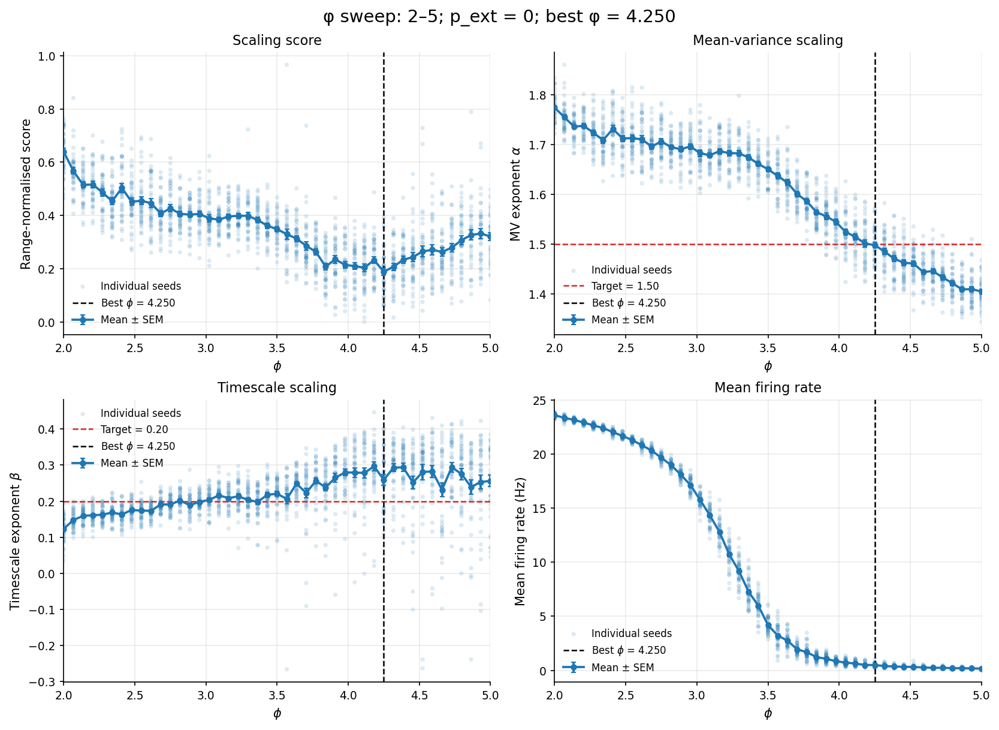

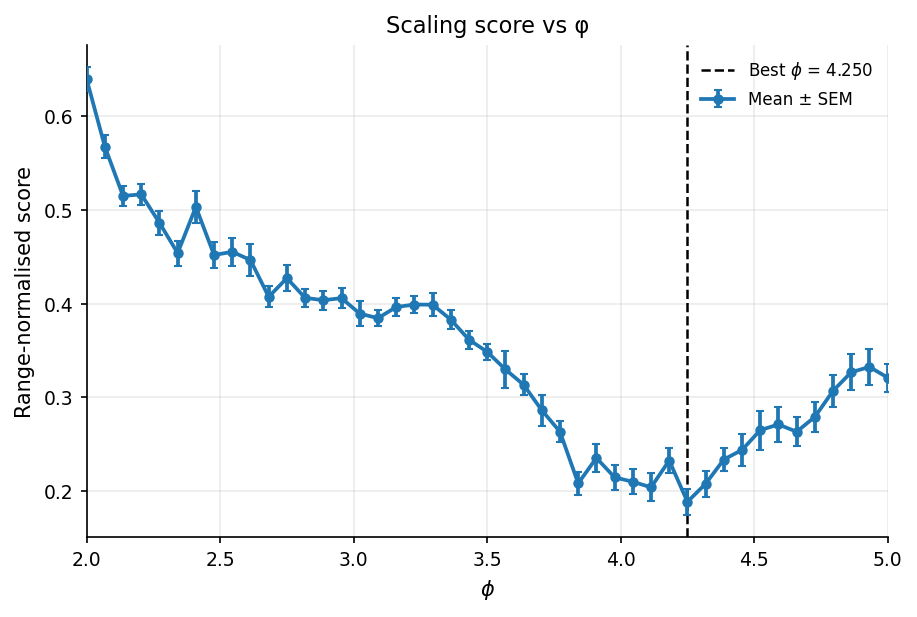

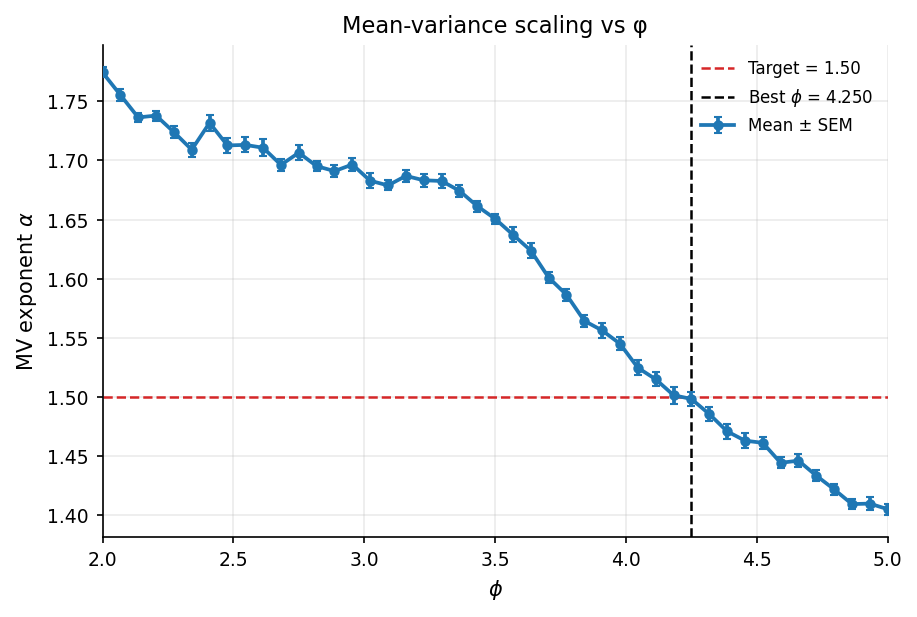

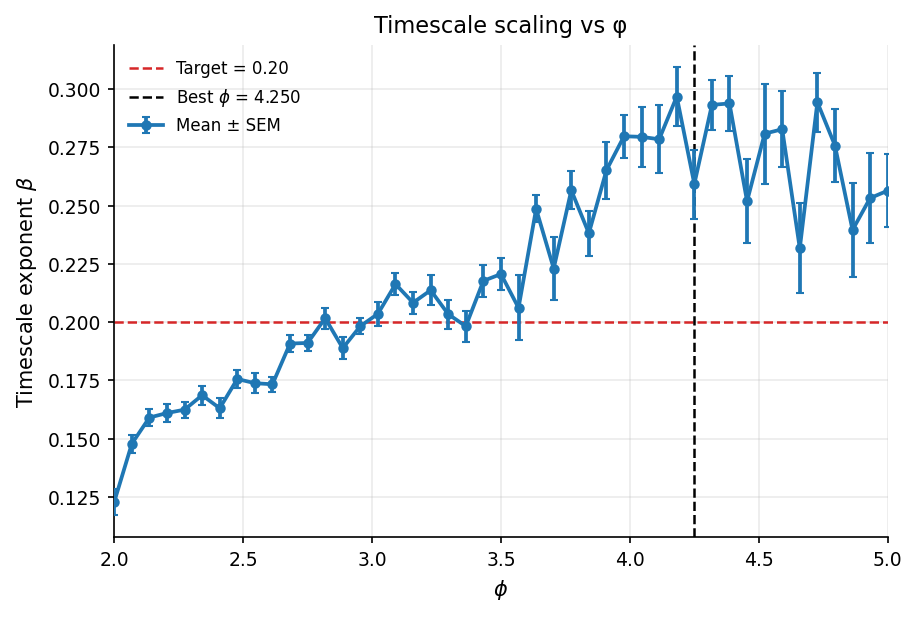

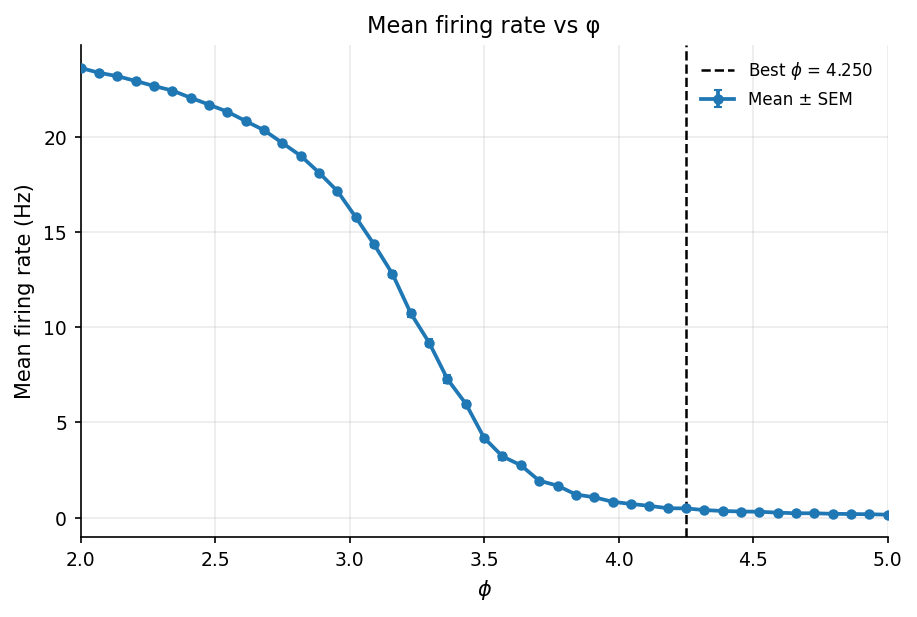


Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_phi2to5_45steps_40seeds_smooth005/phi_plots_range_normalised


In [67]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Load new phi sweep: 2–5, 45 phi values, 40 seeds
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_"
    "phi2to5_45steps_40seeds_smooth005"
)

FIGDIR = OUTDIR / "phi_plots_range_normalised"
FIGDIR.mkdir(parents=True, exist_ok=True)

phi_summary = (
    pd.read_csv(OUTDIR / "phi_scaling_summary.csv")
    .replace([np.inf, -np.inf], np.nan)
    .sort_values("phi")
    .reset_index(drop=True)
)

df_exp = (
    pd.read_csv(OUTDIR / "phi_scaling_seed_exponents.csv")
    .replace([np.inf, -np.inf], np.nan)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

TARGET_MV = 1.50
TARGET_TAU = 0.20
PHI_MIN, PHI_MAX = 2.0, 5.0

# The new simulation script already saved:
# score = |alpha - 1.50| / observed_alpha_range
#       + |beta  - 0.20| / observed_beta_range

valid_scores = phi_summary["score_mean"].dropna()

if valid_scores.empty:
    raise ValueError("No finite mean scores were found.")

best_idx = valid_scores.idxmin()
best_phi = float(phi_summary.loc[best_idx, "phi"])

print("Loaded:", OUTDIR)
print("Number of phi values:", phi_summary["phi"].nunique())
print("Number of seed rows:", len(df_exp))
print("\nBest phi by mean range-normalised seed score:")

print(
    phi_summary.loc[[best_idx], [
        "phi",
        "MV_alpha_mean",
        "MV_alpha_sem",
        "TAU_beta_mean",
        "TAU_beta_sem",
        "score_mean",
        "score_sem",
        "score_original_mean",
        "mean_rate_hz",
        "mean_rate_hz_sem",
        "MV_r2_mean",
        "TAU_r2_mean",
        "score_n_valid",
        "n",
    ]].to_string(
        index=False,
        float_format=lambda value: f"{value:.6g}",
    )
)

# ============================================================
# Panels and helper
# ============================================================

panels = [
    (
        "score", "score_mean", "score_sem",
        "Range-normalised score", "Scaling score", None,
        "score",
    ),
    (
        "MV_alpha", "MV_alpha_mean", "MV_alpha_sem",
        r"MV exponent $\alpha$", "Mean-variance scaling",
        TARGET_MV, "MV_alpha",
    ),
    (
        "TAU_beta", "TAU_beta_mean", "TAU_beta_sem",
        r"Timescale exponent $\beta$", "Timescale scaling",
        TARGET_TAU, "TAU_beta",
    ),
    (
        "mean_rate_hz", "mean_rate_hz", "mean_rate_hz_sem",
        "Mean firing rate (Hz)", "Mean firing rate",
        None, "mean_rate",
    ),
]


def draw_panel(ax, panel, seed_scatter=False):
    seed_col, mean_col, sem_col, ylabel, title, target, stem = panel

    if seed_scatter:
        ax.scatter(
            df_exp["phi"],
            df_exp[seed_col],
            s=12,
            alpha=0.15,
            color="tab:blue",
            edgecolors="none",
            label="Individual seeds",
        )

    ax.errorbar(
        phi_summary["phi"],
        phi_summary[mean_col],
        yerr=phi_summary[sem_col],
        color="tab:blue",
        marker="o",
        markersize=4,
        linewidth=1.8,
        capsize=2,
        label="Mean ± SEM",
        zorder=3,
    )

    if target is not None:
        ax.axhline(
            target,
            color="tab:red",
            linestyle="--",
            linewidth=1.2,
            label=f"Target = {target:.2f}",
        )

    ax.axvline(
        best_phi,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label=fr"Best $\phi$ = {best_phi:.3f}",
    )

    ax.set(
        xlim=(PHI_MIN, PHI_MAX),
        xlabel=r"$\phi$",
        ylabel=ylabel,
        title=title,
    )
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=8)


def finish(fig, filename):
    fig.savefig(
        FIGDIR / filename,
        dpi=250,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# ============================================================
# Main 2 × 2 plot with individual seeds
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 8),
    constrained_layout=True,
)

for ax, panel in zip(axes.ravel(), panels):
    draw_panel(ax, panel, seed_scatter=True)

fig.suptitle(
    f"φ sweep: 2–5; p_ext = 0; best φ = {best_phi:.3f}",
    fontsize=14,
)

finish(fig, "phi_summary_2x2.png")

# ============================================================
# Separate clean plots — mean ± SEM
# ============================================================

for panel in panels:
    fig, ax = plt.subplots(
        figsize=(6, 4),
        constrained_layout=True,
    )

    draw_panel(ax, panel)
    ax.set_title(f"{panel[4]} vs φ")

    finish(fig, f"{panel[-1]}_vs_phi.png")

print("\nSaved plots to:", FIGDIR)

In [ ]:
# new autocorrelation run

# ============================================================
# Exact phi grid from the LLR dataset
# Seeded avalanches + per-avalanche autocorrelation timescale
# + spontaneous ICG on the same network
#
# Linux/fork workflow.
# ============================================================

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import json
import inspect
import warnings
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import expit
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits

import icg_functions as fn

# ============================================================
# Settings
# ============================================================

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 11.7,
    "i_w": 22.4,
    "theta": 8.44,
    "p_ext": 0.0,
    "phi": 4.2,
    "smoothe": 0.05,
}

LLR_DATA_DIR = BASE / (
    "new_ew11p7_iw22p4_phi2p5to4p5_"
    "N2000_20phis_50seeds_10000avals_max1000"
)

LLR_SOURCE = LLR_DATA_DIR / "avalanche_trials_phi_sweep.csv"

N_WORKERS = 20
N_SEEDS = 50
N_AVALANCHES_PER_NETWORK = 10000
MAX_STEPS = 1000
BASE_SEED = 93939

T_RUN = float(start_dic["T"])
SMOOTHE = float(start_dic["smoothe"])
BURN_IN_S = 2.0

TARGET_MV = 1.50
TARGET_TAU = 0.20

# Assigned in main() before starting fork workers.
OUTDIR = None
TRIALDIR = None
ICGDIR = None

# ============================================================
# Helpers
# ============================================================

def load_exact_phi_grid(path):
    phi_values = set()

    for chunk in pd.read_csv(
        path,
        usecols=["phi"],
        chunksize=500_000,
    ):
        values = pd.to_numeric(
            chunk["phi"], errors="raise"
        ).to_numpy(float)

        if not np.isfinite(values).all():
            raise ValueError("Nonfinite phi values in the LLR source.")

        phi_values.update(values.tolist())

    values = np.array(sorted(phi_values), dtype=float)

    if values.size < 2:
        raise ValueError("Expected at least two phi values.")

    return values


def safe_values(x):
    return (
        pd.Series(x)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .to_numpy(float)
    )


def safe_mean(x):
    x = safe_values(x)
    return float(np.mean(x)) if x.size else np.nan


def safe_percentile(x, q):
    x = safe_values(x)
    return float(np.percentile(x, q)) if x.size else np.nan


def sem(x):
    x = safe_values(x)
    return (
        float(np.std(x, ddof=1) / np.sqrt(x.size))
        if x.size > 1 else np.nan
    )


def count_valid(x):
    return int(len(safe_values(x)))


def response_decay_timescale(active_counts, dt):
    x = np.asarray(active_counts, dtype=float)

    if x.size == 0:
        return np.nan

    peak = float(np.max(x))
    if peak <= 0:
        return 0.0

    peak_idx = int(np.argmax(x))
    post_peak = x[peak_idx:]
    below = np.where(post_peak <= peak / np.e)[0]

    if below.size:
        return float(below[0] * dt)

    return float((post_peak.size - 1) * dt)


def branching_metrics(active_counts, extinct):
    counts = np.asarray(active_counts, dtype=float)

    if extinct:
        x = counts
        y = np.concatenate([counts[1:], [0.0]])
    else:
        x = counts[:-1]
        y = counts[1:]

    keep = np.isfinite(x) & np.isfinite(y) & (x > 0)
    x, y = x[keep], y[keep]

    result = {
        "sigma_origin": np.nan,
        "br_reg_slope": np.nan,
        "br_reg_intercept": np.nan,
        "br_reg_r2": np.nan,
        "br_n_pairs": int(x.size),
    }

    if x.size < 2:
        return result

    denom = float(np.sum(x * x))
    result["sigma_origin"] = (
        float(np.sum(x * y) / denom)
        if denom > 0 else np.nan
    )

    X = np.column_stack([np.ones_like(x), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)

    y_hat = X @ beta
    ss_res = float(np.sum((y - y_hat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))

    result.update({
        "br_reg_intercept": float(beta[0]),
        "br_reg_slope": float(beta[1]),
        "br_reg_r2": (
            float(1.0 - ss_res / ss_tot)
            if ss_tot > 0 else np.nan
        ),
    })

    return result


def local_connectivity_metrics(A, n_e):
    return {
        "edge_count": int(A.sum()),
        "mean_out_degree": float(A.sum(axis=1).mean()),
        "std_out_degree": float(A.sum(axis=1).std()),
        "mean_e_out_degree_all": float(
            A[:n_e, :].sum(axis=1).mean()
        ),
        "mean_e_out_degree_e": float(
            A[:n_e, :n_e].sum(axis=1).mean()
        ),
        "edge_density": float(
            A.sum() / max(A.shape[0] * (A.shape[0] - 1), 1)
        ),
    }


def pop_autocorr_tau(x, dt, max_lag_s=3.0):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if x.size < 10:
        return np.nan

    x = x - x.mean()
    denom = np.sum(x * x)

    if denom <= 0:
        return np.nan

    max_lag = min(int(max_lag_s / dt), x.size // 2)

    if max_lag < 2:
        return np.nan

    ac = np.empty(max_lag + 1)
    ac[0] = 1.0

    for lag in range(1, max_lag + 1):
        ac[lag] = np.sum(x[:-lag] * x[lag:]) / denom

    ac[~np.isfinite(ac)] = 0.0
    crossing = np.where(ac[1:] <= 0)[0]

    if crossing.size:
        ac = ac[:crossing[0] + 2]

    return float(np.trapezoid(ac, dx=dt))


def fit_power_slope(g, y_col):
    d = (
        g[["mean_cluster_size", y_col]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    d = d.loc[
        (d["mean_cluster_size"] > 0)
        & (d[y_col] > 0)
    ].sort_values("mean_cluster_size")

    # Same fitting convention: exclude first, retain last.
    d = d.iloc[1:]

    if len(d) < 3:
        return np.nan, np.nan, int(len(d))

    logx = np.log10(d["mean_cluster_size"].to_numpy(float))
    logy = np.log10(d[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = np.sum((logy - pred) ** 2)
    ss_tot = np.sum((logy - logy.mean()) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(d))


def standardise_gen_df(gen_df):
    gen_df = gen_df.copy()

    aliases = {
        "MV": "mean_variance",
        "MV_norm": "mean_variance_norm",
        "TAU": "timescale",
        "TAU_norm": "timescale_norm",
        "corr_kurtosis": "kurtosis_corr",
    }

    for old, new in aliases.items():
        if new not in gen_df.columns and old in gen_df.columns:
            gen_df[new] = gen_df[old]

    return gen_df


def make_model_kwargs(phi, seed):
    pars = dict(start_dic)
    pars.pop("T", None)
    pars.pop("smoothe", None)

    pars["phi"] = float(phi)
    pars["seed"] = int(seed)
    pars["p_ext"] = 0.0

    valid_args = set(
        inspect.signature(fn.automata_EI_hiermod.__init__).parameters
    )

    if "phi" not in valid_args:
        if "slope" in valid_args:
            pars["slope"] = pars.pop("phi")
        else:
            raise ValueError("Model exposes neither phi nor slope.")

    return {k: v for k, v in pars.items() if k in valid_args}

# ============================================================
# Seeded avalanche runner — unchanged dynamics
# ============================================================

def run_seeded_avalanche_sparse(
    A_e_T, A_i_T, n, n_e,
    e_w, i_w, theta, refractory_steps,
    dt, seed_node, rng, max_steps,
):
    state = np.zeros(n, dtype=np.int16)
    state[int(seed_node)] = 1

    active_counts = np.empty(int(max_steps), dtype=np.int32)

    for step in range(int(max_steps)):
        active = state == 1
        n_active = int(active.sum())

        if n_active == 0:
            duration_steps = int(step)
            censored = False
            break

        active_counts[step] = n_active

        inp_e = A_e_T @ active[:n_e].astype(np.float32)
        inp_i = A_i_T @ active[n_e:].astype(np.float32)

        net = e_w * inp_e - i_w * inp_i
        p_net = expit(net - theta)

        # Remove baseline firing without active presynaptic input.
        has_input = (inp_e > 0) | (inp_i > 0)
        p_net[~has_input] = 0.0

        new_active = (
            (state == 0)
            & (rng.random(n) < p_net)
        )

        new_state = np.zeros_like(state)
        new_state[active] = 2

        refractory = state >= 2
        new_state[refractory] = state[refractory] + 1
        new_state[new_state > refractory_steps + 1] = 0
        new_state[new_active] = 1

        state = new_state

        if not np.any(state == 1):
            duration_steps = int(step + 1)
            censored = False
            break
    else:
        duration_steps = int(max_steps)
        censored = True

    active_counts = active_counts[:duration_steps].copy()
    extinct = not censored
    duration_s = float(duration_steps * dt)

    # Same per-avalanche fn.timescale() calculation.
    if active_counts.size >= 5 and np.var(active_counts) > 0:
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="invalid value encountered in divide",
                category=RuntimeWarning,
            )

            with np.errstate(invalid="ignore", divide="ignore"):
                avalanche_tau_s = fn.timescale(
                    active_counts[np.newaxis, :].astype(float),
                    max_lag=min(
                        3.0,
                        max(2 * dt, duration_s / 2),
                    ),
                    dt=float(dt),
                )
    else:
        avalanche_tau_s = np.nan

    return {
        "size": int(active_counts.sum()),
        "duration_steps": int(duration_steps),
        "duration_s": duration_s,
        "lifetime_steps": int(duration_steps),
        "lifetime_s": duration_s,
        "peak_active": (
            int(active_counts.max()) if active_counts.size else 0
        ),
        "extinct": bool(extinct),
        "censored": bool(censored),
        "persistent_at_cutoff": bool(censored),
        "mean_active_during_avalanche": (
            float(active_counts.mean())
            if active_counts.size else np.nan
        ),
        "avalanche_tau_s": float(avalanche_tau_s),
        "response_decay_tau_s": response_decay_timescale(
            active_counts, dt
        ),
        **branching_metrics(active_counts, extinct),
    }

# ============================================================
# One network: avalanche trials + spontaneous ICG
# ============================================================

def run_one_network(job):
    network_id = int(job["network_id"])
    phi_idx = int(job["phi_idx"])
    seed_idx = int(job["seed_idx"])
    phi = float(job["phi"])

    # Same seed construction as the attached script.
    network_seed = int(
        BASE_SEED
        + int(round(phi * 1000)) * 100000
        + seed_idx * 1000
    )

    model_kwargs = make_model_kwargs(phi, network_seed)

    # Limit numerical-library threads throughout this worker job.
    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**model_kwargs)

        A = np.array(model.A, dtype=np.uint8, copy=True)
        np.fill_diagonal(A, 0)

        n = int(model.n)
        n_e = int(model.e)
        dt = float(model.dt)

        conn = local_connectivity_metrics(A, n_e)

        A_e_T = sparse.csr_matrix(
            A[:n_e, :].T.astype(np.float32)
        )
        A_i_T = sparse.csr_matrix(
            A[n_e:, :].T.astype(np.float32)
        )

        rng = np.random.default_rng(network_seed + 123)

        metadata = {
            "network_id": network_id,
            "phi_idx": phi_idx,
            "seed": seed_idx,
            "seed_idx": seed_idx,
            "network_seed": network_seed,
            "phi": phi,
            "e_w": float(model.e_w),
            "i_w": float(model.i_w),
            "theta": float(model.theta),
            "p_ext": 0.0,
            "n_neurons": n,
            "n_e": n_e,
            "dt": dt,
        }

        # ----------------------------------------------------
        # Avalanche trials
        # ----------------------------------------------------

        rows = []

        for aval_i in range(N_AVALANCHES_PER_NETWORK):
            seed_node = int(rng.integers(0, n_e))

            result = run_seeded_avalanche_sparse(
                A_e_T=A_e_T,
                A_i_T=A_i_T,
                n=n,
                n_e=n_e,
                e_w=float(model.e_w),
                i_w=float(model.i_w),
                theta=float(model.theta),
                refractory_steps=int(model.refractory_steps),
                dt=dt,
                seed_node=seed_node,
                rng=rng,
                max_steps=MAX_STEPS,
            )

            rows.append({
                **metadata,
                "aval_i": aval_i,
                "seed_node": seed_node,
                "seed_cell_type": "E",
                "max_steps": MAX_STEPS,
                "cutoff_s": MAX_STEPS * dt,
                "clamp_zero_presynaptic_input": True,
                **result,
            })

        avalanche_df = pd.DataFrame(rows)

        aval_path = TRIALDIR / (
            f"phiidx_{phi_idx:02d}_seed_{seed_idx:02d}_avalanches.csv.gz"
        )
        avalanche_df.to_csv(
            aval_path, index=False, compression="gzip"
        )

        avalanche_summary = {
            **metadata,
            **conn,
            "n_avalanches": len(avalanche_df),
            "avalanche_file": str(aval_path),
            "frac_extinct": float(avalanche_df["extinct"].mean()),
            "frac_persistent_at_cutoff": float(
                avalanche_df["persistent_at_cutoff"].mean()
            ),
            "n_valid_avalanche_tau": int(
                np.isfinite(avalanche_df["avalanche_tau_s"]).sum()
            ),
        }

        # Includes extinct and censored trials.
        for column, name in [
            ("size", "size"),
            ("lifetime_s", "lifetime_s"),
            ("peak_active", "peak_active"),
            ("avalanche_tau_s", "avalanche_tau_s"),
            ("response_decay_tau_s", "response_decay_tau_s"),
        ]:
            avalanche_summary[f"mean_{name}"] = safe_mean(
                avalanche_df[column]
            )
            avalanche_summary[f"median_{name}"] = safe_percentile(
                avalanche_df[column], 50
            )

            for q in [90, 95, 99]:
                avalanche_summary[f"p{q}_{name}"] = safe_percentile(
                    avalanche_df[column], q
                )

        extinct_df = avalanche_df.loc[avalanche_df["extinct"]]

        avalanche_summary["mean_avalanche_tau_s_extinct_only"] = (
            safe_mean(extinct_df["avalanche_tau_s"])
        )
        avalanche_summary["n_valid_avalanche_tau_extinct_only"] = int(
            np.isfinite(extinct_df["avalanche_tau_s"]).sum()
        )

        # ----------------------------------------------------
        # Spontaneous activity using the module's own step()
        # ----------------------------------------------------

        spikes, pop_rate = fn.run_model(model, T=T_RUN)

        burn = int(round(BURN_IN_S / dt))
        spikes_use = spikes[:, burn:]
        pop_rate_use = np.asarray(pop_rate[burn:], dtype=float)

        active_counts = spikes_use.sum(axis=0).astype(float)
        rho = active_counts / n

        # ICG uses the full recording, as before.
        spikes_smooth = fn.exp_smooth_spikes(
            spikes, dt=dt, tau=SMOOTHE
        )

        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="invalid value encountered in divide",
                category=RuntimeWarning,
            )

            with np.errstate(invalid="ignore", divide="ignore"):
                _, gen_df = fn.compute_icg_metrics(
                    spikes=spikes_smooth,
                    dt=dt,
                )

        gen_df = standardise_gen_df(gen_df)

        MV_alpha, MV_r2, MV_n = fit_power_slope(
            gen_df, "mean_variance_norm"
        )
        TAU_beta, TAU_r2, TAU_n = fit_power_slope(
            gen_df, "timescale_norm"
        )
        KURT_slope, KURT_r2, KURT_n = fit_power_slope(
            gen_df, "kurtosis_corr"
        )

        # Original ICG score retained from the attached script.
        score = (
            abs(MV_alpha - TARGET_MV)
            + 2.0 * abs(TAU_beta - TARGET_TAU)
            if np.isfinite(MV_alpha) and np.isfinite(TAU_beta)
            else np.nan
        )

        for key, value in metadata.items():
            gen_df[key] = value

        gen_df["smoothe"] = SMOOTHE

        icg_path = ICGDIR / (
            f"phiidx_{phi_idx:02d}_seed_{seed_idx:02d}_icg.csv.gz"
        )
        gen_df.to_csv(
            icg_path, index=False, compression="gzip"
        )

        icg_summary = {
            **metadata,
            **conn,
            "icg_file": str(icg_path),
            "T": T_RUN,
            "burn_in_s": BURN_IN_S,
            "smoothe": SMOOTHE,
            "mean_rate_hz": float(spikes_use.mean() / dt),
            "mean_rate_hz_pop_rate": float(pop_rate_use.mean()),
            "mean_rho": float(rho.mean()),
            "var_rho": float(rho.var()),
            "susceptibility_N_var_rho": float(n * rho.var()),
            "silent_frac": float(np.mean(active_counts == 0)),
            "autocorr_tau_rho_s": pop_autocorr_tau(rho, dt),
            "autocorr_tau_pop_rate_s": pop_autocorr_tau(
                pop_rate_use, dt
            ),
            "MV_alpha": MV_alpha,
            "MV_r2": MV_r2,
            "MV_n_points": MV_n,
            "TAU_beta": TAU_beta,
            "TAU_r2": TAU_r2,
            "TAU_n_points": TAU_n,
            "KURT_slope": KURT_slope,
            "KURT_r2": KURT_r2,
            "KURT_n_points": KURT_n,
            "score": score,
        }

    # Per-network checkpoints.
    pd.DataFrame([avalanche_summary]).to_csv(
        TRIALDIR / (
            f"phiidx_{phi_idx:02d}_seed_{seed_idx:02d}_summary.csv"
        ),
        index=False,
    )
    pd.DataFrame([icg_summary]).to_csv(
        ICGDIR / (
            f"phiidx_{phi_idx:02d}_seed_{seed_idx:02d}_summary.csv"
        ),
        index=False,
    )

    return avalanche_summary, icg_summary

# ============================================================
# Aggregate by phi
# SEM across network seeds, not individual avalanche trials.
# ============================================================

def summarise_by_phi(frame, columns):
    agg = {
        "n": ("seed_idx", "count"),
        "e_w": ("e_w", "first"),
        "i_w": ("i_w", "first"),
    }

    for column in columns:
        agg[f"{column}_mean"] = (column, safe_mean)
        agg[f"{column}_sem"] = (column, sem)
        agg[f"{column}_n_valid"] = (column, count_valid)

    return (
        frame.groupby(["phi_idx", "phi"], as_index=False)
        .agg(**agg)
        .sort_values("phi")
        .reset_index(drop=True)
    )

# ============================================================
# Main
# ============================================================

def main():
    global OUTDIR, TRIALDIR, ICGDIR

    PHI_VALUES = load_exact_phi_grid(LLR_SOURCE)

    OUTDIR = BASE / (
        "phi_ew11p7_iw22p4_N2000_"
        f"llr_refined_exactgrid_{len(PHI_VALUES)}phis_"
        "50seeds_10000avals_max1000_avalanche_tau_icg"
    )

    TRIALDIR = OUTDIR / "avalanche_trials_by_network"
    ICGDIR = OUTDIR / "icg_rows_by_network"

    TRIALDIR.mkdir(parents=True, exist_ok=True)
    ICGDIR.mkdir(parents=True, exist_ok=True)

    config = {
        "N_WORKERS": N_WORKERS,
        "N_SEEDS": N_SEEDS,
        "N_AVALANCHES_PER_NETWORK": N_AVALANCHES_PER_NETWORK,
        "MAX_STEPS": MAX_STEPS,
        "BASE_SEED": BASE_SEED,
        "PHI_VALUES": PHI_VALUES.tolist(),
        "phi_grid_source": str(LLR_SOURCE.resolve()),
        "start_dic": start_dic,
        "seed_only_excitatory": True,
        "clamp_zero_presynaptic_input": True,
        "avalanche_timescale_function": "icg_functions.timescale",
        "avalanche_max_lag": "min(3.0, max(2*dt, duration_s/2))",
        "avalanche_min_frames": 5,
        "avalanche_summary_includes": "extinct and censored trials",
        "burn_in_s": BURN_IN_S,
        "icg_uses_full_recording": True,
        "TARGET_MV": TARGET_MV,
        "TARGET_TAU": TARGET_TAU,
        "icg_score_definition": (
            "abs(MV_alpha-1.50) + 2*abs(TAU_beta-0.20)"
        ),
    }

    (OUTDIR / "config.json").write_text(
        json.dumps(config, indent=2)
    )

    print("OUTDIR:", OUTDIR)
    print("Exact phi values:", PHI_VALUES)
    print("Phi intervals:", np.diff(PHI_VALUES))
    print("Workers:", N_WORKERS)
    print("Total networks:", len(PHI_VALUES) * N_SEEDS)
    print(
        "Total avalanches:",
        len(PHI_VALUES) * N_SEEDS * N_AVALANCHES_PER_NETWORK,
    )

    jobs = [
        {
            "network_id": phi_idx * N_SEEDS + seed_idx,
            "phi_idx": phi_idx,
            "seed_idx": seed_idx,
            "phi": float(phi),
        }
        for phi_idx, phi in enumerate(PHI_VALUES)
        for seed_idx in range(N_SEEDS)
    ]

    pd.DataFrame(jobs).to_csv(
        OUTDIR / "design.csv", index=False
    )

    ctx = mp.get_context("fork")

    avalanche_rows = []
    icg_rows = []

    with ctx.Pool(processes=N_WORKERS) as pool:
        for av_row, icg_row in tqdm(
            pool.imap_unordered(
                run_one_network, jobs, chunksize=1
            ),
            total=len(jobs),
            desc="Exact LLR grid: avalanche tau + ICG",
            unit="network",
        ):
            avalanche_rows.append(av_row)
            icg_rows.append(icg_row)

            if len(avalanche_rows) % 20 == 0:
                pd.DataFrame(avalanche_rows).to_csv(
                    OUTDIR / "avalanche_network_summary_partial.csv",
                    index=False,
                )
                pd.DataFrame(icg_rows).to_csv(
                    OUTDIR / "icg_seed_summary_partial.csv",
                    index=False,
                )

    avalanche_network_summary = (
        pd.DataFrame(avalanche_rows)
        .sort_values(["phi", "seed_idx"])
        .reset_index(drop=True)
    )

    icg_seed_summary = (
        pd.DataFrame(icg_rows)
        .sort_values(["phi", "seed_idx"])
        .reset_index(drop=True)
    )

    avalanche_network_summary.to_csv(
        OUTDIR / "avalanche_network_summary.csv",
        index=False,
    )
    icg_seed_summary.to_csv(
        OUTDIR / "icg_seed_summary.csv",
        index=False,
    )

    av_columns = [
        "frac_extinct",
        "frac_persistent_at_cutoff",
        "n_valid_avalanche_tau",
        "mean_size",
        "p95_size",
        "p99_size",
        "mean_lifetime_s",
        "p95_lifetime_s",
        "p99_lifetime_s",
        "mean_peak_active",
        "mean_avalanche_tau_s",
        "median_avalanche_tau_s",
        "p95_avalanche_tau_s",
        "p99_avalanche_tau_s",
        "mean_avalanche_tau_s_extinct_only",
        "mean_response_decay_tau_s",
        "p95_response_decay_tau_s",
    ]

    avalanche_phi_summary = summarise_by_phi(
        avalanche_network_summary, av_columns
    )

    avalanche_phi_summary.to_csv(
        OUTDIR / "avalanche_combo_phi_summary.csv",
        index=False,
    )

    icg_columns = [
        "mean_rate_hz",
        "mean_rho",
        "var_rho",
        "susceptibility_N_var_rho",
        "autocorr_tau_rho_s",
        "autocorr_tau_pop_rate_s",
        "MV_alpha",
        "MV_r2",
        "TAU_beta",
        "TAU_r2",
        "KURT_slope",
        "score",
    ]

    icg_phi_summary = summarise_by_phi(
        icg_seed_summary, icg_columns
    )

    icg_phi_summary.to_csv(
        OUTDIR / "icg_combo_phi_summary.csv",
        index=False,
    )

    print("\nAvalanche autocorrelation summary:")
    print(
        avalanche_phi_summary[[
            "phi",
            "mean_avalanche_tau_s_mean",
            "mean_avalanche_tau_s_sem",
            "mean_avalanche_tau_s_n_valid",
            "frac_persistent_at_cutoff_mean",
        ]]
        .round(6)
        .to_string(index=False)
    )

    print("\nDone.")
    print("Outputs:", OUTDIR)

    return (
        avalanche_network_summary,
        icg_seed_summary,
        avalanche_phi_summary,
        icg_phi_summary,
    )


if __name__ == "__main__":
    (
        avalanche_network_summary,
        icg_seed_summary,
        avalanche_phi_summary,
        icg_phi_summary,
    ) = main()

No saved broad LLR summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/new_ew11p7_iw22p4_phi1p5to10_N2000_10phis_50seeds_10000avals_max1000/truncated_powerlaw_vs_lognormal_normalized_by_seed/normalized_llr_summary_by_phi.csv
Loaded refined LLRs: /home/dburrows/DATA/BLNDEV-WILDTYPE/new_ew11p7_iw22p4_phi2p5to4p5_N2000_20phis_50seeds_10000avals_max1000/truncated_powerlaw_vs_lognormal_normalized_by_seed/normalized_llr_summary_by_phi.csv

Loaded NEW autocorrelation summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew11p7_iw22p4_N2000_llr_refined_exactgrid_20phis_50seeds_10000avals_max1000_avalanche_tau_icg/avalanche_combo_phi_summary.csv
Autocorrelation phi points: 17

Minimum range-normalised score: phi = 4.2500
Mean score = 0.188827


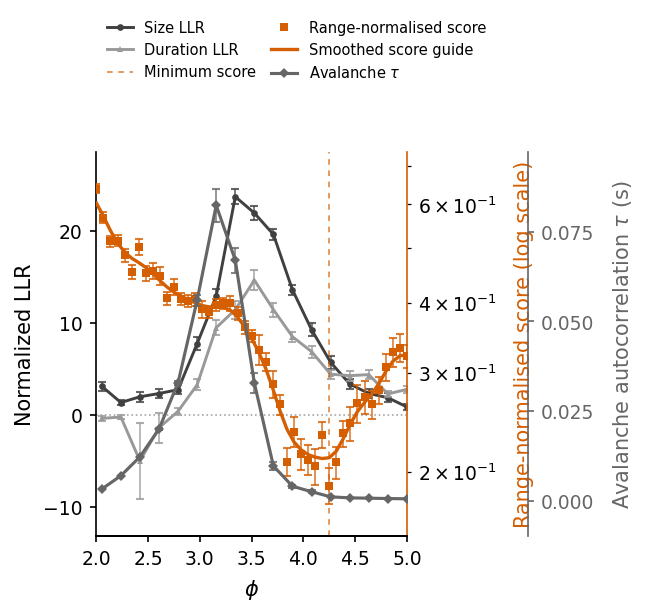


Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_phi2to5_45steps_40seeds_smooth005/phi_plots_range_normalised


In [144]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.ndimage import gaussian_filter1d

# ============================================================
# Paths and settings
# ============================================================

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

SCALINGDIR = BASE / (
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_"
    "phi2to5_45steps_40seeds_smooth005"
)

# NEW autocorrelation run: exact 20-phi grid from refined LLRs.
AVALDIR = BASE / (
    "phi_ew11p7_iw22p4_N2000_"
    "llr_refined_exactgrid_20phis_"
    "50seeds_10000avals_max1000_avalanche_tau_icg"
)

LLR_REFINED_DIR = BASE / (
    "new_ew11p7_iw22p4_phi2p5to4p5_"
    "N2000_20phis_50seeds_10000avals_max1000"
)

LLR_BROAD_DIR = BASE / (
    "new_ew11p7_iw22p4_phi1p5to10_"
    "N2000_10phis_50seeds_10000avals_max1000"
)

LLR_SUBDIR = "truncated_powerlaw_vs_lognormal_normalized_by_seed"
LLR_FILENAME = "normalized_llr_summary_by_phi.csv"

FIGDIR = SCALINGDIR / "phi_plots_range_normalised"
FIGDIR.mkdir(parents=True, exist_ok=True)

PHI_MIN, PHI_MAX = 2.0, 5.0
SCORE_SMOOTH_SIGMA = 1.5
SCORE_YLIM = None
SCORE_PADDING = 0.10
SHOW = True

# Mean per-avalanche autocorrelation, including extinct and
# censored trials; SEM is across network seeds.
TAU_MEAN = "mean_avalanche_tau_s_mean"
TAU_SEM = "mean_avalanche_tau_s_sem"

# To use extinct-only autocorrelation instead:
# TAU_MEAN = "mean_avalanche_tau_s_extinct_only_mean"
# TAU_SEM = "mean_avalanche_tau_s_extinct_only_sem"

COLORS = {
    "size": "#404040",
    "duration": "#999999",
    "score": "#D55E00",
    "tau": "#666666",
}

# ============================================================
# Load saved LLRs
# Broad results are optional; refined wins at overlaps.
# ============================================================

llr_frames = []

for source, directory in [
    ("broad", LLR_BROAD_DIR),
    ("refined", LLR_REFINED_DIR),
]:
    path = directory / LLR_SUBDIR / LLR_FILENAME

    if path.exists():
        llr_frames.append(pd.read_csv(path).assign(source=source))
        print(f"Loaded {source} LLRs:", path)
    else:
        print(f"No saved {source} LLR summary:", path)

if not llr_frames:
    raise FileNotFoundError("Neither saved LLR summary was found.")

llr_data = (
    pd.concat(llr_frames, ignore_index=True)
    .replace([np.inf, -np.inf], np.nan)
    .drop_duplicates(["phi", "metric"], keep="last")
    .sort_values(["metric", "phi"])
    .reset_index(drop=True)
)

# ============================================================
# Load range-normalised score and NEW autocorrelation summary
#
# Keep the score from SCALINGDIR.
# The new autocorrelation run's saved ICG score uses the
# original weighted definition, not range normalisation.
# ============================================================

scaling_path = SCALINGDIR / "phi_scaling_summary.csv"
avalanche_path = AVALDIR / "avalanche_combo_phi_summary.csv"

scaling = (
    pd.read_csv(scaling_path)
    .replace([np.inf, -np.inf], np.nan)
    .sort_values("phi")
    .reset_index(drop=True)
)

avalanche = (
    pd.read_csv(avalanche_path)
    .replace([np.inf, -np.inf], np.nan)
    .sort_values("phi")
    .reset_index(drop=True)
)

for name, frame, required in [
    ("scaling", scaling, ["phi", "score_mean", "score_sem"]),
    ("autocorrelation", avalanche, ["phi", TAU_MEAN, TAU_SEM]),
    (
        "LLR",
        llr_data,
        ["phi", "metric", "R_normalized_mean", "R_normalized_sem"],
    ),
]:
    missing = set(required) - set(frame.columns)
    if missing:
        raise ValueError(f"Missing {name} columns: {sorted(missing)}")

scaling = scaling.loc[
    scaling["phi"].between(PHI_MIN, PHI_MAX)
].copy()

avalanche = avalanche.loc[
    avalanche["phi"].between(PHI_MIN, PHI_MAX)
].copy()

valid_scores = scaling["score_mean"].dropna()

if valid_scores.empty:
    raise ValueError("No finite scaling scores in the plotted region.")

if avalanche.empty or not avalanche[TAU_MEAN].notna().any():
    raise ValueError(
        "No finite autocorrelation values in the plotted region."
    )

best_idx = valid_scores.idxmin()
best_phi = float(scaling.loc[best_idx, "phi"])

print("\nLoaded NEW autocorrelation summary:", avalanche_path)
print("Autocorrelation phi points:", len(avalanche))
print(f"\nMinimum range-normalised score: phi = {best_phi:.4f}")
print(f"Mean score = {scaling.loc[best_idx, 'score_mean']:.6g}")

# ============================================================
# Style and narrower figure
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "figure.dpi": 150,
    "savefig.dpi": 600,
})

fig, ax_llr = plt.subplots(figsize=(4.6, 4.2))
ax_score = ax_llr.twinx()
ax_tau = ax_llr.twinx()

ax_tau.spines["right"].set_position(("outward", 58))

# ============================================================
# Avalanche LLRs: dark and light grey
# ============================================================

for metric, label, marker in [
    ("size", "Size LLR", "o"),
    ("duration", "Duration LLR", "^"),
]:
    d = llr_data.loc[
        (llr_data["metric"] == metric)
        & llr_data["phi"].between(PHI_MIN, PHI_MAX)
    ].sort_values("phi")

    if d.empty:
        continue

    ax_llr.plot(
        d["phi"],
        d["R_normalized_mean"],
        color=COLORS[metric],
        marker=marker,
        markersize=3.2,
        markeredgewidth=0,
        linewidth=1.4,
        label=label,
    )

    errors = d.loc[
        d["R_normalized_mean"].notna()
        & d["R_normalized_sem"].notna()
        & (d["R_normalized_sem"] >= 0)
    ]

    ax_llr.errorbar(
        errors["phi"],
        errors["R_normalized_mean"],
        yerr=errors["R_normalized_sem"],
        fmt="none",
        ecolor=COLORS[metric],
        elinewidth=0.8,
        capsize=1.8,
        alpha=0.8,
    )

ax_llr.axhline(0, color="0.65", linestyle=":", linewidth=0.8)

ax_llr.set(
    xlabel=r"$\phi$",
    ylabel="Normalized LLR",
    xlim=(PHI_MIN, PHI_MAX),
)
ax_llr.set_xticks(np.arange(PHI_MIN, PHI_MAX + 0.01, 0.5))
ax_llr.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax_llr.spines["right"].set_visible(False)
ax_llr.margins(y=0.12)

# ============================================================
# Score: orange points + log-space smoothing
# ============================================================

positive = (
    scaling["score_mean"].notna()
    & (scaling["score_mean"] > 0)
)

if not positive.any():
    raise ValueError("No positive scores for the logarithmic axis.")

raw_scores = scaling["score_mean"].where(positive).to_numpy(float)
smoothed_scores = np.full_like(raw_scores, np.nan)

valid_indices = np.flatnonzero(np.isfinite(raw_scores))
segments = np.split(
    valid_indices,
    np.flatnonzero(np.diff(valid_indices) > 1) + 1,
)

for segment in segments:
    if segment.size:
        smoothed_scores[segment] = np.exp(
            gaussian_filter1d(
                np.log(raw_scores[segment]),
                sigma=SCORE_SMOOTH_SIGMA,
                mode="nearest",
            )
        )

ax_score.plot(
    scaling["phi"],
    raw_scores,
    color=COLORS["score"],
    marker="s",
    markersize=3.4,
    markeredgewidth=0,
    linestyle="none",
    label="Range-normalised score",
    zorder=5,
)

ax_score.plot(
    scaling["phi"],
    smoothed_scores,
    color=COLORS["score"],
    linewidth=1.6,
    label="Smoothed score guide",
    zorder=4,
)

score_errors = scaling.loc[
    positive
    & scaling["score_sem"].notna()
    & (scaling["score_sem"] >= 0)
    & ((scaling["score_mean"] - scaling["score_sem"]) > 0)
]

ax_score.errorbar(
    score_errors["phi"],
    score_errors["score_mean"],
    yerr=score_errors["score_sem"],
    fmt="none",
    ecolor=COLORS["score"],
    elinewidth=0.8,
    capsize=1.8,
    alpha=0.8,
)

ax_score.set_yscale("log")
ax_score.set_ylabel(
    "Range-normalised score (log scale)",
    color=COLORS["score"],
    labelpad=8,
)
ax_score.tick_params(axis="y", colors=COLORS["score"])
ax_score.spines["right"].set_visible(True)
ax_score.spines["right"].set_color(COLORS["score"])
ax_score.spines["left"].set_visible(False)

if SCORE_YLIM is None:
    bounds = np.concatenate([
        scaling.loc[positive, "score_mean"].to_numpy(float),
        smoothed_scores[np.isfinite(smoothed_scores)],
        (
            score_errors["score_mean"] - score_errors["score_sem"]
        ).to_numpy(float),
        (
            score_errors["score_mean"] + score_errors["score_sem"]
        ).to_numpy(float),
    ])

    log_low, log_high = np.log10([bounds.min(), bounds.max()])
    padding = SCORE_PADDING * max(log_high - log_low, 0.1)

    ax_score.set_ylim(
        10 ** (log_low - padding),
        10 ** (log_high + padding),
    )
else:
    if SCORE_YLIM[0] <= 0 or SCORE_YLIM[1] <= SCORE_YLIM[0]:
        raise ValueError("SCORE_YLIM must be positive and increasing.")

    ax_score.set_ylim(*SCORE_YLIM)

# ============================================================
# NEW avalanche autocorrelation: exact refined LLR phi grid
# ============================================================

ax_tau.plot(
    avalanche["phi"],
    avalanche[TAU_MEAN],
    color=COLORS["tau"],
    marker="D",
    markersize=3.5,
    markeredgewidth=0,
    linewidth=1.5,
    label=r"Avalanche $\tau$",
)

tau_errors = avalanche.loc[
    avalanche[TAU_MEAN].notna()
    & avalanche[TAU_SEM].notna()
    & (avalanche[TAU_SEM] >= 0)
]

ax_tau.errorbar(
    tau_errors["phi"],
    tau_errors[TAU_MEAN],
    yerr=tau_errors[TAU_SEM],
    fmt="none",
    ecolor=COLORS["tau"],
    elinewidth=0.8,
    capsize=1.8,
    alpha=0.8,
)

ax_tau.set_ylabel(
    r"Avalanche autocorrelation $\tau$ (s)",
    color=COLORS["tau"],
    labelpad=8,
)
ax_tau.tick_params(axis="y", colors=COLORS["tau"])
ax_tau.spines["right"].set_visible(True)
ax_tau.spines["right"].set_color(COLORS["tau"])
ax_tau.spines["left"].set_visible(False)
ax_tau.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax_tau.margins(y=0.12)

for ax in [ax_llr, ax_score, ax_tau]:
    ax.spines["top"].set_visible(False)
    ax.grid(False)

# ============================================================
# Unsmoothed score minimum and combined legend
# ============================================================

ax_llr.axvline(
    best_phi,
    color=COLORS["score"],
    linestyle=(0, (3, 3)),
    linewidth=0.9,
    alpha=0.65,
    label="Minimum score",
)

handles, labels = [], []

for ax in [ax_llr, ax_score, ax_tau]:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.46, 0.99),
    ncol=2,
    frameon=False,
    fontsize=7,
    handlelength=1.8,
    columnspacing=1.0,
    labelspacing=0.5,
)

fig.subplots_adjust(
    left=0.17,
    right=0.62,
    bottom=0.15,
    top=0.76,
)

# ============================================================
# Save
# ============================================================

basename = "phi2to5_narrow_grey_llrs_NEW_exactgrid_tau_orange_score"

for extension in ["png", "pdf", "svg"]:
    fig.savefig(
        FIGDIR / f"{basename}.{extension}",
        dpi=600,
        facecolor="white",
        bbox_inches="tight",
    )

if SHOW:
    plt.show()

plt.close(fig)
print("\nSaved plots to:", FIGDIR)

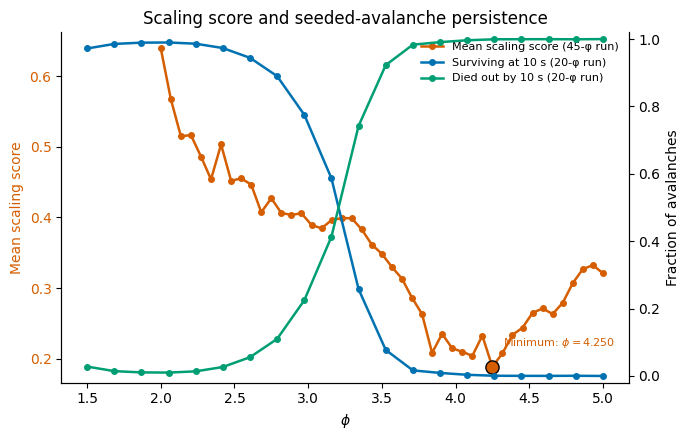

Score: 45 phi points, 1,800 valid network records.
Avalanches: 20 phi points, 1,000 valid network records.

Score minimum/minima:
 phi  n_networks  score_mean
4.25          40    0.188827

Score values used directly from the 45-phi CSV.

Saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew11p7_iw22p4_N2000_llr_refined_exactgrid_20phis_50seeds_10000avals_max1000_avalanche_tau_icg/persistence_vs_45phi_scaling_score


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================== SETTINGS ========================

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

SCORE_DIR = BASE / (
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_"
    "phi2to5_45steps_40seeds_smooth005"
)

AVALANCHE_DIR = BASE / (
    "phi_ew11p7_iw22p4_N2000_"
    "llr_refined_exactgrid_20phis_"
    "50seeds_10000avals_max1000_avalanche_tau_icg"
)

FIGDIR = AVALANCHE_DIR / "persistence_vs_45phi_scaling_score"

PHI_BOUNDS = None              # e.g. (2.5, 4.5), or None
SAVE_FIGURES = True

# ======================== LOAD ============================

score_data = pd.read_csv(
    SCORE_DIR / "phi_scaling_seed_exponents.csv"
)
av = pd.read_csv(
    AVALANCHE_DIR / "avalanche_network_summary.csv"
)

score_columns = ["phi", "seed", "score"]
av_columns = [
    "phi",
    "seed_idx",
    "frac_persistent_at_cutoff",
    "frac_extinct",
]

for name, frame, required in [
    ("Score", score_data, score_columns),
    ("Avalanche", av, av_columns),
]:
    missing = set(required) - set(frame.columns)
    if missing:
        raise ValueError(f"{name} data missing columns: {sorted(missing)}")

score_data = score_data[score_columns].copy()
av = av[av_columns].copy()

for frame, columns in [
    (score_data, ["phi", "score"]),
    (
        av,
        ["phi", "frac_persistent_at_cutoff", "frac_extinct"],
    ),
]:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

    frame.replace([np.inf, -np.inf], np.nan, inplace=True)

score_data = score_data.dropna(subset=score_columns)
av = av.dropna(subset=av_columns)

if PHI_BOUNDS is not None:
    score_data = score_data.loc[
        score_data["phi"].between(*PHI_BOUNDS)
    ].copy()
    av = av.loc[
        av["phi"].between(*PHI_BOUNDS)
    ].copy()

if score_data.empty or av.empty:
    raise ValueError("No valid score or avalanche data in the selected range.")

if score_data.duplicated(["phi", "seed"]).any():
    raise ValueError("Duplicate phi × seed rows in score data.")

if av.duplicated(["phi", "seed_idx"]).any():
    raise ValueError("Duplicate phi × seed rows in avalanche data.")

fractions = av[
    ["frac_persistent_at_cutoff", "frac_extinct"]
].to_numpy(float)

if np.any((fractions < 0) | (fractions > 1)):
    raise ValueError("Avalanche fractions must lie between 0 and 1.")

if not np.allclose(fractions.sum(axis=1), 1.0):
    raise ValueError("Surviving and extinct fractions do not sum to 1.")

# ======================== MEAN CURVES ======================
# Separate grids; no interpolation or matching across runs.
# Use the score already stored in the 45-phi CSV.

score_summary = (
    score_data.groupby("phi", as_index=False)
    .agg(
        n_networks=("seed", "nunique"),
        score_mean=("score", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

av_summary = (
    av.groupby("phi", as_index=False)
    .agg(
        n_networks=("seed_idx", "nunique"),
        surviving_fraction=("frac_persistent_at_cutoff", "mean"),
        extinct_fraction=("frac_extinct", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

minimum_score = score_summary["score_mean"].min()
minima = score_summary.loc[
    score_summary["score_mean"].eq(minimum_score)
]

# ======================== PLOT ============================

orange = "#D55E00"
blue = "#0072B2"
green = "#009E73"

fig, ax_score = plt.subplots(figsize=(7, 4.5))
ax_fraction = ax_score.twinx()

score_line, = ax_score.plot(
    score_summary["phi"],
    score_summary["score_mean"],
    "o-",
    color=orange,
    ms=4,
    lw=1.8,
    label="Mean scaling score (45-φ run)",
)

survival_line, = ax_fraction.plot(
    av_summary["phi"],
    av_summary["surviving_fraction"],
    "o-",
    color=blue,
    ms=4,
    lw=1.8,
    label="Surviving at 10 s (20-φ run)",
)

extinction_line, = ax_fraction.plot(
    av_summary["phi"],
    av_summary["extinct_fraction"],
    "o-",
    color=green,
    ms=4,
    lw=1.8,
    label="Died out by 10 s (20-φ run)",
)

ax_score.scatter(
    minima["phi"],
    minima["score_mean"],
    s=90,
    color=orange,
    edgecolors="black",
    linewidths=1,
    zorder=6,
)

for row in minima.itertuples():
    ax_score.annotate(
        rf"Minimum: $\phi={row.phi:.3f}$",
        xy=(row.phi, row.score_mean),
        xytext=(8, 15),
        textcoords="offset points",
        fontsize=8,
        color=orange,
    )

ax_score.set(
    xlabel=r"$\phi$",
    ylabel="Mean scaling score",
    title="Scaling score and seeded-avalanche persistence",
)
ax_score.tick_params(axis="y", labelcolor=orange)
ax_score.yaxis.label.set_color(orange)

ax_fraction.set(
    ylabel="Fraction of avalanches",
    ylim=(-0.02, 1.02),
)

if PHI_BOUNDS is not None:
    ax_score.set_xlim(*PHI_BOUNDS)

ax_score.spines["top"].set_visible(False)
ax_fraction.spines["top"].set_visible(False)

ax_score.legend(
    handles=[score_line, survival_line, extinction_line],
    frameon=False,
    fontsize=8,
    loc="best",
)

fig.tight_layout()

if SAVE_FIGURES:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    score_summary.to_csv(
        FIGDIR / "score_45phi_summary.csv",
        index=False,
    )
    av_summary.to_csv(
        FIGDIR / "avalanche_20phi_summary.csv",
        index=False,
    )

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"persistence_vs_45phi_scaling_score.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(
    f"Score: {len(score_summary)} phi points, "
    f"{len(score_data):,} valid network records."
)
print(
    f"Avalanches: {len(av_summary)} phi points, "
    f"{len(av):,} valid network records."
)
print("\nScore minimum/minima:")
print(minima.round(6).to_string(index=False))
print("\nScore values used directly from the 45-phi CSV.")

if SAVE_FIGURES:
    print("\nSaved to:", FIGDIR)

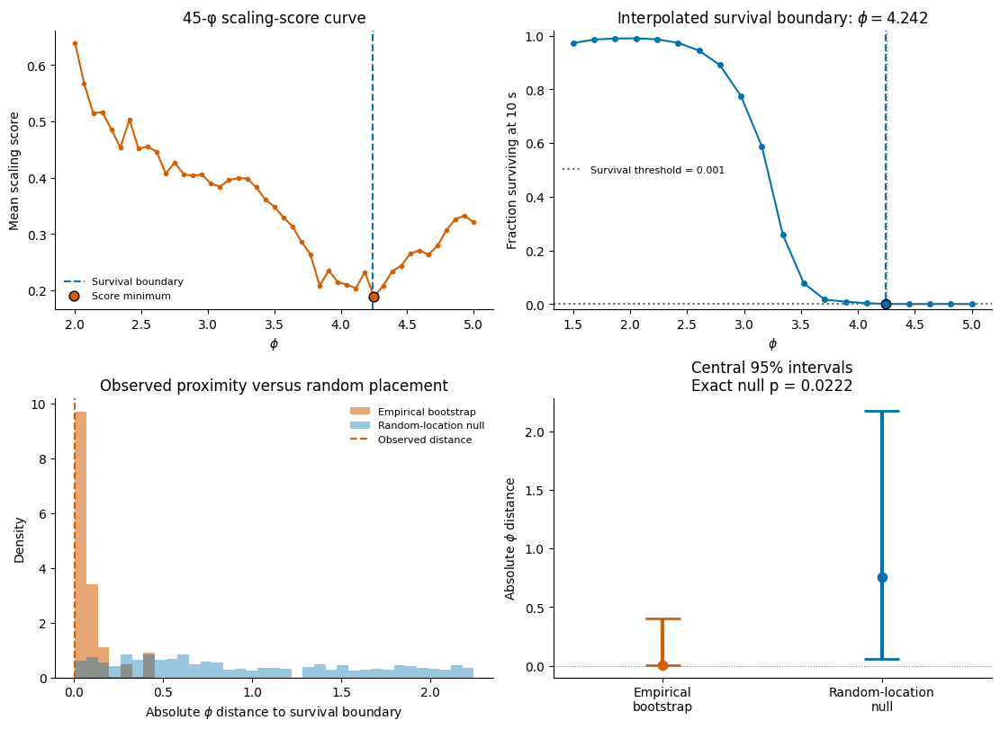

survival_threshold        0.001000
phi_survival_boundary     4.241750
phi_score_min             4.250000
n_tied_minima             1.000000
absolute_phi_distance     0.008250
bootstrap_CI95_low        0.008250
bootstrap_CI95_high       0.400841
p_lower_tail_MC           0.015984
p_lower_tail_exact        0.022222
n_boot                 2000.000000
n_shuffles             1000.000000

         distribution  distance  interval95_low  interval95_high    n
 Empirical bootstrap   0.00825        0.008250         0.400841 2000
Random-location null   0.75825        0.059932         2.173568 1000

Null minimum locations span phi 2–5 (45 grid points).
Bootstrap intervals condition on the fixed survival boundary.

Saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew11p7_iw22p4_N2000_llr_refined_exactgrid_20phis_50seeds_10000avals_max1000_avalanche_tau_icg/score_min_survival_threshold_0.001_null


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================== SETTINGS ========================

SURVIVAL_THRESHOLD = 0.001      # Change this: fraction surviving at 10 s
N_BOOT = 2000
N_SHUFFLES = 1000
BOOT_SEED = 42
NULL_SEED = 123

PHI_BOUNDS = None              # Optional common window, e.g. (2.5, 4.5)
SAVE_RESULTS = True

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

SCORE_DIR = BASE / (
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_"
    "phi2to5_45steps_40seeds_smooth005"
)

AVALANCHE_DIR = BASE / (
    "phi_ew11p7_iw22p4_N2000_"
    "llr_refined_exactgrid_20phis_"
    "50seeds_10000avals_max1000_avalanche_tau_icg"
)

FIGDIR = AVALANCHE_DIR / (
    f"score_min_survival_threshold_{SURVIVAL_THRESHOLD:g}_null"
)

# ======================== LOAD ============================

if not 0 < SURVIVAL_THRESHOLD < 1:
    raise ValueError("SURVIVAL_THRESHOLD must be between 0 and 1.")

if N_BOOT < 2 or N_SHUFFLES < 1:
    raise ValueError("Need N_BOOT >= 2 and N_SHUFFLES >= 1.")

score_data = pd.read_csv(
    SCORE_DIR / "phi_scaling_seed_exponents.csv",
    usecols=["phi", "seed", "score"],
)

av = pd.read_csv(
    AVALANCHE_DIR / "avalanche_network_summary.csv",
    usecols=["phi", "seed_idx", "frac_persistent_at_cutoff"],
)

for frame, columns in [
    (score_data, ["phi", "score"]),
    (av, ["phi", "frac_persistent_at_cutoff"]),
]:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

    frame.replace([np.inf, -np.inf], np.nan, inplace=True)

    if PHI_BOUNDS is not None:
        frame.drop(
            frame.index[~frame["phi"].between(*PHI_BOUNDS)],
            inplace=True,
        )

# Track the intended grids before removing invalid measurements.
expected_score_phi = np.sort(score_data["phi"].dropna().unique())
expected_av_phi = np.sort(av["phi"].dropna().unique())

score_data = score_data.dropna().copy()
av = av.dropna().copy()

if score_data.empty or av.empty:
    raise ValueError("No valid score or survival data.")

if score_data.duplicated(["phi", "seed"]).any():
    raise ValueError("Duplicate phi × seed rows in score data.")

if av.duplicated(["phi", "seed_idx"]).any():
    raise ValueError("Duplicate phi × seed rows in avalanche data.")

if not av["frac_persistent_at_cutoff"].between(0, 1).all():
    raise ValueError("Survival fractions must lie between 0 and 1.")

# ======================== MEAN CURVES ======================

score_summary = (
    score_data.groupby("phi", as_index=False)
    .agg(
        score_mean=("score", "mean"),
        n_networks=("seed", "nunique"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

av_summary = (
    av.groupby("phi", as_index=False)
    .agg(
        survival_mean=("frac_persistent_at_cutoff", "mean"),
        n_networks=("seed_idx", "nunique"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

score_phi = score_summary["phi"].to_numpy(float)
score_mean = score_summary["score_mean"].to_numpy(float)

av_phi = av_summary["phi"].to_numpy(float)
survival = av_summary["survival_mean"].to_numpy(float)

if len(score_phi) < 2 or len(av_phi) < 2:
    raise ValueError("Need at least two phi points in each dataset.")

if (
    not np.array_equal(score_phi, expected_score_phi)
    or not np.array_equal(av_phi, expected_av_phi)
):
    raise ValueError("At least one phi has no valid measurements.")

# ======================== SURVIVAL BOUNDARY ================
# First downward crossing of the specified survival fraction.
# Linearly interpolate between the two bracketing measurements.
# No smoothing or extrapolation.

if survival[0] <= SURVIVAL_THRESHOLD:
    raise ValueError(
        "Survival is already at/below the threshold at the first "
        "avalanche phi. Expand the window to locate its crossing."
    )

crossings = np.flatnonzero(
    (survival[:-1] > SURVIVAL_THRESHOLD)
    & (survival[1:] <= SURVIVAL_THRESHOLD)
)

if not crossings.size:
    raise ValueError(
        "Survival never crosses downward through the threshold "
        "within the measured avalanche grid."
    )

j = int(crossings[0])
fraction = (
    (survival[j] - SURVIVAL_THRESHOLD)
    / (survival[j] - survival[j + 1])
)
boundary_phi = float(
    av_phi[j] + fraction * (av_phi[j + 1] - av_phi[j])
)

if not score_phi[0] <= boundary_phi <= score_phi[-1]:
    raise ValueError("Survival boundary lies outside the score phi range.")

if len(crossings) > 1:
    print(
        f"Note: {len(crossings)} downward crossings detected; "
        "using the first."
    )

# ======================== OBSERVED DISTANCE ================

# Handle exact ties by averaging their distances.
# Ordinarily there is a single minimum.
def minimum_statistics(means):
    indices = np.flatnonzero(means == np.min(means))
    locations = score_phi[indices]
    return {
        "phi_score_min": float(locations.mean()),
        "n_tied_minima": int(len(indices)),
        "absolute_phi_distance": float(
            np.mean(np.abs(locations - boundary_phi))
        ),
    }

observed = minimum_statistics(score_mean)
observed_distance = observed["absolute_phi_distance"]

# ======================== BOOTSTRAP =======================
# Independently resample simulations within each phi.
# Recompute the mean-score curve and minimum each time.
# The observed survival boundary stays fixed.

cells = [
    group["score"].to_numpy(float)
    for _, group in score_data.groupby("phi", sort=True)
]

rng_boot = np.random.default_rng(BOOT_SEED)
boot_rows = []

for repeat in range(N_BOOT):
    sampled_means = np.array([
        cell[rng_boot.integers(0, len(cell), size=len(cell))].mean()
        for cell in cells
    ])

    boot_rows.append({
        "replicate": repeat,
        **minimum_statistics(sampled_means),
    })

boot = pd.DataFrame(boot_rows)
empirical_values = boot["absolute_phi_distance"].to_numpy()
emp_low, emp_high = np.quantile(empirical_values, [0.025, 0.975])

# ======================== RANDOM-LOCATION NULL ============
# Randomly permute phi labels attached to the score curve.
# With one minimum, this is a uniform random minimum location.
# With tied minima, preserve their number and average distances.

rng_null = np.random.default_rng(NULL_SEED)
minimum_indices = np.flatnonzero(score_mean == score_mean.min())
null_rows = []

for repeat in range(N_SHUFFLES):
    shuffled_phi = rng_null.permutation(score_phi)
    minimum_locations = shuffled_phi[minimum_indices]

    null_rows.append({
        "shuffle": repeat,
        "phi_score_min": float(minimum_locations.mean()),
        "absolute_phi_distance": float(
            np.mean(np.abs(minimum_locations - boundary_phi))
        ),
    })

null = pd.DataFrame(null_rows)
null_values = null["absolute_phi_distance"].to_numpy()
null_low, null_high = np.quantile(null_values, [0.025, 0.975])

# Lower tail: is the observed minimum unusually close?
p_mc = (
    1 + np.count_nonzero(null_values <= observed_distance)
) / (N_SHUFFLES + 1)

# Exact uniform-grid probability for a unique observed minimum.
p_exact = (
    float(np.mean(
        np.abs(score_phi - boundary_phi) <= observed_distance
    ))
    if len(minimum_indices) == 1
    else np.nan
)

comparison = pd.DataFrame([
    {
        "distribution": "Empirical bootstrap",
        "distance": observed_distance,
        "interval95_low": emp_low,
        "interval95_high": emp_high,
        "n": N_BOOT,
    },
    {
        "distribution": "Random-location null",
        "distance": float(np.median(null_values)),
        "interval95_low": null_low,
        "interval95_high": null_high,
        "n": N_SHUFFLES,
    },
])

# ======================== PLOT ============================

orange, blue = "#D55E00", "#0072B2"

fig, axes = plt.subplots(
    2, 2, figsize=(11, 8), constrained_layout=True
)

# Score curve
ax = axes[0, 0]
ax.plot(score_phi, score_mean, "o-", color=orange, ms=3)
ax.axvline(
    boundary_phi, color=blue, ls="--",
    label="Survival boundary",
)
ax.scatter(
    score_phi[minimum_indices],
    score_mean[minimum_indices],
    color=orange, edgecolors="black", s=60, zorder=5,
    label="Score minimum",
)
ax.set(
    xlabel=r"$\phi$",
    ylabel="Mean scaling score",
    title="45-φ scaling-score curve",
)
ax.legend(frameon=False, fontsize=8)

# Survival curve
ax = axes[0, 1]
ax.plot(av_phi, survival, "o-", color=blue, ms=4)
ax.axhline(
    SURVIVAL_THRESHOLD, color="0.4", ls=":",
    label=f"Survival threshold = {SURVIVAL_THRESHOLD:g}",
)
ax.axvline(boundary_phi, color=blue, ls="--")
for p in score_phi[minimum_indices]:
    ax.axvline(p, color=orange, ls=":", lw=1)
ax.scatter(
    boundary_phi, SURVIVAL_THRESHOLD,
    color=blue, edgecolors="black", s=55, zorder=5,
)
ax.set(
    xlabel=r"$\phi$",
    ylabel="Fraction surviving at 10 s",
    ylim=(-0.02, 1.02),
    title=rf"Interpolated survival boundary: $\phi={boundary_phi:.3f}$",
)
ax.legend(frameon=False, fontsize=8)

# Distance distributions
ax = axes[1, 0]
edges = np.histogram_bin_edges(
    np.r_[empirical_values, null_values], bins=35
)
ax.hist(
    empirical_values, bins=edges, density=True,
    color=orange, alpha=0.55, label="Empirical bootstrap",
)
ax.hist(
    null_values, bins=edges, density=True,
    color=blue, alpha=0.4, label="Random-location null",
)
ax.axvline(
    observed_distance, color=orange, ls="--",
    label="Observed distance",
)
ax.set(
    xlabel=r"Absolute $\phi$ distance to survival boundary",
    ylabel="Density",
    title="Observed proximity versus random placement",
)
ax.legend(frameon=False, fontsize=8)

# Intervals
ax = axes[1, 1]
for x, low, high, center, colour in [
    (0, emp_low, emp_high, observed_distance, orange),
    (1, null_low, null_high, np.median(null_values), blue),
]:
    ax.vlines(x, low, high, color=colour, lw=3)
    ax.hlines(
        [low, high], x - 0.08, x + 0.08, color=colour, lw=2
    )
    ax.scatter(x, center, color=colour, s=55, zorder=5)

p_label = (
    f"Exact null p = {p_exact:.4f}"
    if np.isfinite(p_exact)
    else f"Monte Carlo null p = {p_mc:.4f}"
)
ax.set_xticks([0, 1], ["Empirical\nbootstrap", "Random-location\nnull"])
ax.set(
    ylabel=r"Absolute $\phi$ distance",
    title=f"Central 95% intervals\n{p_label}",
    xlim=(-0.5, 1.5),
)
ax.axhline(0, color="0.5", ls=":", lw=0.8)

for ax in axes.ravel():
    ax.spines[["top", "right"]].set_visible(False)

# ======================== SAVE / REPORT ===================

test_summary = pd.DataFrame([{
    "survival_threshold": SURVIVAL_THRESHOLD,
    "phi_survival_boundary": boundary_phi,
    **observed,
    "bootstrap_CI95_low": emp_low,
    "bootstrap_CI95_high": emp_high,
    "p_lower_tail_MC": p_mc,
    "p_lower_tail_exact": p_exact,
    "n_boot": N_BOOT,
    "n_shuffles": N_SHUFFLES,
}])

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)
    boot.to_csv(FIGDIR / "bootstrap.csv", index=False)
    null.to_csv(FIGDIR / "random_location_null.csv", index=False)
    comparison.to_csv(FIGDIR / "comparison.csv", index=False)
    test_summary.to_csv(FIGDIR / "test_summary.csv", index=False)
    score_summary.to_csv(FIGDIR / "score_curve.csv", index=False)
    av_summary.to_csv(FIGDIR / "survival_curve.csv", index=False)

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"score_min_survival_boundary_null.{ext}",
            dpi=300, bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(test_summary.T.to_string(header=False))
print("\n", comparison.round(6).to_string(index=False))
print(
    f"\nNull minimum locations span phi "
    f"{score_phi.min():g}–{score_phi.max():g} "
    f"({len(score_phi)} grid points)."
)
print("Bootstrap intervals condition on the fixed survival boundary.")

if SAVE_RESULTS:
    print("\nSaved to:", FIGDIR)

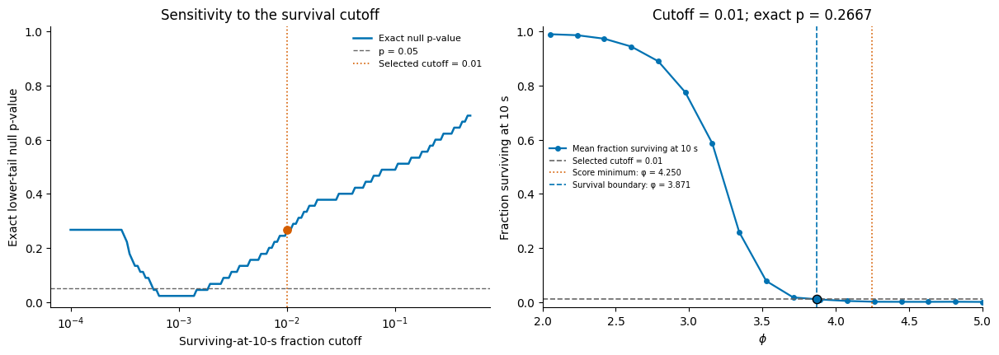

Score minimum: phi = 4.25

Selected survival cutoff = 0.01:
  Boundary phi = 3.87141
  Absolute phi distance = 0.378586
  Exact null p = 0.266667

Valid boundary detections: 151/152
Null locations: 45 score-grid points, phi 2–5.

Failed detections:
status
No downward crossing within avalanche grid    1

Saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew11p7_iw22p4_N2000_llr_refined_exactgrid_20phis_50seeds_10000avals_max1000_avalanche_tau_icg/survival_cutoff_sensitivity


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================== SETTINGS ========================

REFERENCE_CUTOFF = 0.01        # Illustrated on the survival plot

SURVIVAL_CUTOFFS = np.unique(np.r_[
    0.0,
    np.geomspace(0.0001, 0.5, 150),
    REFERENCE_CUTOFF,
])

PHI_BOUNDS = (2.0, 5.0)        # None for full available ranges
SAVE_RESULTS = True

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

SCORE_DIR = BASE / (
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_"
    "phi2to5_45steps_40seeds_smooth005"
)

AVALANCHE_DIR = BASE / (
    "phi_ew11p7_iw22p4_N2000_"
    "llr_refined_exactgrid_20phis_"
    "50seeds_10000avals_max1000_avalanche_tau_icg"
)

FIGDIR = AVALANCHE_DIR / "survival_cutoff_sensitivity"

# ======================== LOAD ============================

if (
    not np.isfinite(SURVIVAL_CUTOFFS).all()
    or np.any((SURVIVAL_CUTOFFS < 0) | (SURVIVAL_CUTOFFS >= 1))
):
    raise ValueError("Survival cutoffs must satisfy 0 <= cutoff < 1.")

score_data = pd.read_csv(
    SCORE_DIR / "phi_scaling_seed_exponents.csv",
    usecols=["phi", "seed", "score"],
)

av = pd.read_csv(
    AVALANCHE_DIR / "avalanche_network_summary.csv",
    usecols=["phi", "seed_idx", "frac_persistent_at_cutoff"],
)

for frame, columns in [
    (score_data, ["phi", "score"]),
    (av, ["phi", "frac_persistent_at_cutoff"]),
]:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

    frame.replace([np.inf, -np.inf], np.nan, inplace=True)

    if PHI_BOUNDS is not None:
        frame.drop(
            frame.index[~frame["phi"].between(*PHI_BOUNDS)],
            inplace=True,
        )

expected_score_phi = np.sort(score_data["phi"].dropna().unique())
expected_av_phi = np.sort(av["phi"].dropna().unique())

score_data = score_data.dropna().copy()
av = av.dropna().copy()

if score_data.empty or av.empty:
    raise ValueError("No valid score or avalanche data.")

if score_data.duplicated(["phi", "seed"]).any():
    raise ValueError("Duplicate phi × seed rows in score data.")

if av.duplicated(["phi", "seed_idx"]).any():
    raise ValueError("Duplicate phi × seed rows in avalanche data.")

if not av["frac_persistent_at_cutoff"].between(0, 1).all():
    raise ValueError("Survival fractions must lie between 0 and 1.")

# ======================== MEAN CURVES ======================

score_summary = (
    score_data.groupby("phi", as_index=False)
    .agg(
        score_mean=("score", "mean"),
        n_networks=("seed", "nunique"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

av_summary = (
    av.groupby("phi", as_index=False)
    .agg(
        survival_mean=("frac_persistent_at_cutoff", "mean"),
        n_networks=("seed_idx", "nunique"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

score_phi = score_summary["phi"].to_numpy(float)
score_mean = score_summary["score_mean"].to_numpy(float)

av_phi = av_summary["phi"].to_numpy(float)
survival = av_summary["survival_mean"].to_numpy(float)

if len(score_phi) < 2 or len(av_phi) < 2:
    raise ValueError("Need at least two phi points in each dataset.")

if (
    not np.array_equal(score_phi, expected_score_phi)
    or not np.array_equal(av_phi, expected_av_phi)
):
    raise ValueError("At least one phi has no valid measurements.")

minimum_indices = np.flatnonzero(score_mean == score_mean.min())

if len(minimum_indices) != 1:
    raise ValueError(
        "The observed mean score has tied minima. "
        "A unique minimum is required for this exact random-location test."
    )

minimum_phi = float(score_phi[minimum_indices[0]])

# ======================== CUTOFF SWEEP ====================
#
# For each survival cutoff:
#   1. Find its first downward crossing.
#   2. Interpolate the boundary phi between measured points.
#   3. Measure absolute phi distance from the score minimum.
#   4. Compare against every possible score-grid minimum location.
#
# Survival curve remains fixed; no smoothing or extrapolation.
# This calculates exact null p-values, without bootstrapping.
# ==========================================================

rows = []

for cutoff in SURVIVAL_CUTOFFS:
    row = {
        "survival_cutoff": float(cutoff),
        "phi_score_min": minimum_phi,
        "phi_boundary": np.nan,
        "absolute_phi_distance": np.nan,
        "p_exact": np.nan,
        "n_downward_crossings": 0,
        "status": "",
    }

    if survival[0] <= cutoff:
        row["status"] = "Already at/below cutoff at first avalanche phi"
        rows.append(row)
        continue

    crossings = np.flatnonzero(
        (survival[:-1] > cutoff)
        & (survival[1:] <= cutoff)
    )

    row["n_downward_crossings"] = len(crossings)

    if not crossings.size:
        row["status"] = "No downward crossing within avalanche grid"
        rows.append(row)
        continue

    # First downward crossing, allowing nonmonotonic observations.
    j = int(crossings[0])

    fraction = (
        (survival[j] - cutoff)
        / (survival[j] - survival[j + 1])
    )

    boundary_phi = float(
        av_phi[j] + fraction * (av_phi[j + 1] - av_phi[j])
    )

    if not score_phi[0] <= boundary_phi <= score_phi[-1]:
        row["status"] = "Boundary outside score-grid range"
        rows.append(row)
        continue

    observed_distance = abs(minimum_phi - boundary_phi)

    # Exact equivalent of uniformly randomizing the minimum's
    # location across the original score phi grid.
    null_distances = np.abs(score_phi - boundary_phi)
    p_exact = float(np.mean(null_distances <= observed_distance))

    row.update({
        "phi_boundary": boundary_phi,
        "absolute_phi_distance": observed_distance,
        "p_exact": p_exact,
        "status": "ok",
    })
    rows.append(row)

cutoff_results = pd.DataFrame(rows)
valid = cutoff_results["status"].eq("ok")

reference = cutoff_results.loc[
    cutoff_results["survival_cutoff"].eq(REFERENCE_CUTOFF)
].iloc[0]

reference_ok = reference["status"] == "ok"

# ======================== PLOT ============================

blue = "#0072B2"
orange = "#D55E00"

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.2),
    constrained_layout=True,
)

# LEFT: p-value versus survival cutoff
ax = axes[0]

ax.plot(
    cutoff_results["survival_cutoff"],
    cutoff_results["p_exact"],
    color=blue,
    lw=1.8,
    label="Exact null p-value",
)

ax.axhline(
    0.05, color="0.4", ls="--", lw=1,
    label="p = 0.05",
)

ax.axvline(
    REFERENCE_CUTOFF,
    color=orange,
    ls=":",
    lw=1.2,
    label=f"Selected cutoff = {REFERENCE_CUTOFF:g}",
)

if reference_ok:
    ax.scatter(
        REFERENCE_CUTOFF,
        reference["p_exact"],
        color=orange,
        s=45,
        zorder=5,
    )

# Log-like axis with a short linear region that includes zero.
ax.set_xscale("symlog", linthresh=0.0001, linscale=1)
ax.set(
    xlabel="Surviving-at-10-s fraction cutoff",
    ylabel="Exact lower-tail null p-value",
    title="Sensitivity to the survival cutoff",
    ylim=(-0.02, 1.02),
)
ax.legend(frameon=False, fontsize=8)

# RIGHT: survival curve and selected cutoff
ax = axes[1]

ax.plot(
    av_phi, survival,
    "o-",
    color=blue,
    ms=4,
    lw=1.6,
    label="Mean fraction surviving at 10 s",
)

ax.axhline(
    REFERENCE_CUTOFF,
    color="0.4",
    ls="--",
    lw=1.2,
    label=f"Selected cutoff = {REFERENCE_CUTOFF:g}",
)

ax.axvline(
    minimum_phi,
    color=orange,
    ls=":",
    lw=1.2,
    label=f"Score minimum: φ = {minimum_phi:.3f}",
)

if reference_ok:
    boundary_phi = reference["phi_boundary"]

    ax.axvline(
        boundary_phi,
        color=blue,
        ls="--",
        lw=1.2,
        label=f"Survival boundary: φ = {boundary_phi:.3f}",
    )

    ax.scatter(
        boundary_phi,
        REFERENCE_CUTOFF,
        color=blue,
        edgecolors="black",
        s=55,
        zorder=5,
    )

    title = (
        f"Cutoff = {REFERENCE_CUTOFF:g}; "
        f"exact p = {reference['p_exact']:.4f}"
    )
else:
    title = f"Cutoff = {REFERENCE_CUTOFF:g}: no valid boundary"

ax.set(
    xlabel=r"$\phi$",
    ylabel="Fraction surviving at 10 s",
    title=title,
    ylim=(-0.02, 1.02),
    xlim=(
        min(score_phi[0], av_phi[0]),
        max(score_phi[-1], av_phi[-1]),
    ),
)
ax.legend(frameon=False, fontsize=7, loc="best")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

# ======================== SAVE / REPORT ===================

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    cutoff_results.to_csv(
        FIGDIR / "survival_cutoff_sensitivity.csv",
        index=False,
    )
    score_summary.to_csv(
        FIGDIR / "score_curve.csv", index=False
    )
    av_summary.to_csv(
        FIGDIR / "survival_curve.csv", index=False
    )

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"survival_cutoff_sensitivity.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(f"Score minimum: phi = {minimum_phi:.6g}")

if reference_ok:
    print(
        f"\nSelected survival cutoff = {REFERENCE_CUTOFF:g}:"
        f"\n  Boundary phi = {reference['phi_boundary']:.6g}"
        f"\n  Absolute phi distance = "
        f"{reference['absolute_phi_distance']:.6g}"
        f"\n  Exact null p = {reference['p_exact']:.6g}"
    )
else:
    print(f"\nSelected cutoff: {reference['status']}")

print(f"\nValid boundary detections: {valid.sum()}/{len(valid)}")
print(
    f"Null locations: {len(score_phi)} score-grid points, "
    f"phi {score_phi[0]:g}–{score_phi[-1]:g}."
)

if (~valid).any():
    print("\nFailed detections:")
    print(
        cutoff_results.loc[~valid, "status"]
        .value_counts()
        .to_string()
    )

if SAVE_RESULTS:
    print("\nSaved to:", FIGDIR)

Best phi: 3.67948717948718
   phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  score_sem  mean_rate_hz  mean_rate_hz_sem  frac_silent_frames  frac_active_neurons  MV_r2_mean  TAU_r2_mean  n
3.6795         1.6163        0.0053         0.2213        0.0093      0.2193     0.0111         2.276            0.1114              0.0042               0.7213      0.9961       0.8841 40

df_icg columns:
['gen', 'n_clusters', 'mean_cluster_size', 'mean_activity', 'mean_variance', 'timescale', 'corr_kurtosis', 'mean_variance_l0', 'timescale_l0', 'mean_variance_norm', 'timescale_norm', 'MV', 'MV_norm', 'TAU', 'TAU_norm', 'kurtosis_corr', 'sim_id', 'phi', 'seed', 'seed_idx', 'mean_rate_hz', 'smoothe']

Detected:
seed_col: seed_idx
gen_col: gen
scale_col: mean_cluster_size
var_col: mean_variance
tau_col: timescale
kurt_col: kurtosis_corr

Best phi ICG rows: (400, 24)
n seeds: 40


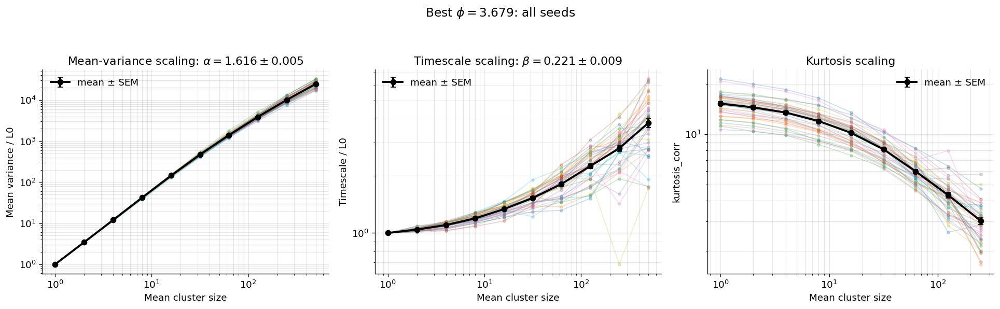

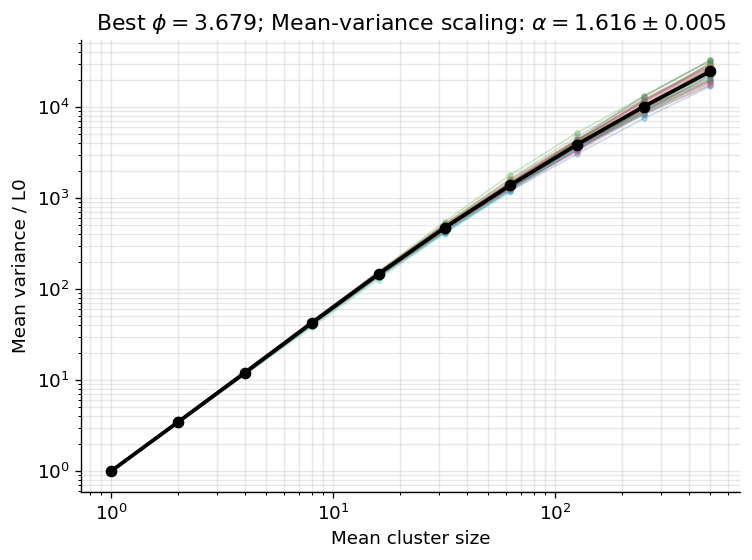

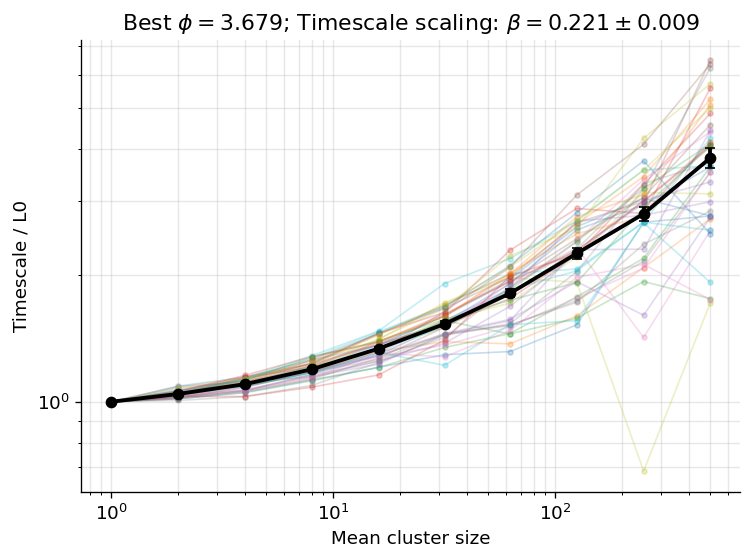

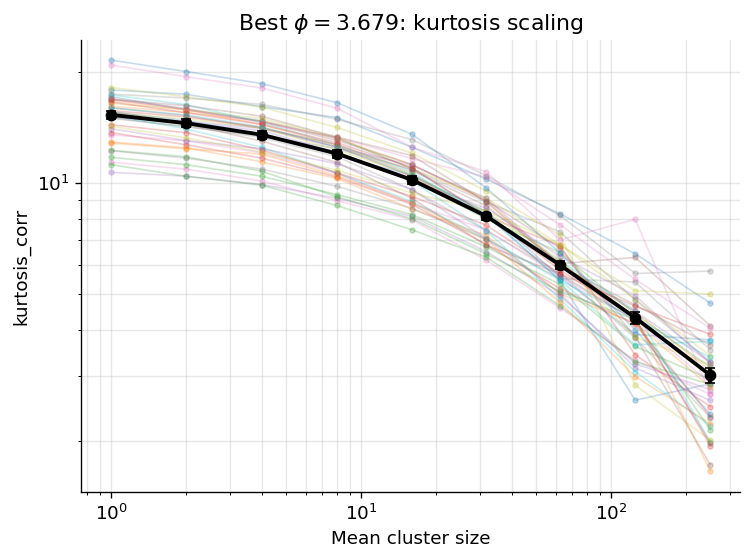


Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_phi1p5to10_40steps_40seeds_smooth005/best_phi_all_seed_var_tau_kurtosis


In [292]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Best-phi ICG curves across all seeds:
#   1. Mean variance, normalised to L0 per seed
#   2. Timescale, normalised to L0 per seed
#   3. Kurtosis, if saved
#
# Plot titles include mean fitted exponents:
#   MV alpha mean ± SEM
#   TAU beta mean ± SEM
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_pext0_quick_phi1p5to10_40steps_40seeds_smooth005"
)

FIGDIR = OUTDIR / "best_phi_all_seed_var_tau_kurtosis"
FIGDIR.mkdir(exist_ok=True)

SUMMARY_PATH = OUTDIR / "phi_scaling_summary.csv"
ICG_PATH = OUTDIR / "phi_scaling_icg_rows.csv"

phi_summary = pd.read_csv(SUMMARY_PATH).sort_values("phi").reset_index(drop=True)
df_icg = pd.read_csv(ICG_PATH)

phi_summary["phi"] = phi_summary["phi"].astype(float)
df_icg["phi"] = df_icg["phi"].astype(float)

# ============================================================
# Best phi by current score
# ============================================================

best_idx = phi_summary["score_mean"].idxmin()
best_row = phi_summary.loc[best_idx].copy()
best_phi = float(best_row["phi"])

mv_alpha_mean = float(best_row["MV_alpha_mean"])
mv_alpha_sem = float(best_row["MV_alpha_sem"])
tau_beta_mean = float(best_row["TAU_beta_mean"])
tau_beta_sem = float(best_row["TAU_beta_sem"])

mv_title = fr"Mean-variance scaling: $\alpha={mv_alpha_mean:.3f}\pm{mv_alpha_sem:.3f}$"
tau_title = fr"Timescale scaling: $\beta={tau_beta_mean:.3f}\pm{tau_beta_sem:.3f}$"

print("Best phi:", best_phi)
print(
    phi_summary.loc[[best_idx], [
        c for c in [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "score_sem",
            "mean_rate_hz",
            "mean_rate_hz_sem",
            "frac_silent_frames",
            "frac_active_neurons",
            "MV_r2_mean",
            "TAU_r2_mean",
            "n",
        ]
        if c in phi_summary.columns
    ]]
    .round(4)
    .to_string(index=False)
)

print("\ndf_icg columns:")
print(df_icg.columns.tolist())

# ============================================================
# Helpers
# ============================================================

def pick_col(cols, candidates):
    for c in candidates:
        if c in cols:
            return c
    return None

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def clean_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)

def finish(name):
    plt.tight_layout()
    plt.savefig(FIGDIR / name, dpi=300, bbox_inches="tight")
    plt.show()

def normalise_to_l0_per_seed(df, value_col, out_col, seed_col, scale_col):
    out = df.copy()
    out[out_col] = np.nan

    for seed, g in out.groupby(seed_col, sort=True):
        g = g.sort_values(scale_col)
        vals = g[value_col].replace([np.inf, -np.inf], np.nan).dropna()

        if len(vals) == 0:
            continue

        base = float(vals.iloc[0])

        if not np.isfinite(base) or base == 0:
            continue

        out.loc[g.index, out_col] = out.loc[g.index, value_col].astype(float) / base

    return out

# ============================================================
# Column detection
# ============================================================

seed_col = pick_col(df_icg.columns, ["seed_idx", "seed", "network_seed"])
gen_col = pick_col(df_icg.columns, ["gen", "level", "coarse_grain_level"])
scale_col = pick_col(df_icg.columns, ["mean_cluster_size", "cluster_size", "size"])

var_col = pick_col(
    df_icg.columns,
    [
        "mean_variance",
        "mean_variance_sum",
        "mean_variance_norm",
        "MV",
        "MV_norm",
        "variance",
        "variance_norm",
    ],
)

tau_col = pick_col(
    df_icg.columns,
    [
        "timescale",
        "timescale_norm",
        "TAU",
        "TAU_norm",
        "tau",
        "tau_norm",
    ],
)

kurt_col = pick_col(
    df_icg.columns,
    [
        "kurtosis_corr",
        "kurtosis",
        "kurtosis_norm",
        "mean_kurtosis",
        "kurtosis_mean",
        "kurt",
        "KURT",
    ],
)

print("\nDetected:")
print("seed_col:", seed_col)
print("gen_col:", gen_col)
print("scale_col:", scale_col)
print("var_col:", var_col)
print("tau_col:", tau_col)
print("kurt_col:", kurt_col)

if seed_col is None:
    raise ValueError("Could not find seed column in df_icg.")

if scale_col is None:
    raise ValueError("Could not find mean_cluster_size / cluster_size column in df_icg.")

if var_col is None:
    raise ValueError("Could not find mean variance column in df_icg.")

if tau_col is None:
    raise ValueError("Could not find timescale column in df_icg.")

# ============================================================
# Best phi dataframe
# ============================================================

d = df_icg[np.isclose(df_icg["phi"], best_phi)].copy()
d = d.replace([np.inf, -np.inf], np.nan)

d[var_col] = d[var_col].astype(float)
d[tau_col] = d[tau_col].astype(float)

if kurt_col is not None:
    d[kurt_col] = d[kurt_col].astype(float)

d = d.dropna(subset=[seed_col, scale_col, var_col, tau_col])
d = d.sort_values([seed_col, scale_col]).reset_index(drop=True)

# Normalise mean variance and timescale to each seed's L0
d = normalise_to_l0_per_seed(
    d,
    value_col=var_col,
    out_col="mean_variance_l0_norm",
    seed_col=seed_col,
    scale_col=scale_col,
)

d = normalise_to_l0_per_seed(
    d,
    value_col=tau_col,
    out_col="timescale_l0_norm",
    seed_col=seed_col,
    scale_col=scale_col,
)

d = d.dropna(subset=["mean_variance_l0_norm", "timescale_l0_norm"])

print("\nBest phi ICG rows:", d.shape)
print("n seeds:", d[seed_col].nunique())

# ============================================================
# Summary across seeds
# ============================================================

group_cols = [scale_col]
if gen_col is not None:
    group_cols = [gen_col, scale_col]

summary_best = (
    d
    .groupby(group_cols, as_index=False)
    .agg(
        mean_variance_l0_norm_mean=("mean_variance_l0_norm", "mean"),
        mean_variance_l0_norm_sem=("mean_variance_l0_norm", sem),
        timescale_l0_norm_mean=("timescale_l0_norm", "mean"),
        timescale_l0_norm_sem=("timescale_l0_norm", sem),
        n_seeds=(seed_col, "nunique"),
    )
    .sort_values(scale_col)
)

if kurt_col is not None:
    kurt_summary = (
        d
        .dropna(subset=[kurt_col])
        .groupby(group_cols, as_index=False)
        .agg(
            kurtosis_mean=(kurt_col, "mean"),
            kurtosis_sem=(kurt_col, sem),
            n_seeds=(seed_col, "nunique"),
        )
        .sort_values(scale_col)
    )

    summary_best = summary_best.merge(
        kurt_summary,
        on=group_cols + ["n_seeds"],
        how="left",
    )

summary_best.to_csv(
    FIGDIR / f"best_phi_{best_phi:.4f}_var_tau_kurtosis_summary.csv",
    index=False,
)

d.to_csv(
    FIGDIR / f"best_phi_{best_phi:.4f}_all_seed_var_tau_kurtosis_rows.csv",
    index=False,
)

# ============================================================
# Combined figure
# ============================================================

ncols = 3 if kurt_col is not None else 2
fig, axes = plt.subplots(1, ncols, figsize=(5.4 * ncols, 4.7))

if ncols == 1:
    axes = [axes]

# ----------------------------
# Mean variance, L0-normalised
# ----------------------------

ax = axes[0]

for seed, g in d.groupby(seed_col, sort=True):
    g = g.sort_values(scale_col)
    ax.plot(
        g[scale_col],
        g["mean_variance_l0_norm"],
        marker="o",
        markersize=3,
        linewidth=1,
        alpha=0.25,
    )

ax.errorbar(
    summary_best[scale_col],
    summary_best["mean_variance_l0_norm_mean"],
    yerr=summary_best["mean_variance_l0_norm_sem"],
    marker="o",
    color="black",
    linewidth=2.3,
    capsize=3,
    label="mean ± SEM",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean cluster size")
ax.set_ylabel("Mean variance / L0")
ax.set_title(mv_title)
ax.legend(frameon=False)
ax.grid(alpha=0.3, which="both")
clean_ax(ax)

# ----------------------------
# Timescale, L0-normalised
# ----------------------------

ax = axes[1]

for seed, g in d.groupby(seed_col, sort=True):
    g = g.sort_values(scale_col)
    ax.plot(
        g[scale_col],
        g["timescale_l0_norm"],
        marker="o",
        markersize=3,
        linewidth=1,
        alpha=0.25,
    )

ax.errorbar(
    summary_best[scale_col],
    summary_best["timescale_l0_norm_mean"],
    yerr=summary_best["timescale_l0_norm_sem"],
    marker="o",
    color="black",
    linewidth=2.3,
    capsize=3,
    label="mean ± SEM",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean cluster size")
ax.set_ylabel("Timescale / L0")
ax.set_title(tau_title)
ax.legend(frameon=False)
ax.grid(alpha=0.3, which="both")
clean_ax(ax)

# ----------------------------
# Kurtosis, if saved
# ----------------------------

if kurt_col is not None:
    ax = axes[2]
    dk = d.dropna(subset=[kurt_col]).copy()

    for seed, g in dk.groupby(seed_col, sort=True):
        g = g.sort_values(scale_col)
        ax.plot(
            g[scale_col],
            g[kurt_col],
            marker="o",
            markersize=3,
            linewidth=1,
            alpha=0.25,
        )

    ax.errorbar(
        summary_best[scale_col],
        summary_best["kurtosis_mean"],
        yerr=summary_best["kurtosis_sem"],
        marker="o",
        color="black",
        linewidth=2.3,
        capsize=3,
        label="mean ± SEM",
    )

    ax.set_xscale("log")

    if (dk[kurt_col] > 0).all():
        ax.set_yscale("log")

    ax.set_xlabel("Mean cluster size")
    ax.set_ylabel(kurt_col)
    ax.set_title("Kurtosis scaling")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3, which="both")
    clean_ax(ax)

fig.suptitle(fr"Best $\phi={best_phi:.3f}$: all seeds", y=1.05, fontsize=14)
finish("best_phi_all_seed_mean_variance_timescale_kurtosis_with_exponents.png")

# ============================================================
# Separate clean plots
# ============================================================

fig, ax = plt.subplots(figsize=(6.4, 4.8))

for seed, g in d.groupby(seed_col, sort=True):
    g = g.sort_values(scale_col)
    ax.plot(
        g[scale_col],
        g["mean_variance_l0_norm"],
        marker="o",
        markersize=3,
        linewidth=1,
        alpha=0.25,
    )

ax.errorbar(
    summary_best[scale_col],
    summary_best["mean_variance_l0_norm_mean"],
    yerr=summary_best["mean_variance_l0_norm_sem"],
    marker="o",
    color="black",
    linewidth=2.3,
    capsize=3,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean cluster size")
ax.set_ylabel("Mean variance / L0")
ax.set_title(fr"Best $\phi={best_phi:.3f}$; {mv_title}")
ax.grid(alpha=0.3, which="both")
clean_ax(ax)
finish("best_phi_all_seed_mean_variance_l0_norm_with_alpha_title.png")

fig, ax = plt.subplots(figsize=(6.4, 4.8))

for seed, g in d.groupby(seed_col, sort=True):
    g = g.sort_values(scale_col)
    ax.plot(
        g[scale_col],
        g["timescale_l0_norm"],
        marker="o",
        markersize=3,
        linewidth=1,
        alpha=0.25,
    )

ax.errorbar(
    summary_best[scale_col],
    summary_best["timescale_l0_norm_mean"],
    yerr=summary_best["timescale_l0_norm_sem"],
    marker="o",
    color="black",
    linewidth=2.3,
    capsize=3,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean cluster size")
ax.set_ylabel("Timescale / L0")
ax.set_title(fr"Best $\phi={best_phi:.3f}$; {tau_title}")
ax.grid(alpha=0.3, which="both")
clean_ax(ax)
finish("best_phi_all_seed_timescale_l0_norm_with_beta_title.png")

if kurt_col is not None:
    fig, ax = plt.subplots(figsize=(6.4, 4.8))
    dk = d.dropna(subset=[kurt_col]).copy()

    for seed, g in dk.groupby(seed_col, sort=True):
        g = g.sort_values(scale_col)
        ax.plot(
            g[scale_col],
            g[kurt_col],
            marker="o",
            markersize=3,
            linewidth=1,
            alpha=0.25,
        )

    ax.errorbar(
        summary_best[scale_col],
        summary_best["kurtosis_mean"],
        yerr=summary_best["kurtosis_sem"],
        marker="o",
        color="black",
        linewidth=2.3,
        capsize=3,
    )

    ax.set_xscale("log")
    if (dk[kurt_col] > 0).all():
        ax.set_yscale("log")

    ax.set_xlabel("Mean cluster size")
    ax.set_ylabel(kurt_col)
    ax.set_title(fr"Best $\phi={best_phi:.3f}$: kurtosis scaling")
    ax.grid(alpha=0.3, which="both")
    clean_ax(ax)
    finish("best_phi_all_seed_kurtosis.png")

else:
    print("\nNo kurtosis-like column found. Available columns:")
    print(df_icg.columns.tolist())

print("\nSaved plots to:", FIGDIR)

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005
N_REAL: 20
N_NULL_PER_REAL: 10
N_NULL_TOTAL: 200
T_RUN: 10.0
SMOOTHE: 0.05
start_dic: {'n_neurons': 2000, 'T': 10, 'dt': 0.01, 'refractory_steps': 2, 'ei_ratio': 0.2, 'e_w': 11.7, 'i_w': 22.4, 'theta': 8.44, 'p_ext': 0.02, 'phi': 3.67948717948718, 'smoothe': 0.05}
Saved design: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_design.csv


Running real + shuffled null tests:   0%|          | 0/20 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_seed_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_metrics.csv

Seed metric columns:
['mv_alpha', 'mv_r2', 'mv_p', 'ts_beta', 'ts_r2', 'ts_p', 'mv_alpha_norm', 'mv_r2_norm', 'mv_p_norm', 'ts_beta_norm', 'ts_r2_norm', 'ts_p_norm', 'mean_variance_l0', 'timescale_l0', 'n_icg_gens', 'MV_alpha', 'MV_r2', 'MV_n_points', 'TAU_beta', 'TAU_r2', 'TAU_n_points', 'KURT_slope', 'KURT_r2', 'KURT_n_points', 'score', 'condition', 'real_idx', 'null_idx', 'seed', 'shuffle_seed', 'mean_rate_hz', 'dt', 'T', 'smoothe', 'n_neurons', 'phi', 'theta', 'p_ext', 'e_w', 'i_w', 'ei_ratio', 'refractory_steps']

Generation metric columns:
['gen', 'n_clusters', 'mean_cluster_size', 'mean_activity', 'mean_variance', 'timescale', 'corr_kurtosis', 'mean_variance_l

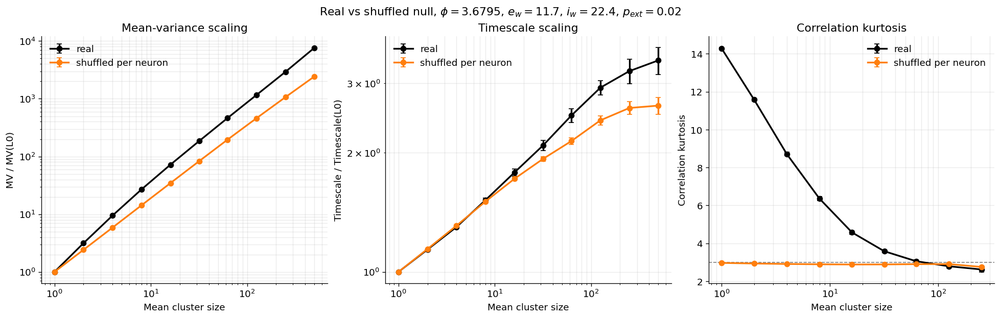

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/plots/real_vs_shuffle_exponents_and_score.png


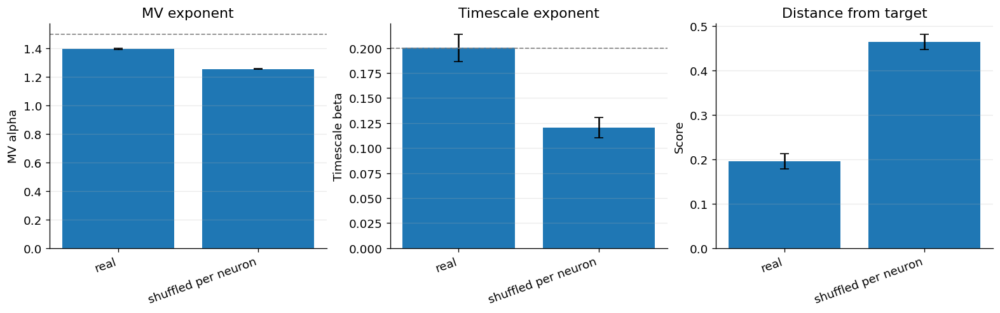

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/plots/real_vs_shuffle_paired_exponents_and_score.png


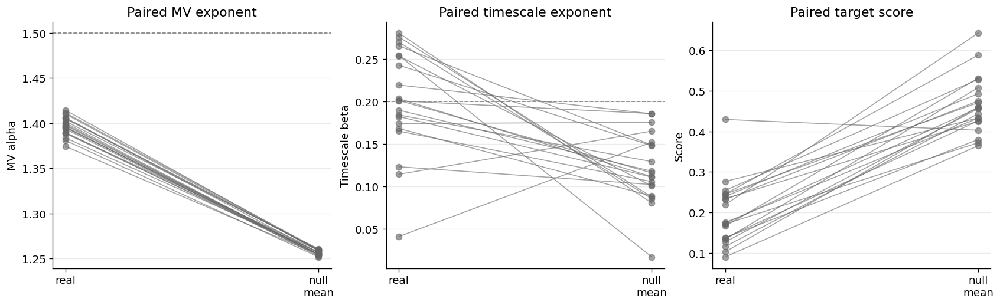

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/plots/real_vs_shuffle_delta_histograms.png


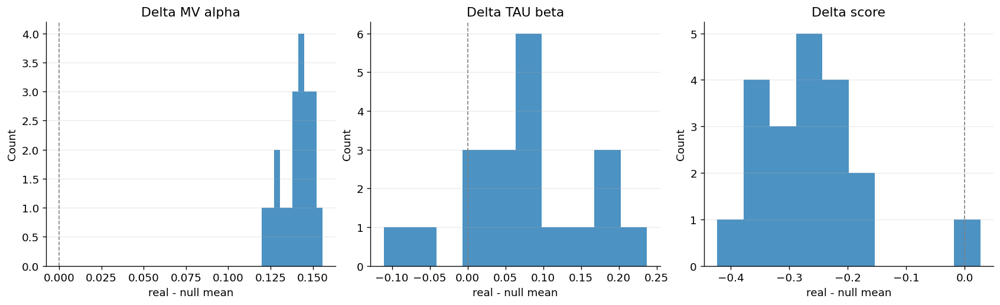


Done: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005
Files:
  design: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_design.csv
  seed metrics: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_seed_metrics.csv
  generation metrics: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_metrics.csv
  summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_summary.csv
  generation summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_summary.csv
  paired: /home/dburrows/

In [119]:
# ============================================================
# NULL MODEL TEST AT BEST PHI
#
# Real:
#   - 20 real simulations from best-phi start_dic
#
# Null:
#   - 10 independently time-shuffled nulls per real simulation
#   - preserves each neuron's activity distribution / rate
#   - destroys temporal coordination between neurons
#
# Parameters:
#   e_w   = 11.7
#   i_w   = 22.4
#   theta = 8.44
#   p_ext = 0.02
#   phi   = 3.67948717948718
#
# Uses:
#   - start_dic["smoothe"] = 0.05
#   - fn.automata_EI_hiermod
#   - fn.run_model
#   - fn.exp_smooth_spikes
#   - fn.compute_icg_metrics
#
# Saves:
#   real_vs_shuffle_design.csv
#   real_vs_shuffle_seed_metrics.csv
#   real_vs_shuffle_generation_metrics.csv
#   real_vs_shuffle_summary.csv
#   real_vs_shuffle_generation_summary.csv
#   real_vs_shuffle_paired_real_null_summary.csv
#   plots/
# ============================================================

import os
import inspect
import warnings
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits

import icg_functions as fn


# ============================================================
# Thread limits
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"


# ============================================================
# Settings
# ============================================================

BEST_PHI = 3.67948717948718

start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 11.7,
    "i_w": 22.4,
    "theta": 8.44,
    "p_ext": 0.02,
    "phi": BEST_PHI,
    "smoothe": 0.05,
}

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "bestphi3p679_ew11p7_iw22p4_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005"
)
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

N_REAL = 20
N_NULL_PER_REAL = 10
N_WORKERS = 20
BASE_SEED = 100#93

SMOOTHE = float(start_dic.get("smoothe", 0.05))
T_RUN = float(start_dic["T"])

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

print("OUTDIR:", OUTDIR)
print("N_REAL:", N_REAL)
print("N_NULL_PER_REAL:", N_NULL_PER_REAL)
print("N_NULL_TOTAL:", N_REAL * N_NULL_PER_REAL)
print("T_RUN:", T_RUN)
print("SMOOTHE:", SMOOTHE)
print("start_dic:", start_dic)


# ============================================================
# Helpers
# ============================================================

def safe_values(x):
    return (
        pd.Series(x)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .to_numpy(float)
    )


def sem(x):
    x = safe_values(x)
    if x.size <= 1:
        return np.nan
    return float(np.std(x, ddof=1) / np.sqrt(x.size))


def safe_mean(x):
    x = safe_values(x)
    return float(np.mean(x)) if x.size else np.nan


def pick_col(cols, candidates):
    for c in candidates:
        if c in cols:
            return c
    return None


def standardise_gen_df(gen_df):
    """
    Makes the ICG generation dataframe robust to old/new column names.
    """
    gen_df = gen_df.copy()

    if "corr_kurtosis" in gen_df.columns and "kurtosis_corr" not in gen_df.columns:
        gen_df["kurtosis_corr"] = gen_df["corr_kurtosis"]

    if "kurtosis_corr" in gen_df.columns and "corr_kurtosis" not in gen_df.columns:
        gen_df["corr_kurtosis"] = gen_df["kurtosis_corr"]

    if "mean_variance_norm" not in gen_df.columns and "MV_norm" in gen_df.columns:
        gen_df["mean_variance_norm"] = gen_df["MV_norm"]

    if "timescale_norm" not in gen_df.columns and "TAU_norm" in gen_df.columns:
        gen_df["timescale_norm"] = gen_df["TAU_norm"]

    if "mean_variance" not in gen_df.columns and "MV" in gen_df.columns:
        gen_df["mean_variance"] = gen_df["MV"]

    if "timescale" not in gen_df.columns and "TAU" in gen_df.columns:
        gen_df["timescale"] = gen_df["TAU"]

    return gen_df


def fit_power_slope(
    g,
    y_col,
    x_col="mean_cluster_size",
    exclude_first=True,
    exclude_last=False,
    min_points=3,
):
    dfit = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    dfit = dfit[(dfit[x_col] > 0) & (dfit[y_col] > 0)].sort_values(x_col)

    if exclude_first and len(dfit) > 0:
        dfit = dfit.iloc[1:]

    if exclude_last and len(dfit) > 0:
        dfit = dfit.iloc[:-1]

    if len(dfit) < min_points:
        return np.nan, np.nan, int(len(dfit))

    logx = np.log10(dfit[x_col].to_numpy(float))
    logy = np.log10(dfit[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = float(np.sum((logy - pred) ** 2))
    ss_tot = float(np.sum((logy - np.mean(logy)) ** 2))
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(dfit))


def make_model_pars(seed):
    pars = dict(start_dic)

    T = float(pars.pop("T"))
    smoothe = float(pars.pop("smoothe", SMOOTHE))

    if "slope" in pars and "phi" not in pars:
        pars["phi"] = float(pars.pop("slope"))
    else:
        pars.pop("slope", None)

    pars["seed"] = int(seed)

    # only pass args accepted by the model
    sig = inspect.signature(fn.automata_EI_hiermod.__init__)
    valid_args = set(sig.parameters.keys())

    if "phi" not in valid_args and "slope" in valid_args:
        pars["slope"] = pars.pop("phi")

    pars = {k: v for k, v in pars.items() if k in valid_args}

    return pars, T, smoothe


def shuffle_each_neuron(spikes, rng):
    """
    Independently shuffle each neuron's time series.

    Preserves:
      - each neuron's spike/activity count
      - each neuron's empirical activity distribution

    Destroys:
      - cross-neuron temporal coordination
      - propagation / synchrony / avalanche-like timing
      - population-level temporal structure
    """
    X = np.asarray(spikes).copy()

    for i in range(X.shape[0]):
        rng.shuffle(X[i])

    return X


def compute_metrics_for_spikes(spikes, dt, smoothe):
    """
    Smooth spikes, compute ICG generation metrics, then fit scaling slopes.

    Returns:
      metric_row:
        one-row summary with MV_alpha, TAU_beta, score, etc.

      gen_df:
        full generation-level dataframe
    """
    spikes_smooth = fn.exp_smooth_spikes(
        spikes,
        dt=float(dt),
        tau=float(smoothe),
    )

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="invalid value encountered in divide",
            category=RuntimeWarning,
        )

        with np.errstate(invalid="ignore", divide="ignore"):
            metric_row, gen_df = fn.compute_icg_metrics(
                spikes=spikes_smooth,
                dt=float(dt),
            )

    metric_row = dict(metric_row)
    gen_df = standardise_gen_df(gen_df)

    if "mean_cluster_size" not in gen_df.columns:
        raise ValueError(
            "Could not find mean_cluster_size in gen_df. "
            f"Columns are: {gen_df.columns.tolist()}"
        )

    if "mean_variance_norm" not in gen_df.columns:
        raise ValueError(
            "Could not find mean_variance_norm in gen_df. "
            f"Columns are: {gen_df.columns.tolist()}"
        )

    if "timescale_norm" not in gen_df.columns:
        raise ValueError(
            "Could not find timescale_norm in gen_df. "
            f"Columns are: {gen_df.columns.tolist()}"
        )

    MV_alpha, MV_r2, MV_n = fit_power_slope(
        gen_df,
        y_col="mean_variance_norm",
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    TAU_beta, TAU_r2, TAU_n = fit_power_slope(
        gen_df,
        y_col="timescale_norm",
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    if "kurtosis_corr" in gen_df.columns:
        KURT_slope, KURT_r2, KURT_n = fit_power_slope(
            gen_df,
            y_col="kurtosis_corr",
            x_col="mean_cluster_size",
            exclude_first=True,
            exclude_last=False,
        )
    else:
        KURT_slope, KURT_r2, KURT_n = np.nan, np.nan, 0

    score = (
        abs(MV_alpha - TARGET_ALPHA) + 2.0 * abs(TAU_beta - TARGET_BETA)
        if np.isfinite(MV_alpha) and np.isfinite(TAU_beta)
        else np.nan
    )

    # New-style names
    metric_row["MV_alpha"] = MV_alpha
    metric_row["MV_r2"] = MV_r2
    metric_row["MV_n_points"] = MV_n

    metric_row["TAU_beta"] = TAU_beta
    metric_row["TAU_r2"] = TAU_r2
    metric_row["TAU_n_points"] = TAU_n

    metric_row["KURT_slope"] = KURT_slope
    metric_row["KURT_r2"] = KURT_r2
    metric_row["KURT_n_points"] = KURT_n

    metric_row["score"] = score

    # Old-style aliases, useful if you have old plotting code expecting these
    metric_row["mv_alpha_norm"] = MV_alpha
    metric_row["mv_r2_norm"] = MV_r2
    metric_row["ts_beta_norm"] = TAU_beta
    metric_row["ts_r2_norm"] = TAU_r2

    return metric_row, gen_df


def add_common_metadata_to_out(
    out,
    condition,
    real_idx,
    null_idx,
    seed,
    shuffle_seed,
    mean_rate_hz,
    dt,
    T,
    smoothe,
):
    out = dict(out)

    out["condition"] = str(condition)
    out["real_idx"] = int(real_idx)
    out["null_idx"] = int(null_idx)
    out["seed"] = int(seed)
    out["shuffle_seed"] = int(shuffle_seed)

    out["mean_rate_hz"] = float(mean_rate_hz)
    out["dt"] = float(dt)
    out["T"] = float(T)
    out["smoothe"] = float(smoothe)

    out["n_neurons"] = int(start_dic["n_neurons"])
    out["phi"] = float(start_dic["phi"])
    out["theta"] = float(start_dic["theta"])
    out["p_ext"] = float(start_dic["p_ext"])
    out["e_w"] = float(start_dic["e_w"])
    out["i_w"] = float(start_dic["i_w"])
    out["ei_ratio"] = float(start_dic["ei_ratio"])
    out["refractory_steps"] = int(start_dic["refractory_steps"])

    return out


def add_common_metadata_to_gen_df(
    gen_df,
    condition,
    real_idx,
    null_idx,
    seed,
    shuffle_seed,
    mean_rate_hz,
):
    gen_df = gen_df.copy()

    gen_df["condition"] = str(condition)
    gen_df["real_idx"] = int(real_idx)
    gen_df["null_idx"] = int(null_idx)
    gen_df["seed"] = int(seed)
    gen_df["shuffle_seed"] = int(shuffle_seed)

    gen_df["mean_rate_hz"] = float(mean_rate_hz)

    gen_df["n_neurons"] = int(start_dic["n_neurons"])
    gen_df["phi"] = float(start_dic["phi"])
    gen_df["theta"] = float(start_dic["theta"])
    gen_df["p_ext"] = float(start_dic["p_ext"])
    gen_df["e_w"] = float(start_dic["e_w"])
    gen_df["i_w"] = float(start_dic["i_w"])
    gen_df["ei_ratio"] = float(start_dic["ei_ratio"])
    gen_df["refractory_steps"] = int(start_dic["refractory_steps"])
    gen_df["smoothe"] = float(SMOOTHE)

    return gen_df


def run_one_real_with_nulls(job):
    real_idx, seed = job

    pars, T, smoothe = make_model_pars(seed)

    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**pars)
        spikes, pop_rate = fn.run_model(model, T=T)

    dt = float(pars.get("dt", start_dic["dt"]))
    mean_rate_hz = float(spikes.mean() / dt)

    # ----------------------------
    # Real metrics
    # ----------------------------
    real_metric_row, real_gen_df = compute_metrics_for_spikes(
        spikes=spikes,
        dt=dt,
        smoothe=smoothe,
    )

    real_out = add_common_metadata_to_out(
        real_metric_row,
        condition="real",
        real_idx=real_idx,
        null_idx=-1,
        seed=seed,
        shuffle_seed=-1,
        mean_rate_hz=mean_rate_hz,
        dt=dt,
        T=T,
        smoothe=smoothe,
    )

    real_gen_df = add_common_metadata_to_gen_df(
        real_gen_df,
        condition="real",
        real_idx=real_idx,
        null_idx=-1,
        seed=seed,
        shuffle_seed=-1,
        mean_rate_hz=mean_rate_hz,
    )

    rows = [real_out]
    gen_rows = [real_gen_df]

    # ----------------------------
    # Null metrics
    # ----------------------------
    for null_idx in range(N_NULL_PER_REAL):
        shuffle_seed = int(seed + 100000 + null_idx)
        rng = np.random.default_rng(shuffle_seed)

        spikes_null = shuffle_each_neuron(spikes, rng)

        null_metric_row, null_gen_df = compute_metrics_for_spikes(
            spikes=spikes_null,
            dt=dt,
            smoothe=smoothe,
        )

        null_mean_rate_hz = float(spikes_null.mean() / dt)

        null_out = add_common_metadata_to_out(
            null_metric_row,
            condition="null_shuffle",
            real_idx=real_idx,
            null_idx=null_idx,
            seed=seed,
            shuffle_seed=shuffle_seed,
            mean_rate_hz=null_mean_rate_hz,
            dt=dt,
            T=T,
            smoothe=smoothe,
        )

        null_gen_df = add_common_metadata_to_gen_df(
            null_gen_df,
            condition="null_shuffle",
            real_idx=real_idx,
            null_idx=null_idx,
            seed=seed,
            shuffle_seed=shuffle_seed,
            mean_rate_hz=null_mean_rate_hz,
        )

        rows.append(null_out)
        gen_rows.append(null_gen_df)

    return rows, gen_rows


# ============================================================
# Build design
# ============================================================

jobs = [(int(i), int(BASE_SEED + i)) for i in range(N_REAL)]

design = pd.DataFrame(jobs, columns=["real_idx", "seed"])
design["n_null_per_real"] = int(N_NULL_PER_REAL)

for k, v in start_dic.items():
    design[k] = v

design_path = OUTDIR / "real_vs_shuffle_design.csv"
design.to_csv(design_path, index=False)

print("Saved design:", design_path)


# ============================================================
# Run real + null simulations
# ============================================================

all_rows = []
all_gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for rows, gen_rows in tqdm(
        pool.imap_unordered(run_one_real_with_nulls, jobs, chunksize=1),
        total=len(jobs),
        desc="Running real + shuffled null tests",
    ):
        all_rows.extend(rows)
        all_gen_rows.extend(gen_rows)


# ============================================================
# Save raw outputs
# ============================================================

df = (
    pd.DataFrame(all_rows)
    .sort_values(["condition", "real_idx", "null_idx"])
    .reset_index(drop=True)
)

gen_all = (
    pd.concat(all_gen_rows, ignore_index=True)
    .sort_values(["condition", "real_idx", "null_idx", "gen"])
    .reset_index(drop=True)
)

seed_metrics_path = OUTDIR / "real_vs_shuffle_seed_metrics.csv"
gen_metrics_path = OUTDIR / "real_vs_shuffle_generation_metrics.csv"

df.to_csv(seed_metrics_path, index=False)
gen_all.to_csv(gen_metrics_path, index=False)

print("Saved:", seed_metrics_path)
print("Saved:", gen_metrics_path)

print("\nSeed metric columns:")
print(df.columns.tolist())

print("\nGeneration metric columns:")
print(gen_all.columns.tolist())


# ============================================================
# Summaries
# ============================================================

summary = (
    df
    .groupby("condition", as_index=False)
    .agg(
        n=("seed", "count"),
        n_reals=("real_idx", "nunique"),

        MV_alpha_mean=("MV_alpha", "mean"),
        MV_alpha_sem=("MV_alpha", sem),
        MV_r2_mean=("MV_r2", "mean"),
        MV_r2_sem=("MV_r2", sem),

        TAU_beta_mean=("TAU_beta", "mean"),
        TAU_beta_sem=("TAU_beta", sem),
        TAU_r2_mean=("TAU_r2", "mean"),
        TAU_r2_sem=("TAU_r2", sem),

        KURT_slope_mean=("KURT_slope", "mean"),
        KURT_slope_sem=("KURT_slope", sem),
        KURT_r2_mean=("KURT_r2", "mean"),
        KURT_r2_sem=("KURT_r2", sem),

        score_mean=("score", "mean"),
        score_sem=("score", sem),

        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),
    )
)

summary["target_score_from_means"] = (
    np.abs(summary["MV_alpha_mean"] - TARGET_ALPHA)
    + 2.0 * np.abs(summary["TAU_beta_mean"] - TARGET_BETA)
)

gen_summary_agg = {
    "n": ("seed", "count"),
    "n_reals": ("real_idx", "nunique"),

    "mean_cluster_size_mean": ("mean_cluster_size", "mean"),
    "mean_cluster_size_sem": ("mean_cluster_size", sem),

    "mean_variance_norm_mean": ("mean_variance_norm", "mean"),
    "mean_variance_norm_sem": ("mean_variance_norm", sem),

    "timescale_norm_mean": ("timescale_norm", "mean"),
    "timescale_norm_sem": ("timescale_norm", sem),
}

if "corr_kurtosis" in gen_all.columns:
    gen_summary_agg["corr_kurtosis_mean"] = ("corr_kurtosis", "mean")
    gen_summary_agg["corr_kurtosis_sem"] = ("corr_kurtosis", sem)

if "kurtosis_corr" in gen_all.columns:
    gen_summary_agg["kurtosis_corr_mean"] = ("kurtosis_corr", "mean")
    gen_summary_agg["kurtosis_corr_sem"] = ("kurtosis_corr", sem)

gen_summary = (
    gen_all
    .groupby(["condition", "gen"], as_index=False)
    .agg(**gen_summary_agg)
    .sort_values(["condition", "gen"])
    .reset_index(drop=True)
)

summary_path = OUTDIR / "real_vs_shuffle_summary.csv"
gen_summary_path = OUTDIR / "real_vs_shuffle_generation_summary.csv"

summary.to_csv(summary_path, index=False)
gen_summary.to_csv(gen_summary_path, index=False)

print("Saved:", summary_path)
print("Saved:", gen_summary_path)

print("\nSummary:")
print(summary.round(5).to_string(index=False))


# ============================================================
# Paired real-vs-null summary per real simulation
# ============================================================

real_df = (
    df[df["condition"] == "real"]
    .set_index("real_idx")
    .add_prefix("real_")
)

null_by_real = (
    df[df["condition"] == "null_shuffle"]
    .groupby("real_idx", as_index=True)
    .agg(
        null_n=("seed", "count"),

        null_MV_alpha_mean=("MV_alpha", "mean"),
        null_MV_alpha_sem=("MV_alpha", sem),

        null_TAU_beta_mean=("TAU_beta", "mean"),
        null_TAU_beta_sem=("TAU_beta", sem),

        null_MV_r2_mean=("MV_r2", "mean"),
        null_TAU_r2_mean=("TAU_r2", "mean"),

        null_KURT_slope_mean=("KURT_slope", "mean"),
        null_score_mean=("score", "mean"),

        null_mean_rate_hz_mean=("mean_rate_hz", "mean"),
    )
)

paired = real_df.join(null_by_real, how="left").reset_index()

paired["delta_MV_alpha"] = (
    paired["real_MV_alpha"] - paired["null_MV_alpha_mean"]
)

paired["delta_TAU_beta"] = (
    paired["real_TAU_beta"] - paired["null_TAU_beta_mean"]
)

paired["delta_MV_r2"] = (
    paired["real_MV_r2"] - paired["null_MV_r2_mean"]
)

paired["delta_TAU_r2"] = (
    paired["real_TAU_r2"] - paired["null_TAU_r2_mean"]
)

paired["delta_score"] = (
    paired["real_score"] - paired["null_score_mean"]
)

paired_path = OUTDIR / "real_vs_shuffle_paired_real_null_summary.csv"
paired.to_csv(paired_path, index=False)

print("Saved:", paired_path)

print("\nPaired real-null differences:")
print(
    paired[
        [
            "real_idx",
            "real_MV_alpha",
            "null_MV_alpha_mean",
            "delta_MV_alpha",
            "real_TAU_beta",
            "null_TAU_beta_mean",
            "delta_TAU_beta",
            "real_score",
            "null_score_mean",
            "delta_score",
            "real_mean_rate_hz",
            "null_mean_rate_hz_mean",
        ]
    ].round(5).to_string(index=False)
)


# ============================================================
# Plotting
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

colors = {
    "real": "black",
    "null_shuffle": "tab:orange",
}

labels = {
    "real": "real",
    "null_shuffle": "shuffled per neuron",
}


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# 1. Scaling forms
# ============================================================

has_kurtosis = "corr_kurtosis_mean" in gen_summary.columns

ncols = 3 if has_kurtosis else 2
fig, axes = plt.subplots(
    1,
    ncols,
    figsize=(5.4 * ncols, 4.8),
    constrained_layout=True,
)

if ncols == 1:
    axes = [axes]

for condition in ["real", "null_shuffle"]:
    gg = gen_summary[gen_summary["condition"] == condition].sort_values("gen")

    x = gg["mean_cluster_size_mean"].to_numpy()

    axes[0].errorbar(
        x,
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

    axes[1].errorbar(
        x,
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

    if has_kurtosis:
        axes[2].errorbar(
            x,
            gg["corr_kurtosis_mean"],
            yerr=gg["corr_kurtosis_sem"],
            marker="o",
            linewidth=2,
            capsize=3,
            color=colors[condition],
            label=labels[condition],
        )

axes[0].set_title("Mean-variance scaling")
axes[1].set_title("Timescale scaling")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")

axes[0].set_yscale("log")
axes[1].set_yscale("log")

if has_kurtosis:
    axes[2].set_title("Correlation kurtosis")
    axes[2].set_ylabel("Correlation kurtosis")
    axes[2].axhline(3.0, linestyle="--", linewidth=1, color="grey")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25, which="both")
    ax.legend(frameon=False)

fig.suptitle(
    rf"Real vs shuffled null, $\phi={start_dic['phi']:.4f}$, "
    rf"$e_w={start_dic['e_w']}$, $i_w={start_dic['i_w']}$, "
    rf"$p_{{ext}}={start_dic['p_ext']}$",
    y=1.05,
)

savefig(fig, "real_vs_shuffle_scaling_forms.png")
plt.show()


# ============================================================
# 2. Fitted exponent bars
# ============================================================

plot_df = (
    summary
    .set_index("condition")
    .loc[["real", "null_shuffle"]]
    .reset_index()
)

x = np.arange(len(plot_df))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

axes[0].bar(
    x,
    plot_df["MV_alpha_mean"],
    yerr=plot_df["MV_alpha_sem"],
    capsize=4,
)
axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1, color="grey")
axes[0].set_xticks(x)
axes[0].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[0].set_ylabel("MV alpha")
axes[0].set_title("MV exponent")

axes[1].bar(
    x,
    plot_df["TAU_beta_mean"],
    yerr=plot_df["TAU_beta_sem"],
    capsize=4,
)
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1, color="grey")
axes[1].set_xticks(x)
axes[1].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[1].set_ylabel("Timescale beta")
axes[1].set_title("Timescale exponent")

axes[2].bar(
    x,
    plot_df["score_mean"],
    yerr=plot_df["score_sem"],
    capsize=4,
)
axes[2].set_xticks(x)
axes[2].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[2].set_ylabel("Score")
axes[2].set_title("Distance from target")

for ax in axes:
    ax.grid(alpha=0.25, axis="y")

savefig(fig, "real_vs_shuffle_exponents_and_score.png")
plt.show()


# ============================================================
# 3. Paired real-null differences
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)

for _, r in paired.iterrows():
    axes[0].plot(
        [0, 1],
        [r["real_MV_alpha"], r["null_MV_alpha_mean"]],
        marker="o",
        linewidth=1,
        alpha=0.6,
        color="0.4",
    )

    axes[1].plot(
        [0, 1],
        [r["real_TAU_beta"], r["null_TAU_beta_mean"]],
        marker="o",
        linewidth=1,
        alpha=0.6,
        color="0.4",
    )

    axes[2].plot(
        [0, 1],
        [r["real_score"], r["null_score_mean"]],
        marker="o",
        linewidth=1,
        alpha=0.6,
        color="0.4",
    )

axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1, color="grey")
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1, color="grey")

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["real", "null\nmean"])
axes[0].set_ylabel("MV alpha")
axes[0].set_title("Paired MV exponent")

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["real", "null\nmean"])
axes[1].set_ylabel("Timescale beta")
axes[1].set_title("Paired timescale exponent")

axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["real", "null\nmean"])
axes[2].set_ylabel("Score")
axes[2].set_title("Paired target score")

for ax in axes:
    ax.grid(alpha=0.25, axis="y")

savefig(fig, "real_vs_shuffle_paired_exponents_and_score.png")
plt.show()


# ============================================================
# 4. Histograms / scatter of real vs null effects
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)

axes[0].hist(paired["delta_MV_alpha"].dropna(), bins=10, alpha=0.8)
axes[0].axvline(0, linestyle="--", linewidth=1, color="grey")
axes[0].set_xlabel("real - null mean")
axes[0].set_ylabel("Count")
axes[0].set_title("Delta MV alpha")

axes[1].hist(paired["delta_TAU_beta"].dropna(), bins=10, alpha=0.8)
axes[1].axvline(0, linestyle="--", linewidth=1, color="grey")
axes[1].set_xlabel("real - null mean")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta TAU beta")

axes[2].hist(paired["delta_score"].dropna(), bins=10, alpha=0.8)
axes[2].axvline(0, linestyle="--", linewidth=1, color="grey")
axes[2].set_xlabel("real - null mean")
axes[2].set_ylabel("Count")
axes[2].set_title("Delta score")

for ax in axes:
    ax.grid(alpha=0.25, axis="y")

savefig(fig, "real_vs_shuffle_delta_histograms.png")
plt.show()


print("\nDone:", OUTDIR)
print("Files:")
print("  design:", design_path)
print("  seed metrics:", seed_metrics_path)
print("  generation metrics:", gen_metrics_path)
print("  summary:", summary_path)
print("  generation summary:", gen_summary_path)
print("  paired:", paired_path)
print("  plots:", PLOTDIR)

In [ ]:
#!/usr/bin/env python3
"""Standalone directed ER density sweep; icg_functions.py is never modified.

Run in the environment containing your unchanged icg_functions module:
    python er_density_sweep.py

Dependencies: numpy pandas matplotlib tqdm threadpoolctl, plus the dependencies
of icg_functions. Settings below retain the supplied control's CA and ICG setup.

Range calibration reconstructs ONLY the topology of the old 15-phi x 20-seed
control. The new sweep uses 15 LINEARLY SPACED probabilities from its minimum
observed density to twice its maximum observed density (capped at 1).
There is no phi-to-density matching in the ER simulation sweep.

ER is directed G(n,p): each non-diagonal edge is an independent Bernoulli(p).
Consequently realized density fluctuates slightly between seeds. The old control
was G(n,m), with fixed edge count; both discard hierarchical organization.
"""
import os

# Set BEFORE importing NumPy or the module, including in spawned workers.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                 "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"

import inspect
import json
import multiprocessing as mp
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits
import icg_functions as fn

START_DIC = {
    "n_neurons": 2000, "T": 10, "dt": 0.01, "refractory_steps": 2,
    "ei_ratio": 0.2, "e_w": 11.7, "i_w": 22.4, "theta": 8.44,
    "p_ext": 0.00, "phi": 4.2, "smoothe": 0.05,
}
OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "er_density_newpars_ew11p7_iw22p4_pext0_15densities_20seeds_smooth005_doublemax"
)
N_WORKERS = 20
N_SEEDS = 20
N_DENSITIES = 15
BASE_SEED = 777
TARGET_MV = 1.50
TARGET_TAU = 0.20

# Reconstruct the previous control's full topology design to determine its range.
REFERENCE_PHI_VALUES = np.linspace(1.5, 10.0, 15)
REFERENCE_N_SEEDS = 20
REFERENCE_BASE_SEED = 777
DENSITY_MAX_MULTIPLIER = 2.0
PREFIX = "er_density"


def safe_values(x):
    return pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna().to_numpy(float)


def sem(x):
    values = safe_values(x)
    return float(np.std(values, ddof=1) / np.sqrt(values.size)) if values.size > 1 else np.nan


def safe_loglog_slope(x, y, exclude_first=True, exclude_last=False, min_points=3):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x, y = x[ok], y[ok]
    order = np.argsort(x)
    x, y = x[order], y[order]
    if exclude_first:
        x, y = x[1:], y[1:]
    if exclude_last:
        x, y = x[:-1], y[:-1]
    if len(x) < min_points or np.unique(x).size < 2:
        return np.nan, np.nan, np.nan
    logx, logy = np.log10(x), np.log10(y)
    slope, intercept = np.polyfit(logx, logy, 1)
    ss_res = float(np.sum((logy - (intercept + slope * logx)) ** 2))
    ss_tot = float(np.sum((logy - logy.mean()) ** 2))
    r2 = float(1 - ss_res / ss_tot) if ss_tot > 0 else np.nan
    # Retain the supplied script's convention: p-values are not calculated.
    return float(slope), r2, np.nan


def standardise_gen_df(gen_df):
    result = gen_df.copy()
    for canonical, alias in (("corr_kurtosis", "kurtosis_corr"),
                             ("mean_variance_norm", "MV_norm"),
                             ("timescale_norm", "TAU_norm"),
                             ("mean_variance", "MV"), ("timescale", "TAU")):
        if canonical not in result and alias in result:
            result[canonical] = result[alias]
    if "kurtosis_corr" not in result and "corr_kurtosis" in result:
        result["kurtosis_corr"] = result["corr_kurtosis"]
    return result


def make_hiermod_model_kwargs(phi, seed):
    pars = dict(START_DIC)
    pars.update(phi=float(phi), seed=int(seed))
    pars.pop("T")
    pars.pop("smoothe")
    signature = inspect.signature(fn.automata_EI_hiermod.__init__)
    valid_args = set(signature.parameters)
    if "phi" not in valid_args and "slope" in valid_args:
        pars["slope"] = pars.pop("phi")
    if any(p.kind == inspect.Parameter.VAR_KEYWORD for p in signature.parameters.values()):
        return pars
    return {key: value for key, value in pars.items() if key in valid_args}


def reference_density_job(job):
    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**make_hiermod_model_kwargs(job["phi"], job["seed"]))
        # Copy so the calibration does not alter even the reference object's A.
        adjacency = np.array(model.A, dtype=np.uint8, copy=True)
        np.fill_diagonal(adjacency, 0)
        n = int(model.n)
        edges = int(adjacency.sum())
    return dict(job, n_neurons=n, n_edges=edges,
                edge_density=edges / (n * (n - 1)), mean_degree=edges / n)


def calibrate_density_range(ctx):
    jobs = [dict(phi_idx=idx, phi=float(phi), seed_idx=s,
                 seed=int(REFERENCE_BASE_SEED + idx * 100_000 + s))
            for idx, phi in enumerate(REFERENCE_PHI_VALUES)
            for s in range(REFERENCE_N_SEEDS)]
    with ctx.Pool(min(N_WORKERS, len(jobs))) as pool:
        records = list(tqdm(pool.imap_unordered(reference_density_job, jobs, chunksize=1),
                            total=len(jobs), desc="Previous range: topology only"))
    reference = pd.DataFrame(records).sort_values(["phi_idx", "seed_idx"])
    reference.to_csv(OUTDIR / f"{PREFIX}_reference_topology_calibration.csv", index=False)
    if not (reference["n_neurons"] == START_DIC["n_neurons"]).all():
        raise ValueError("Reference network size differs from the requested ER size.")
    old_min = float(reference["edge_density"].min())
    old_max = float(reference["edge_density"].max())
    new_max = min(1.0, DENSITY_MAX_MULTIPLIER * old_max)
    if new_max <= old_min:
        raise ValueError("Calibration does not give a usable density range.")
    densities = np.linspace(old_min, new_max, N_DENSITIES)
    metadata = dict(previous_density_min=old_min, previous_density_max=old_max,
                    requested_multiplier=DENSITY_MAX_MULTIPLIER,
                    density_min=old_min, density_max=new_max,
                    capped_at_one=bool(DENSITY_MAX_MULTIPLIER * old_max > 1),
                    spacing="linear", graph_model="directed_G(n,p)",
                    densities=densities.tolist(), n_seeds=N_SEEDS,
                    reference_phi_values=REFERENCE_PHI_VALUES.tolist(),
                    reference_n_seeds=REFERENCE_N_SEEDS, parameters=START_DIC)
    (OUTDIR / f"{PREFIX}_range.json").write_text(json.dumps(metadata, indent=2) + "\n")
    print(f"Previous observed density range: {old_min:.8g} to {old_max:.8g}", flush=True)
    print(f"New ER density range: {old_min:.8g} to {new_max:.8g}", flush=True)
    print("ER probabilities:", densities, flush=True)
    print("Expected mean degrees:", densities * (START_DIC["n_neurons"] - 1), flush=True)
    return densities


def make_er_directed(n, density, rng):
    if n < 2 or not 0 <= density <= 1:
        raise ValueError("Require n >= 2 and density in [0, 1].")
    adjacency = (rng.random((n, n)) < density).astype(np.uint8)
    np.fill_diagonal(adjacency, 0)
    return adjacency


class automata_EI_ER:
    """CA implementation from the supplied control, with a supplied ER graph.

    Rows are sources; columns are targets. All neurons initially quiescent.
    The sigmoid has nonzero baseline activation even with p_ext = 0.
    """
    def __init__(self, A, n_neurons=2000, ei_ratio=0.2, e_w=11.7, i_w=22.4,
                 theta=8.44, p_ext=0.0, refractory_steps=2, dt=0.01, seed=0):
        self.rng = np.random.default_rng(seed)
        self.A = np.asarray(A, dtype=np.uint8)
        np.fill_diagonal(self.A, 0)
        self.n = int(n_neurons)
        self.e = int(n_neurons - n_neurons * ei_ratio)
        self.i = self.n - self.e
        if self.A.shape != (self.n, self.n):
            raise ValueError(f"Unexpected adjacency shape: {self.A.shape}")
        self.e_w, self.i_w, self.theta = float(e_w), float(i_w), float(theta)
        self.p_ext = float(p_ext)
        self.refractory_steps, self.dt = int(refractory_steps), float(dt)
        self.A_e, self.A_i = self.A[:self.e, :], self.A[self.e:, :]
        self.state = np.zeros(self.n, dtype=np.int16)

    def step(self):
        active = self.state == 1
        inp_e = self.A_e.T @ active[:self.e].astype(np.float32)
        inp_i = self.A_i.T @ active[self.e:].astype(np.float32)
        net = self.e_w * inp_e - self.i_w * inp_i
        # Large inhibitory inputs can overflow exp; sigmoid limit is still zero.
        with np.errstate(over="ignore"):
            p_net = 1.0 / (1.0 + np.exp(-(net - self.theta)))
        quiescent = self.state == 0
        ext_events = self.rng.random(self.n) < self.p_ext
        net_events = self.rng.random(self.n) < p_net
        new_active = quiescent & (ext_events | net_events)
        new_state = np.zeros_like(self.state)
        new_state[active] = 2
        refractory = self.state >= 2
        new_state[refractory] = self.state[refractory] + 1
        new_state[new_state > self.refractory_steps + 1] = 0
        new_state[new_active] = 1
        self.state = new_state
        return (new_state == 1).astype(np.uint8)


def run_model_local(model, T=10.0):
    n_steps = int(T / model.dt)
    spikes = np.zeros((model.n, n_steps), dtype=np.uint8)
    pop_rate = np.zeros(n_steps, dtype=float)
    for step in range(n_steps):
        active = model.step()
        spikes[:, step] = active
        pop_rate[step] = active.mean() / model.dt
    return spikes, pop_rate


def compute_icg_and_exponents(spikes, dt, smoothe):
    smoothed = fn.exp_smooth_spikes(spikes, dt=float(dt), tau=float(smoothe))
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="invalid value encountered in divide",
                                category=RuntimeWarning)
        with np.errstate(invalid="ignore", divide="ignore"):
            metric_row, gen_df = fn.compute_icg_metrics(spikes=smoothed, dt=float(dt))
    metric_row = dict(metric_row)
    gen_df = standardise_gen_df(gen_df)
    required = {"mean_cluster_size", "mean_variance_norm", "timescale_norm"}
    if required - set(gen_df.columns):
        raise ValueError(f"Missing ICG columns {required - set(gen_df.columns)}; "
                         f"available: {gen_df.columns.tolist()}")
    for label, column in (("MV", "mean_variance_norm"), ("TAU", "timescale_norm"),
                          ("KURT", "corr_kurtosis")):
        slope, r2, p = (safe_loglog_slope(gen_df["mean_cluster_size"], gen_df[column])
                        if column in gen_df else (np.nan, np.nan, np.nan))
        exponent = {"MV": "alpha", "TAU": "beta", "KURT": "slope"}[label]
        metric_row[f"{label}_{exponent}"] = slope
        metric_row[f"{label}_r2"], metric_row[f"{label}_p"] = r2, p
    alpha, beta = metric_row["MV_alpha"], metric_row["TAU_beta"]
    metric_row["score"] = (abs(alpha - TARGET_MV) + 2 * abs(beta - TARGET_TAU)
                           if np.isfinite(alpha) and np.isfinite(beta) else np.nan)
    metric_row.update(mv_alpha_norm=alpha, mv_r2_norm=metric_row["MV_r2"],
                      ts_beta_norm=beta, ts_r2_norm=metric_row["TAU_r2"])
    return metric_row, gen_df


def run_one_job(job):
    with threadpool_limits(limits=1):
        return run_one_job_inner(job)


def run_one_job_inner(job):
    # Retain the old ER seed offset; use independent generators for topology
    # and dynamics, as in the supplied script. Seed legacy NumPy as well in case
    # the unchanged ICG module uses its global RNG.
    er_seed = int(job["seed"] + 10_000_000)
    np.random.seed(er_seed % (2 ** 32))
    adjacency = make_er_directed(START_DIC["n_neurons"], job["density"],
                                 np.random.default_rng(er_seed))
    model = automata_EI_ER(A=adjacency, seed=er_seed,
                          **{k: v for k, v in START_DIC.items()
                             if k not in ("T", "phi", "smoothe")})
    spikes, pop_rate = run_model_local(model, T=float(START_DIC["T"]))
    dt = model.dt
    edges = int(adjacency.sum())
    metadata = dict(job, er_seed=er_seed, n_neurons=model.n, n_e=model.e, n_i=model.i,
                    **{k: v for k, v in START_DIC.items() if k not in ("phi", "n_neurons")},
                    n_edges_er=edges, edge_density_er=edges / (model.n * (model.n - 1)),
                    mean_out_degree_er=edges / model.n, mean_in_degree_er=edges / model.n,
                    expected_mean_degree=job["density"] * (model.n - 1))
    diagnostics = dict(mean_rate_hz=float(spikes.mean() / dt),
                       pop_rate_mean_hz=float(pop_rate.mean()),
                       pop_rate_std_hz=float(pop_rate.std()),
                       frac_silent_frames=float(np.mean(spikes.sum(axis=0) == 0)),
                       frac_active_neurons=float(np.mean(spikes.sum(axis=1) > 0)))
    metrics, gen_df = compute_icg_and_exponents(spikes, dt, START_DIC["smoothe"])
    # Ensure module metric names cannot overwrite experiment metadata.
    output = dict(metrics)
    output.update(metadata)
    output.update(diagnostics)
    for key, value in metadata.items():
        gen_df[key] = value
    return output, gen_df


def save_outputs(rows, gen_rows, partial=False):
    suffix = "_partial" if partial else ""
    exponents = pd.DataFrame(rows).sort_values(["density_idx", "seed_idx"]).reset_index(drop=True)
    icg = pd.concat(gen_rows, ignore_index=True)
    order = ["density_idx", "seed_idx"] + (["gen"] if "gen" in icg else ["mean_cluster_size"])
    icg = icg.sort_values(order).reset_index(drop=True)
    exponents.to_csv(OUTDIR / f"{PREFIX}_seed_exponents{suffix}.csv", index=False)
    icg.to_csv(OUTDIR / f"{PREFIX}_icg_rows{suffix}.csv", index=False)
    return exponents, icg


def summarise(exponents):
    aggregation = {"n": ("seed_idx", "count"),
                   "n_valid_MV": ("MV_alpha", "count"),
                   "n_valid_TAU": ("TAU_beta", "count"),
                   "n_valid_score": ("score", "count")}
    for column in ("MV_alpha", "MV_r2", "TAU_beta", "TAU_r2", "KURT_slope", "score"):
        aggregation[column + "_mean"] = (column, "mean")
        aggregation[column + "_sem"] = (column, sem)
    for column in ("mean_rate_hz", "frac_silent_frames", "frac_active_neurons"):
        aggregation[column] = (column, "mean")
        aggregation[column + "_sem"] = (column, sem)
    for column in ("n_edges_er", "edge_density_er", "mean_out_degree_er", "mean_in_degree_er"):
        aggregation[column + "_mean"] = (column, "mean")
        aggregation[column + "_sem"] = (column, sem)
    result = exponents.groupby(["density_idx", "density"], as_index=False).agg(**aggregation)
    result = result.sort_values("density_idx").reset_index(drop=True)
    result.to_csv(OUTDIR / f"{PREFIX}_summary.csv", index=False)
    return result


def make_plots(exponents, summary, best_density):
    figdir = OUTDIR / "density_plots"
    figdir.mkdir(exist_ok=True)
    plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                         "axes.spines.right": False, "figure.dpi": 120})

    def decorate(ax):
        ax.set_xlabel("Directed ER edge probability p")
        ax.grid(alpha=0.3)
        if np.isfinite(best_density):
            ax.axvline(best_density, linestyle="--", linewidth=1, color="grey")

    def finish(fig, name):
        fig.tight_layout()
        fig.savefig(figdir / name, dpi=250, bbox_inches="tight")
        plt.close(fig)

    specifications = [
        ("score", "score_mean", "score_sem", "Scaling score", "Score", None),
        ("MV_alpha", "MV_alpha_mean", "MV_alpha_sem", "Mean-variance scaling", r"MV exponent $\alpha$", TARGET_MV),
        ("TAU_beta", "TAU_beta_mean", "TAU_beta_sem", "Timescale scaling", r"Timescale exponent $\beta$", TARGET_TAU),
        ("mean_rate_hz", "mean_rate_hz", "mean_rate_hz_sem", "Mean firing rate", "Mean rate (Hz)", None),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (_, column, uncertainty, title, ylabel, target) in zip(axes.ravel(), specifications):
        ax.errorbar(summary["density"], summary[column], yerr=summary[uncertainty],
                    marker="o", linewidth=1.5, capsize=2)
        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1)
        ax.set(title=title, ylabel=ylabel)
        decorate(ax)
    fig.suptitle(f"ER density sweep; p_ext = {START_DIC['p_ext']}; {N_SEEDS} seeds/density")
    finish(fig, f"{PREFIX}_summary_2x2.png")
    for raw, column, uncertainty, title, ylabel, target in specifications:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.errorbar(summary["density"], summary[column], yerr=summary[uncertainty], marker="o", capsize=2)
        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1)
        ax.set(title=title, ylabel=ylabel)
        decorate(ax)
        finish(fig, f"{PREFIX}_{raw}_vs_density.png")
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(exponents["density"], exponents[raw], alpha=0.25, s=16)
        ax.plot(summary["density"], summary[column], marker="o", linewidth=2)
        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1)
        ax.set(title=f"ER seed-level {title.lower()}", ylabel=ylabel)
        decorate(ax)
        finish(fig, f"{PREFIX}_seed_{raw}_scatter.png")
    fig, ax = plt.subplots(figsize=(6, 4))
    for column, label in (("frac_silent_frames", "silent frames"),
                          ("frac_active_neurons", "active neurons")):
        ax.errorbar(summary["density"], summary[column], yerr=summary[column + "_sem"],
                    marker="o", capsize=2, label=label)
    ax.set(title="ER activity diagnostics", ylabel="Fraction")
    decorate(ax)
    ax.legend(frameon=False)
    finish(fig, f"{PREFIX}_activity_diagnostics.png")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(summary["density"], summary["density"], linestyle="--", label="requested p")
    ax.errorbar(summary["density"], summary["edge_density_er_mean"],
                yerr=summary["edge_density_er_sem"], marker="o", capsize=2, label="realized ER density")
    ax.set(title="ER density check", ylabel="Directed edge density")
    decorate(ax)
    ax.legend(frameon=False)
    finish(fig, f"{PREFIX}_density_check.png")
    # Directly inspect whether BOTH exponents approach their targets together.
    fig, ax = plt.subplots(figsize=(6, 5))
    points = ax.scatter(exponents["MV_alpha"], exponents["TAU_beta"],
                        c=exponents["density"], cmap="viridis", alpha=0.4, s=20)
    ax.plot(summary["MV_alpha_mean"], summary["TAU_beta_mean"], color="grey", linewidth=1)
    ax.scatter([TARGET_MV], [TARGET_TAU], marker="*", color="red", s=180, label="target combination")
    ax.axvline(TARGET_MV, linestyle="--", linewidth=1, color="grey")
    ax.axhline(TARGET_TAU, linestyle="--", linewidth=1, color="grey")
    ax.set(xlabel=r"MV exponent $\alpha$", ylabel=r"Timescale exponent $\beta$",
           title="Joint ER scaling exponents")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    fig.colorbar(points, ax=ax, label="ER edge probability p")
    finish(fig, f"{PREFIX}_joint_exponents.png")


def main():
    OUTDIR.mkdir(parents=True, exist_ok=True)
    print("OUTDIR:", OUTDIR, flush=True)
    print("Parameters:", START_DIC, flush=True)
    # fork retains the supplied Linux workflow; spawn is available elsewhere.
    ctx = mp.get_context("fork" if "fork" in mp.get_all_start_methods() else "spawn")
    densities = calibrate_density_range(ctx)
    jobs = [dict(condition="ER_density_sweep", density_idx=idx, density=float(density),
                 seed_idx=s, seed=int(BASE_SEED + idx * 100_000 + s))
            for idx, density in enumerate(densities) for s in range(N_SEEDS)]
    design = pd.DataFrame(jobs)
    for key, value in START_DIC.items():
        if key != "phi":
            design[key] = value
    design["er_seed"] = design["seed"] + 10_000_000
    design["expected_mean_degree"] = design["density"] * (START_DIC["n_neurons"] - 1)
    design.to_csv(OUTDIR / f"{PREFIX}_design.csv", index=False)
    print(f"Running {len(jobs)} ER jobs: {N_DENSITIES} densities x {N_SEEDS} seeds; "
          f"{min(N_WORKERS, len(jobs))} workers", flush=True)
    rows, gen_rows = [], []
    try:
        with ctx.Pool(min(N_WORKERS, len(jobs))) as pool:
            for output, generations in tqdm(pool.imap_unordered(run_one_job, jobs, chunksize=1),
                                             total=len(jobs), desc="ER density sweep"):
                rows.append(output)
                gen_rows.append(generations)
                if len(rows) % 50 == 0:
                    save_outputs(rows, gen_rows, partial=True)
    except BaseException:
        if rows:
            save_outputs(rows, gen_rows, partial=True)
        raise
    exponents, _ = save_outputs(rows, gen_rows)
    summary = summarise(exponents)
    valid = summary["score_mean"].notna()
    best_density = np.nan
    if valid.any():
        best_idx = summary.loc[valid, "score_mean"].idxmin()
        best_density = float(summary.loc[best_idx, "density"])
        print("\nBest ER density by the supplied combined score:")
        print(summary.loc[[best_idx]].round(6).to_string(index=False))
    else:
        print("\nAll combined scores are NaN; inspect activity and ICG outputs.")
    make_plots(exponents, summary, best_density)
    print("\nDone. Outputs:", OUTDIR)
    for name in ("design.csv", "seed_exponents.csv", "icg_rows.csv", "summary.csv", "range.json",
                 "reference_topology_calibration.csv"):
        print(" ", OUTDIR / f"{PREFIX}_{name}")
    print(" Plots:", OUTDIR / "density_plots")


if __name__ == "__main__":
    mp.freeze_support()
    main()

Loaded ER: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1
Density count: 200
Seed rows: 4000

Best ER density by mean seed-level score:
density_idx                 116.000000
density                       0.001166
n                            20.000000
n_valid_MV                   20.000000
n_valid_TAU                  20.000000
n_valid_score                20.000000
MV_alpha_mean                 1.601926
MV_alpha_sem                  0.008175
MV_r2_mean                    0.998624
MV_r2_sem                     0.000045
TAU_beta_mean                 0.202206
TAU_beta_sem                  0.005297
TAU_r2_mean                   0.938317
TAU_r2_sem                    0.007564
KURT_slope_mean              -0.054793
KURT_slope_sem                0.011154
score_mean                    0.143583
score_sem                     0.008854
mean_rate_hz                 15.652445
mean_rate_hz_sem              0.083793
frac_silent_fra

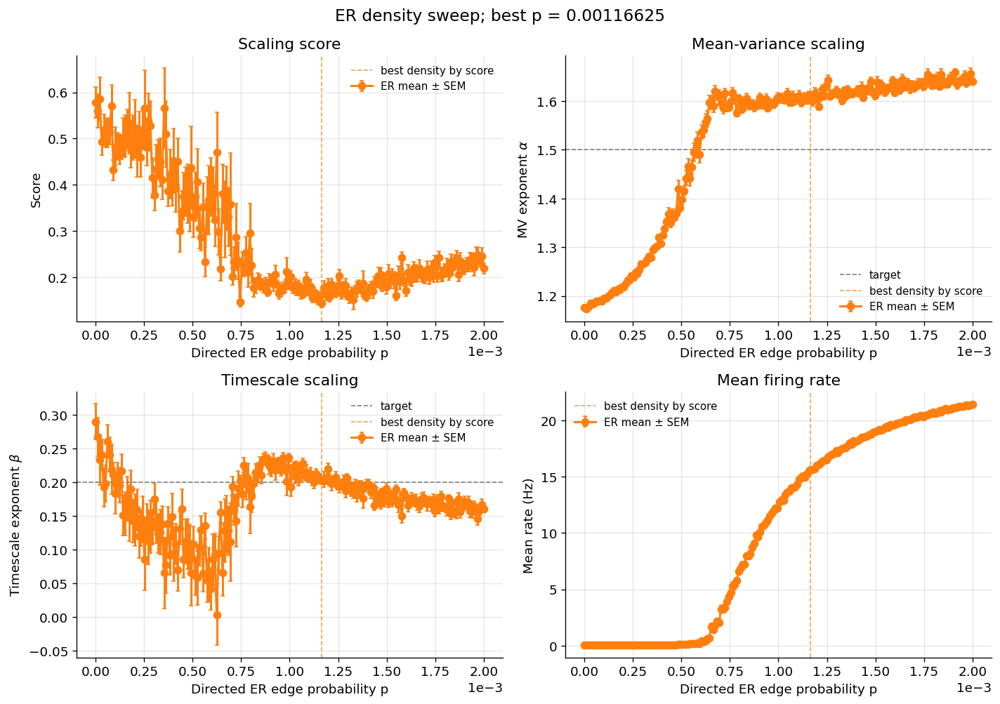

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_density_summary_2x2.png


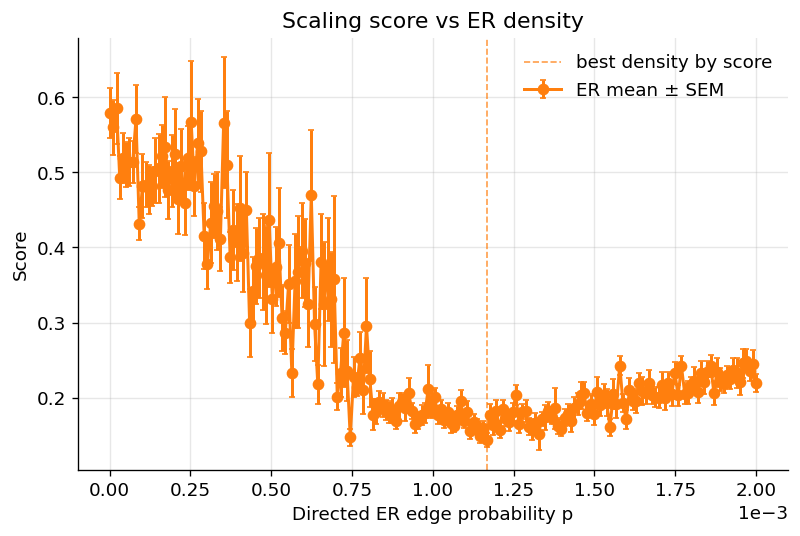

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_score_vs_density.png


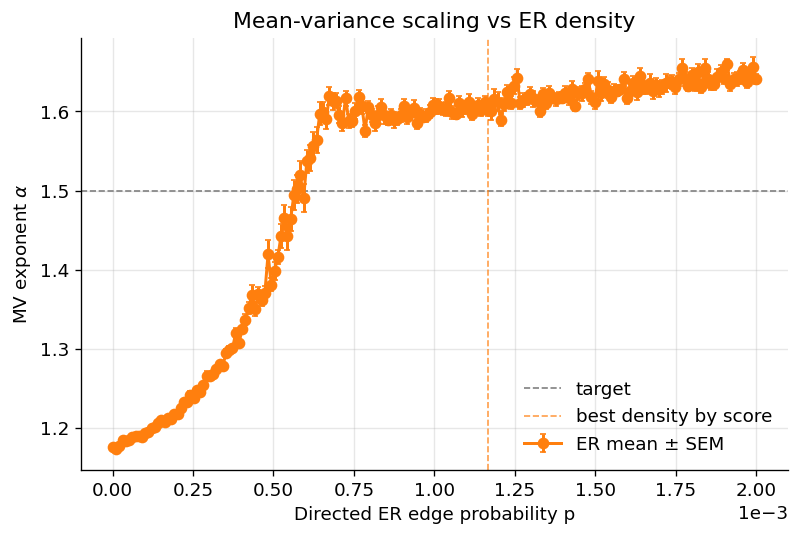

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_MV_alpha_vs_density.png


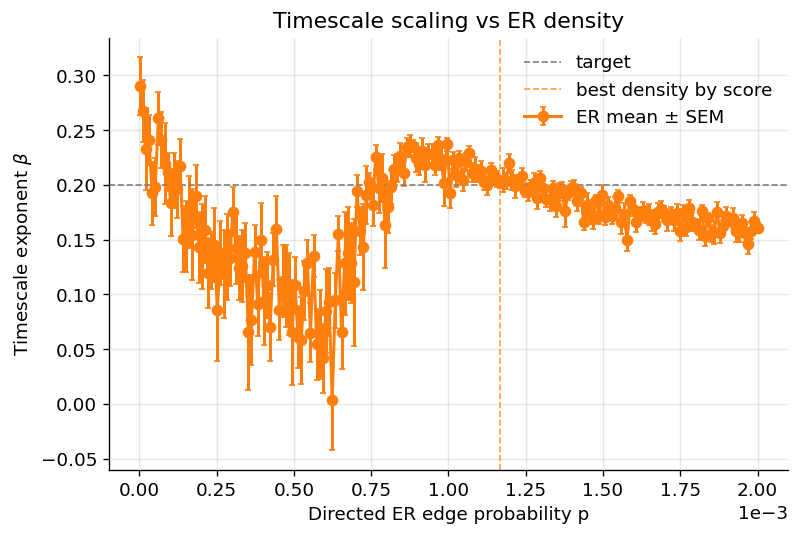

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_TAU_beta_vs_density.png


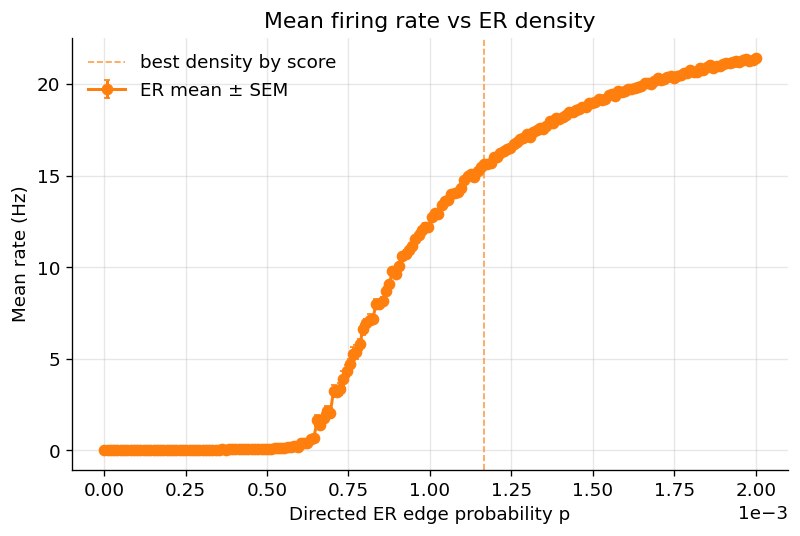

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_mean_rate_hz_vs_density.png


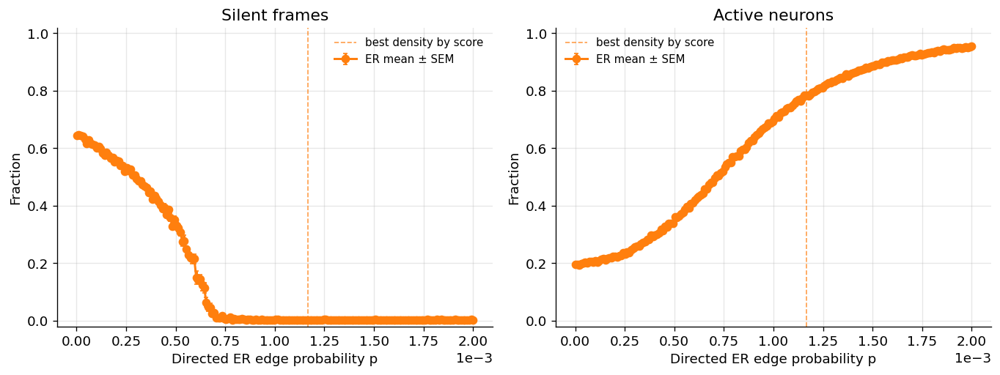

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_activity_diagnostics.png


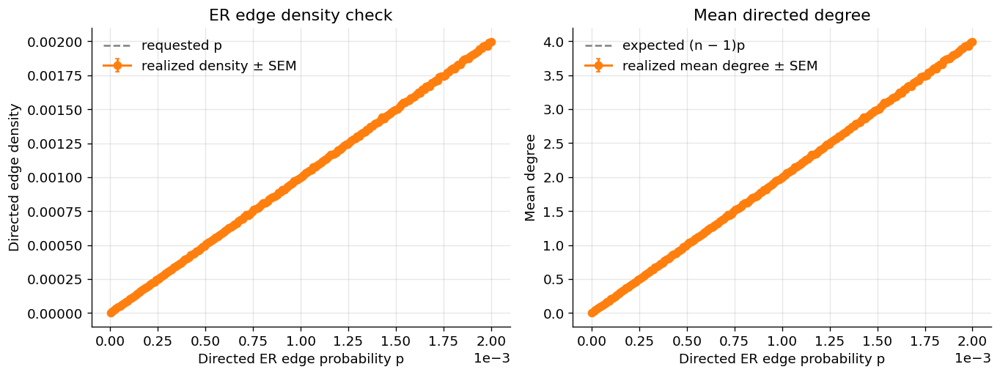

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_density_and_degree_checks.png


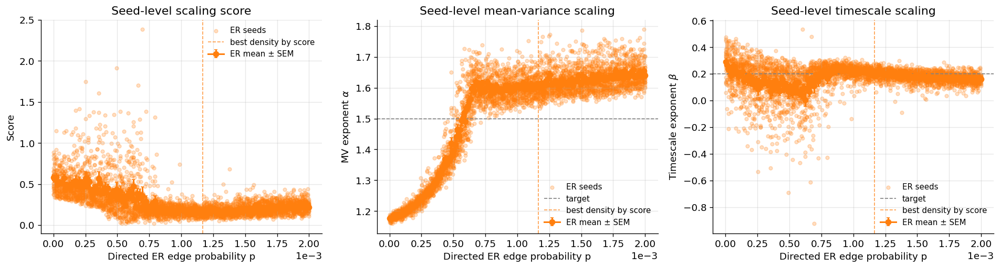

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_seed_scatter_summary.png


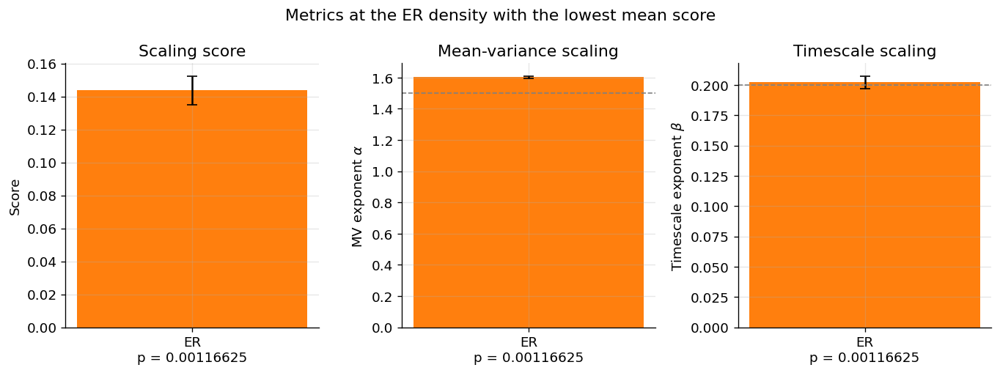

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_best_density_bars.png


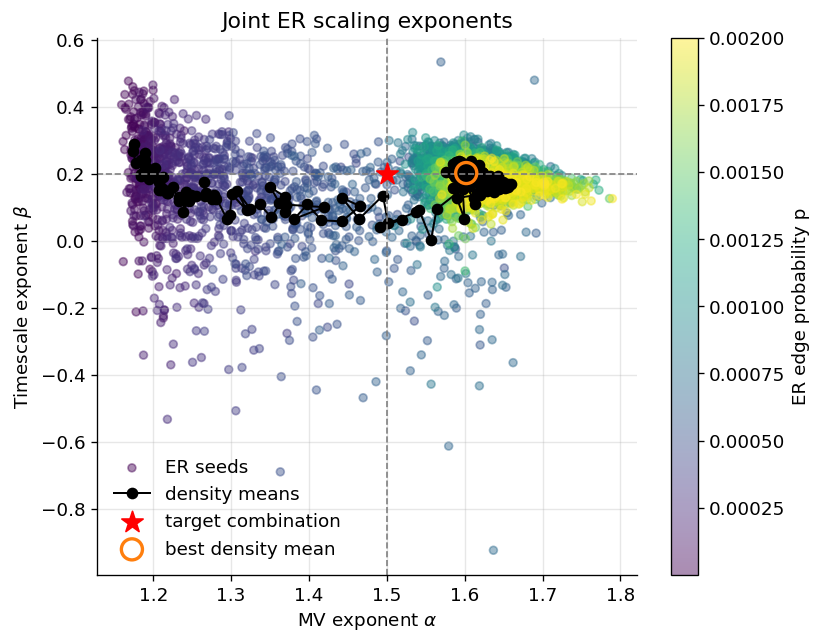

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots/er_joint_exponents.png

Done. Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1/er_density_analysis_plots


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Plot the completed ER density sweep. No simulations required.
# ============================================================
ER_OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "er_density_newpars_ew11p7_iw22p4_pext0_p0to0p01_30densities_20seeds_smooth005_1"
)
FIGDIR = ER_OUTDIR / "er_density_analysis_plots"
TARGET_MV = 1.50
TARGET_TAU = 0.20
COLOR = "tab:orange"
SHOW = True  # Set False for a non-interactive batch run.


def load_numeric(path):
    df = pd.read_csv(path)
    for column in df.columns:
        if column != "condition":
            df[column] = pd.to_numeric(df[column], errors="coerce")
    return df.replace([np.inf, -np.inf], np.nan)


def finish(fig, name):
    fig.tight_layout()
    path = FIGDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    if SHOW:
        plt.show()
    plt.close(fig)
    print("Saved:", path)


def decorate(ax, best_density=None, density_axis=True):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
    if density_axis:
        ax.set_xlabel("Directed ER edge probability p")
        ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 3))
        if best_density is not None:
            ax.axvline(best_density, linestyle="--", linewidth=1,
                       color=COLOR, alpha=0.75, label="best density by score")


def summary_curve(ax, summary, column, sem_column, label="ER mean ± SEM"):
    errors = (summary[sem_column].fillna(0).to_numpy(float)
              if sem_column in summary else None)
    # Zero here only suppresses an undefined error bar; CSV SEM stays NaN.
    ax.errorbar(summary["density"], summary[column], yerr=errors,
                marker="o", linewidth=1.8, capsize=2, color=COLOR, label=label)


def main():
    FIGDIR.mkdir(parents=True, exist_ok=True)
    summary = load_numeric(ER_OUTDIR / "er_density_summary.csv")
    exp = load_numeric(ER_OUTDIR / "er_density_seed_exponents.csv")
    summary = summary.sort_values("density").reset_index(drop=True)
    exp = exp.sort_values(["density", "seed_idx"]).reset_index(drop=True)
    required_summary = {"density", "score_mean", "MV_alpha_mean", "TAU_beta_mean",
                        "mean_rate_hz", "frac_silent_frames", "frac_active_neurons"}
    required_exp = {"density", "seed_idx", "score", "MV_alpha", "TAU_beta"}
    for df, required, name in ((summary, required_summary, "summary"),
                               (exp, required_exp, "seed exponents")):
        missing = required - set(df.columns)
        if missing:
            raise ValueError(f"Missing columns in {name}: {sorted(missing)}")
    print("Loaded ER:", ER_OUTDIR)
    print("Density count:", summary["density"].nunique())
    print("Seed rows:", len(exp))

    valid = summary["score_mean"].notna() & summary["density"].notna()
    best = summary.loc[summary.loc[valid, "score_mean"].idxmin()].copy() if valid.any() else None
    best_density = float(best["density"]) if best is not None else None
    if best is not None:
        best.to_frame().T.to_csv(FIGDIR / "er_best_density_by_score.csv", index=False)
        print("\nBest ER density by mean seed-level score:")
        print(best.drop(labels=["condition"], errors="ignore").round(6).to_string())
    else:
        print("\nNo finite scores; plotting available metrics without a best-density marker.")

    plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                         "axes.spines.right": False, "figure.dpi": 120})
    specs = [
        ("score", "score_mean", "score_sem", "Scaling score", "Score", None),
        ("MV_alpha", "MV_alpha_mean", "MV_alpha_sem", "Mean-variance scaling",
         r"MV exponent $\alpha$", TARGET_MV),
        ("TAU_beta", "TAU_beta_mean", "TAU_beta_sem", "Timescale scaling",
         r"Timescale exponent $\beta$", TARGET_TAU),
        ("mean_rate_hz", "mean_rate_hz", "mean_rate_hz_sem", "Mean firing rate",
         "Mean rate (Hz)", None),
    ]

    # 1. Main 2x2 summary.
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
    for ax, (_, mean, error, title, ylabel, target) in zip(axes.ravel(), specs):
        summary_curve(ax, summary, mean, error)
        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1, color="grey", label="target")
        decorate(ax, best_density)
        ax.set(title=title, ylabel=ylabel)
        ax.legend(frameon=False, fontsize=9)
    title = "ER density sweep"
    if best_density is not None:
        title += f"; best p = {best_density:.6g}"
    fig.suptitle(title, fontsize=14)
    finish(fig, "er_density_summary_2x2.png")

    # 2. Separate clean plots.
    for raw, mean, error, title, ylabel, target in specs:
        fig, ax = plt.subplots(figsize=(6.8, 4.6))
        summary_curve(ax, summary, mean, error)
        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1, color="grey", label="target")
        decorate(ax, best_density)
        ax.set(title=title + " vs ER density", ylabel=ylabel)
        ax.legend(frameon=False)
        finish(fig, f"er_{raw}_vs_density.png")

    # 3. Activity diagnostics.
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    for ax, column, title in zip(axes, ["frac_silent_frames", "frac_active_neurons"],
                               ["Silent frames", "Active neurons"]):
        summary_curve(ax, summary, column, column + "_sem")
        decorate(ax, best_density)
        ax.set(title=title, ylabel="Fraction", ylim=(-0.02, 1.02))
        ax.legend(frameon=False, fontsize=9)
    finish(fig, "er_activity_diagnostics.png")

    # 4. Requested vs realized density, and mean directed degree.
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    ax = axes[0]
    ax.plot(summary["density"], summary["density"], linestyle="--",
            color="grey", label="requested p")
    if "edge_density_er_mean" in summary:
        summary_curve(ax, summary, "edge_density_er_mean", "edge_density_er_sem",
                      "realized density ± SEM")
    ax.set(title="ER edge density check", ylabel="Directed edge density")
    decorate(ax)
    ax.legend(frameon=False)
    ax = axes[1]
    if "mean_out_degree_er_mean" in summary:
        summary_curve(ax, summary, "mean_out_degree_er_mean", "mean_out_degree_er_sem",
                      "realized mean degree ± SEM")
    if "n_neurons" in exp and exp["n_neurons"].nunique() == 1:
        n = float(exp["n_neurons"].dropna().iloc[0])
        ax.plot(summary["density"], (n - 1) * summary["density"], linestyle="--",
                color="grey", label="expected (n − 1)p")
    ax.set(title="Mean directed degree", ylabel="Mean degree")
    decorate(ax)
    ax.legend(frameon=False)
    finish(fig, "er_density_and_degree_checks.png")

    # 5. Seed-level scatter with mean curves.
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for ax, (raw, mean, error, title, ylabel, target) in zip(axes, specs[:3]):
        ax.scatter(exp["density"], exp[raw], alpha=0.25, s=16, color=COLOR, label="ER seeds")
        summary_curve(ax, summary, mean, error)
        if target is not None:
            ax.axhline(target, linestyle="--", linewidth=1, color="grey", label="target")
        decorate(ax, best_density)
        ax.set(title="Seed-level " + title.lower(), ylabel=ylabel)
        ax.legend(frameon=False, fontsize=9)
    finish(fig, "er_seed_scatter_summary.png")

    # 6. Score and exponents at the SAME best density.
    if best is not None:
        fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.3))
        for ax, (_, mean, error, title, ylabel, target) in zip(axes, specs[:3]):
            value = float(best[mean])
            uncertainty = float(best.get(error, np.nan))
            if np.isfinite(value):
                ax.bar([0], [value], yerr=[uncertainty] if np.isfinite(uncertainty) else None,
                       color=COLOR, capsize=4, width=0.55)
            if target is not None:
                ax.axhline(target, linestyle="--", linewidth=1, color="grey", label="target")
            ax.set_xticks([0])
            ax.set_xticklabels([f"ER\np = {best_density:.6g}"])
            ax.set(title=title, ylabel=ylabel)
            decorate(ax, density_axis=False)
        fig.suptitle("Metrics at the ER density with the lowest mean score")
        finish(fig, "er_best_density_bars.png")

    # 7. Joint exponents: check both targets together.
    joint = exp.dropna(subset=["MV_alpha", "TAU_beta", "density"])
    fig, ax = plt.subplots(figsize=(7, 5.5))
    if len(joint):
        points = ax.scatter(joint["MV_alpha"], joint["TAU_beta"], c=joint["density"],
                            cmap="viridis", alpha=0.45, s=22, label="ER seeds")
        fig.colorbar(points, ax=ax, label="ER edge probability p")
    means = summary.dropna(subset=["MV_alpha_mean", "TAU_beta_mean"])
    ax.plot(means["MV_alpha_mean"], means["TAU_beta_mean"], marker="o",
            color="black", linewidth=1.2, label="density means")
    ax.scatter([TARGET_MV], [TARGET_TAU], marker="*", color="red", s=180,
               label="target combination", zorder=5)
    if best is not None:
        ax.scatter([best["MV_alpha_mean"]], [best["TAU_beta_mean"]], facecolors="none",
                   edgecolors=COLOR, linewidths=2, s=160, label="best density mean", zorder=6)
    ax.axvline(TARGET_MV, linestyle="--", linewidth=1, color="grey")
    ax.axhline(TARGET_TAU, linestyle="--", linewidth=1, color="grey")
    ax.set(xlabel=r"MV exponent $\alpha$", ylabel=r"Timescale exponent $\beta$",
           title="Joint ER scaling exponents")
    decorate(ax, density_axis=False)
    ax.legend(frameon=False)
    finish(fig, "er_joint_exponents.png")
    print("\nDone. Saved plots to:", FIGDIR)


if __name__ == "__main__":
    main()


Pass 1: finding trial counts and shared bin bounds...
 density  n_trials  n_extinct  frac_extinct  frac_not_extinct_at_cutoff
0.000100    500000     500000      1.000000                    0.000000
0.000256    500000     500000      1.000000                    0.000000
0.000411    500000     500000      1.000000                    0.000000
0.000567    500000     499989      0.999978                    0.000022
0.000722    500000     422767      0.845534                    0.154466
0.000878    500000     272144      0.544288                    0.455712
0.001033    500000     182492      0.364984                    0.635016
0.001189    500000     128605      0.257210                    0.742790
0.001344    500000      92385      0.184770                    0.815230
0.001500    500000      66488      0.132976                    0.867024

Number of densities: 10
DT: 0.01
Cutoff (s): 10.0

Pass 2: calculating extinct-only histograms...


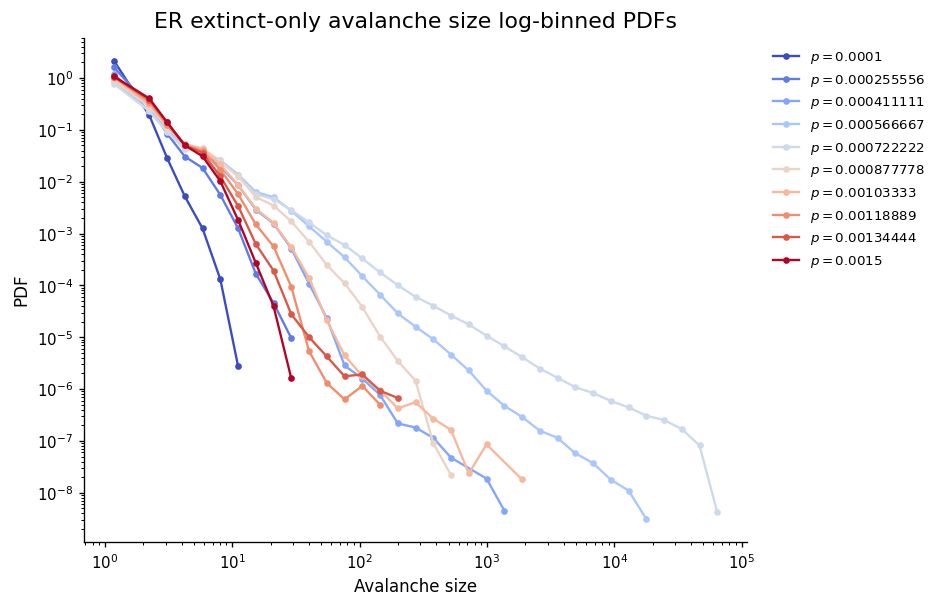

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_2/avalanche_logbinned_pdf_plots_extinct_only/er_avalanche_size_logbinned_pdf_extinct_only.png


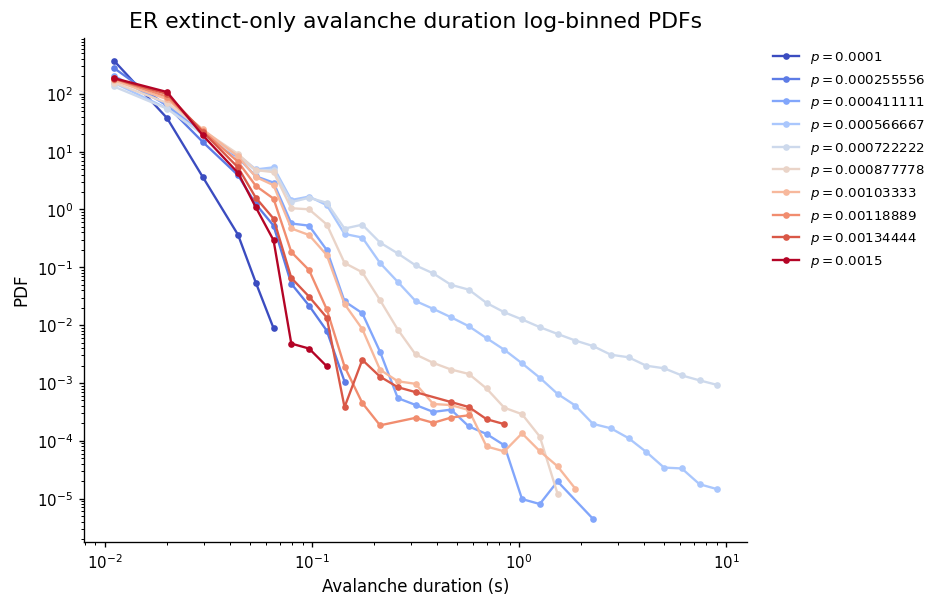

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_2/avalanche_logbinned_pdf_plots_extinct_only/er_avalanche_duration_logbinned_pdf_extinct_only.png

Done. Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_2/avalanche_logbinned_pdf_plots_extinct_only


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Settings: completed ER avalanche run
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_"
    "3densities_50seeds_10000avals_max1000_2"
)

# Folder name retains "3densities", but your run scanned 10.
TRIALS_PATH = OUTDIR / "avalanche_trials_density_sweep.csv"

FIGDIR = OUTDIR / "avalanche_logbinned_pdf_plots_extinct_only"
FIGDIR.mkdir(parents=True, exist_ok=True)

N_BINS = 35
CHUNKSIZE = 250_000

USECOLS = [
    "density", "size", "lifetime_s",
    "extinct", "dt", "cutoff_s",
]

# ============================================================
# Helpers
# ============================================================

def read_chunks():
    for chunk in pd.read_csv(
        TRIALS_PATH,
        usecols=USECOLS,
        chunksize=CHUNKSIZE,
    ):
        for column in ["density", "size", "lifetime_s", "dt", "cutoff_s"]:
            chunk[column] = pd.to_numeric(chunk[column], errors="coerce")

        if not pd.api.types.is_bool_dtype(chunk["extinct"]):
            parsed = (
                chunk["extinct"]
                .astype(str)
                .str.strip()
                .str.lower()
                .map({
                    "true": True, "false": False,
                    "1": True, "0": False,
                    "1.0": True, "0.0": False,
                })
            )

            if parsed.isna().any():
                raise ValueError("Unrecognised values in extinct column.")

            chunk["extinct"] = parsed.astype(bool)

        if not np.isfinite(chunk["density"]).all():
            raise ValueError("Missing or invalid density values.")

        yield chunk


def make_log_edges(vmin, vmax):
    if not np.isfinite(vmin) or vmin <= 0:
        raise ValueError("Log-bin lower bound must be positive.")

    if not np.isfinite(vmax):
        raise ValueError("Log-bin upper bound must be finite.")

    if vmax <= vmin:
        vmax = 2.0 * vmin

    edges = np.logspace(
        np.log10(vmin), np.log10(vmax), N_BINS + 1
    )
    edges[0], edges[-1] = vmin, vmax
    return edges


def positive_values(series):
    values = series.to_numpy(dtype=float)
    return values[np.isfinite(values) & (values > 0)]


def histogram_pdf(counts, edges):
    total = counts.sum()

    if total == 0:
        return np.array([]), np.array([])

    centres = np.sqrt(edges[:-1] * edges[1:])
    pdf = counts / (total * np.diff(edges))
    keep = counts > 0

    return centres[keep], pdf[keep]


# ============================================================
# Pass 1: counts and shared bin bounds
# ============================================================

counts_by_density = {}
size_max = 1.0
DT = None
MAX_TIME_S = None

print("Pass 1: finding trial counts and shared bin bounds...")

for chunk in read_chunks():
    if chunk.empty:
        continue

    if DT is None:
        DT = float(chunk["dt"].iloc[0])
        MAX_TIME_S = float(chunk["cutoff_s"].iloc[0])

    if (
        not np.isfinite(DT) or DT <= 0
        or not np.isfinite(MAX_TIME_S) or MAX_TIME_S <= 0
    ):
        raise ValueError("Invalid dt or cutoff_s.")

    if not np.allclose(chunk["dt"], DT):
        raise ValueError("Trials have inconsistent dt values.")

    if not np.allclose(chunk["cutoff_s"], MAX_TIME_S):
        raise ValueError("Trials have inconsistent cutoff_s values.")

    for density, group in chunk.groupby("density", sort=False):
        density = float(density)

        record = counts_by_density.setdefault(
            density, {"n_trials": 0, "n_extinct": 0}
        )
        record["n_trials"] += len(group)
        record["n_extinct"] += int(group["extinct"].sum())

    values = positive_values(chunk.loc[chunk["extinct"], "size"])

    if values.size:
        size_max = max(size_max, float(values.max()))

if not counts_by_density:
    raise ValueError("The trial CSV is empty.")

densities = np.array(sorted(counts_by_density))

count_summary = pd.DataFrame([
    {"density": density, **counts_by_density[density]}
    for density in densities
])

count_summary["frac_extinct"] = (
    count_summary["n_extinct"] / count_summary["n_trials"]
)
count_summary["frac_not_extinct_at_cutoff"] = (
    1.0 - count_summary["frac_extinct"]
)

print(count_summary.to_string(index=False))
print("\nNumber of densities:", len(densities))
print("DT:", DT)
print("Cutoff (s):", MAX_TIME_S)

count_summary.to_csv(
    FIGDIR / "er_avalanche_plot_trial_counts.csv",
    index=False,
)

if count_summary["n_extinct"].sum() == 0:
    raise ValueError("No extinct avalanches available to plot.")

# Use identical bin edges across all densities.
size_edges = make_log_edges(1.0, size_max)
duration_edges = make_log_edges(DT, MAX_TIME_S)

size_counts = {
    density: np.zeros(N_BINS, dtype=np.int64)
    for density in densities
}
duration_counts = {
    density: np.zeros(N_BINS, dtype=np.int64)
    for density in densities
}

# ============================================================
# Pass 2: accumulate extinct-only histograms
# ============================================================

print("\nPass 2: calculating extinct-only histograms...")

for chunk in read_chunks():
    extinct_chunk = chunk.loc[chunk["extinct"]]

    for density, group in extinct_chunk.groupby("density", sort=False):
        density = float(density)

        sizes = positive_values(group["size"])
        durations = positive_values(group["lifetime_s"])

        # Avoid silently dropping positive observations outside the bins.
        if sizes.size and (
            sizes.min() < size_edges[0]
            or sizes.max() > size_edges[-1]
        ):
            raise ValueError("Avalanche sizes fall outside shared bin bounds.")

        if durations.size and (
            durations.min() < duration_edges[0]
            or durations.max() > duration_edges[-1]
        ):
            raise ValueError("Avalanche durations fall outside shared bin bounds.")

        size_counts[density] += np.histogram(
            sizes, bins=size_edges
        )[0]

        duration_counts[density] += np.histogram(
            durations, bins=duration_edges
        )[0]

# ============================================================
# Plot size and duration PDFs
# Each density is normalized separately, conditional on extinction.
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

colors = plt.cm.coolwarm(np.linspace(0, 1, len(densities)))
density_to_color = dict(zip(densities, colors))

plot_specs = [
    (
        size_counts,
        size_edges,
        "Avalanche size",
        "ER extinct-only avalanche size log-binned PDFs",
        "er_avalanche_size_logbinned_pdf_extinct_only.png",
    ),
    (
        duration_counts,
        duration_edges,
        "Avalanche duration (s)",
        "ER extinct-only avalanche duration log-binned PDFs",
        "er_avalanche_duration_logbinned_pdf_extinct_only.png",
    ),
]

for histograms, edges, xlabel, title, filename in plot_specs:
    fig, ax = plt.subplots(figsize=(8, 5.2))

    for density in densities:
        x, pdf = histogram_pdf(histograms[density], edges)

        if x.size == 0:
            print(f"No valid extinct trials to plot at p={density:.6g}")
            continue

        ax.plot(
            x,
            pdf,
            marker="o",
            markersize=3,
            linewidth=1.4,
            color=density_to_color[density],
            label=fr"$p={density:.6g}$",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("PDF")
    ax.set_title(title)

    ax.legend(
        frameon=False,
        fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
    )

    fig.tight_layout()

    save_path = FIGDIR / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

print("\nDone. Saved plots to:", FIGDIR)

Pass 1: finding trial counts and shared bin bounds...
 density  n_trials  n_extinct  frac_extinct  frac_not_extinct_at_cutoff
0.000400    500000     500000      1.000000                    0.000000
0.000444    500000     500000      1.000000                    0.000000
0.000489    500000     500000      1.000000                    0.000000
0.000533    500000     499995      0.999990                    0.000010
0.000578    500000     499853      0.999706                    0.000294
0.000622    500000     497793      0.995586                    0.004414
0.000667    500000     483465      0.966930                    0.033070
0.000711    500000     428571      0.857142                    0.142858
0.000756    500000     385086      0.770172                    0.229828
0.000800    500000     326410      0.652820                    0.347180

Number of densities: 10
DT: 0.01
Cutoff (s): 10.0

Pass 2: calculating extinct-only histograms...


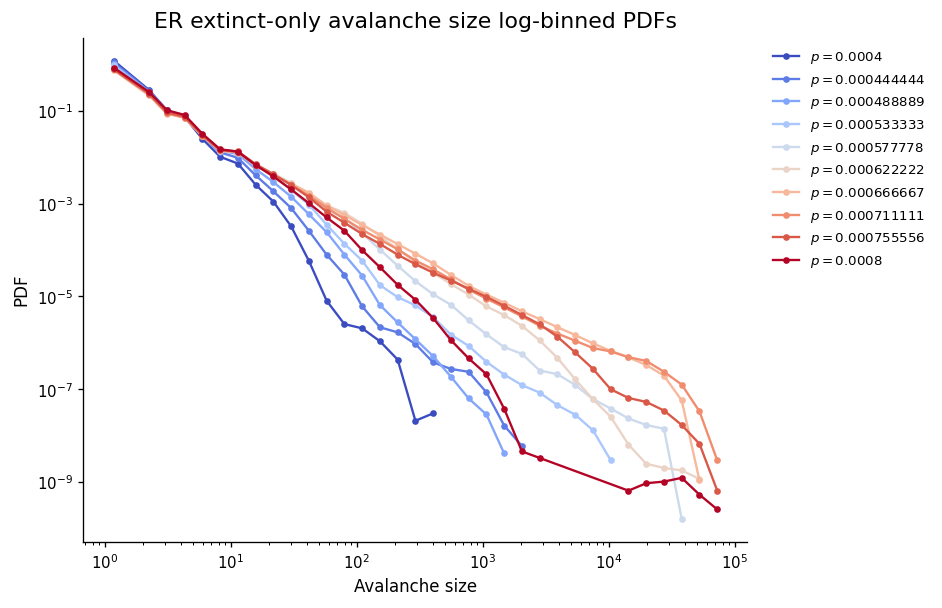

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_3/avalanche_logbinned_pdf_plots_extinct_only/er_avalanche_size_logbinned_pdf_extinct_only.png


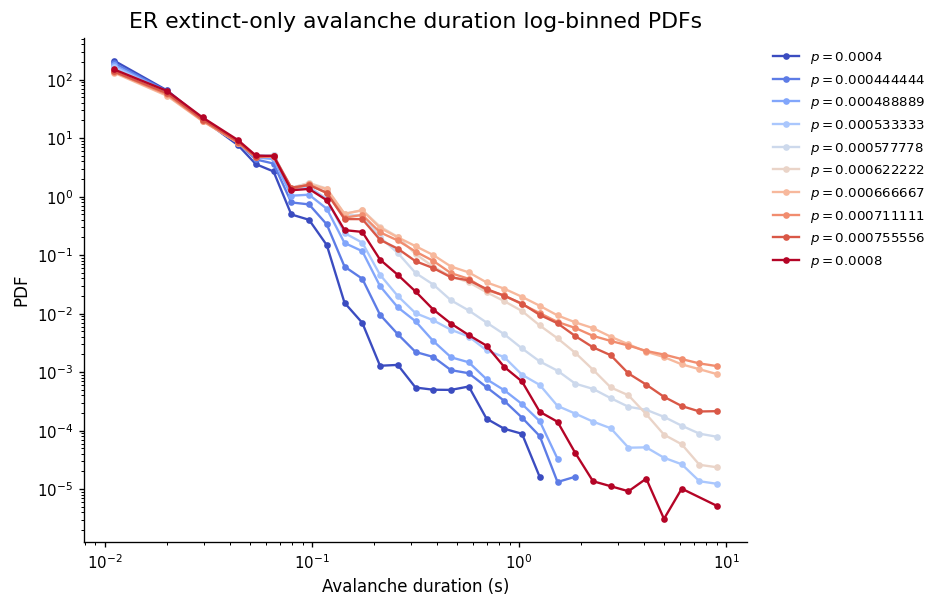

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_3/avalanche_logbinned_pdf_plots_extinct_only/er_avalanche_duration_logbinned_pdf_extinct_only.png

Done. Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_3/avalanche_logbinned_pdf_plots_extinct_only


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Settings: completed ER avalanche run
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_"
    "3densities_50seeds_10000avals_max1000_3"
)

# Folder name retains "3densities", but your run scanned 10.
TRIALS_PATH = OUTDIR / "avalanche_trials_density_sweep.csv"

FIGDIR = OUTDIR / "avalanche_logbinned_pdf_plots_extinct_only"
FIGDIR.mkdir(parents=True, exist_ok=True)

N_BINS = 35
CHUNKSIZE = 250_000

USECOLS = [
    "density", "size", "lifetime_s",
    "extinct", "dt", "cutoff_s",
]

# ============================================================
# Helpers
# ============================================================

def read_chunks():
    for chunk in pd.read_csv(
        TRIALS_PATH,
        usecols=USECOLS,
        chunksize=CHUNKSIZE,
    ):
        for column in ["density", "size", "lifetime_s", "dt", "cutoff_s"]:
            chunk[column] = pd.to_numeric(chunk[column], errors="coerce")

        if not pd.api.types.is_bool_dtype(chunk["extinct"]):
            parsed = (
                chunk["extinct"]
                .astype(str)
                .str.strip()
                .str.lower()
                .map({
                    "true": True, "false": False,
                    "1": True, "0": False,
                    "1.0": True, "0.0": False,
                })
            )

            if parsed.isna().any():
                raise ValueError("Unrecognised values in extinct column.")

            chunk["extinct"] = parsed.astype(bool)

        if not np.isfinite(chunk["density"]).all():
            raise ValueError("Missing or invalid density values.")

        yield chunk


def make_log_edges(vmin, vmax):
    if not np.isfinite(vmin) or vmin <= 0:
        raise ValueError("Log-bin lower bound must be positive.")

    if not np.isfinite(vmax):
        raise ValueError("Log-bin upper bound must be finite.")

    if vmax <= vmin:
        vmax = 2.0 * vmin

    edges = np.logspace(
        np.log10(vmin), np.log10(vmax), N_BINS + 1
    )
    edges[0], edges[-1] = vmin, vmax
    return edges


def positive_values(series):
    values = series.to_numpy(dtype=float)
    return values[np.isfinite(values) & (values > 0)]


def histogram_pdf(counts, edges):
    total = counts.sum()

    if total == 0:
        return np.array([]), np.array([])

    centres = np.sqrt(edges[:-1] * edges[1:])
    pdf = counts / (total * np.diff(edges))
    keep = counts > 0

    return centres[keep], pdf[keep]


# ============================================================
# Pass 1: counts and shared bin bounds
# ============================================================

counts_by_density = {}
size_max = 1.0
DT = None
MAX_TIME_S = None

print("Pass 1: finding trial counts and shared bin bounds...")

for chunk in read_chunks():
    if chunk.empty:
        continue

    if DT is None:
        DT = float(chunk["dt"].iloc[0])
        MAX_TIME_S = float(chunk["cutoff_s"].iloc[0])

    if (
        not np.isfinite(DT) or DT <= 0
        or not np.isfinite(MAX_TIME_S) or MAX_TIME_S <= 0
    ):
        raise ValueError("Invalid dt or cutoff_s.")

    if not np.allclose(chunk["dt"], DT):
        raise ValueError("Trials have inconsistent dt values.")

    if not np.allclose(chunk["cutoff_s"], MAX_TIME_S):
        raise ValueError("Trials have inconsistent cutoff_s values.")

    for density, group in chunk.groupby("density", sort=False):
        density = float(density)

        record = counts_by_density.setdefault(
            density, {"n_trials": 0, "n_extinct": 0}
        )
        record["n_trials"] += len(group)
        record["n_extinct"] += int(group["extinct"].sum())

    values = positive_values(chunk.loc[chunk["extinct"], "size"])

    if values.size:
        size_max = max(size_max, float(values.max()))

if not counts_by_density:
    raise ValueError("The trial CSV is empty.")

densities = np.array(sorted(counts_by_density))

count_summary = pd.DataFrame([
    {"density": density, **counts_by_density[density]}
    for density in densities
])

count_summary["frac_extinct"] = (
    count_summary["n_extinct"] / count_summary["n_trials"]
)
count_summary["frac_not_extinct_at_cutoff"] = (
    1.0 - count_summary["frac_extinct"]
)

print(count_summary.to_string(index=False))
print("\nNumber of densities:", len(densities))
print("DT:", DT)
print("Cutoff (s):", MAX_TIME_S)

count_summary.to_csv(
    FIGDIR / "er_avalanche_plot_trial_counts.csv",
    index=False,
)

if count_summary["n_extinct"].sum() == 0:
    raise ValueError("No extinct avalanches available to plot.")

# Use identical bin edges across all densities.
size_edges = make_log_edges(1.0, size_max)
duration_edges = make_log_edges(DT, MAX_TIME_S)

size_counts = {
    density: np.zeros(N_BINS, dtype=np.int64)
    for density in densities
}
duration_counts = {
    density: np.zeros(N_BINS, dtype=np.int64)
    for density in densities
}

# ============================================================
# Pass 2: accumulate extinct-only histograms
# ============================================================

print("\nPass 2: calculating extinct-only histograms...")

for chunk in read_chunks():
    extinct_chunk = chunk.loc[chunk["extinct"]]

    for density, group in extinct_chunk.groupby("density", sort=False):
        density = float(density)

        sizes = positive_values(group["size"])
        durations = positive_values(group["lifetime_s"])

        # Avoid silently dropping positive observations outside the bins.
        if sizes.size and (
            sizes.min() < size_edges[0]
            or sizes.max() > size_edges[-1]
        ):
            raise ValueError("Avalanche sizes fall outside shared bin bounds.")

        if durations.size and (
            durations.min() < duration_edges[0]
            or durations.max() > duration_edges[-1]
        ):
            raise ValueError("Avalanche durations fall outside shared bin bounds.")

        size_counts[density] += np.histogram(
            sizes, bins=size_edges
        )[0]

        duration_counts[density] += np.histogram(
            durations, bins=duration_edges
        )[0]

# ============================================================
# Plot size and duration PDFs
# Each density is normalized separately, conditional on extinction.
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

colors = plt.cm.coolwarm(np.linspace(0, 1, len(densities)))
density_to_color = dict(zip(densities, colors))

plot_specs = [
    (
        size_counts,
        size_edges,
        "Avalanche size",
        "ER extinct-only avalanche size log-binned PDFs",
        "er_avalanche_size_logbinned_pdf_extinct_only.png",
    ),
    (
        duration_counts,
        duration_edges,
        "Avalanche duration (s)",
        "ER extinct-only avalanche duration log-binned PDFs",
        "er_avalanche_duration_logbinned_pdf_extinct_only.png",
    ),
]

for histograms, edges, xlabel, title, filename in plot_specs:
    fig, ax = plt.subplots(figsize=(8, 5.2))

    for density in densities:
        x, pdf = histogram_pdf(histograms[density], edges)

        if x.size == 0:
            print(f"No valid extinct trials to plot at p={density:.6g}")
            continue

        ax.plot(
            x,
            pdf,
            marker="o",
            markersize=3,
            linewidth=1.4,
            color=density_to_color[density],
            label=fr"$p={density:.6g}$",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("PDF")
    ax.set_title(title)

    ax.legend(
        frameon=False,
        fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
    )

    fig.tight_layout()

    save_path = FIGDIR / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

print("\nDone. Saved plots to:", FIGDIR)

Pass 1: finding trial counts and shared bin bounds...
 density  n_trials  n_extinct  frac_extinct  frac_not_extinct_at_cutoff
0.000400    500000     500000      1.000000                    0.000000
0.000412    500000     500000      1.000000                    0.000000
0.000424    500000     500000      1.000000                    0.000000
0.000437    500000     500000      1.000000                    0.000000
0.000449    500000     500000      1.000000                    0.000000
0.000461    500000     500000      1.000000                    0.000000
0.000473    500000     500000      1.000000                    0.000000
0.000486    500000     500000      1.000000                    0.000000
0.000498    500000     500000      1.000000                    0.000000
0.000510    500000     500000      1.000000                    0.000000
0.000522    500000     499911      0.999822                    0.000178
0.000535    500000     500000      1.000000                    0.000000
0.000547  

/tmp/ipykernel_1648054/1490295577.py:291: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


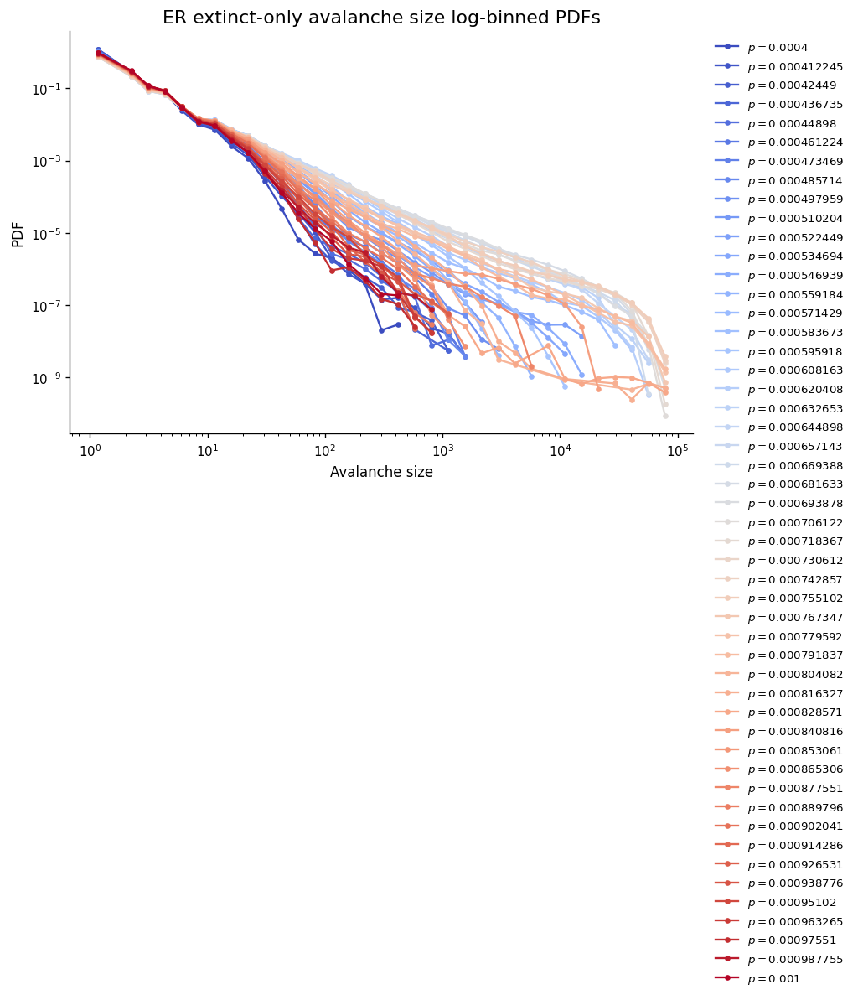

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_4/avalanche_logbinned_pdf_plots_extinct_only/er_avalanche_size_logbinned_pdf_extinct_only.png


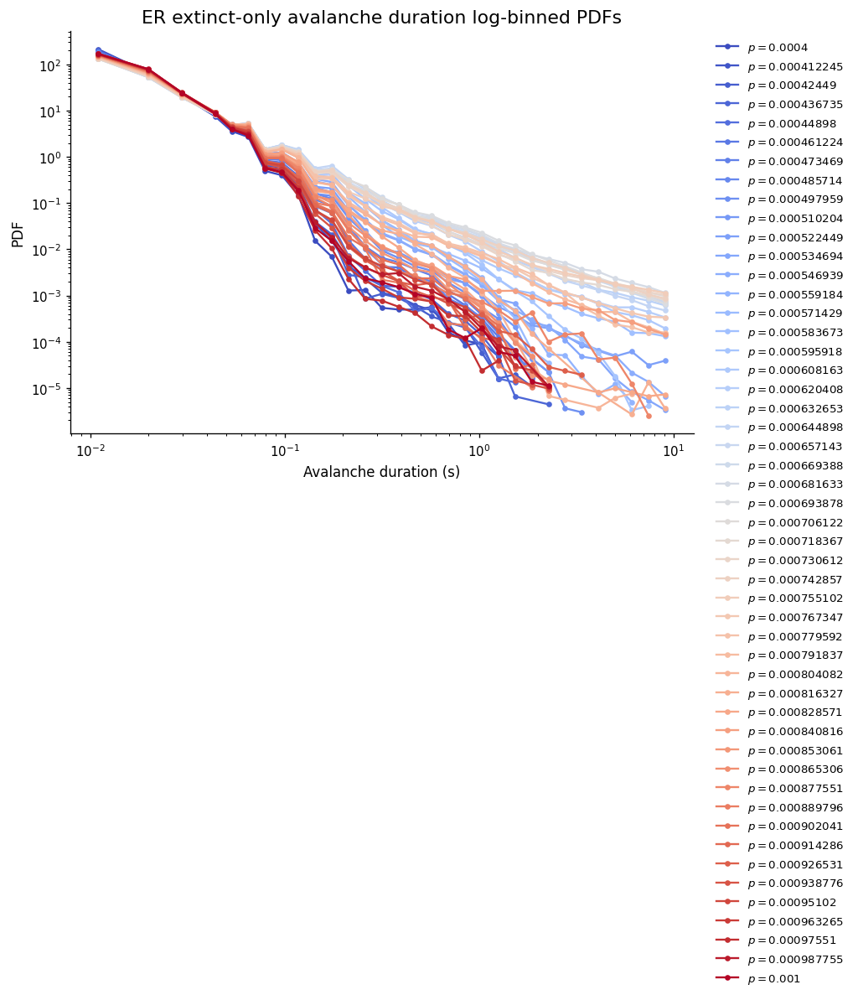

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_4/avalanche_logbinned_pdf_plots_extinct_only/er_avalanche_duration_logbinned_pdf_extinct_only.png

Done. Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_3densities_50seeds_10000avals_max1000_4/avalanche_logbinned_pdf_plots_extinct_only


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Settings: completed ER avalanche run
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_"
    "3densities_50seeds_10000avals_max1000_4"
)

# Folder name retains "3densities", but your run scanned 10.
TRIALS_PATH = OUTDIR / "avalanche_trials_density_sweep.csv"

FIGDIR = OUTDIR / "avalanche_logbinned_pdf_plots_extinct_only"
FIGDIR.mkdir(parents=True, exist_ok=True)

N_BINS = 35
CHUNKSIZE = 250_000

USECOLS = [
    "density", "size", "lifetime_s",
    "extinct", "dt", "cutoff_s",
]

# ============================================================
# Helpers
# ============================================================

def read_chunks():
    for chunk in pd.read_csv(
        TRIALS_PATH,
        usecols=USECOLS,
        chunksize=CHUNKSIZE,
    ):
        for column in ["density", "size", "lifetime_s", "dt", "cutoff_s"]:
            chunk[column] = pd.to_numeric(chunk[column], errors="coerce")

        if not pd.api.types.is_bool_dtype(chunk["extinct"]):
            parsed = (
                chunk["extinct"]
                .astype(str)
                .str.strip()
                .str.lower()
                .map({
                    "true": True, "false": False,
                    "1": True, "0": False,
                    "1.0": True, "0.0": False,
                })
            )

            if parsed.isna().any():
                raise ValueError("Unrecognised values in extinct column.")

            chunk["extinct"] = parsed.astype(bool)

        if not np.isfinite(chunk["density"]).all():
            raise ValueError("Missing or invalid density values.")

        yield chunk


def make_log_edges(vmin, vmax):
    if not np.isfinite(vmin) or vmin <= 0:
        raise ValueError("Log-bin lower bound must be positive.")

    if not np.isfinite(vmax):
        raise ValueError("Log-bin upper bound must be finite.")

    if vmax <= vmin:
        vmax = 2.0 * vmin

    edges = np.logspace(
        np.log10(vmin), np.log10(vmax), N_BINS + 1
    )
    edges[0], edges[-1] = vmin, vmax
    return edges


def positive_values(series):
    values = series.to_numpy(dtype=float)
    return values[np.isfinite(values) & (values > 0)]


def histogram_pdf(counts, edges):
    total = counts.sum()

    if total == 0:
        return np.array([]), np.array([])

    centres = np.sqrt(edges[:-1] * edges[1:])
    pdf = counts / (total * np.diff(edges))
    keep = counts > 0

    return centres[keep], pdf[keep]


# ============================================================
# Pass 1: counts and shared bin bounds
# ============================================================

counts_by_density = {}
size_max = 1.0
DT = None
MAX_TIME_S = None

print("Pass 1: finding trial counts and shared bin bounds...")

for chunk in read_chunks():
    if chunk.empty:
        continue

    if DT is None:
        DT = float(chunk["dt"].iloc[0])
        MAX_TIME_S = float(chunk["cutoff_s"].iloc[0])

    if (
        not np.isfinite(DT) or DT <= 0
        or not np.isfinite(MAX_TIME_S) or MAX_TIME_S <= 0
    ):
        raise ValueError("Invalid dt or cutoff_s.")

    if not np.allclose(chunk["dt"], DT):
        raise ValueError("Trials have inconsistent dt values.")

    if not np.allclose(chunk["cutoff_s"], MAX_TIME_S):
        raise ValueError("Trials have inconsistent cutoff_s values.")

    for density, group in chunk.groupby("density", sort=False):
        density = float(density)

        record = counts_by_density.setdefault(
            density, {"n_trials": 0, "n_extinct": 0}
        )
        record["n_trials"] += len(group)
        record["n_extinct"] += int(group["extinct"].sum())

    values = positive_values(chunk.loc[chunk["extinct"], "size"])

    if values.size:
        size_max = max(size_max, float(values.max()))

if not counts_by_density:
    raise ValueError("The trial CSV is empty.")

densities = np.array(sorted(counts_by_density))

count_summary = pd.DataFrame([
    {"density": density, **counts_by_density[density]}
    for density in densities
])

count_summary["frac_extinct"] = (
    count_summary["n_extinct"] / count_summary["n_trials"]
)
count_summary["frac_not_extinct_at_cutoff"] = (
    1.0 - count_summary["frac_extinct"]
)

print(count_summary.to_string(index=False))
print("\nNumber of densities:", len(densities))
print("DT:", DT)
print("Cutoff (s):", MAX_TIME_S)

count_summary.to_csv(
    FIGDIR / "er_avalanche_plot_trial_counts.csv",
    index=False,
)

if count_summary["n_extinct"].sum() == 0:
    raise ValueError("No extinct avalanches available to plot.")

# Use identical bin edges across all densities.
size_edges = make_log_edges(1.0, size_max)
duration_edges = make_log_edges(DT, MAX_TIME_S)

size_counts = {
    density: np.zeros(N_BINS, dtype=np.int64)
    for density in densities
}
duration_counts = {
    density: np.zeros(N_BINS, dtype=np.int64)
    for density in densities
}

# ============================================================
# Pass 2: accumulate extinct-only histograms
# ============================================================

print("\nPass 2: calculating extinct-only histograms...")

for chunk in read_chunks():
    extinct_chunk = chunk.loc[chunk["extinct"]]

    for density, group in extinct_chunk.groupby("density", sort=False):
        density = float(density)

        sizes = positive_values(group["size"])
        durations = positive_values(group["lifetime_s"])

        # Avoid silently dropping positive observations outside the bins.
        if sizes.size and (
            sizes.min() < size_edges[0]
            or sizes.max() > size_edges[-1]
        ):
            raise ValueError("Avalanche sizes fall outside shared bin bounds.")

        if durations.size and (
            durations.min() < duration_edges[0]
            or durations.max() > duration_edges[-1]
        ):
            raise ValueError("Avalanche durations fall outside shared bin bounds.")

        size_counts[density] += np.histogram(
            sizes, bins=size_edges
        )[0]

        duration_counts[density] += np.histogram(
            durations, bins=duration_edges
        )[0]

# ============================================================
# Plot size and duration PDFs
# Each density is normalized separately, conditional on extinction.
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

colors = plt.cm.coolwarm(np.linspace(0, 1, len(densities)))
density_to_color = dict(zip(densities, colors))

plot_specs = [
    (
        size_counts,
        size_edges,
        "Avalanche size",
        "ER extinct-only avalanche size log-binned PDFs",
        "er_avalanche_size_logbinned_pdf_extinct_only.png",
    ),
    (
        duration_counts,
        duration_edges,
        "Avalanche duration (s)",
        "ER extinct-only avalanche duration log-binned PDFs",
        "er_avalanche_duration_logbinned_pdf_extinct_only.png",
    ),
]

for histograms, edges, xlabel, title, filename in plot_specs:
    fig, ax = plt.subplots(figsize=(8, 5.2))

    for density in densities:
        x, pdf = histogram_pdf(histograms[density], edges)

        if x.size == 0:
            print(f"No valid extinct trials to plot at p={density:.6g}")
            continue

        ax.plot(
            x,
            pdf,
            marker="o",
            markersize=3,
            linewidth=1.4,
            color=density_to_color[density],
            label=fr"$p={density:.6g}$",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("PDF")
    ax.set_title(title)

    ax.legend(
        frameon=False,
        fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
    )

    fig.tight_layout()

    save_path = FIGDIR / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

print("\nDone. Saved plots to:", FIGDIR)

ER normalized LLR — 30 workers:  23%|##2       | 1140/5000 [00:00<?, ?fit/s]

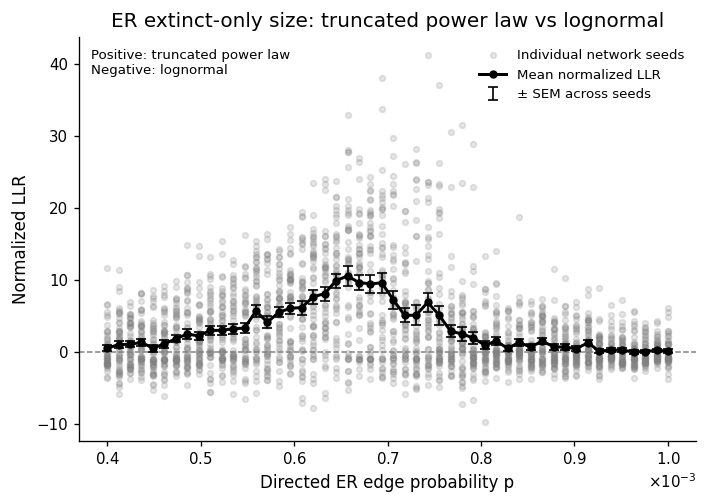

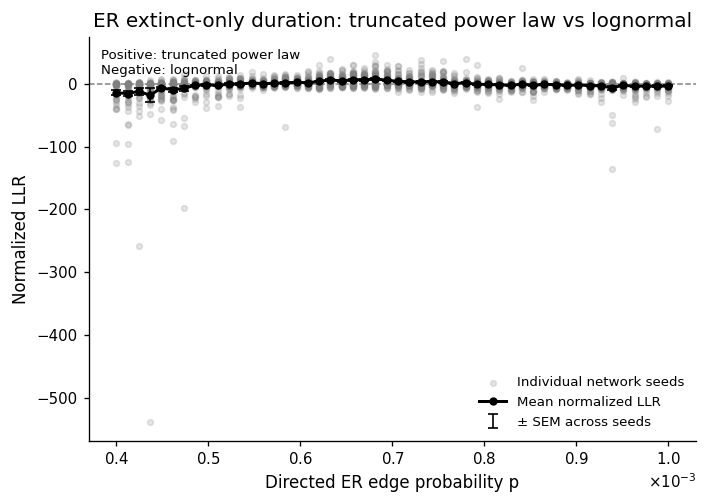

In [21]:
"""
Parallel ER normalized avalanche LLR per network seed.

30 worker processes; one numerical thread per worker.
Same fitting settings and outputs as the sequential version.
Progress bar only; completed fits are checkpointed and can be resumed.

Requires:
    numpy pandas matplotlib powerlaw tqdm threadpoolctl
"""

import os

# Set before importing numerical libraries.
for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[variable] = "1"

from pathlib import Path
import contextlib
import importlib.metadata
import io
import json
import multiprocessing as mp
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import powerlaw
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits


# ============================================================
# Settings
# ============================================================

N_WORKERS = 30

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "er_avalanche_ew11p7_iw22p4_N2000_p0p0001_0p001_0p01_"
    "3densities_50seeds_10000avals_max1000_4"
)

SOURCE = OUTDIR / "avalanche_trials_density_sweep.csv"
SAVEDIR = OUTDIR / "truncated_powerlaw_vs_lognormal_normalized_by_seed"

SIZE_XMIN = 10
DURATION_XMIN = 0.1
MIN_VALUES = 20

RESUME = True
SHOW_PLOTS = True
SHOW_SEED_SCATTER = True

METRICS = [
    ("size", "size", True, SIZE_XMIN),
    ("duration", "lifetime_s", False, DURATION_XMIN),
]

RESULTS_PATH = SAVEDIR / "normalized_seed_fits.csv"
SUMMARY_PATH = SAVEDIR / "normalized_llr_summary_by_density.csv"
CONFIG_PATH = SAVEDIR / "fit_config.json"


# ============================================================
# Helpers
# ============================================================

def bool_column(series):
    if pd.api.types.is_bool_dtype(series):
        if series.isna().any():
            raise ValueError("Missing values in extinct column.")
        return series.astype(bool)

    mapped = (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True, "false": False,
            "1": True, "0": False,
            "1.0": True, "0.0": False,
        })
    )

    if mapped.isna().any():
        raise ValueError("Unexpected or missing values in extinct column.")

    return mapped.astype(bool)


def atomic_csv(frame, path):
    temporary = path.with_suffix(".tmp.csv")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        frame.to_csv(temporary, index=False)

    temporary.replace(path)


def result_key(density, seed, metric):
    return float(density), int(seed), str(metric)


def fit_one(values, discrete, xmin, min_values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]

    out = {
        "status": "too_few_values",
        "n_values": int(len(values)),
        "n_tail": int(np.sum(values >= xmin)),
        "R_normalized": np.nan,
        "p_truncated_vs_lognormal": np.nan,
        "alpha_truncated": np.nan,
        "lambda_truncated": np.nan,
        "mu_lognormal": np.nan,
        "sigma_lognormal": np.nan,
        "warnings": "",
    }

    if len(values) < min_values:
        return out

    if out["n_tail"] < 2:
        out["status"] = "insufficient_tail_for_normalized_llr"
        return out

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        # Each worker has its own stdout/stderr.
        with contextlib.redirect_stdout(io.StringIO()):
            with contextlib.redirect_stderr(io.StringIO()):
                fit = powerlaw.Fit(
                    values,
                    discrete=discrete,
                    xmin=xmin,
                    estimate_discrete=discrete,
                    verbose=False,
                )

                R, p = fit.distribution_compare(
                    "truncated_power_law",
                    "lognormal",
                    normalized_ratio=True,
                )

                out.update({
                    "status": "ok" if np.isfinite(R) else "nonfinite_llr",
                    "n_tail": int(np.sum(values >= fit.xmin)),
                    "R_normalized": float(R),
                    "p_truncated_vs_lognormal": float(p),
                    "alpha_truncated": float(fit.truncated_power_law.alpha),
                    "lambda_truncated": float(fit.truncated_power_law.Lambda),
                    "mu_lognormal": float(fit.lognormal.mu),
                    "sigma_lognormal": float(fit.lognormal.sigma),
                })

        out["warnings"] = " | ".join(
            dict.fromkeys(str(w.message) for w in caught)
        )

    return out


def run_fit_job(job):
    """Worker: fit one metric for one network. No file writes."""
    values = job["values"]

    try:
        with threadpool_limits(limits=1):
            result = fit_one(
                values,
                discrete=job["discrete"],
                xmin=job["xmin"],
                min_values=job["min_values"],
            )

    except Exception as exc:
        finite_positive = values[
            np.isfinite(values) & (values > 0)
        ]

        result = {
            "status": "error",
            "n_values": int(len(finite_positive)),
            "n_tail": int(np.sum(finite_positive >= job["xmin"])),
            "R_normalized": np.nan,
            "p_truncated_vs_lognormal": np.nan,
            "alpha_truncated": np.nan,
            "lambda_truncated": np.nan,
            "mu_lognormal": np.nan,
            "sigma_lognormal": np.nan,
            "warnings": f"{type(exc).__name__}: {exc}",
        }

    return {
        "density": job["density"],
        "seed": job["seed"],
        "network_id": job["network_id"],
        "metric": job["metric"],
        "xmin": job["xmin"],
        "n_trials": job["n_trials"],
        "n_extinct": job["n_extinct"],
        **result,
    }


# ============================================================
# Summarize and plot
# ============================================================

def summarize_and_plot(rows):
    seed_df = (
        pd.DataFrame(rows)
        .sort_values(["density", "seed", "metric"])
        .reset_index(drop=True)
    )
    atomic_csv(seed_df, RESULTS_PATH)

    summary_rows = []

    for (density, metric), group in seed_df.groupby(
        ["density", "metric"], sort=True
    ):
        valid = group.loc[
            (group["status"] == "ok")
            & np.isfinite(group["R_normalized"])
        ]

        scores = valid["R_normalized"].to_numpy(float)
        n = len(scores)

        summary_rows.append({
            "density": float(density),
            "metric": metric,
            "seeds_total": int(len(group)),
            "seeds_valid": int(n),
            "seeds_excluded": int(len(group) - n),
            "R_normalized_mean": float(scores.mean()) if n else np.nan,
            "R_normalized_sem": (
                float(scores.std(ddof=1) / np.sqrt(n))
                if n > 1 else np.nan
            ),
            "R_normalized_median": (
                float(np.median(scores)) if n else np.nan
            ),
            "fraction_favour_tpl": (
                float(np.mean(scores > 0)) if n else np.nan
            ),
            "mean_n_tail": (
                float(valid["n_tail"].mean()) if n else np.nan
            ),
        })

    summary_df = pd.DataFrame(summary_rows)
    atomic_csv(summary_df, SUMMARY_PATH)

    plt.rcParams.update({
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 120,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    for metric, _, _, _ in METRICS:
        summary = (
            summary_df.loc[summary_df["metric"] == metric]
            .sort_values("density")
        )

        valid_seeds = seed_df.loc[
            (seed_df["metric"] == metric)
            & (seed_df["status"] == "ok")
            & np.isfinite(seed_df["R_normalized"])
        ]

        fig, ax = plt.subplots(figsize=(6, 4.3))

        if SHOW_SEED_SCATTER and not valid_seeds.empty:
            ax.scatter(
                valid_seeds["density"],
                valid_seeds["R_normalized"],
                color="grey",
                alpha=0.20,
                s=12,
                label="Individual network seeds",
                zorder=1,
            )

        ax.plot(
            summary["density"],
            summary["R_normalized_mean"],
            marker="o",
            markersize=4,
            color="black",
            linewidth=1.8,
            label="Mean normalized LLR",
            zorder=3,
        )

        defined_errors = summary.loc[
            np.isfinite(summary["R_normalized_mean"])
            & np.isfinite(summary["R_normalized_sem"])
        ]

        if not defined_errors.empty:
            ax.errorbar(
                defined_errors["density"],
                defined_errors["R_normalized_mean"],
                yerr=defined_errors["R_normalized_sem"],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                label="± SEM across seeds",
                zorder=4,
            )

        ax.axhline(0, color="grey", linestyle="--", linewidth=0.9)
        ax.set_xlabel("Directed ER edge probability p")
        ax.set_ylabel("Normalized LLR")
        ax.set_title(
            f"ER extinct-only {metric}: truncated power law vs lognormal"
        )

        ax.ticklabel_format(
            axis="x",
            style="sci",
            scilimits=(-3, 3),
            useMathText=True,
        )

        ax.text(
            0.02, 0.97,
            "Positive: truncated power law\nNegative: lognormal",
            transform=ax.transAxes,
            va="top",
            fontsize=8,
        )

        if valid_seeds.empty:
            ax.text(
                0.5, 0.5,
                "No valid fits; inspect normalized_seed_fits.csv",
                transform=ax.transAxes,
                ha="center",
                fontsize=8,
            )
        else:
            ax.legend(frameon=False, fontsize=8, loc="best")

        fig.tight_layout()

        basename = f"er_llr_{metric}_normalized_by_seed_mean_sem"

        for extension in ["png", "pdf"]:
            fig.savefig(
                SAVEDIR / f"{basename}.{extension}",
                dpi=300,
                bbox_inches="tight",
            )

        if SHOW_PLOTS:
            plt.show()

        plt.close(fig)

    return seed_df, summary_df


# ============================================================
# Main
# ============================================================

def main():
    SAVEDIR.mkdir(parents=True, exist_ok=True)

    stat = SOURCE.stat()

    # Keep identical to the sequential version so completed fits can resume.
    # Worker count changes execution, not the statistical analysis.
    config = {
        "source": str(SOURCE.resolve()),
        "source_bytes": stat.st_size,
        "source_mtime_ns": stat.st_mtime_ns,
        "size_xmin": SIZE_XMIN,
        "duration_xmin": DURATION_XMIN,
        "min_values_before_tail_filter": MIN_VALUES,
        "extinct_only": True,
        "normalized_ratio": True,
        "fit_grouping": "density_and_network_seed",
        "error_bars": "SEM across valid network seeds",
        "powerlaw_version": importlib.metadata.version("powerlaw"),
    }

    rows = []

    if RESUME and RESULTS_PATH.exists():
        if (
            not CONFIG_PATH.exists()
            or json.loads(CONFIG_PATH.read_text()) != config
        ):
            raise ValueError(
                "Input or settings changed. Set RESUME=False "
                "or choose a new SAVEDIR."
            )

        rows = pd.read_csv(RESULTS_PATH).to_dict("records")

    CONFIG_PATH.write_text(json.dumps(config, indent=2))

    data = pd.read_csv(
        SOURCE,
        usecols=[
            "density", "seed", "network_id",
            "size", "lifetime_s", "extinct",
        ],
    )

    if data.empty:
        raise ValueError("The trial CSV is empty.")

    for column in ["density", "seed", "size", "lifetime_s"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    if data[["density", "seed", "network_id"]].isna().any().any():
        raise ValueError("Missing density, seed or network_id.")

    if not np.isfinite(data[["density", "seed"]].to_numpy()).all():
        raise ValueError("Nonfinite density or seed.")

    if not data["density"].between(0, 1).all():
        raise ValueError("ER densities must be between 0 and 1.")

    if not np.equal(data["seed"], np.floor(data["seed"])).all():
        raise ValueError("Seed identifiers must be integers.")

    data["seed"] = data["seed"].astype(int)
    data["extinct"] = bool_column(data["extinct"])

    if data.groupby(["density", "seed"])["network_id"].nunique().gt(1).any():
        raise ValueError("A density/seed pair identifies multiple networks.")

    if data.groupby(["density", "network_id"])["seed"].nunique().gt(1).any():
        raise ValueError("Multiple seeds identify the same network at a density.")

    counts = (
        data.groupby(["density", "seed"], sort=True)
        .agg(
            n_trials=("extinct", "size"),
            n_extinct=("extinct", "sum"),
        )
        .reset_index()
    )
    atomic_csv(counts, SAVEDIR / "trial_counts_by_seed.csv")

    done = {
        result_key(row["density"], row["seed"], row["metric"])
        for row in rows
    }

    expected = {
        result_key(density, seed, metric)
        for density, seed in counts[["density", "seed"]].itertuples(
            index=False, name=None
        )
        for metric, _, _, _ in METRICS
    }

    if not done.issubset(expected):
        raise ValueError("Saved fits contain unexpected density/seed/metric groups.")

    if len(done) != len(rows):
        raise ValueError("Duplicate fits in the saved results.")

    # Build pending tasks using only the raw values needed for each fit.
    # DataFrames are not sent to worker processes.
    jobs = []

    for (density, seed), group in data.groupby(
        ["density", "seed"], sort=True
    ):
        extinct_group = group.loc[group["extinct"]]

        for metric, column, discrete, xmin in METRICS:
            key = result_key(density, seed, metric)

            if key in done:
                continue

            jobs.append({
                "density": float(density),
                "seed": int(seed),
                "network_id": group["network_id"].iloc[0],
                "metric": metric,
                "discrete": discrete,
                "xmin": xmin,
                "min_values": MIN_VALUES,
                "n_trials": int(len(group)),
                "n_extinct": int(len(extinct_group)),
                "values": extinct_group[column].to_numpy(
                    dtype=float, copy=True
                ),
            })

    # Release the full table before starting worker processes.
    del group, extinct_group
    del data

    start_method = (
        "fork" if "fork" in mp.get_all_start_methods() else "spawn"
    )
    ctx = mp.get_context(start_method)

    with tqdm(
        total=len(expected),
        initial=len(done),
        desc=f"ER normalized LLR — {N_WORKERS} workers",
        unit="fit",
    ) as progress:

        if jobs:
            try:
                with ctx.Pool(
                    processes=min(N_WORKERS, len(jobs))
                ) as pool:

                    for result in pool.imap_unordered(
                        run_fit_job,
                        jobs,
                        chunksize=1,
                    ):
                        rows.append(result)

                        # Only the parent process writes files.
                        atomic_csv(pd.DataFrame(rows), RESULTS_PATH)
                        progress.update(1)

            except BaseException:
                if rows:
                    atomic_csv(pd.DataFrame(rows), RESULTS_PATH)
                raise

    return summarize_and_plot(rows)


if __name__ == "__main__":
    mp.freeze_support()
    er_seed_llr_df, er_seed_llr_summary_df = main()

original p_ext values: [0.0005    0.0009008 0.001623  0.002924  0.0052681 0.0094912 0.0170998
 0.0308078 0.0555047 0.1      ]
new p_ext values: [0.1       0.1444444 0.1888889 0.2333333 0.2777778 0.3222222 0.3666667
 0.4111111 0.4555556 0.5      ]

MV alpha: min=1.25844, max=1.78436, range=0.525923
TAU beta: min=-0.519531, max=0.465952, range=0.985483

Combined p_ext values:
[0.0005    0.0009008 0.001623  0.002924  0.0052681 0.0094912 0.0170998
 0.0308078 0.0555047 0.1       0.1444444 0.1888889 0.2333333 0.2777778
 0.3222222 0.3666667 0.4111111 0.4555556 0.5      ]

Best phi by mean range-normalised seed score:
  source       p_ext     phi  MV_alpha_mean  TAU_beta_mean  score_mean  score_sem  mean_rate_hz
original      0.0005 4.10526        1.49987       0.283567    0.115832  0.0210478       1.37324
original 0.000900824 3.89474        1.49733       0.247579    0.116529  0.0226345       2.82858
original  0.00162297 3.68421         1.5172       0.218986   0.0859276   0.013709       5.2344

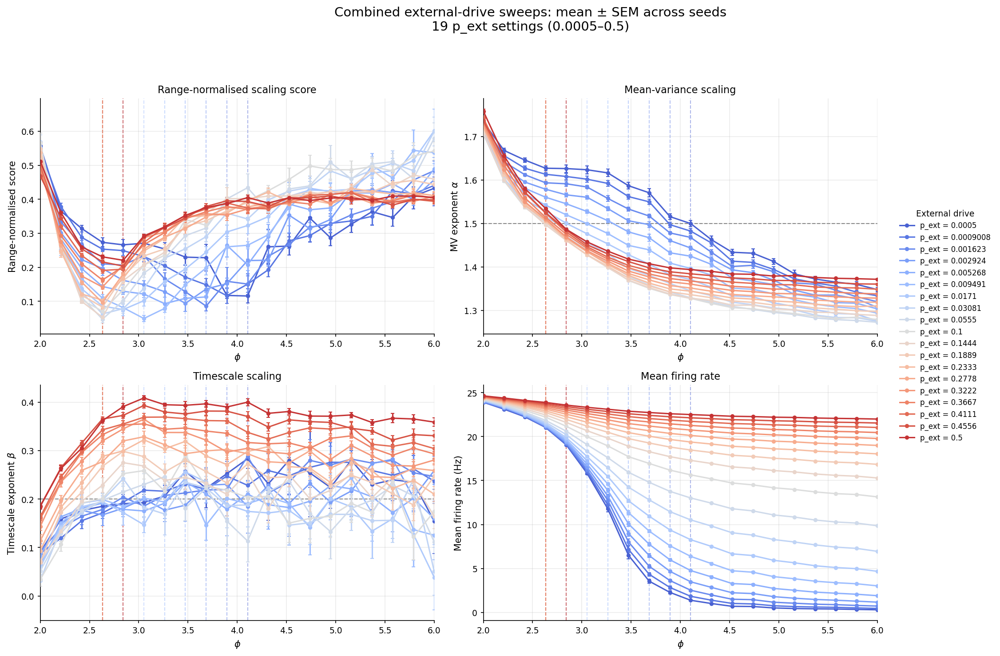

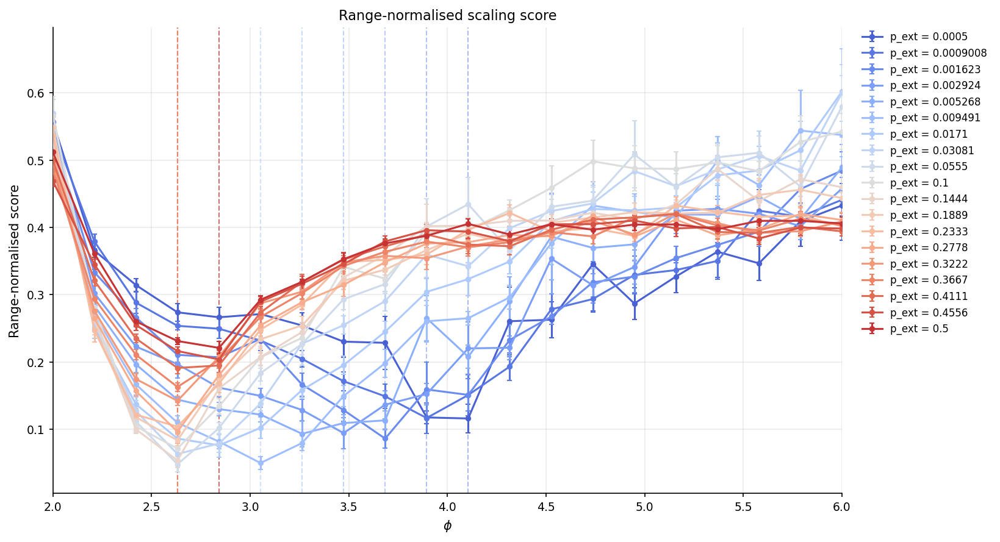

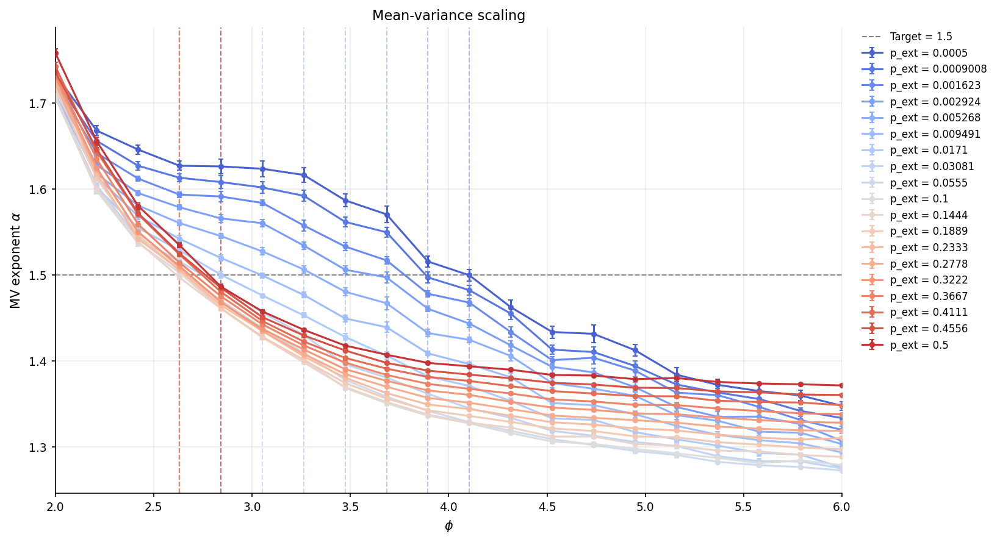

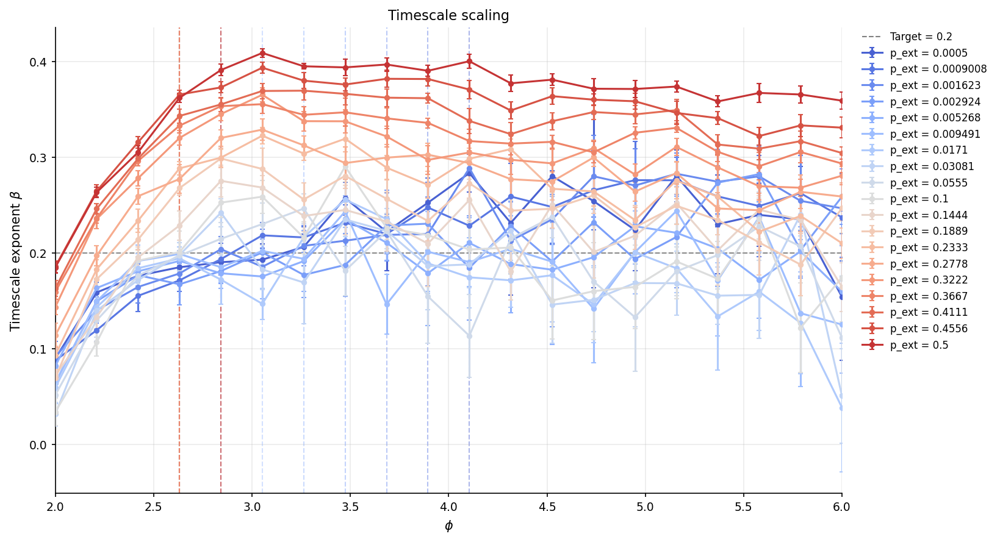

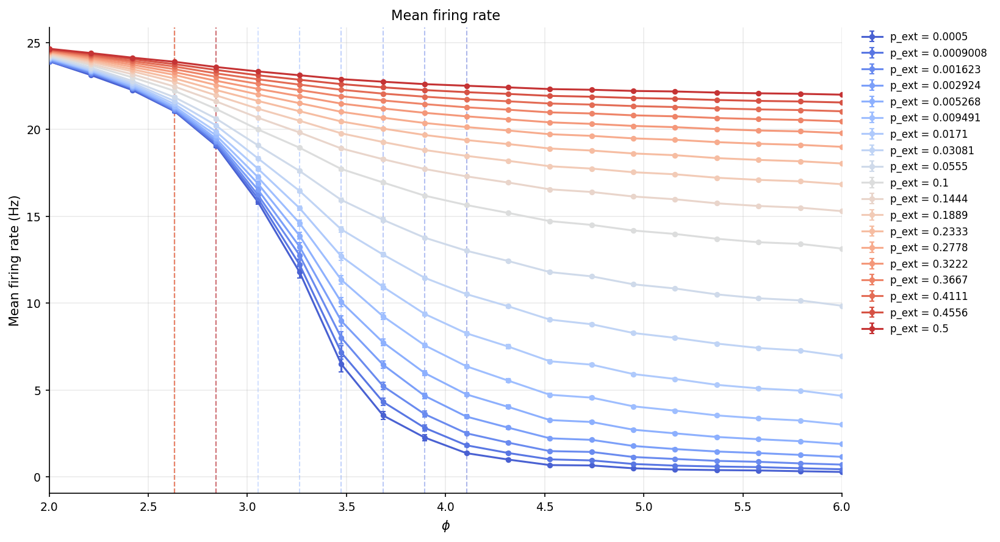

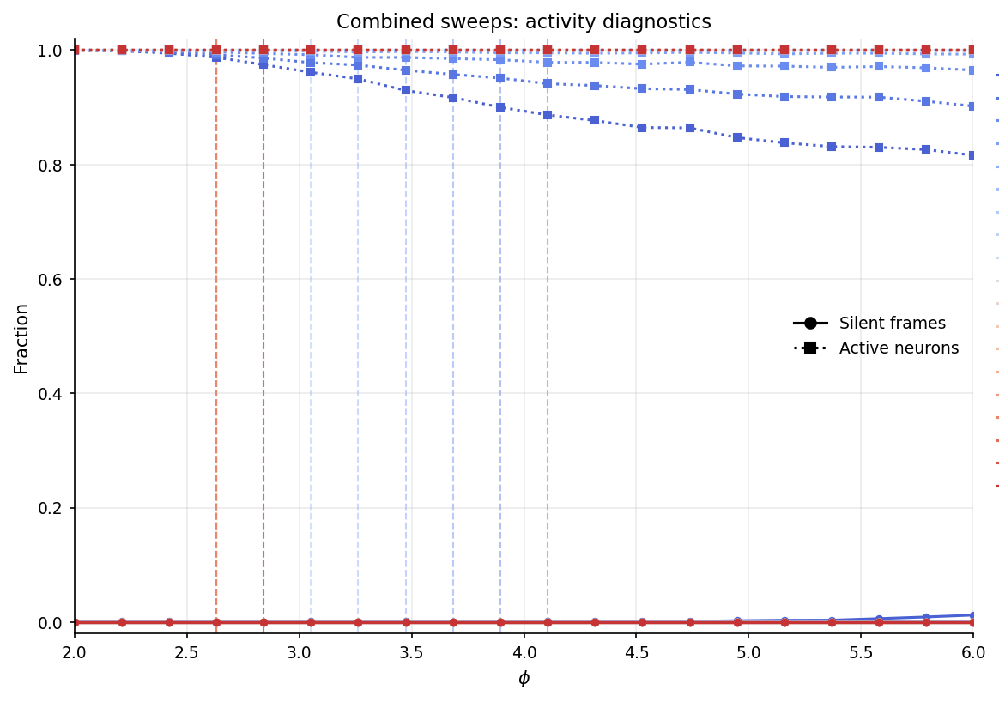

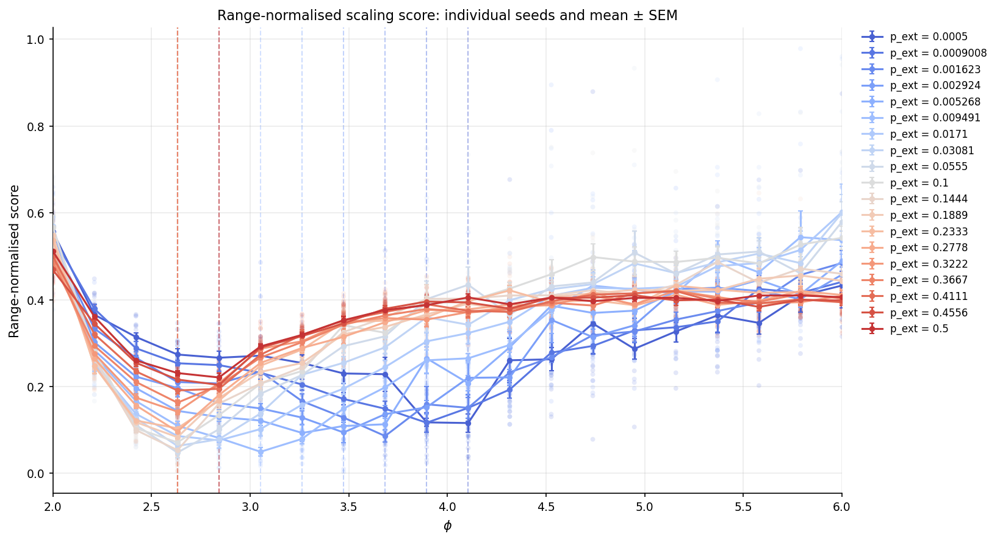

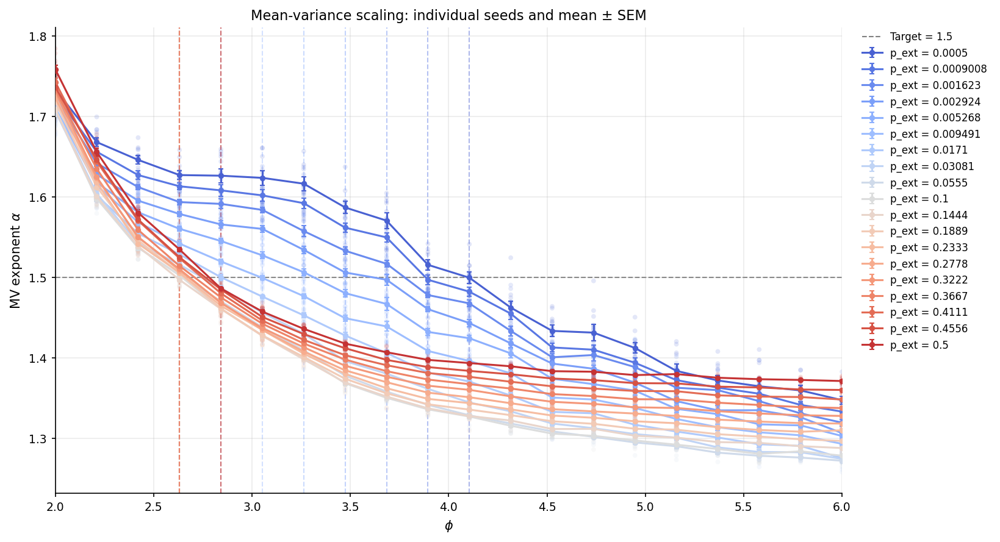

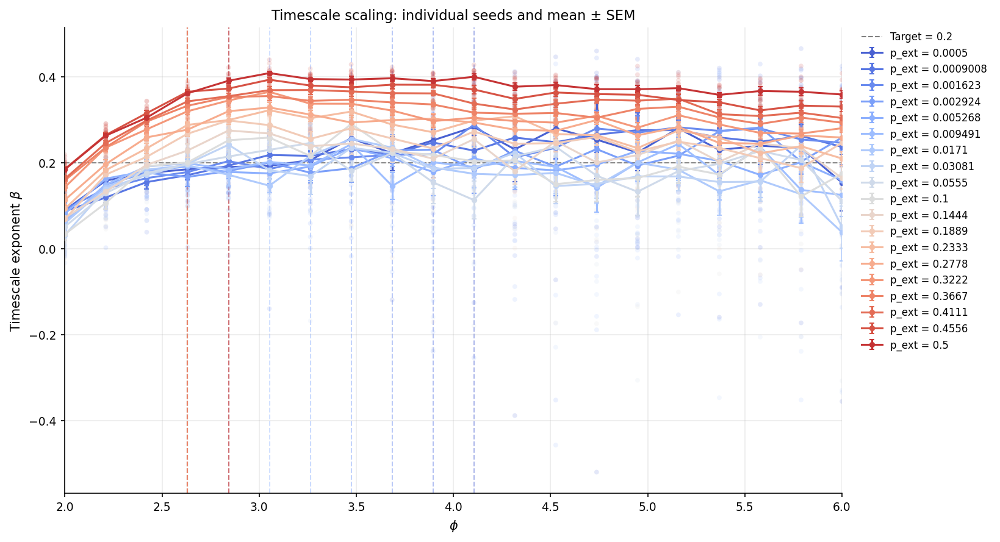


Dashed lines mark the best phi using the NEW score.
Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/icg_scaling_ew11p7_iw22p4_pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005_1/phi_comparison_combined_range_normalised


In [72]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths and settings
# ============================================================

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

OLD_DIR = BASE / (
    "icg_scaling_ew11p7_iw22p4_"
    "pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005"
)

NEW_DIR = BASE / (
    "icg_scaling_ew11p7_iw22p4_"
    "pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005_1"
)

FIGDIR = NEW_DIR / "phi_comparison_combined_range_normalised"
FIGDIR.mkdir(parents=True, exist_ok=True)

TARGET_MV = 1.50
TARGET_TAU = 0.20
SHOW_BEST_LINES = True

# ============================================================
# Load both sweeps
# ============================================================

summary_frames = []
seed_frames = []

for source, directory in [
    ("original", OLD_DIR),
    ("new", NEW_DIR),
]:
    summary = (
        pd.read_csv(directory / "phi_scaling_summary.csv")
        .replace([np.inf, -np.inf], np.nan)
        .assign(source=source)
    )

    seeds = (
        pd.read_csv(directory / "phi_scaling_seed_exponents.csv")
        .replace([np.inf, -np.inf], np.nan)
        .assign(source=source)
    )

    print(
        f"{source} p_ext values:",
        np.array2string(
            np.sort(summary["p_ext"].dropna().unique()),
            precision=7,
        ),
    )

    summary_frames.append(summary)
    seed_frames.append(seeds)

# ============================================================
# Combine: retain NEW results at overlapping conditions
# ============================================================

summary_all = (
    pd.concat(summary_frames, ignore_index=True)
    .drop_duplicates(["p_ext", "phi"], keep="last")
    .sort_values(["p_ext", "phi"])
    .reset_index(drop=True)
)

selected_sources = summary_all[["p_ext", "phi", "source"]]

seeds_all = (
    pd.concat(seed_frames, ignore_index=True)
    .merge(
        selected_sources,
        on=["p_ext", "phi", "source"],
        how="inner",
        validate="many_to_one",
    )
    .sort_values(["p_ext", "phi", "seed_idx"])
    .reset_index(drop=True)
)

# ============================================================
# Global observed ranges across ALL retained seeds/conditions
# Same normalisation for every p_ext and phi.
# ============================================================

def observed_range(series, name):
    values = series.dropna().to_numpy(float)

    if len(values) == 0:
        raise ValueError(f"No finite values found for {name}.")

    lower = float(values.min())
    upper = float(values.max())
    span = upper - lower

    if not np.isfinite(span) or span <= 0:
        raise ValueError(f"{name} has no positive finite range.")

    return lower, upper, span


MV_MIN, MV_MAX, MV_RANGE = observed_range(
    seeds_all["MV_alpha"], "MV_alpha"
)
TAU_MIN, TAU_MAX, TAU_RANGE = observed_range(
    seeds_all["TAU_beta"], "TAU_beta"
)

print(
    f"\nMV alpha: min={MV_MIN:.6g}, "
    f"max={MV_MAX:.6g}, range={MV_RANGE:.6g}"
)
print(
    f"TAU beta: min={TAU_MIN:.6g}, "
    f"max={TAU_MAX:.6g}, range={TAU_RANGE:.6g}"
)

# Preserve old scores; replace score with the new definition.
seeds_all = seeds_all.rename(columns={"score": "score_original"})

seeds_all["MV_distance_normalised"] = (
    (seeds_all["MV_alpha"] - TARGET_MV).abs() / MV_RANGE
)

seeds_all["TAU_distance_normalised"] = (
    (seeds_all["TAU_beta"] - TARGET_TAU).abs() / TAU_RANGE
)

# If either exponent is missing, the combined score is NaN.
seeds_all["score"] = (
    seeds_all["MV_distance_normalised"]
    + seeds_all["TAU_distance_normalised"]
)


def sem(series):
    values = series.dropna().to_numpy(float)
    return (
        float(values.std(ddof=1) / np.sqrt(len(values)))
        if len(values) > 1 else np.nan
    )


score_summary = (
    seeds_all
    .groupby(["p_ext", "phi", "source"], as_index=False)
    .agg(
        score_mean=("score", "mean"),
        score_sem=("score", sem),
        score_n_valid=("score", "count"),
    )
)

summary_all = (
    summary_all
    .drop(
        columns=["score_mean", "score_sem", "score_n_valid"],
        errors="ignore",
    )
    .merge(
        score_summary,
        on=["p_ext", "phi", "source"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["p_ext", "phi"])
    .reset_index(drop=True)
)

# Save recalculated outputs in the new plot folder.
summary_all.to_csv(
    FIGDIR / "combined_range_normalised_summary.csv",
    index=False,
)
seeds_all.to_csv(
    FIGDIR / "combined_range_normalised_seed_scores.csv",
    index=False,
)

pd.DataFrame([
    {
        "metric": "MV_alpha",
        "target": TARGET_MV,
        "observed_min": MV_MIN,
        "observed_max": MV_MAX,
        "observed_range": MV_RANGE,
    },
    {
        "metric": "TAU_beta",
        "target": TARGET_TAU,
        "observed_min": TAU_MIN,
        "observed_max": TAU_MAX,
        "observed_range": TAU_RANGE,
    },
]).to_csv(FIGDIR / "score_normalisation.csv", index=False)

# ============================================================
# Shared Spectral colours
# ============================================================

# ============================================================
# Shared coolwarm colours
# Low p_ext = blue; high p_ext = red.
# ============================================================

p_ext_values = np.sort(summary_all["p_ext"].dropna().unique())

if len(p_ext_values) == 0:
    raise ValueError("No p_ext settings found.")

print("\nCombined p_ext values:")
print(np.array2string(p_ext_values, precision=7))

palette = plt.get_cmap("coolwarm")(
    np.linspace(0.05, 0.95, len(p_ext_values))
)
colour_map = dict(zip(p_ext_values, palette))

PHI_MIN = float(summary_all["phi"].min())
PHI_MAX = float(summary_all["phi"].max())

panels = [
    (
        "score", "score_mean", "score_sem",
        "Range-normalised score",
        "Range-normalised scaling score",
        None, "score",
    ),
    (
        "MV_alpha", "MV_alpha_mean", "MV_alpha_sem",
        r"MV exponent $\alpha$", "Mean-variance scaling",
        TARGET_MV, "MV_alpha",
    ),
    (
        "TAU_beta", "TAU_beta_mean", "TAU_beta_sem",
        r"Timescale exponent $\beta$", "Timescale scaling",
        TARGET_TAU, "TAU_beta",
    ),
    (
        "mean_rate_hz", "mean_rate_hz", "mean_rate_hz_sem",
        "Mean firing rate (Hz)", "Mean firing rate",
        None, "mean_rate",
    ),
]

# ============================================================
# Best sampled phi using NEW mean seed score
# ============================================================

best_rows = []
best_phi_map = {}

for p_ext, group in summary_all.groupby("p_ext", sort=True):
    valid = group.dropna(subset=["score_mean"])

    if valid.empty:
        continue

    best = valid.loc[valid["score_mean"].idxmin()]
    best_rows.append(best.to_dict())
    best_phi_map[p_ext] = float(best["phi"])

best_summary = pd.DataFrame(best_rows)

if not best_summary.empty:
    best_summary.to_csv(
        FIGDIR / "best_phi_by_p_ext.csv",
        index=False,
    )

    print("\nBest phi by mean range-normalised seed score:")
    print(
        best_summary[[
            "source", "p_ext", "phi",
            "MV_alpha_mean", "TAU_beta_mean",
            "score_mean", "score_sem", "mean_rate_hz",
        ]].to_string(
            index=False,
            float_format=lambda value: f"{value:.6g}",
        )
    )

# ============================================================
# Helpers
# ============================================================

def finish(fig, filename):
    fig.savefig(FIGDIR / filename, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def add_best_lines(ax):
    if SHOW_BEST_LINES:
        for p_ext, best_phi in best_phi_map.items():
            ax.axvline(
                best_phi,
                color=colour_map[p_ext],
                linestyle="--",
                linewidth=1,
                alpha=0.45,
                zorder=1,
            )


def draw_panel(ax, panel, seed_scatter=False, legend=True):
    seed_col, mean_col, sem_col, ylabel, title, target, stem = panel

    for p_ext, group in summary_all.groupby("p_ext", sort=True):
        group = group.sort_values("phi")
        colour = colour_map[p_ext]

        if seed_scatter:
            seeds = seeds_all.loc[seeds_all["p_ext"] == p_ext]

            ax.scatter(
                seeds["phi"], seeds[seed_col],
                color=colour,
                alpha=0.15,
                s=14,
                edgecolors="none",
                zorder=2,
            )

        ax.errorbar(
            group["phi"].to_numpy(float),
            group[mean_col].to_numpy(float),
            yerr=group[sem_col].to_numpy(float),
            color=colour,
            marker="o",
            markersize=3.5,
            linewidth=1.5,
            capsize=2,
            label=f"p_ext = {p_ext:.4g}",
            zorder=3,
        )

    if target is not None:
        ax.axhline(
            target,
            color="grey",
            linestyle="--",
            linewidth=1,
            label=f"Target = {target:g}",
            zorder=1,
        )

    add_best_lines(ax)

    ax.set(
        xlabel=r"$\phi$",
        ylabel=ylabel,
        title=title,
        xlim=(PHI_MIN, PHI_MAX),
    )
    ax.grid(alpha=0.25)

    if legend:
        ax.legend(
            frameon=False,
            fontsize=8,
            loc="upper left",
            bbox_to_anchor=(1.02, 1),
            borderaxespad=0,
        )

# ============================================================
# Main 2 × 2 comparison
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, panel in zip(axes.ravel(), panels):
    draw_panel(ax, panel, legend=False)

drive_handles = [
    plt.Line2D(
        [0], [0],
        color=colour_map[p_ext],
        marker="o",
        markersize=3.5,
        linewidth=1.5,
        label=f"p_ext = {p_ext:.4g}",
    )
    for p_ext in p_ext_values
]

fig.legend(
    handles=drive_handles,
    title="External drive",
    frameon=False,
    fontsize=8,
    loc="center left",
    bbox_to_anchor=(0.84, 0.5),
)

fig.suptitle(
    "Combined external-drive sweeps: mean ± SEM across seeds\n"
    f"{len(p_ext_values)} p_ext settings "
    f"({p_ext_values.min():.4g}–{p_ext_values.max():.4g})",
    fontsize=14,
)

fig.tight_layout(rect=(0, 0, 0.84, 0.93))
finish(fig, "combined_phi_summary_2x2.png")

# ============================================================
# Separate comparison plots
# ============================================================

for panel in panels:
    fig, ax = plt.subplots(figsize=(11, 6))
    draw_panel(ax, panel)
    fig.tight_layout()
    finish(fig, f"combined_{panel[-1]}_vs_phi.png")

# ============================================================
# Activity diagnostics
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

diagnostic_drive_handles = []

for p_ext, group in summary_all.groupby("p_ext", sort=True):
    group = group.sort_values("phi")
    colour = colour_map[p_ext]

    line, = ax.plot(
        group["phi"], group["frac_silent_frames"],
        color=colour,
        marker="o",
        markersize=3.5,
        linestyle="-",
        linewidth=1.5,
        label=f"p_ext = {p_ext:.4g}",
    )
    diagnostic_drive_handles.append(line)

    ax.plot(
        group["phi"], group["frac_active_neurons"],
        color=colour,
        marker="s",
        markersize=3.5,
        linestyle=":",
        linewidth=1.5,
    )

add_best_lines(ax)

drive_legend = ax.legend(
    handles=diagnostic_drive_handles,
    title="External drive",
    frameon=False,
    fontsize=8,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
)
ax.add_artist(drive_legend)

ax.legend(
    handles=[
        plt.Line2D(
            [0], [0], color="black",
            marker="o", linestyle="-", label="Silent frames",
        ),
        plt.Line2D(
            [0], [0], color="black",
            marker="s", linestyle=":", label="Active neurons",
        ),
    ],
    frameon=False,
    fontsize=9,
    loc="best",
)

ax.set(
    xlabel=r"$\phi$",
    ylabel="Fraction",
    title="Combined sweeps: activity diagnostics",
    xlim=(PHI_MIN, PHI_MAX),
    ylim=(-0.02, 1.02),
)
ax.grid(alpha=0.25)

fig.subplots_adjust(right=0.76, bottom=0.13, top=0.9)
finish(fig, "combined_activity_diagnostics_vs_phi.png")

# ============================================================
# Individual seeds + mean ± SEM
# ============================================================

for panel in panels[:3]:
    fig, ax = plt.subplots(figsize=(11, 6))
    draw_panel(ax, panel, seed_scatter=True)
    ax.set_title(f"{panel[4]}: individual seeds and mean ± SEM")
    fig.tight_layout()
    finish(fig, f"combined_seed_{panel[-1]}_scatter_vs_phi.png")

print("\nDashed lines mark the best phi using the NEW score.")
print("Saved plots to:", FIGDIR)

/tmp/ipykernel_1648054/2190749962.py:51: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(bottom=0)


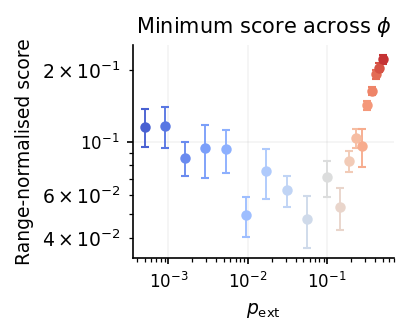

In [78]:
# Requires `summary` and `FIGDIR` from the previous block.

valid = (
    summary.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["p_ext", "score_mean"])
    .copy()
)

if valid.empty:
    raise ValueError("No finite scores found.")

minima = (
    valid.loc[valid.groupby("p_ext")["score_mean"].idxmin()]
    .sort_values("p_ext")
)

p_ext_values = np.sort(valid["p_ext"].unique())
colour_map = dict(zip(
    p_ext_values,
    plt.get_cmap("coolwarm")(
        np.linspace(0.05, 0.95, len(p_ext_values))
    ),
))

# Narrower, shorter plot; minima and their SEM only.
fig, ax = plt.subplots(figsize=(2.8, 2.3))

for _, row in minima.iterrows():
    ax.errorbar(
        row["p_ext"],
        row["score_mean"],
        yerr=(
            row["score_sem"]
            if np.isfinite(row["score_sem"]) else None
        ),
        fmt="o",
        color=colour_map[row["p_ext"]],
        markersize=4,
        elinewidth=0.9,
        capsize=2,
        zorder=3,
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set(
    xlabel=r"$p_\mathrm{ext}$",
    ylabel="Range-normalised score",
    title=r"Minimum score across $\phi$",
)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=8)
ax.xaxis.label.set_size(9)
ax.yaxis.label.set_size(9)
ax.title.set_size(10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.15)

fig.tight_layout()
fig.savefig(
    FIGDIR / "compact_minimum_score_vs_pext.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

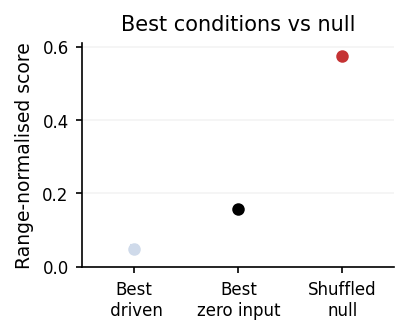


Selected conditions:
          condition     p_ext     phi  score_mean  score_sem  n_valid
        Best driven 0.0555047 2.63158   0.0477126  0.0116447       10
    Best zero input         0 4.11538    0.156766 0.00802727       40
Saved shuffled null      0.02 3.67949    0.574908 0.00792574       20

Null SEM is across real simulations, after averaging their nulls.
Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/icg_scaling_ew11p7_iw22p4_pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005_1/best_driven_zero_input_null_comparison


In [79]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths
# ============================================================

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

OLD_DIR = BASE / (
    "icg_scaling_ew11p7_iw22p4_"
    "pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005"
)

NEW_DIR = BASE / (
    "icg_scaling_ew11p7_iw22p4_"
    "pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005_1"
)

ZERO_DIR = BASE / (
    "phi_scaling_newpars_ew11p7_iw22p4_"
    "pext0_quick_phi1p5to10_40steps_40seeds_smooth005"
)

NULL_DIR = BASE / (
    "bestphi3p679_ew11p7_iw22p4_theta8p44_"
    "pext0p02_null_shuffle_20real_10null_smooth005"
)

FIGDIR = NEW_DIR / "best_driven_zero_input_null_comparison"
FIGDIR.mkdir(parents=True, exist_ok=True)

TARGET_ALPHA = 1.50
TARGET_BETA = 0.20

# ============================================================
# Helpers
# ============================================================

def read_clean(path):
    return pd.read_csv(path).replace([np.inf, -np.inf], np.nan)


def sem(values):
    values = pd.Series(values).dropna()
    return (
        values.std(ddof=1) / np.sqrt(len(values))
        if len(values) > 1 else np.nan
    )


# ============================================================
# Load driven sweeps
# Keep new results at overlapping p_ext / phi conditions.
# ============================================================

frames = []

for source, directory in [
    ("original", OLD_DIR),
    ("new", NEW_DIR),
]:
    frame = read_clean(
        directory / "phi_scaling_seed_exponents.csv"
    )
    frame["source"] = source
    frames.append(frame)

all_driven = pd.concat(frames, ignore_index=True)

selected_sources = (
    all_driven[["p_ext", "phi", "source"]]
    .drop_duplicates()
    .drop_duplicates(["p_ext", "phi"], keep="last")
)

driven = all_driven.merge(
    selected_sources,
    on=["p_ext", "phi", "source"],
    how="inner",
    validate="many_to_one",
)

# ============================================================
# Common normalisation from the full driven seed sweep
# Apply these SAME denominators to all three conditions.
# ============================================================

ALPHA_RANGE = (
    driven["MV_alpha"].max() - driven["MV_alpha"].min()
)
BETA_RANGE = (
    driven["TAU_beta"].max() - driven["TAU_beta"].min()
)

if (
    not np.isfinite(ALPHA_RANGE)
    or not np.isfinite(BETA_RANGE)
    or ALPHA_RANGE <= 0
    or BETA_RANGE <= 0
):
    raise ValueError("Cannot calculate finite, positive exponent ranges.")


def add_score(frame):
    frame = frame.copy()
    frame["comparison_score"] = (
        np.abs(frame["MV_alpha"] - TARGET_ALPHA) / ALPHA_RANGE
        + np.abs(frame["TAU_beta"] - TARGET_BETA) / BETA_RANGE
    )
    return frame


def summarise_scores(frame, group_cols):
    return (
        frame.groupby(group_cols, as_index=False)
        .agg(
            score_mean=("comparison_score", "mean"),
            score_sem=("comparison_score", sem),
            n_valid=("comparison_score", "count"),
        )
        .dropna(subset=["score_mean"])
    )


driven = add_score(driven)

driven_summary = summarise_scores(
    driven, ["p_ext", "phi"]
)

if driven_summary.empty:
    raise ValueError("No finite driven scores.")

# Minimum over phi for each p_ext, then minimum over p_ext.
driven_minima = (
    driven_summary.loc[
        driven_summary.groupby("p_ext")["score_mean"].idxmin()
    ]
    .sort_values("p_ext")
)

best_driven = driven_minima.loc[
    driven_minima["score_mean"].idxmin()
]

# ============================================================
# Zero external input: select best phi using the SAME score.
# ============================================================

zero = read_clean(
    ZERO_DIR / "phi_scaling_seed_exponents.csv"
)

if "p_ext" in zero.columns:
    zero = zero.loc[
        np.isclose(zero["p_ext"], 0.0, rtol=0, atol=1e-12)
    ].copy()

zero = add_score(zero)
zero_summary = summarise_scores(zero, ["phi"])

if zero_summary.empty:
    raise ValueError("No finite zero-input scores.")

best_zero = zero_summary.loc[
    zero_summary["score_mean"].idxmin()
]

# ============================================================
# Saved nulls
# Average the 10 null scores within each real simulation,
# then calculate mean ± SEM across real simulations.
# ============================================================

null_saved = read_clean(
    NULL_DIR / "real_vs_shuffle_seed_metrics.csv"
)

nulls = null_saved.loc[
    null_saved["condition"] == "null_shuffle"
].copy()

nulls = add_score(nulls)

null_by_real = (
    nulls.groupby("real_idx")["comparison_score"]
    .mean()
    .dropna()
)

if null_by_real.empty:
    raise ValueError("No finite shuffled-null scores.")

null_mean = float(null_by_real.mean())
null_sem = float(sem(null_by_real))

null_pext = float(nulls["p_ext"].iloc[0])
null_phi = float(nulls["phi"].iloc[0])

# ============================================================
# Colours: same coolwarm ordering as the driven sweep
# ============================================================

p_ext_values = np.sort(driven_summary["p_ext"].unique())

colour_map = dict(zip(
    p_ext_values,
    plt.get_cmap("coolwarm")(
        np.linspace(0.05, 0.95, len(p_ext_values))
    ),
))

# ============================================================
# Compact comparison: dots and error bars only
# ============================================================

comparison = pd.DataFrame({
    "condition": [
        "Best driven",
        "Best zero input",
        "Saved shuffled null",
    ],
    "p_ext": [
        float(best_driven["p_ext"]),
        0.0,
        null_pext,
    ],
    "phi": [
        float(best_driven["phi"]),
        float(best_zero["phi"]),
        null_phi,
    ],
    "score_mean": [
        float(best_driven["score_mean"]),
        float(best_zero["score_mean"]),
        null_mean,
    ],
    "score_sem": [
        float(best_driven["score_sem"]),
        float(best_zero["score_sem"]),
        null_sem,
    ],
    "n_valid": [
        int(best_driven["n_valid"]),
        int(best_zero["n_valid"]),
        len(null_by_real),
    ],
})

labels = [
    "Best\n driven",
    "Best\nzero input",
    "Shuffled\nnull",
]

colours = [
    colour_map[float(best_driven["p_ext"])],
    "black",
    plt.get_cmap("coolwarm")(0.95),
]

fig, ax = plt.subplots(figsize=(2.8, 2.3))

for x, (_, row), colour in zip(
    range(3), comparison.iterrows(), colours
):
    ax.errorbar(
        x,
        row["score_mean"],
        yerr=(
            row["score_sem"]
            if np.isfinite(row["score_sem"]) else None
        ),
        fmt="o",
        color=colour,
        markersize=5,
        elinewidth=0.9,
        capsize=2,
        zorder=3,
    )

ax.set_xticks(range(3))
ax.set_xticklabels(labels, fontsize=8)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(bottom=0)
ax.set_ylabel("Range-normalised score", fontsize=9)
ax.set_title("Best conditions vs null", fontsize=10)
ax.tick_params(axis="y", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)

fig.tight_layout()
fig.savefig(
    FIGDIR / "best_driven_zero_input_vs_saved_null.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# ============================================================
# Save and print selected conditions
# ============================================================
comparison.to_csv(
    FIGDIR / "best_conditions_vs_null_scores.csv",
    index=False)

print("\nSelected conditions:")
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
print("\nNull SEM is across real simulations, after averaging their nulls.")
print("Saved plots to:", FIGDIR)

In [175]:
from scipy.stats import ttest_ind

# ============================================================
# Independent simulation scores at the selected conditions
# ============================================================

driven_scores = driven.loc[
    np.isclose(driven["p_ext"], best_driven["p_ext"])
    & np.isclose(driven["phi"], best_driven["phi"]),
    "comparison_score",
].dropna().to_numpy(float)

zero_scores = zero.loc[
    np.isclose(zero["phi"], best_zero["phi"]),
    "comparison_score",
].dropna().to_numpy(float)

# One observation per real simulation: mean of its shuffle scores.
null_scores = null_by_real.to_numpy(float)

groups = {
    "Best driven": driven_scores,
    "Best zero input": zero_scores,
    "Shuffled null": null_scores,
}

rows = []

for first, second in [
    ("Best driven", "Best zero input"),
    ("Best zero input", "Shuffled null"),
]:
    a, b = groups[first], groups[second]

    if min(len(a), len(b)) < 2:
        raise ValueError(f"Too few observations: {first} vs {second}")

    test = ttest_ind(a, b, equal_var=False, alternative="two-sided")

    rows.append({
        "comparison": f"{first} vs {second}",
        "n_first": len(a),
        "n_second": len(b),
        "mean_first": a.mean(),
        "mean_second": b.mean(),
        "mean_difference": a.mean() - b.mean(),
        "Welch_t": float(test.statistic),
        "p_two_sided": float(test.pvalue),
    })

tests = pd.DataFrame(rows)

# Holm correction across the two comparisons.
p = tests["p_two_sided"].to_numpy()
order = np.argsort(p)
adjusted = np.empty(len(p))
adjusted[order] = np.minimum(
    1.0,
    np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)),
)
tests["p_Holm"] = adjusted

tests.to_csv(FIGDIR / "best_conditions_Welch_tests.csv", index=False)
print(tests.to_string(index=False, float_format=lambda x: f"{x:.5g}"))
print("\nNegative mean difference means the first group has a lower score.")

                      comparison  n_first  n_second  mean_first  mean_second  mean_difference  Welch_t  p_two_sided     p_Holm
  Best driven vs Best zero input       10        40    0.047713      0.15677         -0.10905  -7.7106   3.3027e-07 3.3027e-07
Best zero input vs Shuffled null       40        20     0.15677      0.57491         -0.41814  -37.067   7.7942e-39 1.5588e-38

Negative mean difference means the first group has a lower score.


Best driven: p_ext=0.0555047, phi=2.63158
Best zero input: phi=4.11538
Saved nulls: p_ext=0.02, phi=3.67949


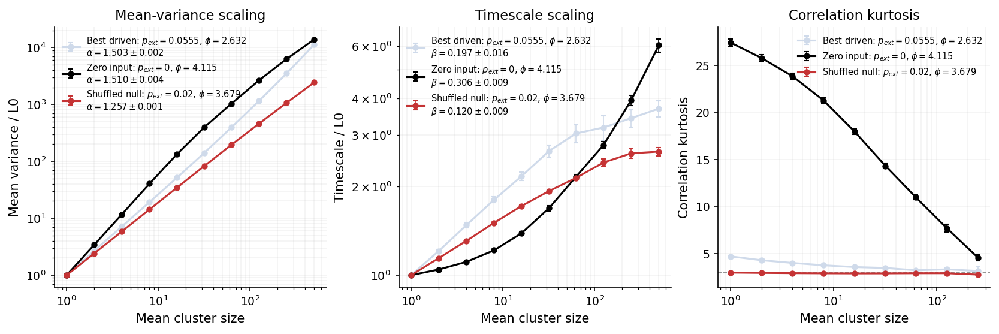

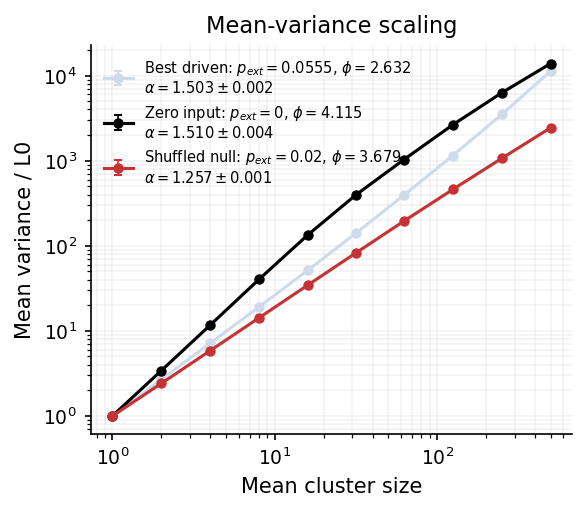

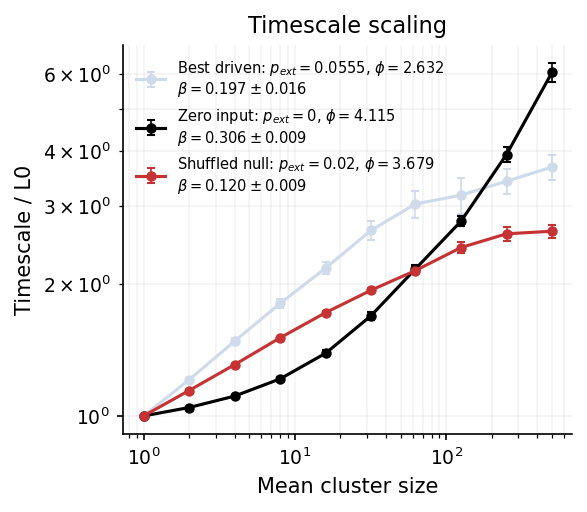

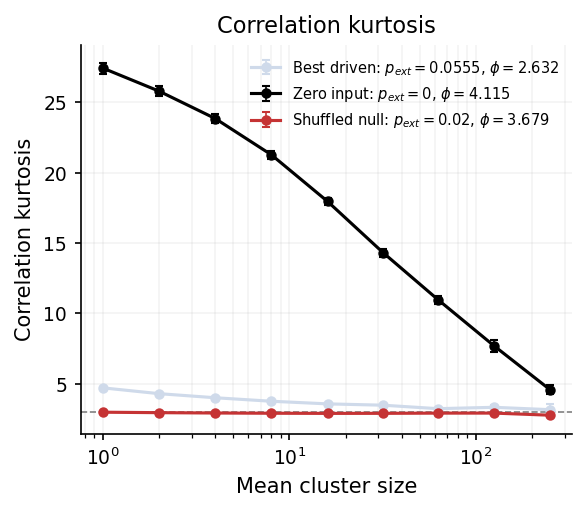


Saved plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/icg_scaling_ew11p7_iw22p4_pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005_1/best_conditions_vs_null_ICG


In [80]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths and settings
# ============================================================

BASE = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE")

OLD_DIR = BASE / (
    "icg_scaling_ew11p7_iw22p4_"
    "pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005"
)

NEW_DIR = BASE / (
    "icg_scaling_ew11p7_iw22p4_"
    "pext1em5_1em3_1em2_phi2to6_20phis_10seeds_smooth005_1"
)

ZERO_DIR = BASE / (
    "phi_scaling_newpars_ew11p7_iw22p4_"
    "pext0_quick_phi1p5to10_40steps_40seeds_smooth005"
)

NULL_DIR = BASE / (
    "bestphi3p679_ew11p7_iw22p4_theta8p44_"
    "pext0p02_null_shuffle_20real_10null_smooth005"
)

FIGDIR = NEW_DIR / "best_conditions_vs_null_ICG"
FIGDIR.mkdir(parents=True, exist_ok=True)

TARGET_ALPHA = 1.50
TARGET_BETA = 0.20

# ============================================================
# Helpers
# ============================================================

def read_clean(path):
    return pd.read_csv(path).replace([np.inf, -np.inf], np.nan)


def sem(values):
    values = pd.Series(values).dropna()
    return (
        float(values.std(ddof=1) / np.sqrt(len(values)))
        if len(values) > 1 else np.nan
    )


def pick_col(frame, candidates):
    for col in candidates:
        if col in frame.columns:
            return col
    raise ValueError(
        f"None of {candidates} found.\n"
        f"Available columns: {frame.columns.tolist()}"
    )


def select_condition(frame, phi, p_ext=None):
    # Tight tolerance avoids selecting neighbouring sweep settings.
    mask = np.isclose(
        frame["phi"], phi, rtol=1e-8, atol=1e-10
    )
    if p_ext is not None and "p_ext" in frame.columns:
        mask &= np.isclose(
            frame["p_ext"], p_ext, rtol=1e-8, atol=1e-12
        )
    selected = frame.loc[mask].copy()
    if selected.empty:
        raise ValueError(
            f"No saved rows for phi={phi}, p_ext={p_ext}."
        )
    return selected


# ============================================================
# Load driven seed exponents
# Prefer the new sweep at overlapping conditions.
# ============================================================

seed_frames = []

for source, directory in [
    ("original", OLD_DIR),
    ("new", NEW_DIR),
]:
    frame = read_clean(
        directory / "phi_scaling_seed_exponents.csv"
    )
    frame["source"] = source
    seed_frames.append(frame)

all_seeds = pd.concat(seed_frames, ignore_index=True)

selected_sources = (
    all_seeds[["p_ext", "phi", "source"]]
    .drop_duplicates()
    .drop_duplicates(["p_ext", "phi"], keep="last")
)

driven_seeds = all_seeds.merge(
    selected_sources,
    on=["p_ext", "phi", "source"],
    how="inner",
    validate="many_to_one",
)

# Same range-normalised score as the previous comparison.
ALPHA_RANGE = (
    driven_seeds["MV_alpha"].max()
    - driven_seeds["MV_alpha"].min()
)
BETA_RANGE = (
    driven_seeds["TAU_beta"].max()
    - driven_seeds["TAU_beta"].min()
)

if (
    not np.isfinite(ALPHA_RANGE)
    or not np.isfinite(BETA_RANGE)
    or ALPHA_RANGE <= 0
    or BETA_RANGE <= 0
):
    raise ValueError("Invalid exponent ranges for score normalisation.")


def add_score(frame):
    frame = frame.copy()
    frame["comparison_score"] = (
        np.abs(frame["MV_alpha"] - TARGET_ALPHA) / ALPHA_RANGE
        + np.abs(frame["TAU_beta"] - TARGET_BETA) / BETA_RANGE
    )
    return frame


driven_seeds = add_score(driven_seeds)

driven_summary = (
    driven_seeds.groupby(
        ["source", "p_ext", "phi"], as_index=False
    )
    .agg(score_mean=("comparison_score", "mean"))
    .dropna(subset=["score_mean"])
)

# Best mean score across ALL p_ext / phi settings.
best_driven = driven_summary.loc[
    driven_summary["score_mean"].idxmin()
]

best_pext = float(best_driven["p_ext"])
best_driven_phi = float(best_driven["phi"])

best_driven_dir = (
    NEW_DIR if best_driven["source"] == "new" else OLD_DIR
)

driven_best_seeds = select_condition(
    driven_seeds,
    phi=best_driven_phi,
    p_ext=best_pext,
)

# ============================================================
# Best zero-input phi using the same score
# ============================================================

zero_seeds = read_clean(
    ZERO_DIR / "phi_scaling_seed_exponents.csv"
)

if "p_ext" in zero_seeds.columns:
    zero_seeds = zero_seeds.loc[
        np.isclose(
            zero_seeds["p_ext"], 0.0,
            rtol=0, atol=1e-12,
        )
    ].copy()

zero_seeds = add_score(zero_seeds)

zero_summary = (
    zero_seeds.groupby("phi", as_index=False)
    .agg(score_mean=("comparison_score", "mean"))
    .dropna(subset=["score_mean"])
)

best_zero = zero_summary.loc[
    zero_summary["score_mean"].idxmin()
]

best_zero_phi = float(best_zero["phi"])

zero_best_seeds = select_condition(
    zero_seeds, phi=best_zero_phi
)

# ============================================================
# Load saved ICG generation rows
# ============================================================

driven_gen = select_condition(
    read_clean(
        best_driven_dir / "phi_scaling_icg_rows.csv"
    ),
    phi=best_driven_phi,
    p_ext=best_pext,
)

zero_gen = select_condition(
    read_clean(
        ZERO_DIR / "phi_scaling_icg_rows.csv"
    ),
    phi=best_zero_phi,
)

null_gen_all = read_clean(
    NULL_DIR / "real_vs_shuffle_generation_metrics.csv"
)

null_gen = null_gen_all.loc[
    null_gen_all["condition"] == "null_shuffle"
].copy()

null_seed_all = read_clean(
    NULL_DIR / "real_vs_shuffle_seed_metrics.csv"
)

null_seeds = null_seed_all.loc[
    null_seed_all["condition"] == "null_shuffle"
].copy()

null_phi = float(null_seeds["phi"].iloc[0])
null_pext = float(null_seeds["p_ext"].iloc[0])

print(
    f"Best driven: p_ext={best_pext:.6g}, "
    f"phi={best_driven_phi:.6g}"
)
print(f"Best zero input: phi={best_zero_phi:.6g}")
print(
    f"Saved nulls: p_ext={null_pext:.6g}, "
    f"phi={null_phi:.6g}"
)

# ============================================================
# Standardise columns and normalise each trace to its L0
# Kurtosis is retained in its saved units.
# ============================================================

def prepare_generation_rows(frame, is_null=False):
    frame = frame.copy()

    gen_col = pick_col(
        frame, ["gen", "level", "coarse_grain_level"]
    )
    size_col = pick_col(
        frame, ["mean_cluster_size", "cluster_size"]
    )
    mv_col = pick_col(
        frame,
        ["mean_variance", "MV", "mean_variance_norm", "MV_norm"],
    )
    tau_col = pick_col(
        frame,
        ["timescale", "TAU", "timescale_norm", "TAU_norm"],
    )
    kurt_col = pick_col(
        frame,
        ["kurtosis_corr", "corr_kurtosis", "kurtosis"],
    )

    if is_null:
        trace_keys = ["real_idx", "null_idx"]
        frame["_unit"] = frame["real_idx"]
    else:
        seed_col = pick_col(
            frame, ["seed_idx", "seed", "network_seed"]
        )
        trace_keys = [seed_col]
        frame["_unit"] = frame[seed_col]

    frame["_gen"] = frame[gen_col]
    frame["_size"] = frame[size_col]
    frame["_mv"] = frame[mv_col]
    frame["_tau"] = frame[tau_col]
    frame["_kurt"] = frame[kurt_col]

    frame = frame.sort_values(trace_keys + ["_gen"])

    # Use the actual first generation as L0 for each trace.
    bases = (
        frame.groupby(trace_keys, dropna=False)
        .head(1)[trace_keys + ["_mv", "_tau"]]
        .rename(columns={
            "_mv": "_mv_base",
            "_tau": "_tau_base",
        })
    )

    frame = frame.merge(
        bases,
        on=trace_keys,
        how="left",
        validate="many_to_one",
    )

    for metric in ["mv", "tau"]:
        base = frame[f"_{metric}_base"]
        base = base.where(np.isfinite(base) & (base > 0))
        frame[f"_{metric}"] = frame[f"_{metric}"] / base

    return frame


def summarise_generation_rows(frame):
    # For nulls, first average the shuffles within each real.
    # For real conditions, each unit is a simulation seed.
    unit_means = (
        frame.groupby(["_unit", "_gen"], as_index=False)
        [["_size", "_mv", "_tau", "_kurt"]]
        .mean()
    )

    return (
        unit_means.groupby("_gen", as_index=False)
        .agg(
            size_mean=("_size", "mean"),
            mv_mean=("_mv", "mean"),
            mv_sem=("_mv", sem),
            tau_mean=("_tau", "mean"),
            tau_sem=("_tau", sem),
            kurt_mean=("_kurt", "mean"),
            kurt_sem=("_kurt", sem),
        )
        .sort_values("_gen")
    )


curves = {
    "driven": summarise_generation_rows(
        prepare_generation_rows(driven_gen)
    ),
    "zero": summarise_generation_rows(
        prepare_generation_rows(zero_gen)
    ),
    "null": summarise_generation_rows(
        prepare_generation_rows(null_gen, is_null=True)
    ),
}

# ============================================================
# Mean fitted exponents ± SEM
# Null SEM is across real simulations after averaging shuffles.
# ============================================================

def exponent_stats(frame, is_null=False):
    values = frame[["MV_alpha", "TAU_beta"]]

    if is_null:
        values = (
            frame.groupby("real_idx")[["MV_alpha", "TAU_beta"]]
            .mean()
        )

    return {
        "alpha": float(values["MV_alpha"].mean()),
        "alpha_sem": sem(values["MV_alpha"]),
        "beta": float(values["TAU_beta"].mean()),
        "beta_sem": sem(values["TAU_beta"]),
    }


stats = {
    "driven": exponent_stats(driven_best_seeds),
    "zero": exponent_stats(zero_best_seeds),
    "null": exponent_stats(null_seeds, is_null=True),
}

# Match the driven condition's position in the coolwarm palette.
p_ext_values = np.sort(driven_summary["p_ext"].unique())
colour_map = dict(zip(
    p_ext_values,
    plt.get_cmap("coolwarm")(
        np.linspace(0.05, 0.95, len(p_ext_values))
    ),
))

colours = {
    "driven": colour_map[best_pext],
    "zero": "black",
    "null": plt.get_cmap("coolwarm")(0.95),
}

labels = {
    "driven": (
        rf"Best driven: $p_{{ext}}={best_pext:.4g}$, "
        rf"$\phi={best_driven_phi:.3f}$"
    ),
    "zero": (
        rf"Zero input: $p_{{ext}}=0$, "
        rf"$\phi={best_zero_phi:.3f}$"
    ),
    "null": (
        rf"Shuffled null: $p_{{ext}}={null_pext:.4g}$, "
        rf"$\phi={null_phi:.3f}$"
    ),
}

# ============================================================
# ICG scaling plots: mean variance, timescale, kurtosis
# Mean ± SEM only; no background seed traces.
# ============================================================

panels = [
    ("mv", "Mean-variance scaling", "Mean variance / L0", "alpha"),
    ("tau", "Timescale scaling", "Timescale / L0", "beta"),
    ("kurt", "Correlation kurtosis", "Correlation kurtosis", None),
]


def draw_panel(ax, panel):
    metric, title, ylabel, exponent = panel

    for condition in ["driven", "zero", "null"]:
        curve = curves[condition]
        label = labels[condition]

        if exponent is not None:
            symbol = r"\alpha" if exponent == "alpha" else r"\beta"
            value = stats[condition][exponent]
            error = stats[condition][f"{exponent}_sem"]

            label += (
                "\n"
                + rf"${symbol}={value:.3f}\pm{error:.3f}$"
            )

        ax.errorbar(
            curve["size_mean"],
            curve[f"{metric}_mean"],
            yerr=curve[f"{metric}_sem"],
            color=colours[condition],
            marker="o",
            markersize=4,
            linewidth=1.5,
            elinewidth=0.8,
            capsize=2,
            label=label,
        )

    ax.set_xscale("log")

    if metric in ["mv", "tau"]:
        ax.set_yscale("log")
    else:
        ax.axhline(
            3.0, color="grey", linestyle="--", linewidth=0.8
        )

    ax.set(
        xlabel="Mean cluster size",
        ylabel=ylabel,
        title=title,
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15, which="both")
    ax.legend(frameon=False, fontsize=7, loc="best")


# Combined figure
fig, axes = plt.subplots(
    1, 3,
    figsize=(11, 3.6),
    constrained_layout=True,
)

for ax, panel in zip(axes, panels):
    draw_panel(ax, panel)

fig.savefig(
    FIGDIR / "best_driven_zero_input_null_ICG_3panels.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Separate figures
for panel in panels:
    fig, ax = plt.subplots(
        figsize=(3.8, 3.3),
        constrained_layout=True,
    )

    draw_panel(ax, panel)

    fig.savefig(
        FIGDIR / f"best_driven_zero_input_null_{panel[0]}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# Save plotted curve summaries
for condition, curve in curves.items():
    curve.to_csv(
        FIGDIR / f"{condition}_ICG_curve_summary.csv",
        index=False,
    )

print("\nSaved plots to:", FIGDIR)

# Fig 2

In [ ]:
#!/usr/bin/env python3
"""50 x 50 fixed-i_w scan; same dynamics and ICG score as supplied.
Run beside icg_functions.py: python grid_50ew_50phi_llr_tau.py
In a Linux notebook: %run grid_50ew_50phi_llr_tau.py
No simulations execute on import. Completed network jobs are resumable.
"""
import os
for _key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
             "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_key] = "1"

import json
import inspect
import warnings
import contextlib
import io
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import expit
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits
import powerlaw
import icg_functions as fn

start_dic = {
    "n_neurons": 2000, "T": 10, "dt": 0.01,
    "refractory_steps": 2, "ei_ratio": 0.2,
    "e_w": 11.7, "i_w": 22.4, "theta": 8.44,
    "p_ext": 0.00, "phi": 4.2, "smoothe": 0.05,
}
OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals"
)
TRIALDIR = OUTDIR / "avalanche_trials_by_network"
ICGDIR = OUTDIR / "icg_rows_by_network"
JOBDIR = OUTDIR / "completed_network_jobs"
LLRDIR = OUTDIR / "truncated_powerlaw_vs_lognormal_fixed_iw_exact_llr_safe"

N_WORKERS = 20
N_SEEDS = 20
N_AVALANCHES_PER_NETWORK = 10000
MAX_STEPS = 1000
BASE_SEED = 91919

E_W_RANGE = (0.5, 18.0)
I_W_FIXED = float(start_dic["i_w"])
N_EW, N_IW, N_PHI = 50, 1, 50
EW_VALUES = np.linspace(*E_W_RANGE, N_EW)
IW_VALUES = np.array([I_W_FIXED])
PHI_VALUES = np.linspace(1.5, 6.0, N_PHI)

P_EXT_RUN = 0.0
SEED_ONLY_EXCITATORY = True
CLAMP_ZERO_PRESYNAPTIC_INPUT = True
DT = float(start_dic["dt"])
T_RUN = float(start_dic["T"])
SMOOTHE = float(start_dic["smoothe"])
BURN_IN_S = 2.0
TARGET_MV, TARGET_TAU = 1.50, 0.20
SAVE_AVALANCHE_TRIALS = True
SAVE_ICG_ROWS = True

SIZE_XMIN, DURATION_XMIN = 10, 0.1
EXTINCT_ONLY = True
MIN_N, MIN_TAIL_N, MIN_UNIQUE_TAIL = 100, 50, 3
RESUME = True
# Both estimands are retained. Pooled fits reproduce the previous
# analysis; mean per-network fits supply across-network SEMs.
SAVE_SEED_LLR = True
RUN_POOLED_LLR = True

KEYS = ["combo_i", "ew_idx", "iw_idx", "phi_idx", "phi", "e_w", "i_w"]
FIT_NAME = "truncated_powerlaw_vs_lognormal_by_ew_phi_fixed_iw_safe_extinct_only.csv"


def atomic_csv(df, path, compression=None):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, index=False, compression=compression)
    os.replace(tmp, path)


def atomic_json(value, path):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    # NaN follows Python JSON convention and is read by this script.
    tmp.write_text(json.dumps(value, indent=2))
    os.replace(tmp, path)


def safe_values(x):
    return pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna().to_numpy(float)


def sem(x):
    x = safe_values(x)
    return float(np.std(x, ddof=1) / np.sqrt(x.size)) if x.size > 1 else np.nan


def safe_mean(x):
    x = safe_values(x)
    return float(np.mean(x)) if x.size else np.nan


def safe_percentile(x, q):
    x = safe_values(x)
    return float(np.percentile(x, q)) if x.size else np.nan


def safe_cv(x):
    x = safe_values(x)
    if x.size < 2 or np.mean(x) <= 0:
        return np.nan
    return float(np.std(x, ddof=1) / np.mean(x))


def response_decay_timescale(active_counts, dt):
    x = np.asarray(active_counts, dtype=float)
    if not x.size:
        return np.nan
    peak = float(x.max())
    if peak <= 0:
        return 0.0
    post = x[int(np.argmax(x)):]
    below = np.flatnonzero(post <= peak / np.e)
    return float((below[0] if below.size else post.size - 1) * dt)


def branching_metrics(active_counts, extinct):
    counts = np.asarray(active_counts, dtype=float)
    out = dict(sigma_origin=np.nan, br_reg_slope=np.nan,
               br_reg_intercept=np.nan, br_reg_r2=np.nan, br_n_pairs=0)
    if not counts.size:
        return out
    if extinct:
        x, y = counts, np.r_[counts[1:], 0.0]
    else:
        x, y = counts[:-1], counts[1:]
    keep = np.isfinite(x) & np.isfinite(y) & (x > 0)
    x, y = x[keep], y[keep]
    out["br_n_pairs"] = int(x.size)
    if x.size < 2:
        return out
    denom = float(np.sum(x * x))
    out["sigma_origin"] = float(np.sum(x * y) / denom) if denom > 0 else np.nan
    try:
        X = np.column_stack([np.ones_like(x), x])
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        out["br_reg_intercept"], out["br_reg_slope"] = map(float, beta)
        ss_tot = float(np.sum((y - y.mean()) ** 2))
        out["br_reg_r2"] = (
            float(1 - np.sum((y - X @ beta) ** 2) / ss_tot)
            if ss_tot > 0 else np.nan
        )
    except Exception:
        pass
    return out


def local_connectivity_metrics(A, n_e):
    A = np.asarray(A, dtype=np.uint8)
    return {
        "edge_count": int(A.sum()),
        "mean_out_degree": float(A.sum(axis=1).mean()),
        "std_out_degree": float(A.sum(axis=1).std()),
        "mean_e_out_degree_all": float(A[:n_e, :].sum(axis=1).mean()),
        "mean_e_out_degree_e": float(A[:n_e, :n_e].sum(axis=1).mean()),
        "edge_density": float(A.sum() / max(A.shape[0] * (A.shape[0]-1), 1)),
    }


def pop_autocorr_tau(x, dt, max_lag_s=3.0):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size < 10:
        return np.nan
    x = x - x.mean()
    denom = np.sum(x * x)
    if denom <= 0:
        return np.nan
    max_lag = min(int(max_lag_s / dt), x.size // 2)
    if max_lag < 2:
        return np.nan
    ac = np.empty(max_lag + 1)
    ac[0] = 1.0
    for lag in range(1, max_lag + 1):
        ac[lag] = np.sum(x[:-lag] * x[lag:]) / denom
    ac[~np.isfinite(ac)] = 0
    crossing = np.flatnonzero(ac[1:] <= 0)
    ac_use = ac[:crossing[0]+2] if crossing.size else ac
    return float(np.trapezoid(ac_use, dx=dt))


def fit_power_slope(g, y_col, x_col="mean_cluster_size",
                    exclude_first=True, exclude_last=False, min_points=3):
    d = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[x_col] > 0) & (d[y_col] > 0)].sort_values(x_col)
    if exclude_first and len(d):
        d = d.iloc[1:]
    if exclude_last and len(d):
        d = d.iloc[:-1]
    if len(d) < min_points:
        return np.nan, np.nan, int(len(d))
    x, y = np.log10(d[x_col].to_numpy(float)), np.log10(d[y_col].to_numpy(float))
    slope, intercept = np.polyfit(x, y, 1)
    ss_tot = np.sum((y - y.mean())**2)
    r2 = 1 - np.sum((y - intercept - slope*x)**2)/ss_tot if ss_tot > 0 else np.nan
    return float(slope), float(r2), int(len(d))


def standardise_gen_df(gen_df):
    g = gen_df.copy()
    for source, target in [
        ("corr_kurtosis", "kurtosis_corr"), ("kurtosis_corr", "corr_kurtosis"),
        ("MV_norm", "mean_variance_norm"), ("TAU_norm", "timescale_norm"),
        ("MV", "mean_variance"), ("TAU", "timescale"),
    ]:
        if target not in g and source in g:
            g[target] = g[source]
    return g


def run_seeded_avalanche_sparse(A_e_T, A_i_T, n, n_e, e_w, i_w,
                                theta, refractory_steps, dt, seed_node,
                                rng, max_steps):
    state = np.zeros(n, dtype=np.int16)
    state[int(seed_node)] = 1
    active_counts = np.empty(int(max_steps), dtype=np.int32)
    for step in range(int(max_steps)):
        active = state == 1
        n_active = int(active.sum())
        if n_active == 0:
            duration_steps, censored = int(step), False
            break
        active_counts[step] = n_active
        inp_e = A_e_T @ active[:n_e].astype(np.float32)
        inp_i = A_i_T @ active[n_e:].astype(np.float32)
        p_net = expit(e_w * inp_e - i_w * inp_i - theta)
        if CLAMP_ZERO_PRESYNAPTIC_INPUT:
            p_net[~((inp_e > 0) | (inp_i > 0))] = 0
        new_active = (state == 0) & (rng.random(n) < p_net)
        new_state = np.zeros_like(state)
        new_state[active] = 2
        refractory = state >= 2
        new_state[refractory] = state[refractory] + 1
        new_state[new_state > refractory_steps + 1] = 0
        new_state[new_active] = 1
        state = new_state
        if not np.any(state == 1):
            duration_steps, censored = int(step + 1), False
            break
    else:
        duration_steps, censored = int(max_steps), True

    active_counts = active_counts[:duration_steps].copy()
    extinct = bool(not censored)
    duration_s = float(duration_steps * dt)
    if active_counts.size >= 5 and np.var(active_counts) > 0:
        with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
            warnings.filterwarnings("ignore", message="invalid value encountered in divide",
                                    category=RuntimeWarning)
            avalanche_tau_s = fn.timescale(
                active_counts[np.newaxis, :].astype(float),
                max_lag=min(3.0, max(2 * dt, duration_s / 2)), dt=float(dt))
    else:
        avalanche_tau_s = np.nan
    return {
        "size": int(active_counts.sum()),
        "duration_steps": int(duration_steps), "duration_s": duration_s,
        "lifetime_steps": int(duration_steps), "lifetime_s": duration_s,
        "peak_active": int(active_counts.max()) if active_counts.size else 0,
        "extinct": extinct, "censored": bool(censored),
        "persistent_at_cutoff": bool(censored),
        "mean_active_during_avalanche": safe_mean(active_counts),
        "avalanche_tau_s": float(avalanche_tau_s),
        "response_decay_tau_s": response_decay_timescale(active_counts, dt),
        **branching_metrics(active_counts, extinct),
    }


def empty_fit_result(n_all=0, n_tail=0, fail_reason="failed"):
    return {
        "R_truncated_vs_lognormal": np.nan, "p_truncated_vs_lognormal": np.nan,
        "xmin": np.nan, "alpha_truncated": np.nan, "lambda_truncated": np.nan,
        "mu_lognormal": np.nan, "sigma_lognormal": np.nan,
        "n_all": int(n_all), "n_tail": int(n_tail),
        "tail_fraction": float(n_tail/n_all) if n_all else np.nan,
        "fit_ok": False, "fail_reason": fail_reason,
    }


def fit_truncated_vs_lognormal(values, discrete=False, xmin=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values) & (values > 0)]
    n_all = int(values.size)
    tail = values[values >= xmin] if xmin is not None else values
    n_tail = int(tail.size)
    if n_all < MIN_N:
        return empty_fit_result(n_all, n_tail, "too_few_total")
    if n_tail < MIN_TAIL_N:
        return empty_fit_result(n_all, n_tail, "too_few_tail_pre")
    if np.unique(tail).size < MIN_UNIQUE_TAIL:
        return empty_fit_result(n_all, n_tail, "too_few_unique_tail_pre")
    try:
        with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()), \
                contextlib.redirect_stderr(io.StringIO()):
            warnings.simplefilter("ignore")
            fit = powerlaw.Fit(values, discrete=discrete, xmin=xmin,
                               estimate_discrete=discrete, verbose=False)
            tail = values[values >= fit.xmin]
            n_tail = int(tail.size)
            if n_tail < MIN_TAIL_N:
                return empty_fit_result(n_all, n_tail, "too_few_tail_post")
            if np.unique(tail).size < MIN_UNIQUE_TAIL:
                return empty_fit_result(n_all, n_tail, "too_few_unique_tail_post")
            R, p = fit.distribution_compare(
                "truncated_power_law", "lognormal", normalized_ratio=True)
            out = {
                "R_truncated_vs_lognormal": float(R),
                "p_truncated_vs_lognormal": float(p), "xmin": float(fit.xmin),
                "alpha_truncated": float(fit.truncated_power_law.alpha),
                "lambda_truncated": float(fit.truncated_power_law.Lambda),
                "mu_lognormal": float(fit.lognormal.mu),
                "sigma_lognormal": float(fit.lognormal.sigma),
            }
        for key, value in out.items():
            if not np.isfinite(value):
                return empty_fit_result(n_all, n_tail, f"nonfinite_{key}")
        return {**out, "n_all": n_all, "n_tail": n_tail,
                "tail_fraction": float(n_tail/n_all), "fit_ok": True, "fail_reason": "ok"}
    except Exception as err:
        return empty_fit_result(n_all, n_tail, type(err).__name__)


METRICS = [("size", "size", True, SIZE_XMIN),
           ("duration", "lifetime_s", False, DURATION_XMIN)]


def job_stem(job):
    return (f"combo_{int(job['combo_i']):04d}_ewidx_{int(job['ew_idx']):02d}_"
            f"iwidx_{int(job['iw_idx']):02d}_phiidx_{int(job['phi_idx']):02d}_"
            f"seed_{int(job['seed_idx']):02d}")


def make_model_kwargs(phi, e_w, i_w, seed):
    pars = dict(start_dic)
    pars.update(phi=float(phi), e_w=float(e_w), i_w=float(i_w), p_ext=float(P_EXT_RUN))
    pars.pop("T", None)
    pars.pop("smoothe", None)
    valid_args = set(inspect.signature(fn.automata_EI_hiermod.__init__).parameters)
    if "phi" not in valid_args and "slope" in valid_args:
        pars["slope"] = pars.pop("phi")
    pars["seed"] = int(seed)
    return {k: v for k, v in pars.items() if k in valid_args}


def run_one_network(job):
    stem = job_stem(job)
    checkpoint = JOBDIR / f"{stem}.json"
    aval_path = TRIALDIR / f"{stem}_avalanches.csv.gz"
    icg_path = ICGDIR / f"{stem}_icg.csv.gz"
    if RESUME and checkpoint.exists():
        if (not SAVE_AVALANCHE_TRIALS or aval_path.exists()) and \
                (not SAVE_ICG_ROWS or icg_path.exists()):
            return json.loads(checkpoint.read_text())

    raw_seed = int(BASE_SEED + job["combo_i"]*100_000_000
                   + job["phi_idx"]*1_000_000 + job["seed_idx"]*10_000)
    # Legacy np.random.seed requires a uint32 seed. The 50-row
    # scan exceeds its limit; preserve original formula then wrap.
    network_seed = raw_seed % (2**32)
    model_kwargs = make_model_kwargs(job["phi"], job["e_w"], job["i_w"], network_seed)
    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**model_kwargs)
        A = np.asarray(model.A, dtype=np.uint8)
        np.fill_diagonal(A, 0)
        n, n_e = int(model.n), int(model.e)
        conn = local_connectivity_metrics(A, n_e)
        A_e_T = sparse.csr_matrix(A[:n_e, :].T.astype(np.float32))
        A_i_T = sparse.csr_matrix(A[n_e:, :].T.astype(np.float32))
        rng = np.random.default_rng(network_seed + 123)
        identity = {**job, "network_seed": network_seed,
                    "e_w": float(model.e_w), "i_w": float(model.i_w),
                    "theta": float(model.theta), "p_ext": float(model.p_ext)}
        avalanche_rows = []
        for aval_i in range(N_AVALANCHES_PER_NETWORK):
            seed_node = int(rng.integers(0, n_e if SEED_ONLY_EXCITATORY else n))
            out = run_seeded_avalanche_sparse(
                A_e_T, A_i_T, n, n_e, float(model.e_w), float(model.i_w),
                float(model.theta), int(model.refractory_steps), float(model.dt),
                seed_node, rng, MAX_STEPS)
            row = {
                **identity, **conn, **out, "aval_i": aval_i, "seed_node": seed_node,
                "seed_cell_type": "E" if seed_node < n_e else "I",
                "n_neurons": n, "n_e": n_e, "dt": float(model.dt),
                "max_steps": MAX_STEPS, "cutoff_s": float(MAX_STEPS*model.dt),
                "refractory_steps": int(model.refractory_steps),
                "clamp_zero_presynaptic_input": CLAMP_ZERO_PRESYNAPTIC_INPUT,
            }
            row["lifetime_mean_active_density"] = row["size"] / (n*max(row["lifetime_steps"], 1))
            avalanche_rows.append(row)
        adf = pd.DataFrame(avalanche_rows)
        if SAVE_AVALANCHE_TRIALS:
            atomic_csv(adf, aval_path, compression="gzip")
        extinct_g = adf.loc[adf["extinct"]]
        av_summary = {
            **identity, **conn, "n_avalanches": len(adf), "avalanche_file": str(aval_path),
            "frac_extinct": float(adf["extinct"].mean()),
            "frac_persistent_at_cutoff": float(adf["persistent_at_cutoff"].mean()),
        }
        # Same original summaries, plus finite tau counts and
        # extinct-only tau, allowing transparent NaN accounting.
        for prefix, column, qs, include_cv in [
            ("size", "size", [50, 90, 95, 99], True),
            ("lifetime_s", "lifetime_s", [95, 99], True),
            ("peak_active", "peak_active", [95, 99], False),
            ("avalanche_tau_s", "avalanche_tau_s", [50, 90, 95, 99], False),
            ("response_decay_tau_s", "response_decay_tau_s", [95], False),
        ]:
            av_summary[f"mean_{prefix}"] = safe_mean(adf[column])
            for q in qs:
                key = f"median_{prefix}" if q == 50 else f"p{q}_{prefix}"
                av_summary[key] = safe_percentile(adf[column], q)
            if include_cv:
                av_summary[f"cv_{prefix}"] = safe_cv(adf[column])
        for col in ["size", "lifetime_s"]:
            for q in [95, 99]:
                av_summary[f"p{q}_{col}_extinct_only"] = safe_percentile(extinct_g[col], q)
        av_summary["mean_avalanche_tau_s_extinct_only"] = safe_mean(extinct_g["avalanche_tau_s"])
        av_summary["n_valid_avalanche_tau"] = int(safe_values(adf["avalanche_tau_s"]).size)
        av_summary["n_valid_avalanche_tau_extinct_only"] = int(safe_values(extinct_g["avalanche_tau_s"]).size)

        # Preserve original run_model, burn-in and smoothing behaviour.
        spikes, pop_rate = fn.run_model(model, T=T_RUN)
        dt = float(model.dt)
        burn = int(round(BURN_IN_S / dt))
        spikes_use = spikes[:, burn:]
        pop_rate_use = np.asarray(pop_rate[burn:], float)
        active_counts = spikes_use.sum(axis=0).astype(float)
        rho = active_counts / n
        mean_rate = float(spikes_use.mean()/dt)
        spikes_smooth = fn.exp_smooth_spikes(spikes, dt=dt, tau=SMOOTHE)
        # ICG uses full smoothed recording, as in supplied run.
        with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
            warnings.filterwarnings("ignore", message="invalid value encountered in divide",
                                    category=RuntimeWarning)
            metric_row, gen_df = fn.compute_icg_metrics(spikes=spikes_smooth, dt=dt)
        gen_df = standardise_gen_df(gen_df)
        alpha, ar2, an = fit_power_slope(gen_df, "mean_variance_norm")
        beta, br2, bn = fit_power_slope(gen_df, "timescale_norm")
        kurt, kr2, kn = fit_power_slope(gen_df, "kurtosis_corr")
        score = (abs(alpha-TARGET_MV) + 2*abs(beta-TARGET_TAU)
                 if np.isfinite(alpha) and np.isfinite(beta) else np.nan)
        for key, value in {**identity, "smoothe": SMOOTHE, "mean_rate_hz": mean_rate}.items():
            gen_df[key] = value
        if SAVE_ICG_ROWS:
            atomic_csv(gen_df, icg_path, compression="gzip")
        icg_summary = {
            **identity, **conn, "icg_file": str(icg_path),
            "T": T_RUN, "burn_in_s": BURN_IN_S, "smoothe": SMOOTHE,
            "mean_rate_hz": mean_rate,
            "mean_rate_hz_pop_rate": float(pop_rate_use.mean()),
            "median_pop_rate_hz": float(np.median(pop_rate_use)),
            "max_pop_rate_hz": float(pop_rate_use.max()),
            "mean_rho": float(rho.mean()), "std_rho": float(rho.std()),
            "var_rho": float(rho.var()), "susceptibility_N_var_rho": float(n*rho.var()),
            "pop_rate_var": float(pop_rate_use.var()), "pop_rate_std": float(pop_rate_use.std()),
            "pop_rate_cv": safe_cv(pop_rate_use), "active_count_cv": safe_cv(active_counts),
            "autocorr_tau_rho_s": pop_autocorr_tau(rho, dt),
            "autocorr_tau_pop_rate_s": pop_autocorr_tau(pop_rate_use, dt),
            "silent_frac": float(np.mean(active_counts == 0)),
            "active_frac": float(np.mean(active_counts > 0)),
            "mean_active_count": float(active_counts.mean()),
            "p95_active_count": float(np.percentile(active_counts, 95)),
            "p99_active_count": float(np.percentile(active_counts, 99)),
            "max_active_count": float(active_counts.max()),
            "MV_alpha": alpha, "MV_r2": ar2, "MV_n_points": an,
            "TAU_beta": beta, "TAU_r2": br2, "TAU_n_points": bn,
            "KURT_slope": kurt, "KURT_r2": kr2, "KURT_n_points": kn, "score": score,
        }
        # Fit after dynamics, so fitting cannot affect simulation RNG.
        llr_rows = []
        if SAVE_SEED_LLR:
            selected = extinct_g if EXTINCT_ONLY else adf
            for metric, col, discrete, xmin in METRICS:
                res = fit_truncated_vs_lognormal(selected[col].to_numpy(float), discrete, xmin)
                llr_rows.append({**identity, "metric": metric, **res})
        result = {"avalanche": av_summary, "icg": icg_summary, "llr": llr_rows}
        atomic_json(result, checkpoint)  # written only after all stages finish
        return result


def run_pooled_cell(cell):
    rows = []
    metadata = {k: cell[0][k] for k in KEYS}
    values = {metric: [] for metric, *_ in METRICS}
    n_files = 0
    for job in cell:
        path = TRIALDIR / f"{job_stem(job)}_avalanches.csv.gz"
        if not path.exists():
            raise FileNotFoundError(f"Required pooled-fit input missing: {path}")
        d = pd.read_csv(path, usecols=["size", "lifetime_s", "extinct"])
        if EXTINCT_ONLY:
            d = d.loc[d["extinct"]]
        n_files += 1
        for metric, col, *_ in METRICS:
            x = d[col].to_numpy(float)
            values[metric].append(x[np.isfinite(x) & (x > 0)])
    with threadpool_limits(limits=1):
        for metric, _, discrete, xmin in METRICS:
            x = np.concatenate(values[metric])
            fit = fit_truncated_vs_lognormal(x, discrete, xmin)
            rows.append({**metadata, "metric": metric, "n_files": n_files, **fit})
    return rows


def aggregate(df, cols):
    agg = {"n": ("seed_idx", "count")}
    for col in cols:
        agg[f"{col}_mean"] = (col, safe_mean)
        agg[f"{col}_sem"] = (col, sem)
        agg[f"{col}_n_valid"] = (col, lambda x: len(safe_values(x)))
    return df.groupby(KEYS, as_index=False).agg(**agg).sort_values(["combo_i", "phi"])


def peak_width(phi, y, frac=0.5):
    phi, y = np.asarray(phi, float), np.asarray(y, float)
    keep = np.isfinite(phi) & np.isfinite(y)
    phi, y = phi[keep], y[keep]
    if y.size < 3:
        return np.nan, np.nan, np.nan, 0
    j = int(np.argmax(y))
    if y[j] <= 0:
        return float(phi[j]), float(y[j]), np.nan, 0
    above = y >= frac*y[j]
    return float(phi[j]), float(y[j]), float(np.ptp(phi[above])), int(above.sum())


def save_network_tables(results, partial=False):
    av = pd.DataFrame([r["avalanche"] for r in results])
    icg = pd.DataFrame([r["icg"] for r in results])
    llr = pd.DataFrame([row for r in results for row in r["llr"]])
    suffix = "_partial" if partial else ""
    for df, name in [(av, "avalanche_network_summary"), (icg, "icg_seed_summary")]:
        df = df.sort_values(["combo_i", "phi", "seed_idx"])
        atomic_csv(df, OUTDIR / f"{name}{suffix}.csv")
    if len(llr):
        atomic_csv(llr.sort_values(["combo_i", "phi", "seed_idx", "metric"]),
                   LLRDIR / f"normalized_llr_by_network{suffix}.csv")
    return av, icg, llr


def main():
    for directory in [OUTDIR, TRIALDIR, ICGDIR, JOBDIR, LLRDIR]:
        directory.mkdir(parents=True, exist_ok=True)
    config = {
        "scan_type": "e_w_phi_grid_fixed_i_w", "start_dic": start_dic,
        "N_WORKERS": N_WORKERS, "N_SEEDS": N_SEEDS,
        "N_AVALANCHES_PER_NETWORK": N_AVALANCHES_PER_NETWORK,
        "MAX_STEPS": MAX_STEPS, "BASE_SEED": BASE_SEED,
        "EW_VALUES": EW_VALUES.tolist(), "IW_VALUES": IW_VALUES.tolist(),
        "I_W_FIXED": I_W_FIXED, "PHI_VALUES": PHI_VALUES.tolist(),
        "P_EXT_RUN": P_EXT_RUN, "SEED_ONLY_EXCITATORY": SEED_ONLY_EXCITATORY,
        "CLAMP_ZERO_PRESYNAPTIC_INPUT": CLAMP_ZERO_PRESYNAPTIC_INPUT,
        "T_RUN": T_RUN, "SMOOTHE": SMOOTHE, "BURN_IN_S": BURN_IN_S,
        "TARGET_MV": TARGET_MV, "TARGET_TAU": TARGET_TAU,
        "SIZE_XMIN": SIZE_XMIN, "DURATION_XMIN": DURATION_XMIN,
        "EXTINCT_ONLY": EXTINCT_ONLY, "MIN_N": MIN_N,
        "MIN_TAIL_N": MIN_TAIL_N, "MIN_UNIQUE_TAIL": MIN_UNIQUE_TAIL,
        "SAVE_SEED_LLR": SAVE_SEED_LLR, "RUN_POOLED_LLR": RUN_POOLED_LLR,
        "SAVE_AVALANCHE_TRIALS": SAVE_AVALANCHE_TRIALS, "SAVE_ICG_ROWS": SAVE_ICG_ROWS,
        "network_seed_rule": "original_formula_modulo_2**32",
        "score_definition": "abs(alpha-1.5)+2*abs(beta-0.2)",
        "icg_includes_burn_in": True,
    }
    cfg_path = OUTDIR / "config.json"
    if cfg_path.exists():
        prior = json.loads(cfg_path.read_text())
        if prior != config:
            raise ValueError("Existing output config differs. Choose a new OUTDIR.")
    else:
        atomic_json(config, cfg_path)
    jobs = []
    combo_i = 0
    for ew_idx, e_w in enumerate(EW_VALUES):
        for iw_idx, i_w in enumerate(IW_VALUES):
            for phi_idx, phi in enumerate(PHI_VALUES):
                for seed_idx in range(N_SEEDS):
                    jobs.append(dict(combo_i=combo_i, ew_idx=ew_idx, iw_idx=iw_idx,
                                     phi_idx=phi_idx, seed_idx=seed_idx,
                                     e_w=float(e_w), i_w=float(i_w), phi=float(phi)))
            combo_i += 1
    design = pd.DataFrame(jobs)
    atomic_csv(design, OUTDIR / "grid_design.csv")
    # Validate wrapped seeds do not collide within this design.
    seeds = [(BASE_SEED+j["combo_i"]*100_000_000+j["phi_idx"]*1_000_000+
              j["seed_idx"]*10_000) % (2**32) for j in jobs]
    if len(set(seeds)) != len(seeds):
        raise ValueError("Network seed collision.")
    print("OUTDIR:", OUTDIR, flush=True)
    print(f"{N_EW} e_w x {N_PHI} phi x {N_SEEDS} seeds = {len(jobs):,} jobs", flush=True)
    print(f"Avalanches: {len(jobs)*N_AVALANCHES_PER_NETWORK:,}; workers: {N_WORKERS}", flush=True)
    print("Grid spacings:", EW_VALUES[1]-EW_VALUES[0], PHI_VALUES[1]-PHI_VALUES[0], flush=True)
    print("Score uses original weighted definition.", flush=True)
    if "fork" not in mp.get_all_start_methods():
        raise RuntimeError("This script preserves the supplied Linux/fork execution mode.")
    ctx = mp.get_context("fork")
    results = []
    with ctx.Pool(processes=N_WORKERS) as pool:
        for result in tqdm(pool.imap_unordered(run_one_network, jobs, chunksize=1),
                           total=len(jobs), desc="Networks + tau + ICG + seed LLR"):
            results.append(result)
            if len(results) % 100 == 0:
                save_network_tables(results, partial=True)
    av, icg, llr = save_network_tables(results)

    av_cols = [
        "frac_extinct", "frac_persistent_at_cutoff", "mean_size", "p95_size", "p99_size",
        "mean_lifetime_s", "p95_lifetime_s", "p99_lifetime_s", "mean_peak_active",
        "p95_peak_active", "mean_avalanche_tau_s", "median_avalanche_tau_s",
        "p95_avalanche_tau_s", "p99_avalanche_tau_s",
        "mean_response_decay_tau_s", "p95_response_decay_tau_s",
        "mean_avalanche_tau_s_extinct_only",
    ]
    icg_cols = [
        "mean_rate_hz", "mean_rho", "var_rho", "susceptibility_N_var_rho",
        "pop_rate_cv", "autocorr_tau_rho_s", "autocorr_tau_pop_rate_s",
        "MV_alpha", "MV_r2", "TAU_beta", "TAU_r2", "KURT_slope", "KURT_r2", "score",
    ]
    av_agg, icg_agg = aggregate(av, av_cols), aggregate(icg, icg_cols)
    atomic_csv(av_agg, OUTDIR / "avalanche_combo_phi_summary.csv")
    atomic_csv(icg_agg, OUTDIR / "icg_combo_phi_summary.csv")

    if len(llr):
        successful = llr.loc[llr["fit_ok"]].copy()
        grouped = successful.groupby(KEYS+["metric"], as_index=False).agg(
            R_normalized_mean=("R_truncated_vs_lognormal", safe_mean),
            R_normalized_sem=("R_truncated_vs_lognormal", sem),
            n_successful_seed_fits=("R_truncated_vs_lognormal", "count"),
        )
        total = llr.groupby(KEYS+["metric"], as_index=False).agg(
            n_seed_fits=("fit_ok", "size"), n_failed_seed_fits=("fit_ok", lambda x: int((~x).sum())))
        summary = total.merge(grouped, on=KEYS+["metric"], how="left")
        summary["n_successful_seed_fits"] = summary["n_successful_seed_fits"].fillna(0).astype(int)
        atomic_csv(summary, LLRDIR / "normalized_llr_summary_by_phi.csv")
        for metric, *_ in METRICS:
            d = summary.loc[summary["metric"] == metric].rename(
                columns={"R_normalized_mean": "R_mean", "R_normalized_sem": "R_sem"})
            atomic_csv(d.sort_values(["e_w", "phi"]),
                       LLRDIR / f"{metric}_mean_llr_phi_by_ew_fixed_iw_safe.csv")
            atomic_csv(d.sort_values(["phi", "e_w"]),
                       LLRDIR / f"{metric}_mean_llr_ew_by_phi_fixed_iw_safe.csv")

    combo_rows = []
    for combo, g in av_agg.groupby("combo_i", sort=True):
        g = g.sort_values("phi")
        ig = icg_agg.loc[icg_agg["combo_i"] == combo]
        pp, pt, width, nabove = peak_width(g["phi"], g["mean_avalanche_tau_s_mean"])
        finite = ig["score_mean"].dropna()
        combo_rows.append({
            **{k: g[k].iloc[0].item() if hasattr(g[k].iloc[0], "item") else g[k].iloc[0]
               for k in ["combo_i", "ew_idx", "iw_idx", "e_w", "i_w"]},
            "autocorr_peak_phi": pp, "autocorr_peak_tau_s": pt,
            "autocorr_peak_width_phi": width, "autocorr_n_phi_above_halfmax": nabove,
            "mean_persistent_fraction": safe_mean(g["frac_persistent_at_cutoff_mean"]),
            "max_persistent_fraction": float(g["frac_persistent_at_cutoff_mean"].max()),
            "mean_avalanche_tau_s_across_phi": safe_mean(g["mean_avalanche_tau_s_mean"]),
            "max_avalanche_tau_s_across_phi": float(g["mean_avalanche_tau_s_mean"].max()),
            "best_scaling_score": float(finite.min()) if len(finite) else np.nan,
            "best_scaling_phi": float(ig.loc[finite.idxmin(), "phi"]) if len(finite) else np.nan,
            "max_scaling_score": float(finite.max()) if len(finite) else np.nan,
            "max_scaling_phi": float(ig.loc[finite.idxmax(), "phi"]) if len(finite) else np.nan,
            "max_MV_alpha": float(ig["MV_alpha_mean"].max()),
            "max_TAU_beta": float(ig["TAU_beta_mean"].max()),
            "max_KURT_slope": float(ig["KURT_slope_mean"].max()),
            "max_autocorr_tau_rho_s": float(ig["autocorr_tau_rho_s_mean"].max()),
        })
    ranked = pd.DataFrame(combo_rows).sort_values(
        ["autocorr_peak_width_phi", "autocorr_peak_tau_s"], ascending=[True, False])
    atomic_csv(ranked, OUTDIR / "combo_summary_ranked.csv")

    finite_grid = icg_agg.loc[np.isfinite(icg_agg["score_mean"])].copy()
    extrema = []
    if len(finite_grid):
        for label, index in [("minimum", finite_grid["score_mean"].idxmin()),
                             ("maximum", finite_grid["score_mean"].idxmax())]:
            row = finite_grid.loc[index]
            extrema.append({"extremum": label,
                            **{key: row[key] for key in KEYS},
                            "score_mean": row["score_mean"],
                            "score_sem": row["score_sem"]})
    atomic_csv(pd.DataFrame(extrema, columns=["extremum"]+KEYS+["score_mean", "score_sem"]),
               OUTDIR / "score_grid_extrema.csv")

    if RUN_POOLED_LLR:
        cells = [g.to_dict("records") for _, g in design.groupby(["e_w", "i_w", "phi"], sort=True)]
        pooled_rows = []
        with ctx.Pool(processes=N_WORKERS) as pool:
            for rows in tqdm(pool.imap_unordered(run_pooled_cell, cells, chunksize=1),
                             total=len(cells), desc="Original pooled-seed LLR fits"):
                pooled_rows.extend(rows)
                if len(pooled_rows) % 100 == 0:
                    atomic_csv(pd.DataFrame(pooled_rows), LLRDIR / "pooled_llr_partial.csv")
        pooled = pd.DataFrame(pooled_rows).sort_values(["e_w", "phi", "metric"])
        atomic_csv(pooled, LLRDIR / FIT_NAME)
        # Pooled fits have one result per cell and NO seed-level SEM.

    print(ranked.head(20).to_string(index=False))
    print("Done. Saved simulations, tau, ICG, seed LLRs and pooled LLRs to:", OUTDIR)


if __name__ == "__main__":
    main()

Completed avalanche files: 8000 / 8000
Completed fraction: 1.0
e_w values: 20
i_w values: [22.4]
phi values: 20


Plotting size:   0%|          | 0/400 [00:00<?, ?it/s]

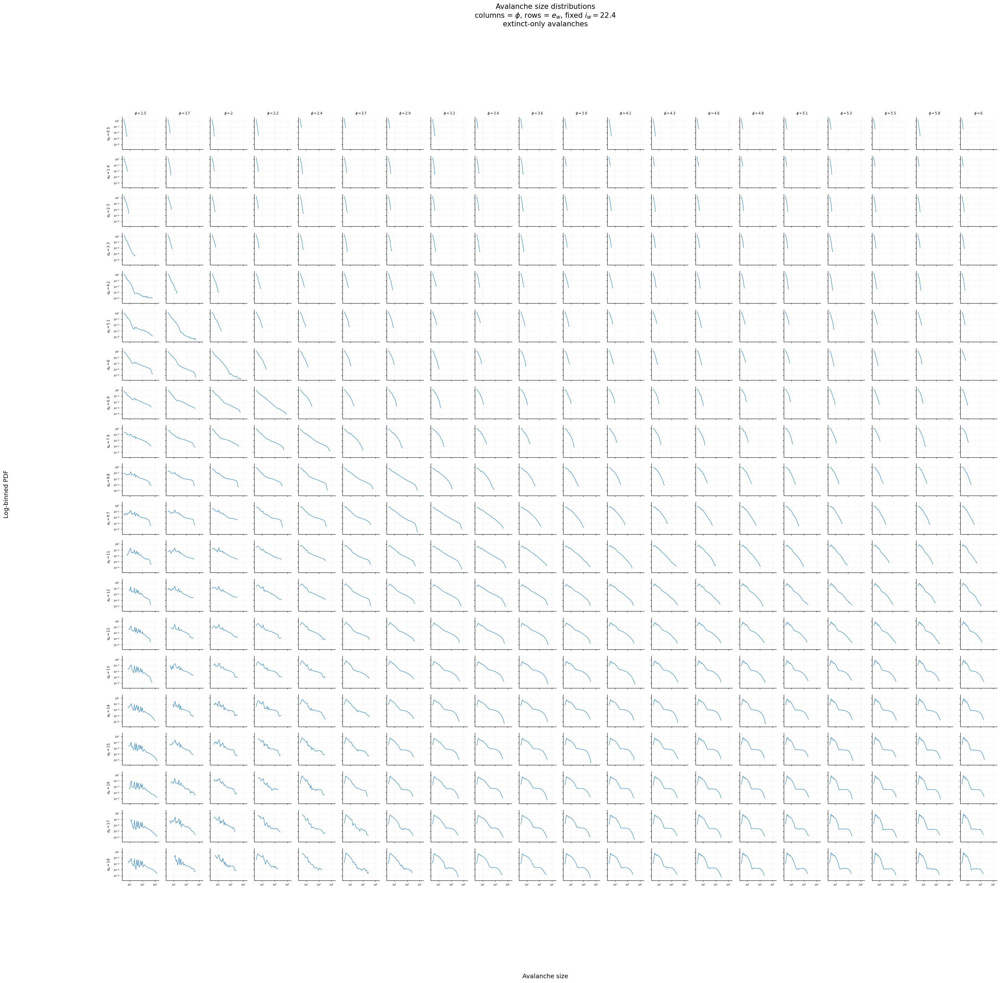

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/avalanche_pdf_grids_phi_cols_ew_rows_fixed_iw/logbinned_pdf_size_phi_cols_ew_rows_fixed_iw_extinct_only.png


Plotting duration:   0%|          | 0/400 [00:00<?, ?it/s]

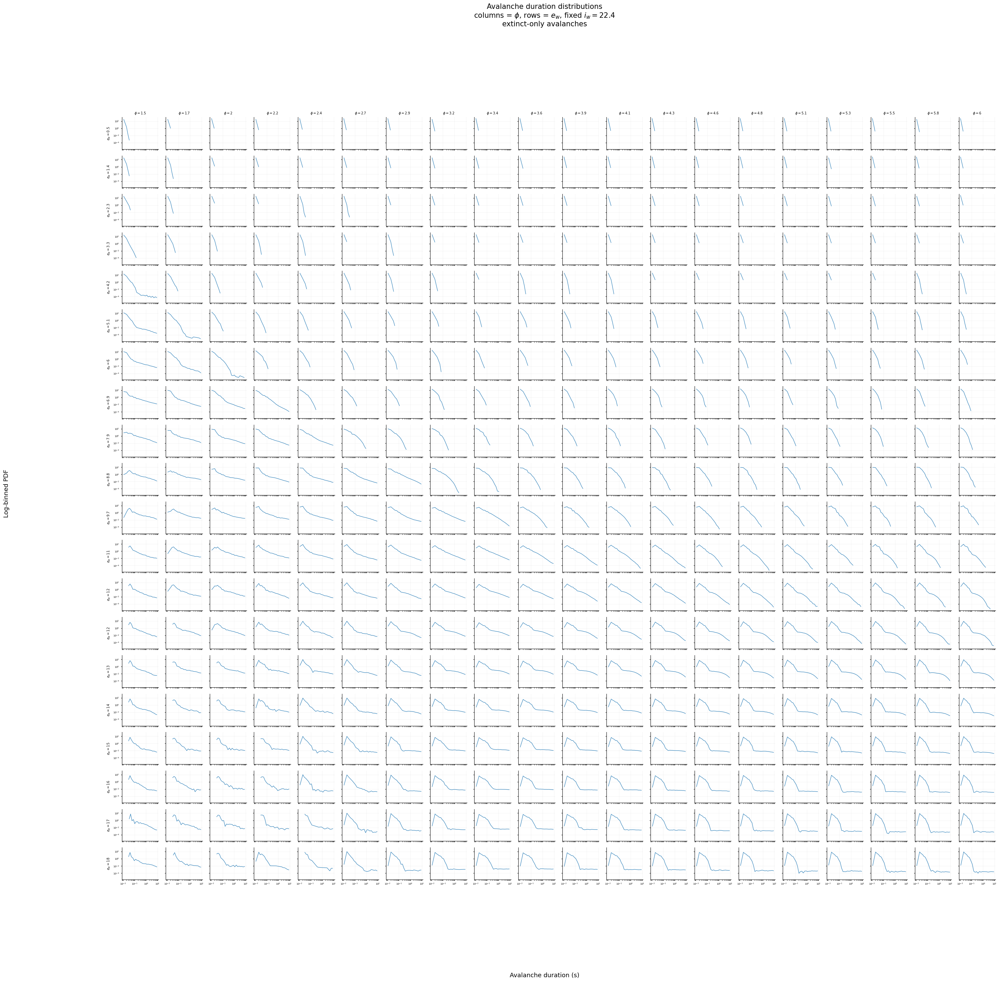

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/avalanche_pdf_grids_phi_cols_ew_rows_fixed_iw/logbinned_pdf_duration_phi_cols_ew_rows_fixed_iw_extinct_only.png
Saved figures to: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/avalanche_pdf_grids_phi_cols_ew_rows_fixed_iw


In [30]:
%matplotlib inline

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ============================================================
# Log-binned avalanche PDFs
# NEW fixed-i_w run
#
# rows    = e_w
# columns = phi
# curve   = all seeds pooled for that e_w / phi
#
# separate figures for size and duration
# works on partial completed run
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals"
)

TRIALDIR = OUTDIR / "avalanche_trials_by_network"
FIGDIR = OUTDIR / "avalanche_pdf_grids_phi_cols_ew_rows_fixed_iw"
FIGDIR.mkdir(exist_ok=True)

DESIGN_PATH = OUTDIR / "grid_design.csv"

EXTINCT_ONLY = True
BINS_PER_DECADE = 8
MIN_POINTS = 20

# Optional speed/memory limiter per panel.
# Set to None to use all avalanches.
MAX_VALUES_PER_PANEL = None  # e.g. 100000

SHOW_EMPTY_TEXT = False


# ============================================================
# Load design and completed avalanche files
# ============================================================

design = pd.read_csv(DESIGN_PATH)

pattern = re.compile(
    r"combo_(\d+)_ewidx_(\d+)_iwidx_(\d+)_phiidx_(\d+)_seed_(\d+)_avalanches\.csv\.gz"
)

completed = []

for path in sorted(TRIALDIR.glob("*_avalanches.csv.gz")):
    m = pattern.search(path.name)
    if m is None:
        continue

    completed.append({
        "combo_i": int(m.group(1)),
        "ew_idx": int(m.group(2)),
        "iw_idx": int(m.group(3)),
        "phi_idx": int(m.group(4)),
        "seed_idx": int(m.group(5)),
        "avalanche_file": str(path),
    })

completed = pd.DataFrame(completed)

if len(completed) == 0:
    raise FileNotFoundError(f"No avalanche files found in {TRIALDIR}")

meta = completed.merge(
    design,
    on=["combo_i", "ew_idx", "iw_idx", "phi_idx", "seed_idx"],
    how="left",
)

print("Completed avalanche files:", len(meta), "/", len(design))
print("Completed fraction:", len(meta) / len(design))

EW_VALUES = np.sort(design["e_w"].unique())
IW_VALUES = np.sort(design["i_w"].unique())
PHI_VALUES = np.sort(design["phi"].unique())

print("e_w values:", len(EW_VALUES))
print("i_w values:", IW_VALUES)
print("phi values:", len(PHI_VALUES))

ew_to_row = {ew: i for i, ew in enumerate(EW_VALUES)}
phi_to_col = {phi: i for i, phi in enumerate(PHI_VALUES)}


# ============================================================
# Helpers
# ============================================================

def logbinned_pdf(values, bins_per_decade=8, min_points=20):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    values = values[values > 0]

    if values.size < min_points:
        return None, None

    xmin = values.min()
    xmax = values.max()

    if xmax <= xmin:
        return None, None

    n_decades = np.log10(xmax) - np.log10(xmin)
    n_bins = max(int(np.ceil(n_decades * bins_per_decade)), 4)

    bins = np.logspace(np.log10(xmin), np.log10(xmax), n_bins + 1)

    counts, edges = np.histogram(values, bins=bins)
    widths = np.diff(edges)
    centres = np.sqrt(edges[:-1] * edges[1:])

    pdf = counts / (counts.sum() * widths)

    keep = (counts > 0) & np.isfinite(pdf) & (pdf > 0)

    return centres[keep], pdf[keep]


def load_values(paths, col, extinct_only=True):
    vals = []

    usecols = [col, "extinct"] if extinct_only else [col]

    for path in paths:
        d = pd.read_csv(path, usecols=usecols)

        if extinct_only:
            d = d[d["extinct"]]

        x = d[col].to_numpy(float)
        x = x[np.isfinite(x)]
        x = x[x > 0]

        if x.size:
            vals.append(x)

    if len(vals) == 0:
        return np.array([])

    x = np.concatenate(vals)

    if MAX_VALUES_PER_PANEL is not None and x.size > MAX_VALUES_PER_PANEL:
        rng = np.random.default_rng(123)
        x = rng.choice(x, size=MAX_VALUES_PER_PANEL, replace=False)

    return x


def clean_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=5, length=2)
    ax.grid(alpha=0.12)


# ============================================================
# Main plotting function
# ============================================================

def plot_metric_grid(metric, col, xlabel, filename):
    nrows = len(EW_VALUES)
    ncols = len(PHI_VALUES)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(1.65 * ncols, 1.45 * nrows),
        sharex=True,
        sharey=True,
    )

    axes = np.asarray(axes)

    grouped = meta.groupby(["e_w", "phi"], sort=True)

    for (e_w, phi), g in tqdm(
        grouped,
        total=grouped.ngroups,
        desc=f"Plotting {metric}",
    ):
        r = ew_to_row[e_w]
        c = phi_to_col[phi]
        ax = axes[r, c]

        paths = g["avalanche_file"].tolist()

        values = load_values(
            paths,
            col=col,
            extinct_only=EXTINCT_ONLY,
        )

        x, y = logbinned_pdf(
            values,
            bins_per_decade=BINS_PER_DECADE,
            min_points=MIN_POINTS,
        )

        if x is None:
            continue

        ax.plot(
            x,
            y,
            linewidth=0.9,
            alpha=0.9,
        )

    # --------------------------------------------------------
    # Axis formatting
    # --------------------------------------------------------

    for r, e_w in enumerate(EW_VALUES):
        for c, phi in enumerate(PHI_VALUES):
            ax = axes[r, c]

            ax.set_xscale("log")
            ax.set_yscale("log")
            clean_axis(ax)

            if r == 0:
                ax.set_title(rf"$\phi={phi:.2g}$", fontsize=7)

            if c == 0:
                ax.set_ylabel(rf"$e_w={e_w:.2g}$", fontsize=7)

            if SHOW_EMPTY_TEXT and len(ax.lines) == 0:
                ax.text(
                    0.5,
                    0.5,
                    "no data",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                    fontsize=5,
                )

    fig.supxlabel(xlabel, fontsize=13)
    fig.supylabel("Log-binned PDF", fontsize=13)

    fixed_iw = IW_VALUES[0] if len(IW_VALUES) == 1 else np.nan

    title = (
        f"Avalanche {metric} distributions\n"
        rf"columns = $\phi$, rows = $e_w$, fixed $i_w={fixed_iw:.3g}$"
    )

    if EXTINCT_ONLY:
        title += "\nextinct-only avalanches"

    fig.suptitle(title, fontsize=15, y=0.995)

    path = FIGDIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", path)


# ============================================================
# Make size and duration figures
# ============================================================

suffix = "_extinct_only" if EXTINCT_ONLY else "_all_avalanches"

plot_metric_grid(
    metric="size",
    col="size",
    xlabel="Avalanche size",
    filename=f"logbinned_pdf_size_phi_cols_ew_rows_fixed_iw{suffix}.png",
)

plot_metric_grid(
    metric="duration",
    col="lifetime_s",
    xlabel="Avalanche duration (s)",
    filename=f"logbinned_pdf_duration_phi_cols_ew_rows_fixed_iw{suffix}.png",
)

print("Saved figures to:", FIGDIR)

Loaded scaling summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/icg_combo_phi_summary_with_minmax_score.csv
Loaded LLR table: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/truncated_powerlaw_vs_lognormal_fixed_iw_exact_llr_safe/truncated_powerlaw_vs_lognormal_by_ew_phi_fixed_iw_safe_extinct_only.csv
Loaded avalanche summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/avalanche_combo_phi_summary.csv


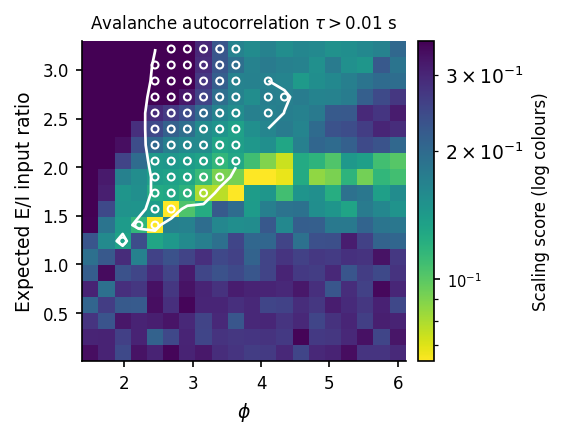

log_score_EI_phi_autocorr_overlay.png: 65 sampled cells satisfy the overlay condition.


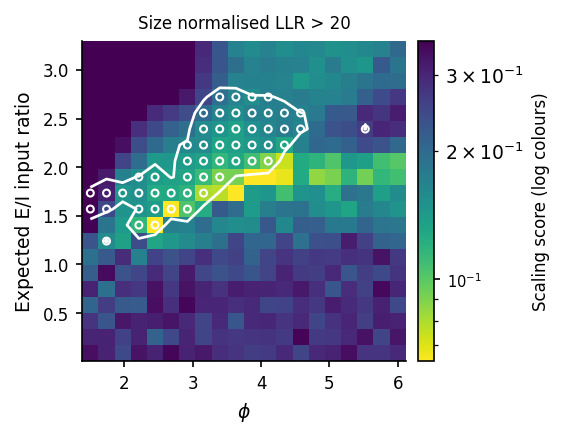

log_score_EI_phi_size_LLR_overlay.png: 54 sampled cells satisfy the overlay condition.


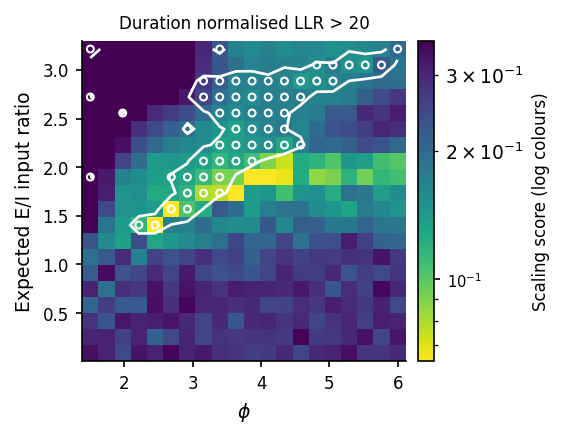

log_score_EI_phi_duration_LLR_overlay.png: 58 sampled cells satisfy the overlay condition.
log_score_EI_phi_joint_size_duration_smoothed.png: no contour threshold crossing.


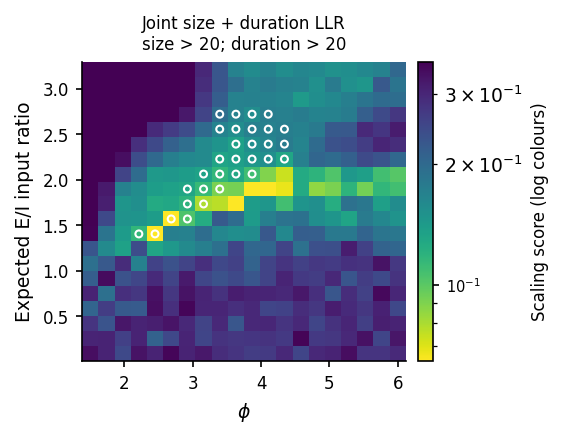

log_score_EI_phi_joint_size_duration_smoothed.png: 31 sampled cells satisfy the overlay condition.

Y-axis = N_E * e_w / (N_I * i_w)
N_E=1600, N_I=400, fixed i_w=22.4
Shared log colour limits: 0.0643349–0.360759
Joint smoothing changes the visual boundary, not the threshold dots.
Saved all four plots to: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_20ew_20phis_20seeds_10000avals/compact_EI_ratio_log_score_four_overlays


In [136]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter, zoom

# ============================================================
# CHANGE SETTINGS HERE
# ============================================================

AUTOCORR_THRESHOLD = 0.01      # seconds
SIZE_LLR_THRESHOLD = 20.0
DURATION_LLR_THRESHOLD = 20.0

AUTOCORR_COL = "mean_avalanche_tau_s_mean"
LLR_COL = "R_truncated_vs_lognormal"

TARGET_ALPHA = 1.50
TARGET_BETA = 0.20

# Expected input FROM E versus I populations, assuming equal
# connection probabilities and per-neuron activity.
N_E = 1600
N_I = 400

FIGSIZE = (3.8, 3.0)
ROBUST_PERCENTILES = (1, 90)
CMAP = "viridis_r"

SHOW_ABOVE_THRESHOLD_POINTS = True
CONTOUR_LINEWIDTH = 1.3
OVERLAY_COLOUR = "white"

# Smooth ONLY the final joint contour.
# Dots and score heatmaps retain their original values.
SMOOTH_JOINT_CONTOUR = True
SMOOTH_SIGMA = 0.01            # original grid cells; larger = smoother
UPSAMPLE = 2                  # finer contour grid

# ============================================================
# Paths
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "20ew_20phis_20seeds_10000avals"
)

FIGDIR = OUTDIR / "compact_EI_ratio_log_score_four_overlays"
FIGDIR.mkdir(parents=True, exist_ok=True)

SD_PATHS = [
    OUTDIR / "icg_combo_phi_summary_with_minmax_score.csv",
    OUTDIR / "icg_combo_phi_summary.csv",
    OUTDIR / "icg_combo_phi_summary_rebuilt_from_files.csv",
]

AV_PATHS = [
    OUTDIR / "avalanche_combo_phi_summary.csv",
    OUTDIR / "avalanche_combo_phi_summary_rebuilt_for_autocorr.csv",
    OUTDIR / "avalanche_combo_phi_summary_rebuilt_for_heatmaps.csv",
]

LLR_PATHS = [
    OUTDIR
    / "truncated_powerlaw_vs_lognormal_fixed_iw_exact_llr_safe_COLOUR_CORRECTED"
    / "truncated_powerlaw_vs_lognormal_by_ew_phi_fixed_iw_safe_extinct_only.csv",

    OUTDIR
    / "truncated_powerlaw_vs_lognormal_fixed_iw_exact_llr_safe"
    / "truncated_powerlaw_vs_lognormal_by_ew_phi_fixed_iw_safe_extinct_only.csv",
]

# ============================================================
# Helpers
# ============================================================

def read_clean(path):
    return pd.read_csv(path).replace([np.inf, -np.inf], np.nan)


def load_first(paths, label):
    path = next((p for p in paths if p.exists()), None)

    if path is None:
        raise FileNotFoundError(
            f"No {label} found. Tried:\n"
            + "\n".join(str(p) for p in paths)
        )

    print(f"Loaded {label}: {path}")
    return read_clean(path)


def cell_edges(centres):
    centres = np.asarray(centres, dtype=float)

    if len(centres) < 2:
        raise ValueError("Need at least two settings per axis.")

    mids = (centres[:-1] + centres[1:]) / 2

    return np.r_[
        centres[0] - (mids[0] - centres[0]),
        mids,
        centres[-1] + (centres[-1] - mids[-1]),
    ]


thresholds = [
    AUTOCORR_THRESHOLD,
    SIZE_LLR_THRESHOLD,
    DURATION_LLR_THRESHOLD,
]

if not all(np.isfinite(t) and t > 0 for t in thresholds):
    raise ValueError("Thresholds must be finite and positive.")

if not np.isfinite(SMOOTH_SIGMA) or SMOOTH_SIGMA < 0:
    raise ValueError("SMOOTH_SIGMA must be finite and nonnegative.")

if not isinstance(UPSAMPLE, int) or UPSAMPLE < 1:
    raise ValueError("UPSAMPLE must be a positive integer.")

# ============================================================
# Load saved data
# ============================================================

sd = load_first(SD_PATHS, "scaling summary")
llr = load_first(LLR_PATHS, "LLR table")

av_path = next((p for p in AV_PATHS if p.exists()), None)

if av_path is not None:
    av = read_clean(av_path)
    print("Loaded avalanche summary:", av_path)

else:
    net = load_first(
        [
            OUTDIR / "avalanche_network_summary.csv",
            OUTDIR / "avalanche_network_summary_partial.csv",
        ],
        "avalanche network summary",
    )

    network_col = AUTOCORR_COL.removesuffix("_mean")

    if network_col not in net.columns:
        raise KeyError(f"Missing network column: {network_col}")

    av = (
        net.groupby(["e_w", "i_w", "phi"], as_index=False)
        .agg(**{
            AUTOCORR_COL: (network_col, "mean"),
        })
    )

# ============================================================
# Select fixed inhibitory weight
# ============================================================

iw_values = np.sort(sd["i_w"].dropna().unique())

if len(iw_values) != 1:
    raise ValueError("Expected one fixed i_w in the scaling grid.")

fixed_iw = float(iw_values[0])

if fixed_iw <= 0 or N_E <= 0 or N_I <= 0:
    raise ValueError("Inhibitory weight and population sizes must be positive.")


def select_fixed_iw(frame):
    if "i_w" not in frame.columns:
        return frame.copy()

    return frame.loc[
        np.isclose(
            frame["i_w"], fixed_iw,
            rtol=1e-8, atol=1e-10,
        )
    ].copy()


sd = select_fixed_iw(sd)
av = select_fixed_iw(av)
llr = select_fixed_iw(llr)

# ============================================================
# NEW scaling score
# Mean of range-normalised distances of mean exponents.
# ============================================================

alpha_range = (
    sd["MV_alpha_mean"].max() - sd["MV_alpha_mean"].min()
)
beta_range = (
    sd["TAU_beta_mean"].max() - sd["TAU_beta_mean"].min()
)

if (
    not np.isfinite(alpha_range)
    or not np.isfinite(beta_range)
    or alpha_range <= 0
    or beta_range <= 0
):
    raise ValueError("Exponent ranges must be finite and positive.")

sd["score_minmax_mean"] = 0.5 * (
    np.abs(sd["MV_alpha_mean"] - TARGET_ALPHA) / alpha_range
    + np.abs(sd["TAU_beta_mean"] - TARGET_BETA) / beta_range
)

# ============================================================
# Common grid and population-weighted E/I coordinates
# ============================================================

EW_VALUES = np.sort(sd["e_w"].dropna().unique())
PHI_VALUES = np.sort(sd["phi"].dropna().unique())

EI_VALUES = N_E * EW_VALUES / (N_I * fixed_iw)

phi_edges = cell_edges(PHI_VALUES)
ei_edges = cell_edges(EI_VALUES)


def grid_values(frame, column):
    if column not in frame.columns:
        raise KeyError(f"Missing column: {column}")

    return (
        frame.pivot_table(
            index="e_w",
            columns="phi",
            values=column,
            aggfunc="mean",
            dropna=False,
        )
        .reindex(index=EW_VALUES, columns=PHI_VALUES)
        .to_numpy(float)
    )


Z_SCORE = grid_values(sd, "score_minmax_mean")
Z_AUTOCORR = grid_values(av, AUTOCORR_COL)

if "fit_ok" in llr.columns:
    fit_ok = (
        llr["fit_ok"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
    )
    llr = llr.loc[fit_ok].copy()

Z_SIZE = grid_values(
    llr.loc[llr["metric"] == "size"],
    LLR_COL,
)

Z_DURATION = grid_values(
    llr.loc[llr["metric"] == "duration"],
    LLR_COL,
)

# ============================================================
# Shared logarithmic score colours
# Zero scores use the lowest displayed colour.
# ============================================================

positive_scores = Z_SCORE[
    np.isfinite(Z_SCORE) & (Z_SCORE > 0)
]

if positive_scores.size == 0:
    raise ValueError("No positive scaling scores for log colours.")

vmin, vmax = np.percentile(
    positive_scores, ROBUST_PERCENTILES
)

if vmax <= vmin:
    vmax = vmin * 1.01

colour_norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)

score_for_plot = np.ma.masked_where(
    ~np.isfinite(Z_SCORE) | (Z_SCORE < 0),
    np.maximum(Z_SCORE, vmin),
)

cmap = plt.get_cmap(CMAP).copy()
cmap.set_bad("0.9")

# ============================================================
# Joint SIZE AND DURATION LLR condition
# Autocorrelation is NOT included in this condition.
# ============================================================

valid_joint = (
    np.isfinite(Z_SIZE)
    & np.isfinite(Z_DURATION)
)

joint_mask = (
    valid_joint
    & (Z_SIZE > SIZE_LLR_THRESHOLD)
    & (Z_DURATION > DURATION_LLR_THRESHOLD)
)

joint_margin = np.minimum(
    Z_SIZE / SIZE_LLR_THRESHOLD - 1,
    Z_DURATION / DURATION_LLR_THRESHOLD - 1,
)

joint_margin[~valid_joint] = np.nan

# ============================================================
# NaN-aware smoothing and finer contour coordinates
# Only used for the final joint contour.
# ============================================================

def smooth_contour_grid(values):
    # Gaussian smoothing is in grid-cell coordinates.
    valid = np.isfinite(values)

    weighted = gaussian_filter(
        np.where(valid, values, 0.0),
        sigma=SMOOTH_SIGMA,
        mode="nearest",
    )

    weights = gaussian_filter(
        valid.astype(float),
        sigma=SMOOTH_SIGMA,
        mode="nearest",
    )

    smoothed = np.divide(
        weighted,
        weights,
        out=np.zeros_like(weighted),
        where=weights > 1e-8,
    )

    # Linear interpolation avoids overshooting the smoothed values.
    fine_values = zoom(
        smoothed,
        zoom=UPSAMPLE,
        order=1,
        mode="nearest",
    )

    # Require all contributing original nodes to be valid.
    fine_support = zoom(
        valid.astype(float),
        zoom=UPSAMPLE,
        order=1,
        mode="nearest",
    )

    fine_values = np.ma.masked_where(
        fine_support < 1.0 - 1e-8,
        fine_values,
    )

    # Map interpolated grid indices to actual axis coordinates.
    fine_phi = np.interp(
        np.linspace(0, len(PHI_VALUES) - 1, fine_values.shape[1]),
        np.arange(len(PHI_VALUES)),
        PHI_VALUES,
    )

    fine_ei = np.interp(
        np.linspace(0, len(EI_VALUES) - 1, fine_values.shape[0]),
        np.arange(len(EI_VALUES)),
        EI_VALUES,
    )

    return fine_phi, fine_ei, fine_values

# ============================================================
# Compact plotting function
# Original values determine dots.
# Smoothed values determine the final contour only.
# ============================================================

def plot_overlay(
    values,
    threshold,
    title,
    filename,
    above_mask=None,
    smooth_contour=False,
):
    fig, ax = plt.subplots(figsize=FIGSIZE)

    im = ax.pcolormesh(
        phi_edges,
        ei_edges,
        score_for_plot,
        shading="flat",
        cmap=cmap,
        norm=colour_norm,
        rasterized=True,
    )

    if smooth_contour:
        contour_x, contour_y, contour_values = smooth_contour_grid(values)
    else:
        contour_x = PHI_VALUES
        contour_y = EI_VALUES
        contour_values = np.ma.masked_invalid(values)

    finite = contour_values.compressed()
    finite = finite[np.isfinite(finite)]

    if (
        finite.size
        and finite.min() < threshold < finite.max()
    ):
        ax.contour(
            contour_x,
            contour_y,
            contour_values,
            levels=[threshold],
            colors=[OVERLAY_COLOUR],
            linewidths=CONTOUR_LINEWIDTH,
            corner_mask=False,
            zorder=2,
        )
    else:
        print(f"{filename}: no contour threshold crossing.")

    if above_mask is None:
        above_mask = (
            np.isfinite(values) & (values > threshold)
        )

    if SHOW_ABOVE_THRESHOLD_POINTS:
        iy, ix = np.where(above_mask)

        ax.scatter(
            PHI_VALUES[ix],
            EI_VALUES[iy],
            s=11,
            facecolors="none",
            edgecolors=OVERLAY_COLOUR,
            linewidths=1,
            zorder=3,
        )

    ax.set(
        xlabel=r"$\phi$",
        ylabel="Expected E/I input ratio",
        title=title,
        xlim=(phi_edges[0], phi_edges[-1]),
        ylim=(ei_edges[0], ei_edges[-1]),
    )

    ax.tick_params(labelsize=8)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)
    ax.title.set_size(8)
    ax.spines[["top", "right"]].set_visible(False)

    cbar = fig.colorbar(im, ax=ax, pad=0.03)
    cbar.set_label("Scaling score (log colours)", fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    fig.tight_layout()
    fig.savefig(
        FIGDIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(
        f"{filename}: {above_mask.sum()} sampled cells "
        "satisfy the overlay condition."
    )

# ============================================================
# 1. Autocorrelation overlay
# ============================================================

plot_overlay(
    values=Z_AUTOCORR,
    threshold=AUTOCORR_THRESHOLD,
    title=(
        rf"Avalanche autocorrelation "
        rf"$\tau>{AUTOCORR_THRESHOLD:g}$ s"
    ),
    filename="log_score_EI_phi_autocorr_overlay.png",
)

# ============================================================
# 2. Size LLR overlay
# ============================================================

plot_overlay(
    values=Z_SIZE,
    threshold=SIZE_LLR_THRESHOLD,
    title=f"Size normalised LLR > {SIZE_LLR_THRESHOLD:g}",
    filename="log_score_EI_phi_size_LLR_overlay.png",
)

# ============================================================
# 3. Duration LLR overlay
# ============================================================

plot_overlay(
    values=Z_DURATION,
    threshold=DURATION_LLR_THRESHOLD,
    title=f"Duration normalised LLR > {DURATION_LLR_THRESHOLD:g}",
    filename="log_score_EI_phi_duration_LLR_overlay.png",
)

# ============================================================
# 4. Joint SIZE + DURATION: smoothed contour + original dots
# ============================================================

plot_overlay(
    values=joint_margin,
    threshold=np.nan,
    title=(
        "Joint size + duration LLR\n"
        f"size > {SIZE_LLR_THRESHOLD:g}; "
        f"duration > {DURATION_LLR_THRESHOLD:g}"
    ),
    filename="log_score_EI_phi_joint_size_duration_smoothed.png",
    above_mask=joint_mask,
    smooth_contour=SMOOTH_JOINT_CONTOUR,
)

print("\nY-axis = N_E * e_w / (N_I * i_w)")
print(f"N_E={N_E}, N_I={N_I}, fixed i_w={fixed_iw:g}")
print(f"Shared log colour limits: {vmin:.6g}–{vmax:.6g}")
print("Joint smoothing changes the visual boundary, not the threshold dots.")
print("Saved all four plots to:", FIGDIR)

In [ ]:
#!/usr/bin/env python3
"""50 x 50 fixed-i_w scan; same dynamics and ICG score as supplied.
Run beside icg_functions.py: python grid_50ew_50phi_llr_tau.py
In a Linux notebook: %run grid_50ew_50phi_llr_tau.py
No simulations execute on import. Completed network jobs are resumable.
"""
import os
for _key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
             "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_key] = "1"

import json
import inspect
import warnings
import contextlib
import io
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import expit
from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits
import powerlaw
import icg_functions as fn

start_dic = {
    "n_neurons": 2000, "T": 10, "dt": 0.01,
    "refractory_steps": 2, "ei_ratio": 0.2,
    "e_w": 11.7, "i_w": 22.4, "theta": 8.44,
    "p_ext": 0.00, "phi": 4.2, "smoothe": 0.05,
}
OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals"
)
TRIALDIR = OUTDIR / "avalanche_trials_by_network"
ICGDIR = OUTDIR / "icg_rows_by_network"
JOBDIR = OUTDIR / "completed_network_jobs"
LLRDIR = OUTDIR / "truncated_powerlaw_vs_lognormal_fixed_iw_exact_llr_safe"

N_WORKERS = 20
N_SEEDS = 20
N_AVALANCHES_PER_NETWORK = 10000
MAX_STEPS = 1000
BASE_SEED = 91919

E_W_RANGE = (0.5, 18.0)
I_W_FIXED = float(start_dic["i_w"])
N_EW, N_IW, N_PHI = 50, 1, 50
EW_VALUES = np.linspace(*E_W_RANGE, N_EW)
IW_VALUES = np.array([I_W_FIXED])
PHI_VALUES = np.linspace(1.5, 6.0, N_PHI)

P_EXT_RUN = 0.0
SEED_ONLY_EXCITATORY = True
CLAMP_ZERO_PRESYNAPTIC_INPUT = True
DT = float(start_dic["dt"])
T_RUN = float(start_dic["T"])
SMOOTHE = float(start_dic["smoothe"])
BURN_IN_S = 2.0
TARGET_MV, TARGET_TAU = 1.50, 0.20
SAVE_AVALANCHE_TRIALS = True
SAVE_ICG_ROWS = True

SIZE_XMIN, DURATION_XMIN = 10, 0.1
EXTINCT_ONLY = True
MIN_N, MIN_TAIL_N, MIN_UNIQUE_TAIL = 100, 50, 3
RESUME = True
# Both estimands are retained. Pooled fits reproduce the previous
# analysis; mean per-network fits supply across-network SEMs.
SAVE_SEED_LLR = True
RUN_POOLED_LLR = True

KEYS = ["combo_i", "ew_idx", "iw_idx", "phi_idx", "phi", "e_w", "i_w"]
FIT_NAME = "truncated_powerlaw_vs_lognormal_by_ew_phi_fixed_iw_safe_extinct_only.csv"


def atomic_csv(df, path, compression=None):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, index=False, compression=compression)
    os.replace(tmp, path)


def atomic_json(value, path):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    # NaN follows Python JSON convention and is read by this script.
    tmp.write_text(json.dumps(value, indent=2))
    os.replace(tmp, path)


def safe_values(x):
    return pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna().to_numpy(float)


def sem(x):
    x = safe_values(x)
    return float(np.std(x, ddof=1) / np.sqrt(x.size)) if x.size > 1 else np.nan


def safe_mean(x):
    x = safe_values(x)
    return float(np.mean(x)) if x.size else np.nan


def safe_percentile(x, q):
    x = safe_values(x)
    return float(np.percentile(x, q)) if x.size else np.nan


def safe_cv(x):
    x = safe_values(x)
    if x.size < 2 or np.mean(x) <= 0:
        return np.nan
    return float(np.std(x, ddof=1) / np.mean(x))


def response_decay_timescale(active_counts, dt):
    x = np.asarray(active_counts, dtype=float)
    if not x.size:
        return np.nan
    peak = float(x.max())
    if peak <= 0:
        return 0.0
    post = x[int(np.argmax(x)):]
    below = np.flatnonzero(post <= peak / np.e)
    return float((below[0] if below.size else post.size - 1) * dt)


def branching_metrics(active_counts, extinct):
    counts = np.asarray(active_counts, dtype=float)
    out = dict(sigma_origin=np.nan, br_reg_slope=np.nan,
               br_reg_intercept=np.nan, br_reg_r2=np.nan, br_n_pairs=0)
    if not counts.size:
        return out
    if extinct:
        x, y = counts, np.r_[counts[1:], 0.0]
    else:
        x, y = counts[:-1], counts[1:]
    keep = np.isfinite(x) & np.isfinite(y) & (x > 0)
    x, y = x[keep], y[keep]
    out["br_n_pairs"] = int(x.size)
    if x.size < 2:
        return out
    denom = float(np.sum(x * x))
    out["sigma_origin"] = float(np.sum(x * y) / denom) if denom > 0 else np.nan
    try:
        X = np.column_stack([np.ones_like(x), x])
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        out["br_reg_intercept"], out["br_reg_slope"] = map(float, beta)
        ss_tot = float(np.sum((y - y.mean()) ** 2))
        out["br_reg_r2"] = (
            float(1 - np.sum((y - X @ beta) ** 2) / ss_tot)
            if ss_tot > 0 else np.nan
        )
    except Exception:
        pass
    return out


def local_connectivity_metrics(A, n_e):
    A = np.asarray(A, dtype=np.uint8)
    return {
        "edge_count": int(A.sum()),
        "mean_out_degree": float(A.sum(axis=1).mean()),
        "std_out_degree": float(A.sum(axis=1).std()),
        "mean_e_out_degree_all": float(A[:n_e, :].sum(axis=1).mean()),
        "mean_e_out_degree_e": float(A[:n_e, :n_e].sum(axis=1).mean()),
        "edge_density": float(A.sum() / max(A.shape[0] * (A.shape[0]-1), 1)),
    }


def pop_autocorr_tau(x, dt, max_lag_s=3.0):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size < 10:
        return np.nan
    x = x - x.mean()
    denom = np.sum(x * x)
    if denom <= 0:
        return np.nan
    max_lag = min(int(max_lag_s / dt), x.size // 2)
    if max_lag < 2:
        return np.nan
    ac = np.empty(max_lag + 1)
    ac[0] = 1.0
    for lag in range(1, max_lag + 1):
        ac[lag] = np.sum(x[:-lag] * x[lag:]) / denom
    ac[~np.isfinite(ac)] = 0
    crossing = np.flatnonzero(ac[1:] <= 0)
    ac_use = ac[:crossing[0]+2] if crossing.size else ac
    return float(np.trapezoid(ac_use, dx=dt))


def fit_power_slope(g, y_col, x_col="mean_cluster_size",
                    exclude_first=True, exclude_last=False, min_points=3):
    d = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[x_col] > 0) & (d[y_col] > 0)].sort_values(x_col)
    if exclude_first and len(d):
        d = d.iloc[1:]
    if exclude_last and len(d):
        d = d.iloc[:-1]
    if len(d) < min_points:
        return np.nan, np.nan, int(len(d))
    x, y = np.log10(d[x_col].to_numpy(float)), np.log10(d[y_col].to_numpy(float))
    slope, intercept = np.polyfit(x, y, 1)
    ss_tot = np.sum((y - y.mean())**2)
    r2 = 1 - np.sum((y - intercept - slope*x)**2)/ss_tot if ss_tot > 0 else np.nan
    return float(slope), float(r2), int(len(d))


def standardise_gen_df(gen_df):
    g = gen_df.copy()
    for source, target in [
        ("corr_kurtosis", "kurtosis_corr"), ("kurtosis_corr", "corr_kurtosis"),
        ("MV_norm", "mean_variance_norm"), ("TAU_norm", "timescale_norm"),
        ("MV", "mean_variance"), ("TAU", "timescale"),
    ]:
        if target not in g and source in g:
            g[target] = g[source]
    return g


def run_seeded_avalanche_sparse(A_e_T, A_i_T, n, n_e, e_w, i_w,
                                theta, refractory_steps, dt, seed_node,
                                rng, max_steps):
    state = np.zeros(n, dtype=np.int16)
    state[int(seed_node)] = 1
    active_counts = np.empty(int(max_steps), dtype=np.int32)
    for step in range(int(max_steps)):
        active = state == 1
        n_active = int(active.sum())
        if n_active == 0:
            duration_steps, censored = int(step), False
            break
        active_counts[step] = n_active
        inp_e = A_e_T @ active[:n_e].astype(np.float32)
        inp_i = A_i_T @ active[n_e:].astype(np.float32)
        p_net = expit(e_w * inp_e - i_w * inp_i - theta)
        if CLAMP_ZERO_PRESYNAPTIC_INPUT:
            p_net[~((inp_e > 0) | (inp_i > 0))] = 0
        new_active = (state == 0) & (rng.random(n) < p_net)
        new_state = np.zeros_like(state)
        new_state[active] = 2
        refractory = state >= 2
        new_state[refractory] = state[refractory] + 1
        new_state[new_state > refractory_steps + 1] = 0
        new_state[new_active] = 1
        state = new_state
        if not np.any(state == 1):
            duration_steps, censored = int(step + 1), False
            break
    else:
        duration_steps, censored = int(max_steps), True

    active_counts = active_counts[:duration_steps].copy()
    extinct = bool(not censored)
    duration_s = float(duration_steps * dt)
    if active_counts.size >= 5 and np.var(active_counts) > 0:
        with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
            warnings.filterwarnings("ignore", message="invalid value encountered in divide",
                                    category=RuntimeWarning)
            avalanche_tau_s = fn.timescale(
                active_counts[np.newaxis, :].astype(float),
                max_lag=min(3.0, max(2 * dt, duration_s / 2)), dt=float(dt))
    else:
        avalanche_tau_s = np.nan
    return {
        "size": int(active_counts.sum()),
        "duration_steps": int(duration_steps), "duration_s": duration_s,
        "lifetime_steps": int(duration_steps), "lifetime_s": duration_s,
        "peak_active": int(active_counts.max()) if active_counts.size else 0,
        "extinct": extinct, "censored": bool(censored),
        "persistent_at_cutoff": bool(censored),
        "mean_active_during_avalanche": safe_mean(active_counts),
        "avalanche_tau_s": float(avalanche_tau_s),
        "response_decay_tau_s": response_decay_timescale(active_counts, dt),
        **branching_metrics(active_counts, extinct),
    }


def empty_fit_result(n_all=0, n_tail=0, fail_reason="failed"):
    return {
        "R_truncated_vs_lognormal": np.nan, "p_truncated_vs_lognormal": np.nan,
        "xmin": np.nan, "alpha_truncated": np.nan, "lambda_truncated": np.nan,
        "mu_lognormal": np.nan, "sigma_lognormal": np.nan,
        "n_all": int(n_all), "n_tail": int(n_tail),
        "tail_fraction": float(n_tail/n_all) if n_all else np.nan,
        "fit_ok": False, "fail_reason": fail_reason,
    }


def fit_truncated_vs_lognormal(values, discrete=False, xmin=None):
    values = np.asarray(values, float)
    values = values[np.isfinite(values) & (values > 0)]
    n_all = int(values.size)
    tail = values[values >= xmin] if xmin is not None else values
    n_tail = int(tail.size)
    if n_all < MIN_N:
        return empty_fit_result(n_all, n_tail, "too_few_total")
    if n_tail < MIN_TAIL_N:
        return empty_fit_result(n_all, n_tail, "too_few_tail_pre")
    if np.unique(tail).size < MIN_UNIQUE_TAIL:
        return empty_fit_result(n_all, n_tail, "too_few_unique_tail_pre")
    try:
        with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()), \
                contextlib.redirect_stderr(io.StringIO()):
            warnings.simplefilter("ignore")
            fit = powerlaw.Fit(values, discrete=discrete, xmin=xmin,
                               estimate_discrete=discrete, verbose=False)
            tail = values[values >= fit.xmin]
            n_tail = int(tail.size)
            if n_tail < MIN_TAIL_N:
                return empty_fit_result(n_all, n_tail, "too_few_tail_post")
            if np.unique(tail).size < MIN_UNIQUE_TAIL:
                return empty_fit_result(n_all, n_tail, "too_few_unique_tail_post")
            R, p = fit.distribution_compare(
                "truncated_power_law", "lognormal", normalized_ratio=True)
            out = {
                "R_truncated_vs_lognormal": float(R),
                "p_truncated_vs_lognormal": float(p), "xmin": float(fit.xmin),
                "alpha_truncated": float(fit.truncated_power_law.alpha),
                "lambda_truncated": float(fit.truncated_power_law.Lambda),
                "mu_lognormal": float(fit.lognormal.mu),
                "sigma_lognormal": float(fit.lognormal.sigma),
            }
        for key, value in out.items():
            if not np.isfinite(value):
                return empty_fit_result(n_all, n_tail, f"nonfinite_{key}")
        return {**out, "n_all": n_all, "n_tail": n_tail,
                "tail_fraction": float(n_tail/n_all), "fit_ok": True, "fail_reason": "ok"}
    except Exception as err:
        return empty_fit_result(n_all, n_tail, type(err).__name__)


METRICS = [("size", "size", True, SIZE_XMIN),
           ("duration", "lifetime_s", False, DURATION_XMIN)]


def job_stem(job):
    return (f"combo_{int(job['combo_i']):04d}_ewidx_{int(job['ew_idx']):02d}_"
            f"iwidx_{int(job['iw_idx']):02d}_phiidx_{int(job['phi_idx']):02d}_"
            f"seed_{int(job['seed_idx']):02d}")


def make_model_kwargs(phi, e_w, i_w, seed):
    pars = dict(start_dic)
    pars.update(phi=float(phi), e_w=float(e_w), i_w=float(i_w), p_ext=float(P_EXT_RUN))
    pars.pop("T", None)
    pars.pop("smoothe", None)
    valid_args = set(inspect.signature(fn.automata_EI_hiermod.__init__).parameters)
    if "phi" not in valid_args and "slope" in valid_args:
        pars["slope"] = pars.pop("phi")
    pars["seed"] = int(seed)
    return {k: v for k, v in pars.items() if k in valid_args}


def run_one_network(job):
    stem = job_stem(job)
    checkpoint = JOBDIR / f"{stem}.json"
    aval_path = TRIALDIR / f"{stem}_avalanches.csv.gz"
    icg_path = ICGDIR / f"{stem}_icg.csv.gz"
    if RESUME and checkpoint.exists():
        if (not SAVE_AVALANCHE_TRIALS or aval_path.exists()) and \
                (not SAVE_ICG_ROWS or icg_path.exists()):
            return json.loads(checkpoint.read_text())

    raw_seed = int(BASE_SEED + job["combo_i"]*100_000_000
                   + job["phi_idx"]*1_000_000 + job["seed_idx"]*10_000)
    # Legacy np.random.seed requires a uint32 seed. The 50-row
    # scan exceeds its limit; preserve original formula then wrap.
    network_seed = raw_seed % (2**32)
    model_kwargs = make_model_kwargs(job["phi"], job["e_w"], job["i_w"], network_seed)
    with threadpool_limits(limits=1):
        model = fn.automata_EI_hiermod(**model_kwargs)
        A = np.asarray(model.A, dtype=np.uint8)
        np.fill_diagonal(A, 0)
        n, n_e = int(model.n), int(model.e)
        conn = local_connectivity_metrics(A, n_e)
        A_e_T = sparse.csr_matrix(A[:n_e, :].T.astype(np.float32))
        A_i_T = sparse.csr_matrix(A[n_e:, :].T.astype(np.float32))
        rng = np.random.default_rng(network_seed + 123)
        identity = {**job, "network_seed": network_seed,
                    "e_w": float(model.e_w), "i_w": float(model.i_w),
                    "theta": float(model.theta), "p_ext": float(model.p_ext)}
        avalanche_rows = []
        for aval_i in range(N_AVALANCHES_PER_NETWORK):
            seed_node = int(rng.integers(0, n_e if SEED_ONLY_EXCITATORY else n))
            out = run_seeded_avalanche_sparse(
                A_e_T, A_i_T, n, n_e, float(model.e_w), float(model.i_w),
                float(model.theta), int(model.refractory_steps), float(model.dt),
                seed_node, rng, MAX_STEPS)
            row = {
                **identity, **conn, **out, "aval_i": aval_i, "seed_node": seed_node,
                "seed_cell_type": "E" if seed_node < n_e else "I",
                "n_neurons": n, "n_e": n_e, "dt": float(model.dt),
                "max_steps": MAX_STEPS, "cutoff_s": float(MAX_STEPS*model.dt),
                "refractory_steps": int(model.refractory_steps),
                "clamp_zero_presynaptic_input": CLAMP_ZERO_PRESYNAPTIC_INPUT,
            }
            row["lifetime_mean_active_density"] = row["size"] / (n*max(row["lifetime_steps"], 1))
            avalanche_rows.append(row)
        adf = pd.DataFrame(avalanche_rows)
        if SAVE_AVALANCHE_TRIALS:
            atomic_csv(adf, aval_path, compression="gzip")
        extinct_g = adf.loc[adf["extinct"]]
        av_summary = {
            **identity, **conn, "n_avalanches": len(adf), "avalanche_file": str(aval_path),
            "frac_extinct": float(adf["extinct"].mean()),
            "frac_persistent_at_cutoff": float(adf["persistent_at_cutoff"].mean()),
        }
        # Same original summaries, plus finite tau counts and
        # extinct-only tau, allowing transparent NaN accounting.
        for prefix, column, qs, include_cv in [
            ("size", "size", [50, 90, 95, 99], True),
            ("lifetime_s", "lifetime_s", [95, 99], True),
            ("peak_active", "peak_active", [95, 99], False),
            ("avalanche_tau_s", "avalanche_tau_s", [50, 90, 95, 99], False),
            ("response_decay_tau_s", "response_decay_tau_s", [95], False),
        ]:
            av_summary[f"mean_{prefix}"] = safe_mean(adf[column])
            for q in qs:
                key = f"median_{prefix}" if q == 50 else f"p{q}_{prefix}"
                av_summary[key] = safe_percentile(adf[column], q)
            if include_cv:
                av_summary[f"cv_{prefix}"] = safe_cv(adf[column])
        for col in ["size", "lifetime_s"]:
            for q in [95, 99]:
                av_summary[f"p{q}_{col}_extinct_only"] = safe_percentile(extinct_g[col], q)
        av_summary["mean_avalanche_tau_s_extinct_only"] = safe_mean(extinct_g["avalanche_tau_s"])
        av_summary["n_valid_avalanche_tau"] = int(safe_values(adf["avalanche_tau_s"]).size)
        av_summary["n_valid_avalanche_tau_extinct_only"] = int(safe_values(extinct_g["avalanche_tau_s"]).size)

        # Preserve original run_model, burn-in and smoothing behaviour.
        spikes, pop_rate = fn.run_model(model, T=T_RUN)
        dt = float(model.dt)
        burn = int(round(BURN_IN_S / dt))
        spikes_use = spikes[:, burn:]
        pop_rate_use = np.asarray(pop_rate[burn:], float)
        active_counts = spikes_use.sum(axis=0).astype(float)
        rho = active_counts / n
        mean_rate = float(spikes_use.mean()/dt)
        spikes_smooth = fn.exp_smooth_spikes(spikes, dt=dt, tau=SMOOTHE)
        # ICG uses full smoothed recording, as in supplied run.
        with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
            warnings.filterwarnings("ignore", message="invalid value encountered in divide",
                                    category=RuntimeWarning)
            metric_row, gen_df = fn.compute_icg_metrics(spikes=spikes_smooth, dt=dt)
        gen_df = standardise_gen_df(gen_df)
        alpha, ar2, an = fit_power_slope(gen_df, "mean_variance_norm")
        beta, br2, bn = fit_power_slope(gen_df, "timescale_norm")
        kurt, kr2, kn = fit_power_slope(gen_df, "kurtosis_corr")
        score = (abs(alpha-TARGET_MV) + 2*abs(beta-TARGET_TAU)
                 if np.isfinite(alpha) and np.isfinite(beta) else np.nan)
        for key, value in {**identity, "smoothe": SMOOTHE, "mean_rate_hz": mean_rate}.items():
            gen_df[key] = value
        if SAVE_ICG_ROWS:
            atomic_csv(gen_df, icg_path, compression="gzip")
        icg_summary = {
            **identity, **conn, "icg_file": str(icg_path),
            "T": T_RUN, "burn_in_s": BURN_IN_S, "smoothe": SMOOTHE,
            "mean_rate_hz": mean_rate,
            "mean_rate_hz_pop_rate": float(pop_rate_use.mean()),
            "median_pop_rate_hz": float(np.median(pop_rate_use)),
            "max_pop_rate_hz": float(pop_rate_use.max()),
            "mean_rho": float(rho.mean()), "std_rho": float(rho.std()),
            "var_rho": float(rho.var()), "susceptibility_N_var_rho": float(n*rho.var()),
            "pop_rate_var": float(pop_rate_use.var()), "pop_rate_std": float(pop_rate_use.std()),
            "pop_rate_cv": safe_cv(pop_rate_use), "active_count_cv": safe_cv(active_counts),
            "autocorr_tau_rho_s": pop_autocorr_tau(rho, dt),
            "autocorr_tau_pop_rate_s": pop_autocorr_tau(pop_rate_use, dt),
            "silent_frac": float(np.mean(active_counts == 0)),
            "active_frac": float(np.mean(active_counts > 0)),
            "mean_active_count": float(active_counts.mean()),
            "p95_active_count": float(np.percentile(active_counts, 95)),
            "p99_active_count": float(np.percentile(active_counts, 99)),
            "max_active_count": float(active_counts.max()),
            "MV_alpha": alpha, "MV_r2": ar2, "MV_n_points": an,
            "TAU_beta": beta, "TAU_r2": br2, "TAU_n_points": bn,
            "KURT_slope": kurt, "KURT_r2": kr2, "KURT_n_points": kn, "score": score,
        }
        # Fit after dynamics, so fitting cannot affect simulation RNG.
        llr_rows = []
        if SAVE_SEED_LLR:
            selected = extinct_g if EXTINCT_ONLY else adf
            for metric, col, discrete, xmin in METRICS:
                res = fit_truncated_vs_lognormal(selected[col].to_numpy(float), discrete, xmin)
                llr_rows.append({**identity, "metric": metric, **res})
        result = {"avalanche": av_summary, "icg": icg_summary, "llr": llr_rows}
        atomic_json(result, checkpoint)  # written only after all stages finish
        return result


def run_pooled_cell(cell):
    rows = []
    metadata = {k: cell[0][k] for k in KEYS}
    values = {metric: [] for metric, *_ in METRICS}
    n_files = 0
    for job in cell:
        path = TRIALDIR / f"{job_stem(job)}_avalanches.csv.gz"
        if not path.exists():
            raise FileNotFoundError(f"Required pooled-fit input missing: {path}")
        d = pd.read_csv(path, usecols=["size", "lifetime_s", "extinct"])
        if EXTINCT_ONLY:
            d = d.loc[d["extinct"]]
        n_files += 1
        for metric, col, *_ in METRICS:
            x = d[col].to_numpy(float)
            values[metric].append(x[np.isfinite(x) & (x > 0)])
    with threadpool_limits(limits=1):
        for metric, _, discrete, xmin in METRICS:
            x = np.concatenate(values[metric])
            fit = fit_truncated_vs_lognormal(x, discrete, xmin)
            rows.append({**metadata, "metric": metric, "n_files": n_files, **fit})
    return rows


def aggregate(df, cols):
    agg = {"n": ("seed_idx", "count")}
    for col in cols:
        agg[f"{col}_mean"] = (col, safe_mean)
        agg[f"{col}_sem"] = (col, sem)
        agg[f"{col}_n_valid"] = (col, lambda x: len(safe_values(x)))
    return df.groupby(KEYS, as_index=False).agg(**agg).sort_values(["combo_i", "phi"])


def peak_width(phi, y, frac=0.5):
    phi, y = np.asarray(phi, float), np.asarray(y, float)
    keep = np.isfinite(phi) & np.isfinite(y)
    phi, y = phi[keep], y[keep]
    if y.size < 3:
        return np.nan, np.nan, np.nan, 0
    j = int(np.argmax(y))
    if y[j] <= 0:
        return float(phi[j]), float(y[j]), np.nan, 0
    above = y >= frac*y[j]
    return float(phi[j]), float(y[j]), float(np.ptp(phi[above])), int(above.sum())


def save_network_tables(results, partial=False):
    av = pd.DataFrame([r["avalanche"] for r in results])
    icg = pd.DataFrame([r["icg"] for r in results])
    llr = pd.DataFrame([row for r in results for row in r["llr"]])
    suffix = "_partial" if partial else ""
    for df, name in [(av, "avalanche_network_summary"), (icg, "icg_seed_summary")]:
        df = df.sort_values(["combo_i", "phi", "seed_idx"])
        atomic_csv(df, OUTDIR / f"{name}{suffix}.csv")
    if len(llr):
        atomic_csv(llr.sort_values(["combo_i", "phi", "seed_idx", "metric"]),
                   LLRDIR / f"normalized_llr_by_network{suffix}.csv")
    return av, icg, llr


def main():
    for directory in [OUTDIR, TRIALDIR, ICGDIR, JOBDIR, LLRDIR]:
        directory.mkdir(parents=True, exist_ok=True)
    config = {
        "scan_type": "e_w_phi_grid_fixed_i_w", "start_dic": start_dic,
        "N_WORKERS": N_WORKERS, "N_SEEDS": N_SEEDS,
        "N_AVALANCHES_PER_NETWORK": N_AVALANCHES_PER_NETWORK,
        "MAX_STEPS": MAX_STEPS, "BASE_SEED": BASE_SEED,
        "EW_VALUES": EW_VALUES.tolist(), "IW_VALUES": IW_VALUES.tolist(),
        "I_W_FIXED": I_W_FIXED, "PHI_VALUES": PHI_VALUES.tolist(),
        "P_EXT_RUN": P_EXT_RUN, "SEED_ONLY_EXCITATORY": SEED_ONLY_EXCITATORY,
        "CLAMP_ZERO_PRESYNAPTIC_INPUT": CLAMP_ZERO_PRESYNAPTIC_INPUT,
        "T_RUN": T_RUN, "SMOOTHE": SMOOTHE, "BURN_IN_S": BURN_IN_S,
        "TARGET_MV": TARGET_MV, "TARGET_TAU": TARGET_TAU,
        "SIZE_XMIN": SIZE_XMIN, "DURATION_XMIN": DURATION_XMIN,
        "EXTINCT_ONLY": EXTINCT_ONLY, "MIN_N": MIN_N,
        "MIN_TAIL_N": MIN_TAIL_N, "MIN_UNIQUE_TAIL": MIN_UNIQUE_TAIL,
        "SAVE_SEED_LLR": SAVE_SEED_LLR, "RUN_POOLED_LLR": RUN_POOLED_LLR,
        "SAVE_AVALANCHE_TRIALS": SAVE_AVALANCHE_TRIALS, "SAVE_ICG_ROWS": SAVE_ICG_ROWS,
        "network_seed_rule": "original_formula_modulo_2**32",
        "score_definition": "abs(alpha-1.5)+2*abs(beta-0.2)",
        "icg_includes_burn_in": True,
    }
    cfg_path = OUTDIR / "config.json"
    if cfg_path.exists():
        prior = json.loads(cfg_path.read_text())
        if prior != config:
            raise ValueError("Existing output config differs. Choose a new OUTDIR.")
    else:
        atomic_json(config, cfg_path)
    jobs = []
    combo_i = 0
    for ew_idx, e_w in enumerate(EW_VALUES):
        for iw_idx, i_w in enumerate(IW_VALUES):
            for phi_idx, phi in enumerate(PHI_VALUES):
                for seed_idx in range(N_SEEDS):
                    jobs.append(dict(combo_i=combo_i, ew_idx=ew_idx, iw_idx=iw_idx,
                                     phi_idx=phi_idx, seed_idx=seed_idx,
                                     e_w=float(e_w), i_w=float(i_w), phi=float(phi)))
            combo_i += 1
    design = pd.DataFrame(jobs)
    atomic_csv(design, OUTDIR / "grid_design.csv")
    # Validate wrapped seeds do not collide within this design.
    seeds = [(BASE_SEED+j["combo_i"]*100_000_000+j["phi_idx"]*1_000_000+
              j["seed_idx"]*10_000) % (2**32) for j in jobs]
    if len(set(seeds)) != len(seeds):
        raise ValueError("Network seed collision.")
    print("OUTDIR:", OUTDIR, flush=True)
    print(f"{N_EW} e_w x {N_PHI} phi x {N_SEEDS} seeds = {len(jobs):,} jobs", flush=True)
    print(f"Avalanches: {len(jobs)*N_AVALANCHES_PER_NETWORK:,}; workers: {N_WORKERS}", flush=True)
    print("Grid spacings:", EW_VALUES[1]-EW_VALUES[0], PHI_VALUES[1]-PHI_VALUES[0], flush=True)
    print("Score uses original weighted definition.", flush=True)
    if "fork" not in mp.get_all_start_methods():
        raise RuntimeError("This script preserves the supplied Linux/fork execution mode.")
    ctx = mp.get_context("fork")
    results = []
    with ctx.Pool(processes=N_WORKERS) as pool:
        for result in tqdm(pool.imap_unordered(run_one_network, jobs, chunksize=1),
                           total=len(jobs), desc="Networks + tau + ICG + seed LLR"):
            results.append(result)
            if len(results) % 100 == 0:
                save_network_tables(results, partial=True)
    av, icg, llr = save_network_tables(results)

    av_cols = [
        "frac_extinct", "frac_persistent_at_cutoff", "mean_size", "p95_size", "p99_size",
        "mean_lifetime_s", "p95_lifetime_s", "p99_lifetime_s", "mean_peak_active",
        "p95_peak_active", "mean_avalanche_tau_s", "median_avalanche_tau_s",
        "p95_avalanche_tau_s", "p99_avalanche_tau_s",
        "mean_response_decay_tau_s", "p95_response_decay_tau_s",
        "mean_avalanche_tau_s_extinct_only",
    ]
    icg_cols = [
        "mean_rate_hz", "mean_rho", "var_rho", "susceptibility_N_var_rho",
        "pop_rate_cv", "autocorr_tau_rho_s", "autocorr_tau_pop_rate_s",
        "MV_alpha", "MV_r2", "TAU_beta", "TAU_r2", "KURT_slope", "KURT_r2", "score",
    ]
    av_agg, icg_agg = aggregate(av, av_cols), aggregate(icg, icg_cols)
    atomic_csv(av_agg, OUTDIR / "avalanche_combo_phi_summary.csv")
    atomic_csv(icg_agg, OUTDIR / "icg_combo_phi_summary.csv")

    if len(llr):
        successful = llr.loc[llr["fit_ok"]].copy()
        grouped = successful.groupby(KEYS+["metric"], as_index=False).agg(
            R_normalized_mean=("R_truncated_vs_lognormal", safe_mean),
            R_normalized_sem=("R_truncated_vs_lognormal", sem),
            n_successful_seed_fits=("R_truncated_vs_lognormal", "count"),
        )
        total = llr.groupby(KEYS+["metric"], as_index=False).agg(
            n_seed_fits=("fit_ok", "size"), n_failed_seed_fits=("fit_ok", lambda x: int((~x).sum())))
        summary = total.merge(grouped, on=KEYS+["metric"], how="left")
        summary["n_successful_seed_fits"] = summary["n_successful_seed_fits"].fillna(0).astype(int)
        atomic_csv(summary, LLRDIR / "normalized_llr_summary_by_phi.csv")
        for metric, *_ in METRICS:
            d = summary.loc[summary["metric"] == metric].rename(
                columns={"R_normalized_mean": "R_mean", "R_normalized_sem": "R_sem"})
            atomic_csv(d.sort_values(["e_w", "phi"]),
                       LLRDIR / f"{metric}_mean_llr_phi_by_ew_fixed_iw_safe.csv")
            atomic_csv(d.sort_values(["phi", "e_w"]),
                       LLRDIR / f"{metric}_mean_llr_ew_by_phi_fixed_iw_safe.csv")

    combo_rows = []
    for combo, g in av_agg.groupby("combo_i", sort=True):
        g = g.sort_values("phi")
        ig = icg_agg.loc[icg_agg["combo_i"] == combo]
        pp, pt, width, nabove = peak_width(g["phi"], g["mean_avalanche_tau_s_mean"])
        finite = ig["score_mean"].dropna()
        combo_rows.append({
            **{k: g[k].iloc[0].item() if hasattr(g[k].iloc[0], "item") else g[k].iloc[0]
               for k in ["combo_i", "ew_idx", "iw_idx", "e_w", "i_w"]},
            "autocorr_peak_phi": pp, "autocorr_peak_tau_s": pt,
            "autocorr_peak_width_phi": width, "autocorr_n_phi_above_halfmax": nabove,
            "mean_persistent_fraction": safe_mean(g["frac_persistent_at_cutoff_mean"]),
            "max_persistent_fraction": float(g["frac_persistent_at_cutoff_mean"].max()),
            "mean_avalanche_tau_s_across_phi": safe_mean(g["mean_avalanche_tau_s_mean"]),
            "max_avalanche_tau_s_across_phi": float(g["mean_avalanche_tau_s_mean"].max()),
            "best_scaling_score": float(finite.min()) if len(finite) else np.nan,
            "best_scaling_phi": float(ig.loc[finite.idxmin(), "phi"]) if len(finite) else np.nan,
            "max_scaling_score": float(finite.max()) if len(finite) else np.nan,
            "max_scaling_phi": float(ig.loc[finite.idxmax(), "phi"]) if len(finite) else np.nan,
            "max_MV_alpha": float(ig["MV_alpha_mean"].max()),
            "max_TAU_beta": float(ig["TAU_beta_mean"].max()),
            "max_KURT_slope": float(ig["KURT_slope_mean"].max()),
            "max_autocorr_tau_rho_s": float(ig["autocorr_tau_rho_s_mean"].max()),
        })
    ranked = pd.DataFrame(combo_rows).sort_values(
        ["autocorr_peak_width_phi", "autocorr_peak_tau_s"], ascending=[True, False])
    atomic_csv(ranked, OUTDIR / "combo_summary_ranked.csv")

    finite_grid = icg_agg.loc[np.isfinite(icg_agg["score_mean"])].copy()
    extrema = []
    if len(finite_grid):
        for label, index in [("minimum", finite_grid["score_mean"].idxmin()),
                             ("maximum", finite_grid["score_mean"].idxmax())]:
            row = finite_grid.loc[index]
            extrema.append({"extremum": label,
                            **{key: row[key] for key in KEYS},
                            "score_mean": row["score_mean"],
                            "score_sem": row["score_sem"]})
    atomic_csv(pd.DataFrame(extrema, columns=["extremum"]+KEYS+["score_mean", "score_sem"]),
               OUTDIR / "score_grid_extrema.csv")

    if RUN_POOLED_LLR:
        cells = [g.to_dict("records") for _, g in design.groupby(["e_w", "i_w", "phi"], sort=True)]
        pooled_rows = []
        with ctx.Pool(processes=N_WORKERS) as pool:
            for rows in tqdm(pool.imap_unordered(run_pooled_cell, cells, chunksize=1),
                             total=len(cells), desc="Original pooled-seed LLR fits"):
                pooled_rows.extend(rows)
                if len(pooled_rows) % 100 == 0:
                    atomic_csv(pd.DataFrame(pooled_rows), LLRDIR / "pooled_llr_partial.csv")
        pooled = pd.DataFrame(pooled_rows).sort_values(["e_w", "phi", "metric"])
        atomic_csv(pooled, LLRDIR / FIT_NAME)
        # Pooled fits have one result per cell and NO seed-level SEM.

    print(ranked.head(20).to_string(index=False))
    print("Done. Saved simulations, tau, ICG, seed LLRs and pooled LLRs to:", OUTDIR)


if __name__ == "__main__":
    main()



Completed networks: 50,000/50,000 (100.00%)


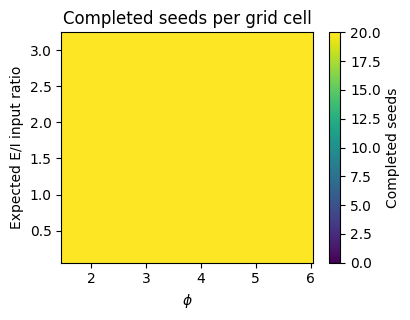

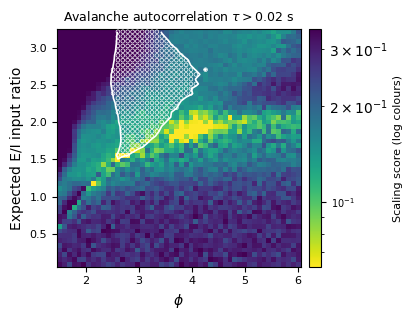

314 displayed cells satisfy: Avalanche autocorrelation $\tau>0.02$ s


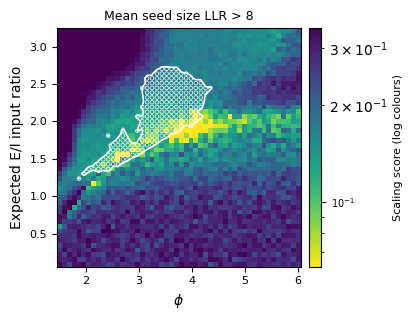

210 displayed cells satisfy: Mean seed size LLR > 8


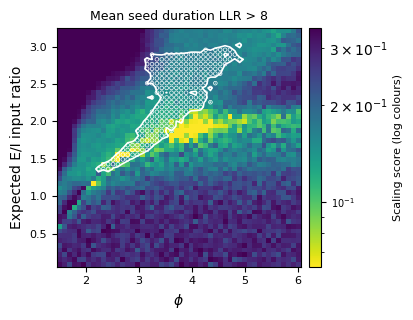

238 displayed cells satisfy: Mean seed duration LLR > 8


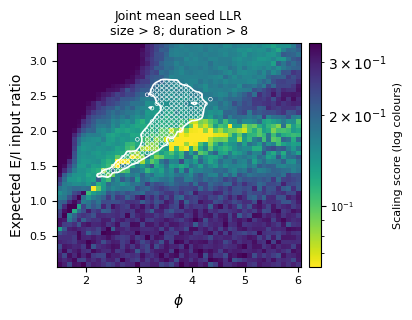

152 displayed cells satisfy: Joint mean seed LLR
size > 8; duration > 8
Exponent ranges: alpha=0.769239, beta=0.458077
Log colour limits: 0.0630964–0.345933
Y-axis = 1600 × e_w / (400 × 22.4)


In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter, zoom

# ============================================================
# SETTINGS
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "50ew_50phis_20seeds_10000avals"
)

JOBDIR = OUTDIR / "completed_network_jobs"

AUTOCORR_THRESHOLD = 0.02
SIZE_LLR_THRESHOLD = 8.0
DURATION_LLR_THRESHOLD = 8.0

TARGET_ALPHA = 1.50
TARGET_BETA = 0.20

N_E, N_I = 1600, 400

# Show means once this many networks have completed per cell.
MIN_COMPLETED_SEEDS = 1

# LLR overlays additionally require this many successful fits.
MIN_SUCCESSFUL_LLR_FITS = 1

ROBUST_PERCENTILES = (1, 90)
CMAP = "viridis_r"
FIGSIZE = (4.2, 3.3)

SHOW_ABOVE_THRESHOLD_POINTS = True
SMOOTH_JOINT_CONTOUR = True
SMOOTH_SIGMA = 0.01
UPSAMPLE = 2

# Optional: save figures on the computer running this notebook.
SAVE_FIGURES = False
FIGDIR = OUTDIR / "live_score_overlays"

# Cache checkpoints between cell reruns: read only new/changed files.
if "_live_checkpoint_cache" not in globals():
    _live_checkpoint_cache = {}


# ============================================================
# HELPERS
# ============================================================

def cell_edges(centres):
    centres = np.asarray(centres, float)
    mids = (centres[:-1] + centres[1:]) / 2
    return np.r_[
        centres[0] - (mids[0] - centres[0]),
        mids,
        centres[-1] + (centres[-1] - mids[-1]),
    ]


def load_checkpoints():
    paths = sorted(JOBDIR.glob("*.json"))

    for path in paths:
        stat = path.stat()
        signature = (stat.st_mtime_ns, stat.st_size)
        cached = _live_checkpoint_cache.get(path)

        if cached is None or cached[0] != signature:
            # Final .json files are published by atomic rename.
            result = json.loads(path.read_text())
            _live_checkpoint_cache[path] = (signature, result)

    return [_live_checkpoint_cache[p][1] for p in paths]


def smooth_contour_grid(values, phi_values, ei_values):
    valid = np.isfinite(values)

    weighted = gaussian_filter(
        np.where(valid, values, 0.0),
        sigma=SMOOTH_SIGMA,
        mode="nearest",
    )
    weights = gaussian_filter(
        valid.astype(float),
        sigma=SMOOTH_SIGMA,
        mode="nearest",
    )

    smoothed = np.divide(
        weighted,
        weights,
        out=np.zeros_like(weighted),
        where=weights > 1e-8,
    )

    fine_values = zoom(
        smoothed, UPSAMPLE, order=1, mode="nearest"
    )
    fine_support = zoom(
        valid.astype(float), UPSAMPLE, order=1, mode="nearest"
    )

    # Do not interpolate contours across unfinished cells.
    fine_values = np.ma.masked_where(
        fine_support < 1.0 - 1e-8, fine_values
    )

    fine_phi = np.interp(
        np.linspace(0, len(phi_values) - 1, fine_values.shape[1]),
        np.arange(len(phi_values)),
        phi_values,
    )
    fine_ei = np.interp(
        np.linspace(0, len(ei_values) - 1, fine_values.shape[0]),
        np.arange(len(ei_values)),
        ei_values,
    )

    return fine_phi, fine_ei, fine_values


# ============================================================
# REFRESH FUNCTION
# ============================================================

def plot_current_run():
    config = json.loads((OUTDIR / "config.json").read_text())

    # Use the FULL planned grid, including unfinished cells.
    ew_values = np.asarray(config["EW_VALUES"], float)
    phi_values = np.asarray(config["PHI_VALUES"], float)
    fixed_iw = float(config["I_W_FIXED"])
    n_seeds = int(config["N_SEEDS"])

    ei_values = N_E * ew_values / (N_I * fixed_iw)
    phi_edges = cell_edges(phi_values)
    ei_edges = cell_edges(ei_values)

    results = load_checkpoints()

    total_jobs = len(ew_values) * len(phi_values) * n_seeds
    print(
        f"Completed networks: {len(results):,}/{total_jobs:,} "
        f"({100 * len(results) / total_jobs:.2f}%)"
    )

    if not results:
        print("No completed network checkpoints yet. Rerun later.")
        return

    icg = pd.DataFrame([r["icg"] for r in results])
    av = pd.DataFrame([r["avalanche"] for r in results])
    llr = pd.DataFrame([
        row for r in results for row in r.get("llr", [])
    ])

    for frame in (icg, av, llr):
        frame.replace([np.inf, -np.inf], np.nan, inplace=True)

    keys = ["ew_idx", "phi_idx"]

    sd = icg.groupby(keys, as_index=False).agg(
        n_completed=("seed_idx", "nunique"),
        MV_alpha_mean=("MV_alpha", "mean"),
        TAU_beta_mean=("TAU_beta", "mean"),
    )

    av_summary = av.groupby(keys, as_index=False).agg(
        mean_avalanche_tau_s_mean=("mean_avalanche_tau_s", "mean"),
    )

    def grid(frame, column):
        if frame.empty:
            return np.full(
                (len(ew_values), len(phi_values)), np.nan
            )

        return (
            frame.pivot_table(
                index="ew_idx",
                columns="phi_idx",
                values=column,
                aggfunc="mean",
            )
            .reindex(
                index=np.arange(len(ew_values)),
                columns=np.arange(len(phi_values)),
            )
            .to_numpy(float)
        )

    counts = np.nan_to_num(grid(sd, "n_completed"), nan=0)
    enough_completed = counts >= MIN_COMPLETED_SEEDS

    # ========================================================
    # COMPLETION MAP
    # ========================================================

    fig, ax = plt.subplots(figsize=FIGSIZE)
    im = ax.pcolormesh(
        phi_edges, ei_edges, counts,
        shading="flat", cmap="viridis",
        vmin=0, vmax=n_seeds,
    )
    ax.set(
        xlabel=r"$\phi$",
        ylabel="Expected E/I input ratio",
        title="Completed seeds per grid cell",
    )
    fig.colorbar(im, ax=ax, label="Completed seeds")
    fig.tight_layout()

    if SAVE_FIGURES:
        FIGDIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            FIGDIR / "completed_seeds.png",
            dpi=300, bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    # ========================================================
    # RANGE-NORMALISED SCALING SCORE
    # Same definition as your example, using available cells.
    # ========================================================

    sd = sd.loc[
        sd["n_completed"] >= MIN_COMPLETED_SEEDS
    ].copy()

    alpha_range = sd["MV_alpha_mean"].max() - sd["MV_alpha_mean"].min()
    beta_range = sd["TAU_beta_mean"].max() - sd["TAU_beta_mean"].min()

    if (
        not np.isfinite(alpha_range)
        or not np.isfinite(beta_range)
        or alpha_range <= 0
        or beta_range <= 0
    ):
        print(
            "Not enough variation in completed exponent estimates "
            "to calculate the range-normalised score yet."
        )
        return

    sd["score_minmax_mean"] = 0.5 * (
        abs(sd["MV_alpha_mean"] - TARGET_ALPHA) / alpha_range
        + abs(sd["TAU_beta_mean"] - TARGET_BETA) / beta_range
    )

    z_score = grid(sd, "score_minmax_mean")
    z_tau = grid(av_summary, "mean_avalanche_tau_s_mean")
    z_tau[~enough_completed] = np.nan

    # ========================================================
    # MEAN SUCCESSFUL SEED-LEVEL LLRs
    # ========================================================

    z_size = np.full_like(z_score, np.nan)
    z_duration = np.full_like(z_score, np.nan)

    if not llr.empty:
        fit_ok = (
            llr["fit_ok"].astype(str).str.lower()
            .isin(["true", "1", "1.0"])
        )
        successful = llr.loc[fit_ok].copy()

        for metric, target_grid in [
            ("size", z_size),
            ("duration", z_duration),
        ]:
            selected = successful.loc[
                successful["metric"] == metric
            ]

            summary = selected.groupby(keys, as_index=False).agg(
                R_mean=("R_truncated_vs_lognormal", "mean"),
                n_successful=("R_truncated_vs_lognormal", "count"),
            )

            summary.loc[
                summary["n_successful"] < MIN_SUCCESSFUL_LLR_FITS,
                "R_mean",
            ] = np.nan

            target_grid[:] = grid(summary, "R_mean")
            target_grid[~enough_completed] = np.nan

    # ========================================================
    # SHARED LOG COLOUR SCALE
    # ========================================================

    positive = z_score[np.isfinite(z_score) & (z_score > 0)]

    if not positive.size:
        print("No positive scaling scores for logarithmic colours yet.")
        return

    vmin, vmax = np.percentile(positive, ROBUST_PERCENTILES)
    if vmax <= vmin:
        vmax = vmin * 1.01

    norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)
    cmap = plt.get_cmap(CMAP).copy()
    cmap.set_bad("0.9")

    score_plot = np.ma.masked_invalid(
        np.maximum(z_score, vmin)
    )

    # ========================================================
    # JOINT CONDITION: BOTH LLR THRESHOLDS
    # Boundary is joint_margin = 0.
    # ========================================================

    valid_joint = np.isfinite(z_size) & np.isfinite(z_duration)

    joint_mask = (
        valid_joint
        & (z_size > SIZE_LLR_THRESHOLD)
        & (z_duration > DURATION_LLR_THRESHOLD)
    )

    joint_margin = np.minimum(
        z_size / SIZE_LLR_THRESHOLD - 1,
        z_duration / DURATION_LLR_THRESHOLD - 1,
    )
    joint_margin[~valid_joint] = np.nan

    def plot_overlay(
        values, threshold, title, filename,
        above_mask=None, smooth=False,
    ):
        fig, ax = plt.subplots(figsize=FIGSIZE)

        im = ax.pcolormesh(
            phi_edges, ei_edges, score_plot,
            shading="flat",
            cmap=cmap, norm=norm,
            rasterized=True,
        )

        if smooth:
            cx, cy, cz = smooth_contour_grid(
                values, phi_values, ei_values
            )
        else:
            cx, cy = phi_values, ei_values
            cz = np.ma.masked_invalid(values)

        finite = cz.compressed()

        if (
            finite.size
            and finite.min() < threshold < finite.max()
        ):
            ax.contour(
                cx, cy, cz,
                levels=[threshold],
                colors="white",
                linewidths=1.2,
                corner_mask=False,
                zorder=2,
            )

        if above_mask is None:
            above_mask = np.isfinite(values) & (values > threshold)

        # Draw overlays only where the score background exists.
        above_mask = above_mask & np.isfinite(z_score)

        if SHOW_ABOVE_THRESHOLD_POINTS:
            iy, ix = np.where(above_mask)
            ax.scatter(
                phi_values[ix], ei_values[iy],
                s=7,
                facecolors="none",
                edgecolors="white",
                linewidths=0.5,
                zorder=3,
            )

        ax.set(
            xlabel=r"$\phi$",
            ylabel="Expected E/I input ratio",
            title=title,
            xlim=(phi_edges[0], phi_edges[-1]),
            ylim=(ei_edges[0], ei_edges[-1]),
        )
        ax.tick_params(labelsize=8)
        ax.title.set_size(9)

        cbar = fig.colorbar(im, ax=ax, pad=0.03)
        cbar.set_label("Scaling score (log colours)", fontsize=8)
        cbar.ax.tick_params(labelsize=7)

        fig.tight_layout()

        if SAVE_FIGURES:
            FIGDIR.mkdir(parents=True, exist_ok=True)
            fig.savefig(
                FIGDIR / filename,
                dpi=300, bbox_inches="tight",
            )

        plt.show()
        plt.close(fig)

        print(f"{above_mask.sum()} displayed cells satisfy: {title}")

    plot_overlay(
        z_tau,
        AUTOCORR_THRESHOLD,
        rf"Avalanche autocorrelation $\tau>{AUTOCORR_THRESHOLD:g}$ s",
        "autocorr_overlay.png",
    )

    plot_overlay(
        z_size,
        SIZE_LLR_THRESHOLD,
        f"Mean seed size LLR > {SIZE_LLR_THRESHOLD:g}",
        "size_LLR_overlay.png",
    )

    plot_overlay(
        z_duration,
        DURATION_LLR_THRESHOLD,
        f"Mean seed duration LLR > {DURATION_LLR_THRESHOLD:g}",
        "duration_LLR_overlay.png",
    )

    plot_overlay(
        joint_margin,
        0.0,
        (
            "Joint mean seed LLR\n"
            f"size > {SIZE_LLR_THRESHOLD:g}; "
            f"duration > {DURATION_LLR_THRESHOLD:g}"
        ),
        "joint_LLR_overlay.png",
        above_mask=joint_mask,
        smooth=SMOOTH_JOINT_CONTOUR,
    )

    print(f"Exponent ranges: alpha={alpha_range:.6g}, beta={beta_range:.6g}")
    print(f"Log colour limits: {vmin:.6g}–{vmax:.6g}")
    print(f"Y-axis = {N_E} × e_w / ({N_I} × {fixed_iw:g})")


# Run again whenever you want to refresh.
plot_current_run()

Completed networks: 50,000/50,000 (100.00%)


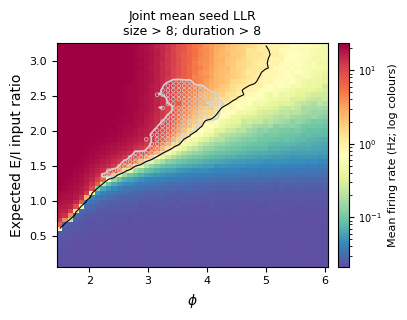

Log firing-rate colour limits: 0.0212281–23.2233 Hz
152 displayed cells satisfy: Joint mean seed LLR
size > 8; duration > 8
Y-axis = 1600 × e_w / (400 × 22.4)


In [21]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter, zoom

# ============================================================
# SETTINGS
# ============================================================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "50ew_50phis_20seeds_10000avals"
)

JOBDIR = OUTDIR / "completed_network_jobs"

SIZE_LLR_THRESHOLD = 8.0
DURATION_LLR_THRESHOLD = 8.0

FR_CONTOUR_HZ = 1.0
FR_CONTOUR_LINEWIDTH = 0.8

N_E, N_I = 1600, 400

MIN_COMPLETED_SEEDS = 1
MIN_SUCCESSFUL_LLR_FITS = 1

ROBUST_PERCENTILES = (1, 90)
FIGSIZE = (4.2, 3.3)

SHOW_ABOVE_THRESHOLD_POINTS = True
SMOOTH_JOINT_CONTOUR = True
SMOOTH_SIGMA = 0.01
UPSAMPLE = 2

SAVE_FIGURES = False
FIGDIR = OUTDIR / "live_score_overlays"

if "_live_checkpoint_cache" not in globals():
    _live_checkpoint_cache = {}


# ============================================================
# HELPERS
# ============================================================

def cell_edges(centres):
    centres = np.asarray(centres, float)
    mids = (centres[:-1] + centres[1:]) / 2
    return np.r_[
        centres[0] - (mids[0] - centres[0]),
        mids,
        centres[-1] + (centres[-1] - mids[-1]),
    ]


def load_checkpoints():
    paths = sorted(JOBDIR.glob("*.json"))

    for path in paths:
        stat = path.stat()
        signature = (stat.st_mtime_ns, stat.st_size)
        cached = _live_checkpoint_cache.get(path)

        if cached is None or cached[0] != signature:
            result = json.loads(path.read_text())
            _live_checkpoint_cache[path] = (signature, result)

    return [_live_checkpoint_cache[p][1] for p in paths]


def smooth_contour_grid(values, phi_values, ei_values):
    valid = np.isfinite(values)

    weighted = gaussian_filter(
        np.where(valid, values, 0.0),
        sigma=SMOOTH_SIGMA,
        mode="nearest",
    )
    weights = gaussian_filter(
        valid.astype(float),
        sigma=SMOOTH_SIGMA,
        mode="nearest",
    )

    smoothed = np.divide(
        weighted,
        weights,
        out=np.zeros_like(weighted),
        where=weights > 1e-8,
    )

    fine_values = zoom(
        smoothed, UPSAMPLE, order=1, mode="nearest"
    )
    fine_support = zoom(
        valid.astype(float), UPSAMPLE, order=1, mode="nearest"
    )

    # Do not interpolate contours across unfinished cells.
    fine_values = np.ma.masked_where(
        fine_support < 1.0 - 1e-8, fine_values
    )

    fine_phi = np.interp(
        np.linspace(0, len(phi_values) - 1, fine_values.shape[1]),
        np.arange(len(phi_values)),
        phi_values,
    )
    fine_ei = np.interp(
        np.linspace(0, len(ei_values) - 1, fine_values.shape[0]),
        np.arange(len(ei_values)),
        ei_values,
    )

    return fine_phi, fine_ei, fine_values


# ============================================================
# MEAN FIRING RATE + JOINT LLR OVERLAY + 1 Hz CONTOUR
# ============================================================

def plot_current_firing_rate():
    config = json.loads((OUTDIR / "config.json").read_text())

    phi_values = np.asarray(config["PHI_VALUES"], float)
    ew_values = np.asarray(config["EW_VALUES"], float)
    fixed_iw = float(config["I_W_FIXED"])
    n_seeds = int(config["N_SEEDS"])

    ei_values = N_E * ew_values / (N_I * fixed_iw)
    phi_edges = cell_edges(phi_values)
    ei_edges = cell_edges(ei_values)

    results = load_checkpoints()

    total_jobs = len(ew_values) * len(phi_values) * n_seeds
    print(
        f"Completed networks: {len(results):,}/{total_jobs:,} "
        f"({100 * len(results) / total_jobs:.2f}%)"
    )

    if not results:
        print("No completed network checkpoints yet.")
        return

    icg = pd.DataFrame([r["icg"] for r in results])
    llr = pd.DataFrame([
        row for r in results for row in r.get("llr", [])
    ])

    for frame in (icg, llr):
        frame.replace([np.inf, -np.inf], np.nan, inplace=True)

    if "mean_rate_hz" not in icg.columns:
        raise KeyError(
            "Expected 'mean_rate_hz' in checkpoint 'icg' records. "
            f"Available columns: {icg.columns.tolist()}"
        )

    keys = ["ew_idx", "phi_idx"]

    sd = icg.groupby(keys, as_index=False).agg(
        n_completed=("seed_idx", "nunique"),
        mean_rate_hz_mean=("mean_rate_hz", "mean"),
    )

    def grid(frame, column):
        if frame.empty:
            return np.full(
                (len(ew_values), len(phi_values)), np.nan
            )

        return (
            frame.pivot_table(
                index="ew_idx",
                columns="phi_idx",
                values=column,
                aggfunc="mean",
            )
            .reindex(
                index=np.arange(len(ew_values)),
                columns=np.arange(len(phi_values)),
            )
            .to_numpy(float)
        )

    counts = np.nan_to_num(grid(sd, "n_completed"), nan=0)
    enough_completed = counts >= MIN_COMPLETED_SEEDS

    z_rate = grid(sd, "mean_rate_hz_mean")
    z_rate[~enough_completed] = np.nan

    # ========================================================
    # MEAN SUCCESSFUL SEED-LEVEL LLRs
    # ========================================================

    z_size = np.full_like(z_rate, np.nan)
    z_duration = np.full_like(z_rate, np.nan)

    if not llr.empty:
        fit_ok = (
            llr["fit_ok"].astype(str).str.lower()
            .isin(["true", "1", "1.0"])
        )
        successful = llr.loc[fit_ok].copy()

        for metric, target_grid in [
            ("size", z_size),
            ("duration", z_duration),
        ]:
            selected = successful.loc[
                successful["metric"] == metric
            ]

            summary = selected.groupby(keys, as_index=False).agg(
                R_mean=("R_truncated_vs_lognormal", "mean"),
                n_successful=("R_truncated_vs_lognormal", "count"),
            )

            summary.loc[
                summary["n_successful"] < MIN_SUCCESSFUL_LLR_FITS,
                "R_mean",
            ] = np.nan

            target_grid[:] = grid(summary, "R_mean")
            target_grid[~enough_completed] = np.nan

    # ========================================================
    # JOINT LLR CONDITION
    # ========================================================

    valid_joint = np.isfinite(z_size) & np.isfinite(z_duration)

    joint_mask = (
        valid_joint
        & (z_size > SIZE_LLR_THRESHOLD)
        & (z_duration > DURATION_LLR_THRESHOLD)
        & np.isfinite(z_rate)
        & (z_rate >= 0)
    )

    joint_margin = np.minimum(
        z_size / SIZE_LLR_THRESHOLD - 1,
        z_duration / DURATION_LLR_THRESHOLD - 1,
    )
    joint_margin[~valid_joint] = np.nan

    # ========================================================
    # LOG FIRING-RATE COLOUR SCALE
    # ========================================================

    positive_rates = z_rate[
        np.isfinite(z_rate) & (z_rate > 0)
    ]

    if positive_rates.size == 0:
        print("No positive mean firing rates for log colours.")
        return

    rate_vmin, rate_vmax = np.percentile(
        positive_rates, ROBUST_PERCENTILES
    )

    if rate_vmax <= rate_vmin:
        rate_vmax = rate_vmin * 1.01

    rate_norm = LogNorm(
        vmin=rate_vmin,
        vmax=rate_vmax,
        clip=True,
    )

    # Zero rates use the lowest colour; missing cells are grey.
    rate_for_plot = np.ma.masked_where(
        ~np.isfinite(z_rate) | (z_rate < 0),
        np.maximum(z_rate, rate_vmin),
    )

    rate_cmap = plt.get_cmap("Spectral_r").copy()
    rate_cmap.set_bad("0.9")

    # ========================================================
    # PLOT
    # ========================================================

    fig, ax = plt.subplots(figsize=FIGSIZE)

    im = ax.pcolormesh(
        phi_edges, ei_edges, rate_for_plot,
        shading="flat",
        cmap=rate_cmap,
        norm=rate_norm,
        rasterized=True,
    )

    # Joint size + duration LLR boundary.
    if SMOOTH_JOINT_CONTOUR:
        cx, cy, cz = smooth_contour_grid(
            joint_margin, phi_values, ei_values
        )
    else:
        cx, cy = phi_values, ei_values
        cz = np.ma.masked_invalid(joint_margin)

    finite = cz.compressed()

    if finite.size and finite.min() < 0.0 < finite.max():
        ax.contour(
            cx, cy, cz,
            levels=[0.0],
            colors="lightgrey",
            linewidths=1.2,
            corner_mask=False,
            zorder=2,
        )

    # Joint LLR dots.
    if SHOW_ABOVE_THRESHOLD_POINTS:
        iy, ix = np.where(joint_mask)
        ax.scatter(
            phi_values[ix], ei_values[iy],
            s=7,
            facecolors="none",
            edgecolors="lightgrey",
            linewidths=0.5,
            zorder=3,
        )

    # Thin black contour at mean firing rate = 1 Hz.
    # Use original rates, before colour clipping.
    fr_contour_values = np.ma.masked_where(
        ~np.isfinite(z_rate) | (z_rate < 0),
        z_rate,
    )
    finite_fr = fr_contour_values.compressed()

    if (
        finite_fr.size
        and finite_fr.min() < FR_CONTOUR_HZ < finite_fr.max()
    ):
        ax.contour(
            phi_values,
            ei_values,
            fr_contour_values,
            levels=[FR_CONTOUR_HZ],
            colors="black",
            linewidths=FR_CONTOUR_LINEWIDTH,
            linestyles="solid",
            antialiased=True,
            corner_mask=False,
            zorder=4,
        )
    else:
        print(
            f"No {FR_CONTOUR_HZ:g} Hz contour: "
            "the valid firing-rate range does not cross this level."
        )

    title = (
        "Joint mean seed LLR\n"
        f"size > {SIZE_LLR_THRESHOLD:g}; "
        f"duration > {DURATION_LLR_THRESHOLD:g}"
    )

    ax.set(
        xlabel=r"$\phi$",
        ylabel="Expected E/I input ratio",
        title=title,
        xlim=(phi_edges[0], phi_edges[-1]),
        ylim=(ei_edges[0], ei_edges[-1]),
    )
    ax.tick_params(labelsize=8)
    ax.title.set_size(9)

    cbar = fig.colorbar(im, ax=ax, pad=0.03)
    cbar.set_label(
        "Mean firing rate (Hz; log colours)", fontsize=8
    )
    cbar.ax.tick_params(labelsize=7)

    fig.tight_layout()

    if SAVE_FIGURES:
        FIGDIR.mkdir(parents=True, exist_ok=True)
        save_path = (
            FIGDIR
            / "log_mean_rate_EI_phi_joint_LLR_spectral_FR1Hz.png"
        )
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print("Saved to:", save_path)

    plt.show()
    plt.close(fig)

    print(
        f"Log firing-rate colour limits: "
        f"{rate_vmin:.6g}–{rate_vmax:.6g} Hz"
    )
    print(f"{joint_mask.sum()} displayed cells satisfy: {title}")
    print(f"Y-axis = {N_E} × e_w / ({N_I} × {fixed_iw:g})")

# Rerun whenever you want to refresh.
plot_current_firing_rate()

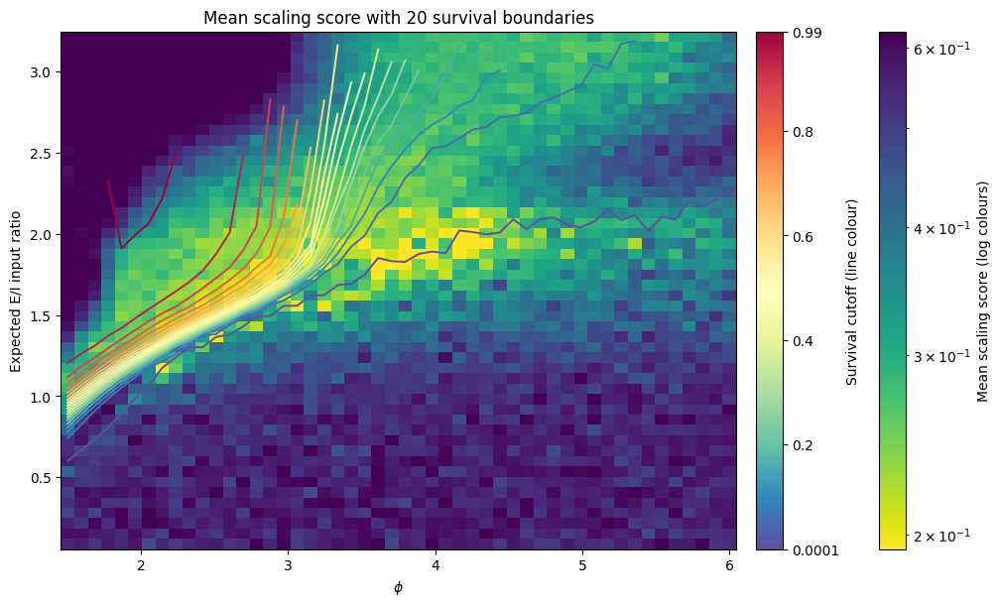

Data: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals
Loaded 50,000 network checkpoints.
Survival 0.0001: boundary located at 50/50 phi values.
Survival 0.0522: boundary located at 43/50 phi values.
Survival 0.1043: boundary located at 33/50 phi values.
Survival 0.1564: boundary located at 30/50 phi values.
Survival 0.2085: boundary located at 27/50 phi values.
Survival 0.2606: boundary located at 26/50 phi values.
Survival 0.3127: boundary located at 25/50 phi values.
Survival 0.3648: boundary located at 24/50 phi values.
Survival 0.4169: boundary located at 23/50 phi values.
Survival 0.469: boundary located at 22/50 phi values.
Survival 0.5211: boundary located at 21/50 phi values.
Survival 0.5732: boundary located at 21/50 phi values.
Survival 0.6253: boundary located at 20/50 phi values.
Survival 0.6774: boundary located at 19/50 phi values.
Survival 0.7295: boundary located at 18/50 phi values.
Survival 0.7816: boundary lo

In [35]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.cm import ScalarMappable

# ======================== SETTINGS ========================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "50ew_50phis_20seeds_10000avals"
)
JOBDIR = OUTDIR / "completed_network_jobs"
FIGDIR = OUTDIR / "score_survival_20_cutoffs"

SURVIVAL_CUTOFFS = np.linspace(0.0001, 0.99, 20)

PHI_BOUNDS = None
EI_BOUNDS = None

N_E, N_I = 1600, 400
MIN_COMPLETED_SEEDS = 1

SCORE_CMAP = "viridis_r"
BOUNDARY_CMAP = "Spectral_r"

LOG_COLOURS = True
ROBUST_PERCENTILES = (1, 90)
FIGSIZE = (10, 6)
SAVE_FIGURES = False

# ======================== HELPERS =========================

def cell_edges(centres):
    centres = np.asarray(centres, float)
    mids = (centres[:-1] + centres[1:]) / 2
    return np.r_[
        centres[0] - (mids[0] - centres[0]),
        mids,
        centres[-1] + (centres[-1] - mids[-1]),
    ]


# ======================== LOAD ============================

config = json.loads((OUTDIR / "config.json").read_text())

phi_values = np.asarray(config["PHI_VALUES"], float)
ew_values = np.asarray(config["EW_VALUES"], float)
fixed_iw = float(config["I_W_FIXED"])
ei_values = N_E * ew_values / (N_I * fixed_iw)

if len(phi_values) != 50 or len(ew_values) != 50:
    raise ValueError("Expected the newer 50 × 50 grid.")

paths = sorted(JOBDIR.glob("*.json"))
if not paths:
    raise ValueError(f"No checkpoints in {JOBDIR}")

rows = []

for path in paths:
    result = json.loads(path.read_text())
    run = result["icg"]
    av = result["avalanche"]

    for key in ["ew_idx", "phi_idx", "seed_idx", "network_seed"]:
        if run[key] != av[key]:
            raise ValueError(f"{path.name}: mismatched {key}")

    iy, ix = int(run["ew_idx"]), int(run["phi_idx"])

    if not (
        0 <= iy < len(ew_values)
        and 0 <= ix < len(phi_values)
        and np.isclose(float(run["e_w"]), ew_values[iy])
        and np.isclose(float(run["phi"]), phi_values[ix])
        and np.isclose(float(run["i_w"]), fixed_iw)
    ):
        raise ValueError(f"{path.name}: checkpoint/config mismatch.")

    rows.append({
        "ew_idx": iy,
        "phi_idx": ix,
        "seed_idx": int(run["seed_idx"]),
        "score": run["score"],
        "survival": av["frac_persistent_at_cutoff"],
    })

runs = pd.DataFrame(rows)

if runs.duplicated(["ew_idx", "phi_idx", "seed_idx"]).any():
    raise ValueError("Duplicate network checkpoints.")

for column in ["score", "survival"]:
    runs[column] = pd.to_numeric(
        runs[column], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

if not runs["survival"].dropna().between(0, 1).all():
    raise ValueError("Invalid survival fractions.")

summary = runs.groupby(["ew_idx", "phi_idx"], as_index=False).agg(
    score_mean=("score", "mean"),
    survival_mean=("survival", "mean"),
    n_score=("score", "count"),
    n_survival=("survival", "count"),
)

summary.loc[
    summary["n_score"] < MIN_COMPLETED_SEEDS, "score_mean"
] = np.nan
summary.loc[
    summary["n_survival"] < MIN_COMPLETED_SEEDS, "survival_mean"
] = np.nan


def grid(column):
    return (
        summary.pivot(
            index="ew_idx",
            columns="phi_idx",
            values=column,
        )
        .reindex(
            index=np.arange(len(ei_values)),
            columns=np.arange(len(phi_values)),
        )
        .to_numpy(float)
    )


z_score = grid("score_mean")
z_survival = grid("survival_mean")

# ======================== CUTOFF LOCATIONS ================
# First upward crossing along E/I for each phi.
# Linear interpolation; no smoothing or extrapolation.

boundary_curves = {}
boundary_rows = []

for cutoff in SURVIVAL_CUTOFFS:
    locations = np.full(len(phi_values), np.nan)

    for ix, phi in enumerate(phi_values):
        survival = z_survival[:, ix]

        if not np.isfinite(survival[0]) or survival[0] >= cutoff:
            continue

        for j in range(len(ei_values) - 1):
            left, right = survival[j:j + 2]

            if not np.isfinite(left) or not np.isfinite(right):
                break

            if left < cutoff <= right:
                fraction = (cutoff - left) / (right - left)
                locations[ix] = (
                    ei_values[j]
                    + fraction * (ei_values[j + 1] - ei_values[j])
                )
                break

    boundary_curves[cutoff] = locations

    boundary_rows.extend([
        {
            "phi": phi,
            "survival_cutoff": cutoff,
            "EI_boundary": location,
        }
        for phi, location in zip(phi_values, locations)
    ])

cutoff_locations = pd.DataFrame(boundary_rows)

# ======================== SCORE COLOURS ===================

display = np.ones(z_score.shape, dtype=bool)

if PHI_BOUNDS is not None:
    display &= (
        (phi_values >= PHI_BOUNDS[0])
        & (phi_values <= PHI_BOUNDS[1])
    )[None, :]

if EI_BOUNDS is not None:
    display &= (
        (ei_values >= EI_BOUNDS[0])
        & (ei_values <= EI_BOUNDS[1])
    )[:, None]

valid = display & np.isfinite(z_score)
if LOG_COLOURS:
    valid &= z_score > 0

values = z_score[valid]
if not values.size:
    raise ValueError("No valid scores for the colour scale.")

vmin, vmax = np.percentile(values, ROBUST_PERCENTILES)
if vmax <= vmin:
    vmax = vmin * 1.01 if LOG_COLOURS else vmin + 0.01

if LOG_COLOURS:
    score_norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)
    score_plot = np.ma.masked_invalid(np.maximum(z_score, vmin))
else:
    score_norm = Normalize(vmin=vmin, vmax=vmax, clip=True)
    score_plot = np.ma.masked_invalid(z_score)

score_cmap = plt.get_cmap(SCORE_CMAP).copy()
score_cmap.set_bad("0.9")

boundary_cmap = plt.get_cmap(BOUNDARY_CMAP)
boundary_norm = Normalize(
    vmin=SURVIVAL_CUTOFFS.min(),
    vmax=SURVIVAL_CUTOFFS.max(),
)

# ======================== PLOT ============================

fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)

im = ax.pcolormesh(
    cell_edges(phi_values),
    cell_edges(ei_values),
    score_plot,
    shading="flat",
    cmap=score_cmap,
    norm=score_norm,
    rasterized=True,
)

for cutoff in SURVIVAL_CUTOFFS:
    ax.plot(
        phi_values,
        boundary_curves[cutoff],
        color=boundary_cmap(boundary_norm(cutoff)),
        lw=1.4,
        zorder=5,
    )

ax.set(
    xlabel=r"$\phi$",
    ylabel="Expected E/I input ratio",
    title="Mean scaling score with 20 survival boundaries",
    xlim=(
        PHI_BOUNDS if PHI_BOUNDS is not None
        else tuple(cell_edges(phi_values)[[0, -1]])
    ),
    ylim=(
        EI_BOUNDS if EI_BOUNDS is not None
        else tuple(cell_edges(ei_values)[[0, -1]])
    ),
)

score_cbar = fig.colorbar(im, ax=ax, pad=0.03, fraction=0.045)
score_cbar.set_label(
    "Mean scaling score"
    + (" (log colours)" if LOG_COLOURS else "")
)

boundary_cbar = fig.colorbar(
    ScalarMappable(norm=boundary_norm, cmap=boundary_cmap),
    ax=ax,
    pad=0.03,
    fraction=0.045,
)
boundary_cbar.set_label("Survival cutoff (line colour)")
boundary_cbar.set_ticks([0.0001, 0.2, 0.4, 0.6, 0.8, 0.99])
boundary_cbar.set_ticklabels(
    ["0.0001", "0.2", "0.4", "0.6", "0.8", "0.99"]
)

if SAVE_FIGURES:
    FIGDIR.mkdir(parents=True, exist_ok=True)
    cutoff_locations.to_csv(
        FIGDIR / "survival_cutoff_locations.csv",
        index=False,
    )

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"score_with_20_survival_cutoffs.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print("Data:", OUTDIR)
print(f"Loaded {len(paths):,} network checkpoints.")

for cutoff in SURVIVAL_CUTOFFS:
    n = np.isfinite(boundary_curves[cutoff]).sum()
    print(f"Survival {cutoff:.6g}: boundary located at {n}/50 phi values.")

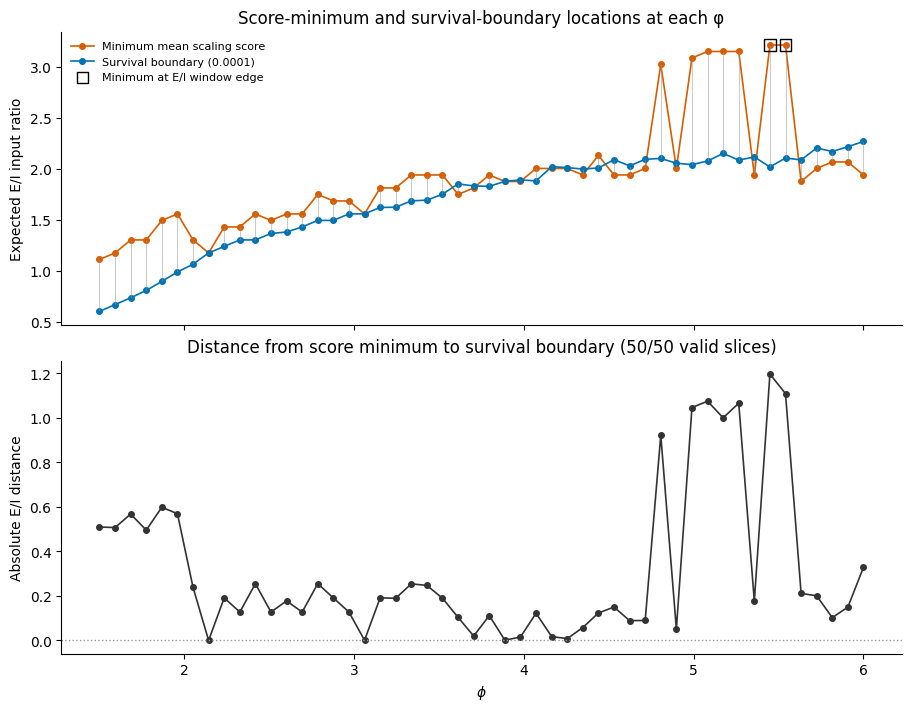

     phi  EI_score_min  minimum_score  score_min_at_window_edge  n_tied_score_minima  EI_survival_boundary  signed_EI_distance  absolute_EI_distance  n_upward_crossings status
1.500000      1.109694       0.269760                     False                    1              0.600013            0.509681              0.509681                   1     ok
1.591837      1.173469       0.285281                     False                    1              0.666267            0.507203              0.507203                   1     ok
1.683673      1.301020       0.242306                     False                    1              0.733020            0.568001              0.568001                   1     ok
1.775510      1.301020       0.247269                     False                    1              0.805311            0.495710              0.495710                   1     ok
1.867347      1.492347       0.235933                     False                    1              0.893680            0.

In [23]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================== SETTINGS ========================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "50ew_50phis_20seeds_10000avals"
)
JOBDIR = OUTDIR / "completed_network_jobs"
FIGDIR = OUTDIR / "score_min_survival_distance_by_phi"

SURVIVAL_THRESHOLD = 0.0001

N_E, N_I = 1600, 400
MIN_COMPLETED_SEEDS = 1

# None uses the full configured grid.
PHI_BOUNDS = None
EI_BOUNDS = None

SAVE_RESULTS = True

# ======================== LOAD ============================

if not 0 < SURVIVAL_THRESHOLD < 1:
    raise ValueError("SURVIVAL_THRESHOLD must be between 0 and 1.")

config = json.loads((OUTDIR / "config.json").read_text())

phi_values = np.asarray(config["PHI_VALUES"], float)
ew_values = np.asarray(config["EW_VALUES"], float)
fixed_iw = float(config["I_W_FIXED"])
ei_values = N_E * ew_values / (N_I * fixed_iw)

if len(phi_values) != 50 or len(ew_values) != 50:
    raise ValueError("Expected the 50 × 50 grid.")

if not np.all(np.diff(ei_values) > 0):
    raise ValueError("Expected increasing E/I values.")

paths = sorted(JOBDIR.glob("*.json"))
if not paths:
    raise ValueError(f"No checkpoints found in {JOBDIR}")

records = []

for path in paths:
    result = json.loads(path.read_text())
    run = result["icg"]
    av = result["avalanche"]

    for key in ["ew_idx", "phi_idx", "seed_idx", "network_seed"]:
        if run[key] != av[key]:
            raise ValueError(f"{path.name}: mismatched {key}")

    iy, ix = int(run["ew_idx"]), int(run["phi_idx"])

    if not (
        0 <= iy < len(ew_values)
        and 0 <= ix < len(phi_values)
        and np.isclose(float(run["e_w"]), ew_values[iy])
        and np.isclose(float(run["phi"]), phi_values[ix])
        and np.isclose(float(run["i_w"]), fixed_iw)
    ):
        raise ValueError(f"{path.name}: checkpoint/config mismatch.")

    records.append({
        "ew_idx": iy,
        "phi_idx": ix,
        "seed_idx": int(run["seed_idx"]),
        "score": run["score"],
        "survival": av["frac_persistent_at_cutoff"],
    })

runs = pd.DataFrame(records)

if runs.duplicated(["ew_idx", "phi_idx", "seed_idx"]).any():
    raise ValueError("Duplicate network checkpoints.")

for column in ["score", "survival"]:
    runs[column] = pd.to_numeric(
        runs[column], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

if not runs["survival"].dropna().between(0, 1).all():
    raise ValueError("Invalid survival fractions.")

# Average each quantity across network seeds at each grid cell.
cells = runs.groupby(["ew_idx", "phi_idx"]).agg(
    score_mean=("score", "mean"),
    survival_mean=("survival", "mean"),
    n_valid_score=("score", "count"),
    n_valid_survival=("survival", "count"),
).reset_index()

cells.loc[
    cells["n_valid_score"] < MIN_COMPLETED_SEEDS,
    "score_mean",
] = np.nan

cells.loc[
    cells["n_valid_survival"] < MIN_COMPLETED_SEEDS,
    "survival_mean",
] = np.nan


def to_grid(column):
    return (
        cells.pivot(
            index="ew_idx",
            columns="phi_idx",
            values=column,
        )
        .reindex(
            index=np.arange(len(ei_values)),
            columns=np.arange(len(phi_values)),
        )
        .to_numpy(float)
    )


z_score = to_grid("score_mean")
z_survival = to_grid("survival_mean")

ei_selected = np.ones(len(ei_values), dtype=bool)
if EI_BOUNDS is not None:
    ei_selected &= (
        (ei_values >= EI_BOUNDS[0])
        & (ei_values <= EI_BOUNDS[1])
    )

ei_indices = np.flatnonzero(ei_selected)
ei = ei_values[ei_indices]

if len(ei) < 2:
    raise ValueError("Need at least two E/I grid points.")

# ======================== PER-PHI ANALYSIS =================
#
# Score minimum: lowest observed cell-mean score along E/I.
# Survival boundary: first upward crossing as E/I increases.
# Crossing location is linearly interpolated.
# Missing grid cells are never bridged.
# ==========================================================

rows = []

for ix, phi in enumerate(phi_values):
    if PHI_BOUNDS is not None and not PHI_BOUNDS[0] <= phi <= PHI_BOUNDS[1]:
        continue

    score = z_score[ei_indices, ix]
    survival = z_survival[ei_indices, ix]

    row = {
        "phi": float(phi),
        "EI_score_min": np.nan,
        "minimum_score": np.nan,
        "score_min_at_window_edge": False,
        "n_tied_score_minima": 0,
        "EI_survival_boundary": np.nan,
        "signed_EI_distance": np.nan,
        "absolute_EI_distance": np.nan,
        "n_upward_crossings": 0,
        "status": "",
    }

    # Score minimum on the measured E/I grid.
    finite_score = np.isfinite(score)

    if not finite_score.any():
        row["status"] = "No valid scores"
        rows.append(row)
        continue

    minimum_score = float(np.nanmin(score))
    minima = np.flatnonzero(finite_score & (score == minimum_score))

    row["minimum_score"] = minimum_score
    row["n_tied_score_minima"] = len(minima)

    if len(minima) != 1:
        row["status"] = "Tied score minima; location ambiguous"
        rows.append(row)
        continue

    minimum_idx = int(minima[0])
    minimum_ei = float(ei[minimum_idx])

    row["EI_score_min"] = minimum_ei
    row["score_min_at_window_edge"] = (
        minimum_idx == 0 or minimum_idx == len(ei) - 1
    )

    # Require complete survival coverage to identify the first crossing.
    if not np.isfinite(survival).all():
        row["status"] = "Incomplete survival slice"
        rows.append(row)
        continue

    if survival[0] > SURVIVAL_THRESHOLD:
        row["status"] = "Already above cutoff at lowest E/I"
        rows.append(row)
        continue

    crossings = np.flatnonzero(
        (survival[:-1] <= SURVIVAL_THRESHOLD)
        & (survival[1:] > SURVIVAL_THRESHOLD)
    )
    row["n_upward_crossings"] = len(crossings)

    if not len(crossings):
        row["status"] = "No upward survival crossing"
        rows.append(row)
        continue

    j = int(crossings[0])

    fraction = (
        (SURVIVAL_THRESHOLD - survival[j])
        / (survival[j + 1] - survival[j])
    )
    boundary_ei = float(ei[j] + fraction * (ei[j + 1] - ei[j]))

    # Positive means score minimum is on the higher-E/I side.
    signed_distance = minimum_ei - boundary_ei

    row.update({
        "EI_survival_boundary": boundary_ei,
        "signed_EI_distance": signed_distance,
        "absolute_EI_distance": abs(signed_distance),
        "status": "ok",
    })
    rows.append(row)

distance_results = pd.DataFrame(rows)
valid = distance_results["status"].eq("ok")

# ======================== PLOT ============================

orange = "#D55E00"
blue = "#0072B2"

fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    constrained_layout=True,
)

# Locations along the E/I axis, for each phi.
ax = axes[0]

ax.plot(
    distance_results["phi"],
    distance_results["EI_score_min"],
    "o-",
    color=orange,
    ms=4,
    lw=1.2,
    label="Minimum mean scaling score",
)

ax.plot(
    distance_results["phi"],
    distance_results["EI_survival_boundary"],
    "o-",
    color=blue,
    ms=4,
    lw=1.2,
    label=f"Survival boundary ({SURVIVAL_THRESHOLD:g})",
)

# Connect the two locations at each valid phi.
ax.vlines(
    distance_results.loc[valid, "phi"],
    distance_results.loc[valid, "EI_score_min"],
    distance_results.loc[valid, "EI_survival_boundary"],
    color="0.6",
    alpha=0.5,
    lw=0.8,
)

# Flag minima at the limits of the E/I window.
edge = distance_results["score_min_at_window_edge"]
if edge.any():
    ax.scatter(
        distance_results.loc[edge, "phi"],
        distance_results.loc[edge, "EI_score_min"],
        marker="s",
        s=65,
        facecolors="none",
        edgecolors="black",
        zorder=5,
        label="Minimum at E/I window edge",
    )

ax.set(
    ylabel="Expected E/I input ratio",
    title="Score-minimum and survival-boundary locations at each φ",
)
ax.legend(frameon=False, fontsize=8)

# Distance between locations.
ax = axes[1]

ax.plot(
    distance_results["phi"],
    distance_results["absolute_EI_distance"],
    "o-",
    color="0.2",
    ms=4,
    lw=1.2,
)

ax.axhline(0, color="0.6", ls=":", lw=1)

ax.set(
    xlabel=r"$\phi$",
    ylabel="Absolute E/I distance",
    title=(
        f"Distance from score minimum to survival boundary "
        f"({valid.sum()}/{len(distance_results)} valid slices)"
    ),
)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    distance_results.to_csv(
        FIGDIR / f"EI_distance_by_phi_cutoff_{SURVIVAL_THRESHOLD:g}.csv",
        index=False,
    )

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"EI_distance_by_phi_cutoff_{SURVIVAL_THRESHOLD:g}.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(distance_results.round(6).to_string(index=False))

if (~valid).any():
    print("\nSlices without a distance:")
    print(
        distance_results.loc[~valid, "status"]
        .value_counts()
        .to_string()
    )

print(
    "\nMinima use the stored score, averaged across seeds. "
    "Distances are in E/I units; no LLR filtering is applied."
)
if SAVE_RESULTS:
    print("Saved to:", FIGDIR)

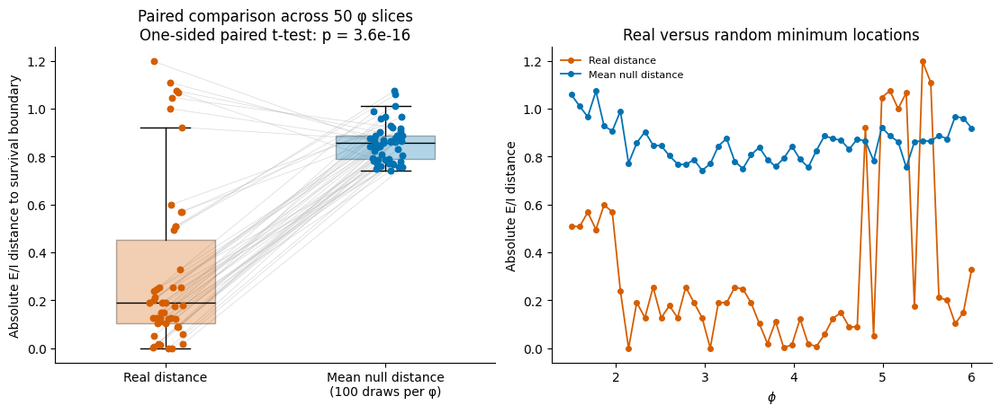

n_phi                   5.000000e+01
shuffles_per_phi        1.000000e+02
mean_real_distance      3.137110e-01
mean_null_distance      8.571346e-01
mean_paired_difference -5.434237e-01
paired_t               -1.175470e+01
degrees_of_freedom      4.900000e+01
paired_t_p_less         3.600620e-16
shuffle_p_less          9.900990e-03

Negative paired difference means real minima are closer.
Survival boundaries remain fixed throughout the null test.

Saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/score_min_survival_distance_by_phi


In [24]:
# Requires the previous block:
# distance_results, phi_values, ei_values, ei_indices, z_score, FIGDIR

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

# ======================== SETTINGS ========================

N_SHUFFLES = 100
RANDOM_SEED = 123
SAVE_NULL_RESULTS = True

# One-sided test: are real distances SMALLER than null distances?
TEST_ALTERNATIVE = "less"

# ======================== GENERATE NULL ===================

rng = np.random.default_rng(RANDOM_SEED)

real = distance_results.loc[
    distance_results["status"].eq("ok"),
    ["phi", "EI_survival_boundary", "absolute_EI_distance"],
].copy()

real = real.rename(columns={
    "absolute_EI_distance": "real_distance",
})

if len(real) < 2:
    raise ValueError("Need at least two valid phi slices.")

null_rows = []

for row in real.itertuples(index=False):
    matches = np.flatnonzero(np.isclose(
        phi_values, row.phi, rtol=0, atol=1e-10
    ))

    if len(matches) != 1:
        raise ValueError(f"Cannot uniquely match phi={row.phi}.")

    ix = int(matches[0])

    # Same eligible E/I locations used to search for the score minimum.
    score_slice = z_score[ei_indices, ix]
    candidate_ei = ei_values[ei_indices][np.isfinite(score_slice)]

    if len(candidate_ei) < 2:
        raise ValueError(f"Too few candidate E/I locations at phi={row.phi}.")

    # Independent uniform draws WITH replacement.
    # Equivalent to randomizing the location of a unique score minimum.
    random_ei = rng.choice(
        candidate_ei,
        size=N_SHUFFLES,
        replace=True,
    )

    random_distances = np.abs(
        random_ei - row.EI_survival_boundary
    )

    for repeat, (location, distance) in enumerate(
        zip(random_ei, random_distances)
    ):
        null_rows.append({
            "phi": row.phi,
            "shuffle": repeat,
            "random_EI": location,
            "EI_survival_boundary": row.EI_survival_boundary,
            "null_distance": distance,
        })

null_distances = pd.DataFrame(null_rows)

null_summary = (
    null_distances.groupby("phi", as_index=False)
    .agg(
        null_mean_distance=("null_distance", "mean"),
        null_sd_distance=("null_distance", "std"),
    )
)

comparison = (
    real.merge(null_summary, on="phi", validate="one_to_one")
    .sort_values("phi")
    .reset_index(drop=True)
)

comparison["real_minus_null_mean"] = (
    comparison["real_distance"]
    - comparison["null_mean_distance"]
)

# ======================== PAIRED T-TEST ====================
# One pair per phi, not one pair per shuffle.

real_values = comparison["real_distance"].to_numpy(float)
null_means = comparison["null_mean_distance"].to_numpy(float)
differences = real_values - null_means

if np.std(differences, ddof=1) == 0:
    raise ValueError(
        "Paired differences have zero variance; t-test is degenerate."
    )

test = ttest_rel(
    real_values,
    null_means,
    alternative=TEST_ALTERNATIVE,
)

# Also compare the overall observed mean against 100 null realizations.
# Each realization contains one random distance for every phi.
null_mean_by_shuffle = (
    null_distances.groupby("shuffle")["null_distance"].mean()
)

observed_mean = float(real_values.mean())

p_shuffle = (
    1 + np.count_nonzero(
        null_mean_by_shuffle.to_numpy() <= observed_mean
    )
) / (N_SHUFFLES + 1)

test_summary = pd.DataFrame([{
    "n_phi": len(comparison),
    "shuffles_per_phi": N_SHUFFLES,
    "mean_real_distance": observed_mean,
    "mean_null_distance": float(null_means.mean()),
    "mean_paired_difference": float(differences.mean()),
    "paired_t": float(test.statistic),
    "degrees_of_freedom": len(comparison) - 1,
    "paired_t_p_less": float(test.pvalue),
    "shuffle_p_less": float(p_shuffle),
}])

# ======================== PLOT ============================

orange = "#D55E00"
blue = "#0072B2"

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.5),
    constrained_layout=True,
)

# LEFT: side-by-side distributions, one value per phi.
ax = axes[0]

boxes = ax.boxplot(
    [real_values, null_means],
    positions=[0, 1],
    widths=0.45,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black"},
)

for patch, colour in zip(boxes["boxes"], [orange, blue]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.3)

# Paired points: the same jitter for each phi on both sides.
plot_rng = np.random.default_rng(RANDOM_SEED + 1)
jitter = plot_rng.uniform(-0.08, 0.08, len(comparison))

for j, observed, expected in zip(jitter, real_values, null_means):
    ax.plot(
        [j, 1 + j],
        [observed, expected],
        color="0.75",
        alpha=0.5,
        lw=0.6,
        zorder=1,
    )

ax.scatter(jitter, real_values, color=orange, s=22, zorder=3)
ax.scatter(1 + jitter, null_means, color=blue, s=22, zorder=3)

ax.set_xticks(
    [0, 1],
    ["Real distance", f"Mean null distance\n({N_SHUFFLES} draws per φ)"],
)

ax.set(
    ylabel="Absolute E/I distance to survival boundary",
    title=(
        f"Paired comparison across {len(comparison)} φ slices\n"
        f"One-sided paired t-test: p = {test.pvalue:.3g}"
    ),
)

# RIGHT: real and mean null distance along phi.
ax = axes[1]

ax.plot(
    comparison["phi"],
    real_values,
    "o-",
    color=orange,
    ms=4,
    lw=1.3,
    label="Real distance",
)

ax.plot(
    comparison["phi"],
    null_means,
    "o-",
    color=blue,
    ms=4,
    lw=1.3,
    label="Mean null distance",
)

ax.set(
    xlabel=r"$\phi$",
    ylabel="Absolute E/I distance",
    title="Real versus random minimum locations",
)
ax.legend(frameon=False, fontsize=8)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

# ======================== SAVE / REPORT ===================

if SAVE_NULL_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    null_distances.to_csv(
        FIGDIR / "random_EI_null_distances.csv", index=False
    )
    comparison.to_csv(
        FIGDIR / "real_vs_null_by_phi.csv", index=False
    )
    test_summary.to_csv(
        FIGDIR / "real_vs_null_tests.csv", index=False
    )

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"real_vs_random_EI_null.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(test_summary.T.to_string(header=False))
print("\nNegative paired difference means real minima are closer.")
print("Survival boundaries remain fixed throughout the null test.")
if SAVE_NULL_RESULTS:
    print("\nSaved to:", FIGDIR)

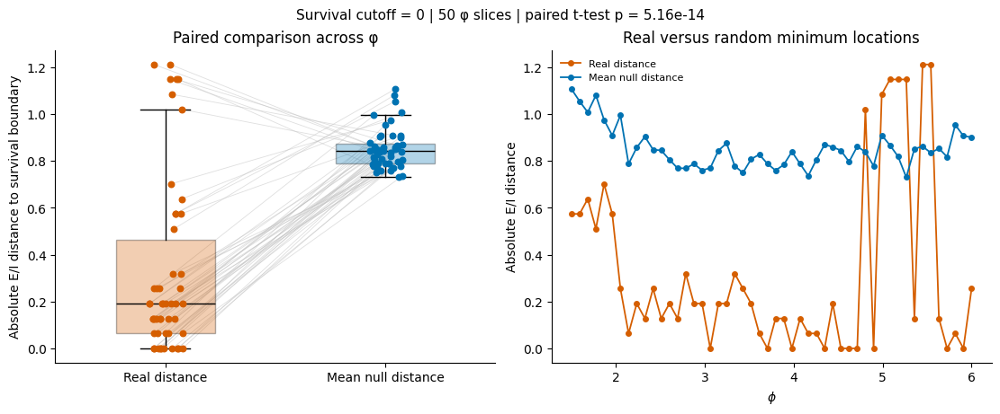

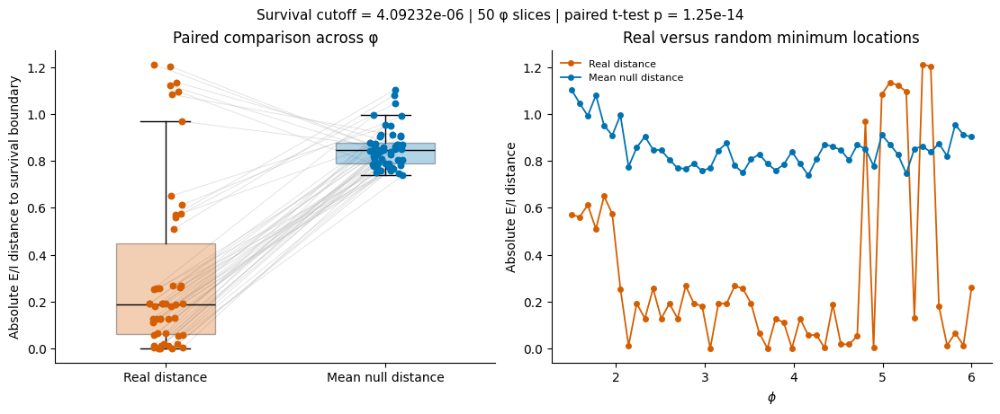

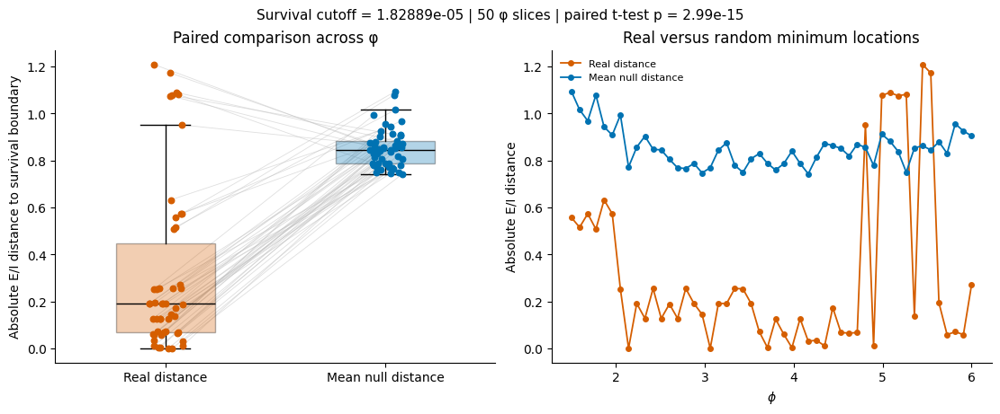

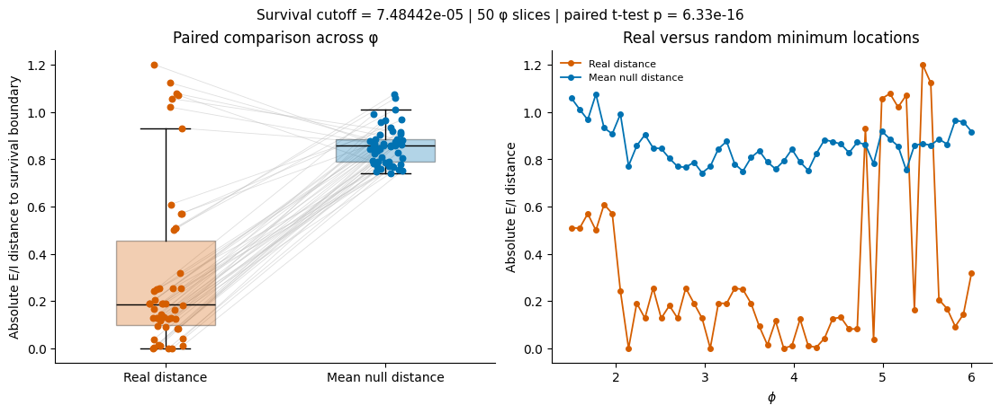

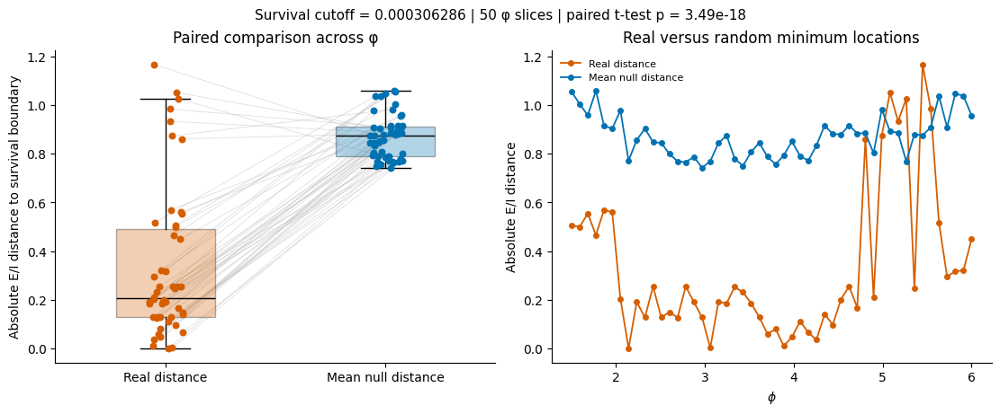

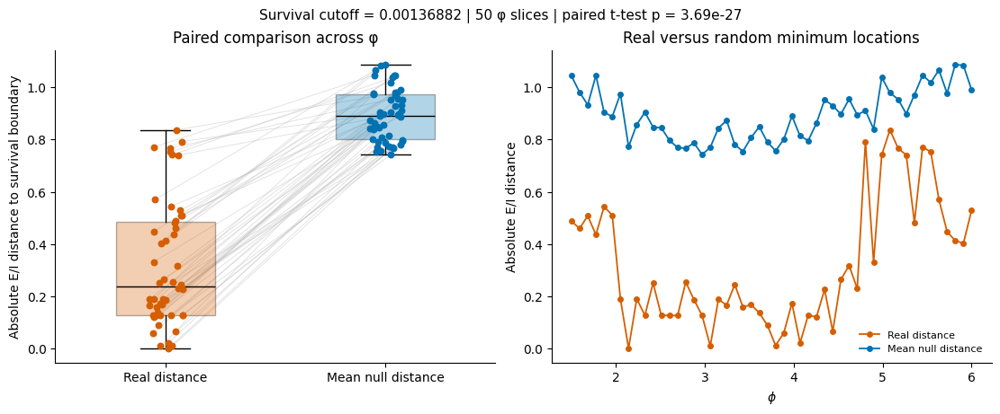

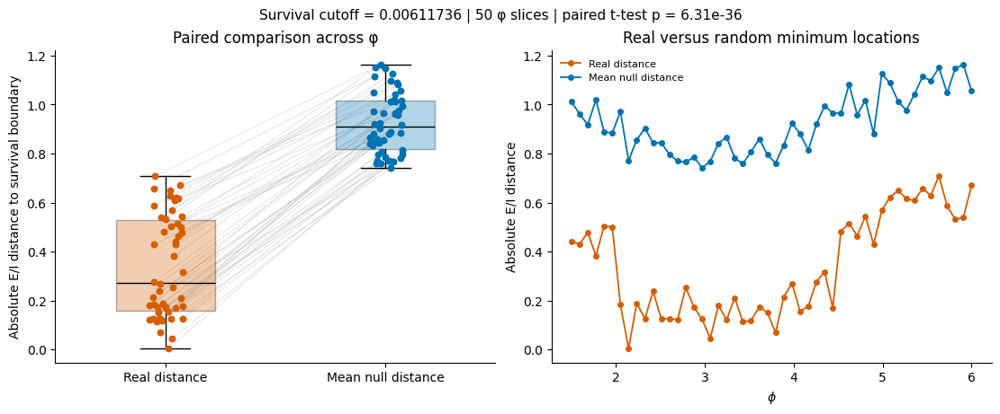

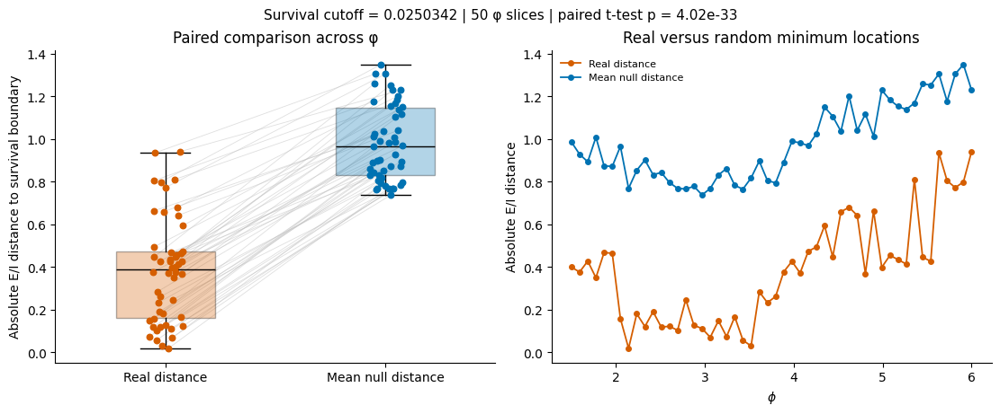

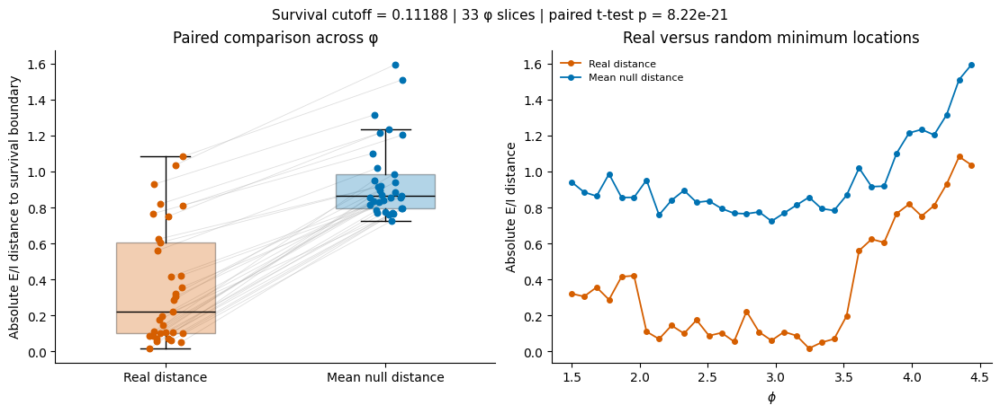

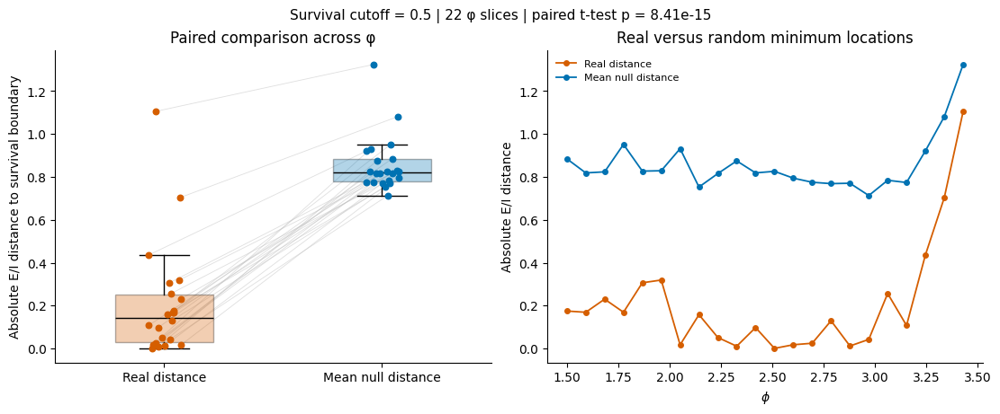

 survival_cutoff  n_phi  mean_real_distance  mean_null_distance   paired_t      p_value
        0.000000     50            0.321429            0.851454 -10.202013 5.160303e-14
        0.000004     50            0.315926            0.851935 -10.635636 1.250694e-14
        0.000018     50            0.311956            0.852755 -11.080893 2.990681e-15
        0.000075     50            0.312458            0.856013 -11.573057 6.334742e-16
        0.000306     50            0.332381            0.871609 -13.301095 3.485876e-18
        0.001369     50            0.320261            0.894271 -21.787474 3.685159e-27
        0.006117     50            0.339749            0.924726 -33.814305 6.305878e-36
        0.025034     50            0.383225            0.983688 -29.451312 4.017945e-33
        0.111880     33            0.360343            0.948187 -21.373234 8.219389e-21
        0.500000     22            0.206289            0.857004 -18.549115 8.408301e-15

Saved to: /home/dburrows/DATA/B

In [26]:
# Requires the previous sensitivity block:
# p_sensitivity, slices, ei, FIGDIR
#
# slices contains each phi's score minimum, survival curve,
# and the fixed random E/I draws used in the sensitivity sweep.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

# ======================== SETTINGS ========================

N_EXAMPLES = 10
SAVE_EXAMPLES = True

orange = "#D55E00"
blue = "#0072B2"

# Sample across the cutoff range, not by choosing p-values.
available = (
    p_sensitivity.loc[
        np.isfinite(p_sensitivity["p_value"]),
        "survival_cutoff",
    ]
    .sort_values()
    .to_numpy(float)
)

if not len(available):
    raise ValueError("No valid cutoffs in p_sensitivity.")

indices = np.unique(np.round(
    np.linspace(0, len(available) - 1, min(N_EXAMPLES, len(available)))
).astype(int))

sampled_cutoffs = available[indices]

example_dir = FIGDIR / "sampled_cutoff_comparisons"
if SAVE_EXAMPLES:
    example_dir.mkdir(parents=True, exist_ok=True)

summary_rows = []

# ======================== REPEAT COMPARISONS ==============

for example_idx, cutoff in enumerate(sampled_cutoffs):
    rows = []

    for item in slices:
        survival = item["survival"]

        if survival[0] > cutoff:
            continue

        crossings = np.flatnonzero(
            (survival[:-1] <= cutoff)
            & (survival[1:] > cutoff)
        )

        if not crossings.size:
            continue

        j = int(crossings[0])

        fraction = (
            (cutoff - survival[j])
            / (survival[j + 1] - survival[j])
        )

        boundary_ei = float(
            ei[j] + fraction * (ei[j + 1] - ei[j])
        )

        null_values = np.abs(item["random_ei"] - boundary_ei)

        rows.append({
            "phi": item["phi"],
            "EI_score_min": item["minimum_ei"],
            "EI_survival_boundary": boundary_ei,
            "real_distance": abs(item["minimum_ei"] - boundary_ei),
            "null_mean_distance": float(null_values.mean()),
        })

    comparison = pd.DataFrame(rows).sort_values("phi")

    real_values = comparison["real_distance"].to_numpy(float)
    null_means = comparison["null_mean_distance"].to_numpy(float)

    test = ttest_rel(real_values, null_means, alternative="less")

    summary_rows.append({
        "survival_cutoff": cutoff,
        "n_phi": len(comparison),
        "mean_real_distance": real_values.mean(),
        "mean_null_distance": null_means.mean(),
        "paired_t": test.statistic,
        "p_value": test.pvalue,
    })

    # ==================== PLOT ============================

    fig, axes = plt.subplots(
        1, 2,
        figsize=(11, 4.5),
        constrained_layout=True,
    )

    fig.suptitle(
        f"Survival cutoff = {cutoff:.6g} | "
        f"{len(comparison)} φ slices | "
        f"paired t-test p = {test.pvalue:.3g}",
        fontsize=11,
    )

    # LEFT: one real and one mean-null distance per phi.
    ax = axes[0]

    boxes = ax.boxplot(
        [real_values, null_means],
        positions=[0, 1],
        widths=0.45,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black"},
    )

    for patch, colour in zip(boxes["boxes"], [orange, blue]):
        patch.set_facecolor(colour)
        patch.set_alpha(0.3)

    plot_rng = np.random.default_rng(124)
    jitter = plot_rng.uniform(-0.08, 0.08, len(comparison))

    for offset, observed, expected in zip(
        jitter, real_values, null_means
    ):
        ax.plot(
            [offset, 1 + offset],
            [observed, expected],
            color="0.75",
            alpha=0.5,
            lw=0.6,
            zorder=1,
        )

    ax.scatter(
        jitter, real_values,
        color=orange, s=22, zorder=3,
    )
    ax.scatter(
        1 + jitter, null_means,
        color=blue, s=22, zorder=3,
    )

    ax.set_xticks(
        [0, 1],
        ["Real distance", "Mean null distance"],
    )
    ax.set(
        ylabel="Absolute E/I distance to survival boundary",
        title="Paired comparison across φ",
    )

    # RIGHT: distances along phi.
    ax = axes[1]

    ax.plot(
        comparison["phi"], real_values,
        "o-", color=orange, ms=4, lw=1.3,
        label="Real distance",
    )
    ax.plot(
        comparison["phi"], null_means,
        "o-", color=blue, ms=4, lw=1.3,
        label="Mean null distance",
    )

    ax.set(
        xlabel=r"$\phi$",
        ylabel="Absolute E/I distance",
        title="Real versus random minimum locations",
    )
    ax.legend(frameon=False, fontsize=8)

    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)

    if SAVE_EXAMPLES:
        stem = (
            f"example_{example_idx + 1:02d}"
            f"_cutoff_{cutoff:.6g}"
        )
        fig.savefig(
            example_dir / f"{stem}.png",
            dpi=200,
            bbox_inches="tight",
        )
        comparison.to_csv(
            example_dir / f"{stem}.csv",
            index=False,
        )

    plt.show()
    plt.close(fig)

sampled_comparisons = pd.DataFrame(summary_rows)

print(sampled_comparisons.to_string(index=False))

if SAVE_EXAMPLES:
    sampled_comparisons.to_csv(
        example_dir / "sampled_cutoff_tests.csv",
        index=False)
    print("\nSaved to:", example_dir)

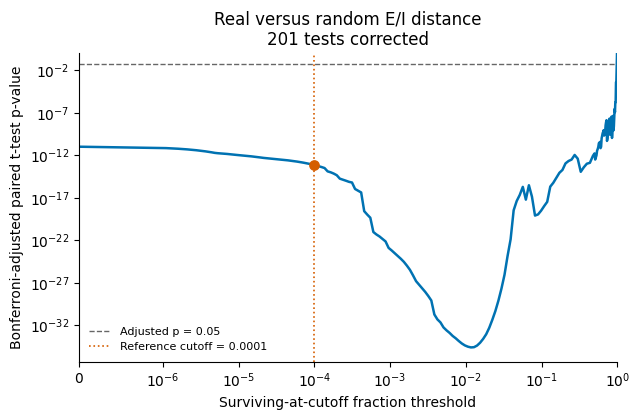

Bonferroni correction across 201 valid cutoff tests.

Cutoff = 0:
 survival_cutoff  n_phi   paired_t      p_value  p_bonferroni
             0.0     50 -10.202013 5.160303e-14  1.037221e-11

Cutoff = 0.0001:
 survival_cutoff  n_phi   paired_t      p_value  p_bonferroni
          0.0001     50 -11.754704 3.600620e-16  7.237246e-14

Cutoff = 1:
 survival_cutoff  n_phi  paired_t  p_value  p_bonferroni
             1.0      0       NaN      NaN           NaN


In [36]:
# ======================== BONFERRONI ======================

valid_tests = np.isfinite(p_sensitivity["p_value"])
n_tests = int(valid_tests.sum())

if n_tests == 0:
    raise ValueError("No valid p-values to correct.")

p_sensitivity["p_bonferroni"] = np.minimum(
    p_sensitivity["p_value"] * n_tests,
    1.0,
)

# ======================== PLOT ============================

fig, ax = plt.subplots(figsize=(6.5, 4.3))

p_plot = p_sensitivity["p_bonferroni"].to_numpy(float).copy()

# Plot numerical zeros at a positive floor without changing saved values.
underflow = np.isfinite(p_plot) & (p_plot == 0)
positive = p_plot[np.isfinite(p_plot) & (p_plot > 0)]

plot_floor = (
    max(np.finfo(float).tiny, positive.min() / 10)
    if positive.size
    else np.finfo(float).tiny
)
p_plot[underflow] = plot_floor

ax.plot(
    p_sensitivity["survival_cutoff"],
    p_plot,
    color="#0072B2",
    lw=1.8,
)

ax.axhline(
    0.05,
    color="0.4",
    ls="--",
    lw=1,
    label="Adjusted p = 0.05",
)

ax.axvline(
    REFERENCE_CUTOFF,
    color="#D55E00",
    ls=":",
    lw=1.2,
    label=f"Reference cutoff = {REFERENCE_CUTOFF:g}",
)

reference_mask = (
    p_sensitivity["survival_cutoff"].eq(REFERENCE_CUTOFF)
)
reference = p_sensitivity.loc[reference_mask]

if reference_mask.any():
    reference_p = p_plot[np.flatnonzero(reference_mask)[0]]
    if np.isfinite(reference_p):
        ax.scatter(
            REFERENCE_CUTOFF,
            reference_p,
            color="#D55E00",
            s=45,
            zorder=5,
        )

ax.set_xscale("symlog", linthresh=1e-6)
ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_ylim(top=1.05)

ax.set(
    xlabel="Surviving-at-cutoff fraction threshold",
    ylabel="Bonferroni-adjusted paired t-test p-value",
    title=f"Real versus random E/I distance\n{n_tests} tests corrected",
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    p_sensitivity.to_csv(
        FIGDIR / "p_value_vs_survival_cutoff_bonferroni.csv",
        index=False,
    )

    for ext in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"p_value_vs_survival_cutoff_bonferroni.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(f"Bonferroni correction across {n_tests} valid cutoff tests.")

for cutoff in [0.0, REFERENCE_CUTOFF, 1.0]:
    print(f"\nCutoff = {cutoff:g}:")
    print(
        p_sensitivity.loc[
            p_sensitivity["survival_cutoff"].eq(cutoff)
        ].to_string(index=False)
    )

if underflow.any():
    print("\nNumerical zero p-values are shown at a positive plotting floor.")

Loading saved 50 × 50 ICG curves:   0%|          | 0/50000 [00:00<?, ?it/s]

Data: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals
Loaded files: 50,000; skipped: 0
Generation rows: 500,000
Available e_w values: 50/50
Available phi values: 50/50
Aggregated curves: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/icg_generation_scaling_curves_aggregated.csv

Plotting: Mean-variance
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/mean_variance_norm_MULTIPLOT_panels_ew_lines_phi_cbar_right.png


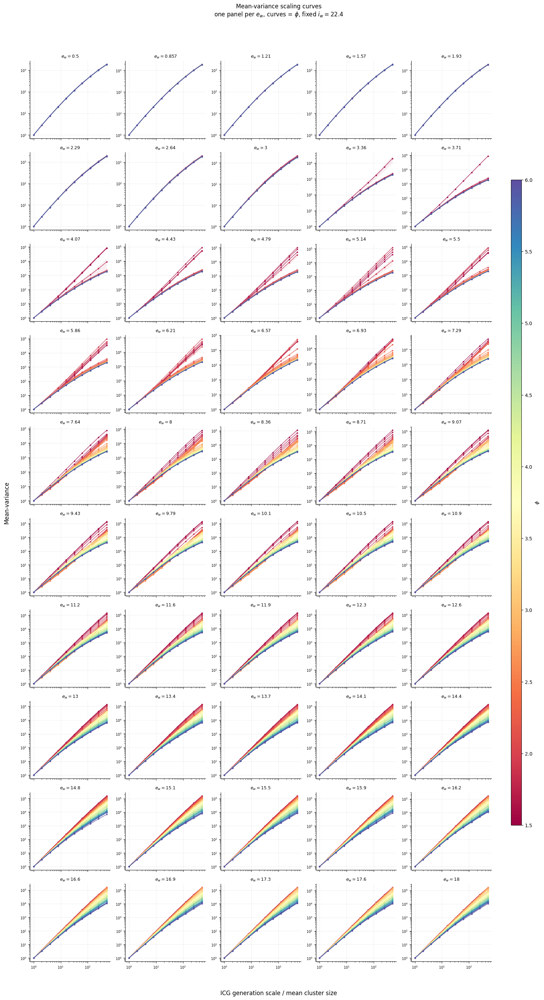

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/mean_variance_norm_MULTIPLOT_panels_phi_lines_ew_cbar_right.png


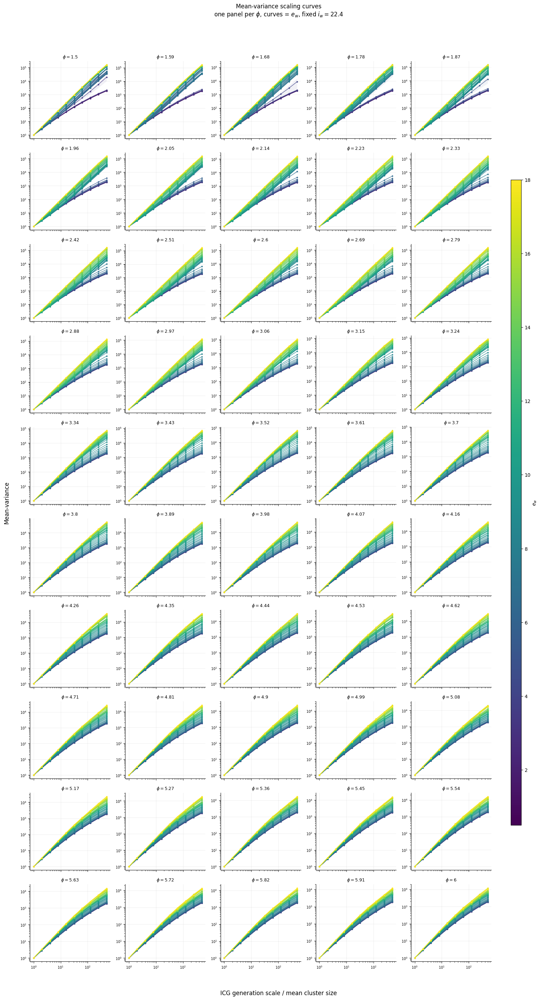


Plotting: Timescale
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/timescale_norm_MULTIPLOT_panels_ew_lines_phi_cbar_right.png


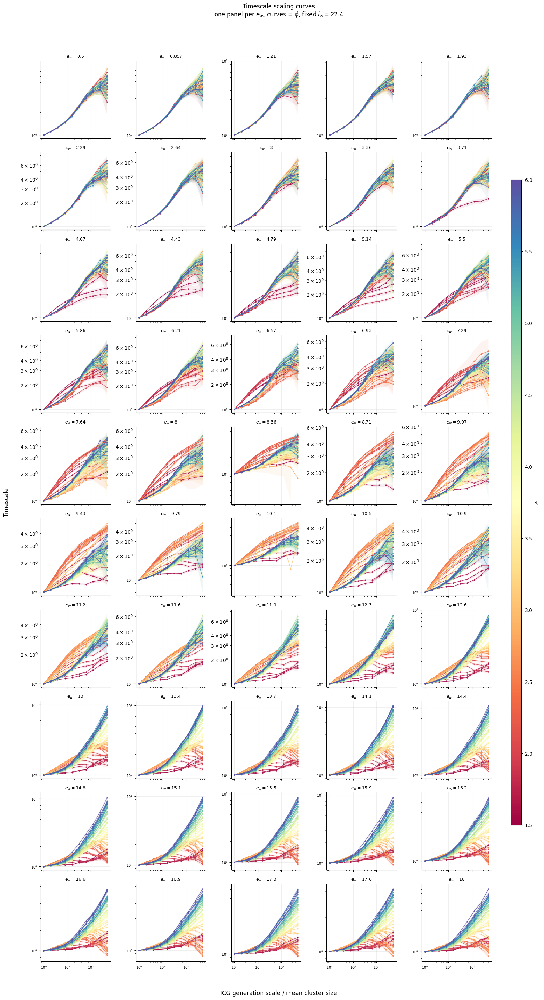

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/timescale_norm_MULTIPLOT_panels_phi_lines_ew_cbar_right.png


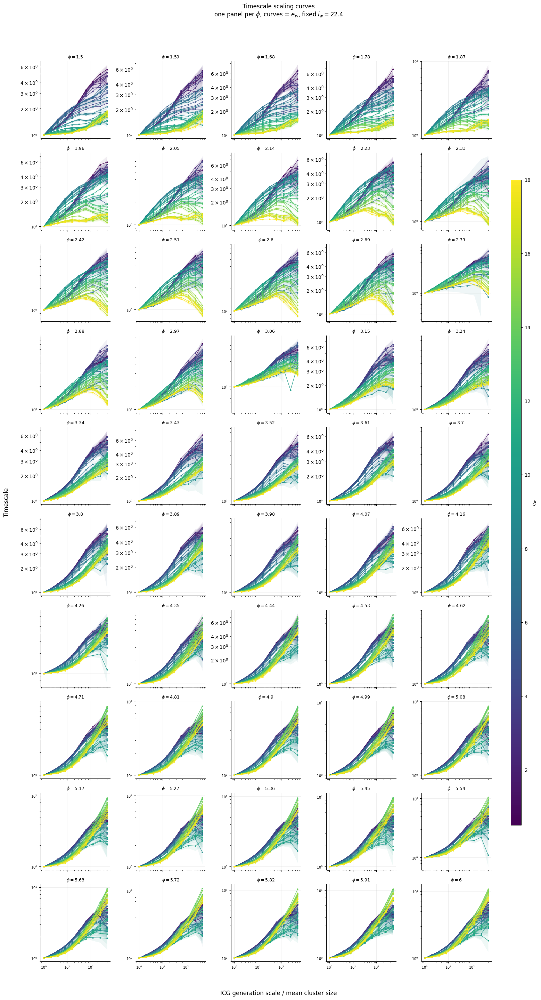


Plotting: Correlation kurtosis
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/kurtosis_corr_MULTIPLOT_panels_ew_lines_phi_cbar_right.png


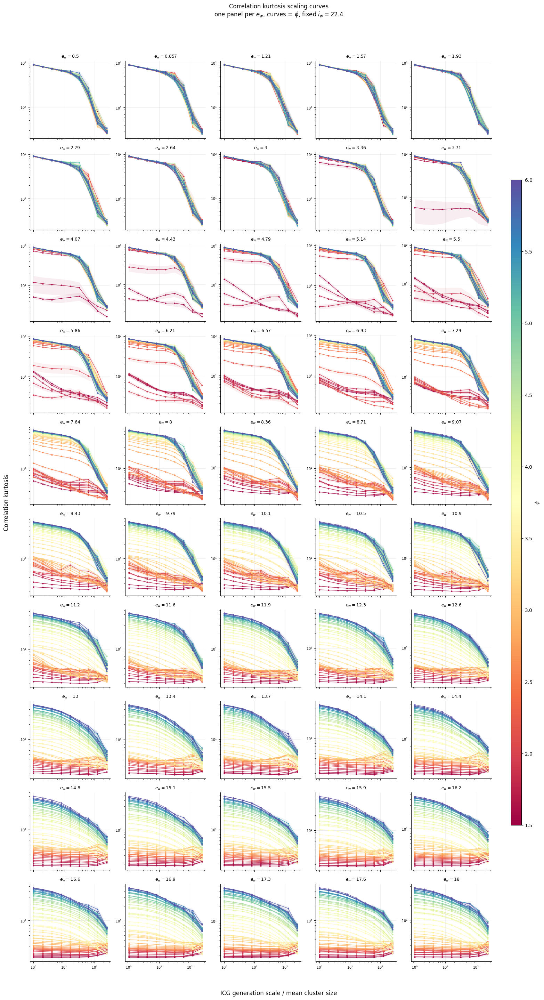

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT/kurtosis_corr_MULTIPLOT_panels_phi_lines_ew_cbar_right.png


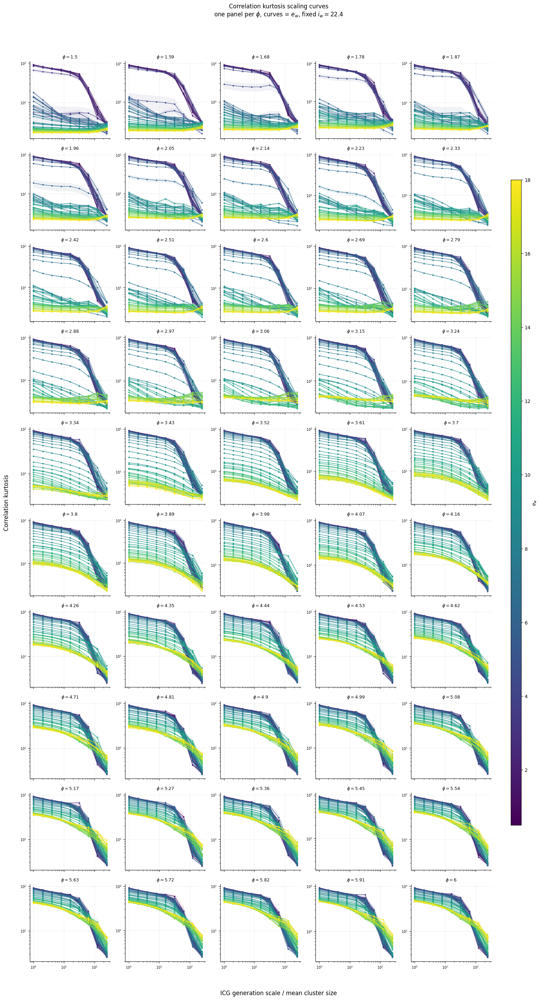


Finished. Output: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT


In [37]:
%matplotlib inline

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ============================================================
# Saved generation-level ICG curves from the newer 50 × 50 run.
# No simulations are rerun.
#
# For each metric:
#   1. 50 panels: fixed e_w, curves coloured by phi
#   2. 50 panels: fixed phi, curves coloured by e_w
# ============================================================

# ======================== PATHS ===========================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "50ew_50phis_20seeds_10000avals"
)

ICGDIR = OUTDIR / "icg_rows_by_network"
FIGDIR = OUTDIR / "actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT"
FIGDIR.mkdir(parents=True, exist_ok=True)

GEN_CURVE_CSV = FIGDIR / "icg_generation_scaling_curves_aggregated.csv"

# ======================== CONTROLS ========================

SELECT_EW_VALUES = None
SELECT_PHI_VALUES = None

LOG_X = True
LOG_Y_IF_POSITIVE = True
MIN_POINTS_PER_CURVE = 3

N_COLS = 5
SAVE_FIGS = True
SHOW_FIGS = True
SAVE_DPI = 200

EW_CMAP = plt.get_cmap("viridis")
PHI_CMAP = plt.get_cmap("Spectral")

# ======================== HELPERS =========================

def sem(values):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    return (
        float(values.std(ddof=1) / np.sqrt(len(values)))
        if len(values) > 1 else np.nan
    )


def standardise_gen_df(frame):
    frame = frame.copy()
    aliases = {
        "MV_norm": "mean_variance_norm",
        "TAU_norm": "timescale_norm",
        "corr_kurtosis": "kurtosis_corr",
        "MV": "mean_variance",
        "TAU": "timescale",
    }
    for old, new in aliases.items():
        if new not in frame.columns and old in frame.columns:
            frame[new] = frame[old]
    return frame


def nearest_values(available, selected):
    available = np.asarray(available, float)
    if selected is None:
        return available
    return np.unique([
        available[np.argmin(np.abs(available - float(value)))]
        for value in selected
    ])


# ======================== LOAD ============================

config = json.loads((OUTDIR / "config.json").read_text())

configured_ew = np.asarray(config["EW_VALUES"], float)
configured_phi = np.asarray(config["PHI_VALUES"], float)
fixed_iw = float(config["I_W_FIXED"])

if len(configured_ew) != 50 or len(configured_phi) != 50:
    raise ValueError("Expected the newer 50 × 50 configuration.")

files = sorted(ICGDIR.glob("*_icg.csv.gz"))
if not files:
    raise FileNotFoundError(f"No *_icg.csv.gz files in {ICGDIR}")

metrics = {
    "mean_variance_norm": "Mean-variance",
    "timescale_norm": "Timescale",
    "kurtosis_corr": "Correlation kurtosis",
}

required = [
    "mean_cluster_size",
    "e_w",
    "i_w",
    "phi",
    "seed_idx",
    *metrics,
]

frames = []
skipped = 0

for path in tqdm(files, desc="Loading saved 50 × 50 ICG curves"):
    frame = standardise_gen_df(pd.read_csv(path))
    missing = set(required) - set(frame.columns)

    if missing:
        print(f"Skipping {path.name}: missing {sorted(missing)}")
        skipped += 1
        continue

    frame = frame[required].copy()

    for column in required:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

    if not np.allclose(frame["i_w"], fixed_iw):
        raise ValueError(f"{path.name}: unexpected i_w.")

    if not frame["e_w"].map(
        lambda value: np.any(np.isclose(configured_ew, value))
    ).all():
        raise ValueError(f"{path.name}: e_w outside configured grid.")

    if not frame["phi"].map(
        lambda value: np.any(np.isclose(configured_phi, value))
    ).all():
        raise ValueError(f"{path.name}: phi outside configured grid.")

    frames.append(frame)

if not frames:
    raise ValueError("No usable generation-level files.")

gen_raw = (
    pd.concat(frames, ignore_index=True)
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["e_w", "phi", "seed_idx", "mean_cluster_size"])
)

if gen_raw.duplicated(
    ["e_w", "phi", "seed_idx", "mean_cluster_size"]
).any():
    raise ValueError("Duplicate network × generation rows.")

# ======================== AGGREGATE =======================
# Same convention as your original:
# group by e_w, phi and mean_cluster_size; average across seeds.

aggregations = {
    "n": ("seed_idx", "nunique"),
    "i_w": ("i_w", "first"),
}

for metric in metrics:
    aggregations[f"{metric}_mean"] = (metric, "mean")
    aggregations[f"{metric}_sem"] = (metric, sem)

gen_curve = (
    gen_raw.groupby(
        ["e_w", "phi", "mean_cluster_size"],
        as_index=False,
    )
    .agg(**aggregations)
    .sort_values(["e_w", "phi", "mean_cluster_size"])
    .reset_index(drop=True)
)

gen_curve.to_csv(GEN_CURVE_CSV, index=False)

EW_VALUES = np.sort(gen_curve["e_w"].unique())
PHI_VALUES = np.sort(gen_curve["phi"].unique())

PLOT_EW_VALUES = nearest_values(EW_VALUES, SELECT_EW_VALUES)
PLOT_PHI_VALUES = nearest_values(PHI_VALUES, SELECT_PHI_VALUES)

if not len(PLOT_EW_VALUES) or not len(PLOT_PHI_VALUES):
    raise ValueError("No values selected for plotting.")

EW_NORM = plt.Normalize(configured_ew.min(), configured_ew.max())
PHI_NORM = plt.Normalize(configured_phi.min(), configured_phi.max())

print("Data:", OUTDIR)
print(f"Loaded files: {len(frames):,}; skipped: {skipped}")
print(f"Generation rows: {len(gen_raw):,}")
print(f"Available e_w values: {len(EW_VALUES)}/50")
print(f"Available phi values: {len(PHI_VALUES)}/50")
print("Aggregated curves:", GEN_CURVE_CSV)

# ======================== MULTIPANEL PLOTS =================

def plot_metric_grid(metric, ylabel, fixed_parameter):
    if fixed_parameter == "e_w":
        panel_values = PLOT_EW_VALUES
        curve_values = PLOT_PHI_VALUES
        curve_parameter = "phi"
        cmap, norm = PHI_CMAP, PHI_NORM
        panel_symbol, curve_symbol = r"e_w", r"\phi"
        filename_suffix = "panels_ew_lines_phi"
    else:
        panel_values = PLOT_PHI_VALUES
        curve_values = PLOT_EW_VALUES
        curve_parameter = "e_w"
        cmap, norm = EW_CMAP, EW_NORM
        panel_symbol, curve_symbol = r"\phi", r"e_w"
        filename_suffix = "panels_phi_lines_ew"

    ycol = f"{metric}_mean"
    ecol = f"{metric}_sem"

    n_panels = len(panel_values)
    ncols = min(N_COLS, n_panels)
    nrows = int(np.ceil(n_panels / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(3.3 * ncols, 2.9 * nrows),
        sharex=True,
        sharey=False,
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, panel_value in zip(axes, panel_values):
        panel = gen_curve.loc[
            np.isclose(gen_curve[fixed_parameter], panel_value)
        ]

        curves = []

        for curve_value in curve_values:
            curve = (
                panel.loc[
                    np.isclose(panel[curve_parameter], curve_value)
                ]
                .dropna(subset=["mean_cluster_size", ycol])
                .sort_values("mean_cluster_size")
            )

            if len(curve) < MIN_POINTS_PER_CURVE:
                continue

            x = curve["mean_cluster_size"].to_numpy(float)
            y = curve[ycol].to_numpy(float)
            error = curve[ecol].to_numpy(float)

            curves.append((curve_value, x, y, error))

        if curves:
            all_x = np.concatenate([curve[1] for curve in curves])
            all_y = np.concatenate([curve[2] for curve in curves])

            use_log_x = LOG_X and np.all(all_x > 0)
            use_log_y = LOG_Y_IF_POSITIVE and np.all(all_y > 0)

            if use_log_x:
                ax.set_xscale("log")
            if use_log_y:
                ax.set_yscale("log")

            for curve_value, x, y, error in curves:
                colour = cmap(norm(float(curve_value)))

                ax.plot(
                    x, y,
                    marker="o",
                    linewidth=1.0,
                    markersize=2.2,
                    color=colour,
                    alpha=0.85,
                )

                lower, upper = y - error, y + error
                band_valid = np.isfinite(error)

                if use_log_y:
                    band_valid &= lower > 0

                ax.fill_between(
                    x,
                    lower,
                    upper,
                    where=band_valid,
                    color=colour,
                    alpha=0.07,
                    linewidth=0,
                )

        ax.set_title(
            rf"${panel_symbol}={panel_value:.3g}$",
            fontsize=9,
        )
        ax.grid(alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=7)

    for ax in axes[n_panels:]:
        ax.axis("off")

    fig.supxlabel("ICG generation scale / mean cluster size")
    fig.supylabel(ylabel)
    fig.suptitle(
        f"{ylabel} scaling curves\n"
        rf"one panel per ${panel_symbol}$, "
        rf"curves = ${curve_symbol}$, fixed $i_w={fixed_iw:.3g}$",
        y=0.995,
    )

    # Keep the colourbar outside the panel grid.
    fig.tight_layout(rect=[0.02, 0.02, 0.88, 0.97])
    cax = fig.add_axes([0.905, 0.18, 0.018, 0.64])

    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label(rf"${curve_symbol}$")

    if SAVE_FIGS:
        path = FIGDIR / (
            f"{metric}_MULTIPLOT_{filename_suffix}_cbar_right.png"
        )
        fig.savefig(path, dpi=SAVE_DPI, bbox_inches="tight")
        print("Saved:", path)

    if SHOW_FIGS:
        plt.show()

    plt.close(fig)


# ======================== RUN =============================

for metric, ylabel in metrics.items():
    print(f"\nPlotting: {ylabel}")

    plot_metric_grid(
        metric=metric,
        ylabel=ylabel,
        fixed_parameter="e_w",
    )

    plot_metric_grid(
        metric=metric,
        ylabel=ylabel,
        fixed_parameter="phi",
    )

print("\nFinished. Output:", FIGDIR)

Loaded 50 e_w values × 50 phi values.


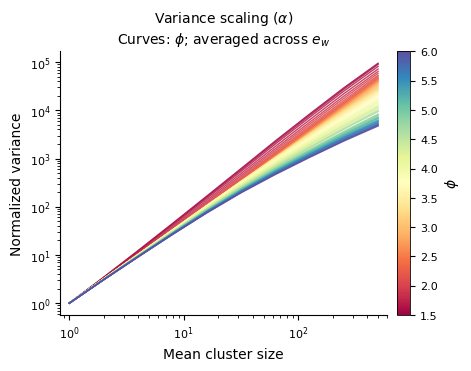

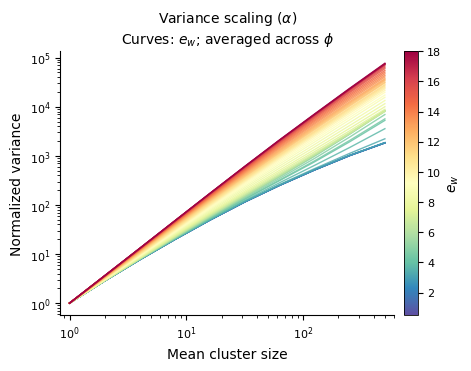

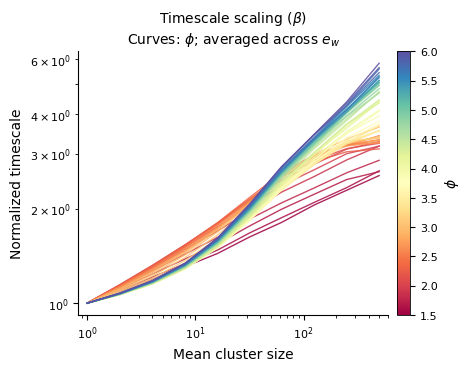

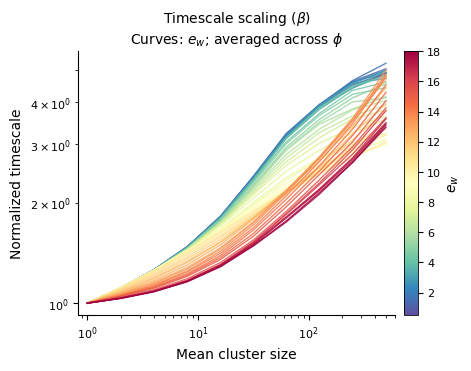

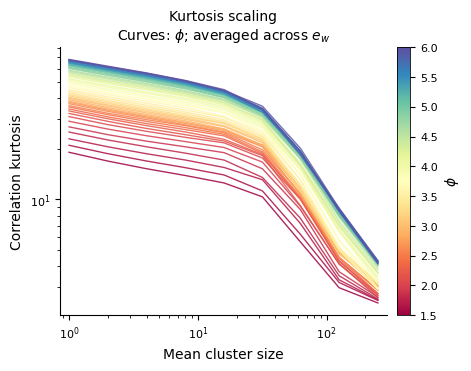

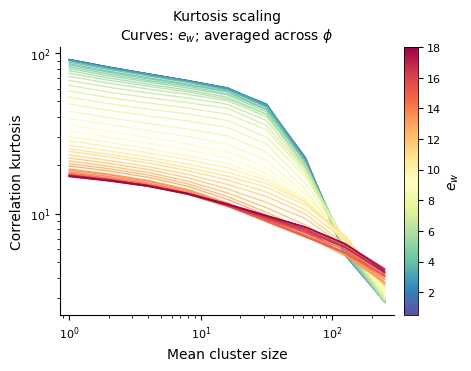

Saved panels and marginal curves to: /home/dburrows/DATA/BLNDEV-WILDTYPE/grid_ew_phi_iw22p4_sparse_avalanche_icg_50ew_50phis_20seeds_10000avals/figure_ready_marginal_ICG_curves


In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ======================== SETTINGS ========================

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "grid_ew_phi_iw22p4_sparse_avalanche_icg_"
    "50ew_50phis_20seeds_10000avals"
)

# Aggregated generation curves saved by the previous block.
SOURCE = (
    OUTDIR
    / "actual_icg_scaling_curves_MULTIPLOTS_ONLY_CBAR_RIGHT"
    / "icg_generation_scaling_curves_aggregated.csv"
)

FIGDIR = OUTDIR / "figure_ready_marginal_ICG_curves"

PHI_CMAP = "Spectral"
EW_CMAP = "Spectral_r"
LOG_X = True
LOG_Y_IF_POSITIVE = True

MIN_POINTS_PER_CURVE = 3

# None includes all available values.
SELECT_PHI_VALUES = None
SELECT_EW_VALUES = None

FIGSIZE = (4.6, 3.6)
LINEWIDTH = 1.0
LINE_ALPHA = 0.85

SAVE_FIGURES = True
SHOW_FIGURES = True

plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# ======================== LOAD ============================

if not SOURCE.exists():
    raise FileNotFoundError(
        f"{SOURCE}\nRun the generation-level aggregation block first."
    )

gen_curve = pd.read_csv(SOURCE)
gen_curve.replace([np.inf, -np.inf], np.nan, inplace=True)

METRICS = {
    "mean_variance_norm": {
        "ylabel": "Normalized variance",
        "title": r"Variance scaling ($\alpha$)",
        "tag": "alpha_variance_scaling",
    },
    "timescale_norm": {
        "ylabel": "Normalized timescale",
        "title": r"Timescale scaling ($\beta$)",
        "tag": "beta_timescale_scaling",
    },
    "kurtosis_corr": {
        "ylabel": "Correlation kurtosis",
        "title": "Kurtosis scaling",
        "tag": "kurtosis_scaling",
    },
}

required = [
    "e_w", "phi", "mean_cluster_size",
    *[f"{metric}_mean" for metric in METRICS],
]
missing = set(required) - set(gen_curve.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if gen_curve.duplicated(
    ["e_w", "phi", "mean_cluster_size"]
).any():
    raise ValueError("Duplicate grid-cell × generation rows.")

print(
    f"Loaded {gen_curve['e_w'].nunique()} e_w values × "
    f"{gen_curve['phi'].nunique()} phi values."
)

# ======================== MARGINAL MEANS ==================
# Source values are already means across seeds.
#
# Fixed phi:
#   average cell means across e_w at each mean_cluster_size.
#
# Fixed e_w:
#   average cell means across phi at each mean_cluster_size.
#
# No exponent fitting is performed here: these are the actual
# generation-level scaling curves.

marginal_curves = {}

for parameter in ["phi", "e_w"]:
    aggregations = {}

    for metric in METRICS:
        column = f"{metric}_mean"
        aggregations[column] = (column, "mean")
        aggregations[f"{metric}_n_cells"] = (column, "count")

    marginal_curves[parameter] = (
        gen_curve.dropna(
            subset=[parameter, "mean_cluster_size"]
        )
        .groupby(
            [parameter, "mean_cluster_size"],
            as_index=False,
        )
        .agg(**aggregations)
        .sort_values([parameter, "mean_cluster_size"])
        .reset_index(drop=True)
    )


def selected_values(available, requested):
    available = np.sort(np.asarray(available, float))

    if requested is None:
        return available

    return np.unique([
        available[np.argmin(np.abs(available - float(value)))]
        for value in requested
    ])


# ======================== PLOTTING ========================

def plot_marginal_curves(parameter, metric, settings):
    data = marginal_curves[parameter]
    ycol = f"{metric}_mean"

    available = np.sort(data[parameter].unique())

    requested = (
        SELECT_PHI_VALUES
        if parameter == "phi"
        else SELECT_EW_VALUES
    )
    values = selected_values(available, requested)

    if not len(values):
        raise ValueError(f"No selected {parameter} values.")

    cmap = plt.get_cmap(PHI_CMAP if parameter == "phi" else EW_CMAP)
    norm = Normalize(
        vmin=available.min(),
        vmax=available.max(),
    )

    curves = []

    for value in values:
        curve = (
            data.loc[np.isclose(data[parameter], value)]
            .dropna(subset=["mean_cluster_size", ycol])
            .sort_values("mean_cluster_size")
        )

        if LOG_X:
            curve = curve.loc[curve["mean_cluster_size"] > 0]

        if len(curve) < MIN_POINTS_PER_CURVE:
            continue

        curves.append((
            value,
            curve["mean_cluster_size"].to_numpy(float),
            curve[ycol].to_numpy(float),
        ))

    if not curves:
        print(f"No usable curves: {parameter}, {metric}")
        return

    # Choose one consistent y-axis scale for the whole panel.
    all_y = np.concatenate([y for _, _, y in curves])
    use_log_y = LOG_Y_IF_POSITIVE and np.all(all_y > 0)

    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for value, x, y in curves:
        ax.plot(
            x, y,
            color=cmap(norm(value)),
            lw=LINEWIDTH,
            alpha=LINE_ALPHA,
        )

    if LOG_X:
        ax.set_xscale("log")
    if use_log_y:
        ax.set_yscale("log")

    if parameter == "phi":
        subtitle = r"Curves: $\phi$; averaged across $e_w$"
        colour_label = r"$\phi$"
        suffix = "phi_curves_mean_over_ew"
    else:
        subtitle = r"Curves: $e_w$; averaged across $\phi$"
        colour_label = r"$e_w$"
        suffix = "ew_curves_mean_over_phi"

    ax.set(
        xlabel="Mean cluster size",
        ylabel=settings["ylabel"],
        title=settings["title"] + "\n" + subtitle,
    )

    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(which="both", direction="out")
    ax.margins(x=0.03)

    cbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        pad=0.03,
        fraction=0.05,
    )
    cbar.set_label(colour_label)
    cbar.outline.set_linewidth(0.6)

    if SAVE_FIGURES:
        FIGDIR.mkdir(parents=True, exist_ok=True)

        stem = f"{settings['tag']}_{suffix}"
        for extension in ["png", "pdf", "svg"]:
            fig.savefig(
                FIGDIR / f"{stem}.{extension}",
                dpi=300,
                bbox_inches="tight",
            )

    if SHOW_FIGURES:
        plt.show()

    plt.close(fig)


# ======================== RUN =============================

for metric, settings in METRICS.items():
    plot_marginal_curves("phi", metric, settings)
    plot_marginal_curves("e_w", metric, settings)

if SAVE_FIGURES:
    for parameter, frame in marginal_curves.items():
        frame.to_csv(
            FIGDIR / f"marginal_generation_curves_by_{parameter}.csv",
            index=False,
        )

    print("Saved panels and marginal curves to:", FIGDIR)

LLR > 5:   0%|          | 0/199 [00:00<?, ?it/s]

LLR > 7.78:   0%|          | 0/199 [00:00<?, ?it/s]

LLR > 10.6:   0%|          | 0/199 [00:00<?, ?it/s]

LLR > 13.3:   0%|          | 0/199 [00:00<?, ?it/s]

LLR > 16.1:   0%|          | 0/199 [00:00<?, ?it/s]

LLR > 18.9:   0%|          | 0/199 [00:00<?, ?it/s]

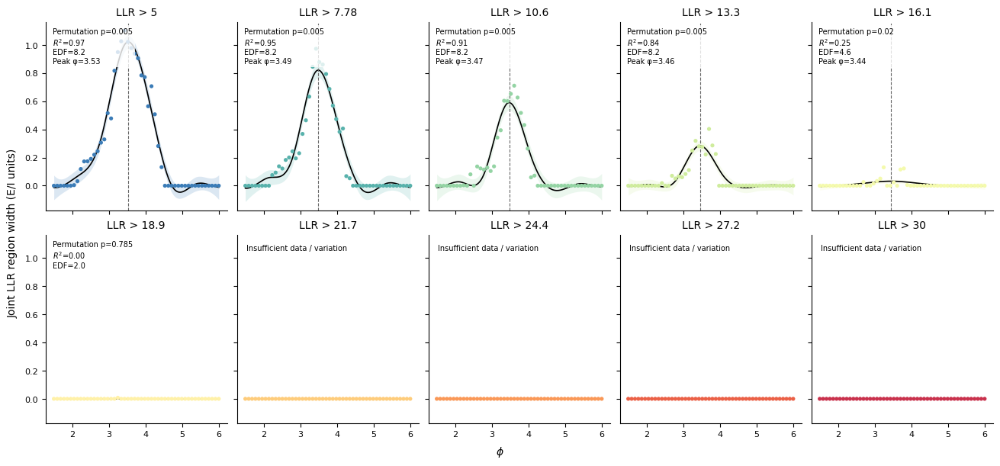

 threshold  n_phi  selected_lambda  effective_degrees_of_freedom  R_squared  p_permutation  peak_phi  peak_width  peak_inside_range
  5.000000     50             0.01                      8.164420   0.974912          0.005  3.529058    1.021451               True
  7.777778     50             0.01                      8.164420   0.951831          0.005  3.492986    0.820635               True
 10.555556     50             0.01                      8.164420   0.909114          0.005  3.474950    0.590008               True
 13.333333     50             0.01                      8.164420   0.835841          0.005  3.456914    0.284020               True
 16.111111     50             1.00                      4.594857   0.247335          0.020  3.438878    0.032114               True
 18.888889     50         10000.00                      2.004030   0.003188          0.785  1.500000    0.000257              False

Bands: approximate pointwise 95% GAM confidence intervals.
P-values: permut

In [52]:
# Requires:
# phi_values, ei_values, grids, FIGDIR
#
# If needed, install once in a notebook cell:
# %pip install pygam

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pygam import LinearGAM, s
from tqdm.auto import tqdm

# ======================== SETTINGS ========================

LLR_THRESHOLDS = np.linspace(5.0, 30.0, 10)

N_SPLINES = 10
LAMBDA_GRID = np.logspace(-2, 4, 13)

# Permutations test whether width varies with phi.
# Smoothing is reselected for every permutation.
# Increase to 999 or more for finer p-value resolution.
N_PERMUTATIONS = 199
RANDOM_SEED = 42

SAVE_RESULTS = True

# ======================== WIDTH FUNCTION ==================

def calculate_widths(threshold):
    rows = []

    for ix, phi in enumerate(phi_values):
        margins = [
            grids["size"][:, ix] - threshold,
            grids["duration"][:, ix] - threshold,
        ]

        finite = np.isfinite(margins[0]) & np.isfinite(margins[1])
        valid_pairs = finite[:-1] & finite[1:]

        width = 0.0

        for j in np.flatnonzero(valid_pairs):
            lower, upper = 0.0, 1.0

            for margin in margins:
                left = margin[j]
                change = margin[j + 1] - left

                if change == 0:
                    if left <= 0:
                        upper = lower
                        break
                elif change > 0:
                    lower = max(lower, -left / change)
                else:
                    upper = min(upper, -left / change)

            if upper > lower:
                width += (
                    (upper - lower)
                    * (ei_values[j + 1] - ei_values[j])
                )

        edge_qualifies = (
            (finite[0] and all(m[0] > 0 for m in margins))
            or
            (finite[-1] and all(m[-1] > 0 for m in margins))
        )

        rows.append({
            "threshold": float(threshold),
            "phi": float(phi),
            "EI_width": width if valid_pairs.any() else np.nan,
            "n_unresolved_intervals": int((~valid_pairs).sum()),
            "region_reaches_EI_grid_edge": bool(edge_qualifies),
        })

    return pd.DataFrame(rows)


# ======================== GAM HELPERS =====================

def fit_gam(X, y):
    n_splines = min(N_SPLINES, len(y) - 1)

    return LinearGAM(
        s(0, n_splines=n_splines, spline_order=3)
    ).gridsearch(
        X,
        y,
        lam=LAMBDA_GRID,
        objective="GCV",
        progress=False,
    )


def fitted_r_squared(model, X, y):
    residual_ss = np.sum((y - model.predict(X))**2)
    total_ss = np.sum((y - y.mean())**2)
    return float(1 - residual_ss / total_ss)


# ======================== FIT + PLOT ======================

rng = np.random.default_rng(RANDOM_SEED)

fig, axes = plt.subplots(
    2, 5,
    figsize=(13, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
axes = axes.ravel()

colours = plt.get_cmap("Spectral_r")(
    np.linspace(0.08, 0.92, len(LLR_THRESHOLDS))
)

all_widths = []
fit_rows = []
curve_rows = []
permutation_rows = []

for ax, threshold, colour in zip(axes, LLR_THRESHOLDS, colours):
    widths = calculate_widths(threshold)
    all_widths.append(widths)

    data = (
        widths.dropna(subset=["phi", "EI_width"])
        .sort_values("phi")
    )

    ax.scatter(
        data["phi"],
        data["EI_width"],
        s=14,
        color=colour,
        edgecolors="none",
        zorder=3,
    )

    ax.set_title(f"LLR > {threshold:.3g}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)

    if len(data) < 8 or data["EI_width"].nunique() < 2:
        ax.text(
            0.05, 0.95,
            "Insufficient data / variation",
            transform=ax.transAxes,
            va="top",
            fontsize=7,
        )
        continue

    phi = data["phi"].to_numpy(float)
    y = data["EI_width"].to_numpy(float)

    # Scale phi to [0, 1] for fitting.
    phi_min = float(phi.min())
    phi_range = float(np.ptp(phi))

    X = ((phi - phi_min) / phi_range)[:, None]

    gam = fit_gam(X, y)
    r_squared = fitted_r_squared(gam, X, y)

    # -------------------- PERMUTATION TEST -----------------
    # Null: widths are exchangeable across phi.
    # Statistic: fitted R².
    # Repeat the entire smoothing-selection procedure.

    null_r_squared = np.empty(N_PERMUTATIONS)

    for repeat in tqdm(
        range(N_PERMUTATIONS),
        desc=f"LLR > {threshold:.3g}",
        leave=False,
    ):
        shuffled_y = rng.permutation(y)
        null_gam = fit_gam(X, shuffled_y)

        null_r_squared[repeat] = fitted_r_squared(
            null_gam, X, shuffled_y
        )

        permutation_rows.append({
            "threshold": threshold,
            "permutation": repeat,
            "null_R_squared": null_r_squared[repeat],
        })

    p_permutation = (
        1 + np.count_nonzero(null_r_squared >= r_squared)
    ) / (N_PERMUTATIONS + 1)

    # -------------------- PREDICTIONS ----------------------

    line_phi = np.linspace(phi.min(), phi.max(), 500)
    X_line = ((line_phi - phi_min) / phi_range)[:, None]

    fitted = gam.predict(X_line)
    intervals = gam.confidence_intervals(X_line, width=0.95)

    peak_idx = int(np.argmax(fitted))
    peak_phi = float(line_phi[peak_idx])
    peak_inside = 0 < peak_idx < len(line_phi) - 1

    ax.plot(
        line_phi,
        fitted,
        color="black",
        lw=1.2,
    )

    ax.fill_between(
        line_phi,
        intervals[:, 0],
        intervals[:, 1],
        color=colour,
        alpha=0.18,
        linewidth=0,
    )

    if peak_inside:
        ax.axvline(
            peak_phi,
            color="0.4",
            ls="--",
            lw=0.8,
        )

    edf = float(gam.statistics_["edof"])
    selected_lambda = float(np.asarray(gam.lam).ravel()[0])

    annotation = (
        f"Permutation p={p_permutation:.3g}\n"
        rf"$R^2$={r_squared:.2f}"
        f"\nEDF={edf:.1f}"
    )

    if peak_inside:
        annotation += f"\nPeak φ={peak_phi:.2f}"

    ax.text(
        0.04, 0.97,
        annotation,
        transform=ax.transAxes,
        va="top",
        fontsize=7,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=2,
        ),
    )

    fit_rows.append({
        "threshold": threshold,
        "n_phi": len(data),
        "selected_lambda": selected_lambda,
        "effective_degrees_of_freedom": edf,
        "R_squared": r_squared,
        "p_permutation": p_permutation,
        "peak_phi": peak_phi,
        "peak_width": float(fitted[peak_idx]),
        "peak_inside_range": peak_inside,
    })

    curve_rows.append(pd.DataFrame({
        "threshold": threshold,
        "phi": line_phi,
        "fitted_width": fitted,
        "CI95_low": intervals[:, 0],
        "CI95_high": intervals[:, 1],
    }))

fig.supxlabel(r"$\phi$", fontsize=10)
fig.supylabel("Joint LLR region width (E/I units)", fontsize=10)

widths_by_threshold = pd.concat(all_widths, ignore_index=True)
gam_fits = pd.DataFrame(fit_rows)

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    widths_by_threshold.to_csv(
        FIGDIR / "widths_ten_thresholds_GAM.csv",
        index=False,
    )
    gam_fits.to_csv(
        FIGDIR / "GAM_fits_ten_thresholds.csv",
        index=False,
    )

    if curve_rows:
        pd.concat(curve_rows, ignore_index=True).to_csv(
            FIGDIR / "GAM_fitted_curves.csv",
            index=False,
        )

    pd.DataFrame(permutation_rows).to_csv(
        FIGDIR / "GAM_permutation_results.csv",
        index=False,
    )

    for extension in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"GAM_width_ten_thresholds.{extension}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(gam_fits.round(6).to_string(index=False))
print(
    "\nBands: approximate pointwise 95% GAM confidence intervals."
    "\nP-values: permutation tests of overall association, "
    "unadjusted across thresholds."
    f"\nSmallest possible permutation p: {1 / (N_PERMUTATIONS + 1):.4g}."
    "\nWidths exclude unresolved intervals.")

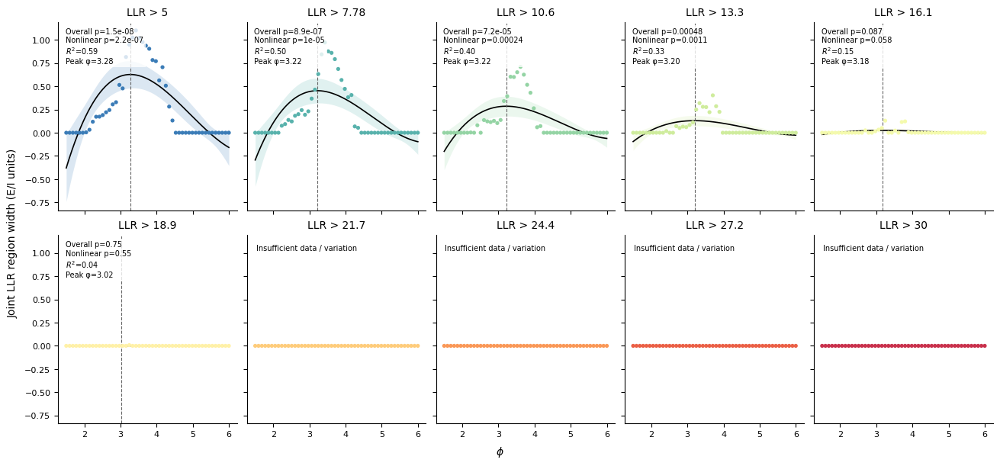

 threshold  n_phi  phi_centre  phi_scale  R_squared  adjusted_R_squared  p_overall  p_nonlinear  p_cubic  maximum_phi  maximum_width  peak_inside_range  p_overall_bonferroni  p_nonlinear_bonferroni  p_cubic_bonferroni
  5.000000     50        3.75   1.325284   0.590933            0.564255   0.000000     0.000000 0.040047     3.275437       0.627884               True              0.000000                0.000002            0.400467
  7.777778     50        3.75   1.325284   0.504558            0.472247   0.000001     0.000010 0.023627     3.220247       0.453251               True              0.000009                0.000103            0.236273
 10.555556     50        3.75   1.325284   0.396297            0.356925   0.000072     0.000243 0.033982     3.218838       0.285955               True              0.000725                0.002434            0.339822
 13.333333     50        3.75   1.325284   0.333800            0.290352   0.000478     0.001135 0.034513     3.202044       0.13

In [56]:
# Requires:
# phi_values, ei_values, grids, FIGDIR

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# ======================== SETTINGS ========================

LLR_THRESHOLDS = np.linspace(5.0, 30.0, 10)
SAVE_RESULTS = True

# ======================== WIDTH FUNCTION ==================

def calculate_widths(threshold):
    rows = []

    for ix, phi in enumerate(phi_values):
        margins = [
            grids["size"][:, ix] - threshold,
            grids["duration"][:, ix] - threshold,
        ]

        finite = np.isfinite(margins[0]) & np.isfinite(margins[1])
        valid_pairs = finite[:-1] & finite[1:]

        width = 0.0

        for j in np.flatnonzero(valid_pairs):
            lower, upper = 0.0, 1.0

            for margin in margins:
                left = margin[j]
                change = margin[j + 1] - left

                if change == 0:
                    if left <= 0:
                        upper = lower
                        break
                elif change > 0:
                    lower = max(lower, -left / change)
                else:
                    upper = min(upper, -left / change)

            if upper > lower:
                width += (
                    (upper - lower)
                    * (ei_values[j + 1] - ei_values[j])
                )

        edge_qualifies = (
            (finite[0] and all(m[0] > 0 for m in margins))
            or
            (finite[-1] and all(m[-1] > 0 for m in margins))
        )

        rows.append({
            "threshold": float(threshold),
            "phi": float(phi),
            "EI_width": width if valid_pairs.any() else np.nan,
            "n_unresolved_intervals": int((~valid_pairs).sum()),
            "region_reaches_EI_grid_edge": bool(edge_qualifies),
        })

    return pd.DataFrame(rows)


def cubic_design(x):
    x = np.asarray(x, float)
    return np.column_stack([
        np.ones(len(x)),
        x,
        x**2,
        x**3,
    ])


# ======================== FIT + PLOT ======================

fig, axes = plt.subplots(
    2, 5,
    figsize=(13, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
axes = axes.ravel()

colours = plt.get_cmap("Spectral_r")(
    np.linspace(0.08, 0.92, len(LLR_THRESHOLDS))
)

all_widths = []
fit_rows = []
curve_rows = []
coefficient_rows = []

for ax, threshold, colour in zip(axes, LLR_THRESHOLDS, colours):
    widths = calculate_widths(threshold)
    all_widths.append(widths)

    data = (
        widths.dropna(subset=["phi", "EI_width"])
        .sort_values("phi")
    )

    ax.scatter(
        data["phi"],
        data["EI_width"],
        s=14,
        color=colour,
        edgecolors="none",
        zorder=3,
    )

    ax.set_title(f"LLR > {threshold:.3g}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)

    if len(data) < 8 or data["EI_width"].nunique() < 2:
        ax.text(
            0.05, 0.95,
            "Insufficient data / variation",
            transform=ax.transAxes,
            va="top",
            fontsize=7,
        )
        continue

    phi = data["phi"].to_numpy(float)
    y = data["EI_width"].to_numpy(float)

    # Centre and scale phi for numerical stability.
    centre = float(phi.mean())
    scale = float(np.std(phi))
    x = (phi - centre) / scale

    # Width = b0 + b1*x + b2*x² + b3*x³.
    X = cubic_design(x)
    model = sm.OLS(y, X).fit(cov_type="HC3", use_t=True)

    # Overall effect: b1 = b2 = b3 = 0.
    p_overall = float(model.f_test(
        np.eye(4)[1:]
    ).pvalue)

    # Nonlinearity beyond a straight line: b2 = b3 = 0.
    p_nonlinear = float(model.f_test(
        np.eye(4)[2:]
    ).pvalue)

    # Cubic contribution beyond a quadratic.
    p_cubic = float(model.pvalues[3])

    # -------------------- PREDICTIONS ----------------------

    line_phi = np.linspace(phi.min(), phi.max(), 500)
    line_x = (line_phi - centre) / scale

    prediction = model.get_prediction(
        cubic_design(line_x)
    ).summary_frame(alpha=0.05)

    fitted = prediction["mean"].to_numpy()
    low = prediction["mean_ci_lower"].to_numpy()
    high = prediction["mean_ci_upper"].to_numpy()

    ax.plot(line_phi, fitted, color="black", lw=1.2)

    ax.fill_between(
        line_phi,
        low,
        high,
        color=colour,
        alpha=0.18,
        linewidth=0,
    )

    # -------------------- MAXIMUM IN RANGE -----------------
    # Evaluate endpoints and real stationary points exactly.

    b0, b1, b2, b3 = model.params

    derivative_coefficients = np.trim_zeros(
        np.array([3 * b3, 2 * b2, b1]),
        trim="f",
    )

    roots = (
        np.roots(derivative_coefficients)
        if len(derivative_coefficients) > 1
        else np.array([])
    )

    stationary_x = [
        float(root.real)
        for root in roots
        if abs(root.imag) < 1e-8
        and x.min() < root.real < x.max()
    ]

    candidates = np.array([
        x.min(),
        x.max(),
        *stationary_x,
    ])

    candidate_widths = model.predict(cubic_design(candidates))
    maximum_idx = int(np.argmax(candidate_widths))
    maximum_x = float(candidates[maximum_idx])

    maximum_phi = centre + scale * maximum_x
    maximum_width = float(candidate_widths[maximum_idx])

    peak_inside = (
        x.min() < maximum_x < x.max()
        and (2 * b2 + 6 * b3 * maximum_x) < 0
    )

    if peak_inside:
        ax.axvline(
            maximum_phi,
            color="0.4",
            ls="--",
            lw=0.8,
        )

    annotation = (
        f"Overall p={p_overall:.2g}\n"
        f"Nonlinear p={p_nonlinear:.2g}\n"
        rf"$R^2$={model.rsquared:.2f}"
    )

    if peak_inside:
        annotation += f"\nPeak φ={maximum_phi:.2f}"

    ax.text(
        0.04, 0.97,
        annotation,
        transform=ax.transAxes,
        va="top",
        fontsize=7,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=2,
        ),
    )

    fit_rows.append({
        "threshold": threshold,
        "n_phi": len(data),
        "phi_centre": centre,
        "phi_scale": scale,
        "R_squared": model.rsquared,
        "adjusted_R_squared": model.rsquared_adj,
        "p_overall": p_overall,
        "p_nonlinear": p_nonlinear,
        "p_cubic": p_cubic,
        "maximum_phi": maximum_phi,
        "maximum_width": maximum_width,
        "peak_inside_range": peak_inside,
    })

    coefficient_ci = np.asarray(model.conf_int())

    for j, term in enumerate(["intercept", "x", "x_squared", "x_cubed"]):
        coefficient_rows.append({
            "threshold": threshold,
            "term": term,
            "coefficient": model.params[j],
            "SE_HC3": model.bse[j],
            "p_value": model.pvalues[j],
            "CI95_low": coefficient_ci[j, 0],
            "CI95_high": coefficient_ci[j, 1],
        })

    curve_rows.append(pd.DataFrame({
        "threshold": threshold,
        "phi": line_phi,
        "fitted_width": fitted,
        "CI95_low": low,
        "CI95_high": high,
    }))

fig.supxlabel(r"$\phi$", fontsize=10)
fig.supylabel("Joint LLR region width (E/I units)", fontsize=10)

widths_by_threshold = pd.concat(all_widths, ignore_index=True)
cubic_fits = pd.DataFrame(fit_rows)

# Save corrected p-values too; annotations show raw p-values.
if not cubic_fits.empty:
    for column in ["p_overall", "p_nonlinear", "p_cubic"]:
        cubic_fits[f"{column}_bonferroni"] = np.minimum(
            cubic_fits[column] * len(LLR_THRESHOLDS),
            1.0,
        )

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

    widths_by_threshold.to_csv(
        FIGDIR / "widths_ten_thresholds_cubic.csv",
        index=False,
    )
    cubic_fits.to_csv(
        FIGDIR / "cubic_fits_ten_thresholds.csv",
        index=False,
    )
    pd.DataFrame(coefficient_rows).to_csv(
        FIGDIR / "cubic_coefficients.csv",
        index=False,
    )

    if curve_rows:
        pd.concat(curve_rows, ignore_index=True).to_csv(
            FIGDIR / "cubic_fitted_curves.csv",
            index=False,
        )

    for extension in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"cubic_width_ten_thresholds.{extension}",
            dpi=300,
            bbox_inches="tight",
        )

plt.show()
plt.close(fig)

print(cubic_fits.round(6).to_string(index=False))
print(
    "\nOverall p: joint test of linear, quadratic and cubic terms."
    "\nNonlinear p: joint test of quadratic and cubic terms."
    "\nBands: pointwise 95% regression confidence intervals using HC3 errors."
    "\nPlot p-values are unadjusted; CSV also includes Bonferroni corrections."
    "\nWidths exclude unresolved intervals.")

LLR thresholds:   0%|          | 0/30 [00:00<?, ?it/s]

LLR > 1:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 2:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 3:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 4:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 5:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 6:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 7:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 8:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 9:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 10:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 11:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 12:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 13:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 14:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 15:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 16:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 17:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 18:   0%|          | 0/1999 [00:00<?, ?it/s]

LLR > 19:   0%|          | 0/1999 [00:00<?, ?it/s]

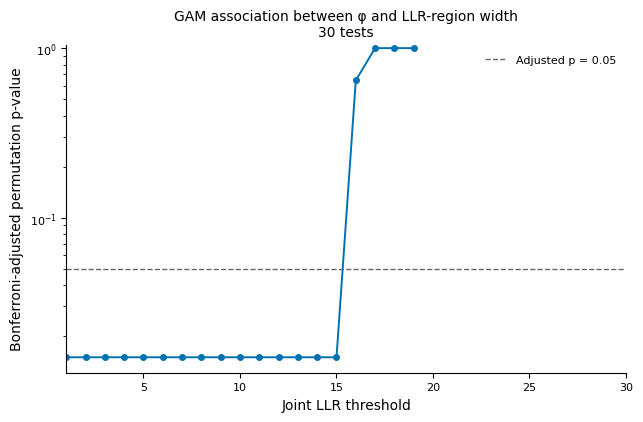

 threshold  n_phi  R_squared  selected_lambda  effective_degrees_of_freedom  n_null_at_least_observed  p_permutation  p_bonferroni                        status
       1.0     50   0.947329         0.010000                      8.164420                       0.0         0.0005         0.015                            ok
       2.0     50   0.933888         0.100000                      6.428257                       0.0         0.0005         0.015                            ok
       3.0     50   0.958371         0.031623                      7.344289                       0.0         0.0005         0.015                            ok
       4.0     50   0.973697         0.010000                      8.164420                       0.0         0.0005         0.015                            ok
       5.0     50   0.974912         0.010000                      8.164420                       0.0         0.0005         0.015                            ok
       6.0     50   0.968092      

In [55]:
# Requires:
# phi_values, ei_values, grids, FIGDIR
#
# If needed:
# %pip install pygam

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pygam import LinearGAM, s
from tqdm.auto import tqdm

# ======================== SETTINGS ========================

LLR_THRESHOLDS = np.linspace(1.0, 30.0, 30)

N_SPLINES = 10
LAMBDA_GRID = np.logspace(-2, 4, 13)

N_PERMUTATIONS = 1999
RANDOM_SEED = 42

SAVE_RESULTS = True
ALPHA = 0.05

# Correct across all 30 planned threshold tests.
N_TESTS = len(LLR_THRESHOLDS)

# ======================== WIDTH FUNCTION ==================

def calculate_widths(threshold):
    rows = []

    for ix, phi in enumerate(phi_values):
        margins = [
            grids["size"][:, ix] - threshold,
            grids["duration"][:, ix] - threshold,
        ]

        finite = np.isfinite(margins[0]) & np.isfinite(margins[1])
        valid_pairs = finite[:-1] & finite[1:]

        width = 0.0

        for j in np.flatnonzero(valid_pairs):
            lower, upper = 0.0, 1.0

            for margin in margins:
                left = margin[j]
                change = margin[j + 1] - left

                if change == 0:
                    if left <= 0:
                        upper = lower
                        break
                elif change > 0:
                    lower = max(lower, -left / change)
                else:
                    upper = min(upper, -left / change)

            if upper > lower:
                width += (
                    (upper - lower)
                    * (ei_values[j + 1] - ei_values[j])
                )

        edge_qualifies = (
            (finite[0] and all(m[0] > 0 for m in margins))
            or
            (finite[-1] and all(m[-1] > 0 for m in margins))
        )

        rows.append({
            "threshold": float(threshold),
            "phi": float(phi),
            "EI_width": width if valid_pairs.any() else np.nan,
            "n_unresolved_intervals": int((~valid_pairs).sum()),
            "region_reaches_EI_grid_edge": bool(edge_qualifies),
        })

    return pd.DataFrame(rows)


# ======================== GAM HELPERS =====================

def fit_gam(X, y):
    return LinearGAM(
        s(
            0,
            n_splines=min(N_SPLINES, len(y) - 1),
            spline_order=3,
        )
    ).gridsearch(
        X,
        y,
        lam=LAMBDA_GRID,
        objective="GCV",
        progress=False,
    )


def fitted_r_squared(model, X, y):
    residual_ss = np.sum((y - model.predict(X))**2)
    total_ss = np.sum((y - y.mean())**2)
    return float(1 - residual_ss / total_ss)


# ======================== PERMUTATION TESTS ================

if N_PERMUTATIONS < 1:
    raise ValueError("N_PERMUTATIONS must be positive.")

rng = np.random.default_rng(RANDOM_SEED)

fit_rows = []
all_widths = []

if SAVE_RESULTS:
    FIGDIR.mkdir(parents=True, exist_ok=True)

for threshold in tqdm(LLR_THRESHOLDS, desc="LLR thresholds"):
    widths = calculate_widths(threshold)
    all_widths.append(widths)

    data = (
        widths.dropna(subset=["phi", "EI_width"])
        .sort_values("phi")
    )

    result = {
        "threshold": float(threshold),
        "n_phi": len(data),
        "R_squared": np.nan,
        "selected_lambda": np.nan,
        "effective_degrees_of_freedom": np.nan,
        "n_null_at_least_observed": np.nan,
        "p_permutation": np.nan,
        "p_bonferroni": np.nan,
        "status": "Insufficient data / variation",
    }

    if len(data) >= 8 and data["EI_width"].nunique() >= 2:
        phi = data["phi"].to_numpy(float)
        y = data["EI_width"].to_numpy(float)

        X = ((phi - phi.min()) / np.ptp(phi))[:, None]

        gam = fit_gam(X, y)
        observed_r2 = fitted_r_squared(gam, X, y)

        null_r2 = np.empty(N_PERMUTATIONS)

        for repeat in tqdm(
            range(N_PERMUTATIONS),
            desc=f"LLR > {threshold:g}",
            leave=False,
        ):
            shuffled_y = rng.permutation(y)

            # Reselect smoothing for every shuffled dataset.
            null_gam = fit_gam(X, shuffled_y)
            null_r2[repeat] = fitted_r_squared(
                null_gam, X, shuffled_y
            )

        n_exceed = int(np.count_nonzero(null_r2 >= observed_r2))
        p_raw = (1 + n_exceed) / (N_PERMUTATIONS + 1)

        result.update({
            "R_squared": observed_r2,
            "selected_lambda": float(np.asarray(gam.lam).ravel()[0]),
            "effective_degrees_of_freedom": float(
                gam.statistics_["edof"]
            ),
            "n_null_at_least_observed": n_exceed,
            "p_permutation": p_raw,
            "p_bonferroni": min(p_raw * N_TESTS, 1.0),
            "status": "ok",
        })

        if SAVE_RESULTS:
            pd.DataFrame({
                "permutation": np.arange(N_PERMUTATIONS),
                "null_R_squared": null_r2,
            }).to_csv(
                FIGDIR / f"GAM_null_LLR_{threshold:g}.csv",
                index=False,
            )

    fit_rows.append(result)

    # Save progress after every threshold.
    if SAVE_RESULTS:
        pd.DataFrame(fit_rows).to_csv(
            FIGDIR / "GAM_pvalues_LLR_1to30.csv",
            index=False,
        )

gam_pvalues = pd.DataFrame(fit_rows)
widths_by_threshold = pd.concat(all_widths, ignore_index=True)

# ======================== P-VALUE PLOT =====================

fig, ax = plt.subplots(figsize=(6.5, 4.3))

ax.plot(
    gam_pvalues["threshold"],
    gam_pvalues["p_bonferroni"],
    "o-",
    color="#0072B2",
    ms=4,
    lw=1.4,
)

ax.axhline(
    ALPHA,
    color="0.4",
    ls="--",
    lw=1,
    label=f"Adjusted p = {ALPHA:g}",
)

ax.set(
    xlabel="Joint LLR threshold",
    ylabel="Bonferroni-adjusted permutation p-value",
    title=f"GAM association between φ and LLR-region width\n{N_TESTS} tests",
    xlim=(LLR_THRESHOLDS.min(), LLR_THRESHOLDS.max()),
)
ax.set_yscale("log")
ax.set_ylim(top=1.05)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

if SAVE_RESULTS:
    widths_by_threshold.to_csv(
        FIGDIR / "GAM_widths_LLR_1to30.csv",
        index=False,
    )

    for extension in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGDIR / f"GAM_pvalues_bonferroni_LLR_1to30.{extension}",
            dpi=300,
            bbox_inches="tight",
        )
plt.show()
plt.close(fig)

print(gam_pvalues.to_string(index=False))
print(
    f"\nSmallest possible raw p: "
    f"{1 / (N_PERMUTATIONS + 1):.6g}"
    f"\nSmallest possible Bonferroni-adjusted p: "
    f"{min(N_TESTS / (N_PERMUTATIONS + 1), 1):.6g}"
)
print(
    "\nTests overall association, not specifically a mountain shape."
    "\nWidths exclude unresolved intervals."
)

# old - Fig1

In [30]:
#Phi sweep
# ============================================================
# Dense phi scaling sweep from start_dic
#
#   - phi/slope: 1.5 -> 10.0, 30 steps
#   - 20 seeds per phi = 600 simulations
#   - uses start_dic for everything else
#   - uses exp smoothing tau = 0.05
#   - saves outputs compatible with previous plotting script:
#       phi_scaling_icg_rows.csv
#       phi_scaling_seed_exponents.csv
#       phi_scaling_summary.csv
#       phi_scaling_design.csv
# ============================================================

import os
import inspect
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005")
OUTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.linspace(1.5, 10.0, 30)
N_SEEDS = 20
N_WORKERS = 30
BASE_SEED = 950000

SMOOTHE = 0.05
T_RUN = float(start_dic.get("T", 10.0))

TARGET_MV = 1.50
TARGET_TAU = 0.20

print("OUTDIR:", OUTDIR)
print("PHI_VALUES:", PHI_VALUES)
print("N_PHI:", len(PHI_VALUES))
print("N_SEEDS:", N_SEEDS)
print("TOTAL SIMS:", len(PHI_VALUES) * N_SEEDS)
print("N_WORKERS:", N_WORKERS)
print("T_RUN:", T_RUN)
print("SMOOTHE:", SMOOTHE)


# ============================================================
# Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def fit_power_slope(
    g,
    y_col,
    x_col="mean_cluster_size",
    exclude_first=True,
    exclude_last=False,
    min_points=3,
):
    dfit = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    dfit = dfit[(dfit[x_col] > 0) & (dfit[y_col] > 0)].sort_values(x_col)

    if exclude_first and len(dfit) > 0:
        dfit = dfit.iloc[1:]

    if exclude_last and len(dfit) > 0:
        dfit = dfit.iloc[:-1]

    if len(dfit) < min_points:
        return np.nan, np.nan, int(len(dfit))

    logx = np.log10(dfit[x_col].to_numpy(float))
    logy = np.log10(dfit[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = np.sum((logy - pred) ** 2)
    ss_tot = np.sum((logy - np.mean(logy)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(dfit))


def make_pars(phi, seed):
    pars = dict(start_dic)

    # runtime-only / analysis-only keys
    pars.pop("T", None)
    pars.pop("smoothe", None)

    # match model signature
    sig = inspect.signature(fn.automata_EI_hiermod.__init__)
    valid_args = set(sig.parameters.keys())

    if "slope" in valid_args:
        pars.pop("phi", None)
        pars["slope"] = float(phi)
    elif "phi" in valid_args:
        pars.pop("slope", None)
        pars["phi"] = float(phi)
    else:
        raise ValueError("Model expects neither 'slope' nor 'phi'.")

    pars["seed"] = int(seed)

    # remove anything not accepted by constructor
    pars = {k: v for k, v in pars.items() if k in valid_args}

    return pars


def run_one(job):
    sim_id, phi, seed, seed_idx = job

    pars = make_pars(phi=phi, seed=seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T_RUN)

    dt = float(pars["dt"])
    mean_rate_hz = float(spikes.mean() / dt)
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    spikes_smooth = fn.exp_smooth_spikes(
        spikes,
        dt=dt,
        tau=SMOOTHE,
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=spikes_smooth,
        dt=dt,
    )

    gen_df = gen_df.copy()

    # standardise likely column names if needed
    rename_map = {
        "mean_variance": "MV",
        "mean_variance_norm": "MV_norm",
        "timescale": "TAU",
        "timescale_norm": "TAU_norm",
        "corr_kurtosis": "kurtosis_corr",
    }
    for old, new in rename_map.items():
        if old in gen_df.columns and new not in gen_df.columns:
            gen_df[new] = gen_df[old]

    # keep original names too, because your plotting code may use these
    if "MV" in gen_df.columns and "mean_variance" not in gen_df.columns:
        gen_df["mean_variance"] = gen_df["MV"]
    if "MV_norm" in gen_df.columns and "mean_variance_norm" not in gen_df.columns:
        gen_df["mean_variance_norm"] = gen_df["MV_norm"]
    if "TAU" in gen_df.columns and "timescale" not in gen_df.columns:
        gen_df["timescale"] = gen_df["TAU"]
    if "TAU_norm" in gen_df.columns and "timescale_norm" not in gen_df.columns:
        gen_df["timescale_norm"] = gen_df["TAU_norm"]
    if "kurtosis_corr" not in gen_df.columns and "corr_kurtosis" in gen_df.columns:
        gen_df["kurtosis_corr"] = gen_df["corr_kurtosis"]

    # choose columns for exponent fits
    mv_y = "mean_variance_norm" if "mean_variance_norm" in gen_df.columns else "MV_norm"
    tau_y = "timescale_norm" if "timescale_norm" in gen_df.columns else "TAU_norm"

    MV_alpha, MV_r2, MV_n_points = fit_power_slope(
        gen_df,
        y_col=mv_y,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    TAU_beta, TAU_r2, TAU_n_points = fit_power_slope(
        gen_df,
        y_col=tau_y,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    score = (
        abs(MV_alpha - TARGET_MV)
        + 2.0 * abs(TAU_beta - TARGET_TAU)
        if np.isfinite(MV_alpha) and np.isfinite(TAU_beta)
        else np.nan
    )

    exp_row = {
        "sim_id": int(sim_id),
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),

        "MV_alpha": MV_alpha,
        "MV_r2": MV_r2,
        "MV_n_points": MV_n_points,

        "TAU_beta": TAU_beta,
        "TAU_r2": TAU_r2,
        "TAU_n_points": TAU_n_points,

        "score": score,

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,

        "dt": dt,
        "T": float(T_RUN),
        "smoothe": float(SMOOTHE),

        "theta": float(pars.get("theta", np.nan)),
        "p_ext": float(pars.get("p_ext", np.nan)),
        "e_w": float(pars.get("e_w", np.nan)),
        "i_w": float(pars.get("i_w", np.nan)),
        "ei_ratio": float(pars.get("ei_ratio", np.nan)),
        "refractory_steps": int(pars.get("refractory_steps", -1)),
    }

    gen_df["sim_id"] = int(sim_id)
    gen_df["phi"] = float(phi)
    gen_df["seed"] = int(seed)
    gen_df["seed_idx"] = int(seed_idx)
    gen_df["mean_rate_hz"] = mean_rate_hz
    gen_df["smoothe"] = float(SMOOTHE)

    return exp_row, gen_df


# ============================================================
# Build design
# ============================================================

jobs = []
sim_id = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + sim_id
        jobs.append((int(sim_id), float(phi), int(seed), int(seed_idx)))
        sim_id += 1

design = pd.DataFrame(
    jobs,
    columns=["sim_id", "phi", "seed", "seed_idx"],
)

design.to_csv(OUTDIR / "phi_scaling_design.csv", index=False)

print("Saved design:", OUTDIR / "phi_scaling_design.csv")


# ============================================================
# Run sweep
# ============================================================

rows = []
gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for exp_row, gen_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Dense phi scaling sweep",
    ):
        rows.append(exp_row)
        gen_rows.append(gen_df)

df_exp = (
    pd.DataFrame(rows)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

df_icg = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "gen"])
    .reset_index(drop=True)
)

df_exp.to_csv(OUTDIR / "phi_scaling_seed_exponents.csv", index=False)
df_icg.to_csv(OUTDIR / "phi_scaling_icg_rows.csv", index=False)

print("Saved:", OUTDIR / "phi_scaling_seed_exponents.csv")
print("Saved:", OUTDIR / "phi_scaling_icg_rows.csv")


# ============================================================
# Summary by phi
# ============================================================

phi_summary = (
    df_exp
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        MV_alpha_mean=("MV_alpha", "mean"),
        MV_alpha_sem=("MV_alpha", sem),
        MV_r2_mean=("MV_r2", "mean"),
        MV_r2_sem=("MV_r2", sem),

        TAU_beta_mean=("TAU_beta", "mean"),
        TAU_beta_sem=("TAU_beta", sem),
        TAU_r2_mean=("TAU_r2", "mean"),
        TAU_r2_sem=("TAU_r2", sem),

        score_mean=("score", "mean"),
        score_sem=("score", sem),

        mean_rate_hz=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),

        pop_rate_mean_hz=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz=("pop_rate_std_hz", "mean"),

        frac_silent_frames=("frac_silent_frames", "mean"),
        frac_active_neurons=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

phi_summary.to_csv(OUTDIR / "phi_scaling_summary.csv", index=False)

print("Saved:", OUTDIR / "phi_scaling_summary.csv")

print("\nBest phi values by score:")
print(
    phi_summary
    .sort_values("score_mean")
    [
        [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "MV_r2_mean",
            "TAU_r2_mean",
            "mean_rate_hz",
            "n",
        ]
    ]
    .head(15)
    .round(4)
    .to_string(index=False)
)

print("\nDone.")
print("Outputs saved to:", OUTDIR)

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005
PHI_VALUES: [ 1.5         1.79310345  2.0862069   2.37931034  2.67241379  2.96551724
  3.25862069  3.55172414  3.84482759  4.13793103  4.43103448  4.72413793
  5.01724138  5.31034483  5.60344828  5.89655172  6.18965517  6.48275862
  6.77586207  7.06896552  7.36206897  7.65517241  7.94827586  8.24137931
  8.53448276  8.82758621  9.12068966  9.4137931   9.70689655 10.        ]
N_PHI: 30
N_SEEDS: 20
TOTAL SIMS: 600
N_WORKERS: 30
T_RUN: 10.0
SMOOTHE: 0.05
Saved design: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/phi_scaling_design.csv


Dense phi scaling sweep:   0%|          | 0/600 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/phi_scaling_seed_exponents.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/phi_scaling_icg_rows.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/phi_scaling_summary.csv

Best phi values by score:
   phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  MV_r2_mean  TAU_r2_mean  mean_rate_hz  n
4.4310         1.4610        0.0088         0.2124        0.0087      0.1115      0.9977       0.9371        9.3056 20
4.1379         1.5376        0.0103         0.1747        0.0116      0.1387      0.9979       0.8835       10.8549 20
4.7241         1.4139        0.0061         0.2088        0.0123      0.1773      0.9975       0.8963        8.3478 20
3.8448         1.6014        0.0082         0.1635        0.0117      0.2081      0.9986       0.8006       12.6031 20
5.0172    

Loaded:
design: (600, 4)
df_exp: (600, 25)
df_icg: (6000, 22)
phi_summary: (30, 18)

Phi summary head:
   phi  n  MV_alpha_mean  MV_alpha_sem  MV_r2_mean  MV_r2_sem  TAU_beta_mean  TAU_beta_sem  TAU_r2_mean  TAU_r2_sem  score_mean  score_sem  mean_rate_hz  mean_rate_hz_sem  pop_rate_mean_hz  pop_rate_std_hz  frac_silent_frames  frac_active_neurons
1.5000 20         1.9562        0.0027      0.9996     0.0001         0.0725        0.0065       0.5706      0.0339      0.7112     0.0149       24.9722            0.0045           24.9722          18.4223                 0.0                  1.0
1.7931 20         1.9511        0.0024      0.9994     0.0001         0.0396        0.0113       0.3064      0.0546      0.7718     0.0230       24.9375            0.0055           24.9375          17.1294                 0.0                  1.0
2.0862 20         1.9466        0.0015      0.9995     0.0001        -0.0713        0.0197       0.3024      0.0466      0.9892     0.0396       24.6580    

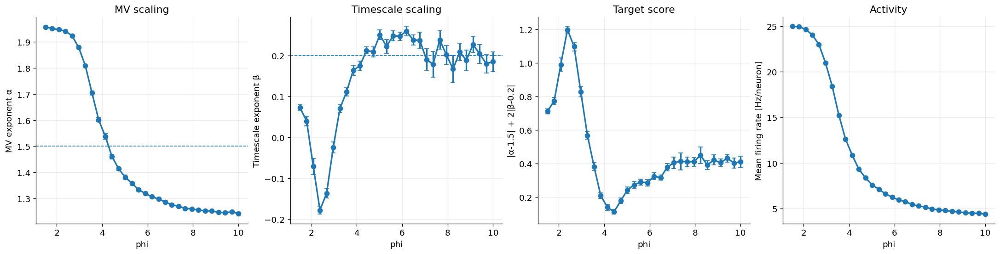

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/plots_examine/phi_summary_r2_activity_sanity.png


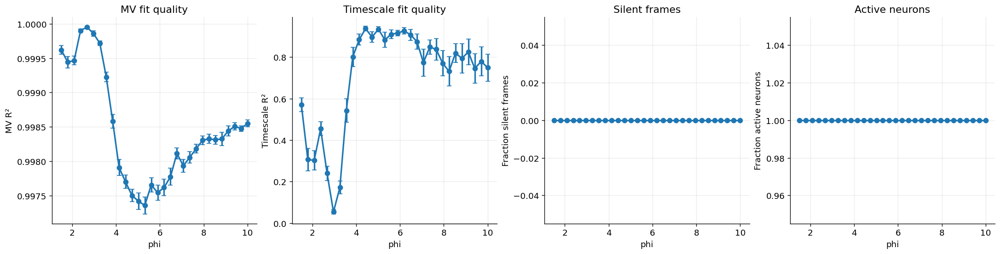

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/plots_examine/seed_level_exponents_score_vs_phi.png


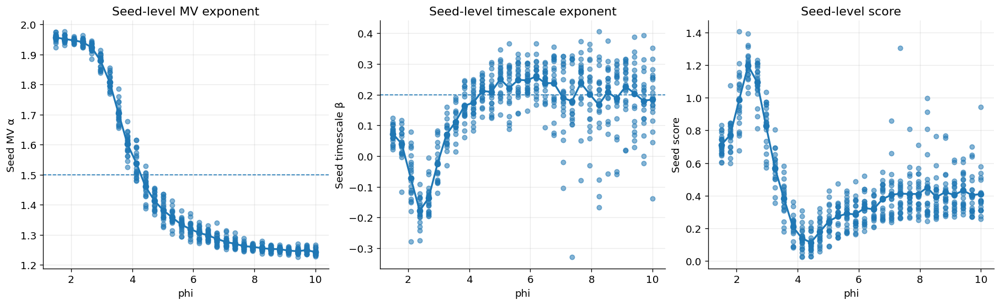


Selected phis for ICG curves:
[ 1.5         3.84482759  4.13793103  4.43103448  4.72413793  5.01724138
  5.89655172 10.        ]
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/plots_examine/selected_phi_icg_curves.png


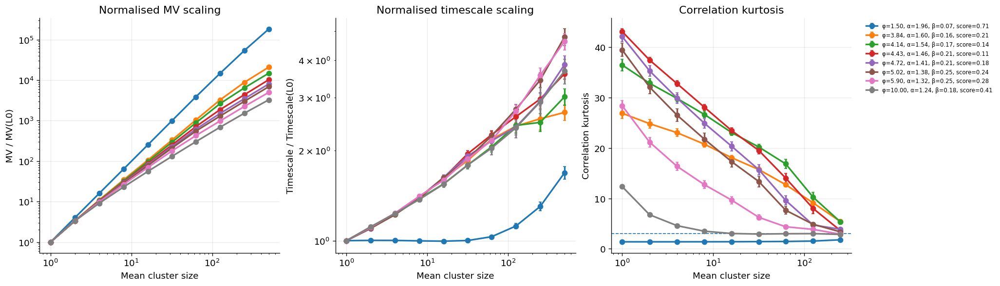


Best phi:
phi                     4.43103
n                      20.00000
MV_alpha_mean           1.46105
MV_alpha_sem            0.00877
MV_r2_mean              0.99770
MV_r2_sem               0.00010
TAU_beta_mean           0.21241
TAU_beta_sem            0.00872
TAU_r2_mean             0.93706
TAU_r2_sem              0.01064
score_mean              0.11153
score_sem               0.01370
mean_rate_hz            9.30563
mean_rate_hz_sem        0.11409
pop_rate_mean_hz        9.30563
pop_rate_std_hz         0.75740
frac_silent_frames      0.00000
frac_active_neurons     1.00000
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/plots_examine/best_phi_icg_curves.png


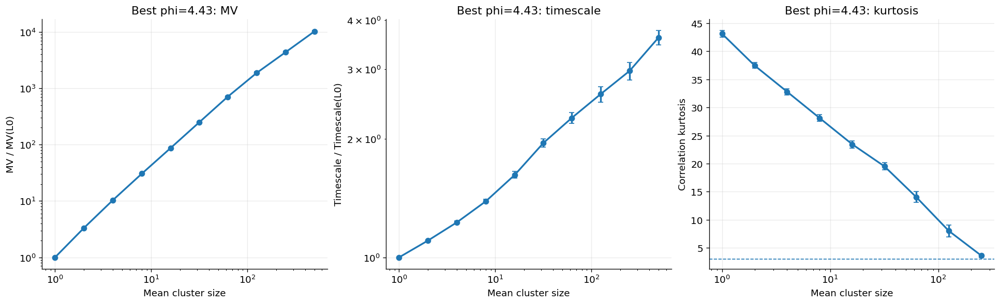

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/plots_examine/selected_phi_K10_marker.png


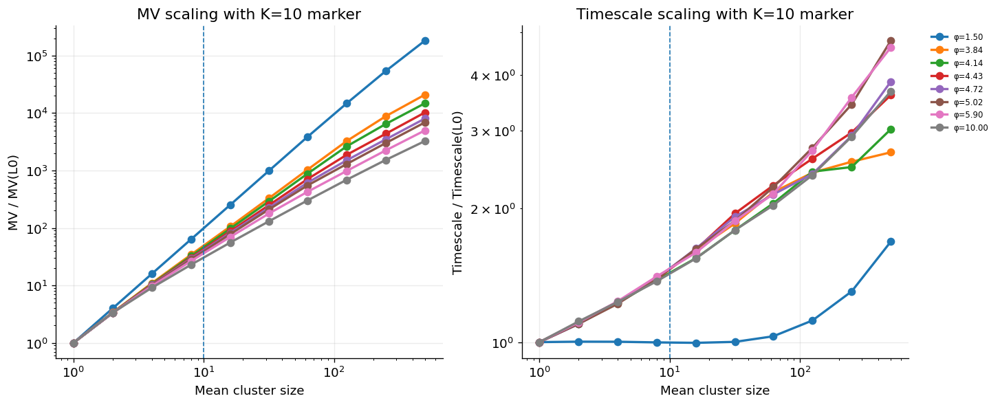


Best phi values using K >= 10 refit:
     phi  MV_alpha_Kge10  MV_r2_Kge10  MV_n_Kge10  TAU_beta_Kge10  TAU_r2_Kge10  TAU_n_Kge10  score_Kge10
 4.13793         1.47393      0.99618           6         0.18647       0.97908            6      0.05313
 3.84483         1.55289      0.99705           6         0.14918       0.94940            6      0.15453
 4.43103         1.38413      0.99722           6         0.22442       0.99643            6      0.16471
 4.72414         1.32877      0.99772           6         0.23680       0.96907            6      0.24484
 9.70690         1.18902      0.99937           6         0.21972       0.99102            6      0.35042
 8.24138         1.19164      0.99953           6         0.22427       0.97532            6      0.35690
 8.82759         1.18842      0.99943           6         0.22390       0.99772            6      0.35939
 5.31034         1.26996      0.99850           6         0.26683       0.99079            6      0.36370
 9.41379

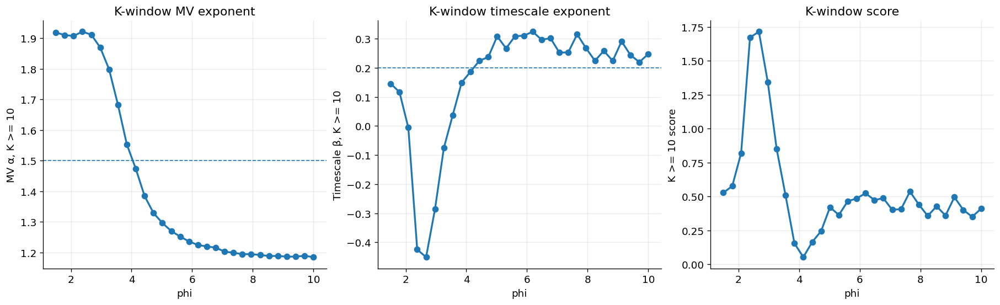


Done.
Plots saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005/plots_examine


In [35]:
# ============================================================
# LOAD + PLOT dense phi scaling sweep
# Robust version: avoids exact-float phi matching errors
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Paths
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_sweep_1p5_10p0_30steps_20seeds_smooth005")
PLOTDIR = OUTDIR / "plots_examine"
PLOTDIR.mkdir(parents=True, exist_ok=True)

TARGET_MV = 1.50
TARGET_TAU = 0.20

design_path = OUTDIR / "phi_scaling_design.csv"
exp_path = OUTDIR / "phi_scaling_seed_exponents.csv"
icg_path = OUTDIR / "phi_scaling_icg_rows.csv"
summary_path = OUTDIR / "phi_scaling_summary.csv"

design = pd.read_csv(design_path)
df_exp = pd.read_csv(exp_path)
df_icg = pd.read_csv(icg_path)
phi_summary = pd.read_csv(summary_path)

print("Loaded:")
print("design:", design.shape)
print("df_exp:", df_exp.shape)
print("df_icg:", df_icg.shape)
print("phi_summary:", phi_summary.shape)

print("\nPhi summary head:")
print(phi_summary.head().round(4).to_string(index=False))

print("\nBest phi values by score:")
print(
    phi_summary
    .sort_values("score_mean")
    [
        [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "score_sem",
            "MV_r2_mean",
            "TAU_r2_mean",
            "mean_rate_hz",
            "frac_silent_frames",
            "frac_active_neurons",
            "n",
        ]
    ]
    .head(20)
    .round(5)
    .to_string(index=False)
)


# ============================================================
# Helpers
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


def sem_nan(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def nearest_value(x, values):
    values = np.asarray(values, dtype=float)
    return float(values[np.argmin(np.abs(values - float(x)))])


def select_nearest_rows(df, col, target):
    vals = np.sort(df[col].dropna().unique().astype(float))
    nearest = nearest_value(target, vals)
    return df[np.isclose(df[col], nearest)], nearest


# ============================================================
# Build ICG summary across seeds
# ============================================================

icg_summary = (
    df_icg
    .groupby(["phi", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),
        mean_cluster_size=("mean_cluster_size", "mean"),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem_nan),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem_nan),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", sem_nan),

        mean_rate_hz=("mean_rate_hz", "mean"),
    )
    .reset_index(drop=True)
)


# ============================================================
# 1. Exponents and score vs phi
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)

axes[0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    yerr=phi_summary["MV_alpha_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("MV exponent α")
axes[0].set_title("MV scaling")

axes[1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    yerr=phi_summary["TAU_beta_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Timescale exponent β")
axes[1].set_title("Timescale scaling")

axes[2].errorbar(
    phi_summary["phi"],
    phi_summary["score_mean"],
    yerr=phi_summary["score_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[2].set_ylabel("|α-1.5| + 2|β-0.2|")
axes[2].set_title("Target score")

axes[3].plot(
    phi_summary["phi"],
    phi_summary["mean_rate_hz"],
    marker="o",
    linewidth=2,
)
axes[3].set_ylabel("Mean firing rate [Hz/neuron]")
axes[3].set_title("Activity")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "phi_summary_exponents_score_rate.png")
plt.show()


# ============================================================
# 2. R² and activity sanity
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)

axes[0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_r2_mean"],
    yerr=phi_summary["MV_r2_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].set_ylabel("MV R²")
axes[0].set_title("MV fit quality")

axes[1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_r2_mean"],
    yerr=phi_summary["TAU_r2_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].set_ylabel("Timescale R²")
axes[1].set_title("Timescale fit quality")

axes[2].plot(
    phi_summary["phi"],
    phi_summary["frac_silent_frames"],
    marker="o",
    linewidth=2,
)
axes[2].set_ylabel("Fraction silent frames")
axes[2].set_title("Silent frames")

axes[3].plot(
    phi_summary["phi"],
    phi_summary["frac_active_neurons"],
    marker="o",
    linewidth=2,
)
axes[3].set_ylabel("Fraction active neurons")
axes[3].set_title("Active neurons")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "phi_summary_r2_activity_sanity.png")
plt.show()


# ============================================================
# 3. Seed-level scatter
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(
    df_exp["phi"],
    df_exp["MV_alpha"],
    s=25,
    alpha=0.55,
)
axes[0].plot(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    marker="o",
    linewidth=2,
)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("Seed MV α")
axes[0].set_title("Seed-level MV exponent")

axes[1].scatter(
    df_exp["phi"],
    df_exp["TAU_beta"],
    s=25,
    alpha=0.55,
)
axes[1].plot(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    marker="o",
    linewidth=2,
)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Seed timescale β")
axes[1].set_title("Seed-level timescale exponent")

axes[2].scatter(
    df_exp["phi"],
    df_exp["score"],
    s=25,
    alpha=0.55,
)
axes[2].plot(
    phi_summary["phi"],
    phi_summary["score_mean"],
    marker="o",
    linewidth=2,
)
axes[2].set_ylabel("Seed score")
axes[2].set_title("Seed-level score")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "seed_level_exponents_score_vs_phi.png")
plt.show()


# ============================================================
# 4. Mean ICG curves by selected phi
# Robust nearest-phi selection
# ============================================================

available_phis = np.sort(phi_summary["phi"].dropna().unique().astype(float))

best_phis = (
    phi_summary
    .sort_values("score_mean")
    ["phi"]
    .head(5)
    .to_numpy(float)
)

comparison_targets = np.array([
    float(phi_summary["phi"].min()),
    float(phi_summary["phi"].median()),
    float(phi_summary["phi"].max()),
])

selected_targets = np.concatenate([best_phis, comparison_targets])
selected_phis = np.unique([nearest_value(p, available_phis) for p in selected_targets])
selected_phis = np.array(sorted(selected_phis))

print("\nSelected phis for ICG curves:")
print(selected_phis)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for phi in selected_phis:
    gg, phi_icg = select_nearest_rows(icg_summary, "phi", phi)
    ss, phi_sum = select_nearest_rows(phi_summary, "phi", phi)

    gg = gg.sort_values("gen")

    if gg.empty or ss.empty:
        print(f"Skipping phi={phi}: gg.empty={gg.empty}, ss.empty={ss.empty}")
        continue

    row = ss.iloc[0]

    label = (
        f"φ={phi_sum:.2f}, "
        f"α={row['MV_alpha_mean']:.2f}, "
        f"β={row['TAU_beta_mean']:.2f}, "
        f"score={row['score_mean']:.2f}"
    )

    axes[0].errorbar(
        gg["mean_cluster_size"],
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=2,
        label=label,
    )

    axes[1].errorbar(
        gg["mean_cluster_size"],
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=2,
        label=label,
    )

    axes[2].errorbar(
        gg["mean_cluster_size"],
        gg["corr_kurtosis_mean"],
        yerr=gg["corr_kurtosis_sem"],
        marker="o",
        linewidth=2,
        capsize=2,
        label=label,
    )

axes[0].set_title("Normalised MV scaling")
axes[1].set_title("Normalised timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

axes[2].legend(
    frameon=False,
    fontsize=7,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "selected_phi_icg_curves.png")
plt.show()


# ============================================================
# 5. Best phi ICG curves only
# ============================================================

best_phi = float(phi_summary.sort_values("score_mean").iloc[0]["phi"])
best_row = phi_summary[np.isclose(phi_summary["phi"], best_phi)].iloc[0]

print("\nBest phi:")
print(best_row.round(5).to_string())

gg = icg_summary[np.isclose(icg_summary["phi"], best_phi)].sort_values("gen")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

axes[0].errorbar(
    gg["mean_cluster_size"],
    gg["mean_variance_norm_mean"],
    yerr=gg["mean_variance_norm_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].set_title(f"Best phi={best_phi:.3g}: MV")
axes[0].set_ylabel("MV / MV(L0)")
axes[0].set_yscale("log")

axes[1].errorbar(
    gg["mean_cluster_size"],
    gg["timescale_norm_mean"],
    yerr=gg["timescale_norm_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].set_title(f"Best phi={best_phi:.3g}: timescale")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[1].set_yscale("log")

axes[2].errorbar(
    gg["mean_cluster_size"],
    gg["corr_kurtosis_mean"],
    yerr=gg["corr_kurtosis_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[2].set_title(f"Best phi={best_phi:.3g}: kurtosis")
axes[2].set_ylabel("Correlation kurtosis")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

savefig(fig, "best_phi_icg_curves.png")
plt.show()


# ============================================================
# 6. K >= 10 diagnostic curves
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

for phi in selected_phis:
    gg, phi_icg = select_nearest_rows(icg_summary, "phi", phi)
    gg = gg.sort_values("gen")

    if gg.empty:
        print(f"Skipping K>=10 diagnostic phi={phi}")
        continue

    axes[0].plot(
        gg["mean_cluster_size"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=2,
        label=f"φ={phi_icg:.2f}",
    )

    axes[1].plot(
        gg["mean_cluster_size"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=2,
        label=f"φ={phi_icg:.2f}",
    )

for ax in axes:
    ax.axvline(10, linestyle="--", linewidth=1)
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

axes[0].set_title("MV scaling with K=10 marker")
axes[1].set_title("Timescale scaling with K=10 marker")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")

axes[1].legend(
    frameon=False,
    fontsize=7,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "selected_phi_K10_marker.png")
plt.show()


# ============================================================
# 7. Refit exponents only for K >= 10
# ============================================================

def fit_loglog(x, y, min_points=3):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x = x[ok]
    y = y[ok]

    if len(x) < min_points:
        return np.nan, np.nan, len(x)

    lx = np.log10(x)
    ly = np.log10(y)

    slope, intercept = np.polyfit(lx, ly, 1)
    pred = intercept + slope * lx

    ss_res = np.sum((ly - pred) ** 2)
    ss_tot = np.sum((ly - np.mean(ly)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(x))


rows = []

for phi, g in icg_summary.groupby("phi"):
    g = g.sort_values("mean_cluster_size")
    gfit = g[g["mean_cluster_size"] >= 10]

    mv_slope, mv_r2, mv_n = fit_loglog(
        gfit["mean_cluster_size"],
        gfit["mean_variance_norm_mean"],
    )

    tau_slope, tau_r2, tau_n = fit_loglog(
        gfit["mean_cluster_size"],
        gfit["timescale_norm_mean"],
    )

    rows.append({
        "phi": float(phi),
        "MV_alpha_Kge10": mv_slope,
        "MV_r2_Kge10": mv_r2,
        "MV_n_Kge10": mv_n,
        "TAU_beta_Kge10": tau_slope,
        "TAU_r2_Kge10": tau_r2,
        "TAU_n_Kge10": tau_n,
        "score_Kge10": (
            abs(mv_slope - TARGET_MV) + 2 * abs(tau_slope - TARGET_TAU)
            if np.isfinite(mv_slope) and np.isfinite(tau_slope)
            else np.nan
        ),
    })

k10_summary = pd.DataFrame(rows).sort_values("score_Kge10").reset_index(drop=True)

k10_path = OUTDIR / "phi_scaling_Kge10_refit_summary.csv"
k10_summary.to_csv(k10_path, index=False)

print("\nBest phi values using K >= 10 refit:")
print(k10_summary.head(15).round(5).to_string(index=False))
print("Saved:", k10_path)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

k10_by_phi = k10_summary.sort_values("phi")

axes[0].plot(
    k10_by_phi["phi"],
    k10_by_phi["MV_alpha_Kge10"],
    marker="o",
    linewidth=2,
)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("MV α, K >= 10")
axes[0].set_title("K-window MV exponent")

axes[1].plot(
    k10_by_phi["phi"],
    k10_by_phi["TAU_beta_Kge10"],
    marker="o",
    linewidth=2,
)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Timescale β, K >= 10")
axes[1].set_title("K-window timescale exponent")

axes[2].plot(
    k10_by_phi["phi"],
    k10_by_phi["score_Kge10"],
    marker="o",
    linewidth=2,
)
axes[2].set_ylabel("K >= 10 score")
axes[2].set_title("K-window score")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "Kge10_refit_exponents_score.png")
plt.show()


print("\nDone.")
print("Plots saved to:", PLOTDIR)

In [ ]:
#zoomed in transition


# ============================================================
# Fine-grained phi transition sweep from start_dic
#
#   - phi/slope: 3.9 -> 4.4, 20 steps
#   - 20 seeds per phi = 400 simulations
#   - uses start_dic for everything else
#   - uses exp smoothing tau = 0.05
#   - normalised MV/timescale scaling
#
# Saves:
#   phi_transition_design.csv
#   phi_transition_seed_exponents.csv
#   phi_transition_icg_rows.csv
#   phi_transition_summary.csv
#   phi_transition_icg_summary.csv
#   phi_transition_Kge10_refit_summary.csv
# ============================================================

import os
import inspect
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005")
OUTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.linspace(3.9, 4.4, 20)

N_SEEDS = 15
N_WORKERS = 30
BASE_SEED = 970000

SMOOTHE = float(start_dic.get("smoothe", 0.05))
T_RUN = float(start_dic.get("T", 10.0))

TARGET_MV = 1.50
TARGET_TAU = 0.20

print("OUTDIR:", OUTDIR)
print("PHI_VALUES:", PHI_VALUES)
print("N_PHI:", len(PHI_VALUES))
print("N_SEEDS:", N_SEEDS)
print("TOTAL SIMS:", len(PHI_VALUES) * N_SEEDS)
print("N_WORKERS:", N_WORKERS)
print("T_RUN:", T_RUN)
print("SMOOTHE:", SMOOTHE)


# ============================================================
# Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def fit_power_slope(
    g,
    y_col,
    x_col="mean_cluster_size",
    exclude_first=True,
    exclude_last=False,
    min_points=3,
):
    dfit = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    dfit = dfit[(dfit[x_col] > 0) & (dfit[y_col] > 0)].sort_values(x_col)

    if exclude_first and len(dfit) > 0:
        dfit = dfit.iloc[1:]

    if exclude_last and len(dfit) > 0:
        dfit = dfit.iloc[:-1]

    if len(dfit) < min_points:
        return np.nan, np.nan, int(len(dfit))

    logx = np.log10(dfit[x_col].to_numpy(float))
    logy = np.log10(dfit[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = np.sum((logy - pred) ** 2)
    ss_tot = np.sum((logy - np.mean(logy)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(dfit))


def make_pars(phi, seed):
    pars = dict(start_dic)

    # Runtime-only / analysis-only keys
    pars.pop("T", None)
    pars.pop("smoothe", None)

    # Match model signature: phi vs slope
    sig = inspect.signature(fn.automata_EI_hiermod.__init__)
    valid_args = set(sig.parameters.keys())

    if "slope" in valid_args:
        pars.pop("phi", None)
        pars["slope"] = float(phi)
    elif "phi" in valid_args:
        pars.pop("slope", None)
        pars["phi"] = float(phi)
    else:
        raise ValueError("Model expects neither 'slope' nor 'phi'.")

    pars["seed"] = int(seed)

    # Remove anything not accepted by constructor
    pars = {k: v for k, v in pars.items() if k in valid_args}

    return pars


def standardise_gen_df_columns(gen_df):
    gen_df = gen_df.copy()

    rename_map = {
        "mean_variance": "MV",
        "mean_variance_norm": "MV_norm",
        "timescale": "TAU",
        "timescale_norm": "TAU_norm",
        "corr_kurtosis": "kurtosis_corr",
    }

    for old, new in rename_map.items():
        if old in gen_df.columns and new not in gen_df.columns:
            gen_df[new] = gen_df[old]

    if "MV" in gen_df.columns and "mean_variance" not in gen_df.columns:
        gen_df["mean_variance"] = gen_df["MV"]

    if "MV_norm" in gen_df.columns and "mean_variance_norm" not in gen_df.columns:
        gen_df["mean_variance_norm"] = gen_df["MV_norm"]

    if "TAU" in gen_df.columns and "timescale" not in gen_df.columns:
        gen_df["timescale"] = gen_df["TAU"]

    if "TAU_norm" in gen_df.columns and "timescale_norm" not in gen_df.columns:
        gen_df["timescale_norm"] = gen_df["TAU_norm"]

    if "kurtosis_corr" not in gen_df.columns and "corr_kurtosis" in gen_df.columns:
        gen_df["kurtosis_corr"] = gen_df["corr_kurtosis"]

    if "corr_kurtosis" not in gen_df.columns and "kurtosis_corr" in gen_df.columns:
        gen_df["corr_kurtosis"] = gen_df["kurtosis_corr"]

    return gen_df


def run_one(job):
    sim_id, phi, seed, seed_idx = job

    pars = make_pars(phi=phi, seed=seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T_RUN)

    dt = float(pars["dt"])

    mean_rate_hz = float(spikes.mean() / dt)
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    spikes_smooth = fn.exp_smooth_spikes(
        spikes,
        dt=dt,
        tau=SMOOTHE,
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=spikes_smooth,
        dt=dt,
    )

    gen_df = standardise_gen_df_columns(gen_df)

    mv_y = "mean_variance_norm" if "mean_variance_norm" in gen_df.columns else "MV_norm"
    tau_y = "timescale_norm" if "timescale_norm" in gen_df.columns else "TAU_norm"

    MV_alpha, MV_r2, MV_n_points = fit_power_slope(
        gen_df,
        y_col=mv_y,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    TAU_beta, TAU_r2, TAU_n_points = fit_power_slope(
        gen_df,
        y_col=tau_y,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    score = (
        abs(MV_alpha - TARGET_MV) + 2.0 * abs(TAU_beta - TARGET_TAU)
        if np.isfinite(MV_alpha) and np.isfinite(TAU_beta)
        else np.nan
    )

    # K >= 10 window fits
    gen_fit10 = gen_df[gen_df["mean_cluster_size"] >= 10]

    MV_alpha_Kge10, MV_r2_Kge10, MV_n_Kge10 = fit_power_slope(
        gen_fit10,
        y_col=mv_y,
        x_col="mean_cluster_size",
        exclude_first=False,
        exclude_last=False,
    )

    TAU_beta_Kge10, TAU_r2_Kge10, TAU_n_Kge10 = fit_power_slope(
        gen_fit10,
        y_col=tau_y,
        x_col="mean_cluster_size",
        exclude_first=False,
        exclude_last=False,
    )

    score_Kge10 = (
        abs(MV_alpha_Kge10 - TARGET_MV) + 2.0 * abs(TAU_beta_Kge10 - TARGET_TAU)
        if np.isfinite(MV_alpha_Kge10) and np.isfinite(TAU_beta_Kge10)
        else np.nan
    )

    exp_row = {
        "sim_id": int(sim_id),
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),

        "MV_alpha": MV_alpha,
        "MV_r2": MV_r2,
        "MV_n_points": MV_n_points,

        "TAU_beta": TAU_beta,
        "TAU_r2": TAU_r2,
        "TAU_n_points": TAU_n_points,

        "score": score,

        "MV_alpha_Kge10": MV_alpha_Kge10,
        "MV_r2_Kge10": MV_r2_Kge10,
        "MV_n_Kge10": MV_n_Kge10,

        "TAU_beta_Kge10": TAU_beta_Kge10,
        "TAU_r2_Kge10": TAU_r2_Kge10,
        "TAU_n_Kge10": TAU_n_Kge10,

        "score_Kge10": score_Kge10,

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,

        "dt": dt,
        "T": float(T_RUN),
        "smoothe": float(SMOOTHE),

        "theta": float(pars.get("theta", np.nan)),
        "p_ext": float(pars.get("p_ext", np.nan)),
        "e_w": float(pars.get("e_w", np.nan)),
        "i_w": float(pars.get("i_w", np.nan)),
        "ei_ratio": float(pars.get("ei_ratio", np.nan)),
        "refractory_steps": int(pars.get("refractory_steps", -1)),
    }

    gen_df["sim_id"] = int(sim_id)
    gen_df["phi"] = float(phi)
    gen_df["seed"] = int(seed)
    gen_df["seed_idx"] = int(seed_idx)
    gen_df["mean_rate_hz"] = mean_rate_hz
    gen_df["smoothe"] = float(SMOOTHE)

    return exp_row, gen_df


# ============================================================
# Build design
# ============================================================

jobs = []
sim_id = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + sim_id
        jobs.append((int(sim_id), float(phi), int(seed), int(seed_idx)))
        sim_id += 1

design = pd.DataFrame(
    jobs,
    columns=["sim_id", "phi", "seed", "seed_idx"],
)

design["smoothe"] = float(SMOOTHE)
design["T"] = float(T_RUN)

design_path = OUTDIR / "phi_transition_design.csv"
design.to_csv(design_path, index=False)

print("Saved design:", design_path)


# ============================================================
# Run sweep
# ============================================================

rows = []
gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for exp_row, gen_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Fine phi transition sweep",
    ):
        rows.append(exp_row)
        gen_rows.append(gen_df)


# ============================================================
# Save raw outputs
# ============================================================

df_exp = (
    pd.DataFrame(rows)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

df_icg = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "gen"])
    .reset_index(drop=True)
)

exp_path = OUTDIR / "phi_transition_seed_exponents.csv"
icg_path = OUTDIR / "phi_transition_icg_rows.csv"

df_exp.to_csv(exp_path, index=False)
df_icg.to_csv(icg_path, index=False)

print("Saved:", exp_path)
print("Saved:", icg_path)


# ============================================================
# Summary by phi
# ============================================================

phi_summary = (
    df_exp
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        MV_alpha_mean=("MV_alpha", "mean"),
        MV_alpha_sem=("MV_alpha", sem),
        MV_r2_mean=("MV_r2", "mean"),
        MV_r2_sem=("MV_r2", sem),

        TAU_beta_mean=("TAU_beta", "mean"),
        TAU_beta_sem=("TAU_beta", sem),
        TAU_r2_mean=("TAU_r2", "mean"),
        TAU_r2_sem=("TAU_r2", sem),

        score_mean=("score", "mean"),
        score_sem=("score", sem),

        MV_alpha_Kge10_mean=("MV_alpha_Kge10", "mean"),
        MV_alpha_Kge10_sem=("MV_alpha_Kge10", sem),
        MV_r2_Kge10_mean=("MV_r2_Kge10", "mean"),
        MV_r2_Kge10_sem=("MV_r2_Kge10", sem),

        TAU_beta_Kge10_mean=("TAU_beta_Kge10", "mean"),
        TAU_beta_Kge10_sem=("TAU_beta_Kge10", sem),
        TAU_r2_Kge10_mean=("TAU_r2_Kge10", "mean"),
        TAU_r2_Kge10_sem=("TAU_r2_Kge10", sem),

        score_Kge10_mean=("score_Kge10", "mean"),
        score_Kge10_sem=("score_Kge10", sem),

        mean_rate_hz=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),

        pop_rate_mean_hz=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz=("pop_rate_std_hz", "mean"),

        frac_silent_frames=("frac_silent_frames", "mean"),
        frac_active_neurons=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

summary_path = OUTDIR / "phi_transition_summary.csv"
phi_summary.to_csv(summary_path, index=False)

print("Saved:", summary_path)


# ============================================================
# ICG summary by phi/gen
# ============================================================

icg_summary = (
    df_icg
    .groupby(["phi", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),

        mean_cluster_size=("mean_cluster_size", "mean"),

        mean_variance_mean=("mean_variance", "mean"),
        mean_variance_sem=("mean_variance", sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem),

        timescale_mean=("timescale", "mean"),
        timescale_sem=("timescale", sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", sem),

        mean_rate_hz=("mean_rate_hz", "mean"),
    )
    .sort_values(["phi", "gen"])
    .reset_index(drop=True)
)

icg_summary_path = OUTDIR / "phi_transition_icg_summary.csv"
icg_summary.to_csv(icg_summary_path, index=False)

print("Saved:", icg_summary_path)


# ============================================================
# K >= 10 refit summary from mean curves
# ============================================================

rows = []

for phi, g in icg_summary.groupby("phi"):
    g = g.sort_values("mean_cluster_size")
    gfit = g[g["mean_cluster_size"] >= 10]

    mv_slope, mv_r2, mv_n = fit_power_slope(
        gfit,
        y_col="mean_variance_norm_mean",
        x_col="mean_cluster_size",
        exclude_first=False,
        exclude_last=False,
    )

    tau_slope, tau_r2, tau_n = fit_power_slope(
        gfit,
        y_col="timescale_norm_mean",
        x_col="mean_cluster_size",
        exclude_first=False,
        exclude_last=False,
    )

    score = (
        abs(mv_slope - TARGET_MV) + 2.0 * abs(tau_slope - TARGET_TAU)
        if np.isfinite(mv_slope) and np.isfinite(tau_slope)
        else np.nan
    )

    rows.append({
        "phi": float(phi),
        "MV_alpha_Kge10_mean_curve": mv_slope,
        "MV_r2_Kge10_mean_curve": mv_r2,
        "MV_n_Kge10_mean_curve": mv_n,
        "TAU_beta_Kge10_mean_curve": tau_slope,
        "TAU_r2_Kge10_mean_curve": tau_r2,
        "TAU_n_Kge10_mean_curve": tau_n,
        "score_Kge10_mean_curve": score,
    })

k10_summary = (
    pd.DataFrame(rows)
    .sort_values("score_Kge10_mean_curve")
    .reset_index(drop=True)
)

k10_path = OUTDIR / "phi_transition_Kge10_refit_summary.csv"
k10_summary.to_csv(k10_path, index=False)

print("Saved:", k10_path)


# ============================================================
# Final printout
# ============================================================

print("\nBest phi values by full-window score:")
print(
    phi_summary
    .sort_values("score_mean")
    [
        [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "MV_r2_mean",
            "TAU_r2_mean",
            "mean_rate_hz",
            "n",
        ]
    ]
    .head(15)
    .round(5)
    .to_string(index=False)
)

print("\nBest phi values by K>=10 seed-level score:")
print(
    phi_summary
    .sort_values("score_Kge10_mean")
    [
        [
            "phi",
            "MV_alpha_Kge10_mean",
            "MV_alpha_Kge10_sem",
            "TAU_beta_Kge10_mean",
            "TAU_beta_Kge10_sem",
            "score_Kge10_mean",
            "MV_r2_Kge10_mean",
            "TAU_r2_Kge10_mean",
            "mean_rate_hz",
            "n",
        ]
    ]
    .head(15)
    .round(5)
    .to_string(index=False)
)

print("\nBest phi values by K>=10 mean-curve refit:")
print(k10_summary.head(15).round(5).to_string(index=False))

print("\nDone.")
print("Outputs saved to:", OUTDIR)
print("Files:")
print("  design:        ", design_path)
print("  seed exponents:", exp_path)
print("  ICG rows:      ", icg_path)
print("  summary:       ", summary_path)
print("  ICG summary:   ", icg_summary_path)
print("  K>=10 refit:   ", k10_path)

Loaded:
design: (300, 6)
df_exp: (300, 32)
df_icg: (3000, 22)
phi_summary: (20, 28)
icg_summary: (200, 15)
k10_summary: (20, 8)

Phi range: 3.9 -> 4.4
N per phi: [15]

Best by full-window score:
    phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  MV_r2_mean  TAU_r2_mean  mean_rate_hz  n
4.08421        1.53561       0.00991        0.19649       0.01242     0.09864     0.99804      0.88351      11.18918 15
4.37368        1.47777       0.00876        0.20343       0.01303     0.10427     0.99780      0.92623       9.78652 15
4.05789        1.52405       0.00831        0.20778       0.01102     0.10437     0.99809      0.94915      10.87221 15
4.40000        1.46130       0.00834        0.20675       0.01078     0.10977     0.99769      0.88457       9.41771 15
4.11053        1.52153       0.00886        0.17961       0.01236     0.11062     0.99804      0.87402      10.85746 15
4.18947        1.49581       0.01065        0.20238       0.01274     0.11198     0.9

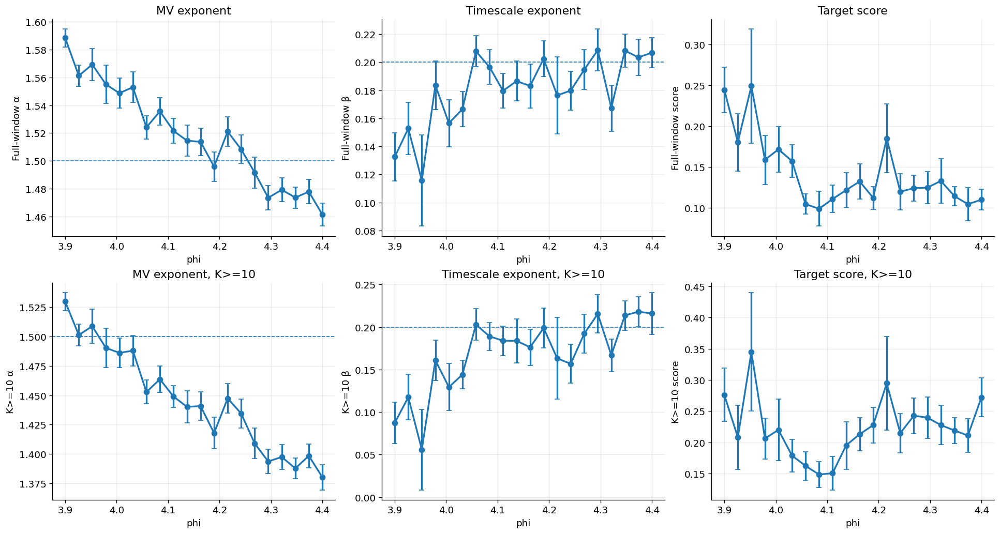

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine/transition_r2_activity_sanity.png


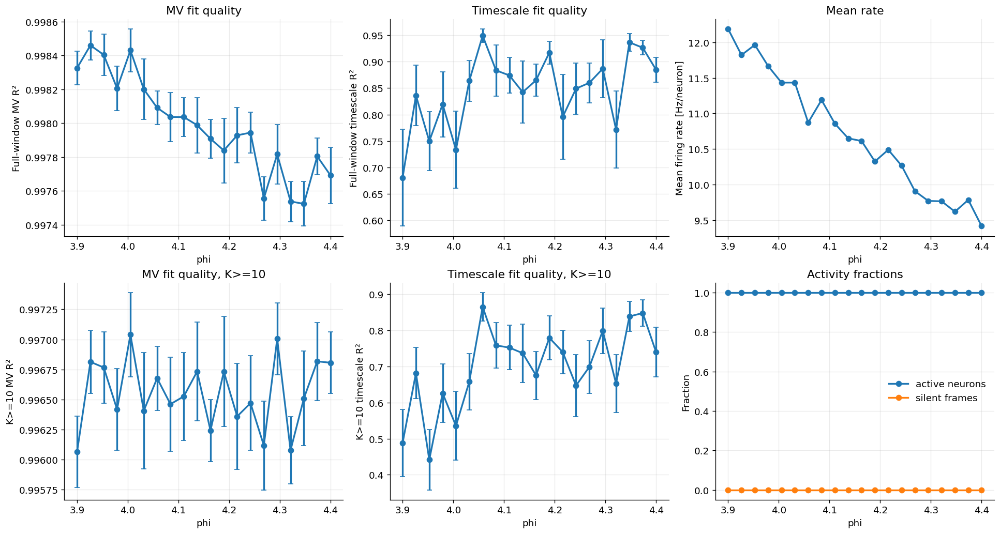

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine/transition_seed_level_scatter.png


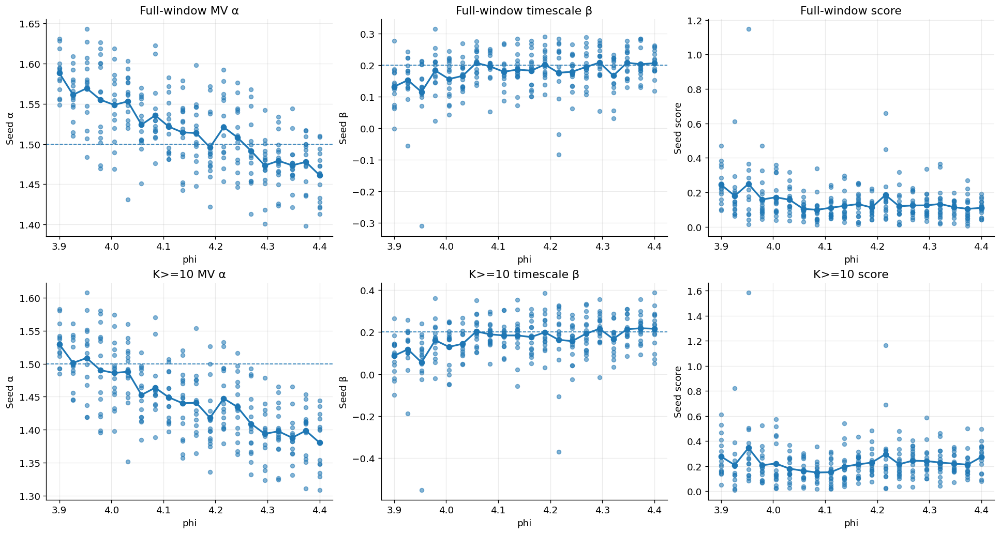

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine/transition_Kge10_seedfit_vs_meancurve.png


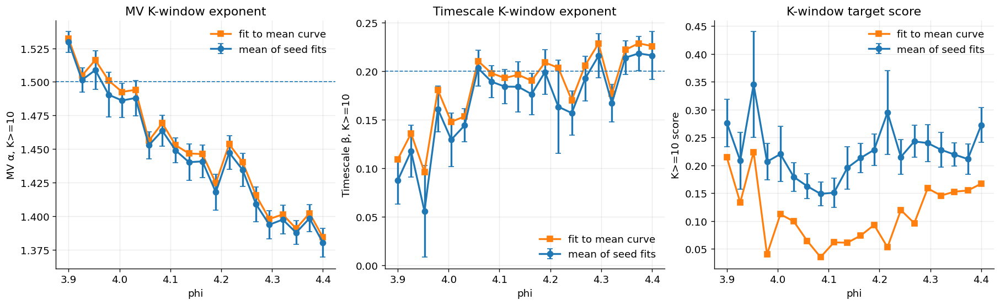


Selected phis:
[3.9        4.05789474 4.08421053 4.11052632 4.15       4.37368421
 4.4       ]
Skipping phi: 4.15
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine/transition_selected_phi_icg_curves.png


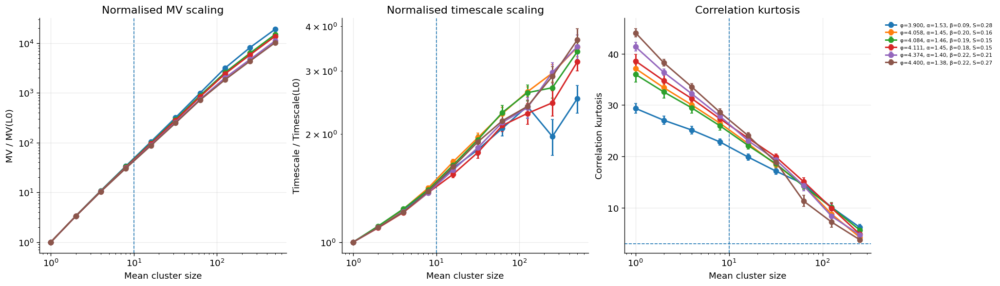

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine/best_full_window_icg_curves.png


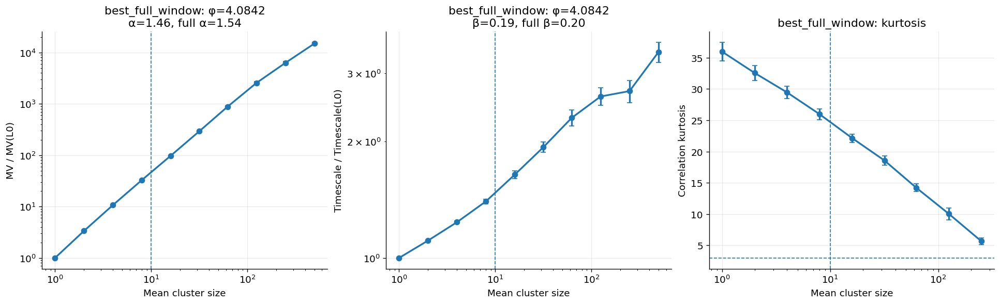

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine/best_Kge10_icg_curves.png


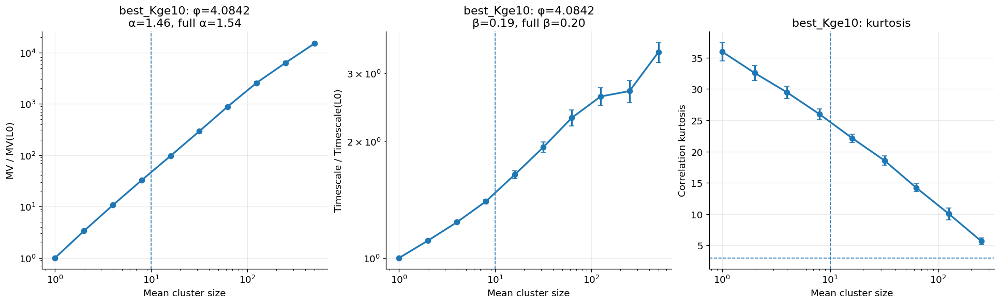


Shape diagnostics saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/phi_transition_shape_diagnostics.csv
    phi  score_Kge10_mean  L0_kurtosis  kurtosis_Knear10  K_near10  MV_norm_Knear10  TAU_norm_Knear10  mean_rate_hz
4.08421           0.14872     35.96932          25.95425       8.0         32.73854           1.39934      11.18918
4.11053           0.15071     38.57703          27.32329       8.0         31.90577           1.37364      10.85746
4.05789           0.16249     37.10594          26.46269       8.0         32.10313           1.41541      10.87221
4.03158           0.17901     33.27680          24.59802       8.0         33.15850           1.37520      11.43365
4.13684           0.19537     38.35278          27.26039       8.0         31.95762           1.36880      10.65065
3.97895           0.20636     33.49847          24.21664       8.0         33.00881           1.44124      11.66549
3.92632           0.20812     32.46706  

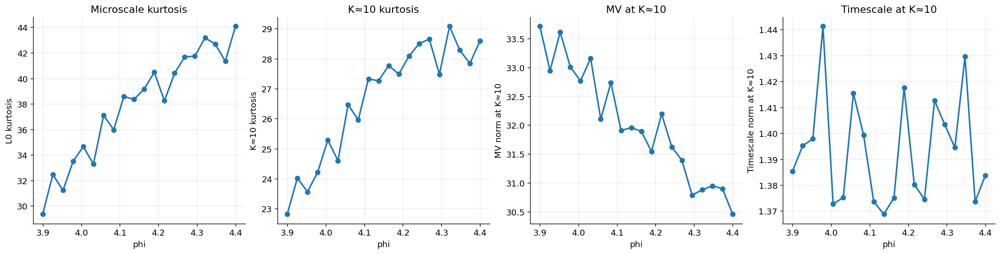


Done.
Plots saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005/plots_examine


In [37]:
# ============================================================
# LOAD + PLOT fine phi transition sweep
#
# Loads:
#   phi_transition_design.csv
#   phi_transition_seed_exponents.csv
#   phi_transition_icg_rows.csv
#   phi_transition_summary.csv
#   phi_transition_icg_summary.csv
#   phi_transition_Kge10_refit_summary.csv
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Paths
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_transition_3p9_4p4_20steps_20seeds_smooth005")
PLOTDIR = OUTDIR / "plots_examine"
PLOTDIR.mkdir(parents=True, exist_ok=True)

TARGET_MV = 1.50
TARGET_TAU = 0.20

design_path = OUTDIR / "phi_transition_design.csv"
exp_path = OUTDIR / "phi_transition_seed_exponents.csv"
icg_path = OUTDIR / "phi_transition_icg_rows.csv"
summary_path = OUTDIR / "phi_transition_summary.csv"
icg_summary_path = OUTDIR / "phi_transition_icg_summary.csv"
k10_path = OUTDIR / "phi_transition_Kge10_refit_summary.csv"

design = pd.read_csv(design_path)
df_exp = pd.read_csv(exp_path)
df_icg = pd.read_csv(icg_path)
phi_summary = pd.read_csv(summary_path)
icg_summary = pd.read_csv(icg_summary_path)
k10_summary = pd.read_csv(k10_path)

print("Loaded:")
print("design:", design.shape)
print("df_exp:", df_exp.shape)
print("df_icg:", df_icg.shape)
print("phi_summary:", phi_summary.shape)
print("icg_summary:", icg_summary.shape)
print("k10_summary:", k10_summary.shape)

print("\nPhi range:", phi_summary["phi"].min(), "->", phi_summary["phi"].max())
print("N per phi:", phi_summary["n"].unique())

print("\nBest by full-window score:")
print(
    phi_summary
    .sort_values("score_mean")
    [
        [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "MV_r2_mean",
            "TAU_r2_mean",
            "mean_rate_hz",
            "n",
        ]
    ]
    .head(15)
    .round(5)
    .to_string(index=False)
)

print("\nBest by K>=10 seed-level score:")
print(
    phi_summary
    .sort_values("score_Kge10_mean")
    [
        [
            "phi",
            "MV_alpha_Kge10_mean",
            "MV_alpha_Kge10_sem",
            "TAU_beta_Kge10_mean",
            "TAU_beta_Kge10_sem",
            "score_Kge10_mean",
            "MV_r2_Kge10_mean",
            "TAU_r2_Kge10_mean",
            "mean_rate_hz",
            "n",
        ]
    ]
    .head(15)
    .round(5)
    .to_string(index=False)
)

print("\nBest by K>=10 mean-curve refit:")
print(k10_summary.head(15).round(5).to_string(index=False))


# ============================================================
# Plot helper
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# 1. Full-window vs K>=10 exponents/score
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), constrained_layout=True)

# full-window
axes[0, 0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    yerr=phi_summary["MV_alpha_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0, 0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0, 0].set_ylabel("Full-window α")
axes[0, 0].set_title("MV exponent")

axes[0, 1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    yerr=phi_summary["TAU_beta_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0, 1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[0, 1].set_ylabel("Full-window β")
axes[0, 1].set_title("Timescale exponent")

axes[0, 2].errorbar(
    phi_summary["phi"],
    phi_summary["score_mean"],
    yerr=phi_summary["score_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0, 2].set_ylabel("Full-window score")
axes[0, 2].set_title("Target score")

# K>=10 seed-level
axes[1, 0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_Kge10_mean"],
    yerr=phi_summary["MV_alpha_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1, 0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[1, 0].set_ylabel("K>=10 α")
axes[1, 0].set_title("MV exponent, K>=10")

axes[1, 1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_Kge10_mean"],
    yerr=phi_summary["TAU_beta_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1, 1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1, 1].set_ylabel("K>=10 β")
axes[1, 1].set_title("Timescale exponent, K>=10")

axes[1, 2].errorbar(
    phi_summary["phi"],
    phi_summary["score_Kge10_mean"],
    yerr=phi_summary["score_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1, 2].set_ylabel("K>=10 score")
axes[1, 2].set_title("Target score, K>=10")

for ax in axes.ravel():
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "transition_full_vs_Kge10_exponents_score.png")
plt.show()


# ============================================================
# 2. R2 + activity sanity
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), constrained_layout=True)

axes[0, 0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_r2_mean"],
    yerr=phi_summary["MV_r2_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0, 0].set_ylabel("Full-window MV R²")
axes[0, 0].set_title("MV fit quality")

axes[0, 1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_r2_mean"],
    yerr=phi_summary["TAU_r2_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0, 1].set_ylabel("Full-window timescale R²")
axes[0, 1].set_title("Timescale fit quality")

axes[0, 2].plot(
    phi_summary["phi"],
    phi_summary["mean_rate_hz"],
    marker="o",
    linewidth=2,
)
axes[0, 2].set_ylabel("Mean firing rate [Hz/neuron]")
axes[0, 2].set_title("Mean rate")

axes[1, 0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_r2_Kge10_mean"],
    yerr=phi_summary["MV_r2_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1, 0].set_ylabel("K>=10 MV R²")
axes[1, 0].set_title("MV fit quality, K>=10")

axes[1, 1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_r2_Kge10_mean"],
    yerr=phi_summary["TAU_r2_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1, 1].set_ylabel("K>=10 timescale R²")
axes[1, 1].set_title("Timescale fit quality, K>=10")

axes[1, 2].plot(
    phi_summary["phi"],
    phi_summary["frac_active_neurons"],
    marker="o",
    linewidth=2,
    label="active neurons",
)
axes[1, 2].plot(
    phi_summary["phi"],
    phi_summary["frac_silent_frames"],
    marker="o",
    linewidth=2,
    label="silent frames",
)
axes[1, 2].set_ylabel("Fraction")
axes[1, 2].set_title("Activity fractions")
axes[1, 2].legend(frameon=False)

for ax in axes.ravel():
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "transition_r2_activity_sanity.png")
plt.show()


# ============================================================
# 3. Seed-level scatter
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), constrained_layout=True)

scatter_kwargs = dict(s=22, alpha=0.55)

axes[0, 0].scatter(df_exp["phi"], df_exp["MV_alpha"], **scatter_kwargs)
axes[0, 0].plot(phi_summary["phi"], phi_summary["MV_alpha_mean"], marker="o", linewidth=2)
axes[0, 0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0, 0].set_ylabel("Seed α")
axes[0, 0].set_title("Full-window MV α")

axes[0, 1].scatter(df_exp["phi"], df_exp["TAU_beta"], **scatter_kwargs)
axes[0, 1].plot(phi_summary["phi"], phi_summary["TAU_beta_mean"], marker="o", linewidth=2)
axes[0, 1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[0, 1].set_ylabel("Seed β")
axes[0, 1].set_title("Full-window timescale β")

axes[0, 2].scatter(df_exp["phi"], df_exp["score"], **scatter_kwargs)
axes[0, 2].plot(phi_summary["phi"], phi_summary["score_mean"], marker="o", linewidth=2)
axes[0, 2].set_ylabel("Seed score")
axes[0, 2].set_title("Full-window score")

axes[1, 0].scatter(df_exp["phi"], df_exp["MV_alpha_Kge10"], **scatter_kwargs)
axes[1, 0].plot(phi_summary["phi"], phi_summary["MV_alpha_Kge10_mean"], marker="o", linewidth=2)
axes[1, 0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[1, 0].set_ylabel("Seed α")
axes[1, 0].set_title("K>=10 MV α")

axes[1, 1].scatter(df_exp["phi"], df_exp["TAU_beta_Kge10"], **scatter_kwargs)
axes[1, 1].plot(phi_summary["phi"], phi_summary["TAU_beta_Kge10_mean"], marker="o", linewidth=2)
axes[1, 1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1, 1].set_ylabel("Seed β")
axes[1, 1].set_title("K>=10 timescale β")

axes[1, 2].scatter(df_exp["phi"], df_exp["score_Kge10"], **scatter_kwargs)
axes[1, 2].plot(phi_summary["phi"], phi_summary["score_Kge10_mean"], marker="o", linewidth=2)
axes[1, 2].set_ylabel("Seed score")
axes[1, 2].set_title("K>=10 score")

for ax in axes.ravel():
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "transition_seed_level_scatter.png")
plt.show()


# ============================================================
# 4. Compare seed-level K>=10 vs mean-curve K>=10 refit
# ============================================================

k10_by_phi = k10_summary.sort_values("phi")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_Kge10_mean"],
    yerr=phi_summary["MV_alpha_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
    label="mean of seed fits",
)
axes[0].plot(
    k10_by_phi["phi"],
    k10_by_phi["MV_alpha_Kge10_mean_curve"],
    marker="s",
    linewidth=2,
    label="fit to mean curve",
)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("MV α, K>=10")
axes[0].set_title("MV K-window exponent")
axes[0].legend(frameon=False)

axes[1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_Kge10_mean"],
    yerr=phi_summary["TAU_beta_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
    label="mean of seed fits",
)
axes[1].plot(
    k10_by_phi["phi"],
    k10_by_phi["TAU_beta_Kge10_mean_curve"],
    marker="s",
    linewidth=2,
    label="fit to mean curve",
)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Timescale β, K>=10")
axes[1].set_title("Timescale K-window exponent")
axes[1].legend(frameon=False)

axes[2].errorbar(
    phi_summary["phi"],
    phi_summary["score_Kge10_mean"],
    yerr=phi_summary["score_Kge10_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
    label="mean of seed fits",
)
axes[2].plot(
    k10_by_phi["phi"],
    k10_by_phi["score_Kge10_mean_curve"],
    marker="s",
    linewidth=2,
    label="fit to mean curve",
)
axes[2].set_ylabel("K>=10 score")
axes[2].set_title("K-window target score")
axes[2].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "transition_Kge10_seedfit_vs_meancurve.png")
plt.show()


# ============================================================
# 5. ICG curves for selected phis
# ============================================================

best_full = phi_summary.sort_values("score_mean")["phi"].head(3).to_numpy()
best_k10 = phi_summary.sort_values("score_Kge10_mean")["phi"].head(3).to_numpy()
comparison = np.array([
    phi_summary["phi"].min(),
    phi_summary["phi"].median(),
    phi_summary["phi"].max(),
])

selected_phis = np.unique(np.concatenate([best_full, best_k10, comparison]))
selected_phis = np.array(sorted(selected_phis))

print("\nSelected phis:")
print(selected_phis)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for phi in selected_phis:
    gg = icg_summary[np.isclose(icg_summary["phi"], phi)].sort_values("gen")
    ss = phi_summary[np.isclose(phi_summary["phi"], phi)]

    if gg.empty or ss.empty:
        print("Skipping phi:", phi)
        continue

    row = ss.iloc[0]

    label = (
        f"φ={phi:.3f}, "
        f"α={row['MV_alpha_Kge10_mean']:.2f}, "
        f"β={row['TAU_beta_Kge10_mean']:.2f}, "
        f"S={row['score_Kge10_mean']:.2f}"
    )

    axes[0].errorbar(
        gg["mean_cluster_size"],
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=1.8,
        capsize=2,
        label=label,
    )

    axes[1].errorbar(
        gg["mean_cluster_size"],
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=1.8,
        capsize=2,
        label=label,
    )

    axes[2].errorbar(
        gg["mean_cluster_size"],
        gg["corr_kurtosis_mean"],
        yerr=gg["corr_kurtosis_sem"],
        marker="o",
        linewidth=1.8,
        capsize=2,
        label=label,
    )

axes[0].set_title("Normalised MV scaling")
axes[1].set_title("Normalised timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.axvline(10, linestyle="--", linewidth=1)
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

axes[2].legend(
    frameon=False,
    fontsize=6.5,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "transition_selected_phi_icg_curves.png")
plt.show()


# ============================================================
# 6. Best full-window and best K>=10 ICG curves separately
# ============================================================

best_full_phi = float(phi_summary.sort_values("score_mean").iloc[0]["phi"])
best_k10_phi = float(phi_summary.sort_values("score_Kge10_mean").iloc[0]["phi"])

for label_name, phi in [
    ("best_full_window", best_full_phi),
    ("best_Kge10", best_k10_phi),
]:
    gg = icg_summary[np.isclose(icg_summary["phi"], phi)].sort_values("gen")
    row = phi_summary[np.isclose(phi_summary["phi"], phi)].iloc[0]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

    axes[0].errorbar(
        gg["mean_cluster_size"],
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
    )
    axes[0].set_title(
        f"{label_name}: φ={phi:.4f}\n"
        f"α={row['MV_alpha_Kge10_mean']:.2f}, full α={row['MV_alpha_mean']:.2f}"
    )
    axes[0].set_ylabel("MV / MV(L0)")
    axes[0].set_yscale("log")

    axes[1].errorbar(
        gg["mean_cluster_size"],
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
    )
    axes[1].set_title(
        f"{label_name}: φ={phi:.4f}\n"
        f"β={row['TAU_beta_Kge10_mean']:.2f}, full β={row['TAU_beta_mean']:.2f}"
    )
    axes[1].set_ylabel("Timescale / Timescale(L0)")
    axes[1].set_yscale("log")

    axes[2].errorbar(
        gg["mean_cluster_size"],
        gg["corr_kurtosis_mean"],
        yerr=gg["corr_kurtosis_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
    )
    axes[2].set_title(f"{label_name}: kurtosis")
    axes[2].set_ylabel("Correlation kurtosis")
    axes[2].axhline(3.0, linestyle="--", linewidth=1)

    for ax in axes:
        ax.axvline(10, linestyle="--", linewidth=1)
        ax.set_xlabel("Mean cluster size")
        ax.set_xscale("log")
        ax.grid(alpha=0.25)

    savefig(fig, f"{label_name}_icg_curves.png")
    plt.show()


# ============================================================
# 7. Early vs late-scale shape diagnostics
# ============================================================

# L0 and K~10 diagnostic
l0 = (
    icg_summary
    .sort_values("gen")
    .groupby("phi", as_index=False)
    .first()
    [["phi", "corr_kurtosis_mean", "mean_variance_norm_mean", "timescale_norm_mean"]]
    .rename(columns={
        "corr_kurtosis_mean": "L0_kurtosis",
        "mean_variance_norm_mean": "L0_MV_norm",
        "timescale_norm_mean": "L0_TAU_norm",
    })
)

# nearest-to-K=10 row per phi
rows = []
for phi, g in icg_summary.groupby("phi"):
    g = g.copy()
    g["dist_to_10"] = np.abs(g["mean_cluster_size"] - 10)
    r = g.sort_values("dist_to_10").iloc[0]
    rows.append({
        "phi": phi,
        "K_near10": r["mean_cluster_size"],
        "kurtosis_Knear10": r["corr_kurtosis_mean"],
        "MV_norm_Knear10": r["mean_variance_norm_mean"],
        "TAU_norm_Knear10": r["timescale_norm_mean"],
    })

knear10 = pd.DataFrame(rows)

shape_diag = (
    phi_summary
    .merge(l0, on="phi", how="left")
    .merge(knear10, on="phi", how="left")
)

shape_path = OUTDIR / "phi_transition_shape_diagnostics.csv"
shape_diag.to_csv(shape_path, index=False)

print("\nShape diagnostics saved:", shape_path)
print(
    shape_diag
    .sort_values("score_Kge10_mean")
    [
        [
            "phi",
            "score_Kge10_mean",
            "L0_kurtosis",
            "kurtosis_Knear10",
            "K_near10",
            "MV_norm_Knear10",
            "TAU_norm_Knear10",
            "mean_rate_hz",
        ]
    ]
    .head(15)
    .round(5)
    .to_string(index=False)
)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)

axes[0].plot(shape_diag["phi"], shape_diag["L0_kurtosis"], marker="o", linewidth=2)
axes[0].set_ylabel("L0 kurtosis")
axes[0].set_title("Microscale kurtosis")

axes[1].plot(shape_diag["phi"], shape_diag["kurtosis_Knear10"], marker="o", linewidth=2)
axes[1].set_ylabel("K≈10 kurtosis")
axes[1].set_title("K≈10 kurtosis")

axes[2].plot(shape_diag["phi"], shape_diag["MV_norm_Knear10"], marker="o", linewidth=2)
axes[2].set_ylabel("MV norm at K≈10")
axes[2].set_title("MV at K≈10")

axes[3].plot(shape_diag["phi"], shape_diag["TAU_norm_Knear10"], marker="o", linewidth=2)
axes[3].set_ylabel("Timescale norm at K≈10")
axes[3].set_title("Timescale at K≈10")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "transition_shape_diagnostics.png")
plt.show()


print("\nDone.")
print("Plots saved to:", PLOTDIR)

In [40]:
start_dic

{'n_neurons': 2000,
 'T': 10,
 'dt': 0.01,
 'refractory_steps': 2,
 'ei_ratio': 0.2,
 'e_w': 21.4115,
 'i_w': 21.675,
 'theta': 8.44,
 'p_ext': 0.02,
 'phi': 4.2,
 'smoothe': 0.05}

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005
N_SEEDS: 50
N_WORKERS: 30
start_dic:
{'n_neurons': 2000, 'T': 10, 'dt': 0.01, 'refractory_steps': 2, 'ei_ratio': 0.2, 'e_w': 21.4115, 'i_w': 21.675, 'theta': 8.44, 'p_ext': 0.02, 'phi': 4.2, 'smoothe': 0.05}
Saved design: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_design.csv


Running fixed start_dic repeats:   0%|          | 0/50 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_scaling_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_corr_distributions.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_exponents.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_scaling_summary.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_exponent_summary.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/fixed_startdic_50seed_corr_summary.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/plots/fixed_startdic_50seed_scaling_kur

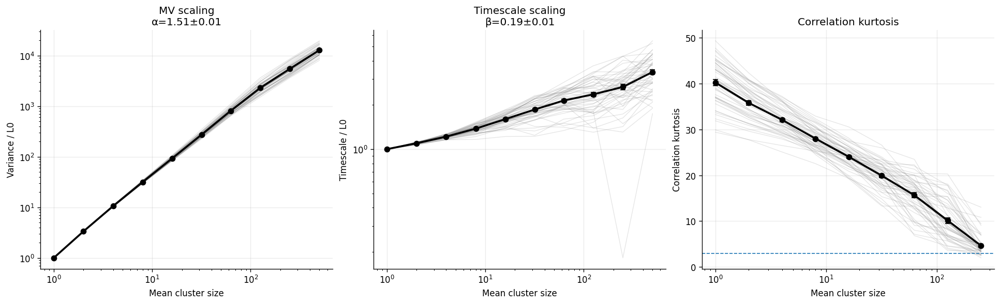

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/plots/fixed_startdic_50seed_corr_distributions.png


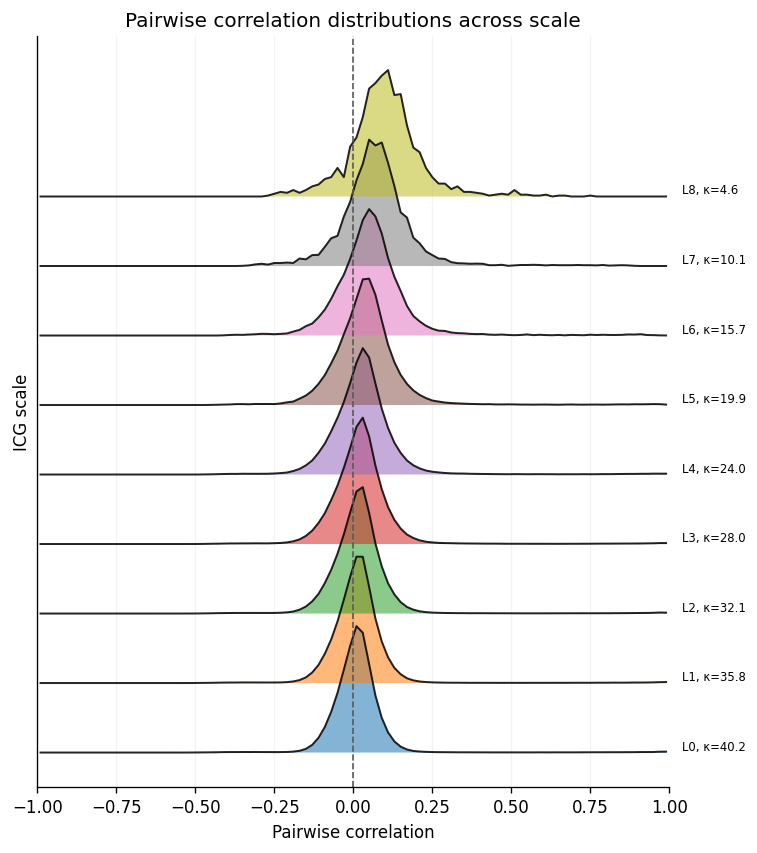

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005/plots/fixed_startdic_50seed_exponents.png


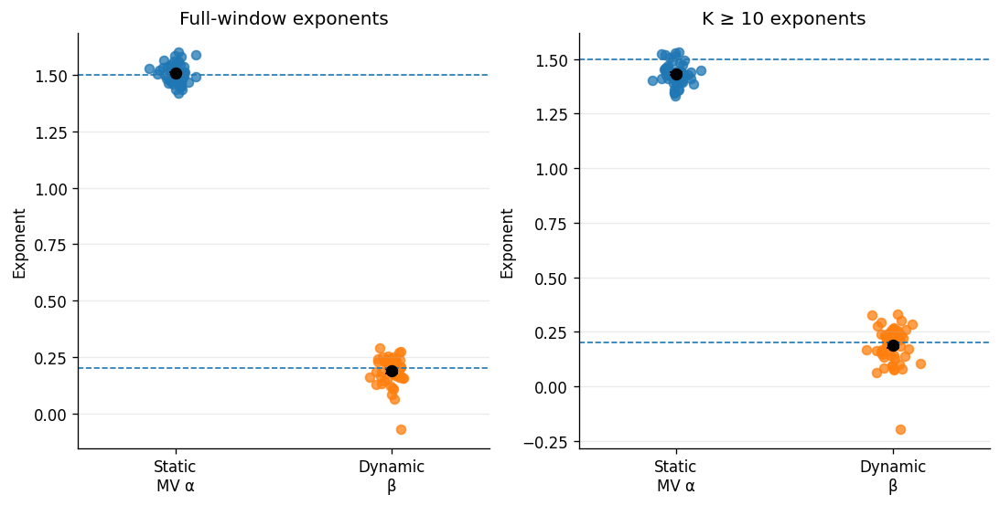


Exponent summary:
 n  static_alpha_mean  static_alpha_sem  static_r2_mean  dynamic_beta_mean  dynamic_beta_sem  dynamic_r2_mean  score_mean  score_sem  static_alpha_Kge10_mean  static_alpha_Kge10_sem  static_r2_Kge10_mean  dynamic_beta_Kge10_mean  dynamic_beta_Kge10_sem  dynamic_r2_Kge10_mean  score_Kge10_mean  score_Kge10_sem  mean_rate_hz_mean  mean_rate_hz_sem  frac_silent_frames_mean  frac_active_neurons_mean  phi  theta  p_ext     e_w    i_w  smoothe
50            1.50706             0.006          0.9979            0.18733           0.00875          0.88523     0.12398    0.01279                  1.43214                 0.00697               0.99648                  0.18655                 0.01274                 0.7723           0.20791          0.01802           10.36886           0.07315                      0.0                       1.0  4.2   8.44   0.02 21.4115 21.675     0.05

Scaling summary:
 mean_cluster_size  n     mv_mean    mv_sem  tau_mean  tau_sem  variance_raw_me

In [42]:
# ============================================================
# 50 repeats at fixed start_dic
#
# Saves data for:
#   - MV scaling
#   - timescale scaling
#   - kurtosis across ICG level
#   - pairwise correlation distributions per ICG level
#
# Assumes canonical functions exist:
#   automata_EI_hiermod
#   run_model
#   exp_smooth_spikes
#   icg_greedy_fast
#   mean_variance_sum
#   timescale
#   kurtosis_corr
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


# ============================================================
# 1. Fixed parameter point
# ============================================================

start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 21.4115,
    "i_w": 21.675,
    "theta": 8.44,
    "p_ext": 0.02,
    "phi": 4.2,
    "smoothe": 0.05,
}

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/fixed_startdic_phi4p2_theta8p44_pext0p02_50seeds_smooth005")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

N_SEEDS = 50
N_WORKERS = 30
BASE_SEED = 123450

MAX_ICG_LEVELS = 9
MIN_CLUSTERS = 4

SMOOTH_TAU = float(start_dic["smoothe"])
AC_MAX_LAG = 3.0

EXCLUDE_FIRST_FIT_POINT = True
EXCLUDE_LAST_FIT_POINT = False

MAX_CORR_SAMPLES_PER_LEVEL_PER_SEED = 25000

TARGET_MV = 1.50
TARGET_TAU = 0.20

print("OUTDIR:", OUTDIR)
print("N_SEEDS:", N_SEEDS)
print("N_WORKERS:", N_WORKERS)
print("start_dic:")
print(start_dic)


# ============================================================
# 2. Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def offdiag_corr_values(X, max_samples=25000, seed=0):
    """
    Return sampled off-diagonal pairwise correlations for rows of X.
    """
    X = np.asarray(X, dtype=float)

    if X.shape[0] < 3:
        return np.array([], dtype=float)

    C = np.corrcoef(X)
    vals = C[np.triu_indices_from(C, k=1)]
    vals = vals[np.isfinite(vals)]

    if vals.size > max_samples:
        rng = np.random.default_rng(seed)
        vals = rng.choice(vals, size=max_samples, replace=False)

    return vals


def fit_powerlaw_one_seed(
    g,
    y_col,
    x_col="mean_cluster_size",
    exclude_first=True,
    exclude_last=False,
    min_points=3,
):
    d = g[[x_col, y_col]].copy()
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[x_col] > 0) & (d[y_col] > 0)]
    d = d.sort_values(x_col)

    if exclude_first and len(d) > 0:
        d = d.iloc[1:]

    if exclude_last and len(d) > 0:
        d = d.iloc[:-1]

    if len(d) < min_points:
        return {
            "slope": np.nan,
            "r2": np.nan,
            "n_points": int(len(d)),
            "intercept": np.nan,
        }

    logx = np.log10(d[x_col].to_numpy(dtype=float))
    logy = np.log10(d[y_col].to_numpy(dtype=float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = np.sum((logy - pred) ** 2)
    ss_tot = np.sum((logy - np.mean(logy)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return {
        "slope": float(slope),
        "r2": float(r2),
        "n_points": int(len(d)),
        "intercept": float(intercept),
    }


def add_normed_seed_metrics(df, group_col="sim_id"):
    d = df.copy()
    d = d.sort_values([group_col, "mean_cluster_size"])

    d["scaled_variance_norm"] = (
        d["scaled_variance"]
        / d.groupby(group_col)["scaled_variance"].transform("first")
    )

    d["timescale_norm"] = (
        d["timescale"]
        / d.groupby(group_col)["timescale"].transform("first")
    )

    d.loc[~np.isfinite(d["scaled_variance_norm"]), "scaled_variance_norm"] = np.nan
    d.loc[~np.isfinite(d["timescale_norm"]), "timescale_norm"] = np.nan

    return d


# ============================================================
# 3. Run one simulation seed
# ============================================================
def run_one_seed(job):
    sim_id, seed, seed_idx = job

    pars = dict(start_dic)
    T = float(pars.pop("T"))
    smooth_tau = float(pars.pop("smoothe"))

    pars["seed"] = int(seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T)

    dt = float(start_dic["dt"])

    X = fn.exp_smooth_spikes(
        spikes,
        dt=dt,
        tau=smooth_tau,
    )

    gen_l, label_l, icgtr_l, size_l = fn.icg_greedy_fast(
        X,
        n_gen=MAX_ICG_LEVELS,
        eps=1e-6,
        keep_singletons=True,
        return_gen0=True,
        verbose=False,
    )

    metric_rows = []
    corr_rows = []

    mean_rate_hz = float(spikes.mean() / dt)
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    for gen, Xg, sg in zip(gen_l, icgtr_l, size_l):
        if Xg.shape[0] < MIN_CLUSTERS:
            break

        mean_cluster_size = float(np.mean(sg))

        scaled_variance = float(fn.mean_variance_sum(Xg))
        tau = float(fn.timescale(Xg, max_lag=AC_MAX_LAG, dt=dt))
        kcorr = float(fn.kurtosis_corr(Xg))

        metric_rows.append({
            "sim_id": int(sim_id),
            "seed": int(seed),
            "seed_idx": int(seed_idx),

            "icg_level": int(gen),
            "gen": int(gen),
            "mean_cluster_size": mean_cluster_size,
            "n_clusters": int(Xg.shape[0]),

            "scaled_variance": scaled_variance,
            "mean_variance": scaled_variance,

            "timescale": tau,
            "kurtosis_corr": kcorr,
            "corr_kurtosis": kcorr,

            "mean_rate_hz": mean_rate_hz,
            "pop_rate_mean_hz": pop_rate_mean_hz,
            "pop_rate_std_hz": pop_rate_std_hz,
            "frac_silent_frames": frac_silent_frames,
            "frac_active_neurons": frac_active_neurons,

            "n_neurons": int(start_dic["n_neurons"]),
            "dt": dt,
            "T": T,
            "smoothe": smooth_tau,

            "phi": float(start_dic["phi"]),
            "theta": float(start_dic["theta"]),
            "p_ext": float(start_dic["p_ext"]),
            "e_w": float(start_dic["e_w"]),
            "i_w": float(start_dic["i_w"]),
            "ei_ratio": float(start_dic["ei_ratio"]),
            "refractory_steps": int(start_dic["refractory_steps"]),
        })

        vals = offdiag_corr_values(
            Xg,
            max_samples=MAX_CORR_SAMPLES_PER_LEVEL_PER_SEED,
            seed=int(seed + gen),
        )

        if vals.size > 0:
            corr_rows.append(pd.DataFrame({
                "sim_id": int(sim_id),
                "seed": int(seed),
                "seed_idx": int(seed_idx),
                "icg_level": int(gen),
                "gen": int(gen),
                "mean_cluster_size": mean_cluster_size,
                "corr": vals,
            }))

    metric_df = pd.DataFrame(metric_rows)

    if len(corr_rows) > 0:
        corr_df = pd.concat(corr_rows, ignore_index=True)
    else:
        corr_df = pd.DataFrame(
            columns=[
                "sim_id", "seed", "seed_idx",
                "icg_level", "gen", "mean_cluster_size", "corr",
            ]
        )

    metric_df = add_normed_seed_metrics(metric_df, group_col="sim_id")

    mv_fit = fit_powerlaw_one_seed(
        metric_df,
        y_col="scaled_variance_norm",
        exclude_first=EXCLUDE_FIRST_FIT_POINT,
        exclude_last=EXCLUDE_LAST_FIT_POINT,
    )

    tau_fit = fit_powerlaw_one_seed(
        metric_df,
        y_col="timescale_norm",
        exclude_first=EXCLUDE_FIRST_FIT_POINT,
        exclude_last=EXCLUDE_LAST_FIT_POINT,
    )

    metric_k10 = metric_df[metric_df["mean_cluster_size"] >= 10]

    mv_fit_k10 = fit_powerlaw_one_seed(
        metric_k10,
        y_col="scaled_variance_norm",
        exclude_first=False,
        exclude_last=False,
    )

    tau_fit_k10 = fit_powerlaw_one_seed(
        metric_k10,
        y_col="timescale_norm",
        exclude_first=False,
        exclude_last=False,
    )

    score = (
        abs(mv_fit["slope"] - TARGET_MV) + 2.0 * abs(tau_fit["slope"] - TARGET_TAU)
        if np.isfinite(mv_fit["slope"]) and np.isfinite(tau_fit["slope"])
        else np.nan
    )

    score_k10 = (
        abs(mv_fit_k10["slope"] - TARGET_MV) + 2.0 * abs(tau_fit_k10["slope"] - TARGET_TAU)
        if np.isfinite(mv_fit_k10["slope"]) and np.isfinite(tau_fit_k10["slope"])
        else np.nan
    )

    exp_row = {
        "sim_id": int(sim_id),
        "seed": int(seed),
        "seed_idx": int(seed_idx),

        "static_alpha": mv_fit["slope"],
        "static_r2": mv_fit["r2"],
        "static_n_points": mv_fit["n_points"],
        "static_intercept": mv_fit["intercept"],

        "dynamic_beta": tau_fit["slope"],
        "dynamic_r2": tau_fit["r2"],
        "dynamic_n_points": tau_fit["n_points"],
        "dynamic_intercept": tau_fit["intercept"],

        "score": score,

        "static_alpha_Kge10": mv_fit_k10["slope"],
        "static_r2_Kge10": mv_fit_k10["r2"],
        "static_n_points_Kge10": mv_fit_k10["n_points"],

        "dynamic_beta_Kge10": tau_fit_k10["slope"],
        "dynamic_r2_Kge10": tau_fit_k10["r2"],
        "dynamic_n_points_Kge10": tau_fit_k10["n_points"],

        "score_Kge10": score_k10,

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,

        "n_neurons": int(start_dic["n_neurons"]),
        "dt": dt,
        "T": T,
        "smoothe": smooth_tau,

        "phi": float(start_dic["phi"]),
        "theta": float(start_dic["theta"]),
        "p_ext": float(start_dic["p_ext"]),
        "e_w": float(start_dic["e_w"]),
        "i_w": float(start_dic["i_w"]),
        "ei_ratio": float(start_dic["ei_ratio"]),
        "refractory_steps": int(start_dic["refractory_steps"]),
    }

    return metric_df, corr_df, exp_row

# ============================================================
# 4. Build design
# ============================================================

jobs = []
for seed_idx in range(N_SEEDS):
    sim_id = seed_idx
    seed = BASE_SEED + seed_idx
    jobs.append((int(sim_id), int(seed), int(seed_idx)))

design = pd.DataFrame(jobs, columns=["sim_id", "seed", "seed_idx"])
for k, v in start_dic.items():
    design[k] = v

design_path = OUTDIR / "fixed_startdic_50seed_design.csv"
design.to_csv(design_path, index=False)

print("Saved design:", design_path)


# ============================================================
# 5. Run simulations
# ============================================================

metric_dfs = []
corr_dfs = []
exp_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for metric_df, corr_df, exp_row in tqdm(
        pool.imap_unordered(run_one_seed, jobs, chunksize=1),
        total=len(jobs),
        desc="Running fixed start_dic repeats",
    ):
        metric_dfs.append(metric_df)
        corr_dfs.append(corr_df)
        exp_rows.append(exp_row)

df_metrics = (
    pd.concat(metric_dfs, ignore_index=True)
    .sort_values(["seed_idx", "icg_level"])
    .reset_index(drop=True)
)

df_corr = (
    pd.concat(corr_dfs, ignore_index=True)
    .sort_values(["seed_idx", "icg_level"])
    .reset_index(drop=True)
)

df_exp = (
    pd.DataFrame(exp_rows)
    .sort_values("seed_idx")
    .reset_index(drop=True)
)


# ============================================================
# 6. Summaries
# ============================================================

summary = (
    df_metrics
    .groupby("mean_cluster_size", as_index=False)
    .agg(
        n=("sim_id", "nunique"),

        mv_mean=("scaled_variance_norm", "mean"),
        mv_sem=("scaled_variance_norm", sem),

        tau_mean=("timescale_norm", "mean"),
        tau_sem=("timescale_norm", sem),

        variance_raw_mean=("scaled_variance", "mean"),
        variance_raw_sem=("scaled_variance", sem),

        timescale_raw_mean=("timescale", "mean"),
        timescale_raw_sem=("timescale", sem),

        kurtosis_mean=("kurtosis_corr", "mean"),
        kurtosis_sem=("kurtosis_corr", sem),

        n_clusters_mean=("n_clusters", "mean"),
        mean_rate_hz=("mean_rate_hz", "mean"),
    )
    .sort_values("mean_cluster_size")
    .reset_index(drop=True)
)

exp_summary = pd.DataFrame([{
    "n": int(df_exp["sim_id"].nunique()),

    "static_alpha_mean": float(df_exp["static_alpha"].mean()),
    "static_alpha_sem": sem(df_exp["static_alpha"]),
    "static_r2_mean": float(df_exp["static_r2"].mean()),

    "dynamic_beta_mean": float(df_exp["dynamic_beta"].mean()),
    "dynamic_beta_sem": sem(df_exp["dynamic_beta"]),
    "dynamic_r2_mean": float(df_exp["dynamic_r2"].mean()),

    "score_mean": float(df_exp["score"].mean()),
    "score_sem": sem(df_exp["score"]),

    "static_alpha_Kge10_mean": float(df_exp["static_alpha_Kge10"].mean()),
    "static_alpha_Kge10_sem": sem(df_exp["static_alpha_Kge10"]),
    "static_r2_Kge10_mean": float(df_exp["static_r2_Kge10"].mean()),

    "dynamic_beta_Kge10_mean": float(df_exp["dynamic_beta_Kge10"].mean()),
    "dynamic_beta_Kge10_sem": sem(df_exp["dynamic_beta_Kge10"]),
    "dynamic_r2_Kge10_mean": float(df_exp["dynamic_r2_Kge10"].mean()),

    "score_Kge10_mean": float(df_exp["score_Kge10"].mean()),
    "score_Kge10_sem": sem(df_exp["score_Kge10"]),

    "mean_rate_hz_mean": float(df_exp["mean_rate_hz"].mean()),
    "mean_rate_hz_sem": sem(df_exp["mean_rate_hz"]),

    "frac_silent_frames_mean": float(df_exp["frac_silent_frames"].mean()),
    "frac_active_neurons_mean": float(df_exp["frac_active_neurons"].mean()),

    "phi": float(start_dic["phi"]),
    "theta": float(start_dic["theta"]),
    "p_ext": float(start_dic["p_ext"]),
    "e_w": float(start_dic["e_w"]),
    "i_w": float(start_dic["i_w"]),
    "smoothe": float(start_dic["smoothe"]),
}])

corr_summary = (
    df_corr
    .groupby("icg_level", as_index=False)
    .agg(
        mean_cluster_size=("mean_cluster_size", "mean"),
        corr_mean=("corr", "mean"),
        corr_std=("corr", "std"),
        corr_median=("corr", "median"),
        corr_q05=("corr", lambda x: float(np.nanquantile(x, 0.05))),
        corr_q25=("corr", lambda x: float(np.nanquantile(x, 0.25))),
        corr_q75=("corr", lambda x: float(np.nanquantile(x, 0.75))),
        corr_q95=("corr", lambda x: float(np.nanquantile(x, 0.95))),
        n_corr=("corr", "count"),
    )
    .sort_values("icg_level")
    .reset_index(drop=True)
)


# ============================================================
# 7. Save all data
# ============================================================

metrics_path = OUTDIR / "fixed_startdic_50seed_scaling_metrics.csv"
corr_path = OUTDIR / "fixed_startdic_50seed_corr_distributions.csv"
exp_path = OUTDIR / "fixed_startdic_50seed_exponents.csv"
summary_path = OUTDIR / "fixed_startdic_50seed_scaling_summary.csv"
exp_summary_path = OUTDIR / "fixed_startdic_50seed_exponent_summary.csv"
corr_summary_path = OUTDIR / "fixed_startdic_50seed_corr_summary.csv"

df_metrics.to_csv(metrics_path, index=False)
df_corr.to_csv(corr_path, index=False)
df_exp.to_csv(exp_path, index=False)
summary.to_csv(summary_path, index=False)
exp_summary.to_csv(exp_summary_path, index=False)
corr_summary.to_csv(corr_summary_path, index=False)

print("Saved:", metrics_path)
print("Saved:", corr_path)
print("Saved:", exp_path)
print("Saved:", summary_path)
print("Saved:", exp_summary_path)
print("Saved:", corr_summary_path)


# ============================================================
# 8. Quick plots
# ============================================================

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ----------------------------
# Scaling + kurtosis
# ----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for _, g in df_metrics.groupby("sim_id"):
    g = g.sort_values("mean_cluster_size")

    axes[0].plot(
        g["mean_cluster_size"],
        g["scaled_variance_norm"],
        linewidth=0.8,
        alpha=0.18,
        color="0.45",
    )

    axes[1].plot(
        g["mean_cluster_size"],
        g["timescale_norm"],
        linewidth=0.8,
        alpha=0.18,
        color="0.45",
    )

    axes[2].plot(
        g["mean_cluster_size"],
        g["kurtosis_corr"],
        linewidth=0.8,
        alpha=0.18,
        color="0.45",
    )

axes[0].errorbar(
    summary["mean_cluster_size"],
    summary["mv_mean"],
    yerr=summary["mv_sem"],
    marker="o",
    linewidth=2.2,
    capsize=3,
    color="black",
)

axes[1].errorbar(
    summary["mean_cluster_size"],
    summary["tau_mean"],
    yerr=summary["tau_sem"],
    marker="o",
    linewidth=2.2,
    capsize=3,
    color="black",
)

axes[2].errorbar(
    summary["mean_cluster_size"],
    summary["kurtosis_mean"],
    yerr=summary["kurtosis_sem"],
    marker="o",
    linewidth=2.2,
    capsize=3,
    color="black",
)

axes[0].set_title(
    f"MV scaling\nα={exp_summary['static_alpha_mean'].iloc[0]:.2f}±{exp_summary['static_alpha_sem'].iloc[0]:.2f}"
)
axes[1].set_title(
    f"Timescale scaling\nβ={exp_summary['dynamic_beta_mean'].iloc[0]:.2f}±{exp_summary['dynamic_beta_sem'].iloc[0]:.2f}"
)
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("Variance / L0")
axes[1].set_ylabel("Timescale / L0")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

savefig(fig, "fixed_startdic_50seed_scaling_kurtosis.png")
plt.show()


# ----------------------------
# Correlation distributions by level
# ----------------------------
fig, ax = plt.subplots(figsize=(6.2, 7.0), constrained_layout=True)

levels = sorted(df_corr["icg_level"].dropna().unique())
levels = levels[:MAX_ICG_LEVELS]

bins = np.linspace(-1, 1, 101)
offset_step = 0.55

for i, level in enumerate(levels):
    vals = df_corr.loc[df_corr["icg_level"] == level, "corr"].to_numpy()
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        continue

    hist, edges = np.histogram(vals, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])

    hist = hist / hist.max() if hist.max() > 0 else hist
    y = hist + i * offset_step

    ax.fill_between(
        centers,
        i * offset_step,
        y,
        alpha=0.55,
        linewidth=0,
    )

    ax.plot(
        centers,
        y,
        linewidth=1.2,
        color="black",
        alpha=0.85,
    )

    k = summary.loc[np.isclose(summary["mean_cluster_size"], corr_summary.loc[corr_summary["icg_level"] == level, "mean_cluster_size"].iloc[0]), "kurtosis_mean"]
    ktxt = ""
    if len(k) > 0 and np.isfinite(k.iloc[0]):
        ktxt = f", κ={k.iloc[0]:.1f}"

    ax.text(
        1.04,
        i * offset_step,
        f"L{int(level)}{ktxt}",
        va="bottom",
        ha="left",
        fontsize=7,
    )

ax.axvline(0, linestyle="--", linewidth=1.0, color="0.35")
ax.set_xlim(-1, 1)
ax.set_yticks([])
ax.set_xlabel("Pairwise correlation")
ax.set_ylabel("ICG scale")
ax.set_title("Pairwise correlation distributions across scale")
ax.grid(axis="x", alpha=0.15)

savefig(fig, "fixed_startdic_50seed_corr_distributions.png")
plt.show()


# ----------------------------
# Exponent dot plot
# ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True)

rng = np.random.default_rng(1)

x_static = np.zeros(len(df_exp)) + rng.normal(0, 0.045, len(df_exp))
x_dynamic = np.ones(len(df_exp)) + rng.normal(0, 0.045, len(df_exp))

axes[0].scatter(x_static, df_exp["static_alpha"], s=35, alpha=0.75)
axes[0].scatter(x_dynamic, df_exp["dynamic_beta"], s=35, alpha=0.75)

axes[0].errorbar(
    [0, 1],
    [
        exp_summary["static_alpha_mean"].iloc[0],
        exp_summary["dynamic_beta_mean"].iloc[0],
    ],
    yerr=[
        exp_summary["static_alpha_sem"].iloc[0],
        exp_summary["dynamic_beta_sem"].iloc[0],
    ],
    fmt="o",
    color="black",
    markersize=7,
    capsize=4,
    linewidth=2,
)

axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].axhline(TARGET_TAU, linestyle="--", linewidth=1)

axes[0].set_xlim(-0.45, 1.45)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Static\nMV α", "Dynamic\nβ"])
axes[0].set_ylabel("Exponent")
axes[0].set_title("Full-window exponents")
axes[0].grid(axis="y", alpha=0.25)

x_static_k = np.zeros(len(df_exp)) + rng.normal(0, 0.045, len(df_exp))
x_dynamic_k = np.ones(len(df_exp)) + rng.normal(0, 0.045, len(df_exp))

axes[1].scatter(x_static_k, df_exp["static_alpha_Kge10"], s=35, alpha=0.75)
axes[1].scatter(x_dynamic_k, df_exp["dynamic_beta_Kge10"], s=35, alpha=0.75)

axes[1].errorbar(
    [0, 1],
    [
        exp_summary["static_alpha_Kge10_mean"].iloc[0],
        exp_summary["dynamic_beta_Kge10_mean"].iloc[0],
    ],
    yerr=[
        exp_summary["static_alpha_Kge10_sem"].iloc[0],
        exp_summary["dynamic_beta_Kge10_sem"].iloc[0],
    ],
    fmt="o",
    color="black",
    markersize=7,
    capsize=4,
    linewidth=2,
)

axes[1].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)

axes[1].set_xlim(-0.45, 1.45)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Static\nMV α", "Dynamic\nβ"])
axes[1].set_ylabel("Exponent")
axes[1].set_title("K ≥ 10 exponents")
axes[1].grid(axis="y", alpha=0.25)

savefig(fig, "fixed_startdic_50seed_exponents.png")
plt.show()


# ============================================================
# 9. Print summaries
# ============================================================

print("\nExponent summary:")
print(exp_summary.round(5).to_string(index=False))

print("\nScaling summary:")
print(summary.round(5).to_string(index=False))

print("\nCorrelation summary:")
print(corr_summary.round(5).to_string(index=False))

print("\nDone.")
print("Outputs saved to:", OUTDIR)

In [44]:
start_dic

{'n_neurons': 2000,
 'T': 10,
 'dt': 0.01,
 'refractory_steps': 2,
 'ei_ratio': 0.2,
 'e_w': 21.4115,
 'i_w': 21.675,
 'theta': 8.44,
 'p_ext': 0.02,
 'phi': 4.2,
 'smoothe': 0.05}

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005
N_REAL: 20
N_NULL_PER_REAL: 10
N_NULL_TOTAL: 200
T_RUN: 10.0
SMOOTHE: 0.05
start_dic: {'n_neurons': 2000, 'T': 10, 'dt': 0.01, 'refractory_steps': 2, 'ei_ratio': 0.2, 'e_w': 21.4115, 'i_w': 21.675, 'theta': 8.44, 'p_ext': 0.02, 'phi': 4.2, 'smoothe': 0.05}
Saved design: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_design.csv


Running real + shuffled null tests:   0%|          | 0/20 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_seed_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_summary.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_summary.csv

Summary:
   condition   n  n_reals  mv_alpha_norm_mean  mv_alpha_norm_sem  mv_r2_norm_mean  mv_r2_norm_sem  ts_beta_norm_mean  ts_beta_norm_sem  ts_r2_norm_mean  ts_r2_norm_sem  mv_alpha_raw_mean  mv_alpha_raw_sem  ts_beta_raw_mean  ts_beta_raw_sem  mean_rate_hz_mean  mean_rate_hz_sem  target_score_norm
null_shuffle 200       20             1.26049            0.00030          0.99989         0.000

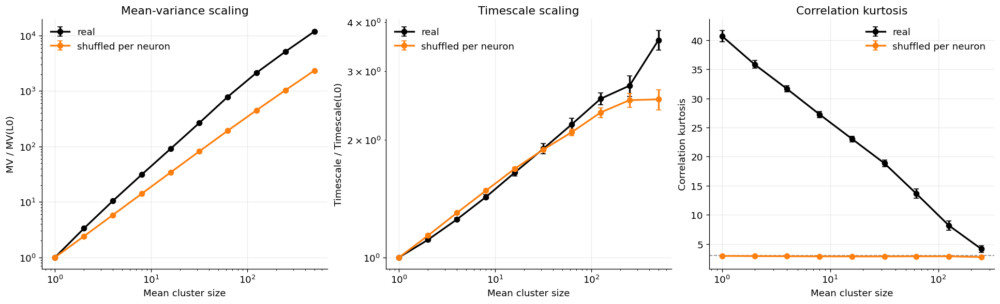

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/plots/real_vs_shuffle_exponents.png


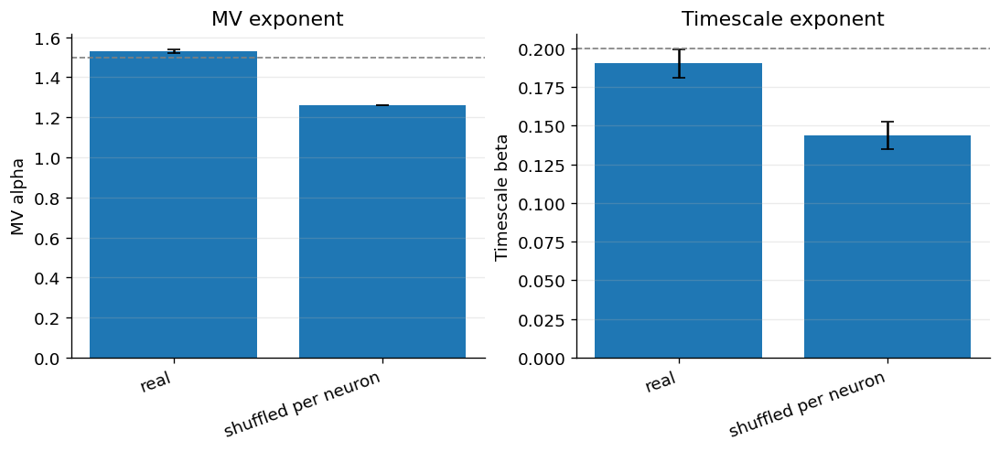

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/plots/real_vs_shuffle_paired_exponents.png


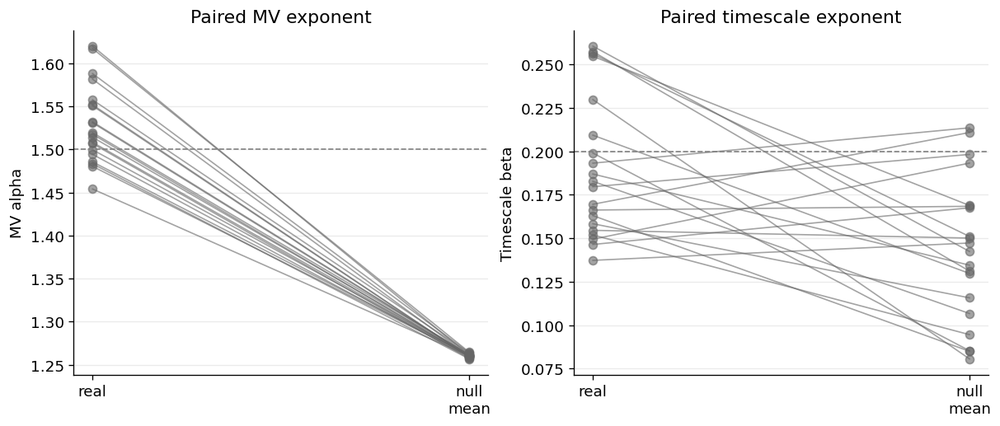


Done: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005
Files:
  design: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_design.csv
  seed metrics: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_seed_metrics.csv
  generation metrics: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_metrics.csv
  summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_summary.csv
  generation summary: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005/real_vs_shuffle_generation_summary.csv
  paired: /home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuff

In [49]:
# ============================================================
# NULL MODEL TEST FROM start_dic
#
# Real:
#   - 20 real simulations from start_dic
#
# Null:
#   - 10 independently time-shuffled nulls per real simulation
#   - preserves each neuron's activity distribution / rate
#   - destroys temporal coordination between neurons
#
# Uses:
#   - start_dic["smoothe"] = 0.05
#   - fn.automata_EI_hiermod
#   - fn.run_model
#   - fn.exp_smooth_spikes
#   - fn.compute_icg_metrics
#
# Saves:
#   real_vs_shuffle_design.csv
#   real_vs_shuffle_seed_metrics.csv
#   real_vs_shuffle_generation_metrics.csv
#   real_vs_shuffle_summary.csv
#   real_vs_shuffle_generation_summary.csv
#   real_vs_shuffle_paired_real_null_summary.csv
# ============================================================

import os
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 21.4115,
    "i_w": 21.675,
    "theta": 8.44,
    "p_ext": 0.02,
    "phi": 4.2,
    "smoothe": 0.05,
}

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/startdic_phi4p2_theta8p44_pext0p02_null_shuffle_20real_10null_smooth005")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

N_REAL = 20
N_NULL_PER_REAL = 10
N_WORKERS = 20
BASE_SEED = 93

SMOOTHE = float(start_dic.get("smoothe", 0.05))
T_RUN = float(start_dic["T"])

TARGET_ALPHA = 1.5
TARGET_BETA = 0.2

print("OUTDIR:", OUTDIR)
print("N_REAL:", N_REAL)
print("N_NULL_PER_REAL:", N_NULL_PER_REAL)
print("N_NULL_TOTAL:", N_REAL * N_NULL_PER_REAL)
print("T_RUN:", T_RUN)
print("SMOOTHE:", SMOOTHE)
print("start_dic:", start_dic)


# ============================================================
# Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def make_model_pars(seed):
    pars = dict(start_dic)

    if "slope" in pars and "phi" not in pars:
        pars["phi"] = float(pars.pop("slope"))
    else:
        pars.pop("slope", None)

    T = float(pars.pop("T"))
    smoothe = float(pars.pop("smoothe", SMOOTHE))

    pars["seed"] = int(seed)

    return pars, T, smoothe


def shuffle_each_neuron(spikes, rng):
    """
    Independently shuffle each neuron's time series.

    Preserves:
      - each neuron's spike/activity count
      - global number of active bins per neuron

    Destroys:
      - cross-neuron temporal coordination
      - propagation / synchrony / avalanche-like timing
    """
    X = np.asarray(spikes).copy()

    for i in range(X.shape[0]):
        rng.shuffle(X[i])

    return X


def compute_metrics_for_spikes(spikes, dt, smoothe):
    X = fn.exp_smooth_spikes(
        spikes,
        dt=float(dt),
        tau=float(smoothe),
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=X,
        dt=float(dt),
    )

    return metric_row, gen_df


def add_common_metadata_to_out(
    out,
    condition,
    real_idx,
    null_idx,
    seed,
    shuffle_seed,
    mean_rate_hz,
    dt,
    T,
    smoothe,
):
    out = dict(out)

    out["condition"] = str(condition)
    out["real_idx"] = int(real_idx)
    out["null_idx"] = int(null_idx)
    out["seed"] = int(seed)
    out["shuffle_seed"] = int(shuffle_seed)

    out["mean_rate_hz"] = float(mean_rate_hz)
    out["dt"] = float(dt)
    out["T"] = float(T)
    out["smoothe"] = float(smoothe)

    out["n_neurons"] = int(start_dic["n_neurons"])
    out["phi"] = float(start_dic["phi"])
    out["theta"] = float(start_dic["theta"])
    out["p_ext"] = float(start_dic["p_ext"])
    out["e_w"] = float(start_dic["e_w"])
    out["i_w"] = float(start_dic["i_w"])
    out["ei_ratio"] = float(start_dic["ei_ratio"])
    out["refractory_steps"] = int(start_dic["refractory_steps"])

    return out


def add_common_metadata_to_gen_df(
    gen_df,
    condition,
    real_idx,
    null_idx,
    seed,
    shuffle_seed,
    mean_rate_hz,
):
    gen_df = gen_df.copy()

    gen_df["condition"] = str(condition)
    gen_df["real_idx"] = int(real_idx)
    gen_df["null_idx"] = int(null_idx)
    gen_df["seed"] = int(seed)
    gen_df["shuffle_seed"] = int(shuffle_seed)

    gen_df["mean_rate_hz"] = float(mean_rate_hz)

    gen_df["n_neurons"] = int(start_dic["n_neurons"])
    gen_df["phi"] = float(start_dic["phi"])
    gen_df["theta"] = float(start_dic["theta"])
    gen_df["p_ext"] = float(start_dic["p_ext"])
    gen_df["e_w"] = float(start_dic["e_w"])
    gen_df["i_w"] = float(start_dic["i_w"])
    gen_df["ei_ratio"] = float(start_dic["ei_ratio"])
    gen_df["refractory_steps"] = int(start_dic["refractory_steps"])
    gen_df["smoothe"] = float(SMOOTHE)

    return gen_df


def run_one_real_with_nulls(job):
    real_idx, seed = job

    pars, T, smoothe = make_model_pars(seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T)

    dt = float(pars["dt"])
    mean_rate_hz = float(spikes.mean() / dt)

    # ----------------------------
    # Real metrics
    # ----------------------------
    real_metric_row, real_gen_df = compute_metrics_for_spikes(
        spikes=spikes,
        dt=dt,
        smoothe=smoothe,
    )

    real_out = add_common_metadata_to_out(
        real_metric_row,
        condition="real",
        real_idx=real_idx,
        null_idx=-1,
        seed=seed,
        shuffle_seed=-1,
        mean_rate_hz=mean_rate_hz,
        dt=dt,
        T=T,
        smoothe=smoothe,
    )

    real_gen_df = add_common_metadata_to_gen_df(
        real_gen_df,
        condition="real",
        real_idx=real_idx,
        null_idx=-1,
        seed=seed,
        shuffle_seed=-1,
        mean_rate_hz=mean_rate_hz,
    )

    rows = [real_out]
    gen_rows = [real_gen_df]

    # ----------------------------
    # Null metrics
    # ----------------------------
    for null_idx in range(N_NULL_PER_REAL):
        shuffle_seed = int(seed + 100000 + null_idx)
        rng = np.random.default_rng(shuffle_seed)

        spikes_null = shuffle_each_neuron(spikes, rng)

        null_metric_row, null_gen_df = compute_metrics_for_spikes(
            spikes=spikes_null,
            dt=dt,
            smoothe=smoothe,
        )

        null_mean_rate_hz = float(spikes_null.mean() / dt)

        null_out = add_common_metadata_to_out(
            null_metric_row,
            condition="null_shuffle",
            real_idx=real_idx,
            null_idx=null_idx,
            seed=seed,
            shuffle_seed=shuffle_seed,
            mean_rate_hz=null_mean_rate_hz,
            dt=dt,
            T=T,
            smoothe=smoothe,
        )

        null_gen_df = add_common_metadata_to_gen_df(
            null_gen_df,
            condition="null_shuffle",
            real_idx=real_idx,
            null_idx=null_idx,
            seed=seed,
            shuffle_seed=shuffle_seed,
            mean_rate_hz=null_mean_rate_hz,
        )

        rows.append(null_out)
        gen_rows.append(null_gen_df)

    return rows, gen_rows


# ============================================================
# Build design
# ============================================================

jobs = [(int(i), int(BASE_SEED + i)) for i in range(N_REAL)]

design = pd.DataFrame(jobs, columns=["real_idx", "seed"])
design["n_null_per_real"] = int(N_NULL_PER_REAL)

for k, v in start_dic.items():
    design[k] = v

design_path = OUTDIR / "real_vs_shuffle_design.csv"
design.to_csv(design_path, index=False)

print("Saved design:", design_path)


# ============================================================
# Run real + null simulations
# ============================================================

all_rows = []
all_gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for rows, gen_rows in tqdm(
        pool.imap_unordered(run_one_real_with_nulls, jobs, chunksize=1),
        total=len(jobs),
        desc="Running real + shuffled null tests",
    ):
        all_rows.extend(rows)
        all_gen_rows.extend(gen_rows)


# ============================================================
# Save raw outputs
# ============================================================

df = (
    pd.DataFrame(all_rows)
    .sort_values(["condition", "real_idx", "null_idx"])
    .reset_index(drop=True)
)

gen_all = (
    pd.concat(all_gen_rows, ignore_index=True)
    .sort_values(["condition", "real_idx", "null_idx", "gen"])
    .reset_index(drop=True)
)

seed_metrics_path = OUTDIR / "real_vs_shuffle_seed_metrics.csv"
gen_metrics_path = OUTDIR / "real_vs_shuffle_generation_metrics.csv"

df.to_csv(seed_metrics_path, index=False)
gen_all.to_csv(gen_metrics_path, index=False)

print("Saved:", seed_metrics_path)
print("Saved:", gen_metrics_path)


# ============================================================
# Summaries
# ============================================================

summary = (
    df
    .groupby("condition", as_index=False)
    .agg(
        n=("seed", "count"),
        n_reals=("real_idx", "nunique"),

        mv_alpha_norm_mean=("mv_alpha_norm", "mean"),
        mv_alpha_norm_sem=("mv_alpha_norm", sem),
        mv_r2_norm_mean=("mv_r2_norm", "mean"),
        mv_r2_norm_sem=("mv_r2_norm", sem),

        ts_beta_norm_mean=("ts_beta_norm", "mean"),
        ts_beta_norm_sem=("ts_beta_norm", sem),
        ts_r2_norm_mean=("ts_r2_norm", "mean"),
        ts_r2_norm_sem=("ts_r2_norm", sem),

        mv_alpha_raw_mean=("mv_alpha", "mean"),
        mv_alpha_raw_sem=("mv_alpha", sem),
        ts_beta_raw_mean=("ts_beta", "mean"),
        ts_beta_raw_sem=("ts_beta", sem),

        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),
    )
)

summary["target_score_norm"] = (
    np.abs(summary["mv_alpha_norm_mean"] - TARGET_ALPHA)
    + 2.0 * np.abs(summary["ts_beta_norm_mean"] - TARGET_BETA)
)

gen_summary = (
    gen_all
    .groupby(["condition", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),
        n_reals=("real_idx", "nunique"),

        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", sem),
    )
    .sort_values(["condition", "gen"])
    .reset_index(drop=True)
)

summary_path = OUTDIR / "real_vs_shuffle_summary.csv"
gen_summary_path = OUTDIR / "real_vs_shuffle_generation_summary.csv"

summary.to_csv(summary_path, index=False)
gen_summary.to_csv(gen_summary_path, index=False)

print("Saved:", summary_path)
print("Saved:", gen_summary_path)

print("\nSummary:")
print(summary.round(5).to_string(index=False))


# ============================================================
# Paired real-vs-null summary per real simulation
# ============================================================

real_df = (
    df[df["condition"] == "real"]
    .set_index("real_idx")
    .add_prefix("real_")
)

null_by_real = (
    df[df["condition"] == "null_shuffle"]
    .groupby("real_idx", as_index=True)
    .agg(
        null_n=("seed", "count"),

        null_mv_alpha_norm_mean=("mv_alpha_norm", "mean"),
        null_mv_alpha_norm_sem=("mv_alpha_norm", sem),
        null_ts_beta_norm_mean=("ts_beta_norm", "mean"),
        null_ts_beta_norm_sem=("ts_beta_norm", sem),

        null_mv_r2_norm_mean=("mv_r2_norm", "mean"),
        null_ts_r2_norm_mean=("ts_r2_norm", "mean"),

        null_mean_rate_hz_mean=("mean_rate_hz", "mean"),
    )
)

paired = real_df.join(null_by_real, how="left").reset_index()

paired["delta_mv_alpha_norm"] = (
    paired["real_mv_alpha_norm"] - paired["null_mv_alpha_norm_mean"]
)

paired["delta_ts_beta_norm"] = (
    paired["real_ts_beta_norm"] - paired["null_ts_beta_norm_mean"]
)

paired["delta_mv_r2_norm"] = (
    paired["real_mv_r2_norm"] - paired["null_mv_r2_norm_mean"]
)

paired["delta_ts_r2_norm"] = (
    paired["real_ts_r2_norm"] - paired["null_ts_r2_norm_mean"]
)

paired_path = OUTDIR / "real_vs_shuffle_paired_real_null_summary.csv"
paired.to_csv(paired_path, index=False)

print("Saved:", paired_path)

print("\nPaired real-null differences:")
print(
    paired[
        [
            "real_idx",
            "real_mv_alpha_norm",
            "null_mv_alpha_norm_mean",
            "delta_mv_alpha_norm",
            "real_ts_beta_norm",
            "null_ts_beta_norm_mean",
            "delta_ts_beta_norm",
            "real_mean_rate_hz",
            "null_mean_rate_hz_mean",
        ]
    ].round(5).to_string(index=False)
)


# ============================================================
# Plotting
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

colors = {
    "real": "black",
    "null_shuffle": "tab:orange",
}

labels = {
    "real": "real",
    "null_shuffle": "shuffled per neuron",
}


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# 1. Scaling forms
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for condition in ["real", "null_shuffle"]:
    gg = gen_summary[gen_summary["condition"] == condition].sort_values("gen")

    x = gg["mean_cluster_size_mean"].to_numpy()

    axes[0].errorbar(
        x,
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

    axes[1].errorbar(
        x,
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

    axes[2].errorbar(
        x,
        gg["corr_kurtosis_mean"],
        yerr=gg["corr_kurtosis_sem"],
        marker="o",
        linewidth=2,
        capsize=3,
        color=colors[condition],
        label=labels[condition],
    )

axes[0].set_title("Mean-variance scaling")
axes[1].set_title("Timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1, color="grey")

savefig(fig, "real_vs_shuffle_scaling_forms.png")
plt.show()


# ============================================================
# 2. Fitted exponent bars
# ============================================================

plot_df = (
    summary
    .set_index("condition")
    .loc[["real", "null_shuffle"]]
    .reset_index()
)

x = np.arange(len(plot_df))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)

axes[0].bar(
    x,
    plot_df["mv_alpha_norm_mean"],
    yerr=plot_df["mv_alpha_norm_sem"],
    capsize=4,
)
axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1, color="grey")
axes[0].set_xticks(x)
axes[0].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[0].set_ylabel("MV alpha")
axes[0].set_title("MV exponent")

axes[1].bar(
    x,
    plot_df["ts_beta_norm_mean"],
    yerr=plot_df["ts_beta_norm_sem"],
    capsize=4,
)
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1, color="grey")
axes[1].set_xticks(x)
axes[1].set_xticklabels([labels[c] for c in plot_df["condition"]], rotation=20, ha="right")
axes[1].set_ylabel("Timescale beta")
axes[1].set_title("Timescale exponent")

for ax in axes:
    ax.grid(alpha=0.25, axis="y")

savefig(fig, "real_vs_shuffle_exponents.png")
plt.show()


# ============================================================
# 3. Paired real-null differences
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)

for _, r in paired.iterrows():
    axes[0].plot(
        [0, 1],
        [r["real_mv_alpha_norm"], r["null_mv_alpha_norm_mean"]],
        marker="o",
        linewidth=1,
        alpha=0.6,
        color="0.4",
    )

    axes[1].plot(
        [0, 1],
        [r["real_ts_beta_norm"], r["null_ts_beta_norm_mean"]],
        marker="o",
        linewidth=1,
        alpha=0.6,
        color="0.4",
    )

axes[0].axhline(TARGET_ALPHA, linestyle="--", linewidth=1, color="grey")
axes[1].axhline(TARGET_BETA, linestyle="--", linewidth=1, color="grey")

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["real", "null\nmean"])
axes[0].set_ylabel("MV alpha")
axes[0].set_title("Paired MV exponent")

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["real", "null\nmean"])
axes[1].set_ylabel("Timescale beta")
axes[1].set_title("Paired timescale exponent")

for ax in axes:
    ax.grid(alpha=0.25, axis="y")

savefig(fig, "real_vs_shuffle_paired_exponents.png")
plt.show()


print("\nDone:", OUTDIR)
print("Files:")
print("  design:", design_path)
print("  seed metrics:", seed_metrics_path)
print("  generation metrics:", gen_metrics_path)
print("  summary:", summary_path)
print("  generation summary:", gen_summary_path)
print("  paired:", paired_path)
print("  plots:", PLOTDIR)

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling
PHI_VALUES: [1.5        2.11111111 2.72222222 3.33333333 3.94444444 4.55555556
 5.16666667 5.77777778 6.38888889 7.        ]
N_SEEDS: 10
TOTAL SIMS: 100
T_RUN: 10.0
SMOOTHE: 0.05
Saved design: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/phi_raster_scaling_design.csv


Running phi raster + scaling sweep:   0%|          | 0/100 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/phi_raster_scaling_seed_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/phi_raster_scaling_generation_metrics.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/phi_raster_scaling_raster_events.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/phi_raster_scaling_seed_summary.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/phi_raster_scaling_generation_summary.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/plots/all_rasters_phi_1p5_7p0_10seeds.png


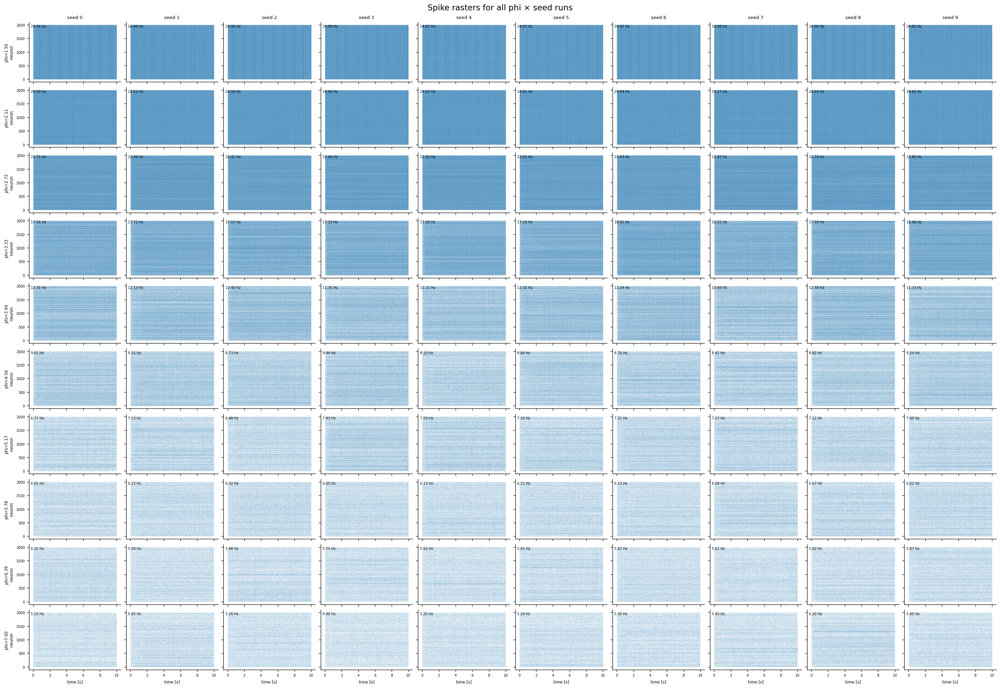

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/plots/mean_scaling_functions_over_seeds.png


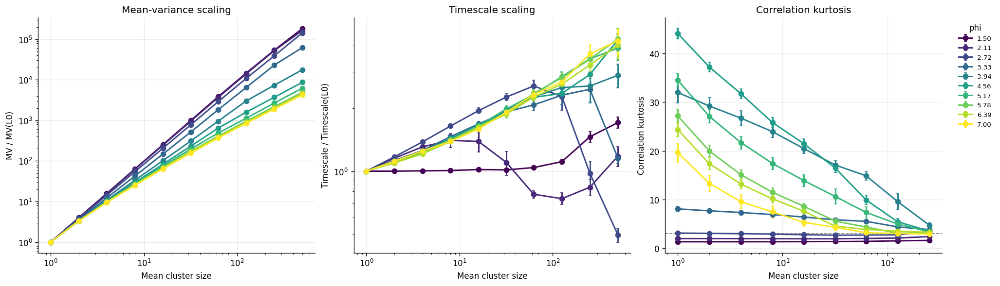

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/plots/exponents_and_rate_vs_phi.png


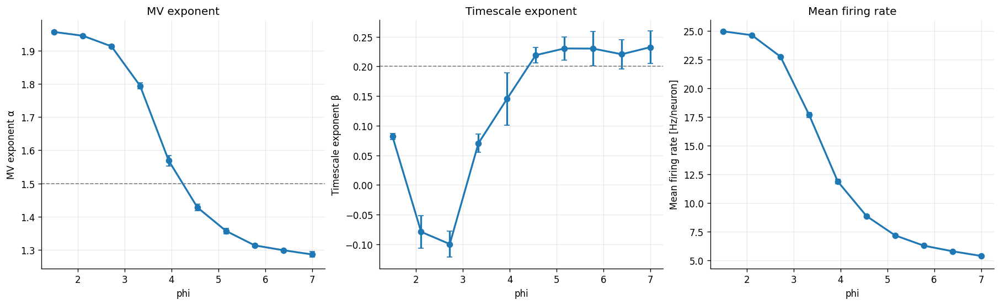


Done.
OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling
PLOTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling/plots


,phi,n,mean_rate_hz_mean,mean_rate_hz_sem,MV_alpha_mean,MV_alpha_sem,MV_r2_mean,TAU_beta_mean,TAU_beta_sem,TAU_r2_mean,frac_silent_frames_mean,frac_active_neurons_mean
0,1.500000,10,24.944285,0.017548,1.955684,0.002431,0.999656,0.081795,0.004818,0.575780,0.0,1.0
1,2.111111,10,24.611820,0.013229,1.944311,0.002578,0.999522,-0.079068,0.027699,0.341167,0.0,1.0
2,2.722222,10,22.738390,0.053003,1.912453,0.005518,0.999901,-0.099734,0.021998,0.152606,0.0,1.0
3,3.333333,10,17.665565,0.205997,1.793677,0.008871,0.999452,0.070238,0.015482,0.230903,0.0,1.0
4,3.944444,10,11.855980,0.209028,1.568417,0.015215,0.998114,0.145364,0.044279,0.724151,0.0,1.0
5,4.555556,10,8.850570,0.124375,1.428071,0.010341,0.997624,0.218956,0.013172,0.898909,0.0,1.0
6,5.166667,10,7.159600,0.126211,1.357335,0.008449,0.997760,0.230221,0.019364,0.926928,0.0,1.0
7,5.777778,10,6.264295,0.076561,1.314002,0.004666,0.997807,0.230057,0.029041,0.848766,0.0,1.0
8,6.388889,10,5.776445,0.059792,1.299460,0.003423,0.997770,0.220445,0.024527,0.845387,0.0,1.0
9,7.000000,10,5.367300,0.103011,1.286864,0.008109,0.998085,0.232409,0.027027,0.874349,0.0,1.0


In [50]:
# ============================================================
# PHI SWEEP: rasters + ICG scaling functions
#
#   - phi: 1.5 -> 7.0, 10 values
#   - 10 seeds per phi
#   - uses start_dic values
#   - uses exp smoothing tau = 0.05 for ICG
#   - saves:
#       phi_raster_scaling_design.csv
#       phi_raster_scaling_seed_metrics.csv
#       phi_raster_scaling_generation_metrics.csv
#       phi_raster_scaling_raster_events.csv
#   - plots:
#       all rasters: rows=phi, cols=seed
#       mean scaling curves over seeds
# ============================================================

import os
import inspect
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Settings
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_1p5_7p0_10steps_10seeds_rasters_scaling")
OUTDIR.mkdir(parents=True, exist_ok=True)

PLOTDIR = OUTDIR / "plots"
PLOTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.linspace(1.5, 7.0, 10)
N_SEEDS = 10
N_WORKERS = 20
BASE_SEED = 970000

T_RUN = float(start_dic["T"])
SMOOTHE = 0.05

print("OUTDIR:", OUTDIR)
print("PHI_VALUES:", PHI_VALUES)
print("N_SEEDS:", N_SEEDS)
print("TOTAL SIMS:", len(PHI_VALUES) * N_SEEDS)
print("T_RUN:", T_RUN)
print("SMOOTHE:", SMOOTHE)


# ============================================================
# Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))


def make_pars_from_start(phi, seed):
    pars = dict(start_dic)

    # Runtime / analysis keys
    pars.pop("T", None)
    pars.pop("smoothe", None)

    sig = inspect.signature(fn.automata_EI_hiermod.__init__)
    valid_args = set(sig.parameters.keys())

    # Handle whether your current class expects phi or slope
    if "phi" in valid_args:
        pars.pop("slope", None)
        pars["phi"] = float(phi)
    elif "slope" in valid_args:
        pars.pop("phi", None)
        pars["slope"] = float(phi)
    else:
        raise ValueError("automata_EI_hiermod expects neither 'phi' nor 'slope'.")

    pars["seed"] = int(seed)

    # Keep only constructor-valid args
    pars = {k: v for k, v in pars.items() if k in valid_args}

    return pars


def fit_power_slope(
    g,
    y_col,
    x_col="mean_cluster_size",
    exclude_first=True,
    exclude_last=False,
    min_points=3,
):
    dfit = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    dfit = dfit[(dfit[x_col] > 0) & (dfit[y_col] > 0)].sort_values(x_col)

    if exclude_first and len(dfit) > 0:
        dfit = dfit.iloc[1:]

    if exclude_last and len(dfit) > 0:
        dfit = dfit.iloc[:-1]

    if len(dfit) < min_points:
        return np.nan, np.nan, int(len(dfit))

    logx = np.log10(dfit[x_col].to_numpy(float))
    logy = np.log10(dfit[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = np.sum((logy - pred) ** 2)
    ss_tot = np.sum((logy - np.mean(logy)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(dfit))


def standardise_gen_df(gen_df):
    """
    Keep aliases so plotting is robust to different compute_icg_metrics column names.
    """
    gen_df = gen_df.copy()

    if "corr_kurtosis" in gen_df.columns and "kurtosis_corr" not in gen_df.columns:
        gen_df["kurtosis_corr"] = gen_df["corr_kurtosis"]

    if "kurtosis_corr" in gen_df.columns and "corr_kurtosis" not in gen_df.columns:
        gen_df["corr_kurtosis"] = gen_df["kurtosis_corr"]

    if "mean_variance_norm" not in gen_df.columns and "MV_norm" in gen_df.columns:
        gen_df["mean_variance_norm"] = gen_df["MV_norm"]

    if "timescale_norm" not in gen_df.columns and "TAU_norm" in gen_df.columns:
        gen_df["timescale_norm"] = gen_df["TAU_norm"]

    if "mean_variance" not in gen_df.columns and "MV" in gen_df.columns:
        gen_df["mean_variance"] = gen_df["MV"]

    if "timescale" not in gen_df.columns and "TAU" in gen_df.columns:
        gen_df["timescale"] = gen_df["TAU"]

    return gen_df


def run_one(job):
    sim_id, phi, seed, seed_idx = job

    pars = make_pars_from_start(phi=phi, seed=seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T_RUN)

    dt = float(pars["dt"])

    # ----------------------------
    # Raster events
    # ----------------------------
    neuron_idx, time_idx = np.where(spikes > 0)

    raster_df = pd.DataFrame({
        "sim_id": int(sim_id),
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),
        "neuron": neuron_idx.astype(int),
        "time_s": time_idx.astype(float) * dt,
    })

    # ----------------------------
    # Smooth and ICG
    # ----------------------------
    spikes_smooth = fn.exp_smooth_spikes(
        spikes,
        dt=dt,
        tau=SMOOTHE,
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=spikes_smooth,
        dt=dt,
    )

    gen_df = standardise_gen_df(gen_df)

    gen_df["sim_id"] = int(sim_id)
    gen_df["phi"] = float(phi)
    gen_df["seed"] = int(seed)
    gen_df["seed_idx"] = int(seed_idx)
    gen_df["smoothe"] = float(SMOOTHE)

    # ----------------------------
    # Exponents from generation metrics
    # ----------------------------
    mv_col = "mean_variance_norm"
    tau_col = "timescale_norm"

    MV_alpha, MV_r2, MV_n = fit_power_slope(
        gen_df,
        y_col=mv_col,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    TAU_beta, TAU_r2, TAU_n = fit_power_slope(
        gen_df,
        y_col=tau_col,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    mean_rate_hz = float(spikes.mean() / dt)

    seed_row = {
        "sim_id": int(sim_id),
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": float(np.mean(pop_rate)),
        "pop_rate_std_hz": float(np.std(pop_rate)),
        "frac_silent_frames": float(np.mean(spikes.sum(axis=0) == 0)),
        "frac_active_neurons": float(np.mean(spikes.sum(axis=1) > 0)),

        "MV_alpha": MV_alpha,
        "MV_r2": MV_r2,
        "MV_n_points": MV_n,

        "TAU_beta": TAU_beta,
        "TAU_r2": TAU_r2,
        "TAU_n_points": TAU_n,

        "n_spikes": int(len(neuron_idx)),
        "n_neurons": int(spikes.shape[0]),
        "n_timebins": int(spikes.shape[1]),
        "dt": dt,
        "T": float(T_RUN),
        "smoothe": float(SMOOTHE),
    }

    return seed_row, gen_df, raster_df


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


# ============================================================
# Build design
# ============================================================

jobs = []
sim_id = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + sim_id
        jobs.append((int(sim_id), float(phi), int(seed), int(seed_idx)))
        sim_id += 1

design = pd.DataFrame(
    jobs,
    columns=["sim_id", "phi", "seed", "seed_idx"],
)

design.to_csv(OUTDIR / "phi_raster_scaling_design.csv", index=False)
print("Saved design:", OUTDIR / "phi_raster_scaling_design.csv")


# ============================================================
# Run
# ============================================================

seed_rows = []
gen_rows = []
raster_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for seed_row, gen_df, raster_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Running phi raster + scaling sweep",
    ):
        seed_rows.append(seed_row)
        gen_rows.append(gen_df)
        raster_rows.append(raster_df)

seed_metrics = (
    pd.DataFrame(seed_rows)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

gen_all = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "gen"])
    .reset_index(drop=True)
)

raster_all = (
    pd.concat(raster_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "time_s", "neuron"])
    .reset_index(drop=True)
)

seed_metrics.to_csv(OUTDIR / "phi_raster_scaling_seed_metrics.csv", index=False)
gen_all.to_csv(OUTDIR / "phi_raster_scaling_generation_metrics.csv", index=False)
raster_all.to_csv(OUTDIR / "phi_raster_scaling_raster_events.csv", index=False)

print("Saved:", OUTDIR / "phi_raster_scaling_seed_metrics.csv")
print("Saved:", OUTDIR / "phi_raster_scaling_generation_metrics.csv")
print("Saved:", OUTDIR / "phi_raster_scaling_raster_events.csv")


# ============================================================
# Summaries over seeds
# ============================================================

seed_summary = (
    seed_metrics
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        mean_rate_hz_mean=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),

        MV_alpha_mean=("MV_alpha", "mean"),
        MV_alpha_sem=("MV_alpha", sem),
        MV_r2_mean=("MV_r2", "mean"),

        TAU_beta_mean=("TAU_beta", "mean"),
        TAU_beta_sem=("TAU_beta", sem),
        TAU_r2_mean=("TAU_r2", "mean"),

        frac_silent_frames_mean=("frac_silent_frames", "mean"),
        frac_active_neurons_mean=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

gen_summary = (
    gen_all
    .groupby(["phi", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),

        mean_cluster_size_mean=("mean_cluster_size", "mean"),
        mean_cluster_size_sem=("mean_cluster_size", sem),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem),

        kurtosis_corr_mean=("kurtosis_corr", "mean"),
        kurtosis_corr_sem=("kurtosis_corr", sem),
    )
    .sort_values(["phi", "gen"])
    .reset_index(drop=True)
)

seed_summary.to_csv(OUTDIR / "phi_raster_scaling_seed_summary.csv", index=False)
gen_summary.to_csv(OUTDIR / "phi_raster_scaling_generation_summary.csv", index=False)

print("Saved:", OUTDIR / "phi_raster_scaling_seed_summary.csv")
print("Saved:", OUTDIR / "phi_raster_scaling_generation_summary.csv")


# ============================================================
# Plot 1: every raster
#   rows = phi
#   columns = seed_idx
# ============================================================

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

phis = np.sort(seed_metrics["phi"].unique())
seed_idxs = np.sort(seed_metrics["seed_idx"].unique())

n_phi = len(phis)
n_seed = len(seed_idxs)

fig, axes = plt.subplots(
    n_phi,
    n_seed,
    figsize=(2.4 * n_seed, 1.65 * n_phi),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

if n_phi == 1:
    axes = axes[None, :]
if n_seed == 1:
    axes = axes[:, None]

for i, phi in enumerate(phis):
    for j, seed_idx in enumerate(seed_idxs):
        ax = axes[i, j]

        rr = raster_all[
            (np.isclose(raster_all["phi"], phi)) &
            (raster_all["seed_idx"] == seed_idx)
        ]

        ax.scatter(
            rr["time_s"],
            rr["neuron"],
            s=0.08,
            marker=".",
            linewidths=0,
        )

        fr = seed_metrics[
            (np.isclose(seed_metrics["phi"], phi)) &
            (seed_metrics["seed_idx"] == seed_idx)
        ]["mean_rate_hz"].iloc[0]

        if i == 0:
            ax.set_title(f"seed {seed_idx}", fontsize=8)

        if j == 0:
            ax.set_ylabel(f"phi={phi:.2f}\nneuron", fontsize=7)

        if i == n_phi - 1:
            ax.set_xlabel("time [s]", fontsize=7)

        ax.text(
            0.02,
            0.96,
            f"{fr:.2f} Hz",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=6,
        )

        ax.tick_params(labelsize=6)

fig.suptitle("Spike rasters for all phi × seed runs", fontsize=14)

savefig(fig, "all_rasters_phi_1p5_7p0_10seeds.png")
plt.show()


# ============================================================
# Plot 2: mean scaling functions over seeds
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

cmap = plt.cm.viridis
norm = plt.Normalize(vmin=phis.min(), vmax=phis.max())

for phi in phis:
    gg = gen_summary[gen_summary["phi"] == phi].sort_values("gen")
    c = cmap(norm(phi))

    x = gg["mean_cluster_size_mean"].to_numpy()

    axes[0].errorbar(
        x,
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=1.8,
        capsize=2,
        color=c,
        label=f"{phi:.2f}",
    )

    axes[1].errorbar(
        x,
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=1.8,
        capsize=2,
        color=c,
        label=f"{phi:.2f}",
    )

    axes[2].errorbar(
        x,
        gg["kurtosis_corr_mean"],
        yerr=gg["kurtosis_corr_sem"],
        marker="o",
        linewidth=1.8,
        capsize=2,
        color=c,
        label=f"{phi:.2f}",
    )

axes[0].set_title("Mean-variance scaling")
axes[1].set_title("Timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1, color="grey")

axes[2].legend(
    title="phi",
    frameon=False,
    fontsize=8,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "mean_scaling_functions_over_seeds.png")
plt.show()


# ============================================================
# Plot 3: exponent summaries
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].errorbar(
    seed_summary["phi"],
    seed_summary["MV_alpha_mean"],
    yerr=seed_summary["MV_alpha_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].axhline(1.5, linestyle="--", linewidth=1, color="grey")
axes[0].set_ylabel("MV exponent α")
axes[0].set_title("MV exponent")

axes[1].errorbar(
    seed_summary["phi"],
    seed_summary["TAU_beta_mean"],
    yerr=seed_summary["TAU_beta_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].axhline(0.2, linestyle="--", linewidth=1, color="grey")
axes[1].set_ylabel("Timescale exponent β")
axes[1].set_title("Timescale exponent")

axes[2].errorbar(
    seed_summary["phi"],
    seed_summary["mean_rate_hz_mean"],
    yerr=seed_summary["mean_rate_hz_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[2].set_ylabel("Mean firing rate [Hz/neuron]")
axes[2].set_title("Mean firing rate")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "exponents_and_rate_vs_phi.png")
plt.show()


print("\nDone.")
print("OUTDIR:", OUTDIR)
print("PLOTDIR:", PLOTDIR)
display(seed_summary)

In [189]:
#NEW RUN!

# ============================================================
# Quick phi scaling sweep with new main pars
#   e_w=11.7, i_w=22.4
#   quick version: 10 phis x 5 seeds = 50 sims
# ============================================================

import os
import json
import inspect
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import icg_functions as fn


# ============================================================
# Main parameters
# ============================================================

start_dic = {
    "n_neurons": 2000,
    "T": 10,
    "dt": 0.01,
    "refractory_steps": 2,
    "ei_ratio": 0.2,
    "e_w": 11.7,
    "i_w": 22.4,
    "theta": 8.44,
    "p_ext": 0.02,
    "phi": 4.2,
    "smoothe": 0.05,
}


# ============================================================
# Settings: quick test
# ============================================================

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005"
)
OUTDIR.mkdir(parents=True, exist_ok=True)

PHI_VALUES = np.linspace(1.5, 10.0, 10)
N_SEEDS = 5
N_WORKERS = 30
BASE_SEED = 950000

SMOOTHE = float(start_dic["smoothe"])
T_RUN = float(start_dic["T"])

TARGET_MV = 1.50
TARGET_TAU = 0.20

with open(OUTDIR / "config.json", "w") as f:
    json.dump(
        {
            "PHI_VALUES": PHI_VALUES.tolist(),
            "N_SEEDS": N_SEEDS,
            "N_WORKERS": N_WORKERS,
            "BASE_SEED": BASE_SEED,
            "SMOOTHE": SMOOTHE,
            "T_RUN": T_RUN,
            "TARGET_MV": TARGET_MV,
            "TARGET_TAU": TARGET_TAU,
            "start_dic": start_dic,
        },
        f,
        indent=2,
    )

print("OUTDIR:", OUTDIR)
print("TOTAL SIMS:", len(PHI_VALUES) * N_SEEDS)


# ============================================================
# Helpers
# ============================================================

def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    return float(x.std(ddof=1) / np.sqrt(len(x))) if len(x) > 1 else np.nan


def fit_power_slope(
    g,
    y_col,
    x_col="mean_cluster_size",
    exclude_first=True,
    exclude_last=False,
    min_points=3,
):
    dfit = g[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    dfit = dfit[(dfit[x_col] > 0) & (dfit[y_col] > 0)].sort_values(x_col)

    if exclude_first and len(dfit) > 0:
        dfit = dfit.iloc[1:]

    if exclude_last and len(dfit) > 0:
        dfit = dfit.iloc[:-1]

    if len(dfit) < min_points:
        return np.nan, np.nan, int(len(dfit))

    logx = np.log10(dfit[x_col].to_numpy(float))
    logy = np.log10(dfit[y_col].to_numpy(float))

    slope, intercept = np.polyfit(logx, logy, 1)
    pred = intercept + slope * logx

    ss_res = np.sum((logy - pred) ** 2)
    ss_tot = np.sum((logy - np.mean(logy)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(dfit))


def make_pars(phi, seed):
    pars = dict(start_dic)
    pars.pop("T", None)
    pars.pop("smoothe", None)

    sig = inspect.signature(fn.automata_EI_hiermod.__init__)
    valid_args = set(sig.parameters.keys())

    if "slope" in valid_args:
        pars.pop("phi", None)
        pars["slope"] = float(phi)
    elif "phi" in valid_args:
        pars.pop("slope", None)
        pars["phi"] = float(phi)
    else:
        raise ValueError("Model expects neither 'slope' nor 'phi'.")

    pars["seed"] = int(seed)
    return {k: v for k, v in pars.items() if k in valid_args}


def run_one(job):
    sim_id, phi, seed, seed_idx = job

    pars = make_pars(phi=phi, seed=seed)

    model = fn.automata_EI_hiermod(**pars)
    spikes, pop_rate = fn.run_model(model, T=T_RUN)

    dt = float(pars["dt"])

    mean_rate_hz = float(spikes.mean() / dt)
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    spikes_smooth = fn.exp_smooth_spikes(
        spikes,
        dt=dt,
        tau=SMOOTHE,
    )

    metric_row, gen_df = fn.compute_icg_metrics(
        spikes=spikes_smooth,
        dt=dt,
    )

    gen_df = gen_df.copy()

    rename_map = {
        "mean_variance": "MV",
        "mean_variance_norm": "MV_norm",
        "timescale": "TAU",
        "timescale_norm": "TAU_norm",
        "corr_kurtosis": "kurtosis_corr",
    }

    for old, new in rename_map.items():
        if old in gen_df.columns and new not in gen_df.columns:
            gen_df[new] = gen_df[old]

    if "MV" in gen_df.columns and "mean_variance" not in gen_df.columns:
        gen_df["mean_variance"] = gen_df["MV"]
    if "MV_norm" in gen_df.columns and "mean_variance_norm" not in gen_df.columns:
        gen_df["mean_variance_norm"] = gen_df["MV_norm"]
    if "TAU" in gen_df.columns and "timescale" not in gen_df.columns:
        gen_df["timescale"] = gen_df["TAU"]
    if "TAU_norm" in gen_df.columns and "timescale_norm" not in gen_df.columns:
        gen_df["timescale_norm"] = gen_df["TAU_norm"]
    if "kurtosis_corr" not in gen_df.columns and "corr_kurtosis" in gen_df.columns:
        gen_df["kurtosis_corr"] = gen_df["corr_kurtosis"]

    mv_y = "mean_variance_norm" if "mean_variance_norm" in gen_df.columns else "MV_norm"
    tau_y = "timescale_norm" if "timescale_norm" in gen_df.columns else "TAU_norm"

    MV_alpha, MV_r2, MV_n_points = fit_power_slope(
        gen_df,
        y_col=mv_y,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    TAU_beta, TAU_r2, TAU_n_points = fit_power_slope(
        gen_df,
        y_col=tau_y,
        x_col="mean_cluster_size",
        exclude_first=True,
        exclude_last=False,
    )

    score = (
        abs(MV_alpha - TARGET_MV)
        + 2.0 * abs(TAU_beta - TARGET_TAU)
        if np.isfinite(MV_alpha) and np.isfinite(TAU_beta)
        else np.nan
    )

    exp_row = {
        "sim_id": int(sim_id),
        "phi": float(phi),
        "seed": int(seed),
        "seed_idx": int(seed_idx),

        "MV_alpha": MV_alpha,
        "MV_r2": MV_r2,
        "MV_n_points": MV_n_points,

        "TAU_beta": TAU_beta,
        "TAU_r2": TAU_r2,
        "TAU_n_points": TAU_n_points,

        "score": score,

        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,

        "dt": dt,
        "T": float(T_RUN),
        "smoothe": float(SMOOTHE),

        "theta": float(pars.get("theta", np.nan)),
        "p_ext": float(pars.get("p_ext", np.nan)),
        "e_w": float(pars.get("e_w", np.nan)),
        "i_w": float(pars.get("i_w", np.nan)),
        "ei_ratio": float(pars.get("ei_ratio", np.nan)),
        "refractory_steps": int(pars.get("refractory_steps", -1)),
    }

    gen_df["sim_id"] = int(sim_id)
    gen_df["phi"] = float(phi)
    gen_df["seed"] = int(seed)
    gen_df["seed_idx"] = int(seed_idx)
    gen_df["mean_rate_hz"] = mean_rate_hz
    gen_df["smoothe"] = float(SMOOTHE)

    return exp_row, gen_df


# ============================================================
# Build design
# ============================================================

jobs = []
sim_id = 0

for phi in PHI_VALUES:
    for seed_idx in range(N_SEEDS):
        seed = BASE_SEED + sim_id
        jobs.append((int(sim_id), float(phi), int(seed), int(seed_idx)))
        sim_id += 1

design = pd.DataFrame(
    jobs,
    columns=["sim_id", "phi", "seed", "seed_idx"],
)

design.to_csv(OUTDIR / "phi_scaling_design.csv", index=False)


# ============================================================
# Run sweep
# ============================================================

rows = []
gen_rows = []

ctx = mp.get_context("fork")

with ctx.Pool(processes=min(N_WORKERS, len(jobs))) as pool:
    for exp_row, gen_df in tqdm(
        pool.imap_unordered(run_one, jobs, chunksize=1),
        total=len(jobs),
        desc="Quick phi scaling sweep, new pars",
    ):
        rows.append(exp_row)
        gen_rows.append(gen_df)

df_exp = (
    pd.DataFrame(rows)
    .sort_values(["phi", "seed_idx"])
    .reset_index(drop=True)
)

df_icg = (
    pd.concat(gen_rows, ignore_index=True)
    .sort_values(["phi", "seed_idx", "gen"])
    .reset_index(drop=True)
)

df_exp.to_csv(OUTDIR / "phi_scaling_seed_exponents.csv", index=False)
df_icg.to_csv(OUTDIR / "phi_scaling_icg_rows.csv", index=False)

print("Saved:", OUTDIR / "phi_scaling_seed_exponents.csv")
print("Saved:", OUTDIR / "phi_scaling_icg_rows.csv")


# ============================================================
# Summary by phi
# ============================================================

phi_summary = (
    df_exp
    .groupby("phi", as_index=False)
    .agg(
        n=("seed", "count"),

        MV_alpha_mean=("MV_alpha", "mean"),
        MV_alpha_sem=("MV_alpha", sem),
        MV_r2_mean=("MV_r2", "mean"),
        MV_r2_sem=("MV_r2", sem),

        TAU_beta_mean=("TAU_beta", "mean"),
        TAU_beta_sem=("TAU_beta", sem),
        TAU_r2_mean=("TAU_r2", "mean"),
        TAU_r2_sem=("TAU_r2", sem),

        score_mean=("score", "mean"),
        score_sem=("score", sem),

        mean_rate_hz=("mean_rate_hz", "mean"),
        mean_rate_hz_sem=("mean_rate_hz", sem),

        pop_rate_mean_hz=("pop_rate_mean_hz", "mean"),
        pop_rate_std_hz=("pop_rate_std_hz", "mean"),

        frac_silent_frames=("frac_silent_frames", "mean"),
        frac_active_neurons=("frac_active_neurons", "mean"),
    )
    .sort_values("phi")
    .reset_index(drop=True)
)

phi_summary.to_csv(OUTDIR / "phi_scaling_summary.csv", index=False)

print("\nBest phi values by score:")
print(
    phi_summary
    .sort_values("score_mean")
    [
        [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "MV_r2_mean",
            "TAU_r2_mean",
            "mean_rate_hz",
            "n",
        ]
    ]
    .head(15)
    .round(4)
    .to_string(index=False)
)

print("\nDone.")
print("Outputs saved to:", OUTDIR)

OUTDIR: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005
TOTAL SIMS: 50


Quick phi scaling sweep, new pars:   0%|          | 0/50 [00:00<?, ?it/s]

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/phi_scaling_seed_exponents.csv
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/phi_scaling_icg_rows.csv

Best phi values by score:
    phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  MV_r2_mean  TAU_r2_mean  mean_rate_hz  n
 2.4444         1.5505        0.0024         0.2097        0.0197      0.1189      0.9997       0.8610       22.5198  5
 3.3889         1.4298        0.0026         0.2264        0.0264      0.1795      0.9997       0.8669       14.3103  5
10.0000         1.2391        0.0025         0.1652        0.0418      0.4297      0.9985       0.6565        4.0227  5
 7.1667         1.2670        0.0036         0.1391        0.0993      0.4766      0.9985       0.7722        4.7224  5
 5.2778         1.2960        0.0041         0.0945        0.0809      0.4828  

Loaded:
design: (50, 4)
df_exp: (50, 25)
df_icg: (500, 22)
phi_summary: (10, 18)

Best phi values by score:
     phi  MV_alpha_mean  MV_alpha_sem  TAU_beta_mean  TAU_beta_sem  score_mean  score_sem  MV_r2_mean  TAU_r2_mean  mean_rate_hz  frac_silent_frames  frac_active_neurons  n
 2.44444        1.55048       0.00244        0.20965       0.01971     0.11894    0.02419     0.99973      0.86104      22.51978                 0.0                  1.0  5
 3.38889        1.42984       0.00259        0.22640       0.02637     0.17952    0.02040     0.99967      0.86693      14.31034                 0.0                  1.0  5
10.00000        1.23907       0.00245        0.16522       0.04180     0.42969    0.03171     0.99855      0.65648       4.02268                 0.0                  1.0  5
 7.16667        1.26700       0.00360        0.13912       0.09925     0.47655    0.16548     0.99854      0.77220       4.72236                 0.0                  1.0  5
 5.27778        1.29596    

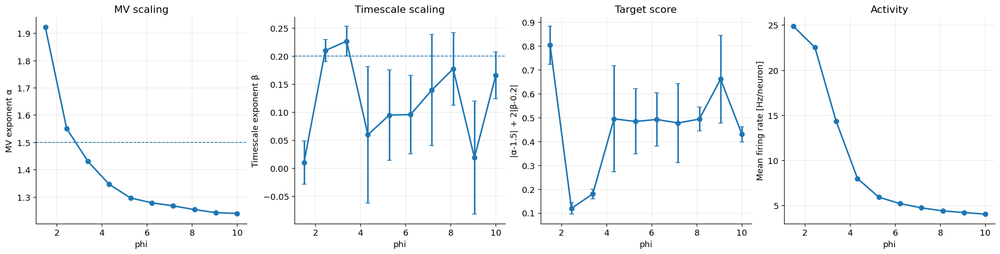

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/plots_examine/phi_summary_r2_activity_sanity.png


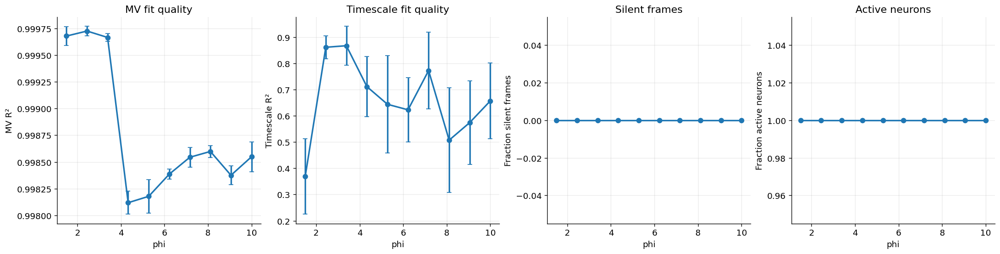

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/plots_examine/seed_level_exponents_score_vs_phi.png


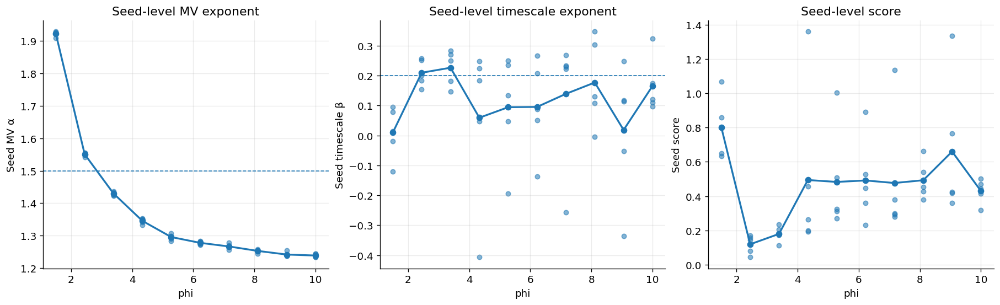


Selected phis for ICG curves:
[ 1.5         2.44444444  3.38888889  5.27777778  7.16666667 10.        ]
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/plots_examine/selected_phi_icg_curves.png


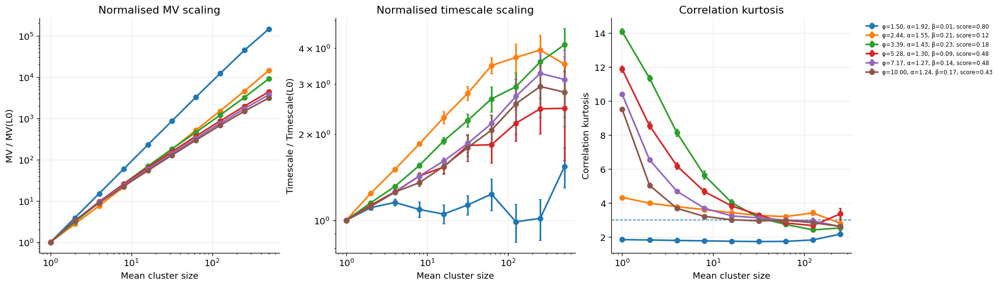


Best phi:
phi                     2.44444
n                       5.00000
MV_alpha_mean           1.55048
MV_alpha_sem            0.00244
MV_r2_mean              0.99973
MV_r2_sem               0.00004
TAU_beta_mean           0.20965
TAU_beta_sem            0.01971
TAU_r2_mean             0.86104
TAU_r2_sem              0.04381
score_mean              0.11894
score_sem               0.02419
mean_rate_hz           22.51978
mean_rate_hz_sem        0.03469
pop_rate_mean_hz       22.51978
pop_rate_std_hz         1.35798
frac_silent_frames      0.00000
frac_active_neurons     1.00000
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/plots_examine/best_phi_icg_curves.png


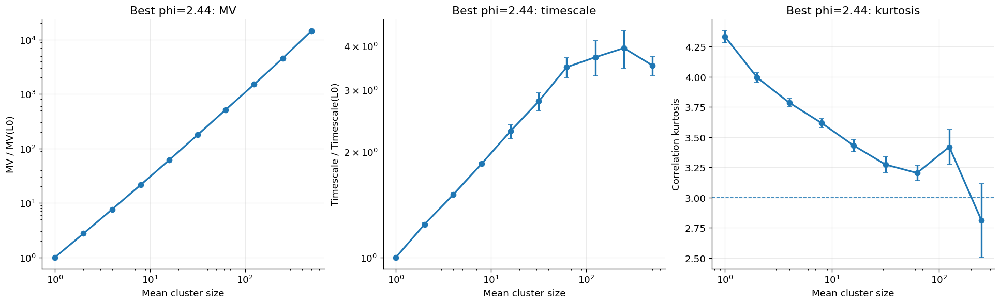

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/plots_examine/selected_phi_K10_marker.png


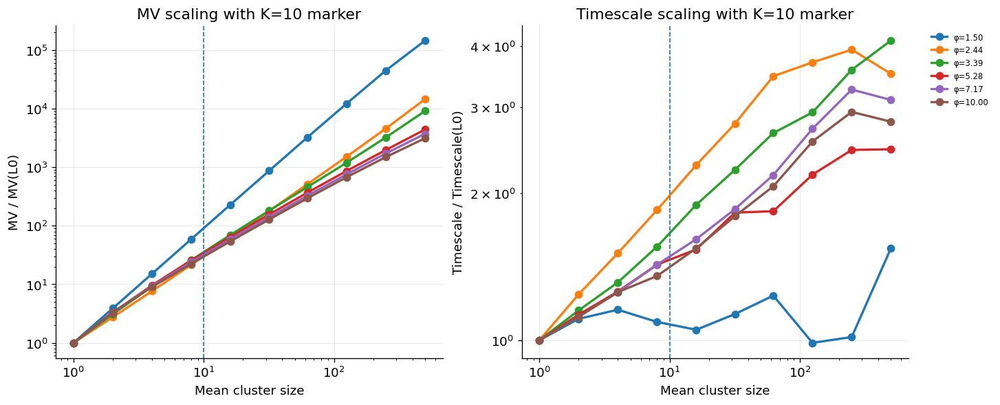


Best phi values using K >= 10 refit:
     phi  MV_alpha_Kge10  MV_r2_Kge10  MV_n_Kge10  TAU_beta_Kge10  TAU_r2_Kge10  TAU_n_Kge10  score_Kge10
 3.38889         1.41089      0.99975           6         0.22348       0.99531            6      0.13607
 2.44444         1.58217      0.99983           6         0.13514       0.70961            6      0.21188
 7.16667         1.20862      0.99950           6         0.21545       0.94071            6      0.32228
 8.11111         1.19630      0.99941           6         0.21175       0.95753            6      0.32719
10.00000         1.18169      0.99916           6         0.19383       0.93099            6      0.33065
 4.33333         1.27262      0.99963           6         0.13117       0.69061            6      0.36504
 5.27778         1.22856      0.99958           6         0.14197       0.94146            6      0.38750
 6.22222         1.21645      0.99956           6         0.12839       0.87385            6      0.42676
 9.05556

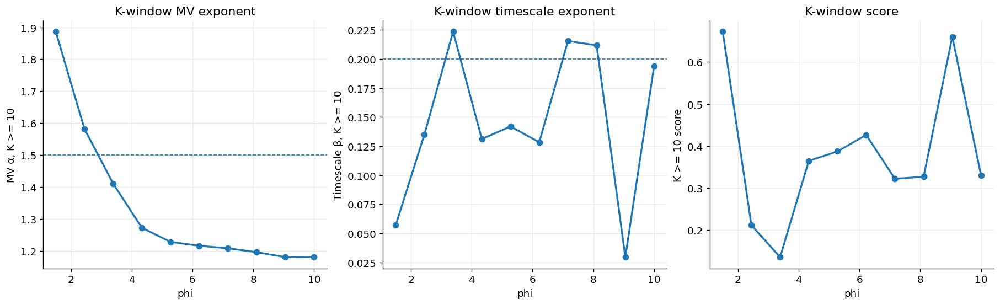


Done.
Plots saved to: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005/plots_examine


In [190]:
# ============================================================
# LOAD + PLOT quick phi scaling sweep with new main pars
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "phi_scaling_newpars_ew11p7_iw22p4_quick_phi1p5to10_10steps_5seeds_smooth005"
)

PLOTDIR = OUTDIR / "plots_examine"
PLOTDIR.mkdir(parents=True, exist_ok=True)

TARGET_MV = 1.50
TARGET_TAU = 0.20

design = pd.read_csv(OUTDIR / "phi_scaling_design.csv")
df_exp = pd.read_csv(OUTDIR / "phi_scaling_seed_exponents.csv")
df_icg = pd.read_csv(OUTDIR / "phi_scaling_icg_rows.csv")
phi_summary = pd.read_csv(OUTDIR / "phi_scaling_summary.csv")

print("Loaded:")
print("design:", design.shape)
print("df_exp:", df_exp.shape)
print("df_icg:", df_icg.shape)
print("phi_summary:", phi_summary.shape)

print("\nBest phi values by score:")
print(
    phi_summary
    .sort_values("score_mean")
    [
        [
            "phi",
            "MV_alpha_mean",
            "MV_alpha_sem",
            "TAU_beta_mean",
            "TAU_beta_sem",
            "score_mean",
            "score_sem",
            "MV_r2_mean",
            "TAU_r2_mean",
            "mean_rate_hz",
            "frac_silent_frames",
            "frac_active_neurons",
            "n",
        ]
    ]
    .head(20)
    .round(5)
    .to_string(index=False)
)


plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


def savefig(fig, name):
    path = PLOTDIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


def sem_nan(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    return float(x.std(ddof=1) / np.sqrt(len(x))) if len(x) > 1 else np.nan


def nearest_value(x, values):
    values = np.asarray(values, dtype=float)
    return float(values[np.argmin(np.abs(values - float(x)))])


def select_nearest_rows(df, col, target):
    vals = np.sort(df[col].dropna().unique().astype(float))
    nearest = nearest_value(target, vals)
    return df[np.isclose(df[col], nearest)], nearest


# ============================================================
# Build ICG summary across seeds
# ============================================================

icg_summary = (
    df_icg
    .groupby(["phi", "gen"], as_index=False)
    .agg(
        n=("seed", "count"),
        mean_cluster_size=("mean_cluster_size", "mean"),

        mean_variance_norm_mean=("mean_variance_norm", "mean"),
        mean_variance_norm_sem=("mean_variance_norm", sem_nan),

        timescale_norm_mean=("timescale_norm", "mean"),
        timescale_norm_sem=("timescale_norm", sem_nan),

        corr_kurtosis_mean=("corr_kurtosis", "mean"),
        corr_kurtosis_sem=("corr_kurtosis", sem_nan),

        mean_rate_hz=("mean_rate_hz", "mean"),
    )
    .reset_index(drop=True)
)


# ============================================================
# 1. Exponents and score vs phi
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)

axes[0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_alpha_mean"],
    yerr=phi_summary["MV_alpha_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("MV exponent α")
axes[0].set_title("MV scaling")

axes[1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_beta_mean"],
    yerr=phi_summary["TAU_beta_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Timescale exponent β")
axes[1].set_title("Timescale scaling")

axes[2].errorbar(
    phi_summary["phi"],
    phi_summary["score_mean"],
    yerr=phi_summary["score_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[2].set_ylabel("|α-1.5| + 2|β-0.2|")
axes[2].set_title("Target score")

axes[3].plot(
    phi_summary["phi"],
    phi_summary["mean_rate_hz"],
    marker="o",
    linewidth=2,
)
axes[3].set_ylabel("Mean firing rate [Hz/neuron]")
axes[3].set_title("Activity")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "phi_summary_exponents_score_rate.png")
plt.show()


# ============================================================
# 2. R² and activity sanity
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)

axes[0].errorbar(
    phi_summary["phi"],
    phi_summary["MV_r2_mean"],
    yerr=phi_summary["MV_r2_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].set_ylabel("MV R²")
axes[0].set_title("MV fit quality")

axes[1].errorbar(
    phi_summary["phi"],
    phi_summary["TAU_r2_mean"],
    yerr=phi_summary["TAU_r2_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].set_ylabel("Timescale R²")
axes[1].set_title("Timescale fit quality")

axes[2].plot(
    phi_summary["phi"],
    phi_summary["frac_silent_frames"],
    marker="o",
    linewidth=2,
)
axes[2].set_ylabel("Fraction silent frames")
axes[2].set_title("Silent frames")

axes[3].plot(
    phi_summary["phi"],
    phi_summary["frac_active_neurons"],
    marker="o",
    linewidth=2,
)
axes[3].set_ylabel("Fraction active neurons")
axes[3].set_title("Active neurons")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "phi_summary_r2_activity_sanity.png")
plt.show()


# ============================================================
# 3. Seed-level scatter
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(df_exp["phi"], df_exp["MV_alpha"], s=25, alpha=0.55)
axes[0].plot(phi_summary["phi"], phi_summary["MV_alpha_mean"], marker="o", linewidth=2)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("Seed MV α")
axes[0].set_title("Seed-level MV exponent")

axes[1].scatter(df_exp["phi"], df_exp["TAU_beta"], s=25, alpha=0.55)
axes[1].plot(phi_summary["phi"], phi_summary["TAU_beta_mean"], marker="o", linewidth=2)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Seed timescale β")
axes[1].set_title("Seed-level timescale exponent")

axes[2].scatter(df_exp["phi"], df_exp["score"], s=25, alpha=0.55)
axes[2].plot(phi_summary["phi"], phi_summary["score_mean"], marker="o", linewidth=2)
axes[2].set_ylabel("Seed score")
axes[2].set_title("Seed-level score")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "seed_level_exponents_score_vs_phi.png")
plt.show()


# ============================================================
# 4. Mean ICG curves by selected phi
# ============================================================

available_phis = np.sort(phi_summary["phi"].dropna().unique().astype(float))

best_phis = (
    phi_summary
    .sort_values("score_mean")
    ["phi"]
    .head(5)
    .to_numpy(float)
)

comparison_targets = np.array([
    float(phi_summary["phi"].min()),
    float(phi_summary["phi"].median()),
    float(phi_summary["phi"].max()),
])

selected_targets = np.concatenate([best_phis, comparison_targets])
selected_phis = np.unique([nearest_value(p, available_phis) for p in selected_targets])
selected_phis = np.array(sorted(selected_phis))

print("\nSelected phis for ICG curves:")
print(selected_phis)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for phi in selected_phis:
    gg, phi_icg = select_nearest_rows(icg_summary, "phi", phi)
    ss, phi_sum = select_nearest_rows(phi_summary, "phi", phi)

    gg = gg.sort_values("gen")

    if gg.empty or ss.empty:
        continue

    row = ss.iloc[0]

    label = (
        f"φ={phi_sum:.2f}, "
        f"α={row['MV_alpha_mean']:.2f}, "
        f"β={row['TAU_beta_mean']:.2f}, "
        f"score={row['score_mean']:.2f}"
    )

    axes[0].errorbar(
        gg["mean_cluster_size"],
        gg["mean_variance_norm_mean"],
        yerr=gg["mean_variance_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=2,
        label=label,
    )

    axes[1].errorbar(
        gg["mean_cluster_size"],
        gg["timescale_norm_mean"],
        yerr=gg["timescale_norm_sem"],
        marker="o",
        linewidth=2,
        capsize=2,
        label=label,
    )

    axes[2].errorbar(
        gg["mean_cluster_size"],
        gg["corr_kurtosis_mean"],
        yerr=gg["corr_kurtosis_sem"],
        marker="o",
        linewidth=2,
        capsize=2,
        label=label,
    )

axes[0].set_title("Normalised MV scaling")
axes[1].set_title("Normalised timescale scaling")
axes[2].set_title("Correlation kurtosis")

axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[2].set_ylabel("Correlation kurtosis")

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

axes[2].legend(
    frameon=False,
    fontsize=7,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "selected_phi_icg_curves.png")
plt.show()


# ============================================================
# 5. Best phi ICG curves only
# ============================================================

best_phi = float(phi_summary.sort_values("score_mean").iloc[0]["phi"])
best_row = phi_summary[np.isclose(phi_summary["phi"], best_phi)].iloc[0]

print("\nBest phi:")
print(best_row.round(5).to_string())

gg = icg_summary[np.isclose(icg_summary["phi"], best_phi)].sort_values("gen")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

axes[0].errorbar(
    gg["mean_cluster_size"],
    gg["mean_variance_norm_mean"],
    yerr=gg["mean_variance_norm_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[0].set_title(f"Best phi={best_phi:.3g}: MV")
axes[0].set_ylabel("MV / MV(L0)")
axes[0].set_yscale("log")

axes[1].errorbar(
    gg["mean_cluster_size"],
    gg["timescale_norm_mean"],
    yerr=gg["timescale_norm_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[1].set_title(f"Best phi={best_phi:.3g}: timescale")
axes[1].set_ylabel("Timescale / Timescale(L0)")
axes[1].set_yscale("log")

axes[2].errorbar(
    gg["mean_cluster_size"],
    gg["corr_kurtosis_mean"],
    yerr=gg["corr_kurtosis_sem"],
    marker="o",
    linewidth=2,
    capsize=3,
)
axes[2].set_title(f"Best phi={best_phi:.3g}: kurtosis")
axes[2].set_ylabel("Correlation kurtosis")
axes[2].axhline(3.0, linestyle="--", linewidth=1)

for ax in axes:
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.grid(alpha=0.25)

savefig(fig, "best_phi_icg_curves.png")
plt.show()


# ============================================================
# 6. K >= 10 diagnostic curves
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

for phi in selected_phis:
    gg, phi_icg = select_nearest_rows(icg_summary, "phi", phi)
    gg = gg.sort_values("gen")

    if gg.empty:
        continue

    axes[0].plot(
        gg["mean_cluster_size"],
        gg["mean_variance_norm_mean"],
        marker="o",
        linewidth=2,
        label=f"φ={phi_icg:.2f}",
    )

    axes[1].plot(
        gg["mean_cluster_size"],
        gg["timescale_norm_mean"],
        marker="o",
        linewidth=2,
        label=f"φ={phi_icg:.2f}",
    )

for ax in axes:
    ax.axvline(10, linestyle="--", linewidth=1)
    ax.set_xlabel("Mean cluster size")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)

axes[0].set_title("MV scaling with K=10 marker")
axes[1].set_title("Timescale scaling with K=10 marker")
axes[0].set_ylabel("MV / MV(L0)")
axes[1].set_ylabel("Timescale / Timescale(L0)")

axes[1].legend(
    frameon=False,
    fontsize=7,
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
)

savefig(fig, "selected_phi_K10_marker.png")
plt.show()


# ============================================================
# 7. Refit exponents only for K >= 10
# ============================================================

def fit_loglog(x, y, min_points=3):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x = x[ok]
    y = y[ok]

    if len(x) < min_points:
        return np.nan, np.nan, len(x)

    lx = np.log10(x)
    ly = np.log10(y)

    slope, intercept = np.polyfit(lx, ly, 1)
    pred = intercept + slope * lx

    ss_res = np.sum((ly - pred) ** 2)
    ss_tot = np.sum((ly - np.mean(ly)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return float(slope), float(r2), int(len(x))


rows = []

for phi, g in icg_summary.groupby("phi"):
    g = g.sort_values("mean_cluster_size")
    gfit = g[g["mean_cluster_size"] >= 10]

    mv_slope, mv_r2, mv_n = fit_loglog(
        gfit["mean_cluster_size"],
        gfit["mean_variance_norm_mean"],
    )

    tau_slope, tau_r2, tau_n = fit_loglog(
        gfit["mean_cluster_size"],
        gfit["timescale_norm_mean"],
    )

    rows.append({
        "phi": float(phi),
        "MV_alpha_Kge10": mv_slope,
        "MV_r2_Kge10": mv_r2,
        "MV_n_Kge10": mv_n,
        "TAU_beta_Kge10": tau_slope,
        "TAU_r2_Kge10": tau_r2,
        "TAU_n_Kge10": tau_n,
        "score_Kge10": (
            abs(mv_slope - TARGET_MV) + 2 * abs(tau_slope - TARGET_TAU)
            if np.isfinite(mv_slope) and np.isfinite(tau_slope)
            else np.nan
        ),
    })

k10_summary = pd.DataFrame(rows).sort_values("score_Kge10").reset_index(drop=True)
k10_path = OUTDIR / "phi_scaling_Kge10_refit_summary.csv"
k10_summary.to_csv(k10_path, index=False)

print("\nBest phi values using K >= 10 refit:")
print(k10_summary.head(15).round(5).to_string(index=False))
print("Saved:", k10_path)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

k10_by_phi = k10_summary.sort_values("phi")

axes[0].plot(k10_by_phi["phi"], k10_by_phi["MV_alpha_Kge10"], marker="o", linewidth=2)
axes[0].axhline(TARGET_MV, linestyle="--", linewidth=1)
axes[0].set_ylabel("MV α, K >= 10")
axes[0].set_title("K-window MV exponent")

axes[1].plot(k10_by_phi["phi"], k10_by_phi["TAU_beta_Kge10"], marker="o", linewidth=2)
axes[1].axhline(TARGET_TAU, linestyle="--", linewidth=1)
axes[1].set_ylabel("Timescale β, K >= 10")
axes[1].set_title("K-window timescale exponent")

axes[2].plot(k10_by_phi["phi"], k10_by_phi["score_Kge10"], marker="o", linewidth=2)
axes[2].set_ylabel("K >= 10 score")
axes[2].set_title("K-window score")

for ax in axes:
    ax.set_xlabel("phi")
    ax.grid(alpha=0.25)

savefig(fig, "Kge10_refit_exponents_score.png")
plt.show()

print("\nDone.")
print("Plots saved to:", PLOTDIR)

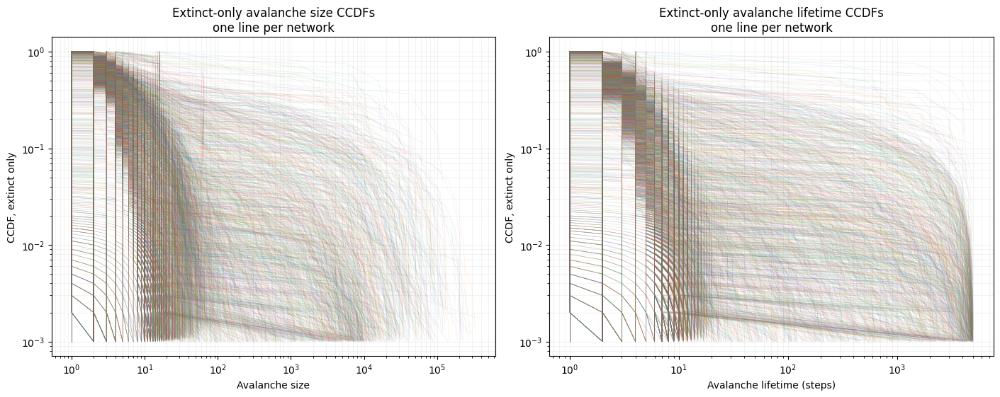

In [112]:
# ============================================================
# Plot EXTINCT-only avalanche CCDFs
# One line per network / parameter combination
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "avalanche_random_screen_ew_iw_phi_theta_eiratio_5000nets"
)

trials = pd.read_csv(OUTDIR / "avalanche_trials_random_screen.csv")
summary = pd.read_csv(OUTDIR / "network_summary_random_screen.csv")

trials_extinct = trials[trials["extinct"]].copy()

def empirical_ccdf(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]
    if values.size == 0:
        return np.array([]), np.array([])
    x = np.sort(values)
    y = 1.0 - ((np.arange(1, x.size + 1) - 1) / x.size)
    return x, y


fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)

for network_id, g in trials_extinct.groupby("network_id", sort=False):

    x_size, y_size = empirical_ccdf(g["size"])
    x_life, y_life = empirical_ccdf(g["lifetime_steps"])

    if x_size.size:
        axes[0].plot(
            x_size,
            y_size,
            linewidth=0.45,
            alpha=0.12,
        )

    if x_life.size:
        axes[1].plot(
            x_life,
            y_life,
            linewidth=0.45,
            alpha=0.12,
        )

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("CCDF, extinct only")
    ax.grid(True, which="both", alpha=0.15)

axes[0].set_xlabel("Avalanche size")
axes[0].set_title("Extinct-only avalanche size CCDFs\none line per network")

axes[1].set_xlabel("Avalanche lifetime (steps)")
axes[1].set_title("Extinct-only avalanche lifetime CCDFs\none line per network")

fig.savefig(
    OUTDIR / "extinct_only_network_avalanche_ccdfs_one_line_per_network.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

,network_id,n_extinct,frac_extinct,frac_persistent_at_cutoff,phi,e_w,i_w,theta,ei_ratio,max_size_extinct,...,xmin,ks_D,tail_frac,llr_pl_vs_exp,p_pl_vs_exp,pl_quality_score,pl_quality_score_norm,non_bimodality_score_norm,persistence_penalty,combined_score
0,2236,1000,1.000,0.000,3.453418,9.318336,15.216576,7.940248,0.1160,38516.0,...,4.0,0.042973,0.769000,18.784892,1.003894e-78,336.147874,1.000000,1.0,1.000,1.00000
1,571,1000,1.000,0.000,3.300521,12.148711,36.203115,10.113023,0.2650,35370.0,...,6.0,0.026010,0.641000,12.254859,1.582246e-34,301.997469,1.000000,1.0,1.000,1.00000
2,1971,1000,1.000,0.000,3.357130,15.439812,36.461469,12.470094,0.3555,6884.0,...,3.0,0.040470,0.886000,18.649421,1.276524e-77,408.273769,1.000000,1.0,1.000,1.00000
3,3746,996,0.996,0.004,3.677785,14.016053,16.409174,10.468188,0.1110,71145.0,...,4.0,0.053394,0.849398,23.319672,2.800355e-120,370.967922,1.000000,1.0,0.996,0.99940
4,2606,966,0.966,0.034,4.829084,12.715193,0.742350,4.956918,0.1385,13237.0,...,2.0,0.122141,1.000000,38.065856,0.000000e+00,311.651847,1.000000,1.0,0.966,0.99490
5,2202,978,0.978,0.022,4.677311,19.215779,30.476759,11.233228,0.1500,14452.0,...,2.0,0.127414,1.000000,38.153344,0.000000e+00,299.442014,0.991819,1.0,0.978,0.99261
6,173,950,0.950,0.050,3.150643,13.141327,49.301864,12.016102,0.2265,212327.0,...,2.0,0.034144,0.936842,43.975663,0.000000e+00,1206.567743,1.000000,1.0,0.950,0.99250
7,229,950,0.950,0.050,5.117570,14.275674,12.710564,5.859348,0.0575,16827.0,...,2.0,0.121869,1.000000,45.371773,0.000000e+00,372.297590,1.000000,1.0,0.950,0.99250
8,941,949,0.949,0.051,3.536540,12.252730,4.258082,8.878248,0.2820,85538.0,...,3.0,0.041838,0.864067,16.049954,5.720630e-58,331.466897,1.000000,1.0,0.949,0.99235
9,3629,938,0.938,0.062,2.572727,5.586598,22.532434,5.804689,0.2355,230262.0,...,1.0,0.070199,1.000000,41.638051,0.000000e+00,593.135221,1.000000,1.0,0.938,0.99070


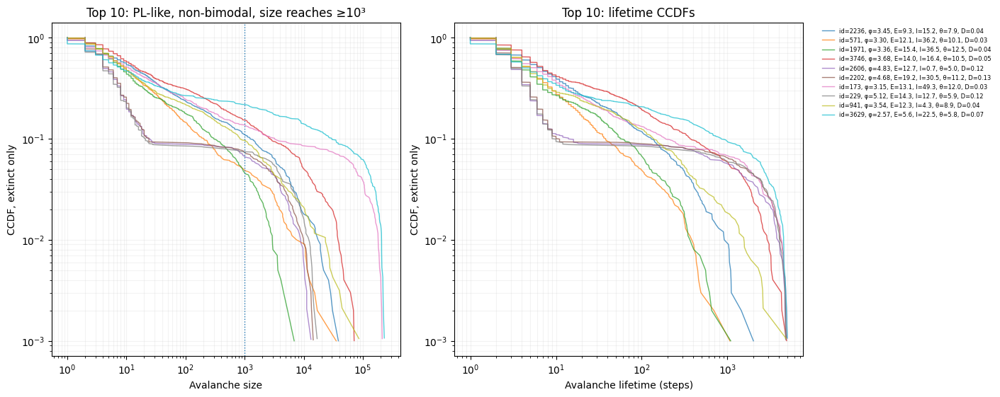

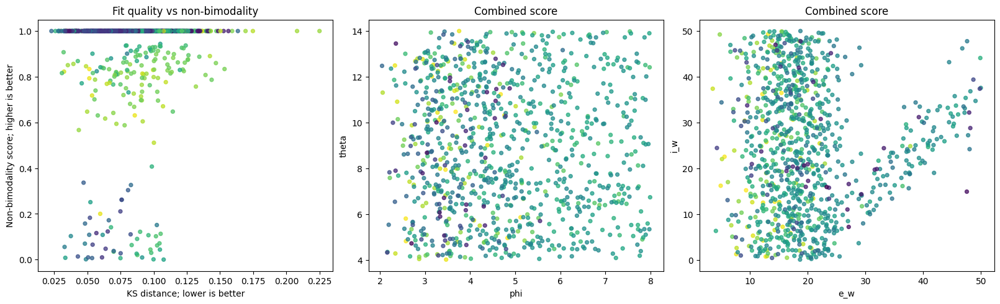

In [116]:
# ============================================================
# Rank networks by:
#   1. power-law fit quality
#   2. non-bimodality
#   3. extinct avalanche tail reaches >= 10^3
# Then plot top-ranked extinct avalanche CCDFs
# ============================================================

import io
import contextlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

try:
    import powerlaw
except ImportError:
    raise ImportError("Install with: pip install powerlaw")

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "avalanche_random_screen_ew_iw_phi_theta_eiratio_5000nets"
)

trials = pd.read_csv(OUTDIR / "avalanche_trials_random_screen.csv")
summary = pd.read_csv(OUTDIR / "network_summary_random_screen.csv")

TOP_N = 10
MIN_EXTINCT_EVENTS = 100
MIN_TAIL_MAX = 1e3


def empirical_ccdf(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]
    if values.size == 0:
        return np.array([]), np.array([])
    x = np.sort(values)
    y = 1.0 - ((np.arange(1, x.size + 1) - 1) / x.size)
    return x, y


def non_bimodality_score(values, n_bins=35):
    """
    Returns high values for smoother/unimodal log-size distributions.

    1.0 = no obvious second peak.
    0.0 = strong second peak comparable to main peak.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]

    if values.size < 50:
        return np.nan, np.nan

    logv = np.log10(values)
    hist, edges = np.histogram(logv, bins=n_bins)

    # light smoothing
    kernel = np.array([1, 2, 3, 2, 1], dtype=float)
    kernel /= kernel.sum()
    h = np.convolve(hist.astype(float), kernel, mode="same")

    peaks, props = find_peaks(h, prominence=max(2, 0.05 * np.max(h)))

    if len(peaks) <= 1:
        return 1.0, 0.0

    peak_heights = np.sort(h[peaks])[::-1]
    second_peak_ratio = float(peak_heights[1] / peak_heights[0])

    score = 1.0 - second_peak_ratio
    return float(score), second_peak_ratio


def fit_powerlaw_quality(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values >= 1)].astype(int)

    out = {
        "fit_ok": False,
        "alpha": np.nan,
        "xmin": np.nan,
        "ks_D": np.nan,
        "tail_frac": np.nan,
        "llr_pl_vs_exp": np.nan,
        "p_pl_vs_exp": np.nan,
        "pl_quality_score": np.nan,
    }

    if values.size < MIN_EXTINCT_EVENTS or np.unique(values).size < 5:
        return out

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            with contextlib.redirect_stdout(io.StringIO()):
                with contextlib.redirect_stderr(io.StringIO()):
                    fit = powerlaw.Fit(values, discrete=True, verbose=False)

        alpha = float(fit.power_law.alpha)
        xmin = float(fit.power_law.xmin)
        ks_D = float(fit.power_law.D)
        tail_frac = float(np.mean(values >= xmin))

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            with contextlib.redirect_stdout(io.StringIO()):
                with contextlib.redirect_stderr(io.StringIO()):
                    llr, p = fit.distribution_compare(
                        "power_law",
                        "exponential",
                        normalized_ratio=True,
                    )

        llr = float(llr)
        p = float(p)

        # Higher is better:
        # low KS, high tail fraction, positive PL-vs-exp evidence
        pl_quality_score = (
            (1.0 / (ks_D + 1e-6))
            * tail_frac
            * max(llr, 0.0)
            * (1.0 if p < 0.1 else 0.5)
        )

        out.update({
            "fit_ok": True,
            "alpha": alpha,
            "xmin": xmin,
            "ks_D": ks_D,
            "tail_frac": tail_frac,
            "llr_pl_vs_exp": llr,
            "p_pl_vs_exp": p,
            "pl_quality_score": float(pl_quality_score),
        })

    except Exception:
        pass

    return out


# ============================================================
# Rank networks using extinct avalanches only
# ============================================================

rows = []

for network_id, g_all in trials.groupby("network_id", sort=True):
    g = g_all[g_all["extinct"]].copy()

    row0 = summary.loc[summary["network_id"] == network_id]
    if len(row0) == 0:
        continue
    row0 = row0.iloc[0]

    values = g["size"].to_numpy(float)

    pl = fit_powerlaw_quality(values)
    non_bimodal, second_peak_ratio = non_bimodality_score(values)

    max_size = float(np.nanmax(values)) if len(values) else np.nan
    p99_size = float(np.nanpercentile(values, 99)) if len(values) else np.nan
    reaches_1e3 = bool(max_size >= MIN_TAIL_MAX)

    rows.append({
        "network_id": int(network_id),
        "n_extinct": int(len(g)),
        "frac_extinct": float(row0["frac_extinct"]),
        "frac_persistent_at_cutoff": float(row0["frac_persistent_at_cutoff"]),

        "phi": float(row0["phi"]),
        "e_w": float(row0["e_w"]),
        "i_w": float(row0["i_w"]),
        "theta": float(row0["theta"]),
        "ei_ratio": float(row0["ei_ratio"]),

        "max_size_extinct": max_size,
        "p99_size_extinct": p99_size,
        "reaches_1e3": reaches_1e3,

        "non_bimodality_score": non_bimodal,
        "second_peak_ratio": second_peak_ratio,

        **pl,
    })

rank_df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)

# Hard filters
rank_df = rank_df[
    (rank_df["fit_ok"])
    & (rank_df["n_extinct"] >= MIN_EXTINCT_EVENTS)
    & (rank_df["reaches_1e3"])
].copy()

# Normalize component scores
for col in ["pl_quality_score", "non_bimodality_score"]:
    x = rank_df[col].to_numpy(float)
    lo, hi = np.nanpercentile(x, [5, 95])
    rank_df[col + "_norm"] = np.clip((x - lo) / (hi - lo + 1e-12), 0, 1)

# Penalise mostly persistent networks
rank_df["persistence_penalty"] = 1.0 - rank_df["frac_persistent_at_cutoff"]

rank_df["combined_score"] = (
    0.50 * rank_df["pl_quality_score_norm"]
    + 0.35 * rank_df["non_bimodality_score_norm"]
    + 0.15 * rank_df["persistence_penalty"]
)

rank_df = rank_df.sort_values("combined_score", ascending=False).reset_index(drop=True)

rank_df.to_csv(
    OUTDIR / "ranked_networks_powerlaw_nonbimodal_tail1e3.csv",
    index=False,
)

display(rank_df.head(TOP_N))


# ============================================================
# Plot top-ranked extinct avalanche CCDFs
# ============================================================

top_ids = rank_df.head(TOP_N)["network_id"].to_numpy(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)

for network_id in top_ids:
    g = trials[
        (trials["network_id"] == network_id)
        & (trials["extinct"])
    ].copy()

    row = rank_df.loc[rank_df["network_id"] == network_id].iloc[0]

    label = (
        f"id={network_id}, "
        f"φ={row['phi']:.2f}, "
        f"E={row['e_w']:.1f}, "
        f"I={row['i_w']:.1f}, "
        f"θ={row['theta']:.1f}, "
        f"D={row['ks_D']:.2f}"
    )

    x_size, y_size = empirical_ccdf(g["size"])
    x_life, y_life = empirical_ccdf(g["lifetime_steps"])

    if x_size.size:
        axes[0].plot(x_size, y_size, linewidth=1.0, alpha=0.75)

    if x_life.size:
        axes[1].plot(x_life, y_life, linewidth=1.0, alpha=0.75, label=label)

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("CCDF, extinct only")
    ax.grid(True, which="both", alpha=0.15)

axes[0].axvline(1e3, linestyle=":", linewidth=1)
axes[0].set_xlabel("Avalanche size")
axes[0].set_title(f"Top {TOP_N}: PL-like, non-bimodal, size reaches ≥10³")

axes[1].set_xlabel("Avalanche lifetime (steps)")
axes[1].set_title(f"Top {TOP_N}: lifetime CCDFs")
axes[1].legend(frameon=False, fontsize=6, bbox_to_anchor=(1.04, 1), loc="upper left")

fig.savefig(
    OUTDIR / f"top{TOP_N}_ranked_PL_nonbimodal_tail1e3_extinct_ccdfs.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Diagnostic plots for ranking
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

axes[0].scatter(
    rank_df["ks_D"],
    rank_df["non_bimodality_score"],
    c=np.log10(rank_df["p99_size_extinct"].clip(lower=1)),
    s=18,
    alpha=0.75,
)
axes[0].set_xlabel("KS distance; lower is better")
axes[0].set_ylabel("Non-bimodality score; higher is better")
axes[0].set_title("Fit quality vs non-bimodality")

axes[1].scatter(
    rank_df["phi"],
    rank_df["theta"],
    c=rank_df["combined_score"],
    s=18,
    alpha=0.75,
)
axes[1].set_xlabel("phi")
axes[1].set_ylabel("theta")
axes[1].set_title("Combined score")

axes[2].scatter(
    rank_df["e_w"],
    rank_df["i_w"],
    c=rank_df["combined_score"],
    s=18,
    alpha=0.75,
)
axes[2].set_xlabel("e_w")
axes[2].set_ylabel("i_w")
axes[2].set_title("Combined score")

fig.savefig(
    OUTDIR / "ranked_PL_nonbimodal_tail1e3_diagnostics.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

,network_id,n_extinct,frac_extinct,frac_persistent_at_cutoff,phi,e_w,i_w,theta,ei_ratio,max_size_extinct,p99_size_extinct,reaches_1e3,ccdf_r2_from_1,ccdf_slope_from_1,ccdf_intercept_from_1,ccdf_rmse_from_1,combined_score
0,4445,1000,1.000,0.000,4.045201,14.437610,1.086471,11.326253,0.2640,8149.0,1542.51,True,0.987219,-0.680063,0.182466,0.048360,1.025129
1,1084,1000,1.000,0.000,4.201860,9.733076,35.361688,6.720912,0.2305,3274.0,562.28,True,0.985341,-0.788209,0.204392,0.051792,1.022393
2,2380,997,0.997,0.003,4.387288,14.365683,13.180011,10.433395,0.1365,40969.0,10112.04,True,0.981709,-0.542750,0.101971,0.057851,1.017096
3,4385,996,0.996,0.004,3.287371,9.905330,17.069279,7.093295,0.3525,67112.0,16627.15,True,0.981621,-0.482541,0.125441,0.057989,1.016924
4,177,1000,1.000,0.000,4.321213,11.460362,5.866009,8.278144,0.0680,9873.0,3057.74,True,0.979041,-0.546004,0.134546,0.061929,1.013559
5,3326,1000,1.000,0.000,4.437436,13.732596,4.928209,10.361173,0.0675,12223.0,1363.41,True,0.978145,-0.597654,0.159541,0.063239,1.012335
6,2063,999,0.999,0.001,4.244398,13.127199,30.661767,8.587206,0.1735,27005.0,1882.22,True,0.977637,-0.613119,0.164559,0.063968,1.011595
7,571,1000,1.000,0.000,3.300521,12.148711,36.203115,10.113023,0.2650,35370.0,6323.23,True,0.977534,-0.508594,0.164454,0.064116,1.011505
8,265,1000,1.000,0.000,4.544247,11.383071,35.148033,7.826843,0.0990,3974.0,764.19,True,0.976178,-0.685158,0.179913,0.066023,1.009673
9,4369,815,0.815,0.185,2.510159,8.529102,10.319334,8.990301,0.1780,286740.0,13442.98,True,0.982631,-0.427639,-0.025454,0.056235,1.009323


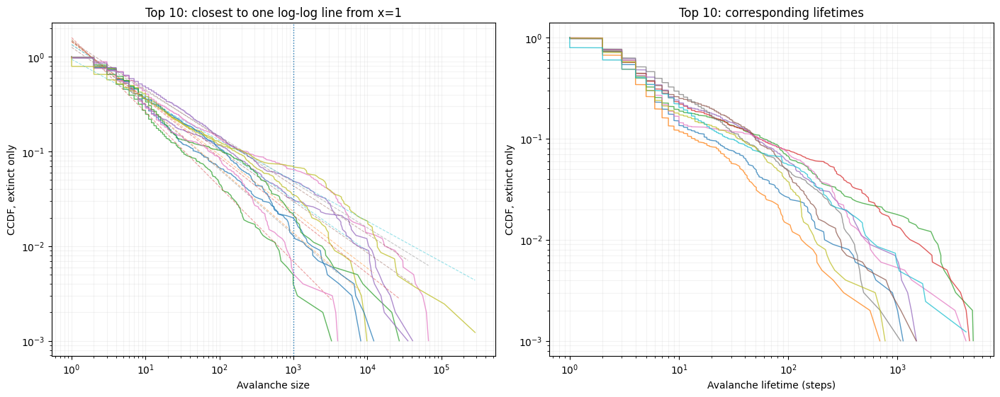

In [122]:
from scipy.stats import linregress

def ccdf_straight_line_score(values, min_points=20):
    x, y = empirical_ccdf(values)

    keep = np.isfinite(x) & np.isfinite(y) & (x >= 1) & (y > 0)
    x = x[keep]
    y = y[keep]

    if x.size < min_points or np.unique(x).size < 5:
        return {
            "ccdf_r2_from_1": np.nan,
            "ccdf_slope_from_1": np.nan,
            "ccdf_intercept_from_1": np.nan,
            "ccdf_rmse_from_1": np.nan,
        }

    lx = np.log10(x)
    ly = np.log10(y)

    fit = linregress(lx, ly)
    yhat = fit.intercept + fit.slope * lx

    resid = ly - yhat
    ss_res = np.sum(resid**2)
    ss_tot = np.sum((ly - np.mean(ly))**2)

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    rmse = np.sqrt(np.mean(resid**2))

    return {
        "ccdf_r2_from_1": float(r2),
        "ccdf_slope_from_1": float(fit.slope),
        "ccdf_intercept_from_1": float(fit.intercept),
        "ccdf_rmse_from_1": float(rmse),
    }


rows = []

for network_id, g_all in trials.groupby("network_id", sort=True):
    g = g_all[g_all["extinct"]].copy()
    row0 = summary.loc[summary["network_id"] == network_id]

    if len(row0) == 0:
        continue

    row0 = row0.iloc[0]
    values = g["size"].to_numpy(float)

    straight = ccdf_straight_line_score(values)

    max_size = float(np.nanmax(values)) if len(values) else np.nan
    p99_size = float(np.nanpercentile(values, 99)) if len(values) else np.nan

    rows.append({
        "network_id": int(network_id),
        "n_extinct": int(len(g)),
        "frac_extinct": float(row0["frac_extinct"]),
        "frac_persistent_at_cutoff": float(row0["frac_persistent_at_cutoff"]),
        "phi": float(row0["phi"]),
        "e_w": float(row0["e_w"]),
        "i_w": float(row0["i_w"]),
        "theta": float(row0["theta"]),
        "ei_ratio": float(row0["ei_ratio"]),
        "max_size_extinct": max_size,
        "p99_size_extinct": p99_size,
        "reaches_1e3": bool(max_size >= 1e3),
        **straight,
    })

rank_df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)

rank_df = rank_df[
    (rank_df["n_extinct"] >= 100)
    & (rank_df["reaches_1e3"])
    & np.isfinite(rank_df["ccdf_r2_from_1"])
].copy()

rank_df["combined_score"] = (
    rank_df["ccdf_r2_from_1"]
    - 0.25 * rank_df["ccdf_rmse_from_1"]
    + 0.05 * (1.0 - rank_df["frac_persistent_at_cutoff"])
)

rank_df = rank_df.sort_values("combined_score", ascending=False).reset_index(drop=True)

display(rank_df.head(50))

rank_df.to_csv(
    OUTDIR / "ranked_networks_single_line_ccdf_from_x1_tail1e3.csv",
    index=False,
)


TOP_N = 10
top_ids = rank_df.head(TOP_N)["network_id"].to_numpy(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)

for network_id in top_ids:
    g = trials[
        (trials["network_id"] == network_id)
        & (trials["extinct"])
    ]

    row = rank_df.loc[rank_df["network_id"] == network_id].iloc[0]

    x_size, y_size = empirical_ccdf(g["size"])
    x_life, y_life = empirical_ccdf(g["lifetime_steps"])

    if x_size.size:
        axes[0].plot(x_size, y_size, linewidth=1.0, alpha=0.75)

        lx = np.log10(x_size)
        fit_y = 10 ** (
            row["ccdf_intercept_from_1"]
            + row["ccdf_slope_from_1"] * lx
        )
        axes[0].plot(x_size, fit_y, linestyle="--", linewidth=0.8, alpha=0.45)

    if x_life.size:
        axes[1].plot(x_life, y_life, linewidth=1.0, alpha=0.75)

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("CCDF, extinct only")
    ax.grid(True, which="both", alpha=0.15)

axes[0].axvline(1e3, linestyle=":", linewidth=1)
axes[0].set_xlabel("Avalanche size")
axes[0].set_title(f"Top {TOP_N}: closest to one log-log line from x=1")

axes[1].set_xlabel("Avalanche lifetime (steps)")
axes[1].set_title(f"Top {TOP_N}: corresponding lifetimes")

fig.savefig(
    OUTDIR / f"top{TOP_N}_single_line_ccdf_from_x1_extinct.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

,network_id,n_extinct,phi,e_w,i_w,theta,ei_ratio,frac_extinct,frac_persistent_at_cutoff,max_size_extinct,...,alpha,xmin,ks_D,tail_frac,llr_pl_vs_exp,p_pl_vs_exp,pl_quality_score,pl_quality_score_norm,non_bimodality_score_norm,combined_score
0,2236,1000,3.453418,9.318336,15.216576,7.940248,0.1160,1.000,0.000,38516.0,...,1.371702,4.0,0.042973,0.769000,18.784892,1.003894e-78,336.147874,1.000000,1.000000,1.000000
1,571,1000,3.300521,12.148711,36.203115,10.113023,0.2650,1.000,0.000,35370.0,...,1.515632,6.0,0.026010,0.641000,12.254859,1.582246e-34,301.997469,1.000000,1.000000,1.000000
2,1971,1000,3.357130,15.439812,36.461469,12.470094,0.3555,1.000,0.000,6884.0,...,1.487073,3.0,0.040470,0.886000,18.649421,1.276524e-77,408.273769,1.000000,1.000000,1.000000
3,3746,996,3.677785,14.016053,16.409174,10.468188,0.1110,0.996,0.004,71145.0,...,1.342683,4.0,0.053394,0.849398,23.319672,2.800355e-120,370.967922,1.000000,1.000000,0.999400
4,2606,966,4.829084,12.715193,0.742350,4.956918,0.1385,0.966,0.034,13237.0,...,1.598901,2.0,0.122141,1.000000,38.065856,0.000000e+00,311.651847,1.000000,1.000000,0.994900
5,2202,978,4.677311,19.215779,30.476759,11.233228,0.1500,0.978,0.022,14452.0,...,1.581173,2.0,0.127414,1.000000,38.153344,0.000000e+00,299.442014,0.991819,1.000000,0.992610
6,173,950,3.150643,13.141327,49.301864,12.016102,0.2265,0.950,0.050,212327.0,...,1.311412,2.0,0.034144,0.936842,43.975663,0.000000e+00,1206.567743,1.000000,1.000000,0.992500
7,229,950,5.117570,14.275674,12.710564,5.859348,0.0575,0.950,0.050,16827.0,...,1.604888,2.0,0.121869,1.000000,45.371773,0.000000e+00,372.297590,1.000000,1.000000,0.992500
8,941,949,3.536540,12.252730,4.258082,8.878248,0.2820,0.949,0.051,85538.0,...,1.405204,3.0,0.041838,0.864067,16.049954,5.720630e-58,331.466897,1.000000,1.000000,0.992350
9,3629,938,2.572727,5.586598,22.532434,5.804689,0.2355,0.938,0.062,230262.0,...,1.232806,1.0,0.070199,1.000000,41.638051,0.000000e+00,593.135221,1.000000,1.000000,0.990700


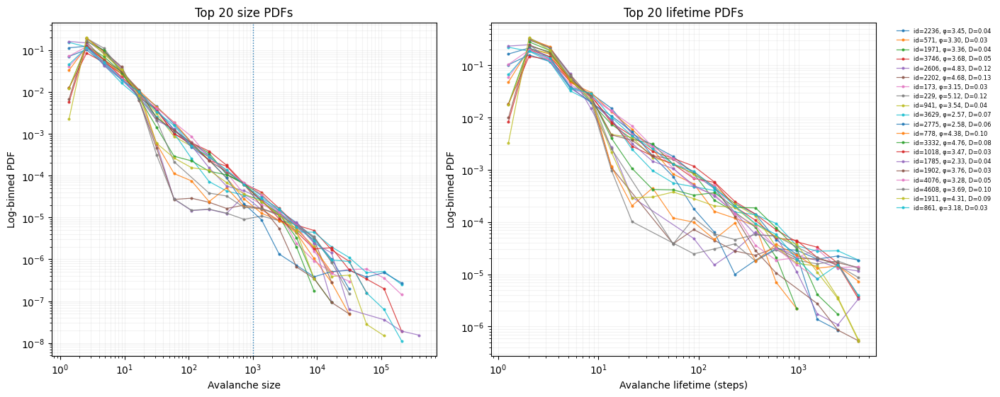

In [165]:
import io, contextlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import powerlaw

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/avalanche_random_screen_ew_iw_phi_theta_eiratio_5000nets")
trials = pd.read_csv(OUTDIR / "avalanche_trials_random_screen.csv")
summary = pd.read_csv(OUTDIR / "network_summary_random_screen.csv")

TOP_N = 20
MIN_EXTINCT_EVENTS = 100
MIN_TAIL_MAX = 1e3

def logbin_pdf(x, bins=40, xmin=1, xmax=None):
    x = np.asarray(x, float)
    x = x[np.isfinite(x) & (x > 0)]
    if len(x) == 0: return np.array([]), np.array([])
    xmax = np.nanmax(x) if xmax is None else xmax
    edges = np.logspace(np.log10(xmin), np.log10(xmax), bins + 1)
    counts, edges = np.histogram(x, bins=edges)
    centres = np.sqrt(edges[:-1] * edges[1:])
    pdf = counts / (counts.sum() * np.diff(edges))
    keep = counts > 0
    return centres[keep], pdf[keep]

def non_bimodality_score(x, bins=35):
    x = np.asarray(x, float)
    x = x[np.isfinite(x) & (x > 0)]
    if len(x) < 50: return np.nan
    h, _ = np.histogram(np.log10(x), bins=bins)
    k = np.array([1, 2, 3, 2, 1], float); k /= k.sum()
    h = np.convolve(h.astype(float), k, mode="same")
    peaks, _ = find_peaks(h, prominence=max(2, 0.05 * h.max()))
    if len(peaks) <= 1: return 1.0
    heights = np.sort(h[peaks])[::-1]
    return float(1.0 - heights[1] / heights[0])

def pl_quality(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x) & (x >= 1)].astype(int)
    out = dict(fit_ok=False, alpha=np.nan, xmin=np.nan, ks_D=np.nan,
               tail_frac=np.nan, llr_pl_vs_exp=np.nan, p_pl_vs_exp=np.nan,
               pl_quality_score=np.nan)
    if len(x) < MIN_EXTINCT_EVENTS or np.unique(x).size < 5: return out
    try:
        with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            warnings.simplefilter("ignore")
            fit = powerlaw.Fit(x, discrete=True, verbose=False)
            llr, p = fit.distribution_compare("power_law", "exponential", normalized_ratio=True)
        ks = float(fit.power_law.D)
        tail = float(np.mean(x >= fit.power_law.xmin))
        llr = float(llr); p = float(p)
        score = (1 / (ks + 1e-6)) * tail * max(llr, 0) * (1 if p < 0.1 else 0.5)
        out.update(fit_ok=True, alpha=float(fit.power_law.alpha), xmin=float(fit.power_law.xmin),
                   ks_D=ks, tail_frac=tail, llr_pl_vs_exp=llr,
                   p_pl_vs_exp=float(p), pl_quality_score=float(score))
    except Exception:
        pass
    return out

rows = []
for nid, g0 in trials.groupby("network_id"):
    g = g0[g0["extinct"]]
    srow = summary.loc[summary["network_id"] == nid]
    if len(srow) == 0: continue
    srow = srow.iloc[0]
    vals = g["size"].to_numpy(float)
    if len(vals) == 0: continue
    rows.append({
        "network_id": int(nid),
        "n_extinct": len(g),
        "phi": float(srow["phi"]),
        "e_w": float(srow["e_w"]),
        "i_w": float(srow["i_w"]),
        "theta": float(srow["theta"]),
        "ei_ratio": float(srow["ei_ratio"]),
        "frac_extinct": float(srow["frac_extinct"]),
        "frac_persistent_at_cutoff": float(srow["frac_persistent_at_cutoff"]),
        "max_size_extinct": float(np.nanmax(vals)),
        "p99_size_extinct": float(np.nanpercentile(vals, 99)),
        "non_bimodality_score": non_bimodality_score(vals),
        **pl_quality(vals),
    })

rank_df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
rank_df = rank_df[
    rank_df["fit_ok"]
    & (rank_df["n_extinct"] >= MIN_EXTINCT_EVENTS)
    & (rank_df["max_size_extinct"] >= MIN_TAIL_MAX)
].copy()

for c in ["pl_quality_score", "non_bimodality_score"]:
    lo, hi = np.nanpercentile(rank_df[c], [5, 95])
    rank_df[c + "_norm"] = np.clip((rank_df[c] - lo) / (hi - lo + 1e-12), 0, 1)

rank_df["combined_score"] = (
    0.50 * rank_df["pl_quality_score_norm"]
    + 0.35 * rank_df["non_bimodality_score_norm"]
    + 0.15 * (1 - rank_df["frac_persistent_at_cutoff"])
)

rank_df = rank_df.sort_values("combined_score", ascending=False).reset_index(drop=True)
display(rank_df.head(TOP_N))
rank_df.to_csv(OUTDIR / "ranked_networks_top_logpdf.csv", index=False)

top_ids = rank_df.head(TOP_N)["network_id"].to_numpy(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)

for nid in top_ids:
    g = trials[(trials["network_id"] == nid) & trials["extinct"]]
    row = rank_df.loc[rank_df["network_id"] == nid].iloc[0]
    label = f"id={nid}, φ={row.phi:.2f}, D={row.ks_D:.2f}"

    xs, ys = logbin_pdf(g["size"], bins=22, xmin=1, xmax=1e6)
    xl, yl = logbin_pdf(g["lifetime_steps"], bins=18, xmin=1, xmax=5e3)

    if len(xs): axes[0].plot(xs, ys, marker="o", ms=2, lw=0.9, alpha=0.8)
    if len(xl): axes[1].plot(xl, yl, marker="o", ms=2, lw=0.9, alpha=0.8, label=label)

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("Log-binned PDF")
    ax.grid(True, which="both", alpha=0.15)

axes[0].axvline(1e3, linestyle=":", linewidth=1)
axes[0].set_xlabel("Avalanche size")
axes[0].set_title(f"Top {TOP_N} size PDFs")

axes[1].set_xlabel("Avalanche lifetime (steps)")
axes[1].set_title(f"Top {TOP_N} lifetime PDFs")
axes[1].legend(frameon=False, fontsize=6, bbox_to_anchor=(1.04, 1), loc="upper left")

fig.savefig(OUTDIR / f"top{TOP_N}_ranked_extinct_logpdfs.png", dpi=300, bbox_inches="tight")
plt.show()

effective_E_input vs CCDF R2 from x=1:
  Pearson r = 0.2170, p = 8.44e-12
  Spearman rho = 0.2411, p = 2.72e-14

effective_I_input vs CCDF R2 from x=1:
  Pearson r = 0.1748, p = 4.28e-08
  Spearman rho = 0.1619, p = 3.98e-07

effective_net_input vs CCDF R2 from x=1:
  Pearson r = 0.0937, p = 0.00349
  Spearman rho = 0.1077, p = 0.000776

effective_total_abs_input vs CCDF R2 from x=1:
  Pearson r = 0.2583, p = 2.98e-16
  Spearman rho = 0.2894, p = 3.63e-20

effective_EI_ratio vs CCDF R2 from x=1:
  Pearson r = -0.0033, p = 0.918
  Spearman rho = -0.0323, p = 0.314

effective_net_over_theta vs CCDF R2 from x=1:
  Pearson r = 0.0802, p = 0.0125
  Spearman rho = 0.1081, p = 0.000743

effective_abs_over_theta vs CCDF R2 from x=1:
  Pearson r = 0.2116, p = 2.78e-11
  Spearman rho = 0.2557, p = 6.01e-16

theta vs CCDF R2 from x=1:
  Pearson r = -0.0112, p = 0.728
  Spearman rho = -0.0051, p = 0.874



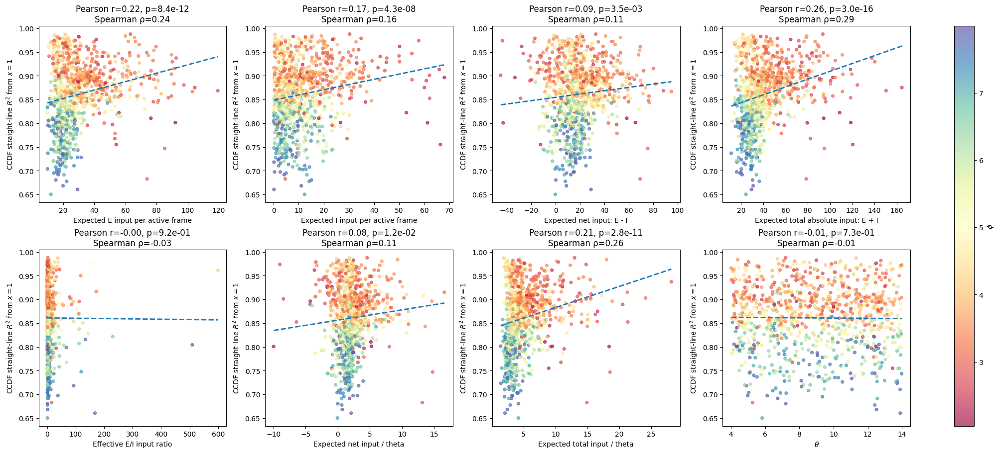

In [127]:
# ============================================================
# Correlate CCDF straight-line fit from x=1 with:
#   1. effective recurrent input balance
#   2. theta
#
# Uses extinct avalanches only.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr, spearmanr
from pathlib import Path

OUTDIR = Path(
    "/home/dburrows/DATA/BLNDEV-WILDTYPE/"
    "avalanche_random_screen_ew_iw_phi_theta_eiratio_5000nets"
)

trials = pd.read_csv(OUTDIR / "avalanche_trials_random_screen.csv")
summary = pd.read_csv(OUTDIR / "network_summary_random_screen.csv")


def empirical_ccdf(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0)]
    if values.size == 0:
        return np.array([]), np.array([])
    x = np.sort(values)
    y = 1.0 - ((np.arange(1, x.size + 1) - 1) / x.size)
    return x, y


def ccdf_straight_line_score(values, min_points=20):
    x, y = empirical_ccdf(values)

    keep = np.isfinite(x) & np.isfinite(y) & (x >= 1) & (y > 0)
    x = x[keep]
    y = y[keep]

    if x.size < min_points or np.unique(x).size < 5:
        return {
            "ccdf_r2_from_1": np.nan,
            "ccdf_slope_from_1": np.nan,
            "ccdf_intercept_from_1": np.nan,
            "ccdf_rmse_from_1": np.nan,
            "max_size_extinct": np.nan,
        }

    lx = np.log10(x)
    ly = np.log10(y)

    fit = linregress(lx, ly)
    yhat = fit.intercept + fit.slope * lx
    resid = ly - yhat

    ss_res = float(np.sum(resid**2))
    ss_tot = float(np.sum((ly - np.mean(ly))**2))

    return {
        "ccdf_r2_from_1": float(1 - ss_res / ss_tot) if ss_tot > 0 else np.nan,
        "ccdf_slope_from_1": float(fit.slope),
        "ccdf_intercept_from_1": float(fit.intercept),
        "ccdf_rmse_from_1": float(np.sqrt(np.mean(resid**2))),
        "max_size_extinct": float(np.max(x)),
    }


rows = []

for network_id, g_all in trials.groupby("network_id", sort=True):
    g = g_all[g_all["extinct"]].copy()

    row0 = summary.loc[summary["network_id"] == network_id]
    if len(row0) == 0:
        continue
    row0 = row0.iloc[0]

    ccdf_fit = ccdf_straight_line_score(g["size"].to_numpy(float))

    ei_ratio = float(row0["ei_ratio"])
    frac_e = 1.0 - ei_ratio
    frac_i = ei_ratio

    e_w = float(row0["e_w"])
    i_w = float(row0["i_w"])

    mean_out_degree = float(row0["mean_out_degree"])

    expected_e_degree = mean_out_degree * frac_e
    expected_i_degree = mean_out_degree * frac_i

    effective_E_input = e_w * expected_e_degree
    effective_I_input = i_w * expected_i_degree

    effective_net_input = effective_E_input - effective_I_input
    effective_total_abs_input = effective_E_input + effective_I_input

    effective_EI_ratio = effective_E_input / (effective_I_input + 1e-12)
    effective_net_over_theta = effective_net_input / (float(row0["theta"]) + 1e-12)
    effective_abs_over_theta = effective_total_abs_input / (float(row0["theta"]) + 1e-12)

    rows.append({
        "network_id": int(network_id),
        "n_extinct": int(len(g)),
        "frac_extinct": float(row0["frac_extinct"]),
        "frac_persistent_at_cutoff": float(row0["frac_persistent_at_cutoff"]),

        "phi": float(row0["phi"]),
        "theta": float(row0["theta"]),
        "e_w": e_w,
        "i_w": i_w,
        "ei_ratio": ei_ratio,
        "frac_e": frac_e,
        "frac_i": frac_i,
        "mean_out_degree": mean_out_degree,

        "expected_e_degree": expected_e_degree,
        "expected_i_degree": expected_i_degree,

        "effective_E_input": effective_E_input,
        "effective_I_input": effective_I_input,
        "effective_net_input": effective_net_input,
        "effective_total_abs_input": effective_total_abs_input,
        "effective_EI_ratio": effective_EI_ratio,
        "effective_net_over_theta": effective_net_over_theta,
        "effective_abs_over_theta": effective_abs_over_theta,

        **ccdf_fit,
    })

linearity_df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
linearity_df["reaches_1e3"] = linearity_df["max_size_extinct"] >= 1e3

linearity_df.to_csv(
    OUTDIR / "ccdf_linearity_vs_effective_input_by_network.csv",
    index=False,
)


plot_df = linearity_df[
    np.isfinite(linearity_df["ccdf_r2_from_1"])
    & (linearity_df["n_extinct"] >= 100)
    & (linearity_df["reaches_1e3"])
].copy()

x_specs = [
    ("effective_E_input", "Expected E input per active frame"),
    ("effective_I_input", "Expected I input per active frame"),
    ("effective_net_input", "Expected net input: E - I"),
    ("effective_total_abs_input", "Expected total absolute input: E + I"),
    ("effective_EI_ratio", "Effective E/I input ratio"),
    ("effective_net_over_theta", "Expected net input / theta"),
    ("effective_abs_over_theta", "Expected total input / theta"),
    ("theta", r"$\theta$"),
]

for xcol, label in x_specs:
    pear_r, pear_p = pearsonr(plot_df[xcol], plot_df["ccdf_r2_from_1"])
    spear_r, spear_p = spearmanr(plot_df[xcol], plot_df["ccdf_r2_from_1"])

    print(
        f"{xcol} vs CCDF R2 from x=1:\n"
        f"  Pearson r = {pear_r:.4f}, p = {pear_p:.3g}\n"
        f"  Spearman rho = {spear_r:.4f}, p = {spear_p:.3g}\n"
    )


# ============================================================
# Scatter plots
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(20, 9), constrained_layout=True)

for ax, (xcol, xlabel) in zip(axes.ravel(), x_specs):
    x = plot_df[xcol].to_numpy(float)
    y = plot_df["ccdf_r2_from_1"].to_numpy(float)

    sc = ax.scatter(
        x,
        y,
        c=plot_df["phi"],
        cmap="Spectral",
        s=18,
        alpha=0.65,
    )
    
    if np.isfinite(x).sum() > 3 and np.unique(x[np.isfinite(x)]).size > 2:
        fit = linregress(x, y)
        xx = np.linspace(np.nanmin(x), np.nanmax(x), 200)
        yy = fit.intercept + fit.slope * xx
        ax.plot(xx, yy, linestyle="--", linewidth=2)

    pear_r, pear_p = pearsonr(x, y)
    spear_r, spear_p = spearmanr(x, y)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"CCDF straight-line $R^2$ from $x=1$")
    ax.set_title(
        f"Pearson r={pear_r:.2f}, p={pear_p:.1e}\n"
        f"Spearman ρ={spear_r:.2f}"
    )

fig.colorbar(sc, ax=axes.ravel().tolist(), label=r"$\phi$")
fig.savefig(
    OUTDIR / "ccdf_linearity_from_x1_vs_effective_input_metrics.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

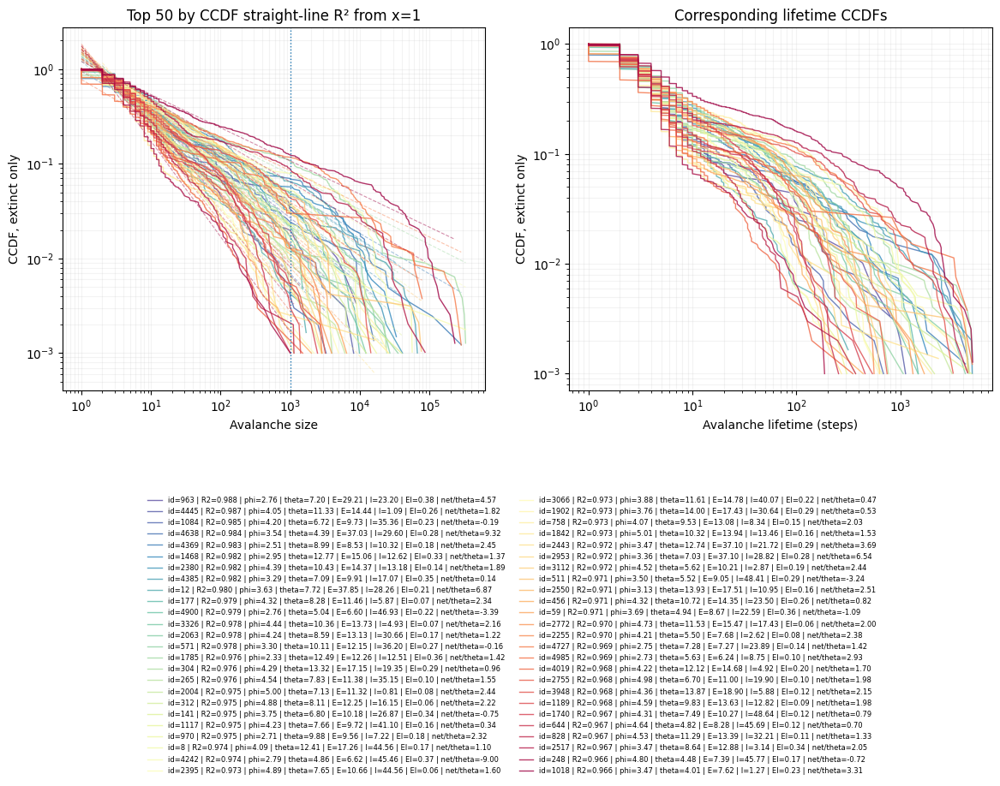

In [130]:
# ============================================================
# Plot top 50 by CCDF R2, with parameter legend below plot
# Does not change figsize / plot size
# ============================================================

TOP_N = 50
rank_metric = "ccdf_r2_from_1"

top_df = (
    linearity_df[
        np.isfinite(linearity_df[rank_metric])
        & (linearity_df["n_extinct"] >= 100)
        & (linearity_df["reaches_1e3"])
    ]
    .sort_values(rank_metric, ascending=False)
    .head(TOP_N)
    .copy()
)

top_ids = top_df["network_id"].to_numpy(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=False)

cmap = plt.get_cmap("Spectral_r")
colors = {
    network_id: cmap(i / max(len(top_ids) - 1, 1))
    for i, network_id in enumerate(top_ids)
}

legend_handles = []
legend_labels = []

for network_id in top_ids:
    g = trials[
        (trials["network_id"] == network_id)
        & (trials["extinct"])
    ].copy()

    row = top_df.loc[top_df["network_id"] == network_id].iloc[0]
    color = colors[network_id]

    x_size, y_size = empirical_ccdf(g["size"])
    x_life, y_life = empirical_ccdf(g["lifetime_steps"])

    label = (
        f"id={int(network_id)} | "
        f"R2={row[rank_metric]:.3f} | "
        f"phi={row['phi']:.2f} | "
        f"theta={row['theta']:.2f} | "
        f"E={row['e_w']:.2f} | "
        f"I={row['i_w']:.2f} | "
        f"EI={row['ei_ratio']:.2f} | "
        f"net/theta={row['effective_net_over_theta']:.2f}"
    )

    if x_size.size:
        line, = axes[0].plot(
            x_size,
            y_size,
            linewidth=1.0,
            alpha=0.8,
            color=color,
        )

        fit_y = 10 ** (
            row["ccdf_intercept_from_1"]
            + row["ccdf_slope_from_1"] * np.log10(x_size)
        )

        axes[0].plot(
            x_size,
            fit_y,
            linestyle="--",
            linewidth=0.8,
            alpha=0.45,
            color=color,
        )

        legend_handles.append(line)
        legend_labels.append(label)

    if x_life.size:
        axes[1].plot(
            x_life,
            y_life,
            linewidth=1.0,
            alpha=0.8,
            color=color,
        )

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("CCDF, extinct only")
    ax.grid(True, which="both", alpha=0.15)

axes[0].axvline(1e3, linestyle=":", linewidth=1)
axes[0].set_xlabel("Avalanche size")
axes[0].set_title(f"Top {TOP_N} by CCDF straight-line R² from x=1")

axes[1].set_xlabel("Avalanche lifetime (steps)")
axes[1].set_title("Corresponding lifetime CCDFs")

fig.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.72),
    ncol=2,
    frameon=False,
    fontsize=6,
)

fig.savefig(
    OUTDIR / f"top{TOP_N}_by_ccdf_r2_from_x1_extinct_ccdfs_with_param_legend.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Loaded:
  ICG rows: 5625
  seed exponent rows: 625
  condition rows: 120
Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_heatmap_MV_alpha.png


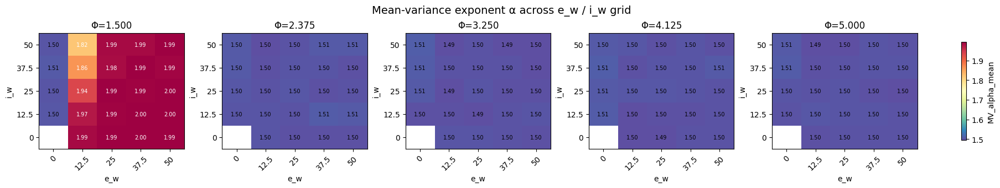

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_heatmap_TAU_beta.png


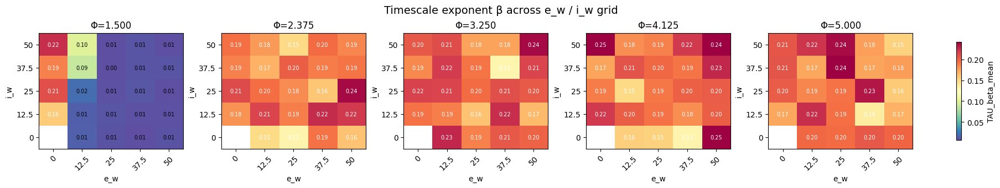

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_heatmap_KURT_gamma.png


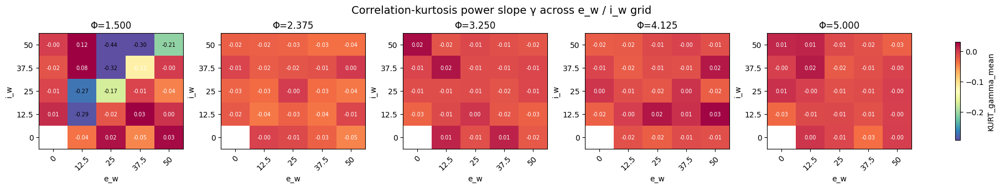

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_heatmap_score.png


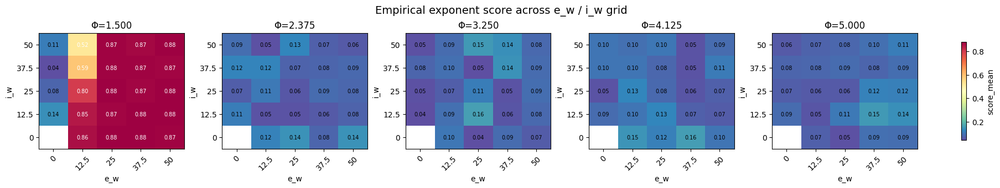

Saved: /home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_heatmap_mean_rate.png


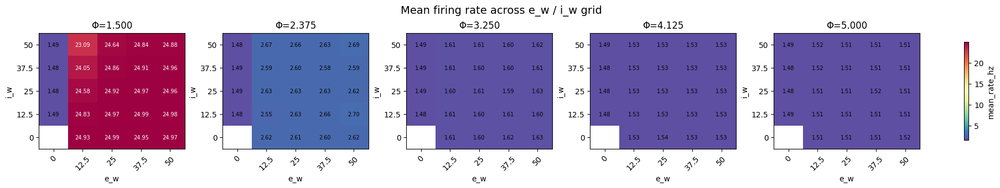

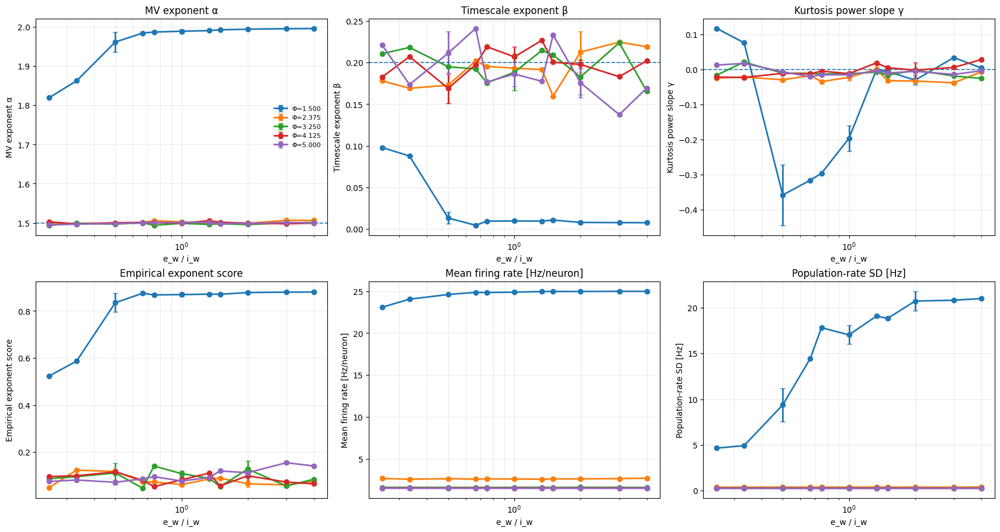

Saved:
/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_slopes_vs_ew_iw_ratio_by_phi.png


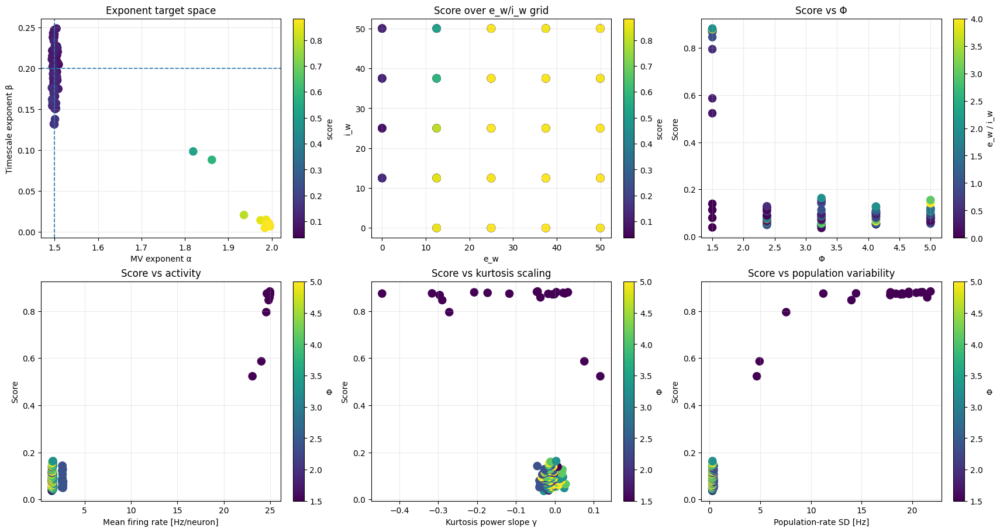

Saved:
/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20/grid_scatter_summary.png

Top 30 parameter sets:
  phi  e_w  i_w  ew_iw_ratio  MV_alpha_mean  TAU_beta_mean  KURT_gamma_mean  score_mean  MV_r2_mean  TAU_r2_mean  KURT_r2_mean  mean_rate_hz  pop_rate_std_hz  n
3.250  0.0 12.5     0.000000       1.498041       0.193085        -0.028125    0.036132    0.999572     0.966662      0.366222       1.48371         0.274865  5
1.500  0.0 37.5     0.000000       1.505716       0.187121        -0.015769    0.038359    0.999702     0.947210      0.208016       1.48084         0.266057  5
3.250 25.0  0.0          inf       1.501842       0.187023        -0.013996    0.042273    0.999698     0.956516      0.301580       1.60405         0.282567  5
3.250 25.0 37.5     0.666667       1.500172       0.192395        -0.011482    0.046034    0.999672     0.977795      0.215658       1.60420         0.282765  5
5.000 25.0  0.0          inf       1.499764       0.195832        -0.

In [125]:
# ============================================================
# View Phi × e_w × i_w quick sweep outputs
# One-block plotting script
#
# Reads:
#   grid_icg_rows.csv
#   grid_seed_exponents.csv
#   grid_summary.csv
#
# Makes:
#   heatmaps of MV alpha, tau beta, kurtosis gamma, score, activity
#   line plots vs e_w/i_w ratio
#   ranked table of best parameter sets
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. Load saved outputs
# ============================================================

OUTDIR = Path("/home/dburrows/DATA/BLNDEV-WILDTYPE/phi_ew_iw_quick_5x5x5_5seeds_mp20")

df_grid = pd.read_csv(OUTDIR / "grid_icg_rows.csv")
df_grid_exp = pd.read_csv(OUTDIR / "grid_seed_exponents.csv")
grid_summary = pd.read_csv(OUTDIR / "grid_summary.csv")

TARGET_MV = 1.50
TARGET_TAU = 0.20

d = grid_summary.copy()

print("Loaded:")
print("  ICG rows:", len(df_grid))
print("  seed exponent rows:", len(df_grid_exp))
print("  condition rows:", len(grid_summary))


# ============================================================
# 1. Helpers
# ============================================================

def plot_metric_heatmaps(
    df,
    metric,
    title,
    cmap="Spectral_r",
    save_name=None,
    annotate=True,
):
    phis = sorted(df["phi"].unique())
    n_phi = len(phis)

    ncols = min(5, n_phi)
    nrows = int(np.ceil(n_phi / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(3.6 * ncols, 3.3 * nrows),
        constrained_layout=True,
        squeeze=False,
    )

    vals = df[metric].replace([np.inf, -np.inf], np.nan)
    vmin = np.nanpercentile(vals, 2)
    vmax = np.nanpercentile(vals, 98)

    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        vmin = np.nanmin(vals)
        vmax = np.nanmax(vals)

    for ax, phi in zip(axes.ravel(), phis):
        g = df[df["phi"] == phi].copy()

        mat = (
            g.pivot(index="i_w", columns="e_w", values=metric)
            .sort_index(ascending=True)
            .sort_index(axis=1, ascending=True)
        )

        im = ax.imshow(
            mat.to_numpy(float),
            origin="lower",
            aspect="auto",
            vmin=vmin,
            vmax=vmax,
            cmap=cmap,
        )

        ax.set_xticks(np.arange(mat.shape[1]))
        ax.set_xticklabels([f"{x:g}" for x in mat.columns], rotation=45)

        ax.set_yticks(np.arange(mat.shape[0]))
        ax.set_yticklabels([f"{y:g}" for y in mat.index])

        ax.set_xlabel("e_w")
        ax.set_ylabel("i_w")
        ax.set_title(f"Φ={phi:.3f}")

        if annotate:
            mid = (vmin + vmax) / 2
            for yi in range(mat.shape[0]):
                for xi in range(mat.shape[1]):
                    val = mat.iloc[yi, xi]
                    if np.isfinite(val):
                        ax.text(
                            xi,
                            yi,
                            f"{val:.2f}",
                            ha="center",
                            va="center",
                            fontsize=7,
                            color="white" if val > mid else "black",
                        )

    for ax in axes.ravel()[len(phis):]:
        ax.axis("off")

    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85)
    cbar.set_label(metric)

    fig.suptitle(title, fontsize=14)

    if save_name is not None:
        fig.savefig(OUTDIR / save_name, dpi=300, bbox_inches="tight")
        print("Saved:", OUTDIR / save_name)

    plt.show()


# ============================================================
# 2. Heatmaps across e_w / i_w, faceted by Phi
# ============================================================

plot_metric_heatmaps(
    d,
    metric="MV_alpha_mean",
    title="Mean-variance exponent α across e_w / i_w grid",
    save_name="grid_heatmap_MV_alpha.png",
)

plot_metric_heatmaps(
    d,
    metric="TAU_beta_mean",
    title="Timescale exponent β across e_w / i_w grid",
    save_name="grid_heatmap_TAU_beta.png",
)

plot_metric_heatmaps(
    d,
    metric="KURT_gamma_mean",
    title="Correlation-kurtosis power slope γ across e_w / i_w grid",
    save_name="grid_heatmap_KURT_gamma.png",
)

plot_metric_heatmaps(
    d,
    metric="score_mean",
    title="Empirical exponent score across e_w / i_w grid",
    save_name="grid_heatmap_score.png",
)

plot_metric_heatmaps(
    d,
    metric="mean_rate_hz",
    title="Mean firing rate across e_w / i_w grid",
    save_name="grid_heatmap_mean_rate.png",
)


# ============================================================
# 3. Compact line plots vs e_w / i_w ratio, grouped by Phi
# ============================================================

plot_df = d.copy()
plot_df = plot_df.replace([np.inf, -np.inf], np.nan)
plot_df = plot_df.dropna(subset=["ew_iw_ratio"])
plot_df = plot_df[np.isfinite(plot_df["ew_iw_ratio"])]
plot_df = plot_df[plot_df["ew_iw_ratio"] > 0]

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)

metrics = [
    ("MV_alpha_mean", "MV exponent α", TARGET_MV),
    ("TAU_beta_mean", "Timescale exponent β", TARGET_TAU),
    ("KURT_gamma_mean", "Kurtosis power slope γ", 0.0),
    ("score_mean", "Empirical exponent score", None),
    ("mean_rate_hz", "Mean firing rate [Hz/neuron]", None),
    ("pop_rate_std_hz", "Population-rate SD [Hz]", None),
]

for ax, (metric, ylabel, target) in zip(axes.ravel(), metrics):
    for phi, g in plot_df.groupby("phi"):
        # Multiple absolute gain values can share the same ratio.
        gg = (
            g.groupby("ew_iw_ratio", as_index=False)
            .agg(
                y=(metric, "mean"),
                y_sem=(metric, lambda x: x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan),
            )
            .sort_values("ew_iw_ratio")
        )

        ax.errorbar(
            gg["ew_iw_ratio"],
            gg["y"],
            yerr=gg["y_sem"],
            marker="o",
            linewidth=2,
            capsize=3,
            label=f"Φ={phi:.3f}",
        )

    if target is not None:
        ax.axhline(target, linestyle="--", linewidth=1.2)

    ax.set_xscale("log")
    ax.set_xlabel("e_w / i_w")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.grid(alpha=0.25, which="both")

axes[0, 0].legend(frameon=False, fontsize=8)

fig.savefig(
    OUTDIR / "grid_slopes_vs_ew_iw_ratio_by_phi.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(OUTDIR / "grid_slopes_vs_ew_iw_ratio_by_phi.png")


# ============================================================
# 4. Scatter summaries: target space and activity
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)

sc = axes[0, 0].scatter(
    d["MV_alpha_mean"],
    d["TAU_beta_mean"],
    c=d["score_mean"],
    s=90,
)
axes[0, 0].axvline(TARGET_MV, linestyle="--", linewidth=1.2)
axes[0, 0].axhline(TARGET_TAU, linestyle="--", linewidth=1.2)
axes[0, 0].set_xlabel("MV exponent α")
axes[0, 0].set_ylabel("Timescale exponent β")
axes[0, 0].set_title("Exponent target space")
plt.colorbar(sc, ax=axes[0, 0], label="score")

sc = axes[0, 1].scatter(
    d["e_w"],
    d["i_w"],
    c=d["score_mean"],
    s=90,
)
axes[0, 1].set_xlabel("e_w")
axes[0, 1].set_ylabel("i_w")
axes[0, 1].set_title("Score over e_w/i_w grid")
plt.colorbar(sc, ax=axes[0, 1], label="score")

sc = axes[0, 2].scatter(
    d["phi"],
    d["score_mean"],
    c=d["ew_iw_ratio"].replace([np.inf, -np.inf], np.nan),
    s=90,
)
axes[0, 2].set_xlabel("Φ")
axes[0, 2].set_ylabel("Score")
axes[0, 2].set_title("Score vs Φ")
plt.colorbar(sc, ax=axes[0, 2], label="e_w / i_w")

sc = axes[1, 0].scatter(
    d["mean_rate_hz"],
    d["score_mean"],
    c=d["phi"],
    s=90,
)
axes[1, 0].set_xlabel("Mean firing rate [Hz/neuron]")
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_title("Score vs activity")
plt.colorbar(sc, ax=axes[1, 0], label="Φ")

sc = axes[1, 1].scatter(
    d["KURT_gamma_mean"],
    d["score_mean"],
    c=d["phi"],
    s=90,
)
axes[1, 1].set_xlabel("Kurtosis power slope γ")
axes[1, 1].set_ylabel("Score")
axes[1, 1].set_title("Score vs kurtosis scaling")
plt.colorbar(sc, ax=axes[1, 1], label="Φ")

sc = axes[1, 2].scatter(
    d["pop_rate_std_hz"],
    d["score_mean"],
    c=d["phi"],
    s=90,
)
axes[1, 2].set_xlabel("Population-rate SD [Hz]")
axes[1, 2].set_ylabel("Score")
axes[1, 2].set_title("Score vs population variability")
plt.colorbar(sc, ax=axes[1, 2], label="Φ")

for ax in axes.ravel():
    ax.grid(alpha=0.25)

fig.savefig(
    OUTDIR / "grid_scatter_summary.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(OUTDIR / "grid_scatter_summary.png")


# ============================================================
# 5. Top-ranked parameter sets
# ============================================================

cols = [
    "phi",
    "e_w",
    "i_w",
    "ew_iw_ratio",
    "MV_alpha_mean",
    "TAU_beta_mean",
    "KURT_gamma_mean",
    "score_mean",
    "MV_r2_mean",
    "TAU_r2_mean",
    "KURT_r2_mean",
    "mean_rate_hz",
    "pop_rate_std_hz",
    "n",
]

ranked = grid_summary.sort_values("score_mean")[cols].head(30)

print("\nTop 30 parameter sets:")
print(ranked.to_string(index=False))